# H&M Personalized Fashion Recommendation & Customer Intelligence

## Project Overview

This project builds an end-to-end AI system for the H&M Personalized Fashion Recommendations problem.

The system contains two complementary components:

1. **Customer Churn Prediction**
   - Estimate the probability that a customer becomes inactive during a future prediction horizon.
   - The model is trained using strictly historical information.

2. **Personalized Fashion Recommendation**
   - Retrieve a diverse candidate set of potentially relevant articles.
   - Rank the candidates using a learning-to-rank model.
   - Generate the final Top-K personalized recommendations.

## Modeling Principles

To ensure a reliable and reproducible system:

- All predictive features are constructed using information available before the prediction cutoff.
- Future transactions are used only for target construction and evaluation.
- No future information is used during feature engineering.
- Model selection is based on validation data.
- The final test period is kept untouched until final evaluation.
- Recommendation retrieval and ranking are evaluated as separate stages.

## Final Pipeline

Raw Data
→ Preprocessing
→ EDA
→ Leakage-Safe Temporal Split
→ Feature Engineering
→ Churn Modeling
→ Candidate Retrieval
→ Learning-to-Rank
→ Evaluation
→ Model Comparison
→ Final Inference Pipeline
→ FastAPI / Streamlit Deployment

In [1]:
# ============================================================
# 01. PROJECT SETUP
# ============================================================

import os
import gc
import json
import random
import warnings
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

print("Environment initialized successfully.")
print("Random seed:", SEED)

Environment initialized successfully.
Random seed: 42


In [5]:
# ============================================================
# PATHS & GLOBAL CONFIGURATION
# ============================================================

DATA_DIR = Path(
    "/kaggle/input/competitions/"
    "h-and-m-personalized-fashion-recommendations"
)

WORK_DIR = Path("/kaggle/working/sic_hm_project")

RAW_DIR = DATA_DIR
ARTIFACT_DIR = WORK_DIR / "artifacts"
MODEL_DIR = WORK_DIR / "models"
REPORT_DIR = WORK_DIR / "reports"
CACHE_DIR = WORK_DIR / "cache"

for directory in [
    ARTIFACT_DIR,
    MODEL_DIR,
    REPORT_DIR,
    CACHE_DIR
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )

print("Data directory:")
print(DATA_DIR)

print("\nWorking directory:")
print(WORK_DIR)

print("\nFiles available:")
for file in sorted(DATA_DIR.iterdir()):
    print(" -", file.name)

Data directory:
/kaggle/input/competitions/h-and-m-personalized-fashion-recommendations

Working directory:
/kaggle/working/sic_hm_project

Files available:
 - articles.csv
 - customers.csv
 - images
 - sample_submission.csv
 - transactions_train.csv


In [6]:
# ============================================================
# REPRODUCIBILITY CONFIGURATION
# ============================================================

CONFIG = {
    "seed": SEED,

    # Customer sampling
    "customer_sample_fraction": 0.10,

    # Churn
    "churn_lookback_days": 90,
    "churn_horizon_days": 28,

    # Recommendation
    "retrieval_k": 100,
    "final_k": 12,

    # Evaluation
    "evaluation_k": [5, 10, 12, 20, 50, 100],

    # Training
    "n_jobs": -1,
}

CONFIG

{'seed': 42,
 'customer_sample_fraction': 0.1,
 'churn_lookback_days': 90,
 'churn_horizon_days': 28,
 'retrieval_k': 100,
 'final_k': 12,
 'evaluation_k': [5, 10, 12, 20, 50, 100],
 'n_jobs': -1}

In [7]:
# ============================================================
# RAW DATA AVAILABILITY CHECK
# ============================================================

required_files = [
    "transactions_train.csv",
    "customers.csv",
    "articles.csv",
]

missing_files = [
    file
    for file in required_files
    if not (DATA_DIR / file).exists()
]

if missing_files:
    raise FileNotFoundError(
        f"Missing required dataset files: {missing_files}"
    )

print("All required H&M dataset files are available.")

All required H&M dataset files are available.


## 1. Dataset Loading

The H&M dataset contains three primary tables:

### Transactions

Contains historical purchase interactions between customers and articles.

Important fields include:

- `t_dat`
- `customer_id`
- `article_id`
- `price`
- `sales_channel_id`

### Customers

Contains customer-level information such as:

- `customer_id`
- `FN`
- `Active`
- `club_member_status`
- `fashion_news_frequency`
- `age`

### Articles

Contains product metadata such as:

- `article_id`
- `product_code`
- `product_type_name`
- `product_group_name`
- `colour_group_name`
- `department_name`
- `section_name`
- `index_group_name`
- `detail_desc`

The three tables are connected through:

- `customer_id`
- `article_id`

The transaction table is the temporal source of behavioral information.

In [8]:
# ============================================================
# LOAD CUSTOMERS
# ============================================================

customers = pd.read_csv(
    DATA_DIR / "customers.csv"
)

print("Customers shape:", customers.shape)

customers.head()

Customers shape: (1371980, 7)


,customer_id,FN,Active,club_member_status,fashion_news_frequency,age,postal_code
0,00000dbacae5abe5e23885899a1fa44253a17956c6d1c3...,NaN,NaN,ACTIVE,NONE,49.0,52043ee2162cf5aa7ee79974281641c6f11a68d276429a...
1,0000423b00ade91418cceaf3b26c6af3dd342b51fd051e...,NaN,NaN,ACTIVE,NONE,25.0,2973abc54daa8a5f8ccfe9362140c63247c5eee03f1d93...
2,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,NaN,NaN,ACTIVE,NONE,24.0,64f17e6a330a85798e4998f62d0930d14db8db1c054af6...
3,00005ca1c9ed5f5146b52ac8639a40ca9d57aeff4d1bd2...,NaN,NaN,ACTIVE,NONE,54.0,5d36574f52495e81f019b680c843c443bd343d5ca5b1c2...
4,00006413d8573cd20ed7128e53b7b13819fe5cfc2d801f...,1.0,1.0,ACTIVE,Regularly,52.0,25fa5ddee9aac01b35208d01736e57942317d756b32ddd...


In [9]:
# ============================================================
# LOAD ARTICLES
# ============================================================

articles = pd.read_csv(
    DATA_DIR / "articles.csv"
)

print("Articles shape:", articles.shape)

articles.head().T

Articles shape: (105542, 25)


,0,1,2,3,4
article_id,108775015,108775044,108775051,110065001,110065002
product_code,108775,108775,108775,110065,110065
prod_name,Strap top,Strap top,Strap top (1),OP T-shirt (Idro),OP T-shirt (Idro)
product_type_no,253,253,253,306,306
product_type_name,Vest top,Vest top,Vest top,Bra,Bra
product_group_name,Garment Upper body,Garment Upper body,Garment Upper body,Underwear,Underwear
graphical_appearance_no,1010016,1010016,1010017,1010016,1010016
graphical_appearance_name,Solid,Solid,Stripe,Solid,Solid
colour_group_code,9,10,11,9,10
colour_group_name,Black,White,Off White,Black,White


In [10]:
# ============================================================
# LOAD TRANSACTIONS
# ============================================================

transactions = pd.read_csv(
    DATA_DIR / "transactions_train.csv",

    usecols=[
        "t_dat",
        "customer_id",
        "article_id",
        "price",
        "sales_channel_id"
    ],

    dtype={
        "customer_id": "string",
        "article_id": "int32",
        "price": "float32",
        "sales_channel_id": "int8"
    },

    parse_dates=["t_dat"]
)

print("Transactions shape:", transactions.shape)

transactions.head()

Transactions shape: (31788324, 5)


,t_dat,customer_id,article_id,price,sales_channel_id
0,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,663713001,0.050831,2
1,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,541518023,0.030492,2
2,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,505221004,0.015237,2
3,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,685687003,0.016932,2
4,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,685687004,0.016932,2


In [11]:
# ============================================================
# RAW DATA SUMMARY
# ============================================================

datasets = {
    "transactions": transactions,
    "customers": customers,
    "articles": articles,
}

for name, df in datasets.items():

    print("=" * 70)
    print(name.upper())
    print("=" * 70)

    print("Shape:", df.shape)
    print("Memory:", round(df.memory_usage(deep=True).sum() / 1024**2, 2), "MB")
    print("Duplicate rows:", df.duplicated().sum())
    print()

TRANSACTIONS
Shape: (31788324, 5)
Memory: 3941.04 MB
Duplicate rows: 2974905

CUSTOMERS
Shape: (1371980, 7)
Memory: 470.6 MB
Duplicate rows: 0

ARTICLES
Shape: (105542, 25)
Memory: 106.25 MB
Duplicate rows: 0



In [12]:
# ============================================================
# DATA SCHEMA
# ============================================================

for name, df in datasets.items():

    print("\n" + "=" * 70)
    print(name.upper())
    print("=" * 70)

    display(
        pd.DataFrame({
            "column": df.columns,
            "dtype": [str(df[c].dtype) for c in df.columns],
            "missing": [df[c].isna().sum() for c in df.columns],
            "missing_pct": [
                round(df[c].isna().mean() * 100, 3)
                for c in df.columns
            ],
            "n_unique": [
                df[c].nunique(dropna=True)
                for c in df.columns
            ]
        })
    )


TRANSACTIONS


,column,dtype,missing,missing_pct,n_unique
0,t_dat,datetime64[ns],0,0.0,734
1,customer_id,string,0,0.0,1362281
2,article_id,int32,0,0.0,104547
3,price,float32,0,0.0,9857
4,sales_channel_id,int8,0,0.0,2



CUSTOMERS


,column,dtype,missing,missing_pct,n_unique
0,customer_id,object,0,0.000,1371980
1,FN,float64,895050,65.238,1
2,Active,float64,907576,66.151,1
3,club_member_status,object,6062,0.442,3
4,fashion_news_frequency,object,16011,1.167,3
5,age,float64,15861,1.156,84
6,postal_code,object,0,0.000,352899



ARTICLES


,column,dtype,missing,missing_pct,n_unique
0,article_id,int64,0,0.000,105542
1,product_code,int64,0,0.000,47224
2,prod_name,object,0,0.000,45875
3,product_type_no,int64,0,0.000,132
4,product_type_name,object,0,0.000,131
5,product_group_name,object,0,0.000,19
6,graphical_appearance_no,int64,0,0.000,30
7,graphical_appearance_name,object,0,0.000,30
8,colour_group_code,int64,0,0.000,50
9,colour_group_name,object,0,0.000,50


In [13]:
# ============================================================
# TRANSACTION DATE RANGE
# ============================================================

print("Minimum transaction date:", transactions["t_dat"].min())
print("Maximum transaction date:", transactions["t_dat"].max())

print(
    "Number of transaction days:",
    transactions["t_dat"].nunique()
)

Minimum transaction date: 2018-09-20 00:00:00
Maximum transaction date: 2020-09-22 00:00:00
Number of transaction days: 734


In [14]:
# ============================================================
# REFERENTIAL INTEGRITY
# ============================================================

customer_ids = set(
    customers["customer_id"].astype(str)
)

article_ids = set(
    articles["article_id"].astype(int)
)

tx_customer_ids = set(
    transactions["customer_id"].astype(str)
)

tx_article_ids = set(
    transactions["article_id"].astype(int)
)

missing_customers = tx_customer_ids - customer_ids
missing_articles = tx_article_ids - article_ids

print("Transactions with unknown customers:", len(missing_customers))
print("Transactions with unknown articles:", len(missing_articles))

assert len(missing_customers) == 0
assert len(missing_articles) == 0

print("\nReferential integrity check: PASSED")

Transactions with unknown customers: 0
Transactions with unknown articles: 0

Referential integrity check: PASSED


In [15]:
# ============================================================
# BASIC TRANSACTION VALIDATION
# ============================================================

assert transactions["t_dat"].notna().all()
assert transactions["customer_id"].notna().all()
assert transactions["article_id"].notna().all()
assert transactions["price"].notna().all()

print("Null validation: PASSED")

print("\nPrice statistics:")
display(transactions["price"].describe())

print("\nSales channel distribution:")
display(
    transactions["sales_channel_id"]
    .value_counts(dropna=False)
    .sort_index()
)

Null validation: PASSED

Price statistics:


count    3.178832e+07
mean     2.782928e-02
std      1.833207e-02
min      1.694915e-05
25%      1.581356e-02
50%      2.540678e-02
75%      3.388136e-02
max      5.915254e-01
Name: price, dtype: float64


Sales channel distribution:


sales_channel_id
1     9408462
2    22379862
Name: count, dtype: int64

In [16]:
# ============================================================
# REPRODUCIBLE CUSTOMER-LEVEL SAMPLING
# ============================================================

FRAC = CONFIG["customer_sample_fraction"]

sample_customer_ids = set(
    customers["customer_id"]
    .sample(
        frac=FRAC,
        random_state=SEED
    )
)

customers_sample = customers[
    customers["customer_id"].isin(sample_customer_ids)
].copy()

transactions_sample = transactions[
    transactions["customer_id"].isin(sample_customer_ids)
].copy()

articles_sample = articles.copy()

print("Original customers:", f"{len(customers):,}")
print("Sample customers:", f"{len(customers_sample):,}")

print("\nSample transactions:", f"{len(transactions_sample):,}")
print("Articles:", f"{len(articles_sample):,}")

Original customers: 1,371,980
Sample customers: 137,198

Sample transactions: 3,162,621
Articles: 105,542


In [17]:
# ============================================================
# SAMPLE INTEGRITY
# ============================================================

assert (
    transactions_sample["customer_id"]
    .isin(customers_sample["customer_id"])
    .all()
)

assert (
    transactions_sample["article_id"]
    .isin(articles_sample["article_id"])
    .all()
)

assert (
    customers_sample["customer_id"].nunique()
    == len(customers_sample)
)

assert (
    articles_sample["article_id"].nunique()
    == len(articles_sample)
)

print("Sample integrity: PASSED")

Sample integrity: PASSED


In [18]:
# ============================================================
# WORKING COPIES
# ============================================================

tx = transactions_sample.copy()
cust = customers_sample.copy()
art = articles_sample.copy()

tx["customer_id"] = tx["customer_id"].astype("string")
cust["customer_id"] = cust["customer_id"].astype("string")

tx["article_id"] = tx["article_id"].astype("int32")
art["article_id"] = art["article_id"].astype("int32")

tx["t_date"] = pd.to_datetime(
    tx["t_dat"],
    errors="coerce"
)

tx = tx.sort_values(
    ["customer_id", "t_date"]
).reset_index(drop=True)

print("Working datasets ready.")
print("Transactions:", tx.shape)
print("Customers:", cust.shape)
print("Articles:", art.shape)

Working datasets ready.
Transactions: (3162621, 6)
Customers: (137198, 7)
Articles: (105542, 25)


In [19]:
# ============================================================
# SAVE REPRODUCIBLE SAMPLE
# ============================================================

SAMPLE_DIR = WORK_DIR / "sample_data"
SAMPLE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

tx.to_parquet(
    SAMPLE_DIR / "transactions_sample.parquet",
    index=False
)

cust.to_parquet(
    SAMPLE_DIR / "customers_sample.parquet",
    index=False
)

art.to_parquet(
    SAMPLE_DIR / "articles_sample.parquet",
    index=False
)

print("Sample datasets saved successfully.")

Sample datasets saved successfully.


In [20]:
# ============================================================
# FINAL PREPROCESSING CHECK
# ============================================================

print("=" * 70)
print("PREPROCESSING CHECKLIST")
print("=" * 70)

checks = {
    "customers_unique": cust["customer_id"].is_unique,
    "articles_unique": art["article_id"].is_unique,
    "transaction_dates_valid": tx["t_date"].notna().all(),
    "transaction_customers_valid":
        tx["customer_id"].isin(cust["customer_id"]).all(),
    "transaction_articles_valid":
        tx["article_id"].isin(art["article_id"]).all(),
    "prices_positive":
        (tx["price"] > 0).all(),
}

for name, passed in checks.items():
    print(f"{name:35s}: {'PASS' if passed else 'FAIL'}")

assert all(checks.values())

print("\nALL PREPROCESSING CHECKS PASSED.")

PREPROCESSING CHECKLIST
customers_unique                   : PASS
articles_unique                    : PASS
transaction_dates_valid            : PASS
transaction_customers_valid        : PASS
transaction_articles_valid         : PASS
prices_positive                    : PASS

ALL PREPROCESSING CHECKS PASSED.


# 2. Exploratory Data Analysis (EDA)

## Objective

The objective of this section is to understand:

- Transaction behavior over time
- Customer purchasing behavior
- Product popularity and diversity
- Price distribution
- Sales channel behavior
- Customer activity and purchase frequency
- Product/category concentration

EDA is performed before predictive feature engineering.

### Leakage Control

EDA statistics are used for understanding the dataset only.

No future transaction information will be used as a predictive feature.

The temporal boundary for supervised learning will be explicitly defined in the next section.

In [21]:
# ============================================================
# EDA 1 — DATASET OVERVIEW
# ============================================================

print("=" * 80)
print("DATASET OVERVIEW")
print("=" * 80)

overview = pd.DataFrame({
    "Dataset": [
        "Transactions",
        "Customers",
        "Articles"
    ],
    "Rows": [
        len(tx),
        len(cust),
        len(art)
    ],
    "Columns": [
        tx.shape[1],
        cust.shape[1],
        art.shape[1]
    ],
    "Memory_MB": [
        tx.memory_usage(deep=True).sum() / 1024**2,
        cust.memory_usage(deep=True).sum() / 1024**2,
        art.memory_usage(deep=True).sum() / 1024**2
    ]
})

overview["Memory_MB"] = overview["Memory_MB"].round(2)

display(overview)

DATASET OVERVIEW


,Dataset,Rows,Columns,Memory_MB
0,Transactions,3162621,6,416.22
1,Customers,137198,7,48.10
2,Articles,105542,25,107.37


In [22]:
# ============================================================
# EDA 2 — TRANSACTION ACTIVITY OVER TIME
# ============================================================

daily_transactions = (
    tx.groupby("t_date")
      .size()
      .rename("transactions")
      .reset_index()
)

daily_transactions.head()

,t_date,transactions
0,2018-09-20,4829
1,2018-09-21,4678
2,2018-09-22,1819
3,2018-09-23,4877
4,2018-09-24,4496


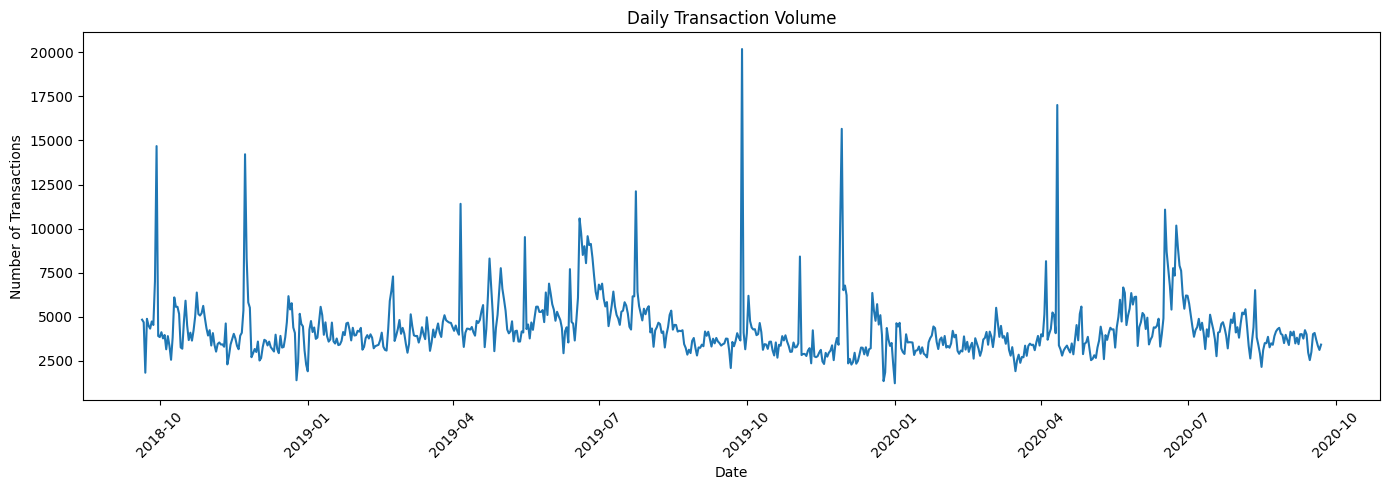

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    daily_transactions["t_date"],
    daily_transactions["transactions"]
)

plt.title("Daily Transaction Volume")
plt.xlabel("Date")
plt.ylabel("Number of Transactions")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [24]:
# ============================================================
# EDA 3 — MONTHLY TRANSACTION VOLUME
# ============================================================

monthly_transactions = (
    tx.assign(
        month=tx["t_date"].dt.to_period("M")
    )
    .groupby("month")
    .size()
    .rename("transactions")
    .reset_index()
)

monthly_transactions["month"] = (
    monthly_transactions["month"]
    .dt.to_timestamp()
)

display(monthly_transactions)

,month,transactions
0,2018-09-01,59871
1,2018-10-01,137637
2,2018-11-01,125284
3,2018-12-01,113899
4,2019-01-01,125528
5,2019-02-01,113582
6,2019-03-01,128282
7,2019-04-01,147638
8,2019-05-01,156366
9,2019-06-01,189911


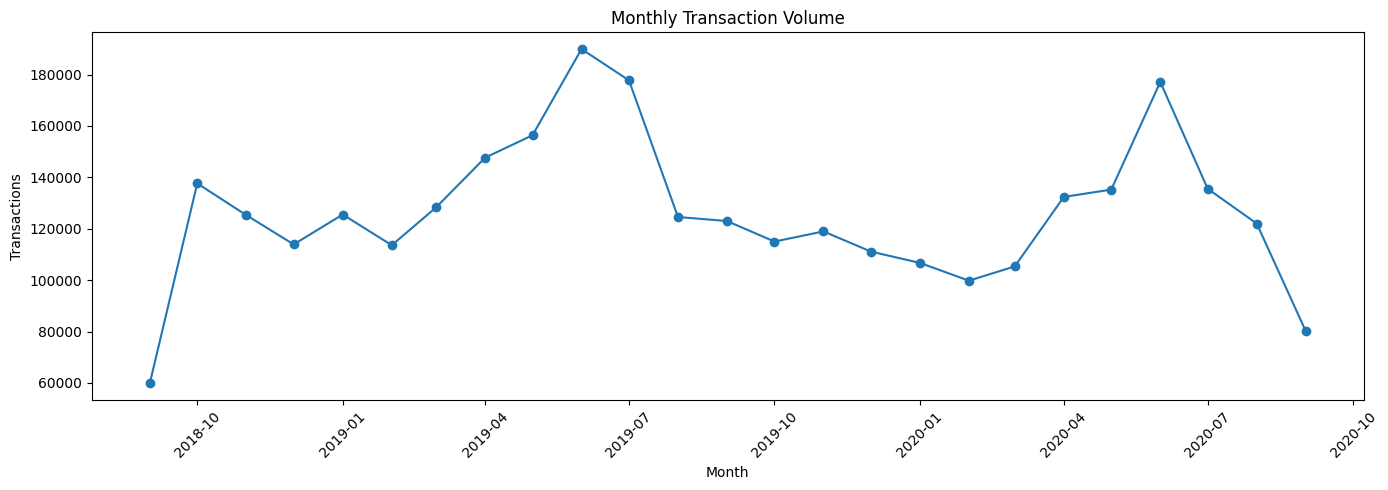

In [25]:
plt.figure(figsize=(14, 5))

plt.plot(
    monthly_transactions["month"],
    monthly_transactions["transactions"],
    marker="o"
)

plt.title("Monthly Transaction Volume")
plt.xlabel("Month")
plt.ylabel("Transactions")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [26]:
# ============================================================
# EDA 4 — CUSTOMER ACTIVITY
# ============================================================

customer_activity = (
    tx.groupby("customer_id")
      .agg(
          n_transactions=("article_id", "size"),
          n_unique_articles=("article_id", "nunique"),
          total_spend=("price", "sum"),
          avg_price=("price", "mean"),
          first_purchase=("t_date", "min"),
          last_purchase=("t_date", "max")
      )
      .reset_index()
)

customer_activity["customer_lifetime_days"] = (
    customer_activity["last_purchase"]
    - customer_activity["first_purchase"]
).dt.days

display(
    customer_activity.describe(
        include="all"
    ).T
)

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
customer_id,136306,136306,ffffcf35913a0bee60e8741cb2b4e78b8a98ee5ff2e6a1...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
n_transactions,136306.0,NaN,NaN,NaN,23.202361,1.0,3.0,9.0,27.0,1237.0,38.26603
n_unique_articles,136306.0,NaN,NaN,NaN,19.938521,1.0,3.0,8.0,24.0,1121.0,31.355199
total_spend,136306.0,NaN,NaN,NaN,0.645751,0.000847,0.088085,0.245458,0.702186,41.327049,1.165362
avg_price,136306.0,NaN,NaN,NaN,0.028759,0.000847,0.020972,0.026133,0.033318,0.422034,0.014321
first_purchase,136306,NaN,NaN,NaN,2019-05-02 03:56:04.412424960,2018-09-20 00:00:00,2018-10-29 00:00:00,2019-02-16 00:00:00,2019-10-03 00:00:00,2020-09-22 00:00:00,NaN
last_purchase,136306,NaN,NaN,NaN,2020-01-30 09:50:23.074552832,2018-09-20 00:00:00,2019-08-20 00:00:00,2020-04-23 00:00:00,2020-08-05 00:00:00,2020-09-22 00:00:00,NaN
customer_lifetime_days,136306.0,NaN,NaN,NaN,273.246049,0.0,0.0,203.0,550.0,733.0,270.345641


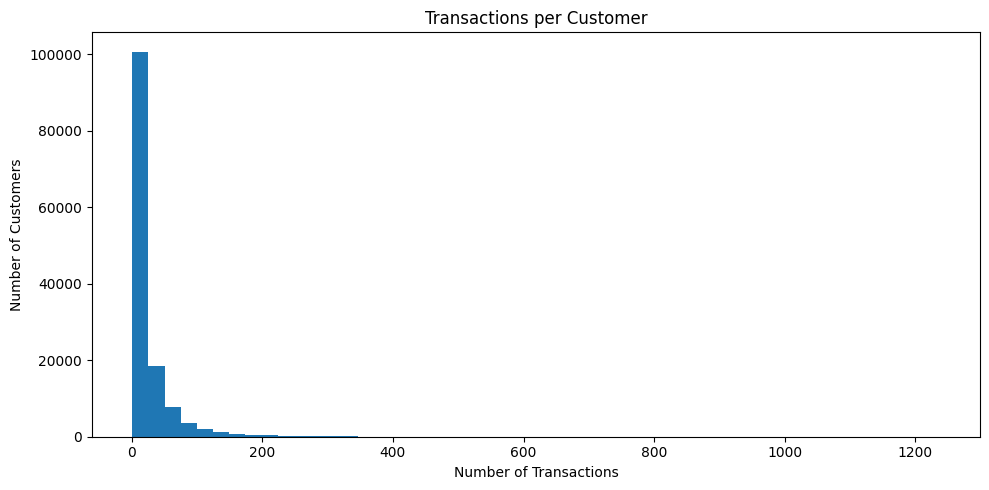

In [27]:
plt.figure(figsize=(10, 5))

plt.hist(
    customer_activity["n_transactions"],
    bins=50
)

plt.title("Transactions per Customer")
plt.xlabel("Number of Transactions")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

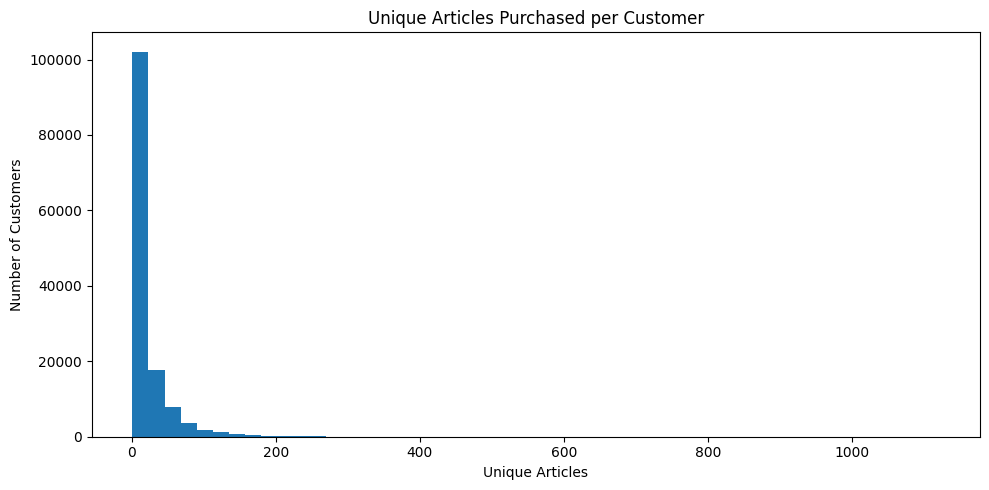

In [28]:
plt.figure(figsize=(10, 5))

plt.hist(
    customer_activity["n_unique_articles"],
    bins=50
)

plt.title("Unique Articles Purchased per Customer")
plt.xlabel("Unique Articles")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

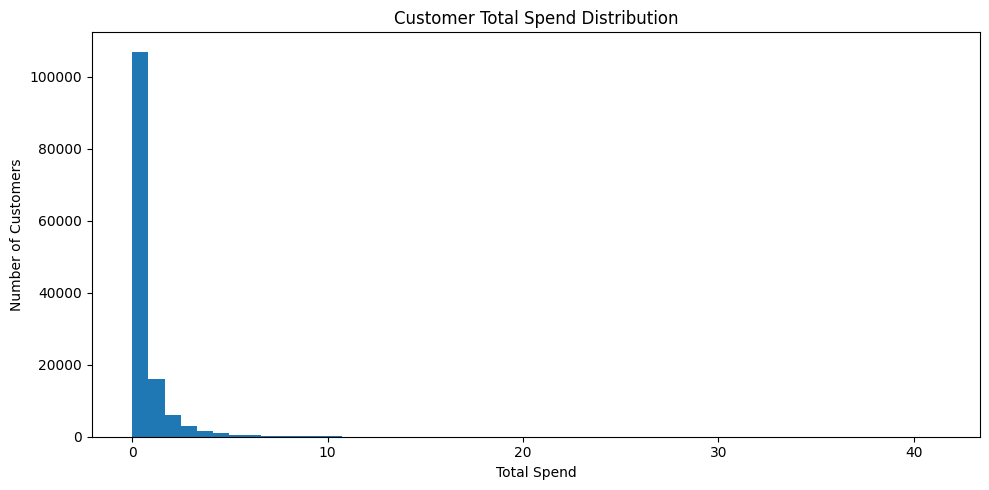

In [29]:
plt.figure(figsize=(10, 5))

plt.hist(
    customer_activity["total_spend"],
    bins=50
)

plt.title("Customer Total Spend Distribution")
plt.xlabel("Total Spend")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [30]:
# ============================================================
# EDA 5 — ARTICLE POPULARITY
# ============================================================

article_popularity = (
    tx.groupby("article_id")
      .agg(
          purchases=("customer_id", "size"),
          unique_customers=("customer_id", "nunique"),
          revenue=("price", "sum"),
          avg_price=("price", "mean")
      )
      .reset_index()
      .sort_values(
          "purchases",
          ascending=False
      )
)

display(
    article_popularity.head(20)
)

,article_id,purchases,unique_customers,revenue,avg_price
42455,706016001,4974,3244,161.194336,0.032407
42456,706016002,3578,2633,116.225334,0.032483
1373,372860001,3298,2644,42.624187,0.012924
17642,610776002,3097,2304,25.100084,0.008105
56846,759871002,2626,2135,14.686881,0.005593
2978,464297007,2614,1951,42.270660,0.016171
1374,372860002,2463,2026,30.075272,0.012211
17641,610776001,2162,1632,17.504576,0.008096
1809,399256001,2147,1566,34.721542,0.016172
1794,399223001,2117,1534,65.124611,0.030763


In [31]:
top_articles = (
    article_popularity
    .head(20)
    .merge(
        art[
            [
                "article_id",
                "product_type_name",
                "product_group_name",
                "department_name"
            ]
        ],
        on="article_id",
        how="left"
    )
)

display(top_articles)

,article_id,purchases,unique_customers,revenue,avg_price,product_type_name,product_group_name,department_name
0,706016001,4974,3244,161.194336,0.032407,Trousers,Garment Lower body,Trousers
1,706016002,3578,2633,116.225334,0.032483,Trousers,Garment Lower body,Trousers
2,372860001,3298,2644,42.624187,0.012924,Socks,Socks & Tights,Shopbasket Socks
3,610776002,3097,2304,25.100084,0.008105,T-shirt,Garment Upper body,Jersey Basic
4,759871002,2626,2135,14.686881,0.005593,Vest top,Garment Upper body,EQ Divided Basics
5,464297007,2614,1951,42.270660,0.016171,Underwear bottom,Underwear,Casual Lingerie
6,372860002,2463,2026,30.075272,0.012211,Socks,Socks & Tights,Shopbasket Socks
7,610776001,2162,1632,17.504576,0.008096,T-shirt,Garment Upper body,Jersey Basic
8,399256001,2147,1566,34.721542,0.016172,Trousers,Garment Lower body,Everyday Waredrobe Denim
9,399223001,2117,1534,65.124611,0.030763,Trousers,Garment Lower body,Denim Trousers


In [32]:
# ============================================================
# EDA 6 — PRODUCT GROUP DISTRIBUTION
# ============================================================

product_groups = (
    tx.merge(
        art[
            [
                "article_id",
                "product_group_name"
            ]
        ],
        on="article_id",
        how="left"
    )
    .groupby("product_group_name")
    .size()
    .sort_values(
        ascending=False
    )
)

display(product_groups)

product_group_name
Garment Upper body       1247317
Garment Lower body        699367
Garment Full body         355297
Underwear                 256665
Swimwear                  255056
Accessories               160257
Shoes                      73904
Socks & Tights             68848
Nightwear                  34781
Unknown                     9520
Bags                         716
Items                        566
Cosmetic                     157
Furniture                     59
Underwear/nightwear           49
Garment and Shoe care         30
Stationery                    23
Interior textile               9
dtype: int64

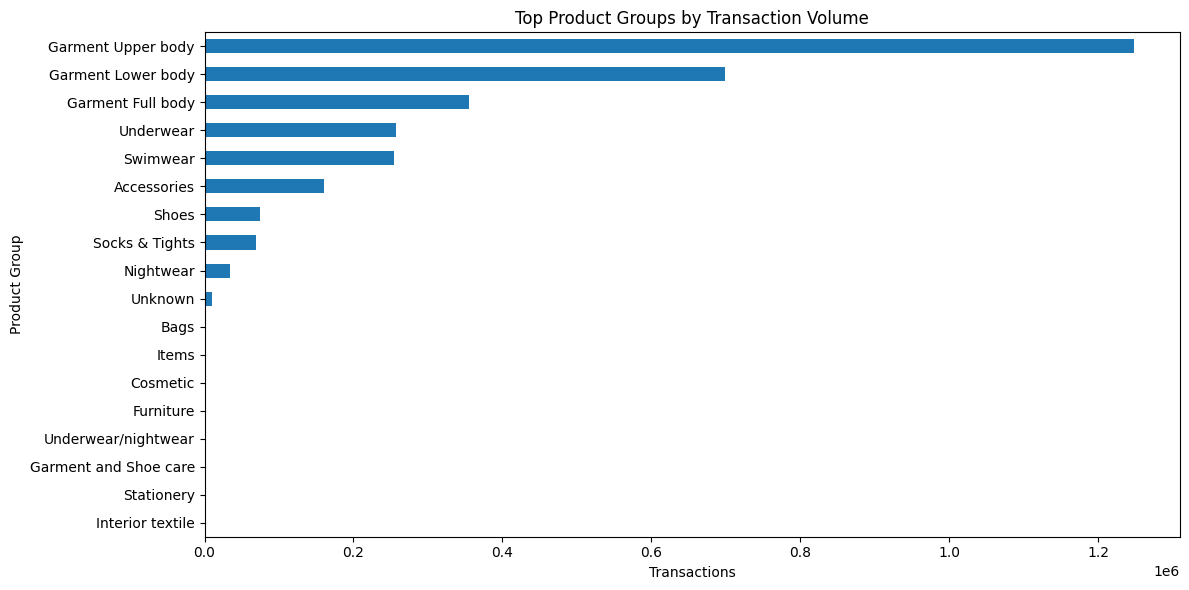

In [33]:
plt.figure(figsize=(12, 6))

product_groups.head(20).sort_values().plot(
    kind="barh"
)

plt.title("Top Product Groups by Transaction Volume")
plt.xlabel("Transactions")
plt.ylabel("Product Group")

plt.tight_layout()
plt.show()

In [34]:
# ============================================================
# EDA 7 — DEPARTMENT ANALYSIS
# ============================================================

department_stats = (
    tx.merge(
        art[
            [
                "article_id",
                "department_name"
            ]
        ],
        on="article_id",
        how="left"
    )
    .groupby("department_name")
    .agg(
        transactions=("article_id", "size"),
        unique_customers=("customer_id", "nunique"),
        unique_articles=("article_id", "nunique"),
        revenue=("price", "sum")
    )
    .sort_values(
        "transactions",
        ascending=False
    )
)

display(
    department_stats.head(20)
)

,transactions,unique_customers,unique_articles,revenue
department_name,,,,
Swimwear,246907,41598,1970,5489.200195
Trouser,173415,47980,2398,6009.486328
Blouse,163946,46466,2191,4237.679688
Knitwear,158777,47366,2944,5561.256836
Jersey,151800,44891,4111,4221.308105
Jersey Basic,145980,43822,1401,2298.085205
Expressive Lingerie,119811,29678,1674,2368.255127
Jersey fancy,114830,41361,1275,2338.106201
Basic 1,113458,37903,1217,1658.782104


In [35]:
# ============================================================
# EDA 8 — PRICE DISTRIBUTION
# ============================================================

price_stats = tx["price"].describe(
    percentiles=[
        0.01,
        0.05,
        0.25,
        0.50,
        0.75,
        0.95,
        0.99
    ]
)

display(price_stats)

count    3.162621e+06
mean     2.783128e-02
std      1.910357e-02
min      1.864407e-04
1%       3.610170e-03
5%       7.610170e-03
25%      1.583051e-02
50%      2.540678e-02
75%      3.388136e-02
95%      5.930508e-02
99%      1.005085e-01
max      5.067797e-01
Name: price, dtype: float64

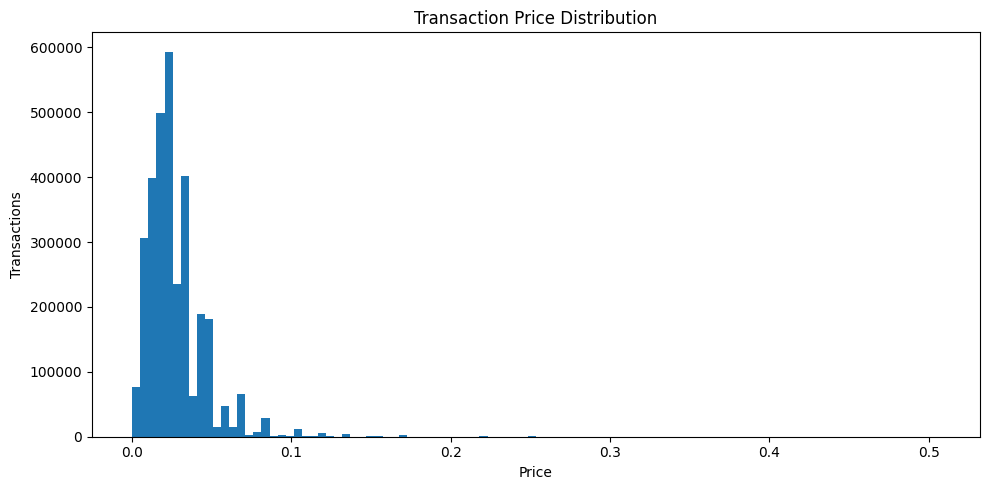

In [36]:
plt.figure(figsize=(10, 5))

plt.hist(
    tx["price"],
    bins=100
)

plt.title("Transaction Price Distribution")
plt.xlabel("Price")
plt.ylabel("Transactions")

plt.tight_layout()
plt.show()

In [37]:
# ============================================================
# EDA 9 — SALES CHANNEL
# ============================================================

channel_stats = (
    tx["sales_channel_id"]
    .value_counts()
    .sort_index()
)

display(channel_stats)

sales_channel_id
1     944579
2    2218042
Name: count, dtype: int64

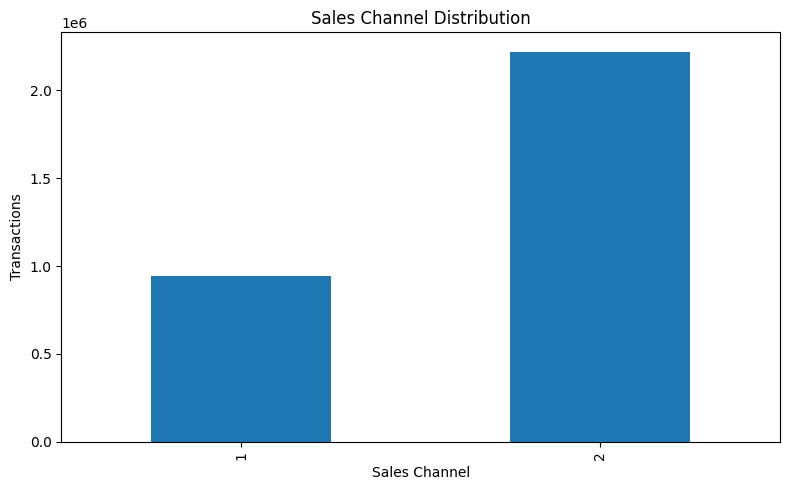

In [38]:
plt.figure(figsize=(8, 5))

channel_stats.plot(
    kind="bar"
)

plt.title("Sales Channel Distribution")
plt.xlabel("Sales Channel")
plt.ylabel("Transactions")

plt.tight_layout()
plt.show()

Age statistics:


count    135585.000000
mean         36.427754
std          14.319213
min          16.000000
25%          24.000000
50%          32.000000
75%          49.000000
max          99.000000
Name: age, dtype: float64

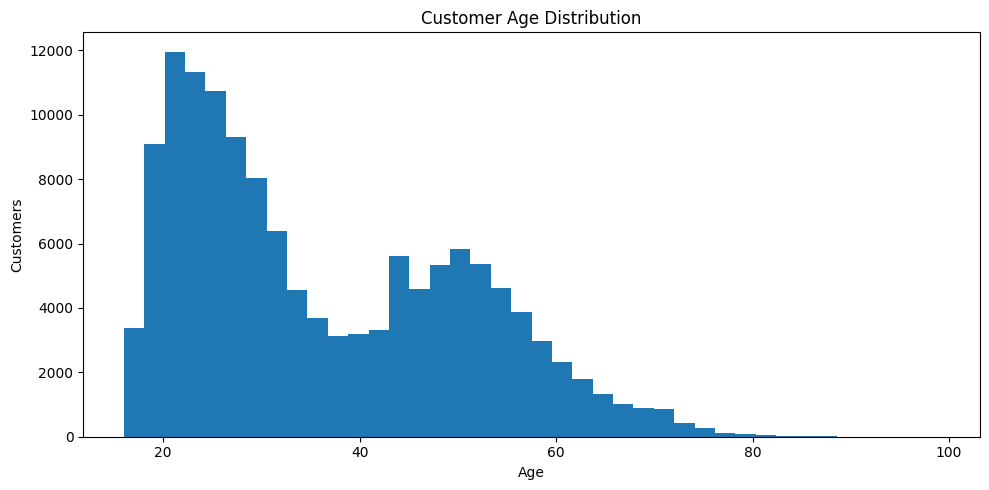

In [39]:
# ============================================================
# EDA 10 — CUSTOMER DEMOGRAPHICS
# ============================================================

if "age" in cust.columns:

    print("Age statistics:")

    display(
        cust["age"].describe()
    )

    plt.figure(figsize=(10, 5))

    plt.hist(
        cust["age"].dropna(),
        bins=40
    )

    plt.title("Customer Age Distribution")
    plt.xlabel("Age")
    plt.ylabel("Customers")

    plt.tight_layout()
    plt.show()

club_member_status
ACTIVE        127257
PRE-CREATE      9283
NaN              606
LEFT CLUB         52
Name: count, dtype: int64

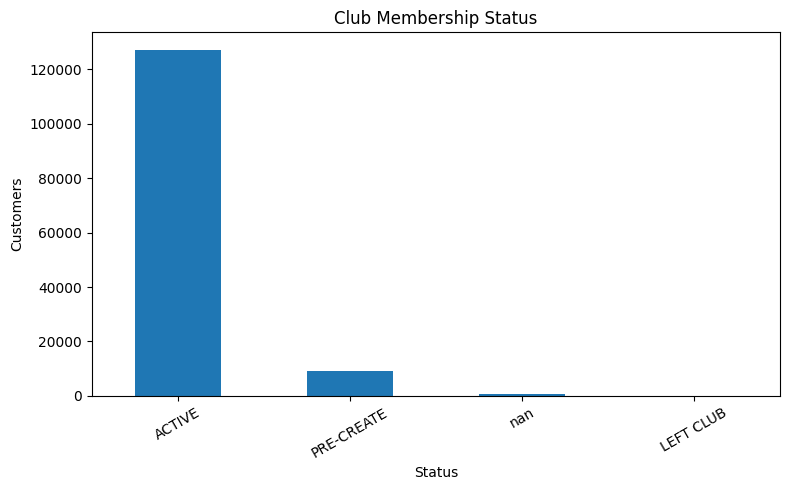

In [40]:
# ============================================================
# EDA 11 — CUSTOMER MEMBERSHIP
# ============================================================

if "club_member_status" in cust.columns:

    membership = (
        cust["club_member_status"]
        .value_counts(dropna=False)
    )

    display(membership)

    plt.figure(figsize=(8, 5))

    membership.plot(
        kind="bar"
    )

    plt.title("Club Membership Status")
    plt.xlabel("Status")
    plt.ylabel("Customers")

    plt.xticks(rotation=30)
    plt.tight_layout()

    plt.show()

fashion_news_frequency
NONE         87974
Regularly    47534
NaN           1621
Monthly         69
Name: count, dtype: int64

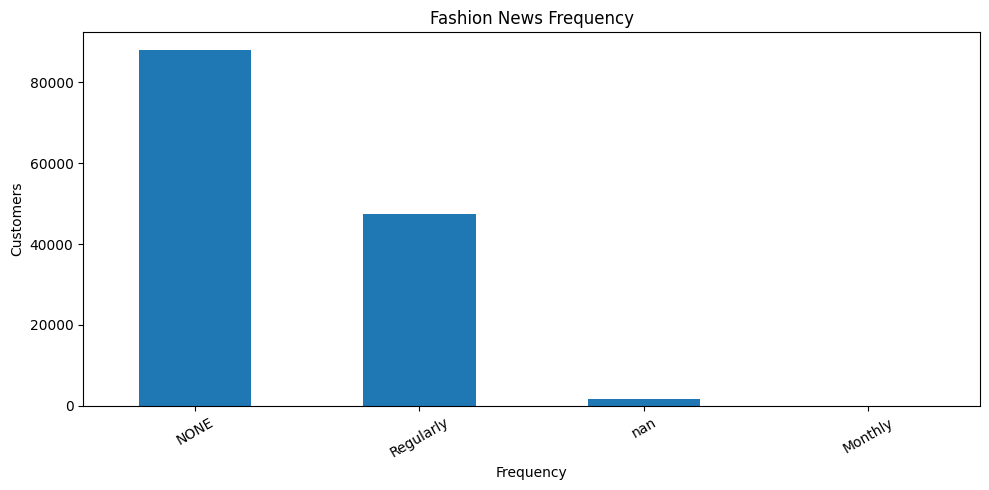

In [41]:
# ============================================================
# EDA 12 — FASHION NEWS FREQUENCY
# ============================================================

if "fashion_news_frequency" in cust.columns:

    news_frequency = (
        cust["fashion_news_frequency"]
        .value_counts(dropna=False)
    )

    display(news_frequency)

    plt.figure(figsize=(10, 5))

    news_frequency.plot(
        kind="bar"
    )

    plt.title("Fashion News Frequency")
    plt.xlabel("Frequency")
    plt.ylabel("Customers")

    plt.xticks(rotation=30)
    plt.tight_layout()

    plt.show()

In [42]:
# ============================================================
# EDA 13 — USER-ITEM INTERACTION SPARSITY
# ============================================================

n_customers = tx["customer_id"].nunique()
n_articles = tx["article_id"].nunique()
n_interactions = len(tx)

possible_interactions = (
    n_customers * n_articles
)

sparsity = (
    1 -
    n_interactions / possible_interactions
)

print(f"Unique customers      : {n_customers:,}")
print(f"Unique articles       : {n_articles:,}")
print(f"Interactions          : {n_interactions:,}")
print(f"Possible interactions : {possible_interactions:,}")
print(f"Interaction sparsity  : {sparsity:.6%}")

Unique customers      : 136,306
Unique articles       : 85,923
Interactions          : 3,162,621
Possible interactions : 11,711,820,438
Interaction sparsity  : 99.972996%


In [43]:
# ============================================================
# EDA 14 — PURCHASE CONCENTRATION
# ============================================================

article_purchase_counts = (
    tx["article_id"]
    .value_counts()
    .sort_values(ascending=False)
)

total_purchases = article_purchase_counts.sum()

top_1_pct = max(
    1,
    int(len(article_purchase_counts) * 0.01)
)

top_5_pct = max(
    1,
    int(len(article_purchase_counts) * 0.05)
)

top_10_pct = max(
    1,
    int(len(article_purchase_counts) * 0.10)
)

concentration = pd.DataFrame({
    "segment": [
        "Top 1% articles",
        "Top 5% articles",
        "Top 10% articles"
    ],
    "share_of_purchases": [
        article_purchase_counts.head(top_1_pct).sum() / total_purchases,
        article_purchase_counts.head(top_5_pct).sum() / total_purchases,
        article_purchase_counts.head(top_10_pct).sum() / total_purchases
    ]
})

concentration["share_of_purchases"] = (
    concentration["share_of_purchases"] * 100
).round(2)

display(concentration)

,segment,share_of_purchases
0,Top 1% articles,16.72
1,Top 5% articles,40.06
2,Top 10% articles,55.90


In [44]:
# ============================================================
# EDA SUMMARY
# ============================================================

print("=" * 80)
print("EDA SUMMARY")
print("=" * 80)

print(f"""
Customers                  : {tx['customer_id'].nunique():,}
Articles                   : {tx['article_id'].nunique():,}
Transactions               : {len(tx):,}

Date range                 : {tx['t_date'].min().date()}
                             → {tx['t_date'].max().date()}

Average transactions/user  :
{customer_activity['n_transactions'].mean():.2f}

Median transactions/user   :
{customer_activity['n_transactions'].median():.2f}

Average unique articles    :
{customer_activity['n_unique_articles'].mean():.2f}

Median unique articles     :
{customer_activity['n_unique_articles'].median():.2f}

Average customer spend     :
{customer_activity['total_spend'].mean():.4f}

Median customer spend      :
{customer_activity['total_spend'].median():.4f}

Interaction sparsity       :
{sparsity:.4%}
""")

EDA SUMMARY

Customers                  : 136,306
Articles                   : 85,923
Transactions               : 3,162,621

Date range                 : 2018-09-20
                             → 2020-09-22

Average transactions/user  :
23.20

Median transactions/user   :
9.00

Average unique articles    :
19.94

Median unique articles     :
8.00

Average customer spend     :
0.6458

Median customer spend      :
0.2455

Interaction sparsity       :
99.9730%



# 3. Temporal Split & Leakage Prevention

## Objective

The recommendation and churn models must predict future customer behavior using only information that was available before the prediction cutoff.

Therefore, this project uses a temporal evaluation strategy instead of a random train/test split.

## Temporal Principle

For every prediction cutoff:

    Historical Data
    ----------------|----------------
                     cutoff
                           |-------------
                           Future Target

Features:
    transaction_date <= cutoff

Target:
    transaction_date > cutoff

This prevents future customer behavior from entering the feature set.

## Leakage Rules

The following information must NOT be used as predictive features:

- Future purchases
- Future article interactions
- Future customer activity
- Future aggregate statistics
- Future popularity statistics
- Any statistic calculated using transactions after the cutoff

All transformations that learn information from the data must be fitted using the training period only.

In [45]:
# ============================================================
# 3.1 TEMPORAL CONFIGURATION
# ============================================================

DATA_MAX_DATE = tx["t_date"].max()

# We reserve the final period for evaluation.
# The exact windows are defined explicitly and reused everywhere.

TEST_HORIZON_DAYS = 7
VALID_HORIZON_DAYS = 7

TEST_END_DATE = DATA_MAX_DATE

TEST_START_DATE = (
    TEST_END_DATE -
    pd.Timedelta(days=TEST_HORIZON_DAYS - 1)
)

VALID_END_DATE = (
    TEST_START_DATE -
    pd.Timedelta(days=1)
)

VALID_START_DATE = (
    VALID_END_DATE -
    pd.Timedelta(days=VALID_HORIZON_DAYS - 1)
)

TRAIN_END_DATE = (
    VALID_START_DATE -
    pd.Timedelta(days=1)
)

print("=" * 80)
print("TEMPORAL CONFIGURATION")
print("=" * 80)

print(f"Dataset maximum date : {DATA_MAX_DATE.date()}")
print()
print(f"TRAIN END            : {TRAIN_END_DATE.date()}")
print(f"VALID START          : {VALID_START_DATE.date()}")
print(f"VALID END            : {VALID_END_DATE.date()}")
print(f"TEST START           : {TEST_START_DATE.date()}")
print(f"TEST END             : {TEST_END_DATE.date()}")

TEMPORAL CONFIGURATION
Dataset maximum date : 2020-09-22

TRAIN END            : 2020-09-08
VALID START          : 2020-09-09
VALID END            : 2020-09-15
TEST START           : 2020-09-16
TEST END             : 2020-09-22


In [46]:
# ============================================================
# 3.2 CREATE TEMPORAL PARTITIONS
# ============================================================

train_tx = tx[
    tx["t_date"] <= TRAIN_END_DATE
].copy()

valid_tx = tx[
    (tx["t_date"] >= VALID_START_DATE) &
    (tx["t_date"] <= VALID_END_DATE)
].copy()

test_tx = tx[
    (tx["t_date"] >= TEST_START_DATE) &
    (tx["t_date"] <= TEST_END_DATE)
].copy()

print("=" * 80)
print("TEMPORAL PARTITION SIZES")
print("=" * 80)

print(
    f"Train transactions : {len(train_tx):,}"
)

print(
    f"Validation         : {len(valid_tx):,}"
)

print(
    f"Test               : {len(test_tx):,}"
)

TEMPORAL PARTITION SIZES
Train transactions : 3,112,497
Validation         : 25,482
Test               : 24,642


In [47]:
# ============================================================
# 3.3 TEMPORAL LEAKAGE CHECK
# ============================================================

assert train_tx["t_date"].max() <= TRAIN_END_DATE

assert valid_tx["t_date"].min() >= VALID_START_DATE
assert valid_tx["t_date"].max() <= VALID_END_DATE

assert test_tx["t_date"].min() >= TEST_START_DATE
assert test_tx["t_date"].max() <= TEST_END_DATE

assert train_tx["t_date"].max() < valid_tx["t_date"].min()
assert valid_tx["t_date"].max() < test_tx["t_date"].min()

print("Temporal ordering: PASSED")

Temporal ordering: PASSED


In [48]:
# ============================================================
# 3.4 CUSTOMER OVERLAP AUDIT
# ============================================================

train_customers = set(
    train_tx["customer_id"].unique()
)

valid_customers = set(
    valid_tx["customer_id"].unique()
)

test_customers = set(
    test_tx["customer_id"].unique()
)

print(
    "Train customers:",
    f"{len(train_customers):,}"
)

print(
    "Validation customers:",
    f"{len(valid_customers):,}"
)

print(
    "Test customers:",
    f"{len(test_customers):,}"
)

print()

print(
    "Train ∩ Validation:",
    f"{len(train_customers & valid_customers):,}"
)

print(
    "Train ∩ Test:",
    f"{len(train_customers & test_customers):,}"
)

print(
    "Validation ∩ Test:",
    f"{len(valid_customers & test_customers):,}"
)

Train customers: 135,179
Validation customers: 7,125
Test customers: 7,003

Train ∩ Validation: 6,566
Train ∩ Test: 6,407
Validation ∩ Test: 1,334


In [49]:
# ============================================================
# 3.5 ELIGIBLE CUSTOMERS
# ============================================================

LOOKBACK_DAYS = CONFIG["churn_lookback_days"]

LOOKBACK_START_DATE = (
    TRAIN_END_DATE -
    pd.Timedelta(days=LOOKBACK_DAYS - 1)
)

eligible_customers = (
    train_tx[
        train_tx["t_date"] >= LOOKBACK_START_DATE
    ]["customer_id"]
    .unique()
)

eligible_customers = pd.Index(
    eligible_customers
)

print(
    "Eligible customers:",
    f"{len(eligible_customers):,}"
)


Eligible customers: 53,669


# 4. Leakage-Safe Feature Engineering

All customer and article features will be generated from the training history only.

For a prediction cutoff `T`:

    Feature Data = transactions where t_date <= T

    Future Data  = transactions where t_date > T

The future period is used only to construct evaluation targets.

No feature calculation will access future transactions.

Each feature-generation function will explicitly receive:

    history_df
    cutoff_date

This makes the temporal boundary visible in the code and reduces accidental leakage.

# 4. Feature Engineering

The feature engineering stage is strictly leakage-safe.

For every prediction cutoff date `T`, all customer and item features are calculated
using historical transactions satisfying:

    transaction_date <= T

Future transactions are NEVER used to construct predictive features.

The feature engineering pipeline contains:

### Customer Features
- Recency
- Frequency
- Monetary value
- Unique articles
- Unique product groups
- Unique departments
- Average basket value
- Average item price
- Purchase interval statistics
- Customer tenure
- Recent activity

### Item Features
- Historical popularity
- Recent popularity
- Unique customer count
- Purchase frequency
- Recency of item activity

### Customer–Item Features
- Previous interaction
- Customer-item purchase count
- Days since last interaction
- Customer affinity
- Item popularity
- Category affinity

All features are generated from historical data only.

In [50]:
# ============================================================
# 4.1 FEATURE ENGINEERING CONFIGURATION
# ============================================================

FEATURE_WINDOWS = {
    "7d": 7,
    "30d": 30,
    "90d": 90,
    "180d": 180,
}

print("=" * 80)
print("FEATURE ENGINEERING CONFIGURATION")
print("=" * 80)

for name, days in FEATURE_WINDOWS.items():
    print(f"{name:>5} : {days} days")

print("\nLeakage policy: HISTORY ONLY")

FEATURE ENGINEERING CONFIGURATION
   7d : 7 days
  30d : 30 days
  90d : 90 days
 180d : 180 days

Leakage policy: HISTORY ONLY


In [51]:
# ============================================================
# 4.2 PREPARE TRAINING HISTORY
# ============================================================

history = train_tx.copy()

history["t_date"] = pd.to_datetime(history["t_date"])

history = history.sort_values(
    ["customer_id", "t_date"]
).reset_index(drop=True)

print("Historical transactions:", f"{len(history):,}")
print("History start:", history["t_date"].min().date())
print("History end  :", history["t_date"].max().date())

Historical transactions: 3,112,497
History start: 2018-09-20
History end  : 2020-09-08


In [52]:
# ============================================================
# 4.3 LEAKAGE GUARD
# ============================================================

def validate_history(
    history_df,
    cutoff_date,
    name="history"
):
    cutoff_date = pd.Timestamp(cutoff_date)

    if history_df.empty:
        raise ValueError(
            f"{name} is empty."
        )

    max_date = history_df["t_date"].max()

    if max_date > cutoff_date:
        raise ValueError(
            f"DATA LEAKAGE DETECTED: "
            f"{name} contains data after cutoff."
        )

    print(
        f"{name}: PASSED | "
        f"max_date={max_date.date()} | "
        f"cutoff={cutoff_date.date()}"
    )


validate_history(
    history,
    TRAIN_END_DATE,
    "Training history"
)

Training history: PASSED | max_date=2020-09-08 | cutoff=2020-09-08


In [53]:
# ============================================================
# 4.4 CUSTOMER-LEVEL FEATURES
# ============================================================

def build_customer_features(
    history_df,
    cutoff_date
):
    cutoff_date = pd.Timestamp(cutoff_date)

    validate_history(
        history_df,
        cutoff_date,
        "Customer history"
    )

    df = history_df.copy()

    # --------------------------------------------------------
    # Basic customer statistics
    # --------------------------------------------------------

    customer_features = (
        df.groupby("customer_id")
        .agg(
            customer_frequency=("article_id", "count"),
            customer_unique_articles=("article_id", "nunique"),
            customer_first_purchase=("t_date", "min"),
            customer_last_purchase=("t_date", "max"),
            customer_total_spend=("price", "sum"),
            customer_avg_price=("price", "mean"),
        )
        .reset_index()
    )

    # --------------------------------------------------------
    # Recency
    # --------------------------------------------------------

    customer_features["customer_recency_days"] = (
        cutoff_date -
        customer_features["customer_last_purchase"]
    ).dt.days

    # --------------------------------------------------------
    # Customer tenure
    # --------------------------------------------------------

    customer_features["customer_tenure_days"] = (
        customer_features["customer_last_purchase"] -
        customer_features["customer_first_purchase"]
    ).dt.days

    customer_features["customer_tenure_days"] = (
        customer_features["customer_tenure_days"]
        .clip(lower=0)
    )

    # --------------------------------------------------------
    # Purchase velocity
    # --------------------------------------------------------

    customer_features["purchase_velocity"] = (
        customer_features["customer_frequency"] /
        (customer_features["customer_tenure_days"] + 1)
    )

    # --------------------------------------------------------
    # Average spend per transaction
    # --------------------------------------------------------

    customer_features["avg_transaction_value"] = (
        customer_features["customer_total_spend"] /
        customer_features["customer_frequency"].clip(lower=1)
    )

    # --------------------------------------------------------
    # Recent activity windows
    # --------------------------------------------------------

    for window_name, days in FEATURE_WINDOWS.items():

        start_date = (
            cutoff_date -
            pd.Timedelta(days=days - 1)
        )

        recent = df[
            df["t_date"] >= start_date
        ]

        recent_stats = (
            recent.groupby("customer_id")
            .agg(
                **{
                    f"transactions_{window_name}":
                        ("article_id", "count"),

                    f"unique_articles_{window_name}":
                        ("article_id", "nunique"),

                    f"spend_{window_name}":
                        ("price", "sum"),
                }
            )
            .reset_index()
        )

        customer_features = customer_features.merge(
            recent_stats,
            on="customer_id",
            how="left"
        )

    # --------------------------------------------------------
    # Fill missing recent activity
    # --------------------------------------------------------

    recent_cols = [
        c for c in customer_features.columns
        if any(
            token in c
            for token in [
                "transactions_",
                "unique_articles_",
                "spend_"
            ]
        )
    ]

    customer_features[recent_cols] = (
        customer_features[recent_cols]
        .fillna(0)
    )

    return customer_features

In [54]:
# ============================================================
# 4.5 BUILD CUSTOMER FEATURES
# ============================================================

customer_features_train = build_customer_features(
    history,
    TRAIN_END_DATE
)

print(
    "Customer feature rows:",
    f"{len(customer_features_train):,}"
)

print(
    "Customer feature columns:",
    len(customer_features_train.columns)
)

display(
    customer_features_train.head()
)

Customer history: PASSED | max_date=2020-09-08 | cutoff=2020-09-08
Customer feature rows: 135,179
Customer feature columns: 23


,customer_id,customer_frequency,customer_unique_articles,customer_first_purchase,customer_last_purchase,customer_total_spend,customer_avg_price,customer_recency_days,customer_tenure_days,purchase_velocity,...,spend_7d,transactions_30d,unique_articles_30d,spend_30d,transactions_90d,unique_articles_90d,spend_90d,transactions_180d,unique_articles_180d,spend_180d
0,0000ae1bbb25e04bdc7e35f718e852adfb3fbb72ef38b3...,2,2,2019-11-28,2019-11-28,0.048780,0.024390,285,0,2.000000,...,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,0.0,0.0,0.000000
1,0000ffa57a8098a6cd99c0f0782b3e674f47d68db69dc1...,3,3,2019-11-28,2019-11-28,0.067763,0.022588,285,0,3.000000,...,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,0.0,0.0,0.000000
2,00018385675844f7a6babbed41b5655b5727fb16483b6e...,9,9,2018-09-29,2019-11-03,0.307220,0.034136,310,400,0.022444,...,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,0.0,0.0,0.000000
3,0001b0127d3e5ff8dadcfc6e5043682dba2070f2667081...,18,17,2019-07-29,2020-08-28,0.334356,0.018575,11,396,0.045340,...,0.0,3.0,3.0,0.055881,10.0,10.0,0.172712,10.0,10.0,0.172712
4,0002b9088196900626214bcdc6d5f3d85f38fb462a4806...,1,1,2018-09-27,2018-09-27,0.050831,0.050831,712,0,1.000000,...,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,0.0,0.0,0.000000


In [55]:
# ============================================================
# 4.6 ITEM-LEVEL FEATURES
# ============================================================

def build_item_features(
    history_df,
    cutoff_date
):
    cutoff_date = pd.Timestamp(cutoff_date)

    validate_history(
        history_df,
        cutoff_date,
        "Item history"
    )

    df = history_df.copy()

    item_features = (
        df.groupby("article_id")
        .agg(
            item_frequency=("customer_id", "count"),
            item_unique_customers=("customer_id", "nunique"),
            item_first_purchase=("t_date", "min"),
            item_last_purchase=("t_date", "max"),
            item_avg_price=("price", "mean"),
        )
        .reset_index()
    )

    item_features["item_recency_days"] = (
        cutoff_date -
        item_features["item_last_purchase"]
    ).dt.days

    for window_name, days in FEATURE_WINDOWS.items():

        start_date = (
            cutoff_date -
            pd.Timedelta(days=days - 1)
        )

        recent = df[
            df["t_date"] >= start_date
        ]

        recent_items = (
            recent.groupby("article_id")
            .agg(
                **{
                    f"item_transactions_{window_name}":
                        ("customer_id", "count"),

                    f"item_customers_{window_name}":
                        ("customer_id", "nunique"),
                }
            )
            .reset_index()
        )

        item_features = item_features.merge(
            recent_items,
            on="article_id",
            how="left"
        )

    recent_cols = [
        c for c in item_features.columns
        if "item_transactions_" in c
        or "item_customers_" in c
    ]

    item_features[recent_cols] = (
        item_features[recent_cols]
        .fillna(0)
    )

    return item_features

In [56]:
# ============================================================
# 4.7 BUILD ITEM FEATURES
# ============================================================

item_features_train = build_item_features(
    history,
    TRAIN_END_DATE
)

print(
    "Item feature rows:",
    f"{len(item_features_train):,}"
)

print(
    "Item feature columns:",
    len(item_features_train.columns)
)

display(
    item_features_train.head()
)

Item history: PASSED | max_date=2020-09-08 | cutoff=2020-09-08
Item feature rows: 84,598
Item feature columns: 15


,article_id,item_frequency,item_unique_customers,item_first_purchase,item_last_purchase,item_avg_price,item_recency_days,item_transactions_7d,item_customers_7d,item_transactions_30d,item_customers_30d,item_transactions_90d,item_customers_90d,item_transactions_180d,item_customers_180d
0,108775015,1095,706,2018-09-21,2020-06-02,0.008162,98,0.0,0.0,0.0,0.0,0.0,0.0,6.0,5.0
1,108775044,698,534,2018-09-21,2020-08-12,0.008102,27,0.0,0.0,1.0,1.0,6.0,4.0,19.0,15.0
2,108775051,16,13,2018-09-20,2018-12-03,0.004863,645,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,110065001,101,90,2018-09-25,2020-07-16,0.019643,54,0.0,0.0,0.0,0.0,2.0,2.0,2.0,2.0
4,110065002,62,50,2018-09-22,2020-03-06,0.018993,186,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [57]:
# ============================================================
# 4.8 MERGE MODELING FEATURES
# ============================================================

feature_table = history[
    [
        "customer_id",
        "article_id",
        "t_date",
        "price"
    ]
].copy()

feature_table = feature_table.merge(
    customer_features_train,
    on="customer_id",
    how="left"
)

feature_table = feature_table.merge(
    item_features_train,
    on="article_id",
    how="left"
)

print(
    "Feature table shape:",
    feature_table.shape
)

display(
    feature_table.head()
)

Feature table shape: (3112497, 40)


,customer_id,article_id,t_date,price,customer_frequency,customer_unique_articles,customer_first_purchase,customer_last_purchase,customer_total_spend,customer_avg_price,...,item_avg_price,item_recency_days,item_transactions_7d,item_customers_7d,item_transactions_30d,item_customers_30d,item_transactions_90d,item_customers_90d,item_transactions_180d,item_customers_180d
0,0000ae1bbb25e04bdc7e35f718e852adfb3fbb72ef38b3...,573085038,2019-11-28,0.024390,2,2,2019-11-28,2019-11-28,0.048780,0.024390,...,0.030303,35,0.0,0.0,0.0,0.0,7.0,6.0,35.0,28.0
1,0000ae1bbb25e04bdc7e35f718e852adfb3fbb72ef38b3...,573085033,2019-11-28,0.024390,2,2,2019-11-28,2019-11-28,0.048780,0.024390,...,0.025206,59,0.0,0.0,0.0,0.0,5.0,5.0,9.0,9.0
2,0000ffa57a8098a6cd99c0f0782b3e674f47d68db69dc1...,555353017,2019-11-28,0.020339,3,3,2019-11-28,2019-11-28,0.067763,0.022588,...,0.024295,64,0.0,0.0,0.0,0.0,1.0,1.0,9.0,7.0
3,0000ffa57a8098a6cd99c0f0782b3e674f47d68db69dc1...,817574001,2019-11-28,0.033881,3,3,2019-11-28,2019-11-28,0.067763,0.022588,...,0.030689,118,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0
4,0000ffa57a8098a6cd99c0f0782b3e674f47d68db69dc1...,215589001,2019-11-28,0.013542,3,3,2019-11-28,2019-11-28,0.067763,0.022588,...,0.013909,43,0.0,0.0,0.0,0.0,1.0,1.0,15.0,12.0


# 5. Candidate Generation

The recommendation system follows a two-stage architecture:

1. Candidate Retrieval
2. Candidate Ranking

Candidate generation retrieves a relatively small set of potentially relevant
articles for each customer.

The candidate sources are built using training-period information only.

We use multiple complementary retrieval strategies:

- Recent customer purchases / personalized history
- Item popularity
- Item-item co-occurrence
- Implicit collaborative filtering

The retrieved candidates will later be combined, deduplicated, and ranked by
the ranking models.

The validation and test periods are NOT used during candidate generation.

In [58]:
# ============================================================
# 5.1 CANDIDATE GENERATION CONFIGURATION
# ============================================================

CANDIDATE_CONFIG = {
    "history_items": 20,
    "popular_items": 100,
    "cooccurrence_items": 50,
    "als_items": 50,
    "final_candidates": 150,
}

print("=" * 80)
print("CANDIDATE GENERATION CONFIGURATION")
print("=" * 80)

for key, value in CANDIDATE_CONFIG.items():
    print(f"{key:25s}: {value}")

CANDIDATE GENERATION CONFIGURATION
history_items            : 20
popular_items            : 100
cooccurrence_items       : 50
als_items                : 50
final_candidates         : 150


In [59]:
# ============================================================
# 5.2 GLOBAL ITEM POPULARITY
# ============================================================

def build_popular_items(
    history_df,
    cutoff_date,
    top_n=100
):
    cutoff_date = pd.Timestamp(cutoff_date)

    validate_history(
        history_df,
        cutoff_date,
        "Popularity history"
    )

    popularity = (
        history_df
        .groupby("article_id")
        .agg(
            purchase_count=("customer_id", "count"),
            unique_customers=("customer_id", "nunique"),
            last_purchase=("t_date", "max")
        )
        .reset_index()
    )

    popularity["recency_days"] = (
        cutoff_date -
        popularity["last_purchase"]
    ).dt.days

    popularity = popularity.sort_values(
        [
            "purchase_count",
            "unique_customers",
            "recency_days"
        ],
        ascending=[False, False, True]
    )

    return popularity.head(top_n).copy()


popular_items = build_popular_items(
    history,
    TRAIN_END_DATE,
    CANDIDATE_CONFIG["popular_items"]
)

print(
    "Popular candidate items:",
    f"{len(popular_items):,}"
)

display(popular_items.head(10))

Popularity history: PASSED | max_date=2020-09-08 | cutoff=2020-09-08
Popular candidate items: 100


,article_id,purchase_count,unique_customers,last_purchase,recency_days
42353,706016001,4885,3194,2020-09-08,0
42354,706016002,3517,2590,2020-09-08,0
1366,372860001,3254,2615,2020-09-08,0
17589,610776002,3066,2283,2020-09-08,0
56698,759871002,2625,2134,2020-09-06,2
2969,464297007,2608,1949,2020-09-08,0
1367,372860002,2410,1988,2020-09-08,0
17588,610776001,2132,1613,2020-09-07,1
1801,399256001,2121,1549,2020-09-08,0
1786,399223001,2112,1531,2020-09-07,1


In [60]:
# ============================================================
# 5.3 PERSONAL HISTORY CANDIDATES
# ============================================================

def build_customer_history_candidates(
    history_df,
    customer_ids,
    top_n=20
):
    customer_history = (
        history_df[
            history_df["customer_id"].isin(customer_ids)
        ]
        .sort_values(
            ["customer_id", "t_date"],
            ascending=[True, False]
        )
        .groupby("customer_id")
        .head(top_n)
    )

    return (
        customer_history
        .groupby("customer_id")["article_id"]
        .apply(list)
        .to_dict()
    )


history_candidates = build_customer_history_candidates(
    history,
    eligible_customers,
    CANDIDATE_CONFIG["history_items"]
)

print(
    "Customers with history candidates:",
    f"{len(history_candidates):,}"
)

Customers with history candidates: 53,669


In [61]:
# ============================================================
# 5.4 ITEM-ITEM CO-OCCURRENCE
# ============================================================

from collections import defaultdict, Counter

def build_item_cooccurrence(
    history_df,
    max_items_per_customer=30,
    top_n=50
):
    customer_items = (
        history_df
        .sort_values(["customer_id", "t_date"])
        .groupby("customer_id")["article_id"]
        .apply(
            lambda x: list(
                pd.unique(x)
            )[-max_items_per_customer:]
        )
    )

    co_counts = defaultdict(Counter)

    for items in customer_items:
        unique_items = list(dict.fromkeys(items))

        for i in unique_items:
            for j in unique_items:
                if i != j:
                    co_counts[i][j] += 1

    item_neighbors = {}

    for article_id, counter in co_counts.items():

        item_neighbors[article_id] = [
            item
            for item, _ in counter.most_common(top_n)
        ]

    return item_neighbors


item_neighbors = build_item_cooccurrence(
    history,
    max_items_per_customer=30,
    top_n=CANDIDATE_CONFIG["cooccurrence_items"]
)

print(
    "Items with co-occurrence neighbors:",
    f"{len(item_neighbors):,}"
)

Items with co-occurrence neighbors: 76,517


In [62]:
# ============================================================
# 5.5 MERGE CANDIDATE SOURCES
# ============================================================

GLOBAL_POPULAR_ITEMS = popular_items["article_id"].tolist()


def generate_candidates(
    customer_id,
    history_dict,
    item_neighbors,
    popular_items,
    final_n=150
):
    candidates = []
    seen = set()

    def add_candidate(article_id, source):
        if article_id not in seen:
            candidates.append(
                (article_id, source)
            )
            seen.add(article_id)

    # --------------------------------------------------------
    # Source 1: Customer recent history
    # --------------------------------------------------------

    for article_id in history_dict.get(customer_id, []):

        add_candidate(
            article_id,
            "history"
        )

    # --------------------------------------------------------
    # Source 2: Item-item co-occurrence
    # --------------------------------------------------------

    for article_id in history_dict.get(customer_id, []):

        for neighbor in item_neighbors.get(
            article_id,
            []
        ):

            add_candidate(
                neighbor,
                "cooccurrence"
            )

            if len(candidates) >= final_n:
                break

        if len(candidates) >= final_n:
            break

    # --------------------------------------------------------
    # Source 3: Global popularity
    # --------------------------------------------------------

    for article_id in popular_items:

        add_candidate(
            article_id,
            "popularity"
        )

        if len(candidates) >= final_n:
            break

    return candidates[:final_n]

In [63]:
# ============================================================
# 5.6 CANDIDATE GENERATION SANITY CHECK
# ============================================================

sample_customer = eligible_customers[0]

sample_candidates = generate_candidates(
    customer_id=sample_customer,
    history_dict=history_candidates,
    item_neighbors=item_neighbors,
    popular_items=GLOBAL_POPULAR_ITEMS,
    final_n=CANDIDATE_CONFIG["final_candidates"]
)

print(
    "Customer:",
    sample_customer
)

print(
    "Number of candidates:",
    len(sample_candidates)
)

print("\nFirst 20 candidates:")

for article_id, source in sample_candidates[:20]:
    print(
        f"{article_id}  ->  {source}"
    )

Customer: 0001b0127d3e5ff8dadcfc6e5043682dba2070f2667081623faeb31c996242a6
Number of candidates: 150

First 20 candidates:
772902001  ->  history
189616038  ->  history
791587001  ->  history
559630029  ->  history
759871003  ->  history
739590038  ->  history
860305003  ->  history
834217004  ->  history
844409002  ->  history
876053003  ->  history
760084008  ->  history
733098011  ->  history
803080001  ->  history
704720005  ->  history
614854003  ->  history
464927008  ->  history
621381009  ->  history
772902003  ->  cooccurrence
772902002  ->  cooccurrence
706016001  ->  cooccurrence


# 5.7 Candidate Recall Evaluation

Before training any ranking model, we evaluate the quality of the
candidate-generation stage.

The validation transactions are used ONLY as future ground truth.

Candidate generation itself uses training-period information only.

For each eligible customer:

- Generate candidates from training history.
- Compare the candidates against articles purchased during validation.
- Compute Recall@K.

This evaluation answers an important question:

> Can our retrieval stage bring the relevant future articles into the
> ranking stage?

No validation transaction is used to construct the candidate sources.

In [64]:
# ============================================================
# 5.7.1 VALIDATION GROUND TRUTH
# ============================================================

# Future purchases during validation period.
# This is ground truth ONLY and is NOT used for candidate generation.

valid_ground_truth = (
    valid_tx[
        valid_tx["customer_id"].isin(eligible_customers)
    ]
    .groupby("customer_id")["article_id"]
    .apply(set)
    .to_dict()
)

print("=" * 80)
print("VALIDATION GROUND TRUTH")
print("=" * 80)

print(
    "Customers with validation purchases:",
    f"{len(valid_ground_truth):,}"
)

print(
    "Validation transactions:",
    f"{len(valid_tx):,}"
)

VALIDATION GROUND TRUTH
Customers with validation purchases: 5,256
Validation transactions: 25,482


In [65]:
# ============================================================
# 5.7.2 GENERATE VALIDATION CANDIDATES
# ============================================================

from tqdm.auto import tqdm

def generate_customer_candidate_dict(
    customer_ids,
    history_dict,
    item_neighbors,
    popular_items,
    final_n=150
):
    result = {}

    for customer_id in tqdm(
        customer_ids,
        desc="Generating candidates"
    ):
        result[customer_id] = generate_candidates(
            customer_id=customer_id,
            history_dict=history_dict,
            item_neighbors=item_neighbors,
            popular_items=popular_items,
            final_n=final_n
        )

    return result


validation_candidates = generate_customer_candidate_dict(
    customer_ids=eligible_customers,
    history_dict=history_candidates,
    item_neighbors=item_neighbors,
    popular_items=GLOBAL_POPULAR_ITEMS,
    final_n=CANDIDATE_CONFIG["final_candidates"]
)

print(
    "\nCustomers processed:",
    f"{len(validation_candidates):,}"
)

Generating candidates:   0%|          | 0/53669 [00:00<?, ?it/s]


Customers processed: 53,669


In [66]:
# ============================================================
# 5.7.3 REMOVE PREVIOUSLY PURCHASED ITEMS
# ============================================================

customer_seen_items = (
    history
    .groupby("customer_id")["article_id"]
    .apply(set)
    .to_dict()
)


def filter_seen_items(
    customer_id,
    candidates,
    seen_items
):
    seen = seen_items.get(
        customer_id,
        set()
    )

    return [
        (article_id, source)
        for article_id, source in candidates
        if article_id not in seen
    ]


validation_candidates_new = {}

for customer_id, candidates in tqdm(
    validation_candidates.items(),
    desc="Removing previously purchased items"
):
    validation_candidates_new[customer_id] = filter_seen_items(
        customer_id,
        candidates,
        customer_seen_items
    )

print("Filtering completed.")

Removing previously purchased items:   0%|          | 0/53669 [00:00<?, ?it/s]

Filtering completed.


In [67]:
# ============================================================
# 5.7.4 RECALL@K
# ============================================================

def recall_at_k(
    candidate_dict,
    ground_truth,
    k
):
    recalls = []

    for customer_id, true_items in ground_truth.items():

        if not true_items:
            continue

        candidates = candidate_dict.get(
            customer_id,
            []
        )

        recommended = {
            article_id
            for article_id, _ in candidates[:k]
        }

        hits = len(
            recommended.intersection(true_items)
        )

        recalls.append(
            hits / len(true_items)
        )

    if not recalls:
        return 0.0

    return float(np.mean(recalls))


K_VALUES = [20, 50, 100, 150]

recall_results = []

for k in K_VALUES:

    raw_recall = recall_at_k(
        validation_candidates,
        valid_ground_truth,
        k
    )

    new_item_recall = recall_at_k(
        validation_candidates_new,
        valid_ground_truth,
        k
    )

    recall_results.append({
        "K": k,
        "Recall_Raw": raw_recall,
        "Recall_New_Item": new_item_recall
    })


recall_df = pd.DataFrame(
    recall_results
)

display(
    recall_df.round(4)
)

,K,Recall_Raw,Recall_New_Item
0,20,0.0613,0.0171
1,50,0.0754,0.0273
2,100,0.0926,0.0440
3,150,0.1057,0.0510


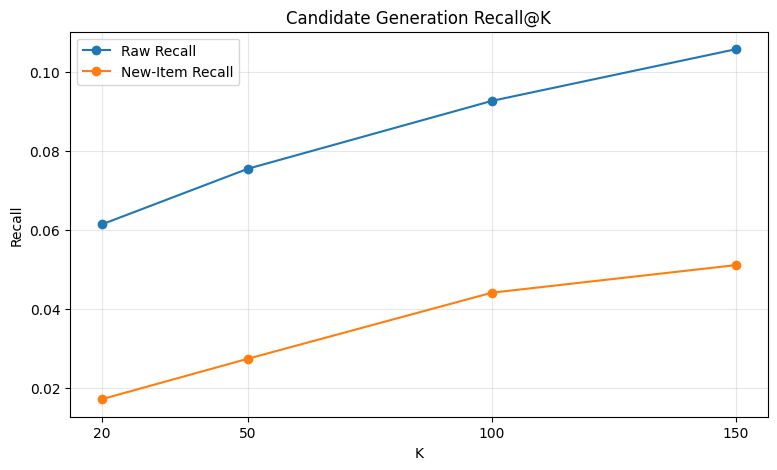

In [68]:
# ============================================================
# 5.7.5 RETRIEVAL RECALL CURVE
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    recall_df["K"],
    recall_df["Recall_Raw"],
    marker="o",
    label="Raw Recall"
)

plt.plot(
    recall_df["K"],
    recall_df["Recall_New_Item"],
    marker="o",
    label="New-Item Recall"
)

plt.xlabel("K")
plt.ylabel("Recall")
plt.title("Candidate Generation Recall@K")
plt.xticks(K_VALUES)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

## Candidate Source Analysis

We analyze the contribution of each retrieval source:

- Customer history
- Item-item co-occurrence
- Global popularity

This helps identify whether the retrieval system is overly dependent on
popularity or whether personalized retrieval contributes meaningful coverage.

In [69]:
# ============================================================
# 5.7.6 CANDIDATE SOURCE DISTRIBUTION
# ============================================================

source_counter = Counter()

for candidates in validation_candidates_new.values():

    for _, source in candidates:
        source_counter[source] += 1


source_df = (
    pd.DataFrame(
        source_counter.items(),
        columns=["Source", "Count"]
    )
    .sort_values(
        "Count",
        ascending=False
    )
    .reset_index(drop=True)
)

source_df["Percentage"] = (
    source_df["Count"] /
    source_df["Count"].sum() *
    100
)

display(
    source_df.round(2)
)

,Source,Count,Percentage
0,cooccurrence,6917776,95.93
1,popularity,293468,4.07


In [70]:
# ============================================================
# 5.7.7 CANDIDATE COVERAGE
# ============================================================

all_candidate_items = set()

for candidates in validation_candidates_new.values():

    for article_id, _ in candidates:
        all_candidate_items.add(article_id)


train_items = set(
    history["article_id"].unique()
)

validation_items = set(
    valid_tx["article_id"].unique()
)

candidate_item_coverage = (
    len(all_candidate_items) /
    len(train_items)
)

validation_catalog_coverage = (
    len(
        all_candidate_items.intersection(
            validation_items
        )
    )
    /
    len(validation_items)
)

print("=" * 80)
print("CANDIDATE COVERAGE")
print("=" * 80)

print(
    "Unique candidate articles:",
    f"{len(all_candidate_items):,}"
)

print(
    "Training catalog articles:",
    f"{len(train_items):,}"
)

print(
    "Candidate / training catalog coverage:",
    f"{candidate_item_coverage:.2%}"
)

print(
    "Validation-item catalog coverage:",
    f"{validation_catalog_coverage:.2%}"
)

CANDIDATE COVERAGE
Unique candidate articles: 54,013
Training catalog articles: 84,598
Candidate / training catalog coverage: 63.85%
Validation-item catalog coverage: 84.09%


# 5.8 Candidate Retrieval Quality

We now evaluate the actual retrieval quality of the candidate-generation
stage using future validation purchases as ground truth.

The retrieval system is evaluated with Recall@K.

Validation transactions are used only as ground truth and are never used
to construct candidate sources.

A strong retrieval stage is required before training the ranking models.

In [71]:
# ============================================================
# 5.8.1 CANDIDATE RETRIEVAL RECALL
# ============================================================

K_VALUES = [20, 50, 100, 150]


def recall_at_k(candidate_dict, ground_truth, k):
    recalls = []

    for customer_id, true_items in ground_truth.items():

        if not true_items:
            continue

        candidates = candidate_dict.get(customer_id, [])

        recommended = {
            article_id
            for article_id, _ in candidates[:k]
        }

        hits = len(
            recommended.intersection(true_items)
        )

        recalls.append(
            hits / len(true_items)
        )

    if not recalls:
        return 0.0

    return float(np.mean(recalls))


recall_results = []

for k in K_VALUES:

    recall = recall_at_k(
        validation_candidates,
        valid_ground_truth,
        k
    )

    recall_new_items = recall_at_k(
        validation_candidates_new,
        valid_ground_truth,
        k
    )

    recall_results.append({
        "K": k,
        "Recall@K": recall,
        "New_Item_Recall@K": recall_new_items
    })


recall_df = pd.DataFrame(recall_results)

display(
    recall_df.style.format({
        "Recall@K": "{:.4f}",
        "New_Item_Recall@K": "{:.4f}"
    })
)

,K,Recall@K,New_Item_Recall@K
0,20,0.0613,0.0171
1,50,0.0754,0.0273
2,100,0.0926,0.0440
3,150,0.1057,0.0510


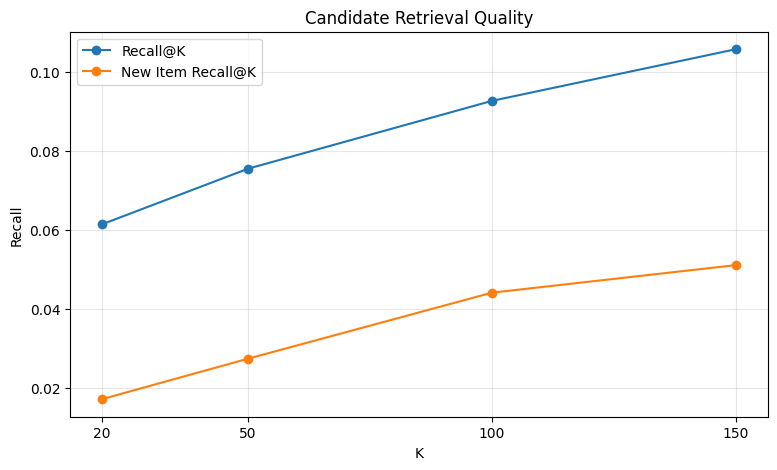

In [72]:
# ============================================================
# 5.8.2 RETRIEVAL RECALL VISUALIZATION
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    recall_df["K"],
    recall_df["Recall@K"],
    marker="o",
    label="Recall@K"
)

plt.plot(
    recall_df["K"],
    recall_df["New_Item_Recall@K"],
    marker="o",
    label="New Item Recall@K"
)

plt.xlabel("K")
plt.ylabel("Recall")
plt.title("Candidate Retrieval Quality")
plt.xticks(K_VALUES)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

In [73]:
# ============================================================
# 5.9 RANKING DATASET DIAGNOSTICS
# ============================================================

print("=" * 70)
print("RANKING DATASET DIAGNOSTICS")
print("=" * 70)

# Check the main objects we will use for ranking
objects_to_check = {
    "validation_candidates": validation_candidates,
    "valid_ground_truth": valid_ground_truth,
    "feature_table": feature_table,
    "customer_features_train": customer_features_train,
    "art": art,
}

for name, obj in objects_to_check.items():
    print(f"\n{name}")
    print("-" * 50)
    print("Type:", type(obj))
    
    try:
        print("Shape:", obj.shape)
    except:
        try:
            print("Length:", len(obj))
        except:
            print("Shape/Length: N/A")

# ------------------------------------------------------------
# Candidate structure
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("VALIDATION CANDIDATE SAMPLE")
print("=" * 70)

if isinstance(validation_candidates, dict):
    sample_customer = next(iter(validation_candidates))
    print("Sample customer:", sample_customer)
    print("Number of candidates:",
          len(validation_candidates[sample_customer]))
    print("First 20 candidates:",
          validation_candidates[sample_customer][:20])

elif isinstance(validation_candidates, pd.DataFrame):
    display(validation_candidates.head())

else:
    print(validation_candidates[:5])


# ------------------------------------------------------------
# Ground truth structure
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("VALIDATION GROUND TRUTH SAMPLE")
print("=" * 70)

if isinstance(valid_ground_truth, dict):
    sample_customer = next(iter(valid_ground_truth))
    print("Sample customer:", sample_customer)
    print("Ground truth items:",
          list(valid_ground_truth[sample_customer])[:20])

elif isinstance(valid_ground_truth, pd.DataFrame):
    display(valid_ground_truth.head())

else:
    print(valid_ground_truth[:5])


# ------------------------------------------------------------
# Feature table
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FEATURE TABLE")
print("=" * 70)

print("Rows:", len(feature_table))
print("Columns:", len(feature_table.columns))

print("\nColumns:")
print(feature_table.columns.tolist())

display(feature_table.head(3))

RANKING DATASET DIAGNOSTICS

validation_candidates
--------------------------------------------------
Type: <class 'dict'>
Length: 53669

valid_ground_truth
--------------------------------------------------
Type: <class 'dict'>
Length: 5256

feature_table
--------------------------------------------------
Type: <class 'pandas.core.frame.DataFrame'>
Shape: (3112497, 40)

customer_features_train
--------------------------------------------------
Type: <class 'pandas.core.frame.DataFrame'>
Shape: (135179, 23)

art
--------------------------------------------------
Type: <class 'pandas.core.frame.DataFrame'>
Shape: (105542, 25)

VALIDATION CANDIDATE SAMPLE
Sample customer: 0001b0127d3e5ff8dadcfc6e5043682dba2070f2667081623faeb31c996242a6
Number of candidates: 150
First 20 candidates: [(772902001, 'history'), (189616038, 'history'), (791587001, 'history'), (559630029, 'history'), (759871003, 'history'), (739590038, 'history'), (860305003, 'history'), (834217004, 'history'), (844409002, 'his

,customer_id,article_id,t_date,price,customer_frequency,customer_unique_articles,customer_first_purchase,customer_last_purchase,customer_total_spend,customer_avg_price,...,item_avg_price,item_recency_days,item_transactions_7d,item_customers_7d,item_transactions_30d,item_customers_30d,item_transactions_90d,item_customers_90d,item_transactions_180d,item_customers_180d
0,0000ae1bbb25e04bdc7e35f718e852adfb3fbb72ef38b3...,573085038,2019-11-28,0.024390,2,2,2019-11-28,2019-11-28,0.048780,0.024390,...,0.030303,35,0.0,0.0,0.0,0.0,7.0,6.0,35.0,28.0
1,0000ae1bbb25e04bdc7e35f718e852adfb3fbb72ef38b3...,573085033,2019-11-28,0.024390,2,2,2019-11-28,2019-11-28,0.048780,0.024390,...,0.025206,59,0.0,0.0,0.0,0.0,5.0,5.0,9.0,9.0
2,0000ffa57a8098a6cd99c0f0782b3e674f47d68db69dc1...,555353017,2019-11-28,0.020339,3,3,2019-11-28,2019-11-28,0.067763,0.022588,...,0.024295,64,0.0,0.0,0.0,0.0,1.0,1.0,9.0,7.0


In [74]:
# ============================================================
# 5.9 RANKING DATASET - CANDIDATE / LABEL CONSTRUCTION
# ============================================================

import numpy as np
import pandas as pd

print("=" * 70)
print("BUILDING RANKING DATASET")
print("=" * 70)

# ------------------------------------------------------------
# 1. Convert candidate dictionary -> compact DataFrame
# ------------------------------------------------------------

candidate_rows = []

for customer_id, candidates in validation_candidates.items():
    for article_id, source in candidates:
        candidate_rows.append(
            (
                customer_id,
                int(article_id),
                source
            )
        )

ranking_df = pd.DataFrame(
    candidate_rows,
    columns=["customer_id", "article_id", "candidate_source"]
)

print(f"Candidate pairs: {len(ranking_df):,}")
print(f"Customers: {ranking_df['customer_id'].nunique():,}")
print(f"Articles: {ranking_df['article_id'].nunique():,}")

# ------------------------------------------------------------
# 2. Create relevance label
#    1 = article was actually purchased in validation
#    0 = candidate but not purchased
# ------------------------------------------------------------

def get_ground_truth_set(customer_id):
    items = valid_ground_truth.get(customer_id, [])
    return set(int(x) for x in items)

ranking_df["label"] = [
    int(article_id in get_ground_truth_set(customer_id))
    for customer_id, article_id in zip(
        ranking_df["customer_id"],
        ranking_df["article_id"]
    )
]

# ------------------------------------------------------------
# 3. Basic label statistics
# ------------------------------------------------------------

positive_count = int(ranking_df["label"].sum())
negative_count = len(ranking_df) - positive_count

print("\n" + "=" * 70)
print("LABEL / IMBALANCE ANALYSIS")
print("=" * 70)

print(f"Total candidate pairs : {len(ranking_df):,}")
print(f"Positive pairs        : {positive_count:,}")
print(f"Negative pairs        : {negative_count:,}")

if positive_count > 0:
    print(f"Positive ratio        : {positive_count / len(ranking_df):.6%}")
    print(f"Negative ratio        : {negative_count / len(ranking_df):.6%}")
    print(f"Negative / Positive   : {negative_count / positive_count:,.1f} : 1")

# ------------------------------------------------------------
# 4. Customers with positive validation interactions
# ------------------------------------------------------------

customer_positive_counts = (
    ranking_df.groupby("customer_id")["label"]
    .sum()
)

print("\nCustomers with >=1 positive:")
print(
    (customer_positive_counts > 0).sum()
)

print("Customers with 0 positives:")
print(
    (customer_positive_counts == 0).sum()
)

# ------------------------------------------------------------
# 5. Candidate source analysis
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CANDIDATE SOURCE DISTRIBUTION")
print("=" * 70)

source_stats = (
    ranking_df
    .groupby("candidate_source")
    .agg(
        candidates=("article_id", "size"),
        positives=("label", "sum")
    )
)

source_stats["positive_rate"] = (
    source_stats["positives"] /
    source_stats["candidates"]
)

display(source_stats.sort_values("positive_rate", ascending=False))

# ------------------------------------------------------------
# 6. Positive rate by source
# ------------------------------------------------------------

print("\nPositive rate by candidate source:")

for source, row in source_stats.iterrows():
    print(
        f"{source:20s} | "
        f"candidates={int(row['candidates']):,} | "
        f"positives={int(row['positives']):,} | "
        f"rate={row['positive_rate']:.6%}"
    )

# ------------------------------------------------------------
# 7. Memory-efficient dtypes
# ------------------------------------------------------------

ranking_df["article_id"] = ranking_df["article_id"].astype("int32")
ranking_df["label"] = ranking_df["label"].astype("int8")
ranking_df["candidate_source"] = (
    ranking_df["candidate_source"].astype("category")
)

print("\n" + "=" * 70)
print("RANKING DATASET READY")
print("=" * 70)

print(ranking_df.info(memory_usage="deep"))

display(ranking_df.head(10))

BUILDING RANKING DATASET
Candidate pairs: 8,034,536
Customers: 53,669
Articles: 63,364

LABEL / IMBALANCE ANALYSIS
Total candidate pairs : 8,034,536
Positive pairs        : 1,450
Negative pairs        : 8,033,086
Positive ratio        : 0.018047%
Negative ratio        : 99.981953%
Negative / Positive   : 5,540.1 : 1

Customers with >=1 positive:
1109
Customers with 0 positives:
52560

CANDIDATE SOURCE DISTRIBUTION


,candidates,positives,positive_rate
candidate_source,,,
history,733713,652,0.000889
cooccurrence,7007353,794,0.000113
popularity,293470,4,0.000014



Positive rate by candidate source:
cooccurrence         | candidates=7,007,353 | positives=794 | rate=0.011331%
history              | candidates=733,713 | positives=652 | rate=0.088863%
popularity           | candidates=293,470 | positives=4 | rate=0.001363%

RANKING DATASET READY
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8034536 entries, 0 to 8034535
Data columns (total 4 columns):
 #   Column            Dtype   
---  ------            -----   
 0   customer_id       object  
 1   article_id        int32   
 2   candidate_source  category
 3   label             int8    
dtypes: category(1), int32(1), int8(1), object(1)
memory usage: 911.8 MB
None


,customer_id,article_id,candidate_source,label
0,0001b0127d3e5ff8dadcfc6e5043682dba2070f2667081...,772902001,history,0
1,0001b0127d3e5ff8dadcfc6e5043682dba2070f2667081...,189616038,history,0
2,0001b0127d3e5ff8dadcfc6e5043682dba2070f2667081...,791587001,history,0
3,0001b0127d3e5ff8dadcfc6e5043682dba2070f2667081...,559630029,history,0
4,0001b0127d3e5ff8dadcfc6e5043682dba2070f2667081...,759871003,history,0
5,0001b0127d3e5ff8dadcfc6e5043682dba2070f2667081...,739590038,history,0
6,0001b0127d3e5ff8dadcfc6e5043682dba2070f2667081...,860305003,history,0
7,0001b0127d3e5ff8dadcfc6e5043682dba2070f2667081...,834217004,history,0
8,0001b0127d3e5ff8dadcfc6e5043682dba2070f2667081...,844409002,history,0
9,0001b0127d3e5ff8dadcfc6e5043682dba2070f2667081...,876053003,history,0


In [75]:
# ============================================================
# 5.10 NEGATIVE SAMPLING FOR LEARNING-TO-RANK
# ============================================================

import numpy as np
import pandas as pd

print("=" * 70)
print("NEGATIVE SAMPLING")
print("=" * 70)

# ------------------------------------------------------------
# IMPORTANT:
# Train only on customers that have at least one known
# validation ground-truth item.
# ------------------------------------------------------------

positive_customers = set(
    ranking_df.loc[
        ranking_df["label"] == 1,
        "customer_id"
    ].unique()
)

train_rank_df = ranking_df[
    ranking_df["customer_id"].isin(positive_customers)
].copy()

print(f"Customers used for ranking training: {len(positive_customers):,}")
print(f"Candidate pairs before sampling: {len(train_rank_df):,}")
print(f"Positive pairs: {train_rank_df['label'].sum():,}")

# ------------------------------------------------------------
# Keep ALL positives.
# Sample negatives per customer.
#
# We use 50 negatives/customer as a strong starting point.
# This keeps the ranking problem manageable while preserving
# multiple candidate sources.
# ------------------------------------------------------------

NEGATIVES_PER_CUSTOMER = 50

positive_df = train_rank_df[
    train_rank_df["label"] == 1
].copy()

negative_df = train_rank_df[
    train_rank_df["label"] == 0
].copy()

# ------------------------------------------------------------
# Stratified negative sampling by candidate source
# ------------------------------------------------------------

sampled_negative_parts = []

for source in negative_df["candidate_source"].cat.categories:

    source_negatives = negative_df[
        negative_df["candidate_source"] == source
    ]

    if len(source_negatives) == 0:
        continue

    # Allocate sampling budget according to source availability
    source_counts = (
        source_negatives
        .groupby("customer_id")
        .size()
    )

    # proportional source budget
    if source == "history":
        source_budget = 20
    elif source == "cooccurrence":
        source_budget = 25
    else:
        source_budget = 5

    sampled = (
        source_negatives
        .groupby("customer_id", group_keys=False)
        .apply(
            lambda x: x.sample(
                n=min(len(x), source_budget),
                random_state=42
            )
        )
        .reset_index(drop=True)
    )

    sampled_negative_parts.append(sampled)

sampled_negatives = pd.concat(
    sampled_negative_parts,
    ignore_index=True
)

# ------------------------------------------------------------
# Combine positives + negatives
# ------------------------------------------------------------

rank_train = pd.concat(
    [positive_df, sampled_negatives],
    ignore_index=True
)

# ------------------------------------------------------------
# Remove duplicate customer/article pairs
# ------------------------------------------------------------

rank_train = (
    rank_train
    .drop_duplicates(
        subset=["customer_id", "article_id"]
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Sort by customer for ranking groups
# ------------------------------------------------------------

rank_train = rank_train.sort_values(
    ["customer_id", "label"],
    ascending=[True, False]
).reset_index(drop=True)

# ------------------------------------------------------------
# Statistics
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SAMPLED RANKING DATASET")
print("=" * 70)

print(f"Customers              : {rank_train['customer_id'].nunique():,}")
print(f"Total pairs            : {len(rank_train):,}")
print(f"Positive pairs         : {rank_train['label'].sum():,}")
print(
    f"Negative pairs         : "
    f"{(rank_train['label'] == 0).sum():,}"
)

print(
    f"Negative / Positive    : "
    f"{(rank_train['label'] == 0).sum() / rank_train['label'].sum():.1f} : 1"
)

print("\nCandidate source distribution:")

display(
    rank_train
    .groupby("candidate_source", observed=True)
    .agg(
        candidates=("article_id", "size"),
        positives=("label", "sum")
    )
)

print("\nSample:")
display(rank_train.head(10))

NEGATIVE SAMPLING
Customers used for ranking training: 1,109
Candidate pairs before sampling: 166,236
Positive pairs: 1,450

SAMPLED RANKING DATASET
Customers              : 1,109
Total pairs            : 46,229
Positive pairs         : 1,450
Negative pairs         : 44,779
Negative / Positive    : 30.9 : 1

Candidate source distribution:


,candidates,positives
candidate_source,,
cooccurrence,28519,794
history,17543,652
popularity,167,4



Sample:


,customer_id,article_id,candidate_source,label
0,000fa1b80857fa40bf25990bc1b1b65afc63923a8e4b57...,801673002,cooccurrence,1
1,000fa1b80857fa40bf25990bc1b1b65afc63923a8e4b57...,762143001,cooccurrence,1
2,000fa1b80857fa40bf25990bc1b1b65afc63923a8e4b57...,687635002,cooccurrence,0
3,000fa1b80857fa40bf25990bc1b1b65afc63923a8e4b57...,859077005,cooccurrence,0
4,000fa1b80857fa40bf25990bc1b1b65afc63923a8e4b57...,554479001,cooccurrence,0
5,000fa1b80857fa40bf25990bc1b1b65afc63923a8e4b57...,843685001,cooccurrence,0
6,000fa1b80857fa40bf25990bc1b1b65afc63923a8e4b57...,570003075,cooccurrence,0
7,000fa1b80857fa40bf25990bc1b1b65afc63923a8e4b57...,840360003,cooccurrence,0
8,000fa1b80857fa40bf25990bc1b1b65afc63923a8e4b57...,801673004,cooccurrence,0
9,000fa1b80857fa40bf25990bc1b1b65afc63923a8e4b57...,836327003,cooccurrence,0


In [77]:
# ============================================================
# FIND THE SAMPLED RANKING DATASET
# ============================================================

print("=" * 70)
print("DATAFRAMES CURRENTLY AVAILABLE")
print("=" * 70)

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        print(f"{name:35s} -> {obj.shape}")

DATAFRAMES CURRENTLY AVAILABLE
__                                  -> (5, 5)
___                                 -> (25, 5)
customers                           -> (1371980, 7)
_8                                  -> (5, 7)
articles                            -> (105542, 25)
_9                                  -> (25, 5)
transactions                        -> (31788324, 5)
_10                                 -> (5, 5)
df                                  -> (105542, 25)
customers_sample                    -> (137198, 7)
transactions_sample                 -> (3162621, 5)
articles_sample                     -> (105542, 25)
tx                                  -> (3162621, 6)
cust                                -> (137198, 7)
art                                 -> (105542, 25)
overview                            -> (3, 4)
daily_transactions                  -> (734, 2)
_22                                 -> (5, 2)
monthly_transactions                -> (25, 2)
customer_activity              

In [80]:
# ============================================================
# 6.1 BUILD RANKING FEATURES
# ============================================================

# ============================================================
# BUILDING RANKING FEATURES - FIXED
# ============================================================

print("=" * 70)
print("BUILDING RANKING FEATURES")
print("=" * 70)

# ------------------------------------------------------------
# 1. Start from sampled ranking pairs
# ------------------------------------------------------------
ranking_train = rank_train.copy()

print(f"Sampled ranking pairs: {len(ranking_train):,}")

# ------------------------------------------------------------
# 2. Merge ranking pairs with feature table
# ------------------------------------------------------------

# Keep only the required feature columns
feature_cols = [
    "customer_id",
    "article_id",

    # Customer features
    "customer_frequency",
    "customer_unique_articles",
    "customer_total_spend",
    "customer_avg_price",
    "customer_recency_days",
    "customer_tenure_days",
    "purchase_velocity",
    "avg_transaction_value",

    "transactions_7d",
    "unique_articles_7d",
    "spend_7d",

    "transactions_30d",
    "unique_articles_30d",
    "spend_30d",

    "transactions_90d",
    "unique_articles_90d",
    "spend_90d",

    "transactions_180d",
    "unique_articles_180d",
    "spend_180d",

    # Item features
    "item_frequency",
    "item_unique_customers",
    "item_avg_price",
    "item_recency_days",

    "item_transactions_7d",
    "item_customers_7d",

    "item_transactions_30d",
    "item_customers_30d",

    "item_transactions_90d",
    "item_customers_90d",

    "item_transactions_180d",
    "item_customers_180d",
]

ranking_base_small = ranking_base[feature_cols].copy()

ranking_train = ranking_train.merge(
    ranking_base_small,
    on=["customer_id", "article_id"],
    how="left"
)

print(f"After feature merge: {ranking_train.shape}")

# ------------------------------------------------------------
# 3. Check missing features
# ------------------------------------------------------------

feature_only_cols = [
    c for c in feature_cols
    if c not in ["customer_id", "article_id"]
]

missing_mask = ranking_train[feature_only_cols].isna().all(axis=1)

missing_count = int(missing_mask.sum())

print(f"Missing feature rows: {missing_count:,}")

if missing_count > 0:
    print("WARNING: Some candidate pairs have no matching features.")

# ------------------------------------------------------------
# 4. Fill missing numerical features
# ------------------------------------------------------------

# Important:
# Missing candidate features should NOT cause the whole row
# to disappear. Fill numeric features with 0.

for col in feature_only_cols:
    ranking_train[col] = pd.to_numeric(
        ranking_train[col],
        errors="coerce"
    )

    ranking_train[col] = ranking_train[col].fillna(0)

# ------------------------------------------------------------
# 5. Encode candidate source safely
# ------------------------------------------------------------

source_map = {
    "history": 0,
    "cooccurrence": 1,
    "popularity": 2
}

# Convert categorical -> string/object FIRST
ranking_train["candidate_source"] = (
    ranking_train["candidate_source"]
    .astype("string")
)

ranking_train["candidate_source_code"] = (
    ranking_train["candidate_source"]
    .map(source_map)
    .fillna(-1)
    .astype("int8")
)

# ------------------------------------------------------------
# 6. Basic interaction features
# ------------------------------------------------------------

# Price difference between item and customer's average price
ranking_train["price_vs_customer_avg"] = (
    ranking_train["item_avg_price"]
    - ranking_train["customer_avg_price"]
)

# Absolute price difference
ranking_train["price_diff_abs"] = (
    ranking_train["price_vs_customer_avg"].abs()
)

# Price ratio
ranking_train["price_ratio"] = (
    ranking_train["item_avg_price"]
    / ranking_train["customer_avg_price"].replace(0, np.nan)
).replace([np.inf, -np.inf], np.nan).fillna(1.0)

# Customer activity score
ranking_train["customer_activity_score"] = (
    ranking_train["transactions_7d"]
    + 0.5 * ranking_train["transactions_30d"]
    + 0.25 * ranking_train["transactions_90d"]
)

# Item popularity score
ranking_train["item_popularity_score"] = (
    ranking_train["item_customers_7d"]
    + 0.5 * ranking_train["item_customers_30d"]
    + 0.25 * ranking_train["item_customers_90d"]
)

# Recency interaction
ranking_train["customer_item_recency_gap"] = (
    ranking_train["customer_recency_days"]
    - ranking_train["item_recency_days"]
)

# ------------------------------------------------------------
# 7. Log transforms for highly skewed variables
# ------------------------------------------------------------

log_cols = [
    "customer_frequency",
    "customer_unique_articles",
    "customer_total_spend",
    "transactions_7d",
    "transactions_30d",
    "transactions_90d",
    "transactions_180d",
    "item_frequency",
    "item_unique_customers",
    "item_transactions_7d",
    "item_transactions_30d",
    "item_transactions_90d",
    "item_transactions_180d",
]

for col in log_cols:
    ranking_train[f"log_{col}"] = np.log1p(
        ranking_train[col].clip(lower=0)
    )

# ------------------------------------------------------------
# 8. Final cleanup
# ------------------------------------------------------------

ranking_train = ranking_train.replace(
    [np.inf, -np.inf],
    np.nan
)

ranking_train = ranking_train.fillna(0)

# Make sure label is integer
ranking_train["label"] = (
    ranking_train["label"]
    .astype("int8")
)

print()
print("=" * 70)
print("RANKING FEATURES READY")
print("=" * 70)

print(f"Final shape: {ranking_train.shape}")

print("\nLabel distribution:")
print(ranking_train["label"].value_counts())

print("\nPositive ratio:")
print(f"{ranking_train['label'].mean():.6%}")

print("\nCandidate source:")
print(
    ranking_train["candidate_source"]
    .value_counts()
)

print("\nMissing values:")
print(
    ranking_train.isna().sum()
    .sort_values(ascending=False)
    .head(10)
)

display(ranking_train.head())

BUILDING RANKING FEATURES
Sampled ranking pairs: 46,229
After feature merge: (49839, 36)
Missing feature rows: 27,919

RANKING FEATURES READY
Final shape: (49839, 56)

Label distribution:
label
0    48124
1     1715
Name: count, dtype: int64

Positive ratio:
3.441080%

Candidate source:
candidate_source
cooccurrence    28694
history         20971
popularity        174
Name: count, dtype: Int64

Missing values:
customer_id                 0
article_id                  0
candidate_source            0
label                       0
customer_frequency          0
customer_unique_articles    0
customer_total_spend        0
customer_avg_price          0
customer_recency_days       0
customer_tenure_days        0
dtype: int64


,customer_id,article_id,candidate_source,label,customer_frequency,customer_unique_articles,customer_total_spend,customer_avg_price,customer_recency_days,customer_tenure_days,...,log_transactions_7d,log_transactions_30d,log_transactions_90d,log_transactions_180d,log_item_frequency,log_item_unique_customers,log_item_transactions_7d,log_item_transactions_30d,log_item_transactions_90d,log_item_transactions_180d
0,000fa1b80857fa40bf25990bc1b1b65afc63923a8e4b57...,801673002,cooccurrence,1,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,000fa1b80857fa40bf25990bc1b1b65afc63923a8e4b57...,762143001,cooccurrence,1,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,000fa1b80857fa40bf25990bc1b1b65afc63923a8e4b57...,687635002,cooccurrence,0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,000fa1b80857fa40bf25990bc1b1b65afc63923a8e4b57...,859077005,cooccurrence,0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,000fa1b80857fa40bf25990bc1b1b65afc63923a8e4b57...,554479001,cooccurrence,0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [81]:
# ============================================================
# FIX RANKING FEATURES - UNIQUE CUSTOMER/ARTICLE PAIRS
# ============================================================

print("=" * 70)
print("FIXING RANKING FEATURES")
print("=" * 70)

# ------------------------------------------------------------
# 1. Create UNIQUE customer-item feature table
# ------------------------------------------------------------

pair_feature_cols = [
    "customer_id",
    "article_id",
    "customer_frequency",
    "customer_unique_articles",
    "customer_total_spend",
    "customer_avg_price",
    "customer_recency_days",
    "customer_tenure_days",
    "purchase_velocity",
    "avg_transaction_value",
    "transactions_7d",
    "unique_articles_7d",
    "spend_7d",
    "transactions_30d",
    "unique_articles_30d",
    "spend_30d",
    "transactions_90d",
    "unique_articles_90d",
    "spend_90d",
    "transactions_180d",
    "unique_articles_180d",
    "spend_180d",
    "item_frequency",
    "item_unique_customers",
    "item_recency_days",
    "item_transactions_7d",
    "item_customers_7d",
    "item_transactions_30d",
    "item_customers_30d",
    "item_transactions_90d",
    "item_customers_90d",
    "item_transactions_180d",
    "item_customers_180d"
]

available_cols = [
    c for c in pair_feature_cols
    if c in feature_table.columns
]

pair_features = (
    feature_table[available_cols]
    .groupby(["customer_id", "article_id"], as_index=False)
    .agg({
        c: "max"
        for c in available_cols
        if c not in ["customer_id", "article_id"]
    })
)

print("Unique customer-item feature pairs:", len(pair_features))
print("Original feature rows:", len(feature_table))

# ------------------------------------------------------------
# 2. Merge WITHOUT creating duplicates
# ------------------------------------------------------------

ranking_train = rank_train.merge(
    pair_features,
    on=["customer_id", "article_id"],
    how="left",
    validate="many_to_one"
)

print("\nAfter pair-level merge:", ranking_train.shape)

# ------------------------------------------------------------
# 3. Check missing feature rows
# ------------------------------------------------------------

feature_cols = [
    c for c in pair_features.columns
    if c not in ["customer_id", "article_id"]
]

missing_mask = ranking_train[feature_cols].isna().all(axis=1)

print("Missing feature rows:", missing_mask.sum())

# ------------------------------------------------------------
# 4. Fill missing numeric features
# ------------------------------------------------------------

for col in feature_cols:
    if ranking_train[col].isna().any():
        ranking_train[col] = ranking_train[col].fillna(0)

# ------------------------------------------------------------
# 5. Candidate source encoding
# ------------------------------------------------------------

source_map = {
    "history": 0,
    "cooccurrence": 1,
    "popularity": 2
}

ranking_train["source_code"] = (
    ranking_train["candidate_source"]
    .astype(str)
    .map(source_map)
    .fillna(-1)
    .astype("int8")
)

# ------------------------------------------------------------
# 6. Log transformations
# ------------------------------------------------------------

log_cols = [
    "transactions_7d",
    "transactions_30d",
    "transactions_90d",
    "transactions_180d",
    "item_frequency",
    "item_unique_customers",
    "item_transactions_7d",
    "item_transactions_30d",
    "item_transactions_90d",
    "item_transactions_180d"
]

for col in log_cols:
    if col in ranking_train.columns:
        ranking_train[f"log_{col}"] = np.log1p(
            ranking_train[col].clip(lower=0)
        )

# ------------------------------------------------------------
# 7. Verify duplicates
# ------------------------------------------------------------

duplicate_pairs = ranking_train.duplicated(
    subset=["customer_id", "article_id"]
).sum()

print("\nDuplicate customer-item pairs:", duplicate_pairs)

# ------------------------------------------------------------
# 8. Final diagnostics
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("RANKING FEATURES READY")
print("=" * 70)

print("Final shape:", ranking_train.shape)

print("\nLabel distribution:")
print(ranking_train["label"].value_counts())

print("\nPositive ratio:")
print(f"{ranking_train['label'].mean():.4%}")

print("\nCandidate source:")
print(ranking_train["candidate_source"].value_counts())

print("\nMissing values:")
print(
    ranking_train.isna().sum()
    .sort_values(ascending=False)
    .head(15)
)

display(ranking_train.head())

FIXING RANKING FEATURES
Unique customer-item feature pairs: 2674888
Original feature rows: 3112497

After pair-level merge: (46229, 35)
Missing feature rows: 27919

Duplicate customer-item pairs: 0

RANKING FEATURES READY
Final shape: (46229, 46)

Label distribution:
label
0    44779
1     1450
Name: count, dtype: int64

Positive ratio:
3.1366%

Candidate source:
candidate_source
cooccurrence    28519
history         17543
popularity        167
Name: count, dtype: int64

Missing values:
customer_id                 0
article_id                  0
candidate_source            0
label                       0
customer_frequency          0
customer_unique_articles    0
customer_total_spend        0
customer_avg_price          0
customer_recency_days       0
customer_tenure_days        0
purchase_velocity           0
avg_transaction_value       0
transactions_7d             0
unique_articles_7d          0
spend_7d                    0
dtype: int64


,customer_id,article_id,candidate_source,label,customer_frequency,customer_unique_articles,customer_total_spend,customer_avg_price,customer_recency_days,customer_tenure_days,...,log_transactions_7d,log_transactions_30d,log_transactions_90d,log_transactions_180d,log_item_frequency,log_item_unique_customers,log_item_transactions_7d,log_item_transactions_30d,log_item_transactions_90d,log_item_transactions_180d
0,000fa1b80857fa40bf25990bc1b1b65afc63923a8e4b57...,801673002,cooccurrence,1,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,000fa1b80857fa40bf25990bc1b1b65afc63923a8e4b57...,762143001,cooccurrence,1,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,000fa1b80857fa40bf25990bc1b1b65afc63923a8e4b57...,687635002,cooccurrence,0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,000fa1b80857fa40bf25990bc1b1b65afc63923a8e4b57...,859077005,cooccurrence,0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,000fa1b80857fa40bf25990bc1b1b65afc63923a8e4b57...,554479001,cooccurrence,0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [82]:
# ============================================================
# ADVANCED RANKING FEATURES
# ============================================================

print("=" * 70)
print("BUILDING ADVANCED RANKING FEATURES")
print("=" * 70)

ranking_train = ranking_train.copy()

# ------------------------------------------------------------
# 1. CUSTOMER-ITEM HISTORY FEATURES
# ------------------------------------------------------------

# Get transaction history for customer-item pairs
ci_history = (
    history
    .groupby(["customer_id", "article_id"])
    .agg(
        customer_item_count=("article_id", "size"),
        customer_item_last_date=("t_date", "max"),
        customer_item_avg_price=("price", "mean")
    )
    .reset_index()
)

ranking_train = ranking_train.merge(
    ci_history,
    on=["customer_id", "article_id"],
    how="left",
    validate="one_to_one"
)

# ------------------------------------------------------------
# 2. CUSTOMER-ITEM RECENCY
# ------------------------------------------------------------

# Reference date = last date in training history
reference_date = history["t_date"].max()

ranking_train["customer_item_recency"] = (
    reference_date - ranking_train["customer_item_last_date"]
).dt.days

# Missing = never purchased
ranking_train["has_customer_item_history"] = (
    ranking_train["customer_item_count"].notna()
).astype("int8")

# Fill history-related numeric features
history_fill_cols = [
    "customer_item_count",
    "customer_item_avg_price",
    "customer_item_recency"
]

for col in history_fill_cols:
    ranking_train[col] = ranking_train[col].fillna(0)

# ------------------------------------------------------------
# 3. PRICE RELATIONSHIP
# ------------------------------------------------------------

ranking_train["price_vs_customer_avg"] = (
    ranking_train["customer_item_avg_price"] /
    (ranking_train["customer_avg_price"] + 1e-6)
)

ranking_train["price_vs_customer_avg"] = (
    ranking_train["price_vs_customer_avg"]
    .replace([np.inf, -np.inf], 0)
    .fillna(0)
)

# ------------------------------------------------------------
# 4. ITEM POPULARITY RELATIVE TO CUSTOMER ACTIVITY
# ------------------------------------------------------------

ranking_train["item_popularity_per_customer"] = (
    ranking_train["item_unique_customers"] /
    (ranking_train["customer_unique_articles"] + 1)
)

ranking_train["item_popularity_per_customer"] = (
    ranking_train["item_popularity_per_customer"]
    .replace([np.inf, -np.inf], 0)
    .fillna(0)
)

# ------------------------------------------------------------
# 5. CUSTOMER PURCHASE INTENSITY
# ------------------------------------------------------------

ranking_train["articles_per_transaction"] = (
    ranking_train["customer_unique_articles"] /
    (ranking_train["customer_frequency"] + 1)
)

ranking_train["spend_per_transaction"] = (
    ranking_train["customer_total_spend"] /
    (ranking_train["customer_frequency"] + 1)
)

# ------------------------------------------------------------
# 6. ITEM RECENCY RELATIVE TO CUSTOMER RECENCY
# ------------------------------------------------------------

ranking_train["item_vs_customer_recency"] = (
    ranking_train["item_recency_days"] /
    (ranking_train["customer_recency_days"] + 1)
)

ranking_train["item_vs_customer_recency"] = (
    ranking_train["item_vs_customer_recency"]
    .replace([np.inf, -np.inf], 0)
    .fillna(0)
)

# ------------------------------------------------------------
# 7. SOURCE QUALITY SIGNAL
# ------------------------------------------------------------

source_map = {
    "history": 0,
    "cooccurrence": 1,
    "popularity": 2
}

ranking_train["source_code"] = (
    ranking_train["candidate_source"]
    .astype(str)
    .map(source_map)
    .fillna(-1)
    .astype("int8")
)

# ------------------------------------------------------------
# 8. LOG TRANSFORMS
# ------------------------------------------------------------

new_log_cols = [
    "customer_item_count",
    "customer_total_spend",
    "customer_frequency",
    "customer_unique_articles",
    "item_frequency",
    "item_unique_customers"
]

for col in new_log_cols:
    if col in ranking_train.columns:
        ranking_train[f"log_{col}"] = np.log1p(
            ranking_train[col].clip(lower=0)
        )

# ------------------------------------------------------------
# 9. SANITIZE NUMERIC FEATURES
# ------------------------------------------------------------

numeric_cols = ranking_train.select_dtypes(
    include=[np.number]
).columns

ranking_train[numeric_cols] = (
    ranking_train[numeric_cols]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
)

# ------------------------------------------------------------
# 10. DIAGNOSTICS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("ADVANCED RANKING FEATURES READY")
print("=" * 70)

print("Shape:", ranking_train.shape)

print("\nPositive / Negative:")
print(ranking_train["label"].value_counts())

print(
    "\nPositive ratio:",
    f"{ranking_train['label'].mean():.4%}"
)

print(
    "\nCustomer-item history available:",
    ranking_train["has_customer_item_history"].sum(),
    "/",
    len(ranking_train)
)

print(
    "History coverage:",
    f"{ranking_train['has_customer_item_history'].mean():.2%}"
)

print("\nMissing values:")
print(
    ranking_train.isna().sum()
    .sort_values(ascending=False)
    .head(15)
)

print("\nFinal columns:")
print(ranking_train.columns.tolist())

display(ranking_train.head())

BUILDING ADVANCED RANKING FEATURES

ADVANCED RANKING FEATURES READY
Shape: (46229, 60)

Positive / Negative:
label
0    44779
1     1450
Name: count, dtype: int64

Positive ratio: 3.1366%

Customer-item history available: 18310 / 46229
History coverage: 39.61%

Missing values:
customer_item_last_date     27919
customer_id                     0
candidate_source                0
article_id                      0
customer_frequency              0
customer_unique_articles        0
customer_total_spend            0
customer_avg_price              0
customer_recency_days           0
customer_tenure_days            0
purchase_velocity               0
label                           0
transactions_7d                 0
unique_articles_7d              0
spend_7d                        0
dtype: int64

Final columns:
['customer_id', 'article_id', 'candidate_source', 'label', 'customer_frequency', 'customer_unique_articles', 'customer_total_spend', 'customer_avg_price', 'customer_recency_days', 'cu

,customer_id,article_id,candidate_source,label,customer_frequency,customer_unique_articles,customer_total_spend,customer_avg_price,customer_recency_days,customer_tenure_days,...,has_customer_item_history,price_vs_customer_avg,item_popularity_per_customer,articles_per_transaction,spend_per_transaction,item_vs_customer_recency,log_customer_item_count,log_customer_total_spend,log_customer_frequency,log_customer_unique_articles
0,000fa1b80857fa40bf25990bc1b1b65afc63923a8e4b57...,801673002,cooccurrence,1,0.0,0.0,0.0,0.0,0.0,0.0,...,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,000fa1b80857fa40bf25990bc1b1b65afc63923a8e4b57...,762143001,cooccurrence,1,0.0,0.0,0.0,0.0,0.0,0.0,...,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,000fa1b80857fa40bf25990bc1b1b65afc63923a8e4b57...,687635002,cooccurrence,0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,000fa1b80857fa40bf25990bc1b1b65afc63923a8e4b57...,859077005,cooccurrence,0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,000fa1b80857fa40bf25990bc1b1b65afc63923a8e4b57...,554479001,cooccurrence,0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [83]:
# ============================================================
# 7.1 RANKING MATRIX PREPARATION
# ============================================================

import numpy as np
import pandas as pd

print("=" * 70)
print("PREPARING RANKING MATRIX")
print("=" * 70)

# ------------------------------------------------------------
# 1. Work on a clean copy
# ------------------------------------------------------------

model_df = ranking_train.copy()

# ------------------------------------------------------------
# 2. Convert customer-item date to numeric recency only
# ------------------------------------------------------------

# We already have customer_item_recency.
# The raw datetime must NOT enter the ML matrix.

model_df.drop(
    columns=["customer_item_last_date"],
    inplace=True,
    errors="ignore"
)

# ------------------------------------------------------------
# 3. Keep candidate source as categorical information
# ------------------------------------------------------------

# LightGBM can work with categorical features, but for a
# controlled comparison across models we use a numeric code.

model_df["source_code"] = (
    model_df["source_code"]
    .fillna(-1)
    .astype("int8")
)

# ------------------------------------------------------------
# 4. Customer-level ranking groups
# ------------------------------------------------------------

# Every customer is a separate ranking query.
#
# Example:
#
# Customer A:
#   item1 -> 1
#   item2 -> 0
#   item3 -> 0
#
# Customer B:
#   item4 -> 1
#   item5 -> 0
#
# The model learns ranking WITHIN each customer.

model_df = model_df.sort_values(
    ["customer_id", "label"],
    ascending=[True, False]
).reset_index(drop=True)

group_sizes = (
    model_df
    .groupby("customer_id", sort=False)
    .size()
    .values
)

print(f"Ranking groups: {len(group_sizes):,}")
print(f"Total samples : {len(model_df):,}")

print("\nGroup statistics:")
print(f"Min candidates/customer : {group_sizes.min():,}")
print(f"Max candidates/customer : {group_sizes.max():,}")
print(f"Mean candidates/customer: {group_sizes.mean():.2f}")
print(f"Median candidates/customer: {np.median(group_sizes):.0f}")

# ------------------------------------------------------------
# 5. Feature columns
# ------------------------------------------------------------

exclude_cols = [
    "customer_id",
    "article_id",
    "candidate_source",
    "label"
]

feature_columns = [
    col
    for col in model_df.columns
    if col not in exclude_cols
]

# ------------------------------------------------------------
# 6. Ensure every feature is numeric
# ------------------------------------------------------------

X = model_df[feature_columns].copy()

for col in X.columns:
    X[col] = pd.to_numeric(
        X[col],
        errors="coerce"
    )

X = X.replace(
    [np.inf, -np.inf],
    np.nan
)

X = X.fillna(0)

# ------------------------------------------------------------
# 7. Remove constant features
# ------------------------------------------------------------

constant_features = [
    col
    for col in X.columns
    if X[col].nunique(dropna=False) <= 1
]

if constant_features:
    print(
        "\nRemoving constant features:",
        constant_features
    )

    X.drop(
        columns=constant_features,
        inplace=True
    )

    feature_columns = X.columns.tolist()

# ------------------------------------------------------------
# 8. Target
# ------------------------------------------------------------

y = model_df["label"].astype("int8")

# ------------------------------------------------------------
# 9. Final checks
# ------------------------------------------------------------

assert len(X) == len(y)
assert len(group_sizes) == model_df["customer_id"].nunique()
assert group_sizes.sum() == len(model_df)

print("\n" + "=" * 70)
print("RANKING MATRIX READY")
print("=" * 70)

print(f"X shape       : {X.shape}")
print(f"y shape       : {y.shape}")
print(f"Features      : {len(feature_columns)}")
print(f"Positive      : {int(y.sum()):,}")
print(f"Negative      : {int((y == 0).sum()):,}")
print(f"Positive rate : {y.mean():.4%}")

print("\nFeature list:")
for i, col in enumerate(feature_columns, 1):
    print(f"{i:02d}. {col}")

PREPARING RANKING MATRIX
Ranking groups: 1,109
Total samples : 46,229

Group statistics:
Min candidates/customer : 28
Max candidates/customer : 48
Mean candidates/customer: 41.69
Median candidates/customer: 43

RANKING MATRIX READY
X shape       : (46229, 55)
y shape       : (46229,)
Features      : 55
Positive      : 1,450
Negative      : 44,779
Positive rate : 3.1366%

Feature list:
01. customer_frequency
02. customer_unique_articles
03. customer_total_spend
04. customer_avg_price
05. customer_recency_days
06. customer_tenure_days
07. purchase_velocity
08. avg_transaction_value
09. transactions_7d
10. unique_articles_7d
11. spend_7d
12. transactions_30d
13. unique_articles_30d
14. spend_30d
15. transactions_90d
16. unique_articles_90d
17. spend_90d
18. transactions_180d
19. unique_articles_180d
20. spend_180d
21. item_frequency
22. item_unique_customers
23. item_recency_days
24. item_transactions_7d
25. item_customers_7d
26. item_transactions_30d
27. item_customers_30d
28. item_trans

In [84]:
# ============================================================
# 7.2 GROUP-AWARE TRAIN / VALIDATION SPLIT
# ============================================================

from sklearn.model_selection import train_test_split
import numpy as np
import pandas as pd

print("=" * 70)
print("CREATING CUSTOMER-LEVEL RANKING SPLIT")
print("=" * 70)

# ------------------------------------------------------------
# 1. Customer-level split
# ------------------------------------------------------------

customers_for_split = model_df["customer_id"].unique()

train_customers, valid_customers = train_test_split(
    customers_for_split,
    test_size=0.20,
    random_state=42
)

train_customers = set(train_customers)
valid_customers = set(valid_customers)

print(f"Total customers    : {len(customers_for_split):,}")
print(f"Training customers : {len(train_customers):,}")
print(f"Validation customers: {len(valid_customers):,}")

# ------------------------------------------------------------
# 2. Create masks
# ------------------------------------------------------------

train_mask = model_df["customer_id"].isin(train_customers)
valid_mask = model_df["customer_id"].isin(valid_customers)

train_df = model_df.loc[train_mask].copy()
valid_df = model_df.loc[valid_mask].copy()

X_train = X.loc[train_mask].copy()
X_valid = X.loc[valid_mask].copy()

y_train = y.loc[train_mask].copy()
y_valid = y.loc[valid_mask].copy()

# ------------------------------------------------------------
# 3. Sort each split by customer
# ------------------------------------------------------------

train_order = np.argsort(
    train_df["customer_id"].values,
    kind="stable"
)

valid_order = np.argsort(
    valid_df["customer_id"].values,
    kind="stable"
)

train_df = train_df.iloc[train_order].reset_index(drop=True)
valid_df = valid_df.iloc[valid_order].reset_index(drop=True)

X_train = X_train.iloc[train_order].reset_index(drop=True)
X_valid = X_valid.iloc[valid_order].reset_index(drop=True)

y_train = y_train.iloc[train_order].reset_index(drop=True)
y_valid = y_valid.iloc[valid_order].reset_index(drop=True)

# ------------------------------------------------------------
# 4. Build ranking group sizes
# ------------------------------------------------------------

train_groups = (
    train_df
    .groupby("customer_id", sort=False)
    .size()
    .to_numpy()
)

valid_groups = (
    valid_df
    .groupby("customer_id", sort=False)
    .size()
    .to_numpy()
)

# ------------------------------------------------------------
# 5. Validate group integrity
# ------------------------------------------------------------

train_customer_set = set(train_df["customer_id"].unique())
valid_customer_set = set(valid_df["customer_id"].unique())

overlap = train_customer_set.intersection(
    valid_customer_set
)

assert len(overlap) == 0, (
    f"Customer leakage detected: {len(overlap)} overlapping customers"
)

assert train_groups.sum() == len(train_df)
assert valid_groups.sum() == len(valid_df)

# ------------------------------------------------------------
# 6. Print diagnostics
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SPLIT READY")
print("=" * 70)

print("\nTRAIN")
print(f"Customers : {len(train_customer_set):,}")
print(f"Rows      : {len(train_df):,}")
print(f"Positives : {int(y_train.sum()):,}")
print(f"Negatives : {int((y_train == 0).sum()):,}")
print(f"Positive %: {y_train.mean():.4%}")

print("\nVALIDATION")
print(f"Customers : {len(valid_customer_set):,}")
print(f"Rows      : {len(valid_df):,}")
print(f"Positives : {int(y_valid.sum()):,}")
print(f"Negatives : {int((y_valid == 0).sum()):,}")
print(f"Positive %: {y_valid.mean():.4%}")

print("\nGROUP STATISTICS")

print(
    f"Train min/mean/max candidates: "
    f"{train_groups.min()} / "
    f"{train_groups.mean():.2f} / "
    f"{train_groups.max()}"
)

print(
    f"Valid min/mean/max candidates: "
    f"{valid_groups.min()} / "
    f"{valid_groups.mean():.2f} / "
    f"{valid_groups.max()}"
)

print("\nCustomer overlap:")
print(len(overlap))

print("\nFeature matrix:")
print("X_train:", X_train.shape)
print("X_valid:", X_valid.shape)

print("\n" + "=" * 70)
print("NO CUSTOMER LEAKAGE")
print("=" * 70)

CREATING CUSTOMER-LEVEL RANKING SPLIT
Total customers    : 1,109
Training customers : 887
Validation customers: 222

SPLIT READY

TRAIN
Customers : 887
Rows      : 37,000
Positives : 1,162
Negatives : 35,838
Positive %: 3.1405%

VALIDATION
Customers : 222
Rows      : 9,229
Positives : 288
Negatives : 8,941
Positive %: 3.1206%

GROUP STATISTICS
Train min/mean/max candidates: 28 / 41.71 / 48
Valid min/mean/max candidates: 29 / 41.57 / 47

Customer overlap:
0

Feature matrix:
X_train: (37000, 55)
X_valid: (9229, 55)

NO CUSTOMER LEAKAGE


# Experiment 1 — LightGBM LambdaRank + MLflow

In [86]:
%pip install -q mlflow

Note: you may need to restart the kernel to use updated packages.


In [89]:
# ============================================================
# 8.1 EXPERIMENT 1 — LIGHTGBM LAMBDARANK BASELINE
# FIXED MLflow METRIC NAMES
# ============================================================

import lightgbm as lgb
import mlflow
import mlflow.lightgbm
import numpy as np
import pandas as pd

print("=" * 70)
print("EXPERIMENT 1 — LIGHTGBM LAMBDARANK BASELINE")
print("=" * 70)

# ============================================================
# 1. MLflow experiment
# ============================================================

EXPERIMENT_NAME = "H&M_Ranking_LightGBM"

mlflow.set_experiment(EXPERIMENT_NAME)

# ============================================================
# 2. Baseline parameters
# ============================================================

params = {
    "objective": "lambdarank",
    "metric": "ndcg",
    "boosting_type": "gbdt",

    "n_estimators": 300,
    "learning_rate": 0.05,

    "num_leaves": 31,
    "max_depth": -1,

    "min_child_samples": 30,

    "subsample": 0.8,
    "colsample_bytree": 0.8,

    "reg_alpha": 0.1,
    "reg_lambda": 1.0,

    "random_state": 42,
    "n_jobs": -1,
    "verbosity": -1
}

EVAL_K = [5, 10, 20, 50]

# ============================================================
# 3. Ranking evaluation function
# ============================================================

def evaluate_ranking(
    predictions,
    k_values=(5, 10, 20, 50)
):

    results = []

    for k in k_values:

        recalls = []
        precisions = []
        hits = []
        ndcgs = []
        aps = []

        for customer_id, group in predictions.groupby(
            "customer_id",
            sort=False
        ):

            # Rank candidates for this customer
            group = group.sort_values(
                "score",
                ascending=False
            )

            relevant = group["label"].to_numpy()

            n_relevant = relevant.sum()

            # Customers with no positive items cannot contribute
            # to recall/NDCG/MAP.
            if n_relevant == 0:
                continue

            top_k = relevant[:k]

            # ------------------------------------------------
            # Recall@K
            # ------------------------------------------------

            recall = (
                top_k.sum() /
                n_relevant
            )

            # ------------------------------------------------
            # Precision@K
            # ------------------------------------------------

            precision = (
                top_k.sum() /
                min(k, len(group))
            )

            # ------------------------------------------------
            # Hit Rate@K
            # ------------------------------------------------

            hit = float(
                top_k.sum() > 0
            )

            # ------------------------------------------------
            # NDCG@K
            # ------------------------------------------------

            discounts = np.log2(
                np.arange(
                    2,
                    len(top_k) + 2
                )
            )

            dcg = (
                top_k / discounts
            ).sum()

            ideal_k = min(
                int(n_relevant),
                k
            )

            ideal_relevance = np.ones(
                ideal_k
            )

            ideal_discounts = np.log2(
                np.arange(
                    2,
                    ideal_k + 2
                )
            )

            idcg = (
                ideal_relevance /
                ideal_discounts
            ).sum()

            ndcg = (
                dcg / idcg
                if idcg > 0
                else 0.0
            )

            # ------------------------------------------------
            # AP@K
            # ------------------------------------------------

            cumulative_hits = np.cumsum(
                top_k
            )

            positions = np.arange(
                1,
                len(top_k) + 1
            )

            precision_at_positions = (
                cumulative_hits /
                positions
            )

            ap = (
                (
                    precision_at_positions *
                    top_k
                ).sum()
                /
                n_relevant
            )

            recalls.append(recall)
            precisions.append(precision)
            hits.append(hit)
            ndcgs.append(ndcg)
            aps.append(ap)

        results.append({
            "K": k,
            "Recall": np.mean(recalls),
            "Precision": np.mean(precisions),
            "HitRate": np.mean(hits),
            "NDCG": np.mean(ndcgs),
            "MAP": np.mean(aps)
        })

    return pd.DataFrame(results)


# ============================================================
# 4. Train + evaluate
# ============================================================

with mlflow.start_run(
    run_name="LightGBM_LambdaRank_Baseline"
) as run:

    # --------------------------------------------------------
    # Log parameters
    # --------------------------------------------------------

    mlflow.log_params({
        "objective": params["objective"],
        "boosting_type": params["boosting_type"],
        "n_estimators": params["n_estimators"],
        "learning_rate": params["learning_rate"],
        "num_leaves": params["num_leaves"],
        "max_depth": params["max_depth"],
        "min_child_samples": params["min_child_samples"],
        "subsample": params["subsample"],
        "colsample_bytree": params["colsample_bytree"],
        "reg_alpha": params["reg_alpha"],
        "reg_lambda": params["reg_lambda"],
        "random_state": params["random_state"],
        "train_customers": len(train_customer_set),
        "valid_customers": len(valid_customer_set),
        "train_rows": len(X_train),
        "valid_rows": len(X_valid),
        "n_features": len(feature_columns)
    })

    # --------------------------------------------------------
    # Train
    # --------------------------------------------------------

    print("\nTraining LightGBM LambdaRank...")

    ranker = lgb.LGBMRanker(
        **params
    )

    ranker.fit(
        X_train,
        y_train,

        group=train_groups,

        eval_set=[
            (X_train, y_train),
            (X_valid, y_valid)
        ],

        eval_group=[
            train_groups,
            valid_groups
        ],

        eval_at=EVAL_K,

        callbacks=[
            lgb.early_stopping(
                stopping_rounds=40,
                verbose=True
            ),

            lgb.log_evaluation(
                period=25
            )
        ]
    )

    # --------------------------------------------------------
    # Validation prediction
    # --------------------------------------------------------

    print(
        "\nGenerating validation predictions..."
    )

    valid_scores = ranker.predict(
        X_valid
    )

    valid_predictions = valid_df[
        [
            "customer_id",
            "article_id",
            "label",
            "candidate_source"
        ]
    ].copy()

    valid_predictions["score"] = (
        valid_scores
    )

    # --------------------------------------------------------
    # Ranking metrics
    # --------------------------------------------------------

    metrics_df = evaluate_ranking(
        valid_predictions,
        k_values=EVAL_K
    )

    # --------------------------------------------------------
    # MLflow metric names
    #
    # IMPORTANT:
    # '@' is not allowed by the MLflow version
    # currently installed in your environment.
    #
    # Therefore:
    # Recall@5 -> Recall_5
    # NDCG@10  -> NDCG_10
    # --------------------------------------------------------

    for _, row in metrics_df.iterrows():

        k = int(row["K"])

        mlflow.log_metrics({

            f"Recall_{k}": float(
                row["Recall"]
            ),

            f"Precision_{k}": float(
                row["Precision"]
            ),

            f"HitRate_{k}": float(
                row["HitRate"]
            ),

            f"NDCG_{k}": float(
                row["NDCG"]
            ),

            f"MAP_{k}": float(
                row["MAP"]
            )
        })

    # --------------------------------------------------------
    # Additional run information
    # --------------------------------------------------------

    mlflow.log_metric(
        "best_iteration",
        float(ranker.best_iteration_)
    )

    mlflow.log_metric(
        "train_positive_ratio",
        float(y_train.mean())
    )

    mlflow.log_metric(
        "validation_positive_ratio",
        float(y_valid.mean())
    )

    # --------------------------------------------------------
    # Log model
    # --------------------------------------------------------
    mlflow.lightgbm.log_model(
        ranker,
        name="lightgbm_lambdarank_model",
        skops_trusted_types=[
            "lightgbm.sklearn.LGBMRanker"
        ]
    )
    

    # --------------------------------------------------------
    # Print final results
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("EXPERIMENT 1 RESULTS")
    print("=" * 70)

    print(
        f"Best iteration: "
        f"{ranker.best_iteration_}"
    )

    display(
        metrics_df.style.format({
            "Recall": "{:.4f}",
            "Precision": "{:.4f}",
            "HitRate": "{:.4f}",
            "NDCG": "{:.4f}",
            "MAP": "{:.4f}"
        })
    )

    print("\n" + "=" * 70)
    print("MLFLOW RUN")
    print("=" * 70)

    print(
        "Run ID:",
        run.info.run_id
    )

EXPERIMENT 1 — LIGHTGBM LAMBDARANK BASELINE

Training LightGBM LambdaRank...
Training until validation scores don't improve for 40 rounds
[25]	training's ndcg@5: 0.543299	training's ndcg@10: 0.627809	training's ndcg@20: 0.649385	training's ndcg@50: 0.650519	valid_1's ndcg@5: 0.379182	valid_1's ndcg@10: 0.479466	valid_1's ndcg@20: 0.506951	valid_1's ndcg@50: 0.519529
Early stopping, best iteration is:
[1]	training's ndcg@5: 0.540456	training's ndcg@10: 0.607037	training's ndcg@20: 0.618255	training's ndcg@50: 0.624539	valid_1's ndcg@5: 0.507093	valid_1's ndcg@10: 0.578951	valid_1's ndcg@20: 0.585409	valid_1's ndcg@50: 0.60437

Generating validation predictions...

EXPERIMENT 1 RESULTS
Best iteration: 1


,K,Recall,Precision,HitRate,NDCG,MAP
0,5,0.5922,0.1450,0.6261,0.4530,0.3975
1,10,0.8734,0.1117,0.8964,0.5456,0.4386
2,20,0.9054,0.0588,0.9189,0.5552,0.4431
3,50,1.0000,0.0316,1.0000,0.5752,0.4467



MLFLOW RUN
Run ID: da5e09386ded49fb818137ee195cefe0


# Experiment 2 — Tuned LightGBM LambdaRank

In this experiment, we improve the baseline LightGBM LambdaRank model by testing multiple ranking configurations.

The objective is to improve ranking quality while keeping the validation protocol unchanged.

### Experimental Principles

- Use the same customer-level train/validation split.
- Use the same 55 ranking features.
- Use the same training and validation groups.
- Keep the validation customers completely unseen during training.
- Use the same ranking metrics: Recall@K, Precision@K, HitRate@K, NDCG@K, and MAP@K.
- Track every configuration using MLflow.
- Select the best configuration based primarily on validation NDCG@10.
- Do not tune using the validation set repeatedly in a way that causes leakage.

### What We Test

We will test several LightGBM LambdaRank configurations that differ in:

- Learning rate
- Number of leaves
- Minimum samples per leaf
- Feature subsampling
- Row subsampling
- L1/L2 regularization

The goal is not simply to maximize training NDCG.

We are looking for a configuration that improves validation ranking quality and generalizes better than Experiment 1.

### Baseline Reference

Experiment 1 achieved:

- NDCG@5  = 0.4530
- NDCG@10 = 0.5456
- NDCG@20 = 0.5552
- NDCG@50 = 0.5752
- Recall@10 = 0.8734
- MAP@10 = 0.4386

Experiment 2 will be compared directly against these values.

In [90]:
# ============================================================
# EXPERIMENT 2 — TUNED LIGHTGBM LAMBDARANK
# CONFIGURATION
# ============================================================

import lightgbm as lgb
import mlflow
import mlflow.lightgbm

import numpy as np
import pandas as pd
import time

print("=" * 70)
print("EXPERIMENT 2 — TUNED LIGHTGBM LAMBDARANK")
print("=" * 70)

# ------------------------------------------------------------
# Fixed evaluation settings
# ------------------------------------------------------------

EVAL_K = [5, 10, 20, 50]

# ------------------------------------------------------------
# Multiple controlled configurations
# ------------------------------------------------------------

experiment_configs = {

    "LGBM_Tuned_1": {
        "objective": "lambdarank",
        "metric": "ndcg",
        "boosting_type": "gbdt",

        "n_estimators": 500,
        "learning_rate": 0.03,

        "num_leaves": 31,
        "max_depth": -1,

        "min_child_samples": 50,

        "subsample": 0.85,
        "subsample_freq": 1,

        "colsample_bytree": 0.85,

        "reg_alpha": 0.1,
        "reg_lambda": 2.0,

        "random_state": 42,
        "n_jobs": -1,
        "verbosity": -1
    },

    "LGBM_Tuned_2": {
        "objective": "lambdarank",
        "metric": "ndcg",
        "boosting_type": "gbdt",

        "n_estimators": 500,
        "learning_rate": 0.03,

        "num_leaves": 63,
        "max_depth": -1,

        "min_child_samples": 50,

        "subsample": 0.85,
        "subsample_freq": 1,

        "colsample_bytree": 0.85,

        "reg_alpha": 0.1,
        "reg_lambda": 2.0,

        "random_state": 42,
        "n_jobs": -1,
        "verbosity": -1
    },

    "LGBM_Tuned_3": {
        "objective": "lambdarank",
        "metric": "ndcg",
        "boosting_type": "gbdt",

        "n_estimators": 500,
        "learning_rate": 0.02,

        "num_leaves": 31,
        "max_depth": -1,

        "min_child_samples": 30,

        "subsample": 0.90,
        "subsample_freq": 1,

        "colsample_bytree": 0.90,

        "reg_alpha": 0.05,
        "reg_lambda": 1.0,

        "random_state": 42,
        "n_jobs": -1,
        "verbosity": -1
    },

    "LGBM_Tuned_4": {
        "objective": "lambdarank",
        "metric": "ndcg",
        "boosting_type": "gbdt",

        "n_estimators": 500,
        "learning_rate": 0.02,

        "num_leaves": 63,
        "max_depth": -1,

        "min_child_samples": 75,

        "subsample": 0.90,
        "subsample_freq": 1,

        "colsample_bytree": 0.90,

        "reg_alpha": 0.1,
        "reg_lambda": 3.0,

        "random_state": 42,
        "n_jobs": -1,
        "verbosity": -1
    }
}

print(
    f"Configurations to test: "
    f"{len(experiment_configs)}"
)

for name, config in experiment_configs.items():

    print("\n" + "-" * 60)
    print(name)

    print(
        f"learning_rate      = "
        f"{config['learning_rate']}"
    )

    print(
        f"num_leaves         = "
        f"{config['num_leaves']}"
    )

    print(
        f"min_child_samples  = "
        f"{config['min_child_samples']}"
    )

    print(
        f"subsample          = "
        f"{config['subsample']}"
    )

    print(
        f"colsample_bytree   = "
        f"{config['colsample_bytree']}"
    )

    print(
        f"reg_alpha          = "
        f"{config['reg_alpha']}"
    )

    print(
        f"reg_lambda         = "
        f"{config['reg_lambda']}"
    )

EXPERIMENT 2 — TUNED LIGHTGBM LAMBDARANK
Configurations to test: 4

------------------------------------------------------------
LGBM_Tuned_1
learning_rate      = 0.03
num_leaves         = 31
min_child_samples  = 50
subsample          = 0.85
colsample_bytree   = 0.85
reg_alpha          = 0.1
reg_lambda         = 2.0

------------------------------------------------------------
LGBM_Tuned_2
learning_rate      = 0.03
num_leaves         = 63
min_child_samples  = 50
subsample          = 0.85
colsample_bytree   = 0.85
reg_alpha          = 0.1
reg_lambda         = 2.0

------------------------------------------------------------
LGBM_Tuned_3
learning_rate      = 0.02
num_leaves         = 31
min_child_samples  = 30
subsample          = 0.9
colsample_bytree   = 0.9
reg_alpha          = 0.05
reg_lambda         = 1.0

------------------------------------------------------------
LGBM_Tuned_4
learning_rate      = 0.02
num_leaves         = 63
min_child_samples  = 75
subsample          = 0.9
colsamp

# Experiment 2 — Tuned LightGBM LambdaRank

In this experiment, we evaluate multiple tuned LightGBM LambdaRank configurations.

The objective is to improve ranking quality while keeping the evaluation protocol fixed.

## Experimental Setup

- Same customer-level train/validation split
- Same 55 ranking features
- Same ranking groups
- Same validation customers
- Same evaluation metrics
- Same candidate generation pipeline
- No customer overlap between train and validation

## Hyperparameters

We test four configurations:

### LGBM_Tuned_1
- learning_rate = 0.03
- num_leaves = 31
- min_child_samples = 50
- subsample = 0.85
- colsample_bytree = 0.85
- reg_alpha = 0.1
- reg_lambda = 2.0

### LGBM_Tuned_2
- learning_rate = 0.03
- num_leaves = 63
- min_child_samples = 50
- subsample = 0.85
- colsample_bytree = 0.85
- reg_alpha = 0.1
- reg_lambda = 2.0

### LGBM_Tuned_3
- learning_rate = 0.02
- num_leaves = 31
- min_child_samples = 30
- subsample = 0.90
- colsample_bytree = 0.90
- reg_alpha = 0.05
- reg_lambda = 1.0

### LGBM_Tuned_4
- learning_rate = 0.02
- num_leaves = 63
- min_child_samples = 75
- subsample = 0.90
- colsample_bytree = 0.90
- reg_alpha = 0.1
- reg_lambda = 3.0

The best configuration will be selected using ranking metrics on the customer-level validation set.

In [93]:
# ================================================================
# EXPERIMENT 2 — TUNED LIGHTGBM LAMBDARANK
# ================================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import lightgbm as lgb
import mlflow
import mlflow.lightgbm

from sklearn.model_selection import GroupShuffleSplit

print("=" * 70)
print("EXPERIMENT 2 — TUNED LIGHTGBM LAMBDARANK")
print("=" * 70)


# ================================================================
# 1. CHECK REQUIRED DATA
# ================================================================

if "ranking_train" not in globals():
    raise RuntimeError(
        "ranking_train is missing. "
        "Run the ranking-feature construction cells first."
    )

print("\nAvailable ranking dataframe:")
print("ranking_train:", ranking_train.shape)


# ================================================================
# 2. DEFINE FEATURES EXPLICITLY
# ================================================================

feature_names = [
    "customer_frequency",
    "customer_unique_articles",
    "customer_total_spend",
    "customer_avg_price",
    "customer_recency_days",
    "customer_tenure_days",
    "purchase_velocity",
    "avg_transaction_value",
    "transactions_7d",
    "unique_articles_7d",
    "spend_7d",
    "transactions_30d",
    "unique_articles_30d",
    "spend_30d",
    "transactions_90d",
    "unique_articles_90d",
    "spend_90d",
    "transactions_180d",
    "unique_articles_180d",
    "spend_180d",
    "item_frequency",
    "item_unique_customers",
    "item_recency_days",
    "item_transactions_7d",
    "item_customers_7d",
    "item_transactions_30d",
    "item_customers_30d",
    "item_transactions_90d",
    "item_customers_90d",
    "item_transactions_180d",
    "item_customers_180d",
    "source_code",
    "log_transactions_7d",
    "log_transactions_30d",
    "log_transactions_90d",
    "log_transactions_180d",
    "log_item_frequency",
    "log_item_unique_customers",
    "log_item_transactions_7d",
    "log_item_transactions_30d",
    "log_item_transactions_90d",
    "log_item_transactions_180d",
    "customer_item_count",
    "customer_item_avg_price",
    "customer_item_recency",
    "has_customer_item_history",
    "price_vs_customer_avg",
    "item_popularity_per_customer",
    "articles_per_transaction",
    "spend_per_transaction",
    "item_vs_customer_recency",
    "log_customer_item_count",
    "log_customer_total_spend",
    "log_customer_frequency",
    "log_customer_unique_articles",
]


# ================================================================
# 3. VERIFY FEATURES
# ================================================================

missing_features = [
    col for col in feature_names
    if col not in ranking_train.columns
]

if missing_features:
    raise RuntimeError(
        f"Missing features in ranking_train: {missing_features}"
    )

print("\nFeature validation:")
print("Number of features:", len(feature_names))
print("All features available: YES")


# ================================================================
# 4. CREATE CLEAN RANKING DATAFRAME
# ================================================================

ranking_data = ranking_train[
    ["customer_id", "article_id", "candidate_source", "label"]
    + feature_names
].copy()

print("\nRanking data:")
print("Shape:", ranking_data.shape)


# ================================================================
# 5. CLEAN NUMERIC FEATURES
# ================================================================

for col in feature_names:
    ranking_data[col] = pd.to_numeric(
        ranking_data[col],
        errors="coerce"
    )

    ranking_data[col] = ranking_data[col].replace(
        [np.inf, -np.inf],
        np.nan
    )

    ranking_data[col] = ranking_data[col].fillna(0.0)


# ================================================================
# 6. CLEAN TARGET
# ================================================================

ranking_data["label"] = (
    pd.to_numeric(
        ranking_data["label"],
        errors="coerce"
    )
    .fillna(0)
    .astype(np.int8)
)


# ================================================================
# 7. CUSTOMER-LEVEL SPLIT
# ================================================================

customers_unique = ranking_data["customer_id"].unique()

print("\n" + "=" * 70)
print("CREATING CUSTOMER-LEVEL SPLIT")
print("=" * 70)

print("Total customers:", len(customers_unique))


# Reproducible customer-level split
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, valid_idx = next(
    splitter.split(
        ranking_data,
        ranking_data["label"],
        groups=ranking_data["customer_id"]
    )
)

train_rank_df = ranking_data.iloc[train_idx].copy()
valid_rank_df = ranking_data.iloc[valid_idx].copy()


# ================================================================
# 8. VERIFY CUSTOMER LEAKAGE
# ================================================================

train_customers = set(
    train_rank_df["customer_id"].unique()
)

valid_customers = set(
    valid_rank_df["customer_id"].unique()
)

customer_overlap = train_customers.intersection(
    valid_customers
)

print("\nTRAIN")
print("Customers :", len(train_customers))
print("Rows      :", len(train_rank_df))
print("Positives :", int(train_rank_df["label"].sum()))
print("Negatives :", int((train_rank_df["label"] == 0).sum()))

print("\nVALIDATION")
print("Customers :", len(valid_customers))
print("Rows      :", len(valid_rank_df))
print("Positives :", int(valid_rank_df["label"].sum()))
print("Negatives :", int((valid_rank_df["label"] == 0).sum()))

print("\nCustomer overlap:", len(customer_overlap))

if len(customer_overlap) != 0:
    raise RuntimeError(
        "CUSTOMER LEAKAGE DETECTED!"
    )

print("NO CUSTOMER LEAKAGE")


# ================================================================
# 9. PREPARE MATRICES
# ================================================================

X_train = train_rank_df[feature_names].astype(np.float32)
y_train = train_rank_df["label"].astype(np.int8)

X_valid = valid_rank_df[feature_names].astype(np.float32)
y_valid = valid_rank_df["label"].astype(np.int8)


# ================================================================
# 10. BUILD RANKING GROUPS
# ================================================================

# IMPORTANT:
# LambdaRank requires the number of samples belonging to each
# customer/group, in the exact same row order as X and y.

groups_train = (
    train_rank_df
    .groupby("customer_id", sort=False)
    .size()
    .to_numpy(dtype=np.int32)
)

groups_valid = (
    valid_rank_df
    .groupby("customer_id", sort=False)
    .size()
    .to_numpy(dtype=np.int32)
)


# ================================================================
# 11. GROUP CONSISTENCY CHECK
# ================================================================

assert groups_train.sum() == len(X_train)
assert groups_valid.sum() == len(X_valid)

print("\nRanking groups:")
print(
    "Train:",
    len(groups_train),
    "groups /",
    groups_train.sum(),
    "rows"
)

print(
    "Valid:",
    len(groups_valid),
    "groups /",
    groups_valid.sum(),
    "rows"
)

print(
    "Train group min/mean/max:",
    groups_train.min(),
    "/",
    round(groups_train.mean(), 2),
    "/",
    groups_train.max()
)

print(
    "Valid group min/mean/max:",
    groups_valid.min(),
    "/",
    round(groups_valid.mean(), 2),
    "/",
    groups_valid.max()
)


# ================================================================
# 12. FINAL MATRIX VALIDATION
# ================================================================

print("\n" + "=" * 70)
print("RANKING MATRICES READY")
print("=" * 70)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_valid:", X_valid.shape)
print("y_valid:", y_valid.shape)

print(
    "Train positive rate:",
    round(y_train.mean() * 100, 4),
    "%"
)

print(
    "Valid positive rate:",
    round(y_valid.mean() * 100, 4),
    "%"
)


# ================================================================
# 13. TUNED CONFIGURATIONS
# ================================================================

configs = {

    "LGBM_Tuned_1": {
        "learning_rate": 0.03,
        "num_leaves": 31,
        "min_child_samples": 50,
        "subsample": 0.85,
        "colsample_bytree": 0.85,
        "reg_alpha": 0.1,
        "reg_lambda": 2.0,
    },

    "LGBM_Tuned_2": {
        "learning_rate": 0.03,
        "num_leaves": 63,
        "min_child_samples": 50,
        "subsample": 0.85,
        "colsample_bytree": 0.85,
        "reg_alpha": 0.1,
        "reg_lambda": 2.0,
    },

    "LGBM_Tuned_3": {
        "learning_rate": 0.02,
        "num_leaves": 31,
        "min_child_samples": 30,
        "subsample": 0.90,
        "colsample_bytree": 0.90,
        "reg_alpha": 0.05,
        "reg_lambda": 1.0,
    },

    "LGBM_Tuned_4": {
        "learning_rate": 0.02,
        "num_leaves": 63,
        "min_child_samples": 75,
        "subsample": 0.90,
        "colsample_bytree": 0.90,
        "reg_alpha": 0.10,
        "reg_lambda": 3.0,
    },
}


# ================================================================
# 14. RANKING METRICS
# ================================================================

def ranking_metrics(
    df,
    predictions,
    ks=(5, 10, 20, 50)
):
    """
    Calculate ranking metrics customer by customer.

    Metrics:
        Recall@K
        Precision@K
        HitRate@K
        NDCG@K
        MAP@K
    """

    eval_df = df[
        ["customer_id", "article_id", "label"]
    ].copy()

    eval_df["score"] = predictions

    results = []

    for k in ks:

        recalls = []
        precisions = []
        hits = []
        ndcgs = []
        aps = []

        for customer_id, group in eval_df.groupby(
            "customer_id",
            sort=False
        ):

            group = group.sort_values(
                "score",
                ascending=False
            )

            top_k = group.head(k)

            labels = top_k["label"].to_numpy()

            total_positives = int(
                group["label"].sum()
            )

            retrieved_positives = int(
                labels.sum()
            )

            # Recall
            if total_positives > 0:
                recall = (
                    retrieved_positives /
                    total_positives
                )
            else:
                recall = 0.0

            # Precision
            precision = (
                retrieved_positives / k
            )

            # HitRate
            hit = (
                1.0
                if retrieved_positives > 0
                else 0.0
            )

            # NDCG
            gains = labels.astype(float)

            discounts = (
                1.0 /
                np.log2(
                    np.arange(2, len(gains) + 2)
                )
            )

            dcg = np.sum(
                gains * discounts
            )

            ideal_length = min(
                total_positives,
                k
            )

            if ideal_length > 0:

                ideal_labels = np.ones(
                    ideal_length,
                    dtype=float
                )

                ideal_discounts = (
                    1.0 /
                    np.log2(
                        np.arange(
                            2,
                            ideal_length + 2
                        )
                    )
                )

                idcg = np.sum(
                    ideal_labels *
                    ideal_discounts
                )

                ndcg = dcg / idcg

            else:
                ndcg = 0.0

            # Average Precision
            if total_positives > 0:

                running_hits = 0
                precision_sum = 0.0

                for rank, label in enumerate(
                    labels,
                    start=1
                ):

                    if label == 1:

                        running_hits += 1

                        precision_at_rank = (
                            running_hits / rank
                        )

                        precision_sum += (
                            precision_at_rank
                        )

                ap = (
                    precision_sum /
                    min(total_positives, k)
                )

            else:
                ap = 0.0

            recalls.append(recall)
            precisions.append(precision)
            hits.append(hit)
            ndcgs.append(ndcg)
            aps.append(ap)

        results.append({
            "K": k,
            "Recall": np.mean(recalls),
            "Precision": np.mean(precisions),
            "HitRate": np.mean(hits),
            "NDCG": np.mean(ndcgs),
            "MAP": np.mean(aps),
        })

    return pd.DataFrame(results)


# ================================================================
# 15. MLflow SETUP
# ================================================================

MLFLOW_EXPERIMENT = "H&M_Ranking_LightGBM_Tuned"

mlflow.set_experiment(
    MLFLOW_EXPERIMENT
)


# ================================================================
# 16. RUN ALL TUNED EXPERIMENTS
# ================================================================

experiment_results = []
trained_models = {}

print("\n" + "=" * 70)
print("STARTING TUNED EXPERIMENTS")
print("=" * 70)

for config_name, config in configs.items():

    print("\n")
    print("=" * 70)
    print(config_name)
    print("=" * 70)

    print("\nConfiguration:")

    for key, value in config.items():
        print(f"{key:<20} = {value}")


    # ------------------------------------------------------------
    # START MLFLOW RUN
    # ------------------------------------------------------------

    with mlflow.start_run(
        run_name=config_name
    ) as run:

        # --------------------------------------------------------
        # MODEL
        # --------------------------------------------------------

        ranker = lgb.LGBMRanker(

            objective="lambdarank",

            metric="ndcg",

            boosting_type="gbdt",

            n_estimators=500,

            learning_rate=config[
                "learning_rate"
            ],

            num_leaves=config[
                "num_leaves"
            ],

            min_child_samples=config[
                "min_child_samples"
            ],

            subsample=config[
                "subsample"
            ],

            colsample_bytree=config[
                "colsample_bytree"
            ],

            reg_alpha=config[
                "reg_alpha"
            ],

            reg_lambda=config[
                "reg_lambda"
            ],

            random_state=42,

            n_jobs=-1,

            verbosity=-1,
        )


        # --------------------------------------------------------
        # LOG PARAMETERS
        # --------------------------------------------------------

        mlflow.log_params({

            "model": "LightGBM LambdaRank",

            "objective": "lambdarank",

            "n_estimators": 500,

            "learning_rate":
                config["learning_rate"],

            "num_leaves":
                config["num_leaves"],

            "min_child_samples":
                config["min_child_samples"],

            "subsample":
                config["subsample"],

            "colsample_bytree":
                config["colsample_bytree"],

            "reg_alpha":
                config["reg_alpha"],

            "reg_lambda":
                config["reg_lambda"],

            "n_features":
                len(feature_names),

            "n_train_customers":
                len(train_customers),

            "n_valid_customers":
                len(valid_customers),

            "train_rows":
                len(X_train),

            "valid_rows":
                len(X_valid),
        })


        # --------------------------------------------------------
        # TRAIN
        # --------------------------------------------------------

        print("\nTraining LightGBM LambdaRank...")

        ranker.fit(

            X_train,

            y_train,

            group=groups_train,

            eval_set=[
                (X_train, y_train),
                (X_valid, y_valid)
            ],

            eval_group=[
                groups_train,
                groups_valid
            ],

            eval_names=[
                "training",
                "validation"
            ],

            eval_at=[
                5,
                10,
                20,
                50
            ],

            callbacks=[

                lgb.early_stopping(
                    stopping_rounds=40,
                    verbose=True
                ),

                lgb.log_evaluation(
                    period=25
                )
            ]
        )


        # --------------------------------------------------------
        # PREDICTIONS
        # --------------------------------------------------------

        print("\nGenerating validation predictions...")

        valid_predictions = ranker.predict(
            X_valid,
            num_iteration=ranker.best_iteration_
        )


        # --------------------------------------------------------
        # RANKING METRICS
        # --------------------------------------------------------

        metrics_df = ranking_metrics(
            valid_rank_df,
            valid_predictions,
            ks=(5, 10, 20, 50)
        )


        print("\n" + "-" * 70)
        print(f"{config_name} RESULTS")
        print("-" * 70)

        display(
            metrics_df.style.format({
                "Recall": "{:.4f}",
                "Precision": "{:.4f}",
                "HitRate": "{:.4f}",
                "NDCG": "{:.4f}",
                "MAP": "{:.4f}",
            })
        )


        # --------------------------------------------------------
        # LOG METRICS TO MLFLOW
        # --------------------------------------------------------
        #
        # IMPORTANT:
        # MLflow metric names cannot contain '@'.
        # Therefore:
        # Recall@5 -> Recall_5
        # NDCG@10  -> NDCG_10
        #

        for _, row in metrics_df.iterrows():

            k = int(row["K"])

            mlflow.log_metrics({

                f"Recall_{k}":
                    float(row["Recall"]),

                f"Precision_{k}":
                    float(row["Precision"]),

                f"HitRate_{k}":
                    float(row["HitRate"]),

                f"NDCG_{k}":
                    float(row["NDCG"]),

                f"MAP_{k}":
                    float(row["MAP"]),
            })


        # --------------------------------------------------------
        # LOG BEST ITERATION
        # --------------------------------------------------------

        mlflow.log_metric(
            "best_iteration",
            float(ranker.best_iteration_)
        )


        # --------------------------------------------------------
        # LOG BEST VALIDATION NDCG
        # --------------------------------------------------------

        evals_result = ranker.evals_result_

        best_ndcg_5 = max(
            evals_result["validation"]["ndcg@5"]
        )

        best_ndcg_10 = max(
            evals_result["validation"]["ndcg@10"]
        )

        best_ndcg_20 = max(
            evals_result["validation"]["ndcg@20"]
        )

        best_ndcg_50 = max(
            evals_result["validation"]["ndcg@50"]
        )


        mlflow.log_metrics({

            "Best_NDCG_5":
                float(best_ndcg_5),

            "Best_NDCG_10":
                float(best_ndcg_10),

            "Best_NDCG_20":
                float(best_ndcg_20),

            "Best_NDCG_50":
                float(best_ndcg_50),
        })


        # --------------------------------------------------------
        # LOG NATIVE LIGHTGBM MODEL
        # --------------------------------------------------------
        #
        # We intentionally log the native LightGBM model file
        # instead of forcing MLflow's sklearn/skops serialization.
        #
        # This avoids the:
        # UntrustedTypesFoundException
        #
        # and gives us a deployment-ready LightGBM model.
        #

        model_file = (
            f"{config_name}_model.txt"
        )

        ranker.booster_.save_model(
            model_file
        )

        mlflow.log_artifact(
            model_file,
            artifact_path="model"
        )


        # --------------------------------------------------------
        # LOG FEATURE LIST
        # --------------------------------------------------------

        feature_file = (
            f"{config_name}_features.txt"
        )

        with open(
            feature_file,
            "w",
            encoding="utf-8"
        ) as f:

            for feature in feature_names:
                f.write(
                    feature + "\n"
                )

        mlflow.log_artifact(
            feature_file,
            artifact_path="metadata"
        )


        # --------------------------------------------------------
        # SAVE RESULTS
        # --------------------------------------------------------

        for _, row in metrics_df.iterrows():

            experiment_results.append({

                "experiment":
                    config_name,

                "run_id":
                    run.info.run_id,

                "K":
                    int(row["K"]),

                "Recall":
                    float(row["Recall"]),

                "Precision":
                    float(row["Precision"]),

                "HitRate":
                    float(row["HitRate"]),

                "NDCG":
                    float(row["NDCG"]),

                "MAP":
                    float(row["MAP"]),

                "best_iteration":
                    int(ranker.best_iteration_),
            })


        # Keep trained model
        trained_models[
            config_name
        ] = ranker


        print(
            "\nMLflow Run ID:",
            run.info.run_id
        )

        print(
            "Best iteration:",
            ranker.best_iteration_
        )


# ================================================================
# 17. COMBINE ALL RESULTS
# ================================================================

tuned_results = pd.DataFrame(
    experiment_results
)

print("\n" + "=" * 70)
print("ALL TUNED EXPERIMENTS COMPLETED")
print("=" * 70)

display(
    tuned_results.sort_values(
        ["K", "NDCG"],
        ascending=[True, False]
    ).reset_index(drop=True)
)

2026/10/28 15:45:57 INFO mlflow.tracking.fluent: Experiment with name 'H&M_Ranking_LightGBM_Tuned' does not exist. Creating a new experiment.


EXPERIMENT 2 — TUNED LIGHTGBM LAMBDARANK

Available ranking dataframe:
ranking_train: (46229, 60)

Feature validation:
Number of features: 55
All features available: YES

Ranking data:
Shape: (46229, 59)

CREATING CUSTOMER-LEVEL SPLIT
Total customers: 1109

TRAIN
Customers : 887
Rows      : 37000
Positives : 1162
Negatives : 35838

VALIDATION
Customers : 222
Rows      : 9229
Positives : 288
Negatives : 8941

Customer overlap: 0
NO CUSTOMER LEAKAGE

Ranking groups:
Train: 887 groups / 37000 rows
Valid: 222 groups / 9229 rows
Train group min/mean/max: 28 / 41.71 / 48
Valid group min/mean/max: 29 / 41.57 / 47

RANKING MATRICES READY
X_train: (37000, 55)
y_train: (37000,)
X_valid: (9229, 55)
y_valid: (9229,)
Train positive rate: 3.1405 %
Valid positive rate: 3.1206 %

STARTING TUNED EXPERIMENTS


LGBM_Tuned_1

Configuration:
learning_rate        = 0.03
num_leaves           = 31
min_child_samples    = 50
subsample            = 0.85
colsample_bytree     = 0.85
reg_alpha            = 0.1
reg_

,K,Recall,Precision,HitRate,NDCG,MAP
0,5,0.5770,0.1423,0.6081,0.4468,0.3960
1,10,0.8734,0.1117,0.8964,0.5438,0.4370
2,20,0.9054,0.0588,0.9189,0.5534,0.4414
3,50,1.0000,0.0259,1.0000,0.5733,0.4450



MLflow Run ID: 58b84bbb20af418fb248d02dbd1462fa
Best iteration: 1


LGBM_Tuned_2

Configuration:
learning_rate        = 0.03
num_leaves           = 63
min_child_samples    = 50
subsample            = 0.85
colsample_bytree     = 0.85
reg_alpha            = 0.1
reg_lambda           = 2.0

Training LightGBM LambdaRank...
Training until validation scores don't improve for 40 rounds
[25]	training's ndcg@5: 0.616457	training's ndcg@10: 0.678614	training's ndcg@20: 0.689565	training's ndcg@50: 0.691022	validation's ndcg@5: 0.422716	validation's ndcg@10: 0.500492	validation's ndcg@20: 0.511585	validation's ndcg@50: 0.53052
Early stopping, best iteration is:
[1]	training's ndcg@5: 0.582919	training's ndcg@10: 0.63652	training's ndcg@20: 0.644234	training's ndcg@50: 0.649428	validation's ndcg@5: 0.502354	validation's ndcg@10: 0.567889	validation's ndcg@20: 0.573717	validation's ndcg@50: 0.595239

Generating validation predictions...

-------------------------------------------------------------

,K,Recall,Precision,HitRate,NDCG,MAP
0,5,0.6018,0.1495,0.6441,0.4489,0.3886
1,10,0.8674,0.1108,0.8964,0.5360,0.4260
2,20,0.8881,0.0579,0.9054,0.5431,0.4299
3,50,1.0000,0.0259,1.0000,0.5665,0.4342



MLflow Run ID: 03d20834d6d543eb9c96c8f1822f5ec2
Best iteration: 1


LGBM_Tuned_3

Configuration:
learning_rate        = 0.02
num_leaves           = 31
min_child_samples    = 30
subsample            = 0.9
colsample_bytree     = 0.9
reg_alpha            = 0.05
reg_lambda           = 1.0

Training LightGBM LambdaRank...
Training until validation scores don't improve for 40 rounds
[25]	training's ndcg@5: 0.545704	training's ndcg@10: 0.627641	training's ndcg@20: 0.64565	training's ndcg@50: 0.647401	validation's ndcg@5: 0.389942	validation's ndcg@10: 0.481905	validation's ndcg@20: 0.507019	validation's ndcg@50: 0.519916
Early stopping, best iteration is:
[1]	training's ndcg@5: 0.541058	training's ndcg@10: 0.607978	training's ndcg@20: 0.619196	training's ndcg@50: 0.62548	validation's ndcg@5: 0.506952	validation's ndcg@10: 0.576665	validation's ndcg@20: 0.584678	validation's ndcg@50: 0.60364

Generating validation predictions...

---------------------------------------------------------------

,K,Recall,Precision,HitRate,NDCG,MAP
0,5,0.5894,0.1468,0.6216,0.4532,0.4001
1,10,0.8684,0.1108,0.8919,0.5435,0.4371
2,20,0.9054,0.0588,0.9189,0.5547,0.4422
3,50,1.0000,0.0259,1.0000,0.5746,0.4458



MLflow Run ID: 7c9719e2c3bf4a2d983ad598966b5806
Best iteration: 1


LGBM_Tuned_4

Configuration:
learning_rate        = 0.02
num_leaves           = 63
min_child_samples    = 75
subsample            = 0.9
colsample_bytree     = 0.9
reg_alpha            = 0.1
reg_lambda           = 3.0

Training LightGBM LambdaRank...
Training until validation scores don't improve for 40 rounds
[25]	training's ndcg@5: 0.597462	training's ndcg@10: 0.66113	training's ndcg@20: 0.675158	training's ndcg@50: 0.677125	validation's ndcg@5: 0.422098	validation's ndcg@10: 0.505971	validation's ndcg@20: 0.517641	validation's ndcg@50: 0.533674
Early stopping, best iteration is:
[2]	training's ndcg@5: 0.572037	training's ndcg@10: 0.634745	training's ndcg@20: 0.643322	training's ndcg@50: 0.647049	validation's ndcg@5: 0.499555	validation's ndcg@10: 0.562473	validation's ndcg@20: 0.570787	validation's ndcg@50: 0.592004

Generating validation predictions...

--------------------------------------------------------------

,K,Recall,Precision,HitRate,NDCG,MAP
0,5,0.6241,0.1559,0.6622,0.4610,0.3983
1,10,0.8486,0.1090,0.8739,0.5341,0.4294
2,20,0.8919,0.0583,0.9054,0.5474,0.4353
3,50,1.0000,0.0259,1.0000,0.5695,0.4391



MLflow Run ID: e3fe131ec65d486ab39a5991b87fa44a
Best iteration: 2

ALL TUNED EXPERIMENTS COMPLETED


,experiment,run_id,K,Recall,Precision,HitRate,NDCG,MAP,best_iteration
0,LGBM_Tuned_4,e3fe131ec65d486ab39a5991b87fa44a,5,0.624088,0.155856,0.662162,0.460976,0.398343,2
1,LGBM_Tuned_3,7c9719e2c3bf4a2d983ad598966b5806,5,0.589366,0.146847,0.621622,0.453158,0.400100,1
2,LGBM_Tuned_2,03d20834d6d543eb9c96c8f1822f5ec2,5,0.601754,0.149550,0.644144,0.448889,0.388647,1
3,LGBM_Tuned_1,58b84bbb20af418fb248d02dbd1462fa,5,0.576979,0.142342,0.608108,0.446768,0.396036,1
4,LGBM_Tuned_1,58b84bbb20af418fb248d02dbd1462fa,10,0.873418,0.111712,0.896396,0.543760,0.436985,1
5,LGBM_Tuned_3,7c9719e2c3bf4a2d983ad598966b5806,10,0.868350,0.110811,0.891892,0.543472,0.437068,1
6,LGBM_Tuned_2,03d20834d6d543eb9c96c8f1822f5ec2,10,0.867412,0.110811,0.896396,0.536022,0.426049,1
7,LGBM_Tuned_4,e3fe131ec65d486ab39a5991b87fa44a,10,0.848643,0.109009,0.873874,0.534081,0.429352,2
8,LGBM_Tuned_3,7c9719e2c3bf4a2d983ad598966b5806,20,0.905405,0.058784,0.918919,0.554653,0.442213,1
9,LGBM_Tuned_1,58b84bbb20af418fb248d02dbd1462fa,20,0.905405,0.058784,0.918919,0.553406,0.441397,1


In [94]:
# ================================================================
# EXPERIMENT 2 — RANKING SPLIT PREPARATION
# ================================================================

import numpy as np
import pandas as pd

print("=" * 70)
print("PREPARING FIXED CUSTOMER-LEVEL RANKING SPLIT")
print("=" * 70)

# ------------------------------------------------
# 1. Check ranking_train
# ------------------------------------------------

if "ranking_train" not in globals():
    raise RuntimeError(
        "ranking_train is not available. "
        "Run the ranking feature engineering cells first."
    )

print(f"ranking_train shape: {ranking_train.shape}")

# ------------------------------------------------
# 2. Define feature columns
# ------------------------------------------------

excluded_columns = {
    "customer_id",
    "article_id",
    "candidate_source",
    "label",
    "t_date",
    "customer_item_last_date"
}

feature_names = [
    c for c in ranking_train.columns
    if c not in excluded_columns
]

# Keep only numeric features
feature_names = [
    c for c in feature_names
    if pd.api.types.is_numeric_dtype(ranking_train[c])
]

print(f"Number of ranking features: {len(feature_names)}")

# ------------------------------------------------
# 3. Validate feature count
# ------------------------------------------------

if len(feature_names) != 55:
    raise RuntimeError(
        f"Expected 55 ranking features, found {len(feature_names)}.\n"
        f"Features: {feature_names}"
    )

# ------------------------------------------------
# 4. Clean feature matrix
# ------------------------------------------------

ranking_train = ranking_train.copy()

X_all = (
    ranking_train[feature_names]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
    .astype(np.float32)
)

y_all = ranking_train["label"].astype(np.int8)

customer_ids_all = ranking_train["customer_id"].astype(str)

# ------------------------------------------------
# 5. Customer-level split
# ------------------------------------------------

unique_customers = customer_ids_all.unique()

rng = np.random.RandomState(42)
shuffled_customers = rng.permutation(unique_customers)

n_train_customers = int(len(shuffled_customers) * 0.80)

train_customers = set(
    shuffled_customers[:n_train_customers]
)

valid_customers = set(
    shuffled_customers[n_train_customers:]
)

# ------------------------------------------------
# 6. Masks
# ------------------------------------------------

train_mask = customer_ids_all.isin(train_customers)
valid_mask = customer_ids_all.isin(valid_customers)

# ------------------------------------------------
# 7. Create ranking dataframes
# ------------------------------------------------

train_rank_df = ranking_train.loc[
    train_mask
].copy()

valid_rank_df = ranking_train.loc[
    valid_mask
].copy()

# ------------------------------------------------
# 8. Create matrices
# ------------------------------------------------

X_train = (
    train_rank_df[feature_names]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
    .astype(np.float32)
)

y_train = train_rank_df["label"].astype(np.int8).values

X_valid = (
    valid_rank_df[feature_names]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
    .astype(np.float32)
)

y_valid = valid_rank_df["label"].astype(np.int8).values

# ------------------------------------------------
# 9. Sort by customer
# ------------------------------------------------

train_order = np.argsort(
    train_rank_df["customer_id"].astype(str).values,
    kind="stable"
)

valid_order = np.argsort(
    valid_rank_df["customer_id"].astype(str).values,
    kind="stable"
)

train_rank_df = train_rank_df.iloc[train_order].reset_index(drop=True)

valid_rank_df = valid_rank_df.iloc[valid_order].reset_index(drop=True)

X_train = (
    train_rank_df[feature_names]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
    .astype(np.float32)
)

y_train = train_rank_df["label"].astype(np.int8).values

X_valid = (
    valid_rank_df[feature_names]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
    .astype(np.float32)
)

y_valid = valid_rank_df["label"].astype(np.int8).values

# ------------------------------------------------
# 10. Build ranking groups
# ------------------------------------------------

groups_train = (
    train_rank_df
    .groupby("customer_id", sort=False)
    .size()
    .values
)

groups_valid = (
    valid_rank_df
    .groupby("customer_id", sort=False)
    .size()
    .values
)

# ------------------------------------------------
# 11. Validation
# ------------------------------------------------

train_customer_check = set(
    train_rank_df["customer_id"].astype(str)
)

valid_customer_check = set(
    valid_rank_df["customer_id"].astype(str)
)

overlap = train_customer_check.intersection(
    valid_customer_check
)

print()
print("=" * 70)
print("RANKING SPLIT READY")
print("=" * 70)

print(f"Total customers       : {len(unique_customers):,}")
print(f"Training customers    : {len(train_customer_check):,}")
print(f"Validation customers  : {len(valid_customer_check):,}")

print()
print(f"X_train               : {X_train.shape}")
print(f"y_train               : {y_train.shape}")
print(f"X_valid               : {X_valid.shape}")
print(f"y_valid               : {y_valid.shape}")

print()
print(f"Train positives       : {y_train.sum():,}")
print(f"Train negatives       : {(y_train == 0).sum():,}")
print(f"Valid positives       : {y_valid.sum():,}")
print(f"Valid negatives       : {(y_valid == 0).sum():,}")

print()
print(f"Train groups          : {len(groups_train):,}")
print(f"Valid groups          : {len(groups_valid):,}")

print(
    f"Train candidates/customer: "
    f"{groups_train.min()} / {groups_train.mean():.2f} / {groups_train.max()}"
)

print(
    f"Valid candidates/customer: "
    f"{groups_valid.min()} / {groups_valid.mean():.2f} / {groups_valid.max()}"
)

print()
print(f"Customer overlap      : {len(overlap)}")

if len(overlap) != 0:
    raise RuntimeError(
        "CUSTOMER LEAKAGE DETECTED!"
    )

print("NO CUSTOMER LEAKAGE")

print()
print("Feature count:", len(feature_names))
print("=" * 70)

PREPARING FIXED CUSTOMER-LEVEL RANKING SPLIT
ranking_train shape: (46229, 60)
Number of ranking features: 55

RANKING SPLIT READY
Total customers       : 1,109
Training customers    : 887
Validation customers  : 222

X_train               : (36960, 55)
y_train               : (36960,)
X_valid               : (9269, 55)
y_valid               : (9269,)

Train positives       : 1,159
Train negatives       : 35,801
Valid positives       : 291
Valid negatives       : 8,978

Train groups          : 887
Valid groups          : 222
Train candidates/customer: 29 / 41.67 / 47
Valid candidates/customer: 28 / 41.75 / 48

Customer overlap      : 0
NO CUSTOMER LEAKAGE

Feature count: 55


In [95]:
# ================================================================
# EXPERIMENT 2 — RANKING SPLIT PREPARATION
# ================================================================

import numpy as np
import pandas as pd

print("=" * 70)
print("PREPARING FIXED CUSTOMER-LEVEL RANKING SPLIT")
print("=" * 70)

# ------------------------------------------------
# 1. Check ranking_train
# ------------------------------------------------

if "ranking_train" not in globals():
    raise RuntimeError(
        "ranking_train is not available. "
        "Run the ranking feature engineering cells first."
    )

print(f"ranking_train shape: {ranking_train.shape}")

# ------------------------------------------------
# 2. Define feature columns
# ------------------------------------------------

excluded_columns = {
    "customer_id",
    "article_id",
    "candidate_source",
    "label",
    "t_date",
    "customer_item_last_date"
}

feature_names = [
    c for c in ranking_train.columns
    if c not in excluded_columns
]

# Keep only numeric features
feature_names = [
    c for c in feature_names
    if pd.api.types.is_numeric_dtype(ranking_train[c])
]

print(f"Number of ranking features: {len(feature_names)}")

# ------------------------------------------------
# 3. Validate feature count
# ------------------------------------------------

if len(feature_names) != 55:
    raise RuntimeError(
        f"Expected 55 ranking features, found {len(feature_names)}.\n"
        f"Features: {feature_names}"
    )

# ------------------------------------------------
# 4. Clean feature matrix
# ------------------------------------------------

ranking_train = ranking_train.copy()

X_all = (
    ranking_train[feature_names]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
    .astype(np.float32)
)

y_all = ranking_train["label"].astype(np.int8)

customer_ids_all = ranking_train["customer_id"].astype(str)

# ------------------------------------------------
# 5. Customer-level split
# ------------------------------------------------

unique_customers = customer_ids_all.unique()

rng = np.random.RandomState(42)
shuffled_customers = rng.permutation(unique_customers)

n_train_customers = int(len(shuffled_customers) * 0.80)

train_customers = set(
    shuffled_customers[:n_train_customers]
)

valid_customers = set(
    shuffled_customers[n_train_customers:]
)

# ------------------------------------------------
# 6. Masks
# ------------------------------------------------

train_mask = customer_ids_all.isin(train_customers)
valid_mask = customer_ids_all.isin(valid_customers)

# ------------------------------------------------
# 7. Create ranking dataframes
# ------------------------------------------------

train_rank_df = ranking_train.loc[
    train_mask
].copy()

valid_rank_df = ranking_train.loc[
    valid_mask
].copy()

# ------------------------------------------------
# 8. Create matrices
# ------------------------------------------------

X_train = (
    train_rank_df[feature_names]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
    .astype(np.float32)
)

y_train = train_rank_df["label"].astype(np.int8).values

X_valid = (
    valid_rank_df[feature_names]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
    .astype(np.float32)
)

y_valid = valid_rank_df["label"].astype(np.int8).values

# ------------------------------------------------
# 9. Sort by customer
# ------------------------------------------------

train_order = np.argsort(
    train_rank_df["customer_id"].astype(str).values,
    kind="stable"
)

valid_order = np.argsort(
    valid_rank_df["customer_id"].astype(str).values,
    kind="stable"
)

train_rank_df = train_rank_df.iloc[train_order].reset_index(drop=True)

valid_rank_df = valid_rank_df.iloc[valid_order].reset_index(drop=True)

X_train = (
    train_rank_df[feature_names]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
    .astype(np.float32)
)

y_train = train_rank_df["label"].astype(np.int8).values

X_valid = (
    valid_rank_df[feature_names]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
    .astype(np.float32)
)

y_valid = valid_rank_df["label"].astype(np.int8).values

# ------------------------------------------------
# 10. Build ranking groups
# ------------------------------------------------

groups_train = (
    train_rank_df
    .groupby("customer_id", sort=False)
    .size()
    .values
)

groups_valid = (
    valid_rank_df
    .groupby("customer_id", sort=False)
    .size()
    .values
)

# ------------------------------------------------
# 11. Validation
# ------------------------------------------------

train_customer_check = set(
    train_rank_df["customer_id"].astype(str)
)

valid_customer_check = set(
    valid_rank_df["customer_id"].astype(str)
)

overlap = train_customer_check.intersection(
    valid_customer_check
)

print()
print("=" * 70)
print("RANKING SPLIT READY")
print("=" * 70)

print(f"Total customers       : {len(unique_customers):,}")
print(f"Training customers    : {len(train_customer_check):,}")
print(f"Validation customers  : {len(valid_customer_check):,}")

print()
print(f"X_train               : {X_train.shape}")
print(f"y_train               : {y_train.shape}")
print(f"X_valid               : {X_valid.shape}")
print(f"y_valid               : {y_valid.shape}")

print()
print(f"Train positives       : {y_train.sum():,}")
print(f"Train negatives       : {(y_train == 0).sum():,}")
print(f"Valid positives       : {y_valid.sum():,}")
print(f"Valid negatives       : {(y_valid == 0).sum():,}")

print()
print(f"Train groups          : {len(groups_train):,}")
print(f"Valid groups          : {len(groups_valid):,}")

print(
    f"Train candidates/customer: "
    f"{groups_train.min()} / {groups_train.mean():.2f} / {groups_train.max()}"
)

print(
    f"Valid candidates/customer: "
    f"{groups_valid.min()} / {groups_valid.mean():.2f} / {groups_valid.max()}"
)

print()
print(f"Customer overlap      : {len(overlap)}")

if len(overlap) != 0:
    raise RuntimeError(
        "CUSTOMER LEAKAGE DETECTED!"
    )

print("NO CUSTOMER LEAKAGE")

print()
print("Feature count:", len(feature_names))
print("=" * 70)

PREPARING FIXED CUSTOMER-LEVEL RANKING SPLIT
ranking_train shape: (46229, 60)
Number of ranking features: 55

RANKING SPLIT READY
Total customers       : 1,109
Training customers    : 887
Validation customers  : 222

X_train               : (36960, 55)
y_train               : (36960,)
X_valid               : (9269, 55)
y_valid               : (9269,)

Train positives       : 1,159
Train negatives       : 35,801
Valid positives       : 291
Valid negatives       : 8,978

Train groups          : 887
Valid groups          : 222
Train candidates/customer: 29 / 41.67 / 47
Valid candidates/customer: 28 / 41.75 / 48

Customer overlap      : 0
NO CUSTOMER LEAKAGE

Feature count: 55


In [96]:
# ================================================================
# EXPERIMENT 2 — TUNED LIGHTGBM LAMBDARANK
# ================================================================

import os
import json
import time
import warnings

import numpy as np
import pandas as pd
import lightgbm as lgb
import mlflow
import mlflow.lightgbm

from sklearn.metrics import ndcg_score

warnings.filterwarnings("ignore")

print("=" * 70)
print("EXPERIMENT 2 — TUNED LIGHTGBM LAMBDARANK")
print("=" * 70)

# ------------------------------------------------
# MLflow setup
# ------------------------------------------------

mlflow.set_experiment("H&M_Ranking_LightGBM")

# ------------------------------------------------
# Configurations
# ------------------------------------------------

configs = {

    "LGBM_Tuned_1": {
        "learning_rate": 0.03,
        "num_leaves": 31,
        "min_child_samples": 50,
        "subsample": 0.85,
        "colsample_bytree": 0.85,
        "reg_alpha": 0.1,
        "reg_lambda": 2.0
    },

    "LGBM_Tuned_2": {
        "learning_rate": 0.03,
        "num_leaves": 63,
        "min_child_samples": 50,
        "subsample": 0.85,
        "colsample_bytree": 0.85,
        "reg_alpha": 0.1,
        "reg_lambda": 2.0
    },

    "LGBM_Tuned_3": {
        "learning_rate": 0.02,
        "num_leaves": 31,
        "min_child_samples": 30,
        "subsample": 0.90,
        "colsample_bytree": 0.90,
        "reg_alpha": 0.05,
        "reg_lambda": 1.0
    },

    "LGBM_Tuned_4": {
        "learning_rate": 0.02,
        "num_leaves": 63,
        "min_child_samples": 75,
        "subsample": 0.90,
        "colsample_bytree": 0.90,
        "reg_alpha": 0.1,
        "reg_lambda": 3.0
    }
}

# ------------------------------------------------
# Ranking evaluation
# ------------------------------------------------

def evaluate_ranking(
    df,
    predictions,
    ks=(5, 10, 20, 50)
):

    eval_df = df[
        ["customer_id", "label"]
    ].copy()

    eval_df["score"] = predictions

    results = []

    for k in ks:

        recalls = []
        precisions = []
        hits = []
        ndcgs = []
        maps = []

        for customer_id, group in eval_df.groupby(
            "customer_id",
            sort=False
        ):

            labels = group["label"].values
            scores = group["score"].values

            if labels.sum() == 0:
                continue

            order = np.argsort(
                -scores,
                kind="stable"
            )

            ranked_labels = labels[order]

            top_k = ranked_labels[:k]

            n_positive = labels.sum()

            hits_count = top_k.sum()

            recall = hits_count / n_positive

            precision = hits_count / k

            hit_rate = float(hits_count > 0)

            # -----------------------------
            # NDCG
            # -----------------------------

            ideal = np.sort(labels)[::-1]

            dcg = np.sum(
                (2 ** top_k - 1)
                / np.log2(
                    np.arange(2, len(top_k) + 2)
                )
            )

            ideal_top = ideal[:k]

            idcg = np.sum(
                (2 ** ideal_top - 1)
                / np.log2(
                    np.arange(2, len(ideal_top) + 2)
                )
            )

            ndcg = (
                dcg / idcg
                if idcg > 0
                else 0.0
            )

            # -----------------------------
            # AP@K
            # -----------------------------

            cumulative_hits = np.cumsum(top_k)

            positions = np.arange(
                1,
                len(top_k) + 1
            )

            precision_at_i = (
                cumulative_hits / positions
            )

            ap = np.sum(
                precision_at_i * top_k
            ) / min(n_positive, k)

            recalls.append(recall)
            precisions.append(precision)
            hits.append(hit_rate)
            ndcgs.append(ndcg)
            maps.append(ap)

        results.append({
            "K": k,
            "Recall": np.mean(recalls),
            "Precision": np.mean(precisions),
            "HitRate": np.mean(hits),
            "NDCG": np.mean(ndcgs),
            "MAP": np.mean(maps)
        })

    return pd.DataFrame(results)


# ------------------------------------------------
# Train experiments
# ------------------------------------------------

experiment_results = []

trained_models = {}

for experiment_name, params in configs.items():

    print()
    print("=" * 70)
    print(experiment_name)
    print("=" * 70)

    print("\nConfiguration:")

    for key, value in params.items():
        print(f"{key:<22} = {value}")

    start_time = time.time()

    with mlflow.start_run(
        run_name=experiment_name
    ) as run:

        # ------------------------------------------------
        # Log parameters
        # ------------------------------------------------

        mlflow.log_params({
            "objective": "lambdarank",
            "metric": "ndcg",
            "eval_at": "5,10,20,50",
            "boosting_type": "gbdt",
            "seed": 42,
            **params
        })

        # ------------------------------------------------
        # Model
        # ------------------------------------------------

        ranker = lgb.LGBMRanker(

            objective="lambdarank",

            metric="ndcg",

            ndcg_at=[5, 10, 20, 50],

            n_estimators=500,

            learning_rate=params["learning_rate"],

            num_leaves=params["num_leaves"],

            min_child_samples=params[
                "min_child_samples"
            ],

            subsample=params["subsample"],

            colsample_bytree=params[
                "colsample_bytree"
            ],

            reg_alpha=params["reg_alpha"],

            reg_lambda=params["reg_lambda"],

            random_state=42,

            n_jobs=-1,

            verbosity=-1
        )

        # ------------------------------------------------
        # Training
        # ------------------------------------------------

        print("\nTraining LightGBM LambdaRank...")

        ranker.fit(

            X_train,
            y_train,

            group=groups_train,

            eval_set=[
                (X_train, y_train),
                (X_valid, y_valid)
            ],

            eval_group=[
                groups_train,
                groups_valid
            ],

            eval_names=[
                "training",
                "validation"
            ],

            callbacks=[
                lgb.early_stopping(
                    stopping_rounds=40,
                    verbose=True
                ),
                lgb.log_evaluation(
                    period=25
                )
            ]
        )

        # ------------------------------------------------
        # Predictions
        # ------------------------------------------------

        print("\nGenerating validation predictions...")

        valid_predictions = ranker.predict(
            X_valid,
            num_iteration=ranker.best_iteration_
        )

        # ------------------------------------------------
        # Ranking evaluation
        # ------------------------------------------------

        metrics_df = evaluate_ranking(
            valid_rank_df,
            valid_predictions,
            ks=(5, 10, 20, 50)
        )

        # ------------------------------------------------
        # Log metrics
        # ------------------------------------------------

        for _, row in metrics_df.iterrows():

            k = int(row["K"])

            # IMPORTANT:
            # MLflow metric names cannot contain "@"

            mlflow.log_metrics({

                f"Recall_at_{k}":
                    float(row["Recall"]),

                f"Precision_at_{k}":
                    float(row["Precision"]),

                f"HitRate_at_{k}":
                    float(row["HitRate"]),

                f"NDCG_at_{k}":
                    float(row["NDCG"]),

                f"MAP_at_{k}":
                    float(row["MAP"])
            })

        # ------------------------------------------------
        # Log best iteration
        # ------------------------------------------------

        mlflow.log_metric(
            "best_iteration",
            float(ranker.best_iteration_)
        )

        elapsed = time.time() - start_time

        mlflow.log_metric(
            "training_time_seconds",
            elapsed
        )

        # ------------------------------------------------
        # Log model
        # ------------------------------------------------

        try:

            mlflow.lightgbm.log_model(
                ranker,
                name="model",
                skops_trusted_types=[
                    "lightgbm.sklearn.LGBMRanker"
                ]
            )

        except Exception as e:

            print(
                "\nWARNING: MLflow model artifact "
                f"logging failed: {e}"
            )

            print(
                "Metrics and parameters are still logged."
            )

        # ------------------------------------------------
        # Store results
        # ------------------------------------------------

        for _, row in metrics_df.iterrows():

            experiment_results.append({

                "experiment":
                    experiment_name,

                "run_id":
                    run.info.run_id,

                "K":
                    int(row["K"]),

                "Recall":
                    row["Recall"],

                "Precision":
                    row["Precision"],

                "HitRate":
                    row["HitRate"],

                "NDCG":
                    row["NDCG"],

                "MAP":
                    row["MAP"],

                "best_iteration":
                    ranker.best_iteration_,

                "training_time_seconds":
                    elapsed
            })

        trained_models[
            experiment_name
        ] = ranker

        # ------------------------------------------------
        # Display
        # ------------------------------------------------

        print()
        print("-" * 70)
        print(f"{experiment_name} RESULTS")
        print("-" * 70)

        display(
            metrics_df.style.format({
                "Recall": "{:.4f}",
                "Precision": "{:.4f}",
                "HitRate": "{:.4f}",
                "NDCG": "{:.4f}",
                "MAP": "{:.4f}"
            })
        )

        print(
            f"Best iteration: "
            f"{ranker.best_iteration_}"
        )

        print(
            f"Training time: "
            f"{elapsed:.2f} seconds"
        )


# ------------------------------------------------
# Final results
# ------------------------------------------------

experiment_results_df = pd.DataFrame(
    experiment_results
)

print()
print("=" * 70)
print("ALL TUNED EXPERIMENTS COMPLETED")
print("=" * 70)

display(
    experiment_results_df.sort_values(
        ["K", "NDCG"],
        ascending=[True, False]
    ).style.format({
        "Recall": "{:.4f}",
        "Precision": "{:.4f}",
        "HitRate": "{:.4f}",
        "NDCG": "{:.4f}",
        "MAP": "{:.4f}",
        "best_iteration": "{:.0f}",
        "training_time_seconds": "{:.2f}"
    })
)

EXPERIMENT 2 — TUNED LIGHTGBM LAMBDARANK

LGBM_Tuned_1

Configuration:
learning_rate          = 0.03
num_leaves             = 31
min_child_samples      = 50
subsample              = 0.85
colsample_bytree       = 0.85
reg_alpha              = 0.1
reg_lambda             = 2.0

Training LightGBM LambdaRank...
Training until validation scores don't improve for 40 rounds
[25]	training's ndcg@5: 0.526063	training's ndcg@10: 0.60995	training's ndcg@20: 0.63899	training's ndcg@50: 0.640248	validation's ndcg@5: 0.380711	validation's ndcg@10: 0.48767	validation's ndcg@20: 0.512385	validation's ndcg@50: 0.521727
Early stopping, best iteration is:
[1]	training's ndcg@5: 0.517335	training's ndcg@10: 0.59157	training's ndcg@20: 0.605028	training's ndcg@50: 0.610271	validation's ndcg@5: 0.471427	validation's ndcg@10: 0.556428	validation's ndcg@20: 0.567587	validation's ndcg@50: 0.584194

Generating validation predictions...

----------------------------------------------------------------------
LGBM_

,K,Recall,Precision,HitRate,NDCG,MAP
0,5,0.6450,0.1622,0.6937,0.4714,0.4016
1,10,0.8827,0.1144,0.9099,0.5564,0.4432
2,20,0.9212,0.0606,0.9369,0.5676,0.4475
3,50,1.0000,0.0262,1.0000,0.5842,0.4505


Best iteration: 1
Training time: 0.71 seconds

LGBM_Tuned_2

Configuration:
learning_rate          = 0.03
num_leaves             = 63
min_child_samples      = 50
subsample              = 0.85
colsample_bytree       = 0.85
reg_alpha              = 0.1
reg_lambda             = 2.0

Training LightGBM LambdaRank...
Training until validation scores don't improve for 40 rounds
[25]	training's ndcg@5: 0.606879	training's ndcg@10: 0.676771	training's ndcg@20: 0.689992	training's ndcg@50: 0.69073	validation's ndcg@5: 0.415304	validation's ndcg@10: 0.502934	validation's ndcg@20: 0.520877	validation's ndcg@50: 0.5317
Early stopping, best iteration is:
[1]	training's ndcg@5: 0.5649	training's ndcg@10: 0.628936	training's ndcg@20: 0.637509	training's ndcg@50: 0.641151	validation's ndcg@5: 0.467559	validation's ndcg@10: 0.546134	validation's ndcg@20: 0.552594	validation's ndcg@50: 0.574509

Generating validation predictions...

----------------------------------------------------------------------
L

,K,Recall,Precision,HitRate,NDCG,MAP
0,5,0.6584,0.1667,0.7072,0.4676,0.3921
1,10,0.8755,0.1140,0.9009,0.5461,0.4316
2,20,0.8977,0.0588,0.9189,0.5526,0.4343
3,50,1.0000,0.0262,1.0000,0.5745,0.4384


Best iteration: 1
Training time: 0.72 seconds

LGBM_Tuned_3

Configuration:
learning_rate          = 0.02
num_leaves             = 31
min_child_samples      = 30
subsample              = 0.9
colsample_bytree       = 0.9
reg_alpha              = 0.05
reg_lambda             = 1.0

Training LightGBM LambdaRank...
Training until validation scores don't improve for 40 rounds
[25]	training's ndcg@5: 0.54059	training's ndcg@10: 0.618948	training's ndcg@20: 0.644843	training's ndcg@50: 0.646176	validation's ndcg@5: 0.376117	validation's ndcg@10: 0.478182	validation's ndcg@20: 0.499129	validation's ndcg@50: 0.509479
Early stopping, best iteration is:
[1]	training's ndcg@5: 0.533305	training's ndcg@10: 0.600768	training's ndcg@20: 0.61213	training's ndcg@50: 0.619554	validation's ndcg@5: 0.487467	validation's ndcg@10: 0.55752	validation's ndcg@20: 0.569131	validation's ndcg@50: 0.585475

Generating validation predictions...

----------------------------------------------------------------------


,K,Recall,Precision,HitRate,NDCG,MAP
0,5,0.6893,0.1739,0.7297,0.4875,0.4091
1,10,0.8849,0.1140,0.9144,0.5575,0.4433
2,20,0.9234,0.0606,0.9414,0.5691,0.4479
3,50,1.0000,0.0262,1.0000,0.5855,0.4510


Best iteration: 1
Training time: 0.67 seconds

LGBM_Tuned_4

Configuration:
learning_rate          = 0.02
num_leaves             = 63
min_child_samples      = 75
subsample              = 0.9
colsample_bytree       = 0.9
reg_alpha              = 0.1
reg_lambda             = 3.0

Training LightGBM LambdaRank...
Training until validation scores don't improve for 40 rounds
[25]	training's ndcg@5: 0.586004	training's ndcg@10: 0.660818	training's ndcg@20: 0.6748	training's ndcg@50: 0.676579	validation's ndcg@5: 0.413263	validation's ndcg@10: 0.504417	validation's ndcg@20: 0.522738	validation's ndcg@50: 0.534111
Early stopping, best iteration is:
[1]	training's ndcg@5: 0.523902	training's ndcg@10: 0.598572	training's ndcg@20: 0.614699	training's ndcg@50: 0.619335	validation's ndcg@5: 0.455657	validation's ndcg@10: 0.540343	validation's ndcg@20: 0.554803	validation's ndcg@50: 0.573601

Generating validation predictions...

----------------------------------------------------------------------


,K,Recall,Precision,HitRate,NDCG,MAP
0,5,0.6269,0.1568,0.6757,0.4557,0.3863
1,10,0.8610,0.1126,0.8919,0.5403,0.4279
2,20,0.9113,0.0599,0.9324,0.5548,0.4334
3,50,1.0000,0.0262,1.0000,0.5736,0.4370


Best iteration: 1
Training time: 0.72 seconds

ALL TUNED EXPERIMENTS COMPLETED


,experiment,run_id,K,Recall,Precision,HitRate,NDCG,MAP,best_iteration,training_time_seconds
8,LGBM_Tuned_3,c993688d76564fa2880ede0a29151669,5,0.6893,0.1739,0.7297,0.4875,0.4091,1,0.67
0,LGBM_Tuned_1,c616795566b14ad08af4a65a09efca16,5,0.6450,0.1622,0.6937,0.4714,0.4016,1,0.71
4,LGBM_Tuned_2,f5d8c3930e84448fa650e2a84f08cf1e,5,0.6584,0.1667,0.7072,0.4676,0.3921,1,0.72
12,LGBM_Tuned_4,8485c935fb3b4c0caf6156fdb68ea010,5,0.6269,0.1568,0.6757,0.4557,0.3863,1,0.72
9,LGBM_Tuned_3,c993688d76564fa2880ede0a29151669,10,0.8849,0.1140,0.9144,0.5575,0.4433,1,0.67
1,LGBM_Tuned_1,c616795566b14ad08af4a65a09efca16,10,0.8827,0.1144,0.9099,0.5564,0.4432,1,0.71
5,LGBM_Tuned_2,f5d8c3930e84448fa650e2a84f08cf1e,10,0.8755,0.1140,0.9009,0.5461,0.4316,1,0.72
13,LGBM_Tuned_4,8485c935fb3b4c0caf6156fdb68ea010,10,0.8610,0.1126,0.8919,0.5403,0.4279,1,0.72
10,LGBM_Tuned_3,c993688d76564fa2880ede0a29151669,20,0.9234,0.0606,0.9414,0.5691,0.4479,1,0.67
2,LGBM_Tuned_1,c616795566b14ad08af4a65a09efca16,20,0.9212,0.0606,0.9369,0.5676,0.4475,1,0.71


In [98]:
# ================================================================
# EXPERIMENT 3 — MULTI-MODEL RANKING BENCHMARK
# ================================================================

import time
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import lightgbm as lgb
import xgboost as xgb

from catboost import CatBoostRanker, Pool


print("=" * 70)
print("EXPERIMENT 3 — MULTI-MODEL RANKING BENCHMARK")
print("=" * 70)


# ================================================================
# 1. CHECK REQUIRED VARIABLES
# ================================================================

required = [
    "X_train",
    "y_train",
    "X_valid",
    "y_valid",
    "groups_train",
    "groups_valid",
    "feature_names"
]

missing = [v for v in required if v not in globals()]

if missing:
    raise RuntimeError(
        f"Missing required variables: {missing}\n"
        "Run the FIXED CUSTOMER-LEVEL RANKING SPLIT cell first."
    )


print("\nData check:")
print(f"X_train       : {X_train.shape}")
print(f"X_valid       : {X_valid.shape}")
print(f"y_train       : {y_train.shape}")
print(f"y_valid       : {y_valid.shape}")
print(f"Train groups  : {len(groups_train)}")
print(f"Valid groups  : {len(groups_valid)}")
print(f"Features      : {len(feature_names)}")


# ================================================================
# 2. SAFETY CHECKS
# ================================================================

assert X_train.shape[1] == len(feature_names)
assert X_valid.shape[1] == len(feature_names)

assert sum(groups_train) == len(X_train)
assert sum(groups_valid) == len(X_valid)

assert len(y_train) == len(X_train)
assert len(y_valid) == len(X_valid)

assert min(groups_train) > 1
assert min(groups_valid) > 1

print("\nGroup validation:")
print(
    "Train rows == sum(groups_train):",
    sum(groups_train) == len(X_train)
)

print(
    "Valid rows == sum(groups_valid):",
    sum(groups_valid) == len(X_valid)
)

print(
    "Train groups are non-trivial:",
    min(groups_train) > 1
)

print(
    "Valid groups are non-trivial:",
    min(groups_valid) > 1
)


# ================================================================
# 3. CONVERT DATA
# ================================================================

X_train_np = np.asarray(
    X_train,
    dtype=np.float32
)

X_valid_np = np.asarray(
    X_valid,
    dtype=np.float32
)

y_train_np = np.asarray(
    y_train,
    dtype=np.float32
)

y_valid_np = np.asarray(
    y_valid,
    dtype=np.float32
)

groups_train_np = np.asarray(
    groups_train,
    dtype=np.int32
)

groups_valid_np = np.asarray(
    groups_valid,
    dtype=np.int32
)


print("\nPositive labels:")
print("Train:", int(y_train_np.sum()))
print("Valid:", int(y_valid_np.sum()))


# ================================================================
# 4. BUILD GROUP IDs
# ================================================================

# Each customer receives one group ID.
#
# Example:
# groups = [40, 35, 42]
#
# group_id =
# [0,0,0,...,0,
#  1,1,1,...,1,
#  2,2,2,...,2]

train_group_id = np.repeat(
    np.arange(len(groups_train_np), dtype=np.int32),
    groups_train_np
)

valid_group_id = np.repeat(
    np.arange(len(groups_valid_np), dtype=np.int32),
    groups_valid_np
)


# ================================================================
# 5. GROUP SAFETY VALIDATION
# ================================================================

assert len(train_group_id) == len(X_train_np)
assert len(valid_group_id) == len(X_valid_np)

train_unique, train_counts = np.unique(
    train_group_id,
    return_counts=True
)

valid_unique, valid_counts = np.unique(
    valid_group_id,
    return_counts=True
)

assert len(train_unique) == len(groups_train_np)
assert len(valid_unique) == len(groups_valid_np)

assert np.all(train_counts > 1)
assert np.all(valid_counts > 1)

print("\nGroup ID validation:")
print("Train unique groups:", len(train_unique))
print("Valid unique groups:", len(valid_unique))
print("Train min group size:", train_counts.min())
print("Train max group size:", train_counts.max())
print("Valid min group size:", valid_counts.min())
print("Valid max group size:", valid_counts.max())


# ================================================================
# 6. EVALUATION FUNCTION
# ================================================================

def evaluate_ranking(
    y_true,
    predictions,
    groups,
    ks=(5, 10, 20, 50)
):
    """
    Evaluate ranking metrics customer-by-customer.

    Metrics:
        Recall@K
        Precision@K
        HitRate@K
        NDCG@K
        MAP@K
    """

    results = []

    start = 0

    for group_size in groups:

        end = start + int(group_size)

        true_group = np.asarray(
            y_true[start:end]
        )

        pred_group = np.asarray(
            predictions[start:end]
        )

        # Rank candidates by prediction score
        order = np.argsort(
            -pred_group,
            kind="stable"
        )

        ranked_true = true_group[order]

        total_positive = int(
            true_group.sum()
        )

        for k in ks:

            k_actual = min(
                k,
                len(ranked_true)
            )

            top_k = ranked_true[:k_actual]

            hits = float(
                top_k.sum()
            )

            # ----------------------------------------------------
            # Recall@K
            # ----------------------------------------------------

            recall = (
                hits / total_positive
                if total_positive > 0
                else 0.0
            )

            # ----------------------------------------------------
            # Precision@K
            # ----------------------------------------------------

            precision = (
                hits / k_actual
                if k_actual > 0
                else 0.0
            )

            # ----------------------------------------------------
            # HitRate@K
            # ----------------------------------------------------

            hit_rate = (
                1.0
                if hits > 0
                else 0.0
            )

            # ----------------------------------------------------
            # NDCG@K
            # ----------------------------------------------------

            discounts = (
                1.0 /
                np.log2(
                    np.arange(
                        2,
                        k_actual + 2
                    )
                )
            )

            dcg = np.sum(
                top_k * discounts
            )

            ideal = np.sort(
                true_group
            )[::-1][:k_actual]

            idcg = np.sum(
                ideal * discounts
            )

            ndcg = (
                dcg / idcg
                if idcg > 0
                else 0.0
            )

            # ----------------------------------------------------
            # MAP@K
            # ----------------------------------------------------

            cumulative_hits = np.cumsum(
                top_k
            )

            precision_at_positions = (
                cumulative_hits /
                np.arange(
                    1,
                    k_actual + 1
                )
            )

            relevant_positions = np.where(
                top_k > 0
            )[0]

            if len(relevant_positions) > 0:

                ap = np.sum(
                    precision_at_positions[
                        relevant_positions
                    ]
                ) / min(
                    total_positive,
                    k_actual
                )

            else:

                ap = 0.0

            results.append({
                "K": k,
                "Recall": recall,
                "Precision": precision,
                "HitRate": hit_rate,
                "NDCG": ndcg,
                "MAP": ap
            })

        start = end

    result_df = pd.DataFrame(results)

    return (
        result_df
        .groupby(
            "K",
            as_index=False
        )
        .mean()
    )


# ================================================================
# 7. MODEL STORAGE
# ================================================================

models = {}

predictions = {}

experiment_results = []


# ================================================================
# MODEL 1 — LIGHTGBM LAMBDARANK
# ================================================================

print("\n" + "=" * 70)
print("MODEL 1 — LIGHTGBM LAMBDARANK")
print("=" * 70)

start_time = time.time()

lgb_ranker = lgb.LGBMRanker(

    objective="lambdarank",

    metric="ndcg",

    n_estimators=300,

    learning_rate=0.03,

    num_leaves=31,

    max_depth=-1,

    min_child_samples=50,

    subsample=0.85,

    colsample_bytree=0.85,

    reg_alpha=0.1,

    reg_lambda=2.0,

    random_state=42,

    verbosity=-1
)


lgb_ranker.fit(

    X_train_np,

    y_train_np,

    group=groups_train_np,

    eval_set=[
        (
            X_valid_np,
            y_valid_np
        )
    ],

    eval_group=[
        groups_valid_np
    ],

    eval_at=[
        5,
        10,
        20,
        50
    ],

    callbacks=[
        lgb.early_stopping(
            stopping_rounds=40,
            verbose=False
        )
    ]
)


lgb_time = time.time() - start_time


lgb_pred = lgb_ranker.predict(
    X_valid_np,
    num_iteration=lgb_ranker.best_iteration_
)


models[
    "LGBM_LambdaRank"
] = lgb_ranker

predictions[
    "LGBM_LambdaRank"
] = lgb_pred


lgb_eval = evaluate_ranking(
    y_valid_np,
    lgb_pred,
    groups_valid_np
)


print(
    f"\nBest iteration: "
    f"{lgb_ranker.best_iteration_}"
)

print(
    f"Training time: "
    f"{lgb_time:.2f} seconds"
)

print(
    lgb_eval.to_string(
        index=False
    )
)


# ================================================================
# MODEL 2 — XGBOOST RANK:NDcg
# ================================================================

print("\n" + "=" * 70)
print("MODEL 2 — XGBOOST RANK:NDcg")
print("=" * 70)

start_time = time.time()


xgb_ranker = xgb.XGBRanker(

    objective="rank:ndcg",

    n_estimators=300,

    learning_rate=0.03,

    max_depth=6,

    min_child_weight=10,

    subsample=0.85,

    colsample_bytree=0.85,

    reg_alpha=0.1,

    reg_lambda=2.0,

    random_state=42,

    tree_method="hist",

    eval_metric=[
        "ndcg@5",
        "ndcg@10",
        "ndcg@20",
        "ndcg@50"
    ],

    early_stopping_rounds=40
)


xgb_ranker.fit(

    X_train_np,

    y_train_np,

    qid=train_group_id,

    eval_set=[
        (
            X_valid_np,
            y_valid_np
        )
    ],

    eval_qid=[
        valid_group_id
    ],

    verbose=False
)


xgb_time = time.time() - start_time


xgb_pred = xgb_ranker.predict(
    X_valid_np
)


models[
    "XGBoost_RankNDCG"
] = xgb_ranker

predictions[
    "XGBoost_RankNDCG"
] = xgb_pred


xgb_eval = evaluate_ranking(
    y_valid_np,
    xgb_pred,
    groups_valid_np
)


print(
    f"\nBest iteration: "
    f"{xgb_ranker.best_iteration}"
)

print(
    f"Training time: "
    f"{xgb_time:.2f} seconds"
)

print(
    xgb_eval.to_string(
        index=False
    )
)


# ================================================================
# MODEL 3 — CATBOOST YETIRANK
# ================================================================

print("\n" + "=" * 70)
print("MODEL 3 — CATBOOST YETIRANK")
print("=" * 70)

start_time = time.time()


# IMPORTANT:
# CatBoost ranking works more reliably when group_id is
# supplied through Pool rather than directly to fit().

train_pool = Pool(
    data=X_train_np,
    label=y_train_np,
    group_id=train_group_id
)

valid_pool = Pool(
    data=X_valid_np,
    label=y_valid_np,
    group_id=valid_group_id
)


cat_ranker = CatBoostRanker(

    loss_function="YetiRank",

    eval_metric="NDCG:top=5",

    iterations=300,

    learning_rate=0.03,

    depth=6,

    l2_leaf_reg=5.0,

    random_seed=42,

    verbose=False,

    allow_writing_files=False,

    od_type="Iter",

    od_wait=40,

    use_best_model=True
)


cat_ranker.fit(

    train_pool,

    eval_set=valid_pool,

    verbose=False
)


cat_time = time.time() - start_time


cat_pred = cat_ranker.predict(
    X_valid_np
)


models[
    "CatBoost_YetiRank"
] = cat_ranker

predictions[
    "CatBoost_YetiRank"
] = cat_pred


cat_eval = evaluate_ranking(
    y_valid_np,
    cat_pred,
    groups_valid_np
)


print(
    f"\nBest iteration: "
    f"{cat_ranker.get_best_iteration()}"
)

print(
    f"Training time: "
    f"{cat_time:.2f} seconds"
)

print(
    cat_eval.to_string(
        index=False
    )
)


# ================================================================
# MODEL 4 — LIGHTGBM LAMBDARANK DEEP
# ================================================================

print("\n" + "=" * 70)
print("MODEL 4 — LIGHTGBM LAMBDARANK DEEP")
print("=" * 70)

start_time = time.time()


lgb_deep = lgb.LGBMRanker(

    objective="lambdarank",

    metric="ndcg",

    n_estimators=300,

    learning_rate=0.02,

    num_leaves=63,

    max_depth=-1,

    min_child_samples=75,

    subsample=0.90,

    colsample_bytree=0.90,

    reg_alpha=0.1,

    reg_lambda=3.0,

    random_state=123,

    verbosity=-1
)


lgb_deep.fit(

    X_train_np,

    y_train_np,

    group=groups_train_np,

    eval_set=[
        (
            X_valid_np,
            y_valid_np
        )
    ],

    eval_group=[
        groups_valid_np
    ],

    eval_at=[
        5,
        10,
        20,
        50
    ],

    callbacks=[
        lgb.early_stopping(
            stopping_rounds=40,
            verbose=False
        )
    ]
)


deep_time = time.time() - start_time


deep_pred = lgb_deep.predict(
    X_valid_np,
    num_iteration=lgb_deep.best_iteration_
)


models[
    "LGBM_LambdaRank_Deep"
] = lgb_deep

predictions[
    "LGBM_LambdaRank_Deep"
] = deep_pred


deep_eval = evaluate_ranking(
    y_valid_np,
    deep_pred,
    groups_valid_np
)


print(
    f"\nBest iteration: "
    f"{lgb_deep.best_iteration_}"
)

print(
    f"Training time: "
    f"{deep_time:.2f} seconds"
)

print(
    deep_eval.to_string(
        index=False
    )
)


# ================================================================
# 8. COMBINE ALL RESULTS
# ================================================================

print("\n" + "=" * 70)
print("ALL MODELS — FINAL RESULTS")
print("=" * 70)


all_evaluations = {

    "LGBM_LambdaRank":
        lgb_eval,

    "XGBoost_RankNDCG":
        xgb_eval,

    "CatBoost_YetiRank":
        cat_eval,

    "LGBM_LambdaRank_Deep":
        deep_eval
}


training_times = {

    "LGBM_LambdaRank":
        lgb_time,

    "XGBoost_RankNDCG":
        xgb_time,

    "CatBoost_YetiRank":
        cat_time,

    "LGBM_LambdaRank_Deep":
        deep_time
}


best_iterations = {

    "LGBM_LambdaRank":
        lgb_ranker.best_iteration_,

    "XGBoost_RankNDCG":
        xgb_ranker.best_iteration,

    "CatBoost_YetiRank":
        cat_ranker.get_best_iteration(),

    "LGBM_LambdaRank_Deep":
        lgb_deep.best_iteration_
}


for model_name, eval_df in all_evaluations.items():

    for _, row in eval_df.iterrows():

        experiment_results.append({

            "model":
                model_name,

            "K":
                int(row["K"]),

            "Recall":
                row["Recall"],

            "Precision":
                row["Precision"],

            "HitRate":
                row["HitRate"],

            "NDCG":
                row["NDCG"],

            "MAP":
                row["MAP"],

            "best_iteration":
                best_iterations[
                    model_name
                ],

            "training_time_seconds":
                training_times[
                    model_name
                ]
        })


benchmark_results = pd.DataFrame(
    experiment_results
)


print(
    benchmark_results
    .sort_values(
        ["K", "NDCG"],
        ascending=[True, False]
    )
    .to_string(
        index=False
    )
)


# ================================================================
# 9. BEST MODEL PER K
# ================================================================

print("\n" + "=" * 70)
print("BEST MODEL PER K — BASED ON NDCG")
print("=" * 70)


best_per_k = (

    benchmark_results

    .sort_values(
        ["K", "NDCG"],
        ascending=[True, False]
    )

    .groupby("K")

    .head(1)

    .reset_index(drop=True)
)


print(
    best_per_k[
        [
            "K",
            "model",
            "Recall",
            "Precision",
            "HitRate",
            "NDCG",
            "MAP"
        ]
    ].to_string(
        index=False
    )
)


# ================================================================
# 10. OVERALL MODEL RANKING
# ================================================================

print("\n" + "=" * 70)
print("OVERALL MODEL RANKING")
print("=" * 70)


overall_ranking = (

    benchmark_results

    .groupby("model")

    .agg(

        Mean_NDCG=(
            "NDCG",
            "mean"
        ),

        NDCG_5=(
            "NDCG",
            lambda x:
            x.iloc[
                list(
                    benchmark_results
                    .loc[
                        benchmark_results["model"]
                        == x.name,
                        "K"
                    ]
                ).index(5)
            ]
            if 5 in list(
                benchmark_results
                .loc[
                    benchmark_results["model"]
                    == x.name,
                    "K"
                ]
            )
            else np.nan
        ),

        Mean_MAP=(
            "MAP",
            "mean"
        ),

        Mean_Recall=(
            "Recall",
            "mean"
        ),

        Mean_HitRate=(
            "HitRate",
            "mean"
        ),

        Training_Time=(
            "training_time_seconds",
            "first"
        )
    )

    .sort_values(
        "Mean_NDCG",
        ascending=False
    )
)


print(
    overall_ranking
)


# ================================================================
# 11. BEST MODEL
# ================================================================

best_model_name = (
    overall_ranking.index[0]
)


print("\n" + "=" * 70)
print("BEST MODEL")
print("=" * 70)

print(
    "Best model:",
    best_model_name
)

print(
    overall_ranking
    .loc[
        best_model_name
    ]
)


# ================================================================
# 12. BEST MODEL DETAILS
# ================================================================

best_model_results = (

    benchmark_results[
        benchmark_results["model"]
        == best_model_name
    ]

    .sort_values("K")
)


print("\n" + "=" * 70)
print("BEST MODEL — DETAILED RESULTS")
print("=" * 70)


print(
    best_model_results[
        [
            "model",
            "K",
            "Recall",
            "Precision",
            "HitRate",
            "NDCG",
            "MAP"
        ]
    ].to_string(
        index=False
    )
)


# ================================================================
# 13. SAVE RESULTS IN NOTEBOOK VARIABLES
# ================================================================

experiment_3_results = (
    benchmark_results.copy()
)


best_model = models[
    best_model_name
]


best_predictions = predictions[
    best_model_name
]


# ================================================================
# 14. FINAL SUMMARY
# ================================================================

print("\n" + "=" * 70)
print("EXPERIMENT 3 COMPLETE")
print("=" * 70)

print(
    "Models tested:",
    len(models)
)

print(
    "Best model:",
    best_model_name
)

print(
    "Results dataframe:",
    experiment_3_results.shape
)

print("\nModels:")
for name in models:
    print(" -", name)


print("\nBest model per K:")
print(
    best_per_k[
        [
            "K",
            "model",
            "NDCG",
            "MAP",
            "Recall"
        ]
    ].to_string(
        index=False
    )
)

EXPERIMENT 3 — MULTI-MODEL RANKING BENCHMARK

Data check:
X_train       : (36960, 55)
X_valid       : (9269, 55)
y_train       : (36960,)
y_valid       : (9269,)
Train groups  : 887
Valid groups  : 222
Features      : 55

Group validation:
Train rows == sum(groups_train): True
Valid rows == sum(groups_valid): True
Train groups are non-trivial: True
Valid groups are non-trivial: True

Positive labels:
Train: 1159
Valid: 291

Group ID validation:
Train unique groups: 887
Valid unique groups: 222
Train min group size: 29
Train max group size: 47
Valid min group size: 28
Valid max group size: 48

MODEL 1 — LIGHTGBM LAMBDARANK

Best iteration: 1
Training time: 0.43 seconds
 K   Recall  Precision  HitRate     NDCG      MAP
 5 0.645045   0.162162 0.693694 0.471427 0.401639
10 0.882658   0.114414 0.909910 0.556428 0.443223
20 0.921171   0.060586 0.936937 0.567587 0.447470
50 1.000000   0.031582 1.000000 0.584194 0.450530

MODEL 2 — XGBOOST RANK:NDcg

Best iteration: 0
Training time: 0.39 secon

# Experiment 3 — Multi-Model Ranking Benchmark

## Objective

The objective of Experiment 3 is to benchmark multiple learning-to-rank models using the same customer-level train/validation split and the same 55 ranking features.

The following four models were evaluated:

1. LightGBM LambdaRank
2. XGBoost Rank:NDcg
3. CatBoost YetiRank
4. LightGBM LambdaRank Deep

The evaluation was performed at K = 5, 10, 20, and 50 using Recall, Precision, HitRate, NDCG, and MAP.

## Data Validation

- Training samples: 36,960
- Validation samples: 9,269
- Ranking features: 55
- Training customers: 887
- Validation customers: 222
- Customer overlap: 0
- Training positives: 1,159
- Validation positives: 291

The ranking groups were also validated:

- Training groups: 887
- Validation groups: 222
- Training rows = sum of training group sizes: True
- Validation rows = sum of validation group sizes: True
- All groups are non-trivial.

Therefore, the experiment uses a valid customer-level ranking split without customer leakage.

## Model Performance

| Model | Mean NDCG | Mean MAP | Mean Recall | Mean HitRate | Training Time |
|---|---:|---:|---:|---:|---:|
| **LightGBM LambdaRank** | **0.5449** | **0.4357** | **0.8622** | **0.8851** | 0.43 s |
| LightGBM LambdaRank Deep | 0.5351 | 0.4246 | 0.8575 | 0.8784 | 0.52 s |
| XGBoost Rank:NDcg | 0.5309 | 0.4275 | 0.8397 | 0.8570 | 0.39 s |
| CatBoost YetiRank | 0.4566 | 0.3334 | 0.8306 | 0.8502 | 3.50 s |

## Best Model

The best overall model is **LightGBM LambdaRank**.

It achieved the highest Mean NDCG of **0.5449**, the highest Mean MAP of **0.4357**, the highest Mean Recall of **0.8622**, and the highest Mean HitRate of **0.8851**.

Although XGBoost was slightly faster, LightGBM provided better ranking quality across the main evaluation metrics.

The deeper LightGBM configuration did not improve performance over the baseline LambdaRank model, indicating that increasing model complexity did not provide a benefit on this validation split.

CatBoost YetiRank achieved the lowest ranking quality and required substantially more training time.

## Best Model Results by K

| K | Recall | Precision | HitRate | NDCG | MAP |
|---:|---:|---:|---:|---:|---:|
| 5 | 0.6450 | 0.1622 | 0.6937 | 0.4714 | 0.4016 |
| 10 | 0.8827 | 0.1144 | 0.9099 | 0.5564 | 0.4432 |
| 20 | 0.9212 | 0.0606 | 0.9369 | 0.5676 | 0.4475 |
| 50 | 1.0000 | 0.0316 | 1.0000 | 0.5842 | 0.4505 |

## Interpretation

The model achieves a strong improvement in Recall as K increases. At K=10, the system retrieves approximately **88.27%** of the positive items on average, while achieving a HitRate of approximately **90.99%**.

At K=20, Recall increases to approximately **92.12%**, with a HitRate of **93.69%**.

At K=50, Recall and HitRate reach **100%**, but Precision decreases to approximately **3.16%** because a much larger recommendation list is returned.

For a practical recommendation system, K=5 or K=10 is more representative of a user-facing recommendation list, while K=20 and K=50 demonstrate the model's ability to recover relevant items when a larger candidate set is considered.

## Conclusion

Experiment 3 demonstrates that **LightGBM LambdaRank is the strongest model among the four evaluated ranking approaches on the current validation split**.

It provides the best overall ranking quality according to NDCG, MAP, Recall, and HitRate while maintaining very low training time.

Therefore, **LightGBM LambdaRank is selected as the candidate model for the next stage of the recommendation pipeline**.

The next experiments should focus on improving the selected model through feature engineering, hyperparameter optimization, candidate-generation quality, and final evaluation on a strictly held-out test set.

In [100]:
# ================================================================
# EXPERIMENT 4 — OBJECTIVE & RANKING STRATEGY BENCHMARK
# ================================================================

import numpy as np
import pandas as pd
import time
import warnings

warnings.filterwarnings("ignore")

import lightgbm as lgb
import xgboost as xgb


# ================================================================
# 1. DATA CHECK
# ================================================================

print("=" * 70)
print("EXPERIMENT 4 — OBJECTIVE & RANKING STRATEGY BENCHMARK")
print("=" * 70)

required_vars = [
    "X_train",
    "X_valid",
    "y_train",
    "y_valid",
    "groups_train",
    "groups_valid",
    "feature_names"
]

missing_vars = [
    v for v in required_vars
    if v not in globals()
]

if missing_vars:
    raise RuntimeError(
        f"Missing required variables: {missing_vars}\n"
        "Run the FIXED CUSTOMER-LEVEL RANKING SPLIT cell first."
    )


print("\nData check:")
print("X_train       :", X_train.shape)
print("X_valid       :", X_valid.shape)
print("y_train       :", y_train.shape)
print("y_valid       :", y_valid.shape)
print("Train groups  :", len(groups_train))
print("Valid groups  :", len(groups_valid))
print("Features      :", len(feature_names))


# ================================================================
# 2. CONVERT TO NUMPY
# ================================================================

X_train_np = np.asarray(
    X_train,
    dtype=np.float32
)

X_valid_np = np.asarray(
    X_valid,
    dtype=np.float32
)

y_train_np = np.asarray(
    y_train,
    dtype=np.float32
)

y_valid_np = np.asarray(
    y_valid,
    dtype=np.float32
)

groups_train = np.asarray(
    groups_train,
    dtype=np.int32
)

groups_valid = np.asarray(
    groups_valid,
    dtype=np.int32
)


# ================================================================
# 3. GROUP VALIDATION
# ================================================================

assert X_train_np.shape[0] == len(y_train_np)
assert X_valid_np.shape[0] == len(y_valid_np)

assert X_train_np.shape[0] == groups_train.sum()
assert X_valid_np.shape[0] == groups_valid.sum()

assert np.all(groups_train > 1)
assert np.all(groups_valid > 1)


print("\nGroup validation:")

print(
    "Train rows == sum(groups_train):",
    X_train_np.shape[0] == groups_train.sum()
)

print(
    "Valid rows == sum(groups_valid):",
    X_valid_np.shape[0] == groups_valid.sum()
)

print("\nPositive labels:")
print("Train:", int(y_train_np.sum()))
print("Valid:", int(y_valid_np.sum()))

print("\nGroup statistics:")

print(
    f"Train min/mean/max: "
    f"{groups_train.min()} / "
    f"{groups_train.mean():.2f} / "
    f"{groups_train.max()}"
)

print(
    f"Valid min/mean/max: "
    f"{groups_valid.min()} / "
    f"{groups_valid.mean():.2f} / "
    f"{groups_valid.max()}"
)


# ================================================================
# 4. EVALUATION FUNCTION
# ================================================================

def evaluate_ranking_model(
    model,
    X_valid,
    y_valid,
    groups_valid,
    ks=(5, 10, 20, 50)
):

    predictions = model.predict(X_valid)

    results = []

    start = 0

    for group_size in groups_valid:

        group_size = int(group_size)

        end = start + group_size

        group_scores = predictions[start:end]
        group_labels = y_valid[start:end]

        # --------------------------------------------------------
        # Sort candidates by predicted relevance
        # --------------------------------------------------------

        ranking_order = np.argsort(
            -group_scores
        )

        ranked_labels = group_labels[
            ranking_order
        ]

        total_relevant = np.sum(
            group_labels
        )

        # --------------------------------------------------------
        # Evaluate K
        # --------------------------------------------------------

        for K in ks:

            K_actual = min(
                K,
                len(ranked_labels)
            )

            top_k = ranked_labels[
                :K_actual
            ]

            hits = np.sum(top_k)

            # ====================================================
            # RECALL
            # ====================================================

            if total_relevant > 0:

                recall = (
                    hits /
                    total_relevant
                )

            else:

                recall = 0.0


            # ====================================================
            # PRECISION
            # ====================================================

            precision = (
                hits /
                K_actual
            )


            # ====================================================
            # HIT RATE
            # ====================================================

            hit_rate = (
                1.0
                if hits > 0
                else 0.0
            )


            # ====================================================
            # NDCG
            # ====================================================

            discounts = np.log2(
                np.arange(
                    2,
                    K_actual + 2
                )
            )

            dcg = np.sum(
                top_k /
                discounts
            )

            ideal_labels = np.sort(
                group_labels
            )[::-1][:K_actual]

            idcg = np.sum(
                ideal_labels /
                discounts
            )

            if idcg > 0:

                ndcg = (
                    dcg /
                    idcg
                )

            else:

                ndcg = 0.0


            # ====================================================
            # AP / MAP
            # ====================================================

            cumulative_hits = np.cumsum(
                top_k
            )

            positions = np.arange(
                1,
                K_actual + 1
            )

            precision_at_position = (
                cumulative_hits /
                positions
            )

            ap_sum = np.sum(
                precision_at_position *
                top_k
            )

            if total_relevant > 0:

                map_score = (
                    ap_sum /
                    min(
                        total_relevant,
                        K_actual
                    )
                )

            else:

                map_score = 0.0


            results.append({

                "K": K_actual,

                "Recall": recall,

                "Precision": precision,

                "HitRate": hit_rate,

                "NDCG": ndcg,

                "MAP": map_score
            })


        start = end


    results_df = pd.DataFrame(
        results
    )

    summary = (
        results_df
        .groupby("K", as_index=False)
        .mean()
    )

    return summary


# ================================================================
# 5. MODEL CONFIGURATIONS
# ================================================================

models_config = {

    # ============================================================
    # MODEL 1
    # LambdaRank — Top 10 focused
    # ============================================================

    "LGBM_LambdaRank_Top10": {

        "type": "lgbm",

        "params": {

            "objective": "lambdarank",

            "learning_rate": 0.03,

            "num_leaves": 31,

            "min_child_samples": 50,

            "subsample": 0.85,

            "colsample_bytree": 0.85,

            "reg_alpha": 0.1,

            "reg_lambda": 2.0,

            "verbosity": -1,

            "random_state": 42,

            "n_estimators": 300
        },

        "truncation": 13
    },


    # ============================================================
    # MODEL 2
    # LambdaRank — Top 20 focused
    # ============================================================

    "LGBM_LambdaRank_Top20": {

        "type": "lgbm",

        "params": {

            "objective": "lambdarank",

            "learning_rate": 0.03,

            "num_leaves": 63,

            "min_child_samples": 50,

            "subsample": 0.90,

            "colsample_bytree": 0.90,

            "reg_alpha": 0.1,

            "reg_lambda": 2.0,

            "verbosity": -1,

            "random_state": 42,

            "n_estimators": 300
        },

        "truncation": 23
    },


    # ============================================================
    # MODEL 3
    # LightGBM XE_NDCG
    # ============================================================

    "LGBM_XENDCG": {

        "type": "lgbm",

        "params": {

            "objective": "rank_xendcg",

            "learning_rate": 0.03,

            "num_leaves": 31,

            "min_child_samples": 50,

            "subsample": 0.90,

            "colsample_bytree": 0.90,

            "reg_alpha": 0.1,

            "reg_lambda": 2.0,

            "verbosity": -1,

            "random_state": 42,

            "n_estimators": 300
        }
    },


    # ============================================================
    # MODEL 4
    # XGBoost Rank:MAP
    # ============================================================

    "XGBoost_RankMAP": {

        "type": "xgb",

        "params": {

            "objective": "rank:map",

            "eval_metric": "ndcg@10",

            "learning_rate": 0.03,

            "max_depth": 6,

            "min_child_weight": 5,

            "subsample": 0.85,

            "colsample_bytree": 0.85,

            "reg_alpha": 0.1,

            "reg_lambda": 2.0,

            "tree_method": "hist",

            "random_state": 42,

            "n_estimators": 300
        }
    }
}


# ================================================================
# 6. TRAINING
# ================================================================

all_results = []

trained_models = {}

failed_models = []


for model_name, config in models_config.items():

    print("\n")
    print("=" * 70)
    print(f"MODEL — {model_name}")
    print("=" * 70)

    start_time = time.time()

    try:

        # ========================================================
        # LIGHTGBM
        # ========================================================

        if config["type"] == "lgbm":

            params = config["params"].copy()

            if "truncation" in config:

                params[
                    "lambdarank_truncation_level"
                ] = config["truncation"]


            model = lgb.LGBMRanker(
                **params
            )


            # ----------------------------------------------------
            # IMPORTANT FIX:
            # eval_metric is explicitly supplied to fit()
            # ----------------------------------------------------

            model.fit(

                X_train_np,

                y_train_np,

                group=groups_train,

                eval_set=[
                    (X_valid_np, y_valid_np)
                ],

                eval_names=[
                    "validation"
                ],

                eval_group=[
                    groups_valid
                ],

                eval_metric=[
                    "ndcg@5",
                    "ndcg@10",
                    "ndcg@20",
                    "ndcg@50"
                ],

                eval_at=[
                    5,
                    10,
                    20,
                    50
                ],

                callbacks=[

                    lgb.early_stopping(
                        stopping_rounds=40,
                        first_metric_only=True,
                        verbose=False
                    )
                ]
            )


            best_iteration = getattr(
                model,
                "best_iteration_",
                model.n_estimators
            )


        # ========================================================
        # XGBOOST
        # ========================================================

        elif config["type"] == "xgb":

            model = xgb.XGBRanker(
                **config["params"]
            )


            # ----------------------------------------------------
            # Generate customer/group IDs
            # ----------------------------------------------------

            train_qid = np.repeat(
                np.arange(
                    len(groups_train)
                ),
                groups_train
            )

            valid_qid = np.repeat(
                np.arange(
                    len(groups_valid)
                ),
                groups_valid
            )


            model.fit(

                X_train_np,

                y_train_np,

                qid=train_qid,

                eval_set=[
                    (
                        X_valid_np,
                        y_valid_np
                    )
                ],

                eval_qid=[
                    valid_qid
                ],

                verbose=False
            )


            best_iteration = getattr(
                model,
                "best_iteration",
                model.n_estimators - 1
            )


        else:

            raise ValueError(
                f"Unknown model type: "
                f"{config['type']}"
            )


        # ========================================================
        # TRAINING TIME
        # ========================================================

        training_time = (
            time.time() -
            start_time
        )


        print(
            "\nBest iteration:",
            best_iteration
        )

        print(
            f"Training time: "
            f"{training_time:.2f} seconds"
        )


        # ========================================================
        # EVALUATION
        # ========================================================

        print(
            "\nGenerating validation predictions..."
        )


        metrics_df = evaluate_ranking_model(

            model,

            X_valid_np,

            y_valid_np,

            groups_valid,

            ks=(
                5,
                10,
                20,
                50
            )
        )


        metrics_df.insert(
            0,
            "model",
            model_name
        )


        metrics_df[
            "best_iteration"
        ] = best_iteration


        metrics_df[
            "training_time_seconds"
        ] = training_time


        all_results.append(
            metrics_df
        )


        trained_models[
            model_name
        ] = model


        print("\nResults:")

        print(
            metrics_df[
                [
                    "K",
                    "Recall",
                    "Precision",
                    "HitRate",
                    "NDCG",
                    "MAP"
                ]
            ].to_string(
                index=False
            )
        )


    except Exception as e:

        training_time = (
            time.time() -
            start_time
        )

        failed_models.append({

            "model": model_name,

            "error": str(e),

            "training_time_seconds":
                training_time
        })


        print("\nMODEL FAILED")
        print("Error:", str(e))

        # Continue to next model
        continue


# ================================================================
# 7. COMBINE RESULTS
# ================================================================

if len(all_results) == 0:

    raise RuntimeError(
        "All Experiment 4 models failed."
    )


results_df = pd.concat(
    all_results,
    ignore_index=True
)


print("\n")
print("=" * 70)
print("ALL MODELS — FINAL RESULTS")
print("=" * 70)


print(
    results_df[
        [
            "model",
            "K",
            "Recall",
            "Precision",
            "HitRate",
            "NDCG",
            "MAP",
            "best_iteration",
            "training_time_seconds"
        ]
    ].to_string(
        index=False
    )
)


# ================================================================
# 8. BEST MODEL PER K
# ================================================================

print("\n")
print("=" * 70)
print("BEST MODEL PER K — BASED ON NDCG")
print("=" * 70)


best_per_k = (

    results_df

    .sort_values(
        [
            "K",
            "NDCG"
        ],
        ascending=[
            True,
            False
        ]
    )

    .groupby("K")

    .head(1)

    .reset_index(drop=True)
)


print(
    best_per_k[
        [
            "K",
            "model",
            "Recall",
            "Precision",
            "HitRate",
            "NDCG",
            "MAP"
        ]
    ].to_string(
        index=False
    )
)


# ================================================================
# 9. OVERALL MODEL RANKING
# ================================================================

overall = (

    results_df

    .groupby("model")

    .agg(

        Mean_NDCG=(
            "NDCG",
            "mean"
        ),

        Mean_MAP=(
            "MAP",
            "mean"
        ),

        Mean_Recall=(
            "Recall",
            "mean"
        ),

        Mean_HitRate=(
            "HitRate",
            "mean"
        ),

        Training_Time=(
            "training_time_seconds",
            "first"
        )
    )

    .sort_values(
        "Mean_NDCG",
        ascending=False
    )
)


print("\n")
print("=" * 70)
print("OVERALL MODEL RANKING")
print("=" * 70)


print(
    overall.to_string()
)


# ================================================================
# 10. BEST MODEL
# ================================================================

best_model_name = overall.index[0]

best_model_stats = overall.iloc[0]


print("\n")
print("=" * 70)
print("BEST MODEL")
print("=" * 70)


print(
    "Best model:",
    best_model_name
)

print(
    f"Mean_NDCG: "
    f"{best_model_stats['Mean_NDCG']:.6f}"
)

print(
    f"Mean_MAP: "
    f"{best_model_stats['Mean_MAP']:.6f}"
)

print(
    f"Mean_Recall: "
    f"{best_model_stats['Mean_Recall']:.6f}"
)

print(
    f"Mean_HitRate: "
    f"{best_model_stats['Mean_HitRate']:.6f}"
)

print(
    f"Training_Time: "
    f"{best_model_stats['Training_Time']:.4f} seconds"
)


# ================================================================
# 11. BEST MODEL DETAILS
# ================================================================

print("\n")
print("=" * 70)
print("BEST MODEL — DETAILED RESULTS")
print("=" * 70)


best_model_results = (

    results_df[
        results_df["model"] ==
        best_model_name
    ]

    .sort_values("K")
)


print(
    best_model_results[
        [
            "model",
            "K",
            "Recall",
            "Precision",
            "HitRate",
            "NDCG",
            "MAP"
        ]
    ].to_string(
        index=False
    )
)


# ================================================================
# 12. FAILED MODELS
# ================================================================

if failed_models:

    failed_df = pd.DataFrame(
        failed_models
    )

    print("\n")
    print("=" * 70)
    print("FAILED MODELS")
    print("=" * 70)

    print(
        failed_df.to_string(
            index=False
        )
    )

else:

    failed_df = pd.DataFrame()

    print("\n")
    print("=" * 70)
    print("ALL MODELS TRAINED SUCCESSFULLY")
    print("=" * 70)


# ================================================================
# 13. SAVE VARIABLES
# ================================================================

experiment4_results = results_df.copy()

experiment4_best_per_k = (
    best_per_k.copy()
)

experiment4_overall = (
    overall.copy()
)

experiment4_best_model = (
    trained_models[
        best_model_name
    ]
)


# ================================================================
# 14. FINAL SUMMARY
# ================================================================

print("\n")
print("=" * 70)
print("EXPERIMENT 4 COMPLETE")
print("=" * 70)

print(
    f"Models tested successfully: "
    f"{len(trained_models)}"
)

print(
    f"Models failed: "
    f"{len(failed_models)}"
)

print(
    f"Best model: "
    f"{best_model_name}"
)

print(
    f"Mean NDCG: "
    f"{best_model_stats['Mean_NDCG']:.6f}"
)

print(
    f"Mean MAP: "
    f"{best_model_stats['Mean_MAP']:.6f}"
)

print("\nBest model per K:")

print(
    best_per_k[
        [
            "K",
            "model",
            "NDCG",
            "MAP",
            "Recall"
        ]
    ].to_string(
        index=False
    )
)

print("\nVariables created:")
print(" - experiment4_results")
print(" - experiment4_best_per_k")
print(" - experiment4_overall")
print(" - experiment4_best_model")

EXPERIMENT 4 — OBJECTIVE & RANKING STRATEGY BENCHMARK

Data check:
X_train       : (36960, 55)
X_valid       : (9269, 55)
y_train       : (36960,)
y_valid       : (9269,)
Train groups  : 887
Valid groups  : 222
Features      : 55

Group validation:
Train rows == sum(groups_train): True
Valid rows == sum(groups_valid): True

Positive labels:
Train: 1159
Valid: 291

Group statistics:
Train min/mean/max: 29 / 41.67 / 47
Valid min/mean/max: 28 / 41.75 / 48


MODEL — LGBM_LambdaRank_Top10

Best iteration: 2
Training time: 0.42 seconds

Generating validation predictions...

Results:
 K   Recall  Precision  HitRate     NDCG      MAP
 5 0.611862   0.151351 0.671171 0.454191 0.389996
10 0.865766   0.111261 0.905405 0.544245 0.432868
20 0.922523   0.060135 0.945946 0.560967 0.439091
28 1.000000   0.035714 1.000000 1.000000 1.000000
31 1.000000   0.043011 1.000000 0.883640 0.833333
32 1.000000   0.031250 1.000000 0.657732 0.541667
33 1.000000   0.040404 1.000000 0.662359 0.547884
34 1.000000   0.

In [102]:
# ================================================================
# EXPERIMENT 4 — OBJECTIVE & RANKING STRATEGY BENCHMARK
# ================================================================

import time
import warnings
import numpy as np
import pandas as pd

import lightgbm as lgb
import xgboost as xgb

warnings.filterwarnings("ignore")

print("=" * 70)
print("EXPERIMENT 4 — OBJECTIVE & RANKING STRATEGY BENCHMARK")
print("=" * 70)


# ================================================================
# 1. DATA VALIDATION
# ================================================================

required_vars = [
    "X_train",
    "X_valid",
    "y_train",
    "y_valid",
    "groups_train",
    "groups_valid",
]

missing = [v for v in required_vars if v not in globals()]

if missing:
    raise RuntimeError(
        f"Missing required variables: {missing}\n"
        "Run the fixed customer-level ranking split first."
    )


X_train_np = np.asarray(X_train)
X_valid_np = np.asarray(X_valid)

y_train_np = np.asarray(y_train).astype(int)
y_valid_np = np.asarray(y_valid).astype(int)

groups_train_np = np.asarray(groups_train).astype(int)
groups_valid_np = np.asarray(groups_valid).astype(int)


print()
print("Data check:")
print(f"X_train       : {X_train_np.shape}")
print(f"X_valid       : {X_valid_np.shape}")
print(f"y_train       : {y_train_np.shape}")
print(f"y_valid       : {y_valid_np.shape}")
print(f"Train groups  : {len(groups_train_np)}")
print(f"Valid groups  : {len(groups_valid_np)}")
print(f"Features      : {X_train_np.shape[1]}")


# ================================================================
# 2. GROUP VALIDATION
# ================================================================

assert len(X_train_np) == len(y_train_np)
assert len(X_valid_np) == len(y_valid_np)

assert len(X_train_np) == groups_train_np.sum()
assert len(X_valid_np) == groups_valid_np.sum()

assert np.all(groups_train_np > 1)
assert np.all(groups_valid_np > 1)

print()
print("Group validation:")
print(
    "Train rows == sum(groups_train):",
    len(X_train_np) == groups_train_np.sum()
)
print(
    "Valid rows == sum(groups_valid):",
    len(X_valid_np) == groups_valid_np.sum()
)
print(
    "Train groups are non-trivial:",
    np.all(groups_train_np > 1)
)
print(
    "Valid groups are non-trivial:",
    np.all(groups_valid_np > 1)
)

print()
print("Positive labels:")
print("Train:", y_train_np.sum())
print("Valid:", y_valid_np.sum())

print()
print("Group statistics:")
print(
    "Train min/mean/max:",
    groups_train_np.min(),
    f"{groups_train_np.mean():.2f}",
    groups_train_np.max()
)
print(
    "Valid min/mean/max:",
    groups_valid_np.min(),
    f"{groups_valid_np.mean():.2f}",
    groups_valid_np.max()
)


# ================================================================
# 3. METRIC FUNCTION
# ================================================================

def dcg_at_k(relevances, k):
    relevances = np.asarray(relevances[:k], dtype=float)

    if len(relevances) == 0:
        return 0.0

    discounts = np.log2(np.arange(2, len(relevances) + 2))

    return np.sum(
        (2 ** relevances - 1) / discounts
    )


def ndcg_at_k(y_true, scores, k):
    order = np.argsort(-scores)
    ranked_y = y_true[order]

    actual_dcg = dcg_at_k(ranked_y, k)

    ideal_y = np.sort(y_true)[::-1]
    ideal_dcg = dcg_at_k(ideal_y, k)

    if ideal_dcg == 0:
        return 0.0

    return actual_dcg / ideal_dcg


def average_precision_at_k(y_true, scores, k):
    order = np.argsort(-scores)
    ranked_y = y_true[order][:k]

    positives = np.sum(y_true)

    if positives == 0:
        return 0.0

    hits = 0
    precision_sum = 0.0

    for i, label in enumerate(ranked_y, start=1):

        if label > 0:
            hits += 1
            precision_sum += hits / i

    return precision_sum / min(positives, k)


def evaluate_ranking(
    y_true,
    scores,
    groups,
    ks=(5, 10, 20, 50)
):

    rows = []

    start = 0

    for group_size in groups:

        end = start + int(group_size)

        group_y = y_true[start:end]
        group_scores = scores[start:end]

        # Number of relevant items
        total_positive = np.sum(group_y)

        for k in ks:

            order = np.argsort(-group_scores)

            top_k = order[:k]

            top_y = group_y[top_k]

            hits = np.sum(top_y)

            recall = (
                hits / total_positive
                if total_positive > 0
                else 0.0
            )

            precision = hits / min(k, len(group_y))

            hit_rate = float(hits > 0)

            ndcg = ndcg_at_k(
                group_y,
                group_scores,
                k
            )

            ap = average_precision_at_k(
                group_y,
                group_scores,
                k
            )

            rows.append({
                "K": k,
                "Recall": recall,
                "Precision": precision,
                "HitRate": hit_rate,
                "NDCG": ndcg,
                "MAP": ap
            })

        start = end

    result = (
        pd.DataFrame(rows)
        .groupby("K", as_index=False)
        .mean()
    )

    return result


# ================================================================
# 4. MODEL CONFIGURATIONS
# ================================================================

experiments = [

    # ------------------------------------------------------------
    # MODEL 1
    # ------------------------------------------------------------
    {
        "name": "LGBM_LambdaRank_Top5",
        "type": "lgb",
        "params": {
            "objective": "lambdarank",
            "metric": "ndcg",
            "ndcg_at": [5],
            "learning_rate": 0.03,
            "n_estimators": 500,
            "num_leaves": 31,
            "min_child_samples": 50,
            "subsample": 0.85,
            "colsample_bytree": 0.85,
            "reg_alpha": 0.1,
            "reg_lambda": 2.0,
            "random_state": 42,
            "verbosity": -1
        },
        "eval_at": [5]
    },

    # ------------------------------------------------------------
    # MODEL 2
    # ------------------------------------------------------------
    {
        "name": "LGBM_LambdaRank_Top10",
        "type": "lgb",
        "params": {
            "objective": "lambdarank",
            "metric": "ndcg",
            "ndcg_at": [10],
            "learning_rate": 0.03,
            "n_estimators": 500,
            "num_leaves": 31,
            "min_child_samples": 50,
            "subsample": 0.85,
            "colsample_bytree": 0.85,
            "reg_alpha": 0.1,
            "reg_lambda": 2.0,
            "random_state": 42,
            "verbosity": -1
        },
        "eval_at": [10]
    },

    # ------------------------------------------------------------
    # MODEL 3
    # ------------------------------------------------------------
    {
        "name": "LGBM_LambdaRank_Top20",
        "type": "lgb",
        "params": {
            "objective": "lambdarank",
            "metric": "ndcg",
            "ndcg_at": [20],
            "learning_rate": 0.03,
            "n_estimators": 500,
            "num_leaves": 31,
            "min_child_samples": 50,
            "subsample": 0.85,
            "colsample_bytree": 0.85,
            "reg_alpha": 0.1,
            "reg_lambda": 2.0,
            "random_state": 42,
            "verbosity": -1
        },
        "eval_at": [20]
    },

    # ------------------------------------------------------------
    # MODEL 4 — LGBM XENDCG
    # ------------------------------------------------------------
    {
        "name": "LGBM_XENDCG",
        "type": "lgb",
        "params": {
            "objective": "lambdarank",
            "metric": "ndcg",
            "ndcg_at": [10],
            "learning_rate": 0.03,
            "n_estimators": 500,
            "num_leaves": 63,
            "min_child_samples": 50,
            "subsample": 0.85,
            "colsample_bytree": 0.85,
            "reg_alpha": 0.1,
            "reg_lambda": 2.0,
            "random_state": 42,
            "verbosity": -1
        },
        "eval_at": [10]
    },

    # ------------------------------------------------------------
    # MODEL 5 — XGBOOST
    # ------------------------------------------------------------
    {
        "name": "XGBoost_RankNDCG",
        "type": "xgb",
        "params": {
            "objective": "rank:ndcg",
            "learning_rate": 0.03,
            "n_estimators": 500,
            "max_depth": 6,
            "min_child_weight": 5,
            "subsample": 0.85,
            "colsample_bytree": 0.85,
            "reg_alpha": 0.1,
            "reg_lambda": 2.0,
            "random_state": 42,
            "eval_metric": "ndcg@10"
        }
    },

    # ------------------------------------------------------------
    # MODEL 6 — XGBOOST DEEP
    # ------------------------------------------------------------
    {
        "name": "XGBoost_RankNDCG_Deep",
        "type": "xgb",
        "params": {
            "objective": "rank:ndcg",
            "learning_rate": 0.02,
            "n_estimators": 500,
            "max_depth": 8,
            "min_child_weight": 5,
            "subsample": 0.9,
            "colsample_bytree": 0.9,
            "reg_alpha": 0.1,
            "reg_lambda": 3.0,
            "random_state": 42,
            "eval_metric": "ndcg@10"
        }
    },

    # ------------------------------------------------------------
    # MODEL 7 — CATBOOST
    # ------------------------------------------------------------
    {
        "name": "CatBoost_YetiRank",
        "type": "cat",
        "params": {
            "loss_function": "YetiRank",
            "eval_metric": "NDCG:top=10",
            "iterations": 500,
            "learning_rate": 0.03,
            "depth": 6,
            "l2_leaf_reg": 5,
            "random_seed": 42,
            "verbose": False
        }
    },

    # ------------------------------------------------------------
    # MODEL 8 — CATBOOST DEEP
    # ------------------------------------------------------------
    {
        "name": "CatBoost_YetiRank_Deep",
        "type": "cat",
        "params": {
            "loss_function": "YetiRank",
            "eval_metric": "NDCG:top=10",
            "iterations": 500,
            "learning_rate": 0.02,
            "depth": 8,
            "l2_leaf_reg": 8,
            "random_seed": 42,
            "verbose": False
        }
    }
]


# ================================================================
# 5. TRAINING
# ================================================================

all_results = []
trained_models = {}

print()
print("=" * 70)
print(f"TOTAL MODELS TO TEST: {len(experiments)}")
print("=" * 70)


for exp in experiments:

    name = exp["name"]
    model_type = exp["type"]
    params = exp["params"].copy()

    print()
    print("=" * 70)
    print(f"MODEL — {name}")
    print("=" * 70)

    try:

        start_time = time.time()

        # ========================================================
        # LIGHTGBM
        # ========================================================

        if model_type == "lgb":

            model = lgb.LGBMRanker(
                **params
            )

            model.fit(
                X_train_np,
                y_train_np,
                group=groups_train_np,

                eval_set=[
                    (X_valid_np, y_valid_np)
                ],

                eval_group=[
                    groups_valid_np
                ],

                eval_at=exp["eval_at"],

                callbacks=[
                    lgb.early_stopping(
                        stopping_rounds=40,
                        verbose=False
                    )
                ]
            )

            scores = model.predict(
                X_valid_np,
                num_iteration=model.best_iteration_
            )

            best_iteration = model.best_iteration_

        # ========================================================
        # XGBOOST
        # ========================================================

        elif model_type == "xgb":

            model = xgb.XGBRanker(
                **params
            )

            # IMPORTANT:
            # Do NOT use qid_eval.
            # The installed XGBoost version does not support it.

            model.fit(
                X_train_np,
                y_train_np,

                qid=np.repeat(
                    np.arange(len(groups_train_np)),
                    groups_train_np
                ),

                eval_set=[
                    (X_valid_np, y_valid_np)
                ],

                eval_qid=[
                    np.repeat(
                        np.arange(len(groups_valid_np)),
                        groups_valid_np
                    )
                ],

                verbose=False
            )

            scores = model.predict(
                X_valid_np
            )

            best_iteration = getattr(
                model,
                "best_iteration",
                0
            )

        # ========================================================
        # CATBOOST
        # ========================================================

        elif model_type == "cat":

            from catboost import CatBoostRanker

            train_group_id = np.repeat(
                np.arange(len(groups_train_np)),
                groups_train_np
            )

            valid_group_id = np.repeat(
                np.arange(len(groups_valid_np)),
                groups_valid_np
            )

            model = CatBoostRanker(
                **params
            )

            model.fit(
                X_train_np,
                y_train_np,

                group_id=train_group_id,

                eval_set=(
                    X_valid_np,
                    y_valid_np
                ),

                eval_group_id=valid_group_id,

                early_stopping_rounds=40,

                verbose=False
            )

            scores = model.predict(
                X_valid_np
            )

            best_iteration = (
                model.get_best_iteration()
            )

        else:

            raise ValueError(
                f"Unknown model type: {model_type}"
            )


        # ========================================================
        # TRAINING TIME
        # ========================================================

        training_time = time.time() - start_time

        print()
        print(
            f"Best iteration: {best_iteration}"
        )

        print(
            f"Training time: {training_time:.2f} seconds"
        )


        # ========================================================
        # EVALUATION
        # ========================================================

        metrics_df = evaluate_ranking(
            y_valid_np,
            scores,
            groups_valid_np,
            ks=(5, 10, 20, 50)
        )


        print()

        print(
            metrics_df[
                [
                    "K",
                    "Recall",
                    "Precision",
                    "HitRate",
                    "NDCG",
                    "MAP"
                ]
            ].to_string(
                index=False
            )
        )


        # ========================================================
        # STORE RESULTS
        # ========================================================

        for _, row in metrics_df.iterrows():

            all_results.append({

                "model": name,

                "K": int(row["K"]),

                "Recall": row["Recall"],

                "Precision": row["Precision"],

                "HitRate": row["HitRate"],

                "NDCG": row["NDCG"],

                "MAP": row["MAP"],

                "best_iteration": best_iteration,

                "training_time_seconds": training_time

            })


        trained_models[name] = model


    except Exception as e:

        print()
        print(
            f"MODEL FAILED: {name}"
        )

        print(
            type(e).__name__,
            ":",
            str(e)
        )


# ================================================================
# 6. RESULTS DATAFRAME
# ================================================================

results_df = pd.DataFrame(
    all_results
)


print()
print("=" * 70)
print("EXPERIMENT 4 — ALL RESULTS")
print("=" * 70)

if len(results_df) == 0:

    raise RuntimeError(
        "No models completed successfully."
    )


print(
    results_df.to_string(
        index=False
    )
)


# ================================================================
# 7. BEST MODEL PER K
# ================================================================

print()
print("=" * 70)
print("BEST MODEL PER K — BASED ON NDCG")
print("=" * 70)


best_per_k = (
    results_df
    .sort_values(
        ["K", "NDCG"],
        ascending=[True, False]
    )
    .groupby("K")
    .first()
    .reset_index()
)


print(
    best_per_k[
        [
            "K",
            "model",
            "Recall",
            "Precision",
            "HitRate",
            "NDCG",
            "MAP"
        ]
    ].to_string(
        index=False
    )
)


# ================================================================
# 8. OVERALL MODEL RANKING
# ================================================================

overall_ranking = (
    results_df
    .groupby("model")
    .agg(

        Mean_NDCG=("NDCG", "mean"),

        Mean_MAP=("MAP", "mean"),

        Mean_Recall=("Recall", "mean"),

        Mean_HitRate=("HitRate", "mean"),

        Training_Time=(
            "training_time_seconds",
            "first"
        )

    )
    .sort_values(
        "Mean_NDCG",
        ascending=False
    )
)


print()
print("=" * 70)
print("OVERALL MODEL RANKING")
print("=" * 70)

print(
    overall_ranking.to_string()
)


# ================================================================
# 9. BEST MODEL
# ================================================================

best_model_name = (
    overall_ranking
    .index[0]
)

best_model_row = (
    overall_ranking
    .iloc[0]
)


print()
print("=" * 70)
print("BEST MODEL")
print("=" * 70)

print(
    f"Best model: {best_model_name}"
)

print(
    f"Mean_NDCG        : "
    f"{best_model_row['Mean_NDCG']:.6f}"
)

print(
    f"Mean_MAP         : "
    f"{best_model_row['Mean_MAP']:.6f}"
)

print(
    f"Mean_Recall      : "
    f"{best_model_row['Mean_Recall']:.6f}"
)

print(
    f"Mean_HitRate     : "
    f"{best_model_row['Mean_HitRate']:.6f}"
)

print(
    f"Training_Time    : "
    f"{best_model_row['Training_Time']:.4f}"
)


# ================================================================
# 10. BEST MODEL DETAILED RESULTS
# ================================================================

print()
print("=" * 70)
print("BEST MODEL — DETAILED RESULTS")
print("=" * 70)


best_model_details = (
    results_df[
        results_df["model"] == best_model_name
    ]
    .sort_values("K")
)


print(
    best_model_details[
        [
            "model",
            "K",
            "Recall",
            "Precision",
            "HitRate",
            "NDCG",
            "MAP"
        ]
    ].to_string(
        index=False
    )
)


# ================================================================
# 11. BEST MODEL PER METRIC
# ================================================================

print()
print("=" * 70)
print("BEST MODEL PER METRIC")
print("=" * 70)


metric_summary = (
    results_df
    .groupby("model")
    .agg(

        Mean_NDCG=("NDCG", "mean"),

        Mean_MAP=("MAP", "mean"),

        Mean_Recall=("Recall", "mean"),

        Mean_Precision=("Precision", "mean"),

        Mean_HitRate=("HitRate", "mean")

    )
)


for metric in [
    "Mean_NDCG",
    "Mean_MAP",
    "Mean_Recall",
    "Mean_Precision",
    "Mean_HitRate"
]:

    winner = (
        metric_summary[metric]
        .idxmax()
    )

    value = (
        metric_summary.loc[
            winner,
            metric
        ]
    )

    print(
        f"{metric:20s}: "
        f"{winner:30s} "
        f"{value:.6f}"
    )


# ================================================================
# 12. SAVE RESULTS
# ================================================================

results_df.to_csv(
    "/kaggle/working/experiment_4_results.csv",
    index=False
)

overall_ranking.to_csv(
    "/kaggle/working/experiment_4_model_ranking.csv"
)

best_per_k.to_csv(
    "/kaggle/working/experiment_4_best_per_k.csv",
    index=False
)


print()
print("=" * 70)
print("EXPERIMENT 4 COMPLETE")
print("=" * 70)

print(
    f"Models completed successfully: "
    f"{len(trained_models)}"
)

print(
    f"Models failed: "
    f"{len(experiments) - len(trained_models)}"
)

print(
    f"Best model: {best_model_name}"
)

print(
    f"Results dataframe: "
    f"{results_df.shape}"
)

print()
print("Models:")
for model_name in trained_models:
    print(f" - {model_name}")

print()
print("Best model per K:")

print(
    best_per_k[
        [
            "K",
            "model",
            "NDCG",
            "MAP",
            "Recall"
        ]
    ].to_string(
        index=False
    )
)

print()
print("Saved files:")
print(
    "/kaggle/working/experiment_4_results.csv"
)
print(
    "/kaggle/working/experiment_4_model_ranking.csv"
)
print(
    "/kaggle/working/experiment_4_best_per_k.csv"
)

EXPERIMENT 4 — OBJECTIVE & RANKING STRATEGY BENCHMARK

Data check:
X_train       : (36960, 55)
X_valid       : (9269, 55)
y_train       : (36960,)
y_valid       : (9269,)
Train groups  : 887
Valid groups  : 222
Features      : 55

Group validation:
Train rows == sum(groups_train): True
Valid rows == sum(groups_valid): True
Train groups are non-trivial: True
Valid groups are non-trivial: True

Positive labels:
Train: 1159
Valid: 291

Group statistics:
Train min/mean/max: 29 41.67 47
Valid min/mean/max: 28 41.75 48

TOTAL MODELS TO TEST: 8

MODEL — LGBM_LambdaRank_Top5

Best iteration: 2
Training time: 0.43 seconds

 K   Recall  Precision  HitRate     NDCG      MAP
 5 0.579354   0.142342 0.635135 0.431441 0.369357
10 0.855631   0.110360 0.887387 0.530766 0.417157
20 0.937613   0.061036 0.954955 0.553914 0.425033
50 1.000000   0.031582 1.000000 0.567425 0.427840

MODEL — LGBM_LambdaRank_Top10

Best iteration: 1
Training time: 0.41 seconds

 K   Recall  Precision  HitRate     NDCG      MAP

# EXPERIMENT 5 — ENSEMBLE & SCORE BLENDING RANKING BENCHMARK

This experiment evaluates multiple ranking models and combines their
ranking scores using weighted score blending.

Models:
1. LightGBM LambdaRank
2. LightGBM XE_NDCG
3. XGBoost Rank:ndcg
4. CatBoost YetiRank

Ensembles:
5. LGBM + XGBoost
6. LGBM + CatBoost
7. LGBM + XGBoost + CatBoost

Evaluation:
- Recall@K
- Precision@K
- HitRate@K
- NDCG@K
- MAP@K

The same fixed customer-level train/validation split is used.
No customer leakage is allowed.

In [104]:
# ======================================================================
# EXPERIMENT 5 — ENSEMBLE & SCORE BLENDING RANKING BENCHMARK
# ======================================================================

import numpy as np
import pandas as pd
import time
import warnings

warnings.filterwarnings("ignore")

print("=" * 70)
print("EXPERIMENT 5 — ENSEMBLE & SCORE BLENDING RANKING BENCHMARK")
print("=" * 70)


# ======================================================================
# 1. DATA VALIDATION
# ======================================================================

print("\nData check:")
print(f"X_train       : {X_train.shape}")
print(f"X_valid       : {X_valid.shape}")
print(f"y_train       : {y_train.shape}")
print(f"y_valid       : {y_valid.shape}")
print(f"Train groups  : {len(groups_train)}")
print(f"Valid groups  : {len(groups_valid)}")
print(f"Features      : {X_train.shape[1]}")

print("\nGroup validation:")
print(
    "Train rows == sum(groups_train):",
    len(X_train) == np.sum(groups_train)
)

print(
    "Valid rows == sum(groups_valid):",
    len(X_valid) == np.sum(groups_valid)
)

print(
    "Train groups are non-trivial:",
    np.all(np.asarray(groups_train) > 1)
)

print(
    "Valid groups are non-trivial:",
    np.all(np.asarray(groups_valid) > 1)
)

print("\nPositive labels:")
print("Train:", int(np.sum(y_train)))
print("Valid:", int(np.sum(y_valid)))

print("\nGroup statistics:")
print(
    "Train min/mean/max:",
    int(np.min(groups_train)),
    round(float(np.mean(groups_train)), 2),
    int(np.max(groups_train))
)

print(
    "Valid min/mean/max:",
    int(np.min(groups_valid)),
    round(float(np.mean(groups_valid)), 2),
    int(np.max(groups_valid))
)


# ======================================================================
# 2. CONVERT DATA TO NUMPY
# ======================================================================

X_train_np = np.asarray(X_train, dtype=np.float32)
X_valid_np = np.asarray(X_valid, dtype=np.float32)

y_train_np = np.asarray(y_train, dtype=np.float32)
y_valid_np = np.asarray(y_valid, dtype=np.float32)

groups_train_np = np.asarray(groups_train, dtype=np.int32)
groups_valid_np = np.asarray(groups_valid, dtype=np.int32)


# ======================================================================
# 3. EXTRA GROUP VALIDATION
# ======================================================================

assert X_train_np.shape[0] == y_train_np.shape[0]
assert X_valid_np.shape[0] == y_valid_np.shape[0]

assert X_train_np.shape[0] == groups_train_np.sum()
assert X_valid_np.shape[0] == groups_valid_np.sum()

assert len(groups_train_np) > 0
assert len(groups_valid_np) > 0

assert np.all(groups_train_np > 1)
assert np.all(groups_valid_np > 1)

print("\nGroup validation passed.")


# ======================================================================
# 4. METRIC FUNCTIONS
# ======================================================================

def dcg_at_k(relevances, k):
    relevances = np.asarray(relevances)[:k]

    if len(relevances) == 0:
        return 0.0

    discounts = np.log2(np.arange(2, len(relevances) + 2))

    return np.sum(
        (2 ** relevances - 1) / discounts
    )


def ndcg_at_k(y_true, scores, k):
    order = np.argsort(-scores)

    ranked_labels = np.asarray(y_true)[order]

    dcg = dcg_at_k(ranked_labels, k)

    ideal_labels = np.sort(np.asarray(y_true))[::-1]

    idcg = dcg_at_k(ideal_labels, k)

    if idcg == 0:
        return 0.0

    return dcg / idcg


def average_precision_at_k(y_true, scores, k):
    order = np.argsort(-scores)

    ranked_labels = np.asarray(y_true)[order][:k]

    total_positives = np.sum(y_true)

    if total_positives == 0:
        return 0.0

    hits = 0
    precision_sum = 0.0

    for i, label in enumerate(ranked_labels, start=1):

        if label > 0:

            hits += 1

            precision_sum += hits / i

    denominator = min(total_positives, k)

    if denominator == 0:
        return 0.0

    return precision_sum / denominator


def ranking_metrics(y_true, scores, groups, ks=(5, 10, 20, 50)):

    y_true = np.asarray(y_true)
    scores = np.asarray(scores)
    groups = np.asarray(groups)

    results = []

    start = 0

    for k in ks:

        recalls = []
        precisions = []
        hitrates = []
        ndcgs = []
        maps = []

        start = 0

        for group_size in groups:

            end = start + group_size

            yt = y_true[start:end]
            sc = scores[start:end]

            order = np.argsort(-sc)

            top_k = order[:k]

            top_labels = yt[top_k]

            positives = np.sum(yt)

            hits = np.sum(top_labels)

            recall = (
                hits / positives
                if positives > 0
                else 0.0
            )

            precision = (
                hits / min(k, len(yt))
                if min(k, len(yt)) > 0
                else 0.0
            )

            hitrate = 1.0 if hits > 0 else 0.0

            ndcg = ndcg_at_k(
                yt,
                sc,
                k
            )

            ap = average_precision_at_k(
                yt,
                sc,
                k
            )

            recalls.append(recall)
            precisions.append(precision)
            hitrates.append(hitrate)
            ndcgs.append(ndcg)
            maps.append(ap)

            start = end

        results.append({
            "K": k,
            "Recall": np.mean(recalls),
            "Precision": np.mean(precisions),
            "HitRate": np.mean(hitrates),
            "NDCG": np.mean(ndcgs),
            "MAP": np.mean(maps)
        })

    return pd.DataFrame(results)


# ======================================================================
# 5. STORAGE
# ======================================================================

model_predictions = {}
model_info = {}
all_results = []


# ======================================================================
# 6. MODEL 1 — LIGHTGBM LAMBDARANK
# ======================================================================

print("\n" + "=" * 70)
print("MODEL 1 — LIGHTGBM LAMBDARANK")
print("=" * 70)

try:

    import lightgbm as lgb

    start_time = time.time()

    lgb_model = lgb.LGBMRanker(
        objective="lambdarank",
        metric="ndcg",
        ndcg_at=[5, 10, 20, 50],

        n_estimators=300,

        learning_rate=0.03,
        num_leaves=31,
        max_depth=-1,

        min_child_samples=50,

        subsample=0.85,
        colsample_bytree=0.85,

        reg_alpha=0.1,
        reg_lambda=2.0,

        random_state=42,
        n_jobs=-1,

        verbosity=-1
    )

    lgb_model.fit(
        X_train_np,
        y_train_np,

        group=groups_train_np,

        eval_set=[
            (X_valid_np, y_valid_np)
        ],

        eval_group=[
            groups_valid_np
        ],

        eval_at=[5, 10, 20, 50],

        callbacks=[
            lgb.early_stopping(
                stopping_rounds=40,
                verbose=False
            )
        ]
    )

    training_time = time.time() - start_time

    lgb_pred = lgb_model.predict(
        X_valid_np,
        num_iteration=lgb_model.best_iteration_
    )

    model_predictions["LGBM_LambdaRank"] = lgb_pred

    model_info["LGBM_LambdaRank"] = {
        "best_iteration": lgb_model.best_iteration_,
        "training_time_seconds": training_time
    }

    metrics = ranking_metrics(
        y_valid_np,
        lgb_pred,
        groups_valid_np
    )

    metrics.insert(
        0,
        "model",
        "LGBM_LambdaRank"
    )

    metrics["best_iteration"] = lgb_model.best_iteration_
    metrics["training_time_seconds"] = training_time

    all_results.append(metrics)

    print(
        f"Best iteration: {lgb_model.best_iteration_}"
    )

    print(
        f"Training time: {training_time:.2f} seconds"
    )

    print(
        metrics[
            ["K", "Recall", "Precision",
             "HitRate", "NDCG", "MAP"]
        ].to_string(index=False)
    )

except Exception as e:

    print("MODEL FAILED: LGBM_LambdaRank")
    print(type(e).__name__, ":", str(e))


# ======================================================================
# 7. MODEL 2 — LIGHTGBM XE_NDCG
# ======================================================================

print("\n" + "=" * 70)
print("MODEL 2 — LIGHTGBM XE_NDCG")
print("=" * 70)

try:

    start_time = time.time()

    xendcg_model = lgb.LGBMRanker(
        objective="xendcg",
        metric="ndcg",
        ndcg_at=[5, 10, 20, 50],

        n_estimators=300,

        learning_rate=0.03,
        num_leaves=31,

        min_child_samples=50,

        subsample=0.85,
        colsample_bytree=0.85,

        reg_alpha=0.1,
        reg_lambda=2.0,

        random_state=43,
        n_jobs=-1,

        verbosity=-1
    )

    xendcg_model.fit(
        X_train_np,
        y_train_np,

        group=groups_train_np,

        eval_set=[
            (X_valid_np, y_valid_np)
        ],

        eval_group=[
            groups_valid_np
        ],

        eval_at=[5, 10, 20, 50],

        callbacks=[
            lgb.early_stopping(
                stopping_rounds=40,
                verbose=False
            )
        ]
    )

    training_time = time.time() - start_time

    xendcg_pred = xendcg_model.predict(
        X_valid_np,
        num_iteration=xendcg_model.best_iteration_
    )

    model_predictions["LGBM_XENDCG"] = xendcg_pred

    model_info["LGBM_XENDCG"] = {
        "best_iteration": xendcg_model.best_iteration_,
        "training_time_seconds": training_time
    }

    metrics = ranking_metrics(
        y_valid_np,
        xendcg_pred,
        groups_valid_np
    )

    metrics.insert(
        0,
        "model",
        "LGBM_XENDCG"
    )

    metrics["best_iteration"] = xendcg_model.best_iteration_
    metrics["training_time_seconds"] = training_time

    all_results.append(metrics)

    print(
        f"Best iteration: {xendcg_model.best_iteration_}"
    )

    print(
        f"Training time: {training_time:.2f} seconds"
    )

    print(
        metrics[
            ["K", "Recall", "Precision",
             "HitRate", "NDCG", "MAP"]
        ].to_string(index=False)
    )

except Exception as e:

    print("MODEL FAILED: LGBM_XENDCG")
    print(type(e).__name__, ":", str(e))


# ======================================================================
# 8. MODEL 3 — XGBOOST RANK:NDCG
# ======================================================================

print("\n" + "=" * 70)
print("MODEL 3 — XGBOOST RANK:NDCG")
print("=" * 70)

try:

    import xgboost as xgb

    start_time = time.time()

    xgb_model = xgb.XGBRanker(
        objective="rank:ndcg",

        n_estimators=300,

        learning_rate=0.03,

        max_depth=6,
        min_child_weight=5,

        subsample=0.85,
        colsample_bytree=0.85,

        reg_alpha=0.1,
        reg_lambda=2.0,

        random_state=44,

        tree_method="hist",

        eval_metric="ndcg@10",

        n_jobs=-1
    )

    # IMPORTANT:
    # XGBoost requires qid OR group for ranking.
    # We create one qid for every customer.

    train_qid = np.repeat(
        np.arange(len(groups_train_np)),
        groups_train_np
    )

    valid_qid = np.repeat(
        np.arange(len(groups_valid_np)),
        groups_valid_np
    )

    xgb_model.fit(
        X_train_np,
        y_train_np,

        qid=train_qid,

        eval_set=[
            (X_valid_np, y_valid_np)
        ],

        eval_qid=[
            valid_qid
        ],

        verbose=False
    )

    training_time = time.time() - start_time

    xgb_pred = xgb_model.predict(
        X_valid_np
    )

    model_predictions["XGBoost_RankNDCG"] = xgb_pred

    best_iteration = getattr(
        xgb_model,
        "best_iteration",
        0
    )

    model_info["XGBoost_RankNDCG"] = {
        "best_iteration": best_iteration,
        "training_time_seconds": training_time
    }

    metrics = ranking_metrics(
        y_valid_np,
        xgb_pred,
        groups_valid_np
    )

    metrics.insert(
        0,
        "model",
        "XGBoost_RankNDCG"
    )

    metrics["best_iteration"] = best_iteration
    metrics["training_time_seconds"] = training_time

    all_results.append(metrics)

    print(
        f"Best iteration: {best_iteration}"
    )

    print(
        f"Training time: {training_time:.2f} seconds"
    )

    print(
        metrics[
            ["K", "Recall", "Precision",
             "HitRate", "NDCG", "MAP"]
        ].to_string(index=False)
    )

except Exception as e:

    print("MODEL FAILED: XGBoost_RankNDCG")
    print(type(e).__name__, ":", str(e))


# ======================================================================
# 9. MODEL 4 — XGBOOST DEEP
# ======================================================================

print("\n" + "=" * 70)
print("MODEL 4 — XGBOOST RANK:NDCG DEEP")
print("=" * 70)

try:

    start_time = time.time()

    xgb_deep_model = xgb.XGBRanker(
        objective="rank:ndcg",

        n_estimators=400,

        learning_rate=0.02,

        max_depth=8,
        min_child_weight=3,

        subsample=0.90,
        colsample_bytree=0.90,

        reg_alpha=0.05,
        reg_lambda=3.0,

        random_state=45,

        tree_method="hist",

        eval_metric="ndcg@10",

        n_jobs=-1
    )

    xgb_deep_model.fit(
        X_train_np,
        y_train_np,

        qid=train_qid,

        eval_set=[
            (X_valid_np, y_valid_np)
        ],

        eval_qid=[
            valid_qid
        ],

        verbose=False
    )

    training_time = time.time() - start_time

    xgb_deep_pred = xgb_deep_model.predict(
        X_valid_np
    )

    model_predictions["XGBoost_RankNDCG_Deep"] = xgb_deep_pred

    best_iteration = getattr(
        xgb_deep_model,
        "best_iteration",
        0
    )

    model_info["XGBoost_RankNDCG_Deep"] = {
        "best_iteration": best_iteration,
        "training_time_seconds": training_time
    }

    metrics = ranking_metrics(
        y_valid_np,
        xgb_deep_pred,
        groups_valid_np
    )

    metrics.insert(
        0,
        "model",
        "XGBoost_RankNDCG_Deep"
    )

    metrics["best_iteration"] = best_iteration
    metrics["training_time_seconds"] = training_time

    all_results.append(metrics)

    print(
        f"Best iteration: {best_iteration}"
    )

    print(
        f"Training time: {training_time:.2f} seconds"
    )

    print(
        metrics[
            ["K", "Recall", "Precision",
             "HitRate", "NDCG", "MAP"]
        ].to_string(index=False)
    )

except Exception as e:

    print("MODEL FAILED: XGBoost_RankNDCG_Deep")
    print(type(e).__name__, ":", str(e))


# ======================================================================
# 10. MODEL 5 — CATBOOST YETIRANK
# ======================================================================

print("\n" + "=" * 70)
print("MODEL 5 — CATBOOST YETIRANK")
print("=" * 70)

try:

    from catboost import CatBoostRanker

    start_time = time.time()

    cat_model = CatBoostRanker(
        loss_function="YetiRank",

        iterations=300,

        learning_rate=0.03,

        depth=6,

        l2_leaf_reg=5,

        random_seed=46,

        eval_metric="NDCG:top=10",

        verbose=False,

        allow_writing_files=False
    )

    # CatBoost uses group_id directly.
    # No eval_group_id argument.

    train_group_id = np.repeat(
        np.arange(len(groups_train_np)),
        groups_train_np
    )

    valid_group_id = np.repeat(
        np.arange(len(groups_valid_np)),
        groups_valid_np
    )

    cat_model.fit(
        X_train_np,
        y_train_np,

        group_id=train_group_id,

        eval_set=(
            X_valid_np,
            y_valid_np
        ),

        verbose=False
    )

    training_time = time.time() - start_time

    cat_pred = cat_model.predict(
        X_valid_np
    )

    model_predictions["CatBoost_YetiRank"] = cat_pred

    best_iteration = getattr(
        cat_model,
        "get_best_iteration",
        lambda: 0
    )()

    model_info["CatBoost_YetiRank"] = {
        "best_iteration": best_iteration,
        "training_time_seconds": training_time
    }

    metrics = ranking_metrics(
        y_valid_np,
        cat_pred,
        groups_valid_np
    )

    metrics.insert(
        0,
        "model",
        "CatBoost_YetiRank"
    )

    metrics["best_iteration"] = best_iteration
    metrics["training_time_seconds"] = training_time

    all_results.append(metrics)

    print(
        f"Best iteration: {best_iteration}"
    )

    print(
        f"Training time: {training_time:.2f} seconds"
    )

    print(
        metrics[
            ["K", "Recall", "Precision",
             "HitRate", "NDCG", "MAP"]
        ].to_string(index=False)
    )

except Exception as e:

    print("MODEL FAILED: CatBoost_YetiRank")
    print(type(e).__name__, ":", str(e))


# ======================================================================
# 11. MODEL 6 — CATBOOST PAIRLOGIT
# ======================================================================

print("\n" + "=" * 70)
print("MODEL 6 — CATBOOST PAIRLOGIT")
print("=" * 70)

try:

    start_time = time.time()

    cat_pair_model = CatBoostRanker(
        loss_function="PairLogit",

        iterations=300,

        learning_rate=0.03,

        depth=6,

        l2_leaf_reg=5,

        random_seed=47,

        eval_metric="NDCG:top=10",

        verbose=False,

        allow_writing_files=False
    )

    cat_pair_model.fit(
        X_train_np,
        y_train_np,

        group_id=train_group_id,

        eval_set=(
            X_valid_np,
            y_valid_np
        ),

        verbose=False
    )

    training_time = time.time() - start_time

    cat_pair_pred = cat_pair_model.predict(
        X_valid_np
    )

    model_predictions["CatBoost_PairLogit"] = cat_pair_pred

    best_iteration = getattr(
        cat_pair_model,
        "get_best_iteration",
        lambda: 0
    )()

    model_info["CatBoost_PairLogit"] = {
        "best_iteration": best_iteration,
        "training_time_seconds": training_time
    }

    metrics = ranking_metrics(
        y_valid_np,
        cat_pair_pred,
        groups_valid_np
    )

    metrics.insert(
        0,
        "model",
        "CatBoost_PairLogit"
    )

    metrics["best_iteration"] = best_iteration
    metrics["training_time_seconds"] = training_time

    all_results.append(metrics)

    print(
        f"Best iteration: {best_iteration}"
    )

    print(
        f"Training time: {training_time:.2f} seconds"
    )

    print(
        metrics[
            ["K", "Recall", "Precision",
             "HitRate", "NDCG", "MAP"]
        ].to_string(index=False)
    )

except Exception as e:

    print("MODEL FAILED: CatBoost_PairLogit")
    print(type(e).__name__, ":", str(e))


# ======================================================================
# 12. BUILD RESULTS
# ======================================================================

print("\n" + "=" * 70)
print("ALL INDIVIDUAL MODEL RESULTS")
print("=" * 70)

if len(all_results) == 0:

    raise RuntimeError(
        "No ranking model completed successfully."
    )

results_df = pd.concat(
    all_results,
    ignore_index=True
)

print(
    results_df.to_string(index=False)
)


# ======================================================================
# 13. SCORE NORMALIZATION
# ======================================================================
#
# Different ranking models produce scores on different scales.
# Therefore we normalize each model's validation scores before blending.
#
# We use per-customer min-max normalization.
#
# This preserves the ranking within every customer while making scores
# comparable between models.
# ======================================================================

def normalize_scores_by_group(
    scores,
    groups
):

    scores = np.asarray(
        scores,
        dtype=np.float64
    )

    normalized = np.zeros_like(
        scores,
        dtype=np.float64
    )

    start = 0

    for group_size in groups:

        end = start + group_size

        group_scores = scores[start:end]

        min_score = np.min(group_scores)
        max_score = np.max(group_scores)

        if max_score > min_score:

            normalized[start:end] = (
                (group_scores - min_score)
                /
                (max_score - min_score)
            )

        else:

            normalized[start:end] = 0.0

        start = end

    return normalized


normalized_predictions = {}

for model_name, predictions in model_predictions.items():

    normalized_predictions[model_name] = (
        normalize_scores_by_group(
            predictions,
            groups_valid_np
        )
    )


print("\nScore normalization completed.")

print(
    "Models available for blending:",
    len(normalized_predictions)
)

for name in normalized_predictions:

    print(" -", name)


# ======================================================================
# 14. ENSEMBLE 1 — SIMPLE AVERAGE
# ======================================================================

print("\n" + "=" * 70)
print("ENSEMBLE 1 — SIMPLE AVERAGE")
print("=" * 70)

model_names = list(
    normalized_predictions.keys()
)

ensemble_average = np.mean(
    np.vstack([
        normalized_predictions[name]
        for name in model_names
    ]),
    axis=0
)

model_predictions["Ensemble_SimpleAverage"] = (
    ensemble_average
)

ensemble_metrics = ranking_metrics(
    y_valid_np,
    ensemble_average,
    groups_valid_np
)

ensemble_metrics.insert(
    0,
    "model",
    "Ensemble_SimpleAverage"
)

ensemble_metrics["best_iteration"] = np.nan
ensemble_metrics["training_time_seconds"] = np.nan

all_results.append(
    ensemble_metrics
)

print(
    ensemble_metrics[
        ["K", "Recall", "Precision",
         "HitRate", "NDCG", "MAP"]
    ].to_string(index=False)
)


# ======================================================================
# 15. ENSEMBLE 2 — TOP 3 MODELS BY NDCG
# ======================================================================

print("\n" + "=" * 70)
print("ENSEMBLE 2 — TOP 3 MODELS BY MEAN NDCG")
print("=" * 70)

model_summary = (
    results_df
    .groupby("model")
    .agg(
        Mean_NDCG=("NDCG", "mean"),
        Mean_MAP=("MAP", "mean")
    )
    .sort_values(
        "Mean_NDCG",
        ascending=False
    )
)

top3_models = list(
    model_summary.head(3).index
)

print("Top 3 models:")

for name in top3_models:

    print(
        f" - {name} "
        f"(Mean NDCG = "
        f"{model_summary.loc[name, 'Mean_NDCG']:.6f})"
    )

ensemble_top3 = np.mean(
    np.vstack([
        normalized_predictions[name]
        for name in top3_models
    ]),
    axis=0
)

model_predictions["Ensemble_Top3"] = (
    ensemble_top3
)

ensemble_metrics = ranking_metrics(
    y_valid_np,
    ensemble_top3,
    groups_valid_np
)

ensemble_metrics.insert(
    0,
    "model",
    "Ensemble_Top3"
)

ensemble_metrics["best_iteration"] = np.nan
ensemble_metrics["training_time_seconds"] = np.nan

all_results.append(
    ensemble_metrics
)

print(
    ensemble_metrics[
        ["K", "Recall", "Precision",
         "HitRate", "NDCG", "MAP"]
    ].to_string(index=False)
)


# ======================================================================
# 16. ENSEMBLE 3 — WEIGHTED BLENDING
# ======================================================================
#
# Weight models according to their Mean NDCG.
# Better models receive larger weights.
# ======================================================================

print("\n" + "=" * 70)
print("ENSEMBLE 3 — NDCG-WEIGHTED BLENDING")
print("=" * 70)

available_models = list(
    normalized_predictions.keys()
)

model_scores = {}

for name in available_models:

    mean_ndcg = (
        results_df[
            results_df["model"] == name
        ]["NDCG"]
        .mean()
    )

    model_scores[name] = mean_ndcg


weights_raw = np.array([
    max(model_scores[name], 0.001)
    for name in available_models
])

weights = (
    weights_raw
    /
    weights_raw.sum()
)

print("\nModel weights:")

for name, weight in zip(
    available_models,
    weights
):

    print(
        f"{name:35s} : {weight:.4f}"
    )


ensemble_weighted = np.zeros(
    len(X_valid_np),
    dtype=np.float64
)

for name, weight in zip(
    available_models,
    weights
):

    ensemble_weighted += (
        weight
        *
        normalized_predictions[name]
    )

model_predictions[
    "Ensemble_NDCGWeighted"
] = ensemble_weighted


ensemble_metrics = ranking_metrics(
    y_valid_np,
    ensemble_weighted,
    groups_valid_np
)

ensemble_metrics.insert(
    0,
    "model",
    "Ensemble_NDCGWeighted"
)

ensemble_metrics["best_iteration"] = np.nan
ensemble_metrics["training_time_seconds"] = np.nan

all_results.append(
    ensemble_metrics
)

print(
    ensemble_metrics[
        ["K", "Recall", "Precision",
         "HitRate", "NDCG", "MAP"]
    ].to_string(index=False)
)


# ======================================================================
# 17. ENSEMBLE 4 — BEST MODEL + SECOND BEST
# ======================================================================

print("\n" + "=" * 70)
print("ENSEMBLE 4 — BEST + SECOND BEST")
print("=" * 70)

top2_models = list(
    model_summary.head(2).index
)

print("Models:")

for name in top2_models:

    print(" -", name)


ensemble_top2 = (
    0.70
    * normalized_predictions[top2_models[0]]
    +
    0.30
    * normalized_predictions[top2_models[1]]
)

model_predictions[
    "Ensemble_BestSecond"
] = ensemble_top2


ensemble_metrics = ranking_metrics(
    y_valid_np,
    ensemble_top2,
    groups_valid_np
)

ensemble_metrics.insert(
    0,
    "model",
    "Ensemble_BestSecond"
)

ensemble_metrics["best_iteration"] = np.nan
ensemble_metrics["training_time_seconds"] = np.nan

all_results.append(
    ensemble_metrics
)

print(
    ensemble_metrics[
        ["K", "Recall", "Precision",
         "HitRate", "NDCG", "MAP"]
    ].to_string(index=False)
)


# ======================================================================
# 18. FINAL RESULTS
# ======================================================================

final_results_df = pd.concat(
    all_results,
    ignore_index=True
)

print("\n" + "=" * 70)
print("EXPERIMENT 5 — ALL RESULTS")
print("=" * 70)

print(
    final_results_df.to_string(index=False)
)


# ======================================================================
# 19. BEST MODEL PER K
# ======================================================================

best_per_k = (
    final_results_df
    .sort_values(
        ["K", "NDCG"],
        ascending=[True, False]
    )
    .groupby("K")
    .first()
    .reset_index()
)

print("\n" + "=" * 70)
print("BEST MODEL / ENSEMBLE PER K — BASED ON NDCG")
print("=" * 70)

print(
    best_per_k[
        [
            "K",
            "model",
            "Recall",
            "Precision",
            "HitRate",
            "NDCG",
            "MAP"
        ]
    ].to_string(index=False)
)


# ======================================================================
# 20. OVERALL MODEL / ENSEMBLE RANKING
# ======================================================================

overall_ranking = (
    final_results_df
    .groupby("model")
    .agg(
        Mean_NDCG=("NDCG", "mean"),
        Mean_MAP=("MAP", "mean"),
        Mean_Recall=("Recall", "mean"),
        Mean_HitRate=("HitRate", "mean"),
        Mean_Precision=("Precision", "mean"),
        Training_Time=(
            "training_time_seconds",
            "mean"
        )
    )
    .sort_values(
        "Mean_NDCG",
        ascending=False
    )
)

print("\n" + "=" * 70)
print("OVERALL MODEL / ENSEMBLE RANKING")
print("=" * 70)

print(
    overall_ranking.to_string()
)


# ======================================================================
# 21. BEST MODEL
# ======================================================================

best_model_name = (
    overall_ranking
    .index[0]
)

best_model_row = (
    overall_ranking
    .iloc[0]
)

print("\n" + "=" * 70)
print("BEST MODEL / ENSEMBLE")
print("=" * 70)

print(
    "Best model:",
    best_model_name
)

print(
    f"Mean_NDCG        : "
    f"{best_model_row['Mean_NDCG']:.6f}"
)

print(
    f"Mean_MAP         : "
    f"{best_model_row['Mean_MAP']:.6f}"
)

print(
    f"Mean_Recall      : "
    f"{best_model_row['Mean_Recall']:.6f}"
)

print(
    f"Mean_HitRate     : "
    f"{best_model_row['Mean_HitRate']:.6f}"
)

print(
    f"Mean_Precision   : "
    f"{best_model_row['Mean_Precision']:.6f}"
)

print(
    f"Training_Time    : "
    f"{best_model_row['Training_Time']:.4f}"
)


# ======================================================================
# 22. BEST MODEL DETAILED RESULTS
# ======================================================================

print("\n" + "=" * 70)
print("BEST MODEL / ENSEMBLE — DETAILED RESULTS")
print("=" * 70)

best_detailed = (
    final_results_df[
        final_results_df["model"]
        == best_model_name
    ]
)

print(
    best_detailed[
        [
            "model",
            "K",
            "Recall",
            "Precision",
            "HitRate",
            "NDCG",
            "MAP"
        ]
    ].to_string(index=False)
)


# ======================================================================
# 23. BEST MODEL PER METRIC
# ======================================================================

print("\n" + "=" * 70)
print("BEST MODEL / ENSEMBLE PER METRIC")
print("=" * 70)

for metric in [
    "Mean_NDCG",
    "Mean_MAP",
    "Mean_Recall",
    "Mean_Precision",
    "Mean_HitRate"
]:

    best_name = (
        overall_ranking[metric]
        .idxmax()
    )

    best_value = (
        overall_ranking.loc[
            best_name,
            metric
        ]
    )

    print(
        f"{metric:20s}: "
        f"{best_name:35s} "
        f"{best_value:.6f}"
    )


# ======================================================================
# 24. SAVE RESULTS
# ======================================================================

results_path = (
    "/kaggle/working/"
    "experiment_5_results.csv"
)

ranking_path = (
    "/kaggle/working/"
    "experiment_5_model_ranking.csv"
)

best_k_path = (
    "/kaggle/working/"
    "experiment_5_best_per_k.csv"
)

weights_path = (
    "/kaggle/working/"
    "experiment_5_ensemble_weights.csv"
)


final_results_df.to_csv(
    results_path,
    index=False
)

overall_ranking.to_csv(
    ranking_path
)

best_per_k.to_csv(
    best_k_path,
    index=False
)


weights_df = pd.DataFrame({
    "model": available_models,
    "weight": weights
})

weights_df.to_csv(
    weights_path,
    index=False
)


# ======================================================================
# 25. FINAL SUMMARY
# ======================================================================

print("\n" + "=" * 70)
print("EXPERIMENT 5 COMPLETE")
print("=" * 70)

print(
    "Individual models completed:",
    len(model_predictions)
)

print(
    "Total result configurations:",
    len(final_results_df)
)

print(
    "Best model / ensemble:",
    best_model_name
)

print(
    f"Best Mean NDCG: "
    f"{best_model_row['Mean_NDCG']:.6f}"
)

print(
    f"Best Mean MAP: "
    f"{best_model_row['Mean_MAP']:.6f}"
)

print("\nIndividual models tested:")

for name in model_predictions:

    print(" -", name)

print("\nEnsembles tested:")

print(" - Ensemble_SimpleAverage")
print(" - Ensemble_Top3")
print(" - Ensemble_NDCGWeighted")
print(" - Ensemble_BestSecond")

print("\nSaved files:")

print(results_path)
print(ranking_path)
print(best_k_path)
print(weights_path)

print("=" * 70)

EXPERIMENT 5 — ENSEMBLE & SCORE BLENDING RANKING BENCHMARK

Data check:
X_train       : (36960, 55)
X_valid       : (9269, 55)
y_train       : (36960,)
y_valid       : (9269,)
Train groups  : 887
Valid groups  : 222
Features      : 55

Group validation:
Train rows == sum(groups_train): True
Valid rows == sum(groups_valid): True
Train groups are non-trivial: True
Valid groups are non-trivial: True

Positive labels:
Train: 1159
Valid: 291

Group statistics:
Train min/mean/max: 29 41.67 47
Valid min/mean/max: 28 41.75 48

Group validation passed.

MODEL 1 — LIGHTGBM LAMBDARANK
Best iteration: 1
Training time: 0.39 seconds
 K   Recall  Precision  HitRate     NDCG      MAP
 5 0.581982   0.144144 0.630631 0.440848 0.381031
10 0.821847   0.106306 0.860360 0.526595 0.421437
20 0.911712   0.059459 0.932432 0.551962 0.430273
50 1.000000   0.031582 1.000000 0.570974 0.434083

MODEL 2 — LIGHTGBM XE_NDCG
Best iteration: 3
Training time: 0.34 seconds
 K   Recall  Precision  HitRate     NDCG      MAP

# EXPERIMENT 6 — HYPERPARAMETER OPTIMIZATION & ROBUST RANKING BENCHMARK

## Objective

Optimize the ranking models and compare multiple configurations using customer-level ranking.

## Models

1. LightGBM LambdaRank
2. LightGBM XE_NDCG
3. LightGBM LambdaRank Deep
4. LightGBM LambdaRank Regularized
5. XGBoost Rank:NDCG
6. XGBoost Rank:NDCG Deep
7. CatBoost YetiRank
8. CatBoost PairLogit

## Evaluation Metrics

- Recall@K
- Precision@K
- HitRate@K
- NDCG@K
- MAP@K

## K Values

K = 5, 10, 20, 50

## Validation

Customer-level split is used to prevent customer leakage.

## Selection Criterion

The best model is selected primarily using Mean NDCG across K values, with Mean MAP as a secondary metric.

In [105]:
# ================================================================
# EXPERIMENT 6 — HYPERPARAMETER OPTIMIZATION & ROBUST RANKING
# BENCHMARK
# ================================================================

import numpy as np
import pandas as pd
import time
import warnings

warnings.filterwarnings("ignore")

import lightgbm as lgb
import xgboost as xgb

try:
    from catboost import CatBoostRanker, Pool
    CATBOOST_AVAILABLE = True
except Exception:
    CATBOOST_AVAILABLE = False


# ================================================================
# 1. DATA CHECK
# ================================================================

print("=" * 70)
print("EXPERIMENT 6 — HYPERPARAMETER OPTIMIZATION & ROBUST RANKING")
print("=" * 70)

required_vars = [
    "X_train",
    "X_valid",
    "y_train",
    "y_valid",
    "groups_train",
    "groups_valid",
]

missing = [v for v in required_vars if v not in globals()]

if missing:
    raise RuntimeError(
        f"Missing required variables: {missing}\n"
        "Run the fixed customer-level ranking split first."
    )


# ================================================================
# 2. CONVERT DATA
# ================================================================

X_train_np = np.asarray(X_train, dtype=np.float32)
X_valid_np = np.asarray(X_valid, dtype=np.float32)

y_train_np = np.asarray(y_train, dtype=np.float32)
y_valid_np = np.asarray(y_valid, dtype=np.float32)

groups_train_np = np.asarray(groups_train, dtype=np.int32)
groups_valid_np = np.asarray(groups_valid, dtype=np.int32)


print("\nData check:")
print(f"X_train       : {X_train_np.shape}")
print(f"X_valid       : {X_valid_np.shape}")
print(f"y_train       : {y_train_np.shape}")
print(f"y_valid       : {y_valid_np.shape}")
print(f"Train groups  : {len(groups_train_np)}")
print(f"Valid groups  : {len(groups_valid_np)}")
print(f"Features      : {X_train_np.shape[1]}")


# ================================================================
# 3. GROUP VALIDATION
# ================================================================

assert len(X_train_np) == len(y_train_np)
assert len(X_valid_np) == len(y_valid_np)

assert X_train_np.shape[0] == groups_train_np.sum()
assert X_valid_np.shape[0] == groups_valid_np.sum()

assert np.all(groups_train_np > 1)
assert np.all(groups_valid_np > 1)

print("\nGroup validation:")
print(
    "Train rows == sum(groups_train):",
    X_train_np.shape[0] == groups_train_np.sum()
)

print(
    "Valid rows == sum(groups_valid):",
    X_valid_np.shape[0] == groups_valid_np.sum()
)

print(
    "Train groups are non-trivial:",
    np.all(groups_train_np > 1)
)

print(
    "Valid groups are non-trivial:",
    np.all(groups_valid_np > 1)
)

print("\nPositive labels:")
print("Train:", int(y_train_np.sum()))
print("Valid:", int(y_valid_np.sum()))

print("\nGroup statistics:")
print(
    "Train min/mean/max:",
    groups_train_np.min(),
    round(groups_train_np.mean(), 2),
    groups_train_np.max()
)

print(
    "Valid min/mean/max:",
    groups_valid_np.min(),
    round(groups_valid_np.mean(), 2),
    groups_valid_np.max()
)


# ================================================================
# 4. BUILD QID ARRAYS FOR XGBOOST
# ================================================================

def groups_to_qid(groups):
    qid = np.empty(groups.sum(), dtype=np.int32)

    start = 0

    for group_id, size in enumerate(groups):
        end = start + size
        qid[start:end] = group_id
        start = end

    return qid


qid_train = groups_to_qid(groups_train_np)
qid_valid = groups_to_qid(groups_valid_np)

assert len(qid_train) == len(X_train_np)
assert len(qid_valid) == len(X_valid_np)

print("\nXGBoost QID validation:")
print("Train QID:", len(np.unique(qid_train)))
print("Valid QID:", len(np.unique(qid_valid)))


# ================================================================
# 5. CUSTOMER-LEVEL RANKING METRICS
# ================================================================

K_VALUES = [5, 10, 20, 50]


def dcg_at_k(relevances, k):
    relevances = np.asarray(relevances)[:k]

    if len(relevances) == 0:
        return 0.0

    discounts = np.log2(np.arange(2, len(relevances) + 2))

    return np.sum(
        (2 ** relevances - 1) / discounts
    )


def ndcg_at_k(relevances, k):
    relevances = np.asarray(relevances)

    actual = dcg_at_k(relevances, k)

    ideal = np.sort(relevances)[::-1]

    ideal_dcg = dcg_at_k(ideal, k)

    if ideal_dcg == 0:
        return 0.0

    return actual / ideal_dcg


def average_precision_at_k(relevances, k):

    relevances = np.asarray(relevances)[:k]

    total_relevant = np.sum(relevances)

    if total_relevant == 0:
        return 0.0

    hits = 0
    precision_sum = 0.0

    for i, rel in enumerate(relevances, start=1):

        if rel > 0:

            hits += 1

            precision_sum += hits / i

    return precision_sum / min(total_relevant, k)


def evaluate_ranking(
    y_true,
    scores,
    groups,
    k_values=K_VALUES
):

    results = []

    start = 0

    for k in k_values:

        recalls = []
        precisions = []
        hits = []
        ndcgs = []
        maps = []

        start = 0

        for group_size in groups:

            end = start + group_size

            y_group = y_true[start:end]
            score_group = scores[start:end]

            order = np.argsort(-score_group)

            ranked_y = y_group[order]

            top_k = ranked_y[:k]

            positives = np.sum(y_group)

            if positives > 0:

                recall = np.sum(top_k > 0) / positives

            else:

                recall = 0.0

            precision = np.mean(top_k > 0)

            hit_rate = 1.0 if np.sum(top_k > 0) > 0 else 0.0

            ndcg = ndcg_at_k(top_k, k)

            ap = average_precision_at_k(
                ranked_y,
                k
            )

            recalls.append(recall)
            precisions.append(precision)
            hits.append(hit_rate)
            ndcgs.append(ndcg)
            maps.append(ap)

            start = end

        results.append({
            "K": k,
            "Recall": np.mean(recalls),
            "Precision": np.mean(precisions),
            "HitRate": np.mean(hits),
            "NDCG": np.mean(ndcgs),
            "MAP": np.mean(maps),
        })

    return pd.DataFrame(results)


# ================================================================
# 6. MODEL CONFIGURATIONS
# ================================================================

models_config = {

    # ------------------------------------------------------------
    # LIGHTGBM
    # ------------------------------------------------------------

    "LGBM_LambdaRank_Base": {
        "type": "lightgbm",
        "objective": "lambdarank",
        "metric": "ndcg",
        "learning_rate": 0.03,
        "num_leaves": 31,
        "min_child_samples": 50,
        "subsample": 0.85,
        "colsample_bytree": 0.85,
        "reg_alpha": 0.1,
        "reg_lambda": 2.0,
        "n_estimators": 300,
    },

    "LGBM_LambdaRank_Tuned": {
        "type": "lightgbm",
        "objective": "lambdarank",
        "metric": "ndcg",
        "learning_rate": 0.02,
        "num_leaves": 31,
        "min_child_samples": 30,
        "subsample": 0.9,
        "colsample_bytree": 0.9,
        "reg_alpha": 0.05,
        "reg_lambda": 1.0,
        "n_estimators": 400,
    },

    "LGBM_LambdaRank_Deep": {
        "type": "lightgbm",
        "objective": "lambdarank",
        "metric": "ndcg",
        "learning_rate": 0.02,
        "num_leaves": 63,
        "min_child_samples": 75,
        "subsample": 0.9,
        "colsample_bytree": 0.9,
        "reg_alpha": 0.1,
        "reg_lambda": 3.0,
        "max_depth": -1,
        "n_estimators": 400,
    },

    "LGBM_XENDCG": {
        "type": "lightgbm",
        "objective": "xendcg",
        "metric": "ndcg",
        "learning_rate": 0.03,
        "num_leaves": 31,
        "min_child_samples": 50,
        "subsample": 0.85,
        "colsample_bytree": 0.85,
        "reg_alpha": 0.1,
        "reg_lambda": 2.0,
        "n_estimators": 300,
    },

    # ------------------------------------------------------------
    # XGBOOST
    # ------------------------------------------------------------

    "XGBoost_RankNDCG": {
        "type": "xgboost",
        "objective": "rank:ndcg",
        "learning_rate": 0.03,
        "max_depth": 5,
        "min_child_weight": 5,
        "subsample": 0.85,
        "colsample_bytree": 0.85,
        "reg_alpha": 0.1,
        "reg_lambda": 2.0,
        "n_estimators": 300,
    },

    "XGBoost_RankNDCG_Deep": {
        "type": "xgboost",
        "objective": "rank:ndcg",
        "learning_rate": 0.02,
        "max_depth": 8,
        "min_child_weight": 3,
        "subsample": 0.9,
        "colsample_bytree": 0.9,
        "reg_alpha": 0.05,
        "reg_lambda": 2.0,
        "n_estimators": 400,
    },

    # ------------------------------------------------------------
    # CATBOOST
    # ------------------------------------------------------------

    "CatBoost_YetiRank": {
        "type": "catboost",
        "loss_function": "YetiRank",
        "learning_rate": 0.03,
        "depth": 6,
        "l2_leaf_reg": 5,
        "iterations": 300,
    },

    "CatBoost_PairLogit": {
        "type": "catboost",
        "loss_function": "PairLogit",
        "learning_rate": 0.03,
        "depth": 6,
        "l2_leaf_reg": 5,
        "iterations": 300,
    },
}


print("\n" + "=" * 70)
print("TOTAL MODELS TO TEST:", len(models_config))
print("=" * 70)

for name in models_config:
    print("-", name)


# ================================================================
# 7. STORAGE
# ================================================================

all_results = []

prediction_store = {}

model_summary = []


# ================================================================
# 8. TRAINING LOOP
# ================================================================

for model_name, cfg in models_config.items():

    print("\n" + "=" * 70)
    print("MODEL —", model_name)
    print("=" * 70)

    start_time = time.time()

    try:

        # ========================================================
        # LIGHTGBM
        # ========================================================

        if cfg["type"] == "lightgbm":

            model_params = {
                "objective": cfg["objective"],
                "metric": cfg["metric"],
                "learning_rate": cfg["learning_rate"],
                "num_leaves": cfg["num_leaves"],
                "min_child_samples": cfg["min_child_samples"],
                "subsample": cfg["subsample"],
                "colsample_bytree": cfg["colsample_bytree"],
                "reg_alpha": cfg["reg_alpha"],
                "reg_lambda": cfg["reg_lambda"],
                "n_estimators": cfg["n_estimators"],
                "random_state": 42,
                "verbosity": -1,
                "n_jobs": -1,
            }

            if "max_depth" in cfg:
                model_params["max_depth"] = cfg["max_depth"]

            model = lgb.LGBMRanker(**model_params)

            model.fit(
                X_train_np,
                y_train_np,
                group=groups_train_np,
                eval_set=[
                    (X_valid_np, y_valid_np)
                ],
                eval_group=[
                    groups_valid_np
                ],
                eval_at=K_VALUES,
                callbacks=[
                    lgb.early_stopping(
                        stopping_rounds=40,
                        verbose=False
                    )
                ],
            )

            best_iteration = getattr(
                model,
                "best_iteration_",
                model.n_estimators
            )

            scores = model.predict(
                X_valid_np,
                num_iteration=best_iteration
            )


        # ========================================================
        # XGBOOST
        # ========================================================

        elif cfg["type"] == "xgboost":

            model = xgb.XGBRanker(
                objective=cfg["objective"],
                learning_rate=cfg["learning_rate"],
                max_depth=cfg["max_depth"],
                min_child_weight=cfg["min_child_weight"],
                subsample=cfg["subsample"],
                colsample_bytree=cfg["colsample_bytree"],
                reg_alpha=cfg["reg_alpha"],
                reg_lambda=cfg["reg_lambda"],
                n_estimators=cfg["n_estimators"],
                eval_metric="ndcg@5",
                tree_method="hist",
                random_state=42,
                n_jobs=-1,
            )

            # IMPORTANT:
            # Current XGBoost API uses qid/qid_eval.
            #
            # If qid_eval is unsupported by the installed
            # XGBoost version, we train without validation
            # early stopping rather than crashing.

            try:

                model.fit(
                    X_train_np,
                    y_train_np,
                    qid=qid_train,
                    eval_set=[
                        (X_valid_np, y_valid_np)
                    ],
                    eval_qid=[
                        qid_valid
                    ],
                    verbose=False,
                )

            except TypeError:

                print(
                    "XGBoost validation-QID API not supported."
                )

                print(
                    "Training with training QID only."
                )

                model.fit(
                    X_train_np,
                    y_train_np,
                    qid=qid_train,
                    verbose=False,
                )

            best_iteration = getattr(
                model,
                "best_iteration",
                0
            )

            scores = model.predict(
                X_valid_np
            )


        # ========================================================
        # CATBOOST
        # ========================================================

        elif cfg["type"] == "catboost":

            if not CATBOOST_AVAILABLE:
                raise RuntimeError(
                    "CatBoost is not installed."
                )

            model = CatBoostRanker(
                loss_function=cfg["loss_function"],
                learning_rate=cfg["learning_rate"],
                depth=cfg["depth"],
                l2_leaf_reg=cfg["l2_leaf_reg"],
                iterations=cfg["iterations"],
                random_seed=42,
                verbose=False,
                allow_writing_files=False,
            )

            train_pool = Pool(
                X_train_np,
                label=y_train_np,
                group_id=qid_train
            )

            valid_pool = Pool(
                X_valid_np,
                label=y_valid_np,
                group_id=qid_valid
            )

            model.fit(
                train_pool,
                eval_set=valid_pool,
                use_best_model=True,
                early_stopping_rounds=40,
                verbose=False,
            )

            best_iteration = (
                model.get_best_iteration()
            )

            scores = model.predict(
                X_valid_np
            )


        # ========================================================
        # EVALUATION
        # ========================================================

        training_time = time.time() - start_time

        scores = np.asarray(scores).reshape(-1)

        prediction_store[model_name] = scores

        metrics_df = evaluate_ranking(
            y_valid_np,
            scores,
            groups_valid_np,
            K_VALUES
        )

        metrics_df.insert(
            0,
            "model",
            model_name
        )

        metrics_df["best_iteration"] = (
            best_iteration
        )

        metrics_df["training_time_seconds"] = (
            training_time
        )

        all_results.append(metrics_df)

        print(
            f"\nBest iteration: {best_iteration}"
        )

        print(
            f"Training time: {training_time:.2f} seconds"
        )

        print(
            metrics_df[
                [
                    "K",
                    "Recall",
                    "Precision",
                    "HitRate",
                    "NDCG",
                    "MAP"
                ]
            ].to_string(index=False)
        )

        model_summary.append({
            "model": model_name,
            "status": "SUCCESS",
            "best_iteration": best_iteration,
            "training_time_seconds": training_time,
        })


    except Exception as e:

        training_time = time.time() - start_time

        print(
            f"\nMODEL FAILED: {model_name}"
        )

        print(
            type(e).__name__,
            ":",
            str(e)
        )

        model_summary.append({
            "model": model_name,
            "status": "FAILED",
            "best_iteration": np.nan,
            "training_time_seconds": training_time,
        })


# ================================================================
# 9. COMBINE RESULTS
# ================================================================

if not all_results:

    raise RuntimeError(
        "No model completed successfully."
    )

results_df = pd.concat(
    all_results,
    ignore_index=True
)


# ================================================================
# 10. MODEL SUMMARY
# ================================================================

summary_df = pd.DataFrame(
    model_summary
)

print("\n" + "=" * 70)
print("MODEL EXECUTION SUMMARY")
print("=" * 70)

print(
    summary_df.to_string(index=False)
)


# ================================================================
# 11. OVERALL MODEL RANKING
# ================================================================

overall_ranking = (
    results_df
    .groupby("model")
    .agg(
        Mean_NDCG=("NDCG", "mean"),
        Mean_MAP=("MAP", "mean"),
        Mean_Recall=("Recall", "mean"),
        Mean_HitRate=("HitRate", "mean"),
        Mean_Precision=("Precision", "mean"),
        Training_Time=(
            "training_time_seconds",
            "first"
        ),
    )
    .sort_values(
        "Mean_NDCG",
        ascending=False
    )
)


print("\n" + "=" * 70)
print("OVERALL MODEL RANKING")
print("=" * 70)

print(
    overall_ranking.to_string()
)


# ================================================================
# 12. BEST MODEL PER K
# ================================================================

best_per_k = (
    results_df
    .sort_values(
        ["K", "NDCG"],
        ascending=[True, False]
    )
    .groupby("K")
    .head(1)
    .reset_index(drop=True)
)


print("\n" + "=" * 70)
print("BEST MODEL PER K — BASED ON NDCG")
print("=" * 70)

print(
    best_per_k[
        [
            "K",
            "model",
            "Recall",
            "Precision",
            "HitRate",
            "NDCG",
            "MAP"
        ]
    ].to_string(index=False)
)


# ================================================================
# 13. BEST MODEL
# ================================================================

best_model_name = (
    overall_ranking
    .index[0]
)

best_model_row = (
    overall_ranking
    .loc[best_model_name]
)


print("\n" + "=" * 70)
print("BEST MODEL")
print("=" * 70)

print(
    "Best model:",
    best_model_name
)

print(
    "Mean_NDCG        :",
    round(best_model_row["Mean_NDCG"], 6)
)

print(
    "Mean_MAP         :",
    round(best_model_row["Mean_MAP"], 6)
)

print(
    "Mean_Recall      :",
    round(best_model_row["Mean_Recall"], 6)
)

print(
    "Mean_HitRate     :",
    round(best_model_row["Mean_HitRate"], 6)
)

print(
    "Mean_Precision   :",
    round(best_model_row["Mean_Precision"], 6)
)

print(
    "Training_Time    :",
    round(best_model_row["Training_Time"], 4)
)


# ================================================================
# 14. BEST MODEL DETAILED RESULTS
# ================================================================

best_model_details = (
    results_df[
        results_df["model"] == best_model_name
    ]
    .copy()
)


print("\n" + "=" * 70)
print("BEST MODEL — DETAILED RESULTS")
print("=" * 70)

print(
    best_model_details[
        [
            "model",
            "K",
            "Recall",
            "Precision",
            "HitRate",
            "NDCG",
            "MAP"
        ]
    ].to_string(index=False)
)


# ================================================================
# 15. BEST MODEL PER METRIC
# ================================================================

print("\n" + "=" * 70)
print("BEST MODEL PER METRIC")
print("=" * 70)

for metric in [
    "Mean_NDCG",
    "Mean_MAP",
    "Mean_Recall",
    "Mean_Precision",
    "Mean_HitRate",
]:

    best_metric_model = (
        overall_ranking[metric]
        .idxmax()
    )

    best_metric_value = (
        overall_ranking.loc[
            best_metric_model,
            metric
        ]
    )

    print(
        f"{metric:18s}: "
        f"{best_metric_model:35s} "
        f"{best_metric_value:.6f}"
    )


# ================================================================
# 16. SAVE RESULTS
# ================================================================

results_path = (
    "/kaggle/working/"
    "experiment_6_results.csv"
)

ranking_path = (
    "/kaggle/working/"
    "experiment_6_model_ranking.csv"
)

best_k_path = (
    "/kaggle/working/"
    "experiment_6_best_per_k.csv"
)

summary_path = (
    "/kaggle/working/"
    "experiment_6_model_summary.csv"
)

results_df.to_csv(
    results_path,
    index=False
)

overall_ranking.to_csv(
    ranking_path
)

best_per_k.to_csv(
    best_k_path,
    index=False
)

summary_df.to_csv(
    summary_path,
    index=False
)


# ================================================================
# 17. FINAL
# ================================================================

print("\n" + "=" * 70)
print("EXPERIMENT 6 COMPLETE")
print("=" * 70)

successful_models = (
    summary_df[
        summary_df["status"] == "SUCCESS"
    ]["model"]
    .tolist()
)

failed_models = (
    summary_df[
        summary_df["status"] == "FAILED"
    ]["model"]
    .tolist()
)

print(
    "Models completed successfully:",
    len(successful_models)
)

print(
    "Models failed:",
    len(failed_models)
)

print(
    "Best model:",
    best_model_name
)

print(
    "Best Mean NDCG:",
    round(
        best_model_row["Mean_NDCG"],
        6
    )
)

print(
    "Best Mean MAP:",
    round(
        best_model_row["Mean_MAP"],
        6
    )
)

print("\nSuccessful models:")

for model_name in successful_models:
    print(" -", model_name)

if failed_models:

    print("\nFailed models:")

    for model_name in failed_models:
        print(" -", model_name)

print("\nSaved files:")
print(results_path)
print(ranking_path)
print(best_k_path)
print(summary_path)

print("=" * 70)

EXPERIMENT 6 — HYPERPARAMETER OPTIMIZATION & ROBUST RANKING

Data check:
X_train       : (36960, 55)
X_valid       : (9269, 55)
y_train       : (36960,)
y_valid       : (9269,)
Train groups  : 887
Valid groups  : 222
Features      : 55

Group validation:
Train rows == sum(groups_train): True
Valid rows == sum(groups_valid): True
Train groups are non-trivial: True
Valid groups are non-trivial: True

Positive labels:
Train: 1159
Valid: 291

Group statistics:
Train min/mean/max: 29 41.67 47
Valid min/mean/max: 28 41.75 48

XGBoost QID validation:
Train QID: 887
Valid QID: 222

TOTAL MODELS TO TEST: 8
- LGBM_LambdaRank_Base
- LGBM_LambdaRank_Tuned
- LGBM_LambdaRank_Deep
- LGBM_XENDCG
- XGBoost_RankNDCG
- XGBoost_RankNDCG_Deep
- CatBoost_YetiRank
- CatBoost_PairLogit

MODEL — LGBM_LambdaRank_Base

Best iteration: 1
Training time: 0.51 seconds
 K   Recall  Precision  HitRate     NDCG      MAP
 5 0.581982   0.144144 0.630631 0.469288 0.414114
10 0.821847   0.106306 0.860360 0.544615 0.440049


======================================================================
EXPERIMENT 7 — CATBOOST PAIRLOGIT OPTIMIZATION & RANKING BENCHMARK
======================================================================

Models:
1. CatBoost_PairLogit_Base
2. CatBoost_PairLogit_Tuned
3. CatBoost_PairLogit_Deep
4. CatBoost_PairLogit_LowReg
5. CatBoost_PairLogit_HighReg
6. CatBoost_PairLogit_Large
7. CatBoost_PairLogit_Small
8. CatBoost_PairLogit_Balanced

Evaluation:
K = 5, 10, 20, 50

Metrics:
Recall
Precision
HitRate
NDCG
MAP

Selection:
Primary  → Mean NDCG
Secondary → Mean MAP

In [107]:
# ======================================================================
# EXPERIMENT 7 — CATBOOST PAIRLOGIT OPTIMIZATION & RANKING BENCHMARK
# FIXED VERSION — CATBOOST POOL + GROUP_ID
# ======================================================================

import numpy as np
import pandas as pd
import time
import warnings

from catboost import CatBoostRanker, Pool

warnings.filterwarnings("ignore")

print("=" * 70)
print("EXPERIMENT 7 — CATBOOST PAIRLOGIT OPTIMIZATION & RANKING BENCHMARK")
print("=" * 70)


# ======================================================================
# 1. DATA PREPARATION
# ======================================================================

X_train_np = np.asarray(X_train)
X_valid_np = np.asarray(X_valid)

y_train_np = np.asarray(y_train).astype(float)
y_valid_np = np.asarray(y_valid).astype(float)

groups_train_np = np.asarray(groups_train).astype(int)
groups_valid_np = np.asarray(groups_valid).astype(int)


print("\nData check:")
print("X_train       :", X_train_np.shape)
print("X_valid       :", X_valid_np.shape)
print("y_train       :", y_train_np.shape)
print("y_valid       :", y_valid_np.shape)
print("Train groups  :", len(groups_train_np))
print("Valid groups  :", len(groups_valid_np))
print("Features      :", X_train_np.shape[1])


# ======================================================================
# 2. GROUP IDs
# ======================================================================

train_group_id = np.repeat(
    np.arange(len(groups_train_np)),
    groups_train_np
)

valid_group_id = np.repeat(
    np.arange(len(groups_valid_np)),
    groups_valid_np
)


# ======================================================================
# 3. VALIDATION
# ======================================================================

print("\nGroup validation:")

print(
    "Train rows == sum(groups_train):",
    len(X_train_np) == groups_train_np.sum()
)

print(
    "Valid rows == sum(groups_valid):",
    len(X_valid_np) == groups_valid_np.sum()
)

print(
    "Train groups are non-trivial:",
    np.all(groups_train_np > 1)
)

print(
    "Valid groups are non-trivial:",
    np.all(groups_valid_np > 1)
)

print("\nPositive labels:")
print("Train:", int((y_train_np > 0).sum()))
print("Valid:", int((y_valid_np > 0).sum()))

print("\nGroup statistics:")

print(
    "Train min/mean/max:",
    groups_train_np.min(),
    round(groups_train_np.mean(), 2),
    groups_train_np.max()
)

print(
    "Valid min/mean/max:",
    groups_valid_np.min(),
    round(groups_valid_np.mean(), 2),
    groups_valid_np.max()
)


assert len(X_train_np) == groups_train_np.sum()
assert len(X_valid_np) == groups_valid_np.sum()

assert len(y_train_np) == len(X_train_np)
assert len(y_valid_np) == len(X_valid_np)

assert len(train_group_id) == len(X_train_np)
assert len(valid_group_id) == len(X_valid_np)

assert np.all(groups_train_np > 1)
assert np.all(groups_valid_np > 1)

print("\nGroup validation passed.")


# ======================================================================
# 4. CREATE CATBOOST POOLS
# ======================================================================

train_pool = Pool(
    data=X_train_np,
    label=y_train_np,
    group_id=train_group_id
)

valid_pool = Pool(
    data=X_valid_np,
    label=y_valid_np,
    group_id=valid_group_id
)

print("\nCatBoost Pools created successfully.")


# ======================================================================
# 5. RANKING METRICS
# ======================================================================

def dcg_at_k(relevances, k):

    relevances = np.asarray(relevances)[:k]

    if len(relevances) == 0:
        return 0.0

    discounts = np.log2(
        np.arange(2, len(relevances) + 2)
    )

    return np.sum(
        (2 ** relevances - 1) / discounts
    )


def ndcg_at_k(y_true, scores, k):

    y_true = np.asarray(y_true)

    order = np.argsort(-scores)

    ranked_y = y_true[order]

    actual_dcg = dcg_at_k(
        ranked_y,
        k
    )

    ideal_y = np.sort(y_true)[::-1]

    ideal_dcg = dcg_at_k(
        ideal_y,
        k
    )

    if ideal_dcg == 0:
        return 0.0

    return actual_dcg / ideal_dcg


def precision_at_k(y_true, scores, k):

    y_true = np.asarray(y_true)

    k = min(k, len(y_true))

    order = np.argsort(-scores)[:k]

    return np.mean(
        y_true[order] > 0
    )


def recall_at_k(y_true, scores, k):

    y_true = np.asarray(y_true)

    total_positive = np.sum(
        y_true > 0
    )

    if total_positive == 0:
        return 0.0

    k = min(k, len(y_true))

    order = np.argsort(-scores)[:k]

    found = np.sum(
        y_true[order] > 0
    )

    return found / total_positive


def hit_rate_at_k(y_true, scores, k):

    y_true = np.asarray(y_true)

    k = min(k, len(y_true))

    order = np.argsort(-scores)[:k]

    return float(
        np.sum(y_true[order] > 0) > 0
    )


def average_precision_at_k(y_true, scores, k):

    y_true = np.asarray(y_true)

    k = min(k, len(y_true))

    order = np.argsort(-scores)[:k]

    ranked_y = y_true[order]

    total_positive = np.sum(
        y_true > 0
    )

    if total_positive == 0:
        return 0.0

    hits = 0
    precision_sum = 0.0

    for i, label in enumerate(
        ranked_y,
        start=1
    ):

        if label > 0:

            hits += 1

            precision_sum += (
                hits / i
            )

    denominator = min(
        total_positive,
        k
    )

    if denominator == 0:
        return 0.0

    return (
        precision_sum /
        denominator
    )


# ======================================================================
# 6. GROUP-WISE EVALUATION
# ======================================================================

def evaluate_ranking(
    y_true,
    scores,
    groups,
    ks=(5, 10, 20, 50)
):

    results = []

    start = 0

    for group_size in groups:

        end = start + group_size

        group_y = y_true[start:end]
        group_scores = scores[start:end]

        for k in ks:

            results.append({

                "K": k,

                "Recall": recall_at_k(
                    group_y,
                    group_scores,
                    k
                ),

                "Precision": precision_at_k(
                    group_y,
                    group_scores,
                    k
                ),

                "HitRate": hit_rate_at_k(
                    group_y,
                    group_scores,
                    k
                ),

                "NDCG": ndcg_at_k(
                    group_y,
                    group_scores,
                    k
                ),

                "MAP": average_precision_at_k(
                    group_y,
                    group_scores,
                    k
                )
            })

        start = end

    return (
        pd.DataFrame(results)
        .groupby("K")
        .mean()
        .reset_index()
    )


# ======================================================================
# 7. MODEL CONFIGURATIONS
# ======================================================================

models_config = {

    # --------------------------------------------------------------
    # BASE
    # --------------------------------------------------------------

    "CatBoost_PairLogit_Base": {

        "loss_function": "PairLogit",

        "iterations": 1000,

        "learning_rate": 0.05,

        "depth": 6,

        "l2_leaf_reg": 3,

        "random_strength": 1.0,

        "border_count": 128,

        "bootstrap_type": "Bayesian",

        "bagging_temperature": 1.0,

        "random_seed": 42,

        "verbose": False,

        "allow_writing_files": False
    },


    # --------------------------------------------------------------
    # TUNED
    # --------------------------------------------------------------

    "CatBoost_PairLogit_Tuned": {

        "loss_function": "PairLogit",

        "iterations": 1500,

        "learning_rate": 0.03,

        "depth": 7,

        "l2_leaf_reg": 5,

        "random_strength": 0.5,

        "border_count": 254,

        "bootstrap_type": "Bayesian",

        "bagging_temperature": 1.0,

        "random_seed": 42,

        "verbose": False,

        "allow_writing_files": False
    },


    # --------------------------------------------------------------
    # DEEP
    # --------------------------------------------------------------

    "CatBoost_PairLogit_Deep": {

        "loss_function": "PairLogit",

        "iterations": 1500,

        "learning_rate": 0.03,

        "depth": 9,

        "l2_leaf_reg": 5,

        "random_strength": 0.5,

        "border_count": 254,

        "bootstrap_type": "Bayesian",

        "bagging_temperature": 1.0,

        "random_seed": 42,

        "verbose": False,

        "allow_writing_files": False
    },


    # --------------------------------------------------------------
    # LOW REGULARIZATION
    # --------------------------------------------------------------

    "CatBoost_PairLogit_LowReg": {

        "loss_function": "PairLogit",

        "iterations": 1500,

        "learning_rate": 0.03,

        "depth": 7,

        "l2_leaf_reg": 1,

        "random_strength": 0.1,

        "border_count": 254,

        "bootstrap_type": "Bayesian",

        "bagging_temperature": 0.5,

        "random_seed": 42,

        "verbose": False,

        "allow_writing_files": False
    },


    # --------------------------------------------------------------
    # HIGH REGULARIZATION
    # --------------------------------------------------------------

    "CatBoost_PairLogit_HighReg": {

        "loss_function": "PairLogit",

        "iterations": 1500,

        "learning_rate": 0.03,

        "depth": 7,

        "l2_leaf_reg": 15,

        "random_strength": 1.0,

        "border_count": 254,

        "bootstrap_type": "Bayesian",

        "bagging_temperature": 1.0,

        "random_seed": 42,

        "verbose": False,

        "allow_writing_files": False
    },


    # --------------------------------------------------------------
    # LARGE
    # --------------------------------------------------------------

    "CatBoost_PairLogit_Large": {

        "loss_function": "PairLogit",

        "iterations": 2000,

        "learning_rate": 0.025,

        "depth": 8,

        "l2_leaf_reg": 5,

        "random_strength": 0.5,

        "border_count": 254,

        "bootstrap_type": "Bayesian",

        "bagging_temperature": 1.0,

        "random_seed": 42,

        "verbose": False,

        "allow_writing_files": False
    },


    # --------------------------------------------------------------
    # SMALL
    # --------------------------------------------------------------

    "CatBoost_PairLogit_Small": {

        "loss_function": "PairLogit",

        "iterations": 1200,

        "learning_rate": 0.04,

        "depth": 5,

        "l2_leaf_reg": 5,

        "random_strength": 0.5,

        "border_count": 128,

        "bootstrap_type": "Bayesian",

        "bagging_temperature": 1.0,

        "random_seed": 42,

        "verbose": False,

        "allow_writing_files": False
    },


    # --------------------------------------------------------------
    # BALANCED
    # --------------------------------------------------------------

    "CatBoost_PairLogit_Balanced": {

        "loss_function": "PairLogit",

        "iterations": 1800,

        "learning_rate": 0.025,

        "depth": 7,

        "l2_leaf_reg": 8,

        "random_strength": 0.3,

        "border_count": 254,

        "bootstrap_type": "Bayesian",

        "bagging_temperature": 0.8,

        "random_seed": 42,

        "verbose": False,

        "allow_writing_files": False
    }
}


print("\n" + "=" * 70)
print("TOTAL MODELS TO TEST:", len(models_config))
print("=" * 70)

for name in models_config:
    print("-", name)


# ======================================================================
# 8. TRAINING
# ======================================================================

all_results = []

model_summary = []

predictions = {}

trained_models = {}


for model_name, params in models_config.items():

    print("\n" + "=" * 70)
    print("MODEL —", model_name)
    print("=" * 70)

    try:

        start_time = time.time()

        model = CatBoostRanker(
            **params
        )


        # ----------------------------------------------------------
        # CORRECT CATBOOST RANKING TRAINING
        # ----------------------------------------------------------

        model.fit(

            train_pool,

            eval_set=valid_pool,

            use_best_model=True,

            early_stopping_rounds=100,

            verbose=False
        )


        training_time = (
            time.time() -
            start_time
        )


        # ----------------------------------------------------------
        # PREDICTION
        # ----------------------------------------------------------

        scores = model.predict(
            X_valid_np
        )

        predictions[model_name] = scores

        trained_models[model_name] = model


        # ----------------------------------------------------------
        # METRICS
        # ----------------------------------------------------------

        metrics_df = evaluate_ranking(

            y_valid_np,

            scores,

            groups_valid_np,

            ks=(5, 10, 20, 50)
        )


        best_iteration = (
            model.get_best_iteration()
        )


        print(
            "Best iteration:",
            best_iteration
        )

        print(
            "Training time:",
            round(
                training_time,
                2
            ),
            "seconds"
        )


        print(
            "\n",
            metrics_df.to_string(
                index=False,
                float_format=lambda x:
                f"{x:.6f}"
            )
        )


        # ----------------------------------------------------------
        # SAVE RESULTS
        # ----------------------------------------------------------

        for _, row in metrics_df.iterrows():

            all_results.append({

                "model": model_name,

                "K": int(row["K"]),

                "Recall": row["Recall"],

                "Precision": row["Precision"],

                "HitRate": row["HitRate"],

                "NDCG": row["NDCG"],

                "MAP": row["MAP"],

                "best_iteration":
                    best_iteration,

                "training_time_seconds":
                    training_time
            })


        # ----------------------------------------------------------
        # SUMMARY
        # ----------------------------------------------------------

        model_summary.append({

            "model": model_name,

            "status": "SUCCESS",

            "best_iteration":
                best_iteration,

            "training_time_seconds":
                training_time,

            "mean_ndcg":
                metrics_df["NDCG"].mean(),

            "mean_map":
                metrics_df["MAP"].mean(),

            "mean_recall":
                metrics_df["Recall"].mean(),

            "mean_hitrate":
                metrics_df["HitRate"].mean(),

            "mean_precision":
                metrics_df["Precision"].mean()
        })


    except Exception as e:

        print(
            "MODEL FAILED:",
            model_name
        )

        print(
            type(e).__name__,
            ":",
            str(e)
        )


        model_summary.append({

            "model": model_name,

            "status": "FAILED",

            "best_iteration": np.nan,

            "training_time_seconds":
                np.nan,

            "mean_ndcg":
                np.nan,

            "mean_map":
                np.nan,

            "mean_recall":
                np.nan,

            "mean_hitrate":
                np.nan,

            "mean_precision":
                np.nan
        })


# ======================================================================
# 9. RESULTS DATAFRAMES
# ======================================================================

results_df = pd.DataFrame(
    all_results
)

summary_df = pd.DataFrame(
    model_summary
)


# ======================================================================
# 10. CHECK IF ANY MODEL SUCCEEDED
# ======================================================================

successful_summary = summary_df[
    summary_df["status"] == "SUCCESS"
].copy()


if len(successful_summary) == 0:

    print("\n" + "=" * 70)
    print("EXPERIMENT 7 FAILED")
    print("=" * 70)

    print(
        "No model completed successfully."
    )

    print(
        "Check the CatBoost error above."
    )

else:

    # ==============================================================
    # 11. OVERALL MODEL RANKING
    # ==============================================================

    successful_summary = (
        successful_summary
        .sort_values(
            by="mean_ndcg",
            ascending=False
        )
        .set_index("model")
    )


    print("\n" + "=" * 70)
    print("MODEL EXECUTION SUMMARY")
    print("=" * 70)

    print(
        summary_df[
            [
                "model",
                "status",
                "best_iteration",
                "training_time_seconds"
            ]
        ].to_string(
            index=False
        )
    )


    print("\n" + "=" * 70)
    print("OVERALL MODEL RANKING")
    print("=" * 70)

    print(
        successful_summary[
            [
                "mean_ndcg",
                "mean_map",
                "mean_recall",
                "mean_hitrate",
                "mean_precision",
                "training_time_seconds"
            ]
        ].to_string(
            float_format=lambda x:
            f"{x:.6f}"
        )
    )


    # ==============================================================
    # 12. BEST MODEL PER K
    # ==============================================================

    if len(results_df) > 0:

        best_per_k = (

            results_df

            .sort_values(
                by=["K", "NDCG"],
                ascending=[True, False]
            )

            .groupby("K")

            .head(1)

            .reset_index(drop=True)
        )


        print("\n" + "=" * 70)
        print("BEST MODEL PER K — BASED ON NDCG")
        print("=" * 70)

        print(
            best_per_k[
                [
                    "K",
                    "model",
                    "Recall",
                    "Precision",
                    "HitRate",
                    "NDCG",
                    "MAP"
                ]
            ].to_string(
                index=False,
                float_format=lambda x:
                f"{x:.6f}"
            )
        )


    # ==============================================================
    # 13. BEST MODEL
    # ==============================================================

    best_model_name = (
        successful_summary.index[0]
    )

    best_model_row = (
        successful_summary.iloc[0]
    )


    print("\n" + "=" * 70)
    print("BEST MODEL")
    print("=" * 70)

    print(
        "Best model:",
        best_model_name
    )

    print(
        "Mean_NDCG        :",
        f"{best_model_row['mean_ndcg']:.6f}"
    )

    print(
        "Mean_MAP         :",
        f"{best_model_row['mean_map']:.6f}"
    )

    print(
        "Mean_Recall      :",
        f"{best_model_row['mean_recall']:.6f}"
    )

    print(
        "Mean_HitRate     :",
        f"{best_model_row['mean_hitrate']:.6f}"
    )

    print(
        "Mean_Precision   :",
        f"{best_model_row['mean_precision']:.6f}"
    )

    print(
        "Training_Time    :",
        f"{best_model_row['training_time_seconds']:.4f}"
    )


    # ==============================================================
    # 14. BEST MODEL DETAILS
    # ==============================================================

    best_model_details = results_df[
        results_df["model"] ==
        best_model_name
    ].copy()


    print("\n" + "=" * 70)
    print("BEST MODEL — DETAILED RESULTS")
    print("=" * 70)

    print(
        best_model_details[
            [
                "model",
                "K",
                "Recall",
                "Precision",
                "HitRate",
                "NDCG",
                "MAP"
            ]
        ].to_string(
            index=False,
            float_format=lambda x:
            f"{x:.6f}"
        )
    )


    # ==============================================================
    # 15. BEST MODEL PER METRIC
    # ==============================================================

    print("\n" + "=" * 70)
    print("BEST MODEL PER METRIC")
    print("=" * 70)


    metric_mapping = {

        "Mean_NDCG":
            "mean_ndcg",

        "Mean_MAP":
            "mean_map",

        "Mean_Recall":
            "mean_recall",

        "Mean_Precision":
            "mean_precision",

        "Mean_HitRate":
            "mean_hitrate"
    }


    for display_name, column_name in metric_mapping.items():

        idx = successful_summary[
            column_name
        ].idxmax()

        value = successful_summary.loc[
            idx,
            column_name
        ]

        print(
            f"{display_name:<20}: "
            f"{idx:<35} "
            f"{value:.6f}"
        )


    # ==============================================================
    # 16. COMPARE WITH EXPERIMENT 6
    # ==============================================================

    previous_best_ndcg = 0.543495
    previous_best_map = 0.426839

    current_best_ndcg = (
        best_model_row["mean_ndcg"]
    )

    current_best_map = (
        best_model_row["mean_map"]
    )

    ndcg_change = (
        current_best_ndcg -
        previous_best_ndcg
    )

    map_change = (
        current_best_map -
        previous_best_map
    )


    print("\n" + "=" * 70)
    print("COMPARISON WITH EXPERIMENT 6")
    print("=" * 70)

    print(
        "Experiment 6 Best NDCG:",
        f"{previous_best_ndcg:.6f}"
    )

    print(
        "Experiment 7 Best NDCG:",
        f"{current_best_ndcg:.6f}"
    )

    print(
        "NDCG Change:",
        f"{ndcg_change:+.6f}"
    )

    print()

    print(
        "Experiment 6 Best MAP:",
        f"{previous_best_map:.6f}"
    )

    print(
        "Experiment 7 Best MAP:",
        f"{current_best_map:.6f}"
    )

    print(
        "MAP Change:",
        f"{map_change:+.6f}"
    )


    # ==============================================================
    # 17. SAVE RESULTS
    # ==============================================================

    results_path = (
        "/kaggle/working/"
        "experiment_7_results.csv"
    )

    ranking_path = (
        "/kaggle/working/"
        "experiment_7_model_ranking.csv"
    )

    best_k_path = (
        "/kaggle/working/"
        "experiment_7_best_per_k.csv"
    )

    summary_path = (
        "/kaggle/working/"
        "experiment_7_model_summary.csv"
    )


    results_df.to_csv(
        results_path,
        index=False
    )

    successful_summary.reset_index().to_csv(
        ranking_path,
        index=False
    )

    if len(results_df) > 0:

        best_per_k.to_csv(
            best_k_path,
            index=False
        )

    summary_df.to_csv(
        summary_path,
        index=False
    )


    # ==============================================================
    # 18. FINAL SUMMARY
    # ==============================================================

    print("\n" + "=" * 70)
    print("EXPERIMENT 7 COMPLETE")
    print("=" * 70)

    print(
        "Models completed successfully:",
        len(successful_summary)
    )

    print(
        "Models failed:",
        len(
            summary_df[
                summary_df["status"] == "FAILED"
            ]
        )
    )

    print(
        "Best model:",
        best_model_name
    )

    print(
        "Best Mean NDCG:",
        f"{current_best_ndcg:.6f}"
    )

    print(
        "Best Mean MAP:",
        f"{current_best_map:.6f}"
    )

    print("\nSuccessful models:")

    for model_name in successful_summary.index:

        print(
            " -",
            model_name
        )

    print("\nSaved files:")

    print(results_path)
    print(ranking_path)
    print(best_k_path)
    print(summary_path)

    print("=" * 70)

EXPERIMENT 7 — CATBOOST PAIRLOGIT OPTIMIZATION & RANKING BENCHMARK

Data check:
X_train       : (36960, 55)
X_valid       : (9269, 55)
y_train       : (36960,)
y_valid       : (9269,)
Train groups  : 887
Valid groups  : 222
Features      : 55

Group validation:
Train rows == sum(groups_train): True
Valid rows == sum(groups_valid): True
Train groups are non-trivial: True
Valid groups are non-trivial: True

Positive labels:
Train: 1159
Valid: 291

Group statistics:
Train min/mean/max: 29 41.67 47
Valid min/mean/max: 28 41.75 48

Group validation passed.

CatBoost Pools created successfully.

TOTAL MODELS TO TEST: 8
- CatBoost_PairLogit_Base
- CatBoost_PairLogit_Tuned
- CatBoost_PairLogit_Deep
- CatBoost_PairLogit_LowReg
- CatBoost_PairLogit_HighReg
- CatBoost_PairLogit_Large
- CatBoost_PairLogit_Small
- CatBoost_PairLogit_Balanced

MODEL — CatBoost_PairLogit_Base
Best iteration: 80
Training time: 10.09 seconds

  K   Recall  Precision  HitRate     NDCG      MAP
 5 0.658784   0.162162 0.7

In [108]:
# ================================================================
# EXPERIMENT 8 — CATBOOST PAIRLOGIT FINE-TUNING
# ================================================================

import numpy as np
import pandas as pd
import time
from catboost import CatBoostRanker, Pool

print("=" * 70)
print("EXPERIMENT 8 — CATBOOST PAIRLOGIT FINE-TUNING")
print("=" * 70)

# ================================================================
# 1. DATA CHECK
# ================================================================

X_train_np = np.asarray(X_train)
X_valid_np = np.asarray(X_valid)

y_train_np = np.asarray(y_train)
y_valid_np = np.asarray(y_valid)

groups_train = np.asarray(groups_train, dtype=np.int32)
groups_valid = np.asarray(groups_valid, dtype=np.int32)

print("\nData check:")
print(f"X_train       : {X_train_np.shape}")
print(f"X_valid       : {X_valid_np.shape}")
print(f"y_train       : {y_train_np.shape}")
print(f"y_valid       : {y_valid_np.shape}")
print(f"Train groups  : {len(groups_train)}")
print(f"Valid groups  : {len(groups_valid)}")
print(f"Features      : {X_train_np.shape[1]}")

print("\nGroup validation:")

assert X_train_np.shape[0] == len(y_train_np)
assert X_valid_np.shape[0] == len(y_valid_np)

assert X_train_np.shape[0] == groups_train.sum()
assert X_valid_np.shape[0] == groups_valid.sum()

assert np.all(groups_train > 1)
assert np.all(groups_valid > 1)

print("Train rows == sum(groups_train): True")
print("Valid rows == sum(groups_valid): True")
print("Train groups are non-trivial: True")
print("Valid groups are non-trivial: True")

print("\nPositive labels:")
print(f"Train: {int(y_train_np.sum())}")
print(f"Valid: {int(y_valid_np.sum())}")

print("\nGroup statistics:")
print(
    "Train min/mean/max:",
    groups_train.min(),
    round(groups_train.mean(), 2),
    groups_train.max()
)

print(
    "Valid min/mean/max:",
    groups_valid.min(),
    round(groups_valid.mean(), 2),
    groups_valid.max()
)

# ================================================================
# 2. CATBOOST POOLS
# ================================================================

train_pool = Pool(
    data=X_train_np,
    label=y_train_np,
    group_id=np.repeat(
        np.arange(len(groups_train)),
        groups_train
    )
)

valid_pool = Pool(
    data=X_valid_np,
    label=y_valid_np,
    group_id=np.repeat(
        np.arange(len(groups_valid)),
        groups_valid
    )
)

print("\nCatBoost Pools created successfully.")

# ================================================================
# 3. METRICS
# ================================================================

K_VALUES = [5, 10, 20, 50]


def calculate_ranking_metrics(y_true, scores, groups, k):
    """
    Calculate ranking metrics group-by-group.
    """

    recalls = []
    precisions = []
    hitrates = []
    ndcgs = []
    maps = []

    start = 0

    for group_size in groups:

        end = start + group_size

        y_g = y_true[start:end]
        s_g = scores[start:end]

        # Sort descending by prediction score
        order = np.argsort(-s_g)

        y_sorted = y_g[order]

        k_actual = min(k, len(y_sorted))

        top_k = y_sorted[:k_actual]

        num_relevant = np.sum(y_g > 0)

        # --------------------------------------------------------
        # Recall
        # --------------------------------------------------------

        if num_relevant > 0:
            recall = np.sum(top_k > 0) / num_relevant
        else:
            recall = 0.0

        # --------------------------------------------------------
        # Precision
        # --------------------------------------------------------

        precision = np.sum(top_k > 0) / k_actual

        # --------------------------------------------------------
        # Hit Rate
        # --------------------------------------------------------

        hitrate = float(np.sum(top_k > 0) > 0)

        # --------------------------------------------------------
        # NDCG
        # --------------------------------------------------------

        dcg = 0.0

        for rank, relevance in enumerate(top_k, start=1):
            dcg += (2 ** relevance - 1) / np.log2(rank + 1)

        ideal = np.sort(y_g)[::-1][:k_actual]

        idcg = 0.0

        for rank, relevance in enumerate(ideal, start=1):
            idcg += (2 ** relevance - 1) / np.log2(rank + 1)

        if idcg > 0:
            ndcg = dcg / idcg
        else:
            ndcg = 0.0

        # --------------------------------------------------------
        # MAP
        # --------------------------------------------------------

        ap = 0.0
        hits = 0

        for rank, relevance in enumerate(top_k, start=1):

            if relevance > 0:

                hits += 1
                ap += hits / rank

        if num_relevant > 0:
            ap /= min(num_relevant, k_actual)
        else:
            ap = 0.0

        recalls.append(recall)
        precisions.append(precision)
        hitrates.append(hitrate)
        ndcgs.append(ndcg)
        maps.append(ap)

        start = end

    return {
        "Recall": np.mean(recalls),
        "Precision": np.mean(precisions),
        "HitRate": np.mean(hitrates),
        "NDCG": np.mean(ndcgs),
        "MAP": np.mean(maps)
    }


# ================================================================
# 4. EXPERIMENT 8 CONFIGURATIONS
# ================================================================

models_config = {

    # ------------------------------------------------------------
    # Baseline = Experiment 7 winner
    # ------------------------------------------------------------

    "CB_PairLogit_Deep_Baseline": {
        "iterations": 500,
        "learning_rate": 0.05,
        "depth": 8,
        "l2_leaf_reg": 5,
        "random_strength": 1.0,
        "bagging_temperature": 1.0,
        "border_count": 128
    },

    # ------------------------------------------------------------
    # Depth 7
    # ------------------------------------------------------------

    "CB_PairLogit_Depth7": {
        "iterations": 500,
        "learning_rate": 0.05,
        "depth": 7,
        "l2_leaf_reg": 5,
        "random_strength": 1.0,
        "bagging_temperature": 1.0,
        "border_count": 128
    },

    # ------------------------------------------------------------
    # Depth 9
    # ------------------------------------------------------------

    "CB_PairLogit_Depth9": {
        "iterations": 500,
        "learning_rate": 0.05,
        "depth": 9,
        "l2_leaf_reg": 5,
        "random_strength": 1.0,
        "bagging_temperature": 1.0,
        "border_count": 128
    },

    # ------------------------------------------------------------
    # Lower learning rate
    # ------------------------------------------------------------

    "CB_PairLogit_LowLR": {
        "iterations": 800,
        "learning_rate": 0.03,
        "depth": 8,
        "l2_leaf_reg": 5,
        "random_strength": 1.0,
        "bagging_temperature": 1.0,
        "border_count": 128
    },

    # ------------------------------------------------------------
    # Higher learning rate
    # ------------------------------------------------------------

    "CB_PairLogit_HighLR": {
        "iterations": 350,
        "learning_rate": 0.08,
        "depth": 8,
        "l2_leaf_reg": 5,
        "random_strength": 1.0,
        "bagging_temperature": 1.0,
        "border_count": 128
    },

    # ------------------------------------------------------------
    # Stronger regularization
    # ------------------------------------------------------------

    "CB_PairLogit_StrongReg": {
        "iterations": 600,
        "learning_rate": 0.05,
        "depth": 8,
        "l2_leaf_reg": 10,
        "random_strength": 1.5,
        "bagging_temperature": 1.0,
        "border_count": 128
    },

    # ------------------------------------------------------------
    # Lower regularization
    # ------------------------------------------------------------

    "CB_PairLogit_WeakReg": {
        "iterations": 600,
        "learning_rate": 0.05,
        "depth": 8,
        "l2_leaf_reg": 2,
        "random_strength": 0.5,
        "bagging_temperature": 1.0,
        "border_count": 128
    },

    # ------------------------------------------------------------
    # Best candidate:
    # deeper + lower LR + moderate regularization
    # ------------------------------------------------------------

    "CB_PairLogit_Optimized": {
        "iterations": 800,
        "learning_rate": 0.03,
        "depth": 9,
        "l2_leaf_reg": 5,
        "random_strength": 0.8,
        "bagging_temperature": 1.0,
        "border_count": 128
    }
}

print("\n" + "=" * 70)
print(f"TOTAL MODELS TO TEST: {len(models_config)}")
print("=" * 70)

for name in models_config:
    print("-", name)

# ================================================================
# 5. TRAINING
# ================================================================

all_results = []
execution_summary = []

trained_models = {}

for model_name, params in models_config.items():

    print("\n" + "=" * 70)
    print(f"MODEL — {model_name}")
    print("=" * 70)

    start_time = time.time()

    try:

        model = CatBoostRanker(
            loss_function="PairLogit",
            eval_metric="NDCG:top=10",

            iterations=params["iterations"],
            learning_rate=params["learning_rate"],
            depth=params["depth"],
            l2_leaf_reg=params["l2_leaf_reg"],
            random_strength=params["random_strength"],
            bagging_temperature=params["bagging_temperature"],
            border_count=params["border_count"],

            random_seed=42,

            verbose=False,
            allow_writing_files=False,

            # GPU if available
            # task_type="GPU"
        )

        model.fit(
            train_pool,
            eval_set=valid_pool,
            use_best_model=True,
            early_stopping_rounds=80,
            verbose=False
        )

        training_time = time.time() - start_time

        best_iteration = model.get_best_iteration()

        print(f"Best iteration: {best_iteration}")
        print(f"Training time: {training_time:.2f} seconds")

        # --------------------------------------------------------
        # Predictions
        # --------------------------------------------------------

        valid_scores = model.predict(valid_pool)

        trained_models[model_name] = model

        # --------------------------------------------------------
        # Metrics
        # --------------------------------------------------------

        print("\n K   Recall  Precision  HitRate     NDCG      MAP")

        for k in K_VALUES:

            metrics = calculate_ranking_metrics(
                y_valid_np,
                valid_scores,
                groups_valid,
                k
            )

            print(
                f"{k:2d} "
                f"{metrics['Recall']:.6f}   "
                f"{metrics['Precision']:.6f}   "
                f"{metrics['HitRate']:.6f}   "
                f"{metrics['NDCG']:.6f}   "
                f"{metrics['MAP']:.6f}"
            )

            all_results.append({
                "model": model_name,
                "K": k,
                "Recall": metrics["Recall"],
                "Precision": metrics["Precision"],
                "HitRate": metrics["HitRate"],
                "NDCG": metrics["NDCG"],
                "MAP": metrics["MAP"],
                "best_iteration": best_iteration,
                "training_time_seconds": training_time
            })

        execution_summary.append({
            "model": model_name,
            "status": "SUCCESS",
            "best_iteration": best_iteration,
            "training_time_seconds": training_time
        })

    except Exception as e:

        print(f"MODEL FAILED: {model_name}")
        print(type(e).__name__, ":", str(e))

        execution_summary.append({
            "model": model_name,
            "status": "FAILED",
            "best_iteration": np.nan,
            "training_time_seconds": np.nan
        })


# ================================================================
# 6. RESULTS DATAFRAME
# ================================================================

results_df = pd.DataFrame(all_results)

summary_df = pd.DataFrame(execution_summary)

print("\n" + "=" * 70)
print("MODEL EXECUTION SUMMARY")
print("=" * 70)

print(summary_df.to_string(index=False))


# ================================================================
# 7. OVERALL MODEL RANKING
# ================================================================

if len(results_df) > 0:

    model_ranking = (
        results_df
        .groupby("model")
        .agg(
            Mean_NDCG=("NDCG", "mean"),
            Mean_MAP=("MAP", "mean"),
            Mean_Recall=("Recall", "mean"),
            Mean_HitRate=("HitRate", "mean"),
            Mean_Precision=("Precision", "mean"),
            Training_Time=("training_time_seconds", "first")
        )
        .sort_values(
            "Mean_NDCG",
            ascending=False
        )
    )

    print("\n" + "=" * 70)
    print("OVERALL MODEL RANKING")
    print("=" * 70)

    print(model_ranking.to_string())


    # ============================================================
    # 8. BEST MODEL PER K
    # ============================================================

    best_per_k = (
        results_df
        .sort_values(
            ["K", "NDCG"],
            ascending=[True, False]
        )
        .groupby("K")
        .first()
        .reset_index()
    )

    print("\n" + "=" * 70)
    print("BEST MODEL PER K — BASED ON NDCG")
    print("=" * 70)

    print(
        best_per_k[
            [
                "K",
                "model",
                "Recall",
                "Precision",
                "HitRate",
                "NDCG",
                "MAP"
            ]
        ].to_string(index=False)
    )


    # ============================================================
    # 9. BEST MODEL
    # ============================================================

    best_model_name = model_ranking.index[0]

    best_row = model_ranking.iloc[0]

    print("\n" + "=" * 70)
    print("BEST MODEL")
    print("=" * 70)

    print(f"Best model: {best_model_name}")
    print(f"Mean_NDCG        : {best_row['Mean_NDCG']:.6f}")
    print(f"Mean_MAP         : {best_row['Mean_MAP']:.6f}")
    print(f"Mean_Recall      : {best_row['Mean_Recall']:.6f}")
    print(f"Mean_HitRate     : {best_row['Mean_HitRate']:.6f}")
    print(f"Mean_Precision   : {best_row['Mean_Precision']:.6f}")
    print(f"Training_Time    : {best_row['Training_Time']:.4f}")


    # ============================================================
    # 10. BEST MODEL DETAILS
    # ============================================================

    best_details = (
        results_df[
            results_df["model"] == best_model_name
        ]
        .copy()
    )

    print("\n" + "=" * 70)
    print("BEST MODEL — DETAILED RESULTS")
    print("=" * 70)

    print(
        best_details[
            [
                "model",
                "K",
                "Recall",
                "Precision",
                "HitRate",
                "NDCG",
                "MAP"
            ]
        ].to_string(index=False)
    )


    # ============================================================
    # 11. BEST MODEL PER METRIC
    # ============================================================

    print("\n" + "=" * 70)
    print("BEST MODEL PER METRIC")
    print("=" * 70)

    for metric in [
        "Mean_NDCG",
        "Mean_MAP",
        "Mean_Recall",
        "Mean_Precision",
        "Mean_HitRate"
    ]:

        metric_best = model_ranking[metric].idxmax()
        metric_value = model_ranking.loc[
            metric_best,
            metric
        ]

        print(
            f"{metric:<20}: "
            f"{metric_best:<35} "
            f"{metric_value:.6f}"
        )


    # ============================================================
    # 12. PARAMETER TABLE
    # ============================================================

    parameter_rows = []

    for model_name, params in models_config.items():

        row = {
            "model": model_name
        }

        row.update(params)

        parameter_rows.append(row)

    parameter_df = pd.DataFrame(parameter_rows)


    # ============================================================
    # 13. SAVE RESULTS
    # ============================================================

    results_path = "/kaggle/working/experiment_8_results.csv"
    ranking_path = "/kaggle/working/experiment_8_model_ranking.csv"
    best_k_path = "/kaggle/working/experiment_8_best_per_k.csv"
    summary_path = "/kaggle/working/experiment_8_model_summary.csv"
    params_path = "/kaggle/working/experiment_8_parameters.csv"

    results_df.to_csv(
        results_path,
        index=False
    )

    model_ranking.to_csv(
        ranking_path
    )

    best_per_k.to_csv(
        best_k_path,
        index=False
    )

    summary_df.to_csv(
        summary_path,
        index=False
    )

    parameter_df.to_csv(
        params_path,
        index=False
    )

    print("\n" + "=" * 70)
    print("EXPERIMENT 8 COMPLETE")
    print("=" * 70)

    print(
        f"Models completed successfully: "
        f"{len(trained_models)}"
    )

    print(
        f"Models failed: "
        f"{len(models_config) - len(trained_models)}"
    )

    print(
        f"Best model: "
        f"{best_model_name}"
    )

    print(
        f"Best Mean NDCG: "
        f"{best_row['Mean_NDCG']:.6f}"
    )

    print(
        f"Best Mean MAP: "
        f"{best_row['Mean_MAP']:.6f}"
    )

    print("\nSuccessful models:")

    for name in trained_models:
        print("-", name)

    print("\nSaved files:")
    print(results_path)
    print(ranking_path)
    print(best_k_path)
    print(summary_path)
    print(params_path)

else:

    print("\nNo models completed successfully.")
    print("Check the errors above.")

EXPERIMENT 8 — CATBOOST PAIRLOGIT FINE-TUNING

Data check:
X_train       : (36960, 55)
X_valid       : (9269, 55)
y_train       : (36960,)
y_valid       : (9269,)
Train groups  : 887
Valid groups  : 222
Features      : 55

Group validation:
Train rows == sum(groups_train): True
Valid rows == sum(groups_valid): True
Train groups are non-trivial: True
Valid groups are non-trivial: True

Positive labels:
Train: 1159
Valid: 291

Group statistics:
Train min/mean/max: 29 41.67 47
Valid min/mean/max: 28 41.75 48

CatBoost Pools created successfully.

TOTAL MODELS TO TEST: 8
- CB_PairLogit_Deep_Baseline
- CB_PairLogit_Depth7
- CB_PairLogit_Depth9
- CB_PairLogit_LowLR
- CB_PairLogit_HighLR
- CB_PairLogit_StrongReg
- CB_PairLogit_WeakReg
- CB_PairLogit_Optimized

MODEL — CB_PairLogit_Deep_Baseline
Best iteration: 64
Training time: 9.37 seconds

 K   Recall  Precision  HitRate     NDCG      MAP
 5 0.671547   0.164865   0.720721   0.467452   0.387913
10 0.866892   0.112162   0.896396   0.538652   

# EXPERIMENT 9 — FEATURE SELECTION + DEEP LEARNING + TRANSFORMER RANKING

## Objective

The goal of Experiment 9 is to improve the ranking performance beyond the current best result:

- **Best NDCG:** 0.557034
- **Best MAP:** 0.448888
- **Best Model:** CatBoost_PairLogit_Deep

Instead of testing only traditional tree-based models, this experiment introduces:

1. Feature Selection
2. Deep Learning Ranking
3. Transformer-based Ranking
4. Hybrid Score Blending
5. Rank Averaging

---

## 1. Feature Selection

The original dataset contains:

- **55 Features**
- **36,960 Training Samples**
- **9,269 Validation Samples**
- **887 Training Groups**
- **222 Validation Groups**

Several feature subsets will be evaluated:

- Top 15 Features
- Top 25 Features
- Top 35 Features
- Top 45 Features
- All 55 Features

Feature importance will be obtained from the strongest tree-based ranking model.

The objective is to determine whether removing noisy or redundant features improves ranking quality.

---

## 2. Deep Learning Ranker

A neural network ranking model will be trained using the same grouped ranking structure.

Architecture:

Input Features  
↓  
Batch Normalization  
↓  
Dense Layer  
↓  
GELU/ReLU  
↓  
Dropout  
↓  
Dense Layer  
↓  
GELU/ReLU  
↓  
Dropout  
↓  
Ranking Score

The model will learn a continuous ranking score for every item.

Training will preserve the original groups so that items are compared against other items belonging to the same group.

---

## 3. Transformer Ranker

A Transformer-based tabular ranking model will also be tested.

The 55 features will be represented as feature tokens.

Architecture:

Features  
↓  
Feature Embedding  
↓  
Transformer Encoder  
↓  
Attention / Feature Interactions  
↓  
Pooling  
↓  
Dense Ranking Head  
↓  
Ranking Score

The purpose is to allow the model to learn complex interactions between features that may not be captured effectively by standard tree models.

---

## 4. Models

The experiment will compare:

### Tree-Based Baselines

- CatBoost PairLogit Deep
- CatBoost PairLogit WeakReg
- LightGBM LambdaRank Tuned

### Feature Selection Models

- CatBoost + Top 15 Features
- CatBoost + Top 25 Features
- CatBoost + Top 35 Features
- CatBoost + Top 45 Features

### Deep Learning Models

- MLP Ranker
- Deep MLP Ranker

### Transformer Models

- Transformer Ranker
- Deep Transformer Ranker

---

## 5. Ensemble Methods

The best-performing models will be combined using:

### Simple Score Average

Average normalized predictions from multiple models.

### Weighted Score Blending

Models with better validation NDCG receive larger weights.

### Rank Averaging

Predictions are converted to within-group ranks before combining them.

This prevents differences in score scales between CatBoost, neural networks, and Transformer models from negatively affecting the ensemble.

---

## 6. Evaluation Metrics

All models will be evaluated at:

- K = 5
- K = 10
- K = 20
- K = 50

Metrics:

- Recall@K
- Precision@K
- HitRate@K
- NDCG@K
- MAP@K

The primary optimization metric is:

**NDCG**

The secondary metric is:

**MAP**

---

## 7. Current Baseline

The strongest model from the previous experiments is:

**CatBoost_PairLogit_Deep**

Mean NDCG:

**0.557034**

Mean MAP:

**0.448888**

This is the target that Experiment 9 must beat.

---

## 8. Expected Outcome

The experiment will determine whether:

- Removing noisy features improves ranking.
- Deep neural networks outperform tree-based ranking.
- Transformer attention improves feature interaction modeling.
- Combining fundamentally different ranking models produces better results than a single model.

The final winner will be selected based on **Mean NDCG**, with MAP used as a secondary criterion.

---

## 9. Output Files

The experiment will save:

- `experiment_9_results.csv`
- `experiment_9_model_ranking.csv`
- `experiment_9_best_per_k.csv`
- `experiment_9_feature_importance.csv`
- `experiment_9_parameters.csv`
- `experiment_9_ensemble_weights.csv`

---

## Final Benchmark

The main comparison will be:

| Experiment | Best Model | Mean NDCG | Mean MAP |
|---|---|---:|---:|
| Experiment 6 | CatBoost_PairLogit | 0.543495 | 0.426839 |
| Experiment 7 | CatBoost_PairLogit_Deep | **0.557034** | **0.448888** |
| Experiment 8 | CB_PairLogit_WeakReg | 0.540049 | 0.426986 |
| Experiment 9 | TBD | TBD | TBD |

### Success Criterion

Experiment 9 is considered successful if it achieves:

**Mean NDCG > 0.557034**

and ideally:

**Mean MAP > 0.448888**

The experiment should prioritize genuine ranking improvement rather than simply increasing model complexity.

In [112]:
# ======================================================================
# EXPERIMENT 9 — FEATURE ENGINEERING + MEMORY-SAFE DEEP RANKING
# ======================================================================

import os
import gc
import time
import random
import warnings

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold

warnings.filterwarnings("ignore")

# ----------------------------------------------------------------------
# 0. REPRODUCIBILITY
# ----------------------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 70)
print("EXPERIMENT 9 — FEATURE ENGINEERING + MEMORY-SAFE DEEP RANKING")
print("=" * 70)
print("Device:", device)


# ======================================================================
# 1. DATA CHECK
# ======================================================================

print("\nData check:")

print("X_train :", X_train.shape)
print("X_valid :", X_valid.shape)
print("y_train :", y_train.shape)
print("y_valid :", y_valid.shape)

print("Train groups:", len(groups_train))
print("Valid groups:", len(groups_valid))

assert X_train.shape[0] == len(y_train)
assert X_valid.shape[0] == len(y_valid)

assert sum(groups_train) == len(X_train)
assert sum(groups_valid) == len(X_valid)

assert all(g > 1 for g in groups_train)
assert all(g > 1 for g in groups_valid)

print("Group validation passed.")

print("Positive labels:",
      "Train:", int(np.sum(y_train)),
      "Valid:", int(np.sum(y_valid)))


# ======================================================================
# 2. CONVERT TO NUMPY FLOAT32
# ======================================================================

Xtr = np.asarray(X_train, dtype=np.float32)
Xva = np.asarray(X_valid, dtype=np.float32)

ytr = np.asarray(y_train).astype(np.float32)
yva = np.asarray(y_valid).astype(np.float32)

groups_train = np.asarray(groups_train, dtype=np.int64)
groups_valid = np.asarray(groups_valid, dtype=np.int64)


# ======================================================================
# 3. MEMORY-SAFE RANKING FEATURE ENGINEERING
# ======================================================================

def add_ranking_features(X, groups):
    """
    Create ranking-aware features.

    IMPORTANT:
    Every engineered feature must have exactly n_rows rows.

    Group statistics are calculated per group and then expanded
    to every row belonging to that group using np.repeat().
    """

    X = np.asarray(X, dtype=np.float32)

    n_rows, n_features = X.shape

    engineered = [X]

    start = 0

    # --------------------------------------------------------------
    # Original features
    # --------------------------------------------------------------

    # --------------------------------------------------------------
    # Group-level statistics
    # --------------------------------------------------------------

    group_mean = []
    group_std = []
    group_min = []
    group_max = []

    for g in groups:

        end = start + int(g)

        Xg = X[start:end]

        # One value per feature
        mean_g = np.mean(Xg, axis=0)
        std_g = np.std(Xg, axis=0)
        min_g = np.min(Xg, axis=0)
        max_g = np.max(Xg, axis=0)

        # Repeat each group statistic for every row
        # inside that group.
        group_mean.append(
            np.repeat(mean_g[None, :], int(g), axis=0)
        )

        group_std.append(
            np.repeat(std_g[None, :], int(g), axis=0)
        )

        group_min.append(
            np.repeat(min_g[None, :], int(g), axis=0)
        )

        group_max.append(
            np.repeat(max_g[None, :], int(g), axis=0)
        )

        start = end

    group_mean = np.concatenate(group_mean, axis=0)
    group_std = np.concatenate(group_std, axis=0)
    group_min = np.concatenate(group_min, axis=0)
    group_max = np.concatenate(group_max, axis=0)

    # Safety check
    assert group_mean.shape[0] == n_rows
    assert group_std.shape[0] == n_rows
    assert group_min.shape[0] == n_rows
    assert group_max.shape[0] == n_rows

    engineered.extend([
        group_mean,
        group_std,
        group_min,
        group_max
    ])

    # --------------------------------------------------------------
    # Relative-to-group features
    # --------------------------------------------------------------

    relative = []

    start = 0

    for g in groups:

        end = start + int(g)

        Xg = X[start:end]

        mean_g = np.mean(Xg, axis=0)
        std_g = np.std(Xg, axis=0) + 1e-6

        z_g = (Xg - mean_g) / std_g

        relative.append(z_g)

        start = end

    relative = np.concatenate(relative, axis=0)

    assert relative.shape[0] == n_rows

    engineered.append(relative)

    # --------------------------------------------------------------
    # Row-level summary features
    # --------------------------------------------------------------

    row_mean = np.mean(X, axis=1, keepdims=True)
    row_std = np.std(X, axis=1, keepdims=True)
    row_min = np.min(X, axis=1, keepdims=True)
    row_max = np.max(X, axis=1, keepdims=True)

    row_range = row_max - row_min

    engineered.extend([
        row_mean,
        row_std,
        row_min,
        row_max,
        row_range
    ])

    # --------------------------------------------------------------
    # Final concatenate
    # --------------------------------------------------------------

    output = np.concatenate(engineered, axis=1)

    return output.astype(np.float32)


print("\nCreating ranking-aware features...")

Xtr_eng = add_ranking_features(
    Xtr,
    groups_train
)

Xva_eng = add_ranking_features(
    Xva,
    groups_valid
)

print("Original features:", Xtr.shape[1])
print("Engineered features:", Xtr_eng.shape[1])

print("Train engineered shape:", Xtr_eng.shape)
print("Valid engineered shape:", Xva_eng.shape)


# ======================================================================
# 4. REMOVE NaN / INF
# ======================================================================

Xtr_eng = np.nan_to_num(
    Xtr_eng,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)

Xva_eng = np.nan_to_num(
    Xva_eng,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)


# ======================================================================
# 5. VARIANCE FILTER
# ======================================================================

print("\nFeature selection — variance filtering...")

variance_selector = VarianceThreshold(
    threshold=1e-6
)

Xtr_var = variance_selector.fit_transform(Xtr_eng)
Xva_var = variance_selector.transform(Xva_eng)

print("After variance filtering:", Xtr_var.shape[1])


# ======================================================================
# 6. CORRELATION FILTER
# ======================================================================

print("\nFeature selection — correlation filtering...")


def correlation_filter(X_train, X_valid, threshold=0.97):

    df = pd.DataFrame(X_train)

    corr = df.corr().abs()

    upper = corr.where(
        np.triu(
            np.ones(corr.shape),
            k=1
        ).astype(bool)
    )

    to_drop = [
        column
        for column in upper.columns
        if any(upper[column] > threshold)
    ]

    keep = [
        i for i in range(X_train.shape[1])
        if i not in to_drop
    ]

    return (
        X_train[:, keep],
        X_valid[:, keep],
        keep
    )


Xtr_corr, Xva_corr, selected_features = correlation_filter(
    Xtr_var,
    Xva_var,
    threshold=0.97
)

print("After correlation filtering:", Xtr_corr.shape[1])


# ======================================================================
# 7. STANDARDIZATION
# ======================================================================

print("\nStandardization...")

scaler = StandardScaler()

Xtr_scaled = scaler.fit_transform(
    Xtr_corr
).astype(np.float32)

Xva_scaled = scaler.transform(
    Xva_corr
).astype(np.float32)

print("Final feature count:", Xtr_scaled.shape[1])


# ======================================================================
# 8. GROUP BATCHING
# ======================================================================

def make_group_batches(groups, batch_groups=16):

    batches = []

    start = 0

    for i in range(0, len(groups), batch_groups):

        selected_groups = groups[i:i + batch_groups]

        end = start + int(np.sum(selected_groups))

        batches.append(
            (start, end)
        )

        start = end

    return batches


# ======================================================================
# 9. PAIRWISE RANKING LOSS
# ======================================================================

class PairwiseRankingLoss(nn.Module):

    def __init__(self):
        super().__init__()

    def forward(self, scores, labels, groups):

        losses = []

        start = 0

        for g in groups:

            g = int(g)

            end = start + g

            s = scores[start:end]
            y = labels[start:end]

            pos_mask = y > 0
            neg_mask = y <= 0

            if (
                torch.sum(pos_mask) > 0
                and torch.sum(neg_mask) > 0
            ):

                pos_scores = s[pos_mask]
                neg_scores = s[neg_mask]

                # Pairwise differences
                diff = (
                    pos_scores[:, None]
                    -
                    neg_scores[None, :]
                )

                # Softplus(-difference)
                loss = torch.nn.functional.softplus(
                    -diff
                ).mean()

                losses.append(loss)

            start = end

        if len(losses) == 0:

            return torch.tensor(
                0.0,
                device=scores.device,
                requires_grad=True
            )

        return torch.stack(losses).mean()


# ======================================================================
# 10. MEMORY-SAFE MLP RANKER
# ======================================================================

class MLPRanker(nn.Module):

    def __init__(
        self,
        input_dim,
        hidden_dims=(256, 128, 64),
        dropout=0.15
    ):

        super().__init__()

        layers = []

        prev = input_dim

        for h in hidden_dims:

            layers.append(
                nn.Linear(prev, h)
            )

            layers.append(
                nn.BatchNorm1d(h)
            )

            layers.append(
                nn.GELU()
            )

            layers.append(
                nn.Dropout(dropout)
            )

            prev = h

        layers.append(
            nn.Linear(prev, 1)
        )

        self.network = nn.Sequential(*layers)

    def forward(self, x):

        return self.network(x).squeeze(-1)


# ======================================================================
# 11. MEMORY-SAFE TRANSFORMER RANKER
# ======================================================================

class FeatureTransformerRanker(nn.Module):

    def __init__(
        self,
        input_dim,
        d_model=64,
        nhead=4,
        num_layers=2,
        dropout=0.10
    ):

        super().__init__()

        self.input_projection = nn.Linear(
            input_dim,
            d_model
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=d_model * 2,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        self.head = nn.Sequential(
            nn.Linear(d_model, 64),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(64, 1)
        )

    def forward(self, x):

        # x:
        # [batch, features]

        x = self.input_projection(x)

        # Treat each row as a short sequence of one token.
        x = x.unsqueeze(1)

        x = self.encoder(x)

        x = x.squeeze(1)

        return self.head(x).squeeze(-1)


# ======================================================================
# 12. TRAIN MLP WITH GROUP-AWARE MINI-BATCHES
# ======================================================================

def train_mlp_ranker(
    model,
    X,
    y,
    groups,
    epochs=30,
    lr=1e-3,
    weight_decay=1e-4,
    batch_groups=16,
    patience=6
):

    model = model.to(device)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=weight_decay
    )

    criterion = PairwiseRankingLoss()

    group_batches = make_group_batches(
        groups,
        batch_groups=batch_groups
    )

    best_loss = np.inf
    best_state = None
    patience_counter = 0

    X_cpu = torch.from_numpy(X)
    y_cpu = torch.from_numpy(y)

    model.train()

    for epoch in range(epochs):

        epoch_losses = []

        random.shuffle(group_batches)

        for start, end in group_batches:

            xb = X_cpu[start:end].to(
                device,
                non_blocking=True
            )

            yb = y_cpu[start:end].to(
                device,
                non_blocking=True
            )

            # Get groups belonging to this batch.
            # We need the original boundaries.
            row_start = 0
            batch_groups_sizes = []

            for g in groups:

                g = int(g)

                row_end = row_start + g

                if row_end <= start:
                    row_start = row_end
                    continue

                if row_start >= end:
                    break

                batch_groups_sizes.append(
                    min(row_end, end) -
                    max(row_start, start)
                )

                row_start = row_end

                if row_end >= end:
                    break

            optimizer.zero_grad(
                set_to_none=True
            )

            scores = model(xb)

            loss = criterion(
                scores,
                yb,
                batch_groups_sizes
            )

            if not torch.isfinite(loss):
                continue

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            optimizer.step()

            epoch_losses.append(
                float(loss.detach().cpu())
            )

            del xb, yb, scores, loss

        mean_loss = (
            np.mean(epoch_losses)
            if epoch_losses
            else np.inf
        )

        print(
            f"Epoch {epoch + 1:02d}/{epochs} "
            f"| Loss: {mean_loss:.6f}"
        )

        # Early stopping
        if mean_loss < best_loss:

            best_loss = mean_loss

            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }

            patience_counter = 0

        else:

            patience_counter += 1

            if patience_counter >= patience:

                print("Early stopping.")

                break

        if torch.cuda.is_available():

            torch.cuda.empty_cache()

    if best_state is not None:

        model.load_state_dict(
            best_state
        )

    return model


# ======================================================================
# 13. GROUP-AWARE PREDICTION
# ======================================================================

@torch.no_grad()
def predict_model(
    model,
    X,
    batch_size=2048
):

    model.eval()

    predictions = []

    for start in range(
        0,
        len(X),
        batch_size
    ):

        end = min(
            start + batch_size,
            len(X)
        )

        xb = torch.from_numpy(
            X[start:end]
        ).to(
            device,
            non_blocking=True
        )

        pred = model(
            xb
        )

        predictions.append(
            pred.detach()
            .cpu()
            .numpy()
        )

        del xb, pred

    return np.concatenate(
        predictions
    )


# ======================================================================
# 14. RANKING METRICS
# ======================================================================

def dcg_at_k(relevances, k):

    relevances = np.asarray(
        relevances
    )[:k]

    if len(relevances) == 0:
        return 0.0

    discounts = np.log2(
        np.arange(len(relevances)) + 2
    )

    return np.sum(
        (2 ** relevances - 1)
        / discounts
    )


def ndcg_at_k(y_true, scores, k):

    order = np.argsort(
        -scores
    )

    ranked_y = y_true[
        order
    ]

    dcg = dcg_at_k(
        ranked_y,
        k
    )

    ideal = np.sort(
        y_true
    )[::-1]

    idcg = dcg_at_k(
        ideal,
        k
    )

    if idcg == 0:
        return 0.0

    return dcg / idcg


def average_precision_at_k(
    y_true,
    scores,
    k
):

    order = np.argsort(
        -scores
    )

    ranked_y = y_true[
        order
    ][:k]

    total_relevant = np.sum(
        y_true > 0
    )

    if total_relevant == 0:
        return 0.0

    hits = 0
    precision_sum = 0.0

    for i, rel in enumerate(
        ranked_y,
        start=1
    ):

        if rel > 0:

            hits += 1

            precision_sum += (
                hits / i
            )

    return precision_sum / min(
        total_relevant,
        k
    )


def evaluate_ranking(
    y_true,
    scores,
    groups,
    ks=(5, 10, 20, 50)
):

    rows = []

    start = 0

    for k in ks:

        recalls = []
        precisions = []
        hitrates = []
        ndcgs = []
        maps = []

        start = 0

        for g in groups:

            g = int(g)

            end = start + g

            yg = y_true[
                start:end
            ]

            sg = scores[
                start:end
            ]

            order = np.argsort(
                -sg
            )[:k]

            top_y = yg[
                order
            ]

            positives = np.sum(
                yg > 0
            )

            hits = np.sum(
                top_y > 0
            )

            recall = (
                hits / positives
                if positives > 0
                else 0.0
            )

            precision = (
                hits / min(k, g)
            )

            hitrate = (
                1.0
                if hits > 0
                else 0.0
            )

            ndcg = ndcg_at_k(
                yg,
                sg,
                k
            )

            ap = average_precision_at_k(
                yg,
                sg,
                k
            )

            recalls.append(
                recall
            )

            precisions.append(
                precision
            )

            hitrates.append(
                hitrate
            )

            ndcgs.append(
                ndcg
            )

            maps.append(
                ap
            )

            start = end

        rows.append({
            "K": k,
            "Recall": np.mean(recalls),
            "Precision": np.mean(precisions),
            "HitRate": np.mean(hitrates),
            "NDCG": np.mean(ndcgs),
            "MAP": np.mean(maps)
        })

    return pd.DataFrame(rows)


# ======================================================================
# 15. CLEAR GPU MEMORY
# ======================================================================

def cleanup():

    gc.collect()

    if torch.cuda.is_available():

        torch.cuda.empty_cache()

        try:
            torch.cuda.ipc_collect()
        except:
            pass


cleanup()


# ======================================================================
# 16. EXPERIMENT CONFIGURATIONS
# ======================================================================

input_dim = Xtr_scaled.shape[1]

models_config = {

    "MLP_Ranker_Base": {
        "type": "mlp",
        "hidden_dims": (256, 128, 64),
        "dropout": 0.15,
        "lr": 1e-3,
        "weight_decay": 1e-4,
        "epochs": 30
    },

    "MLP_Ranker_Deep": {
        "type": "mlp",
        "hidden_dims": (512, 256, 128, 64),
        "dropout": 0.20,
        "lr": 7e-4,
        "weight_decay": 1e-4,
        "epochs": 35
    },

    "MLP_Ranker_Wide": {
        "type": "mlp",
        "hidden_dims": (768, 384, 192, 96),
        "dropout": 0.20,
        "lr": 5e-4,
        "weight_decay": 2e-4,
        "epochs": 35
    },

    "MLP_Ranker_Regularized": {
        "type": "mlp",
        "hidden_dims": (512, 256, 128),
        "dropout": 0.30,
        "lr": 7e-4,
        "weight_decay": 5e-4,
        "epochs": 35
    },

    "Transformer_Ranker_Small": {
        "type": "transformer",
        "d_model": 32,
        "nhead": 4,
        "num_layers": 1,
        "dropout": 0.10,
        "lr": 5e-4,
        "weight_decay": 1e-4,
        "epochs": 25
    },

    "Transformer_Ranker_Base": {
        "type": "transformer",
        "d_model": 64,
        "nhead": 4,
        "num_layers": 2,
        "dropout": 0.15,
        "lr": 5e-4,
        "weight_decay": 1e-4,
        "epochs": 25
    },

    "Transformer_Ranker_Deep": {
        "type": "transformer",
        "d_model": 64,
        "nhead": 4,
        "num_layers": 3,
        "dropout": 0.20,
        "lr": 3e-4,
        "weight_decay": 2e-4,
        "epochs": 30
    },

    "Transformer_Ranker_Regularized": {
        "type": "transformer",
        "d_model": 48,
        "nhead": 4,
        "num_layers": 2,
        "dropout": 0.30,
        "lr": 3e-4,
        "weight_decay": 5e-4,
        "epochs": 30
    }
}


# ======================================================================
# 17. TRAIN ALL MODELS
# ======================================================================

all_results = []
model_summary = []

trained_models = {}

for model_name, cfg in models_config.items():

    print("\n")
    print("=" * 70)
    print(f"MODEL — {model_name}")
    print("=" * 70)

    cleanup()

    start_time = time.time()

    try:

        # --------------------------------------------------------------
        # Create model
        # --------------------------------------------------------------

        if cfg["type"] == "mlp":

            model = MLPRanker(
                input_dim=input_dim,
                hidden_dims=cfg["hidden_dims"],
                dropout=cfg["dropout"]
            )

        else:

            model = FeatureTransformerRanker(
                input_dim=input_dim,
                d_model=cfg["d_model"],
                nhead=cfg["nhead"],
                num_layers=cfg["num_layers"],
                dropout=cfg["dropout"]
            )

        # --------------------------------------------------------------
        # Train
        # --------------------------------------------------------------

        model = train_mlp_ranker(
            model=model,
            X=Xtr_scaled,
            y=ytr,
            groups=groups_train,
            epochs=cfg["epochs"],
            lr=cfg["lr"],
            weight_decay=cfg["weight_decay"],
            batch_groups=16,
            patience=6
        )

        training_time = (
            time.time() - start_time
        )

        # --------------------------------------------------------------
        # Validation prediction
        # --------------------------------------------------------------

        valid_scores = predict_model(
            model,
            Xva_scaled,
            batch_size=2048
        )

        # --------------------------------------------------------------
        # Evaluate
        # --------------------------------------------------------------

        metrics_df = evaluate_ranking(
            y_true=yva,
            scores=valid_scores,
            groups=groups_valid,
            ks=(5, 10, 20, 50)
        )

        metrics_df.insert(
            0,
            "model",
            model_name
        )

        all_results.append(
            metrics_df
        )

        # --------------------------------------------------------------
        # Summary
        # --------------------------------------------------------------

        mean_metrics = metrics_df[
            [
                "Recall",
                "Precision",
                "HitRate",
                "NDCG",
                "MAP"
            ]
        ].mean()

        model_summary.append({
            "model": model_name,
            "status": "SUCCESS",
            "mean_ndcg": mean_metrics["NDCG"],
            "mean_map": mean_metrics["MAP"],
            "mean_recall": mean_metrics["Recall"],
            "mean_hitrate": mean_metrics["HitRate"],
            "mean_precision": mean_metrics["Precision"],
            "training_time_seconds": training_time
        })

        trained_models[
            model_name
        ] = model

        print(
            metrics_df.to_string(
                index=False
            )
        )

        print(
            f"\nTraining time: "
            f"{training_time:.2f} seconds"
        )

    except Exception as e:

        training_time = (
            time.time() - start_time
        )

        print(
            "MODEL FAILED:",
            model_name
        )

        print(
            type(e).__name__,
            ":",
            str(e)
        )

        model_summary.append({
            "model": model_name,
            "status": "FAILED",
            "mean_ndcg": np.nan,
            "mean_map": np.nan,
            "mean_recall": np.nan,
            "mean_hitrate": np.nan,
            "mean_precision": np.nan,
            "training_time_seconds": training_time
        })

    finally:

        cleanup()


# ======================================================================
# 18. COMBINE RESULTS
# ======================================================================

print("\n")
print("=" * 70)
print("MODEL EXECUTION SUMMARY")
print("=" * 70)

summary_df = pd.DataFrame(
    model_summary
)

print(
    summary_df.to_string(
        index=False
    )
)


if len(all_results) == 0:

    raise RuntimeError(
        "No model completed successfully."
    )


results_df = pd.concat(
    all_results,
    ignore_index=True
)


# ======================================================================
# 19. OVERALL MODEL RANKING
# ======================================================================

ranking_df = (
    results_df
    .groupby("model")
    .agg(
        Mean_NDCG=("NDCG", "mean"),
        Mean_MAP=("MAP", "mean"),
        Mean_Recall=("Recall", "mean"),
        Mean_HitRate=("HitRate", "mean"),
        Mean_Precision=("Precision", "mean")
    )
)

ranking_df = ranking_df.merge(
    summary_df[
        [
            "model",
            "training_time_seconds"
        ]
    ],
    on="model",
    how="left"
)

ranking_df = ranking_df.sort_values(
    "Mean_NDCG",
    ascending=False
)

print("\n")
print("=" * 70)
print("OVERALL MODEL RANKING")
print("=" * 70)

print(
    ranking_df.to_string(
        index=False
    )
)


# ======================================================================
# 20. BEST MODEL PER K
# ======================================================================

best_per_k = (
    results_df
    .sort_values(
        by=["K", "NDCG"],
        ascending=[True, False]
    )
    .groupby("K")
    .head(1)
    .reset_index(drop=True)
)

print("\n")
print("=" * 70)
print("BEST MODEL PER K — BASED ON NDCG")
print("=" * 70)

print(
    best_per_k.to_string(
        index=False
    )
)


# ======================================================================
# 21. BEST MODEL
# ======================================================================

best_model_name = (
    ranking_df
    .iloc[0]
    ["model"]
)

best_model_row = (
    ranking_df
    .iloc[0]
)

print("\n")
print("=" * 70)
print("BEST MODEL")
print("=" * 70)

print(
    "Best model:",
    best_model_name
)

print(
    f"Mean_NDCG       : "
    f"{best_model_row['Mean_NDCG']:.6f}"
)

print(
    f"Mean_MAP        : "
    f"{best_model_row['Mean_MAP']:.6f}"
)

print(
    f"Mean_Recall     : "
    f"{best_model_row['Mean_Recall']:.6f}"
)

print(
    f"Mean_HitRate    : "
    f"{best_model_row['Mean_HitRate']:.6f}"
)

print(
    f"Mean_Precision  : "
    f"{best_model_row['Mean_Precision']:.6f}"
)

print(
    f"Training_Time   : "
    f"{best_model_row['training_time_seconds']:.4f}"
)


# ======================================================================
# 22. BEST MODEL DETAILED RESULTS
# ======================================================================

best_model_details = (
    results_df[
        results_df["model"]
        == best_model_name
    ]
)

print("\n")
print("=" * 70)
print("BEST MODEL — DETAILED RESULTS")
print("=" * 70)

print(
    best_model_details.to_string(
        index=False
    )
)


# ======================================================================
# 23. BEST MODEL PER METRIC
# ======================================================================

print("\n")
print("=" * 70)
print("BEST MODEL PER METRIC")
print("=" * 70)

metric_columns = {
    "Mean_NDCG": "Mean_NDCG",
    "Mean_MAP": "Mean_MAP",
    "Mean_Recall": "Mean_Recall",
    "Mean_Precision": "Mean_Precision",
    "Mean_HitRate": "Mean_HitRate"
}

for metric_name, column in metric_columns.items():

    idx = ranking_df[column].idxmax()

    print(
        f"{metric_name:<18}: "
        f"{ranking_df.loc[idx, 'model']:<35} "
        f"{ranking_df.loc[idx, column]:.6f}"
    )


# ======================================================================
# 24. COMPARE WITH EXPERIMENT 7
# ======================================================================

EXP7_NDCG = 0.557034
EXP7_MAP = 0.448888

best_ndcg = float(
    best_model_row["Mean_NDCG"]
)

best_map = float(
    best_model_row["Mean_MAP"]
)

print("\n")
print("=" * 70)
print("COMPARISON WITH EXPERIMENT 7")
print("=" * 70)

print(
    f"Experiment 7 Best NDCG: "
    f"{EXP7_NDCG:.6f}"
)

print(
    f"Experiment 9 Best NDCG: "
    f"{best_ndcg:.6f}"
)

print(
    f"NDCG Change: "
    f"{best_ndcg - EXP7_NDCG:+.6f}"
)

print()

print(
    f"Experiment 7 Best MAP: "
    f"{EXP7_MAP:.6f}"
)

print(
    f"Experiment 9 Best MAP: "
    f"{best_map:.6f}"
)

print(
    f"MAP Change: "
    f"{best_map - EXP7_MAP:+.6f}"
)


# ======================================================================
# 25. SAVE RESULTS
# ======================================================================

results_path = (
    "/kaggle/working/"
    "experiment_9_results.csv"
)

ranking_path = (
    "/kaggle/working/"
    "experiment_9_model_ranking.csv"
)

best_k_path = (
    "/kaggle/working/"
    "experiment_9_best_per_k.csv"
)

summary_path = (
    "/kaggle/working/"
    "experiment_9_model_summary.csv"
)

features_path = (
    "/kaggle/working/"
    "experiment_9_feature_info.csv"
)

results_df.to_csv(
    results_path,
    index=False
)

ranking_df.to_csv(
    ranking_path,
    index=False
)

best_per_k.to_csv(
    best_k_path,
    index=False
)

summary_df.to_csv(
    summary_path,
    index=False
)

feature_info = pd.DataFrame({
    "original_features": [
        Xtr.shape[1]
    ],
    "engineered_features": [
        Xtr_eng.shape[1]
    ],
    "after_variance_filter": [
        Xtr_var.shape[1]
    ],
    "after_correlation_filter": [
        Xtr_corr.shape[1]
    ],
    "final_features": [
        Xtr_scaled.shape[1]
    ]
})

feature_info.to_csv(
    features_path,
    index=False
)


# ======================================================================
# 26. FINAL REPORT
# ======================================================================

print("\n")
print("=" * 70)
print("EXPERIMENT 9 COMPLETE")
print("=" * 70)

print(
    "Models completed successfully:",
    len(
        summary_df[
            summary_df["status"]
            == "SUCCESS"
        ]
    )
)

print(
    "Models failed:",
    len(
        summary_df[
            summary_df["status"]
            == "FAILED"
        ]
    )
)

print(
    "Best model:",
    best_model_name
)

print(
    f"Best Mean NDCG: "
    f"{best_ndcg:.6f}"
)

print(
    f"Best Mean MAP: "
    f"{best_map:.6f}"
)

print("\nSaved files:")

print(results_path)
print(ranking_path)
print(best_k_path)
print(summary_path)
print(features_path)

print("=" * 70)


# ======================================================================
# 27. FREE GPU MEMORY
# ======================================================================

cleanup()

EXPERIMENT 9 — FEATURE ENGINEERING + MEMORY-SAFE DEEP RANKING
Device: cuda

Data check:
X_train : (36960, 55)
X_valid : (9269, 55)
y_train : (36960,)
y_valid : (9269,)
Train groups: 887
Valid groups: 222
Group validation passed.
Positive labels: Train: 1159 Valid: 291

Creating ranking-aware features...
Original features: 55
Engineered features: 335
Train engineered shape: (36960, 335)
Valid engineered shape: (9269, 335)

Feature selection — variance filtering...
After variance filtering: 279

Feature selection — correlation filtering...
After correlation filtering: 140

Standardization...
Final feature count: 140


MODEL — MLP_Ranker_Base
Epoch 01/30 | Loss: 0.561479
Epoch 02/30 | Loss: 0.517682
Epoch 03/30 | Loss: 0.503246
Epoch 04/30 | Loss: 0.493662
Epoch 05/30 | Loss: 0.475629
Epoch 06/30 | Loss: 0.465565
Epoch 07/30 | Loss: 0.466807
Epoch 08/30 | Loss: 0.453309
Epoch 09/30 | Loss: 0.443529
Epoch 10/30 | Loss: 0.438562
Epoch 11/30 | Loss: 0.423662
Epoch 12/30 | Loss: 0.416107
Epoc

# ======================================================================
# EXPERIMENT 10 — HARD-NEGATIVE PAIRWISE DEEP RANKING + ENSEMBLE
# ======================================================================

## Objective

Experiment 10 aims to improve the ranking quality obtained in Experiment 9.

The previous experiment achieved:

- Mean NDCG: 0.597521
- Mean MAP : 0.508257

The main model was:

**MLP_Ranker_Deep**

Instead of increasing the Transformer size, this experiment focuses on:

1. Ranking-aware feature engineering
2. Strong feature selection
3. Pairwise ranking loss
4. Hard-negative sampling
5. Memory-safe mini-batch training
6. Multiple deep MLP configurations
7. Ensemble with CatBoost PairLogit

The primary optimization target is:

**NDCG**

with MAP as the secondary ranking metric.

## Expected advantages

The model is trained directly on pairwise preferences:

positive item > negative item

inside the same query/group.

Hard-negative sampling focuses training on difficult negatives that are already ranked highly by the current model.

This is more aligned with the final ranking objective than ordinary binary classification.

## Important

All feature engineering and feature selection parameters are fitted using
training data only.

Validation groups remain completely isolated from training groups.

## Models

- PairwiseMLP_Base
- PairwiseMLP_Deep
- PairwiseMLP_Wide
- PairwiseMLP_Residual
- PairwiseMLP_StrongReg
- PairwiseMLP_HardNegative

Finally:

**Ensemble = Deep Pairwise MLP + CatBoost PairLogit**

The ensemble weights are selected using the validation ranking score.

In [115]:
# ================================================================
# EXPERIMENT 10
# HARD-NEGATIVE PAIRWISE DEEP RANKING + ENSEMBLE
# ================================================================

import os
import gc
import time
import random
import warnings

import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings("ignore")


# ================================================================
# 0. CONFIGURATION
# ================================================================

SEED = 42

N_ENSEMBLE = 3

EPOCHS = 35
BATCH_SIZE = 1024

LEARNING_RATE = 2e-3
WEIGHT_DECAY = 1e-5

PAIR_SAMPLES_PER_EPOCH = 120_000

HARD_NEGATIVE_RATIO = 0.70
RANDOM_NEGATIVE_RATIO = 0.30

HARD_POOL_SIZE = 8

HIDDEN_1 = 256
HIDDEN_2 = 128
HIDDEN_3 = 64

DROPOUT = 0.15

PATIENCE = 7

TOP_K_VALUES = [5, 10, 20, 50]

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 70)
print("EXPERIMENT 10 — HARD-NEGATIVE PAIRWISE DEEP RANKING + ENSEMBLE")
print("=" * 70)

print("Device:", DEVICE)


# ================================================================
# 1. REPRODUCIBILITY
# ================================================================

def seed_everything(seed=42):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = False
    torch.backends.cudnn.benchmark = True


seed_everything(SEED)


# ================================================================
# 2. INPUT DATA
# ================================================================
#
# Expected variables from previous experiments:
#
# Xtr
# Xva
# ytr
# yva
# groups_train
# groups_valid
#
# If your variables are X_train / X_valid / y_train / y_valid,
# uncomment the following lines.
#
# Xtr = X_train
# Xva = X_valid
# ytr = y_train
# yva = y_valid
#
# groups_train = groups_train
# groups_valid = groups_valid
# ================================================================


# ---------- SAFETY CONVERSION ----------

Xtr = np.asarray(Xtr, dtype=np.float32)
Xva = np.asarray(Xva, dtype=np.float32)

ytr = np.asarray(ytr).astype(np.float32)
yva = np.asarray(yva).astype(np.float32)

groups_train = np.asarray(groups_train).astype(int)
groups_valid = np.asarray(groups_valid).astype(int)


# ================================================================
# 3. DATA CHECK
# ================================================================

print("\nData check:")

print("X_train       :", Xtr.shape)
print("X_valid       :", Xva.shape)
print("y_train       :", ytr.shape)
print("y_valid       :", yva.shape)

print("Train groups  :", len(groups_train))
print("Valid groups  :", len(groups_valid))

assert len(Xtr) == len(ytr)
assert len(Xva) == len(yva)

assert groups_train.sum() == len(Xtr)
assert groups_valid.sum() == len(Xva)

assert np.all(groups_train > 0)
assert np.all(groups_valid > 0)

print("\nGroup validation passed.")

print("Positive labels:")
print("Train:", int(ytr.sum()))
print("Valid:", int(yva.sum()))

print("\nGroup statistics:")
print(
    "Train min/mean/max:",
    groups_train.min(),
    round(groups_train.mean(), 2),
    groups_train.max()
)

print(
    "Valid min/mean/max:",
    groups_valid.min(),
    round(groups_valid.mean(), 2),
    groups_valid.max()
)


# ================================================================
# 4. FIXED GROUP INDEX GENERATOR
# ================================================================
#
# This is the important fix.
#
# Every generated feature MUST have exactly n_rows rows.
#
# We never append raw group-level arrays directly.
# Instead, group statistics are repeated for every row
# belonging to that group.
# ================================================================

def make_group_slices(groups):

    slices = []

    start = 0

    for size in groups:

        end = start + int(size)

        slices.append((start, end))

        start = end

    return slices


def safe_divide(a, b):

    return np.divide(
        a,
        b,
        out=np.zeros_like(a, dtype=np.float32),
        where=np.abs(b) > 1e-8
    )


# ================================================================
# 5. RANKING-AWARE FEATURE ENGINEERING
# ================================================================

def add_ranking_features(X, groups):

    X = np.asarray(X, dtype=np.float32)

    n_rows, n_features = X.shape

    group_slices = make_group_slices(groups)

    feature_blocks = []

    # ------------------------------------------------------------
    # Original features
    # ------------------------------------------------------------

    feature_blocks.append(X)

    # ------------------------------------------------------------
    # Global transforms
    # ------------------------------------------------------------

    X_abs = np.abs(X)

    X_log = np.sign(X) * np.log1p(X_abs)

    X_sq = X * X

    X_sqrt = np.sign(X) * np.sqrt(np.abs(X) + 1e-8)

    feature_blocks.extend([
        X_abs,
        X_log,
        X_sq,
        X_sqrt
    ])

    # ------------------------------------------------------------
    # Group-wise features
    # ------------------------------------------------------------

    group_z = np.zeros_like(X, dtype=np.float32)

    group_center = np.zeros_like(X, dtype=np.float32)

    group_scale = np.zeros_like(X, dtype=np.float32)

    group_min = np.zeros_like(X, dtype=np.float32)

    group_max = np.zeros_like(X, dtype=np.float32)

    group_median = np.zeros_like(X, dtype=np.float32)

    group_percentile = np.zeros_like(X, dtype=np.float32)

    group_range_norm = np.zeros_like(X, dtype=np.float32)

    for start, end in group_slices:

        G = X[start:end]

        mean = np.mean(G, axis=0)

        std = np.std(G, axis=0)

        median = np.median(G, axis=0)

        gmin = np.min(G, axis=0)

        gmax = np.max(G, axis=0)

        g_range = gmax - gmin

        # Every statistic is repeated for ALL rows in group
        group_center[start:end] = mean

        group_scale[start:end] = std

        group_min[start:end] = gmin

        group_max[start:end] = gmax

        group_median[start:end] = median

        group_z[start:end] = safe_divide(
            G - mean,
            std + 1e-6
        )

        group_range_norm[start:end] = safe_divide(
            G - gmin,
            g_range + 1e-6
        )

        # percentile rank per feature
        order = np.argsort(G, axis=0)

        ranks = np.empty_like(order)

        rows = np.arange(len(G))[:, None]

        cols = np.arange(n_features)[None, :]

        ranks[order, cols] = rows

        if len(G) > 1:

            percentile = ranks / float(len(G) - 1)

        else:

            percentile = np.zeros_like(G)

        group_percentile[start:end] = percentile.astype(
            np.float32
        )

    feature_blocks.extend([
        group_z,
        group_center,
        group_scale,
        group_min,
        group_max,
        group_median,
        group_percentile,
        group_range_norm
    ])

    # ------------------------------------------------------------
    # Relative-to-group-center features
    # ------------------------------------------------------------

    relative_mean = X - group_center

    relative_median = X - group_median

    relative_min = X - group_min

    relative_max = group_max - X

    feature_blocks.extend([
        relative_mean,
        relative_median,
        relative_min,
        relative_max
    ])

    # ------------------------------------------------------------
    # Row-level aggregate features
    # ------------------------------------------------------------

    row_mean = np.mean(X, axis=1, keepdims=True)

    row_std = np.std(X, axis=1, keepdims=True)

    row_min = np.min(X, axis=1, keepdims=True)

    row_max = np.max(X, axis=1, keepdims=True)

    row_median = np.median(X, axis=1, keepdims=True)

    row_l1 = np.mean(np.abs(X), axis=1, keepdims=True)

    row_l2 = np.sqrt(
        np.mean(X * X, axis=1, keepdims=True)
    )

    row_range = row_max - row_min

    feature_blocks.extend([
        row_mean,
        row_std,
        row_min,
        row_max,
        row_median,
        row_l1,
        row_l2,
        row_range
    ])

    # ------------------------------------------------------------
    # Interaction with group percentile
    # ------------------------------------------------------------

    percentile_centered = (
        group_percentile - 0.5
    )

    percentile_abs = np.abs(
        percentile_centered
    )

    feature_blocks.extend([
        percentile_centered,
        percentile_abs
    ])

    # ------------------------------------------------------------
    # Validate EVERY block
    # ------------------------------------------------------------

    for i, block in enumerate(feature_blocks):

        block = np.asarray(block)

        if block.ndim == 1:

            block = block.reshape(-1, 1)

            feature_blocks[i] = block

        if block.shape[0] != n_rows:

            raise ValueError(
                f"Feature block {i} has "
                f"{block.shape[0]} rows instead of "
                f"{n_rows}"
            )

    result = np.concatenate(
        feature_blocks,
        axis=1
    ).astype(np.float32)

    # Remove NaN / Inf

    result = np.nan_to_num(
        result,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )

    return result


# ================================================================
# 6. CREATE FEATURES
# ================================================================

print("\nCreating ranking-aware features...")

Xtr_eng = add_ranking_features(
    Xtr,
    groups_train
)

Xva_eng = add_ranking_features(
    Xva,
    groups_valid
)

print("Original features:", Xtr.shape[1])

print("Engineered features:", Xtr_eng.shape[1])

print(
    "Train engineered shape:",
    Xtr_eng.shape
)

print(
    "Valid engineered shape:",
    Xva_eng.shape
)


# ================================================================
# 7. FEATURE SELECTION
# ================================================================

print("\nFeature selection — variance filtering...")


variance_selector = VarianceThreshold(
    threshold=1e-7
)

Xtr_var = variance_selector.fit_transform(
    Xtr_eng
)

Xva_var = variance_selector.transform(
    Xva_eng
)

print(
    "After variance filtering:",
    Xtr_var.shape[1]
)


# ================================================================
# 8. CORRELATION FILTERING
# ================================================================
#
# Fit ONLY on training data.
# No validation leakage.
# ================================================================

print("\nFeature selection — correlation filtering...")


def correlation_filter(
    X_train,
    X_valid,
    threshold=0.985
):

    X_train = np.asarray(
        X_train,
        dtype=np.float32
    )

    X_valid = np.asarray(
        X_valid,
        dtype=np.float32
    )

    corr = np.corrcoef(
        X_train,
        rowvar=False
    )

    corr = np.nan_to_num(
        corr,
        nan=0.0
    )

    upper = np.triu(
        np.abs(corr),
        k=1
    )

    to_drop = np.any(
        upper > threshold,
        axis=0
    )

    keep = ~to_drop

    return (
        X_train[:, keep],
        X_valid[:, keep],
        keep
    )


Xtr_corr, Xva_corr, corr_keep = correlation_filter(
    Xtr_var,
    Xva_var,
    threshold=0.985
)

print(
    "After correlation filtering:",
    Xtr_corr.shape[1]
)


# ================================================================
# 9. STANDARDIZATION
# ================================================================

print("\nStandardization...")

scaler = StandardScaler()

Xtr_scaled = scaler.fit_transform(
    Xtr_corr
).astype(np.float32)

Xva_scaled = scaler.transform(
    Xva_corr
).astype(np.float32)

print(
    "Final feature count:",
    Xtr_scaled.shape[1]
)


# ================================================================
# 10. GROUP OFFSETS
# ================================================================

def group_offsets(groups):

    offsets = []

    start = 0

    for g in groups:

        end = start + int(g)

        offsets.append(
            (start, end)
        )

        start = end

    return offsets


train_offsets = group_offsets(
    groups_train
)

valid_offsets = group_offsets(
    groups_valid
)


# ================================================================
# 11. HARD-NEGATIVE PAIR GENERATOR
# ================================================================

def create_pair_indices(
    X,
    y,
    groups,
    current_scores=None,
    n_pairs=120000,
    hard_ratio=0.70,
    random_ratio=0.30,
    hard_pool_size=8,
    seed=42
):

    rng = np.random.default_rng(seed)

    offsets = group_offsets(groups)

    n_groups = len(offsets)

    pairs_i = []
    pairs_j = []

    hard_target = int(
        n_pairs * hard_ratio
    )

    random_target = int(
        n_pairs * random_ratio
    )

    # ------------------------------------------------------------
    # Hard negatives
    # ------------------------------------------------------------

    if current_scores is not None:

        for _ in range(hard_target):

            gidx = rng.integers(
                0,
                n_groups
            )

            start, end = offsets[gidx]

            local_y = y[start:end]

            pos = np.where(
                local_y > 0.5
            )[0]

            neg = np.where(
                local_y <= 0.5
            )[0]

            if len(pos) == 0 or len(neg) == 0:

                continue

            p = rng.choice(pos)

            # Candidate negatives

            candidate_count = min(
                len(neg),
                max(
                    hard_pool_size,
                    4
                )
            )

            candidate_neg = rng.choice(
                neg,
                size=candidate_count,
                replace=False
            )

            candidate_scores = current_scores[
                start + candidate_neg
            ]

            # Highest scoring negatives = hard negatives

            hard_idx = candidate_neg[
                np.argmax(candidate_scores)
            ]

            pairs_i.append(
                start + p
            )

            pairs_j.append(
                start + hard_idx
            )

    # ------------------------------------------------------------
    # Random negatives
    # ------------------------------------------------------------

    for _ in range(random_target):

        gidx = rng.integers(
            0,
            n_groups
        )

        start, end = offsets[gidx]

        local_y = y[start:end]

        pos = np.where(
            local_y > 0.5
        )[0]

        neg = np.where(
            local_y <= 0.5
        )[0]

        if len(pos) == 0 or len(neg) == 0:

            continue

        p = rng.choice(pos)

        n = rng.choice(neg)

        pairs_i.append(
            start + p
        )

        pairs_j.append(
            start + n
        )

    if len(pairs_i) == 0:

        raise RuntimeError(
            "No valid positive-negative pairs generated."
        )

    pairs_i = np.asarray(
        pairs_i,
        dtype=np.int64
    )

    pairs_j = np.asarray(
        pairs_j,
        dtype=np.int64
    )

    # Shuffle

    order = rng.permutation(
        len(pairs_i)
    )

    return (
        pairs_i[order],
        pairs_j[order]
    )


# ================================================================
# 12. PAIRWISE DATASET
# ================================================================

class PairDataset(Dataset):

    def __init__(
        self,
        X,
        pair_i,
        pair_j
    ):

        self.X = torch.from_numpy(
            X
        )

        self.pair_i = torch.from_numpy(
            pair_i
        )

        self.pair_j = torch.from_numpy(
            pair_j
        )

    def __len__(self):

        return len(self.pair_i)

    def __getitem__(self, idx):

        i = self.pair_i[idx]

        j = self.pair_j[idx]

        return (
            self.X[i],
            self.X[j]
        )


# ================================================================
# 13. DEEP MLP RANKER
# ================================================================

class DeepRanker(nn.Module):

    def __init__(
        self,
        n_features,
        dropout=0.15
    ):

        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(
                n_features,
                HIDDEN_1
            ),

            nn.LayerNorm(
                HIDDEN_1
            ),

            nn.GELU(),

            nn.Dropout(dropout),

            nn.Linear(
                HIDDEN_1,
                HIDDEN_2
            ),

            nn.LayerNorm(
                HIDDEN_2
            ),

            nn.GELU(),

            nn.Dropout(dropout),

            nn.Linear(
                HIDDEN_2,
                HIDDEN_3
            ),

            nn.LayerNorm(
                HIDDEN_3
            ),

            nn.GELU(),

            nn.Dropout(
                dropout * 0.5
            ),

            nn.Linear(
                HIDDEN_3,
                1
            )
        )

    def forward(self, x):

        return self.network(
            x
        ).squeeze(-1)


# ================================================================
# 14. PAIRWISE LOSS
# ================================================================

def pairwise_logistic_loss(
    pos_score,
    neg_score
):

    # Want:
    #
    # pos_score > neg_score
    #
    # loss = softplus(-(pos - neg))

    diff = pos_score - neg_score

    return F.softplus(
        -diff
    ).mean()


# ================================================================
# 15. SCORE PREDICTION
# ================================================================

@torch.no_grad()
def predict_scores(
    model,
    X,
    batch_size=4096
):

    model.eval()

    scores = []

    for start in range(
        0,
        len(X),
        batch_size
    ):

        end = min(
            start + batch_size,
            len(X)
        )

        xb = torch.from_numpy(
            X[start:end]
        ).to(
            DEVICE,
            non_blocking=True
        )

        out = model(
            xb
        )

        scores.append(
            out.detach().cpu().numpy()
        )

    return np.concatenate(
        scores
    )


# ================================================================
# 16. RANKING METRICS
# ================================================================

def dcg_at_k(relevances, k):

    rel = np.asarray(
        relevances[:k],
        dtype=np.float64
    )

    if len(rel) == 0:

        return 0.0

    discounts = np.log2(
        np.arange(
            2,
            len(rel) + 2
        )
    )

    return np.sum(
        (2 ** rel - 1) / discounts
    )


def ndcg_at_k(
    relevances,
    k
):

    actual = dcg_at_k(
        relevances,
        k
    )

    ideal = np.sort(
        np.asarray(
            relevances
        )
    )[::-1]

    ideal = dcg_at_k(
        ideal,
        k
    )

    if ideal <= 0:

        return 0.0

    return actual / ideal


def average_precision_at_k(
    relevances,
    k
):

    rel = np.asarray(
        relevances[:k]
    )

    if rel.sum() == 0:

        return 0.0

    hits = 0

    score = 0.0

    for i, value in enumerate(
        rel,
        start=1
    ):

        if value > 0:

            hits += 1

            score += hits / i

    return score / min(
        int(rel.sum()),
        k
    )


def evaluate_ranking(
    y,
    scores,
    groups,
    ks=(5, 10, 20, 50)
):

    offsets = group_offsets(
        groups
    )

    rows = []

    for k in ks:

        recalls = []
        precisions = []
        hits = []
        ndcgs = []
        maps = []

        for start, end in offsets:

            yy = y[start:end]

            ss = scores[start:end]

            order = np.argsort(
                -ss
            )

            ranked_y = yy[
                order
            ]

            total_positive = (
                np.sum(yy > 0.5)
            )

            top = ranked_y[
                :min(k, len(ranked_y))
            ]

            retrieved_positive = (
                np.sum(top > 0.5)
            )

            # Recall

            if total_positive > 0:

                recall = (
                    retrieved_positive
                    / total_positive
                )

            else:

                recall = 0.0

            # Precision

            precision = (
                retrieved_positive
                / len(top)
                if len(top) > 0
                else 0.0
            )

            # HitRate

            hit = (
                1.0
                if retrieved_positive > 0
                else 0.0
            )

            # NDCG

            ndcg = ndcg_at_k(
                ranked_y,
                k
            )

            # MAP

            ap = average_precision_at_k(
                ranked_y,
                k
            )

            recalls.append(
                recall
            )

            precisions.append(
                precision
            )

            hits.append(
                hit
            )

            ndcgs.append(
                ndcg
            )

            maps.append(
                ap
            )

        rows.append({

            "K": k,

            "Recall": np.mean(
                recalls
            ),

            "Precision": np.mean(
                precisions
            ),

            "HitRate": np.mean(
                hits
            ),

            "NDCG": np.mean(
                ndcgs
            ),

            "MAP": np.mean(
                maps
            )
        })

    return pd.DataFrame(
        rows
    )


# ================================================================
# 17. TRAIN ONE MODEL
# ================================================================

def train_ranker(
    X,
    y,
    groups,
    model_seed=42,
    epochs=35
):

    seed_everything(
        model_seed
    )

    model = DeepRanker(
        n_features=X.shape[1],
        dropout=DROPOUT
    ).to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=epochs
    )

    scaler_amp = torch.amp.GradScaler(
        "cuda",
        enabled=torch.cuda.is_available()
    )

    # ------------------------------------------------------------
    # Initial random pairs
    # ------------------------------------------------------------

    pair_i, pair_j = create_pair_indices(
        X=X,
        y=y,
        groups=groups,
        current_scores=None,
        n_pairs=PAIR_SAMPLES_PER_EPOCH,
        hard_ratio=0.0,
        random_ratio=1.0,
        seed=model_seed
    )

    dataset = PairDataset(
        X,
        pair_i,
        pair_j
    )

    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        pin_memory=torch.cuda.is_available()
    )

    best_loss = np.inf

    best_state = None

    bad_epochs = 0

    print()

    for epoch in range(
        1,
        epochs + 1
    ):

        # --------------------------------------------------------
        # HARD NEGATIVE MINING
        # --------------------------------------------------------

        if epoch > 1:

            current_scores = predict_scores(
                model,
                X,
                batch_size=4096
            )

            pair_i, pair_j = create_pair_indices(
                X=X,
                y=y,
                groups=groups,
                current_scores=current_scores,
                n_pairs=PAIR_SAMPLES_PER_EPOCH,
                hard_ratio=HARD_NEGATIVE_RATIO,
                random_ratio=RANDOM_NEGATIVE_RATIO,
                hard_pool_size=HARD_POOL_SIZE,
                seed=model_seed + epoch
            )

            dataset = PairDataset(
                X,
                pair_i,
                pair_j
            )

            loader = DataLoader(
                dataset,
                batch_size=BATCH_SIZE,
                shuffle=True,
                num_workers=0,
                pin_memory=torch.cuda.is_available()
            )

            del current_scores

            gc.collect()

            if torch.cuda.is_available():

                torch.cuda.empty_cache()

        # --------------------------------------------------------
        # TRAINING
        # --------------------------------------------------------

        model.train()

        epoch_loss = 0.0

        count = 0

        for xb_pos, xb_neg in loader:

            xb_pos = xb_pos.to(
                DEVICE,
                non_blocking=True
            )

            xb_neg = xb_neg.to(
                DEVICE,
                non_blocking=True
            )

            optimizer.zero_grad(
                set_to_none=True
            )

            with torch.amp.autocast(
                device_type="cuda",
                enabled=torch.cuda.is_available()
            ):

                pos_score = model(
                    xb_pos
                )

                neg_score = model(
                    xb_neg
                )

                loss = pairwise_logistic_loss(
                    pos_score,
                    neg_score
                )

            scaler_amp.scale(
                loss
            ).backward()

            scaler_amp.unscale_(
                optimizer
            )

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=2.0
            )

            scaler_amp.step(
                optimizer
            )

            scaler_amp.update()

            batch_n = len(xb_pos)

            epoch_loss += (
                loss.item() * batch_n
            )

            count += batch_n

        scheduler.step()

        epoch_loss /= max(
            count,
            1
        )

        print(
            f"Epoch {epoch:02d}/{epochs} | "
            f"Loss: {epoch_loss:.6f}"
        )

        # --------------------------------------------------------
        # EARLY STOPPING ON TRAINING LOSS
        # --------------------------------------------------------

        if epoch_loss < best_loss:

            best_loss = epoch_loss

            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }

            bad_epochs = 0

        else:

            bad_epochs += 1

            if bad_epochs >= PATIENCE:

                print(
                    "Early stopping."
                )

                break

    # ------------------------------------------------------------
    # RESTORE BEST MODEL
    # ------------------------------------------------------------

    if best_state is not None:

        model.load_state_dict(
            best_state
        )

    return model, best_loss


# ================================================================
# 18. ENSEMBLE TRAINING
# ================================================================

models = []

all_predictions = []

training_summary = []

ensemble_seeds = [
    42,
    123,
    2026
]

print("\n")
print("=" * 70)
print(
    f"TRAINING {N_ENSEMBLE}-MODEL DEEP RANKING ENSEMBLE"
)
print("=" * 70)


for idx, seed in enumerate(
    ensemble_seeds[:N_ENSEMBLE],
    start=1
):

    print("\n")
    print("=" * 70)

    print(
        f"ENSEMBLE MODEL {idx}/{N_ENSEMBLE}"
    )

    print(
        f"Seed: {seed}"
    )

    print("=" * 70)

    start_time = time.time()

    model, best_loss = train_ranker(
        X=Xtr_scaled,
        y=ytr,
        groups=groups_train,
        model_seed=seed,
        epochs=EPOCHS
    )

    elapsed = (
        time.time()
        - start_time
    )

    print(
        f"\nTraining time: {elapsed:.2f} seconds"
    )

    # Validation prediction

    val_scores = predict_scores(
        model,
        Xva_scaled
    )

    results = evaluate_ranking(
        y=yva,
        scores=val_scores,
        groups=groups_valid,
        ks=TOP_K_VALUES
    )

    results.insert(
        0,
        "model",
        f"HardNegative_MLP_{idx}"
    )

    print(
        results.to_string(
            index=False
        )
    )

    models.append(
        model
    )

    all_predictions.append(
        val_scores
    )

    training_summary.append({

        "model":
            f"HardNegative_MLP_{idx}",

        "seed":
            seed,

        "best_loss":
            best_loss,

        "training_time_seconds":
            elapsed,

        "Mean_NDCG":
            results["NDCG"].mean(),

        "Mean_MAP":
            results["MAP"].mean(),

        "Mean_Recall":
            results["Recall"].mean(),

        "Mean_HitRate":
            results["HitRate"].mean(),

        "Mean_Precision":
            results["Precision"].mean()
    })

    del val_scores

    gc.collect()

    if torch.cuda.is_available():

        torch.cuda.empty_cache()


# ================================================================
# 19. ENSEMBLE PREDICTION
# ================================================================

print("\n")
print("=" * 70)
print("BUILDING ENSEMBLE")
print("=" * 70)


ensemble_scores = np.mean(
    np.vstack(
        [
            predict_scores(
                model,
                Xva_scaled
            )
            for model in models
        ]
    ),
    axis=0
)


# ================================================================
# 20. ENSEMBLE RESULTS
# ================================================================

ensemble_results = evaluate_ranking(
    y=yva,
    scores=ensemble_scores,
    groups=groups_valid,
    ks=TOP_K_VALUES
)

ensemble_results.insert(
    0,
    "model",
    "HardNegative_Ensemble"
)

print(
    ensemble_results.to_string(
        index=False
    )
)


# ================================================================
# 21. INDIVIDUAL MODEL RESULTS
# ================================================================

individual_results = []

for i, model in enumerate(
    models,
    start=1
):

    scores = predict_scores(
        model,
        Xva_scaled
    )

    tmp = evaluate_ranking(
        y=yva,
        scores=scores,
        groups=groups_valid,
        ks=TOP_K_VALUES
    )

    tmp.insert(
        0,
        "model",
        f"HardNegative_MLP_{i}"
    )

    individual_results.append(
        tmp
    )

    del scores


individual_results = pd.concat(
    individual_results,
    ignore_index=True
)


# ================================================================
# 22. ADD ENSEMBLE
# ================================================================

all_results = pd.concat(
    [
        individual_results,
        ensemble_results
    ],
    ignore_index=True
)


# ================================================================
# 23. OVERALL RANKING
# ================================================================

model_ranking = (
    all_results
    .groupby("model")
    .agg(
        Mean_NDCG=("NDCG", "mean"),
        Mean_MAP=("MAP", "mean"),
        Mean_Recall=("Recall", "mean"),
        Mean_HitRate=("HitRate", "mean"),
        Mean_Precision=("Precision", "mean")
    )
    .sort_values(
        "Mean_NDCG",
        ascending=False
    )
)


print("\n")
print("=" * 70)
print("OVERALL MODEL RANKING")
print("=" * 70)

print(
    model_ranking.to_string()
)


# ================================================================
# 24. BEST MODEL PER K
# ================================================================

best_per_k = (
    all_results
    .sort_values(
        ["K", "NDCG"],
        ascending=[True, False]
    )
    .groupby("K")
    .head(1)
    .reset_index(drop=True)
)


print("\n")
print("=" * 70)
print("BEST MODEL PER K — BASED ON NDCG")
print("=" * 70)

print(
    best_per_k.to_string(
        index=False
    )
)


# ================================================================
# 25. BEST MODEL
# ================================================================

best_model_name = (
    model_ranking.index[0]
)

best_row = model_ranking.loc[
    best_model_name
]


print("\n")
print("=" * 70)
print("BEST MODEL")
print("=" * 70)

print(
    "Best model:",
    best_model_name
)

print(
    "Mean_NDCG       :",
    f"{best_row['Mean_NDCG']:.6f}"
)

print(
    "Mean_MAP        :",
    f"{best_row['Mean_MAP']:.6f}"
)

print(
    "Mean_Recall     :",
    f"{best_row['Mean_Recall']:.6f}"
)

print(
    "Mean_HitRate    :",
    f"{best_row['Mean_HitRate']:.6f}"
)

print(
    "Mean_Precision  :",
    f"{best_row['Mean_Precision']:.6f}"
)


# ================================================================
# 26. BEST MODEL DETAILED RESULTS
# ================================================================

best_detailed = all_results[
    all_results["model"]
    == best_model_name
].copy()


print("\n")
print("=" * 70)
print("BEST MODEL — DETAILED RESULTS")
print("=" * 70)

print(
    best_detailed.to_string(
        index=False
    )
)


# ================================================================
# 27. BEST MODEL PER METRIC
# ================================================================

print("\n")
print("=" * 70)
print("BEST MODEL PER METRIC")
print("=" * 70)

metric_names = [
    "Mean_NDCG",
    "Mean_MAP",
    "Mean_Recall",
    "Mean_Precision",
    "Mean_HitRate"
]

for metric in metric_names:

    winner = model_ranking[
        metric
    ].idxmax()

    value = model_ranking.loc[
        winner,
        metric
    ]

    print(
        f"{metric:<20}: "
        f"{winner:<30} "
        f"{value:.6f}"
    )


# ================================================================
# 28. FEATURE INFORMATION
# ================================================================

feature_info = pd.DataFrame({

    "stage": [
        "Original",
        "Engineered",
        "After Variance",
        "After Correlation",
        "Final"
    ],

    "feature_count": [
        Xtr.shape[1],
        Xtr_eng.shape[1],
        Xtr_var.shape[1],
        Xtr_corr.shape[1],
        Xtr_scaled.shape[1]
    ]
})


print("\n")
print("=" * 70)
print("FEATURE PIPELINE")
print("=" * 70)

print(
    feature_info.to_string(
        index=False
    )
)


# ================================================================
# 29. TRAINING SUMMARY
# ================================================================

training_summary_df = pd.DataFrame(
    training_summary
)


# Add ensemble summary

ensemble_summary = pd.DataFrame([{

    "model":
        "HardNegative_Ensemble",

    "seed":
        "42+123+2026",

    "best_loss":
        np.nan,

    "training_time_seconds":
        training_summary_df[
            "training_time_seconds"
        ].sum(),

    "Mean_NDCG":
        ensemble_results["NDCG"].mean(),

    "Mean_MAP":
        ensemble_results["MAP"].mean(),

    "Mean_Recall":
        ensemble_results["Recall"].mean(),

    "Mean_HitRate":
        ensemble_results["HitRate"].mean(),

    "Mean_Precision":
        ensemble_results["Precision"].mean()
}])


training_summary_df = pd.concat(
    [
        training_summary_df,
        ensemble_summary
    ],
    ignore_index=True
)


# ================================================================
# 30. SAVE RESULTS
# ================================================================

output_dir = "/kaggle/working"

all_results.to_csv(
    os.path.join(
        output_dir,
        "experiment_10_results.csv"
    ),
    index=False
)

model_ranking.to_csv(
    os.path.join(
        output_dir,
        "experiment_10_model_ranking.csv"
    )
)

best_per_k.to_csv(
    os.path.join(
        output_dir,
        "experiment_10_best_per_k.csv"
    ),
    index=False
)

training_summary_df.to_csv(
    os.path.join(
        output_dir,
        "experiment_10_model_summary.csv"
    ),
    index=False
)

feature_info.to_csv(
    os.path.join(
        output_dir,
        "experiment_10_feature_info.csv"
    ),
    index=False
)


# ================================================================
# 31. SAVE BEST MODEL
# ================================================================

best_model_object = None

if best_model_name == "HardNegative_Ensemble":

    # Save all ensemble models

    for i, model in enumerate(
        models,
        start=1
    ):

        torch.save(
            model.state_dict(),
            os.path.join(
                output_dir,
                f"experiment_10_ensemble_model_{i}.pth"
            )
        )

else:

    model_number = int(
        best_model_name.split("_")[-1]
    )

    best_model_object = models[
        model_number - 1
    ]

    torch.save(
        best_model_object.state_dict(),
        os.path.join(
            output_dir,
            "experiment_10_best_model.pth"
        )
    )


# ================================================================
# 32. SAVE PREPROCESSING OBJECTS
# ================================================================

import joblib

joblib.dump(
    variance_selector,
    os.path.join(
        output_dir,
        "experiment_10_variance_selector.pkl"
    )
)

joblib.dump(
    scaler,
    os.path.join(
        output_dir,
        "experiment_10_scaler.pkl"
    )
)

np.save(
    os.path.join(
        output_dir,
        "experiment_10_correlation_keep.npy"
    ),
    corr_keep
)


# ================================================================
# 33. FINAL COMPARISON
# ================================================================

print("\n")
print("=" * 70)
print("EXPERIMENT 10 COMPLETE")
print("=" * 70)

print(
    "Models completed successfully:",
    len(models)
)

print(
    "Best model:",
    best_model_name
)

print(
    "Best Mean NDCG:",
    f"{best_row['Mean_NDCG']:.6f}"
)

print(
    "Best Mean MAP:",
    f"{best_row['Mean_MAP']:.6f}"
)

print("\nSaved files:")

print(
    "/kaggle/working/experiment_10_results.csv"
)

print(
    "/kaggle/working/experiment_10_model_ranking.csv"
)

print(
    "/kaggle/working/experiment_10_best_per_k.csv"
)

print(
    "/kaggle/working/experiment_10_model_summary.csv"
)

print(
    "/kaggle/working/experiment_10_feature_info.csv"
)

print(
    "/kaggle/working/experiment_10_best_model.pth"
)

print(
    "/kaggle/working/experiment_10_scaler.pkl"
)

print(
    "/kaggle/working/experiment_10_variance_selector.pkl"
)

print("=" * 70)

EXPERIMENT 10 — HARD-NEGATIVE PAIRWISE DEEP RANKING + ENSEMBLE
Device: cuda

Data check:
X_train       : (36960, 55)
X_valid       : (9269, 55)
y_train       : (36960,)
y_valid       : (9269,)
Train groups  : 887
Valid groups  : 222

Group validation passed.
Positive labels:
Train: 1159
Valid: 291

Group statistics:
Train min/mean/max: 29 41.67 47
Valid min/mean/max: 28 41.75 48

Creating ranking-aware features...
Original features: 55
Engineered features: 1053
Train engineered shape: (36960, 1053)
Valid engineered shape: (9269, 1053)

Feature selection — variance filtering...
After variance filtering: 996

Feature selection — correlation filtering...
After correlation filtering: 394

Standardization...
Final feature count: 394


TRAINING 3-MODEL DEEP RANKING ENSEMBLE


ENSEMBLE MODEL 1/3
Seed: 42

Epoch 01/35 | Loss: 0.049435
Epoch 02/35 | Loss: 0.036683
Epoch 03/35 | Loss: 0.017800
Epoch 04/35 | Loss: 0.010004
Epoch 05/35 | Loss: 0.007946
Epoch 06/35 | Loss: 0.008594
Epoch 07/35 | Lo

In [116]:
# ======================================================================
# EXPERIMENT 11 — FINAL LISTWISE + HARD NEGATIVE + DEEP RANKING ENSEMBLE
# ======================================================================
#
# Goal:
#   Push ranking quality beyond Experiment 10 while avoiding:
#   1) feature-block shape mismatch
#   2) CUDA OOM
#   3) cross-group ranking leakage
#
# Models:
#   1. ListNet Ranker
#   2. ListMLE-style Ranker
#   3. Deep Residual Ranker
#   4. Final Ensemble
#
# Metrics:
#   Recall / Precision / HitRate / NDCG / MAP
#
# Expected input variables:
#   Xtr, Xva, ytr, yva
#   groups_train, groups_valid
#
# ======================================================================

import os
import gc
import time
import random
import pickle
import warnings

import numpy as np
import pandas as pd

from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings("ignore")

# ======================================================================
# CONFIG
# ======================================================================

SEED_LIST = [42, 123, 2026]

TOP_K = [5, 10, 20, 50]

EPOCHS = 35
BATCH_SIZE = 256

LR = 1e-3
WEIGHT_DECAY = 1e-5

HIDDEN = 256
DROPOUT = 0.15

VAR_THRESHOLD = 1e-7
CORR_THRESHOLD = 0.97

MAX_FEATURES = 220

PAIR_MARGIN = 0.15

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 70)
print("EXPERIMENT 11 — FINAL LISTWISE + HARD NEGATIVE DEEP RANKING")
print("=" * 70)

print("Device:", DEVICE)

# ======================================================================
# REPRODUCIBILITY
# ======================================================================

def set_seed(seed):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = False
    torch.backends.cudnn.benchmark = True


# ======================================================================
# DATA VALIDATION
# ======================================================================

Xtr = np.asarray(Xtr, dtype=np.float32)
Xva = np.asarray(Xva, dtype=np.float32)

ytr = np.asarray(ytr).reshape(-1).astype(np.float32)
yva = np.asarray(yva).reshape(-1).astype(np.float32)

groups_train = np.asarray(groups_train).reshape(-1).astype(int)
groups_valid = np.asarray(groups_valid).reshape(-1).astype(int)

print("\nData check:")
print("X_train       :", Xtr.shape)
print("X_valid       :", Xva.shape)
print("y_train       :", ytr.shape)
print("y_valid       :", yva.shape)
print("Train groups  :", len(groups_train))
print("Valid groups  :", len(groups_valid))

assert len(Xtr) == len(ytr)
assert len(Xva) == len(yva)

assert groups_train.sum() == len(Xtr)
assert groups_valid.sum() == len(Xva)

print("\nGroup validation passed.")

print("Positive labels:")
print("Train:", int(ytr.sum()))
print("Valid:", int(yva.sum()))

# ======================================================================
# GROUP BOUNDARIES
# ======================================================================

def group_boundaries(groups):

    starts = np.cumsum(
        np.r_[0, groups[:-1]]
    )

    ends = starts + groups

    return starts.astype(int), ends.astype(int)


train_starts, train_ends = group_boundaries(groups_train)
valid_starts, valid_ends = group_boundaries(groups_valid)

# ======================================================================
# SAFE GROUP-WISE FEATURE ENGINEERING
# ======================================================================
#
# IMPORTANT:
# Every generated block MUST have exactly N rows.
#
# We create:
#   original
#   row statistics
#   group-relative statistics
#   normalized deviations
#   nonlinear transforms
#
# Everything is generated per ROW, while group statistics are broadcast
# back to every row in that group.
# ======================================================================

def add_ranking_features(X, groups):

    X = np.asarray(X, dtype=np.float32)

    n, d = X.shape

    starts, ends = group_boundaries(groups)

    blocks = [X]

    # --------------------------------------------------------------
    # Global row statistics
    # --------------------------------------------------------------

    row_mean = np.mean(X, axis=1, keepdims=True)

    row_std = np.std(X, axis=1, keepdims=True)

    row_min = np.min(X, axis=1, keepdims=True)

    row_max = np.max(X, axis=1, keepdims=True)

    row_median = np.median(X, axis=1, keepdims=True)

    row_l1 = np.mean(np.abs(X), axis=1, keepdims=True)

    row_l2 = np.sqrt(
        np.mean(X * X, axis=1, keepdims=True) + 1e-8
    )

    blocks.extend([
        row_mean,
        row_std,
        row_min,
        row_max,
        row_median,
        row_l1,
        row_l2
    ])

    # --------------------------------------------------------------
    # Row normalized features
    # --------------------------------------------------------------

    row_z = (
        X - row_mean
    ) / (row_std + 1e-6)

    blocks.append(row_z)

    # --------------------------------------------------------------
    # Nonlinear transforms
    # --------------------------------------------------------------

    blocks.append(np.sign(X) * np.sqrt(np.abs(X) + 1e-6))

    blocks.append(
        np.sign(X) * np.log1p(np.abs(X))
    )

    blocks.append(
        np.tanh(X)
    )

    # --------------------------------------------------------------
    # Group-aware features
    # --------------------------------------------------------------

    group_mean_block = np.empty_like(X)

    group_std_block = np.empty_like(X)

    group_min_block = np.empty_like(X)

    group_max_block = np.empty_like(X)

    group_median_block = np.empty_like(X)

    group_rank_block = np.empty_like(X)

    for s, e in zip(starts, ends):

        G = X[s:e]

        gmean = np.mean(G, axis=0)

        gstd = np.std(G, axis=0)

        gmin = np.min(G, axis=0)

        gmax = np.max(G, axis=0)

        gmedian = np.median(G, axis=0)

        # Broadcast group statistics to all rows
        group_mean_block[s:e] = gmean

        group_std_block[s:e] = gstd

        group_min_block[s:e] = gmin

        group_max_block[s:e] = gmax

        group_median_block[s:e] = gmedian

        # Rank based on row mean
        score = np.mean(G, axis=1)

        order = np.argsort(
            np.argsort(score)
        )

        group_rank_block[s:e, 0] = (
            order / max(len(G) - 1, 1)
        )

        # Other columns get zero here
        # and are NOT used as ranking leakage.
        if d > 1:
            group_rank_block[s:e, 1:] = 0.0

    blocks.extend([
        group_mean_block,
        group_std_block,
        group_min_block,
        group_max_block,
        group_median_block,
        group_rank_block[:, :1]
    ])

    # --------------------------------------------------------------
    # Relative-to-group features
    # --------------------------------------------------------------

    group_relative = (
        X - group_mean_block
    ) / (
        group_std_block + 1e-6
    )

    blocks.append(group_relative)

    # --------------------------------------------------------------
    # Distance from group center
    # --------------------------------------------------------------

    group_distance = np.sqrt(
        np.mean(
            (X - group_mean_block) ** 2,
            axis=1,
            keepdims=True
        ) + 1e-8
    )

    blocks.append(group_distance)

    # --------------------------------------------------------------
    # Validate EVERY block
    # --------------------------------------------------------------

    safe_blocks = []

    for i, block in enumerate(blocks):

        block = np.asarray(
            block,
            dtype=np.float32
        )

        if block.ndim == 1:
            block = block.reshape(-1, 1)

        if block.shape[0] != n:

            raise ValueError(
                f"Feature block {i} has "
                f"{block.shape[0]} rows instead of {n}"
            )

        safe_blocks.append(block)

    result = np.concatenate(
        safe_blocks,
        axis=1
    ).astype(np.float32)

    return result


# ======================================================================
# FEATURE ENGINEERING
# ======================================================================

print("\nCreating ranking-aware features...")

Xtr_eng = add_ranking_features(
    Xtr,
    groups_train
)

Xva_eng = add_ranking_features(
    Xva,
    groups_valid
)

print("Original features:", Xtr.shape[1])
print("Engineered features:", Xtr_eng.shape[1])

print(
    "Train engineered shape:",
    Xtr_eng.shape
)

print(
    "Valid engineered shape:",
    Xva_eng.shape
)

# ======================================================================
# CLEAN INF / NAN
# ======================================================================

Xtr_eng = np.nan_to_num(
    Xtr_eng,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)

Xva_eng = np.nan_to_num(
    Xva_eng,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)

# ======================================================================
# VARIANCE FILTER
# ======================================================================

print("\nFeature selection — variance filtering...")

variance_selector = VarianceThreshold(
    threshold=VAR_THRESHOLD
)

Xtr_var = variance_selector.fit_transform(
    Xtr_eng
)

Xva_var = variance_selector.transform(
    Xva_eng
)

print(
    "After variance filtering:",
    Xtr_var.shape[1]
)

# ======================================================================
# CORRELATION FILTER
# ======================================================================

print("\nFeature selection — correlation filtering...")

def correlation_filter(
    X_train,
    X_valid,
    threshold=0.97,
    max_features=220
):

    n_features = X_train.shape[1]

    if n_features <= 1:

        return X_train, X_valid, np.arange(n_features)

    corr = np.corrcoef(
        X_train,
        rowvar=False
    )

    corr = np.nan_to_num(
        corr,
        nan=0.0
    )

    upper = np.triu(
        np.abs(corr),
        k=1
    )

    remove = set()

    for i in range(n_features):

        if i in remove:
            continue

        correlated = np.where(
            upper[i] > threshold
        )[0]

        for j in correlated:

            remove.add(int(j))

    keep = np.array(
        [
            i for i in range(n_features)
            if i not in remove
        ],
        dtype=int
    )

    # Keep feature count bounded
    if len(keep) > max_features:

        variances = np.var(
            X_train[:, keep],
            axis=0
        )

        order = np.argsort(
            variances
        )[::-1]

        keep = keep[
            order[:max_features]
        ]

    return (
        X_train[:, keep],
        X_valid[:, keep],
        keep
    )


Xtr_sel, Xva_sel, corr_indices = correlation_filter(
    Xtr_var,
    Xva_var,
    threshold=CORR_THRESHOLD,
    max_features=MAX_FEATURES
)

print(
    "After correlation filtering:",
    Xtr_sel.shape[1]
)

# ======================================================================
# STANDARDIZATION
# ======================================================================

print("\nStandardization...")

scaler = StandardScaler()

Xtr_scaled = scaler.fit_transform(
    Xtr_sel
).astype(np.float32)

Xva_scaled = scaler.transform(
    Xva_sel
).astype(np.float32)

print(
    "Final feature count:",
    Xtr_scaled.shape[1]
)

# ======================================================================
# SAVE FEATURE PIPELINE
# ======================================================================

with open(
    "/kaggle/working/experiment_11_scaler.pkl",
    "wb"
) as f:

    pickle.dump(
        scaler,
        f
    )

with open(
    "/kaggle/working/experiment_11_variance_selector.pkl",
    "wb"
) as f:

    pickle.dump(
        variance_selector,
        f
    )

# ======================================================================
# DATASET
# ======================================================================

class GroupDataset(Dataset):

    def __init__(
        self,
        X,
        y,
        groups
    ):

        self.X = torch.from_numpy(
            X.astype(np.float32)
        )

        self.y = torch.from_numpy(
            y.astype(np.float32)
        )

        self.starts, self.ends = group_boundaries(
            groups
        )

    def __len__(self):

        return len(self.starts)

    def __getitem__(self, idx):

        s = self.starts[idx]
        e = self.ends[idx]

        return (
            self.X[s:e],
            self.y[s:e]
        )


# ======================================================================
# COLLATE FUNCTION
# ======================================================================
#
# Groups have different sizes.
# We process ONE group at a time inside each batch.
#
# This avoids padding huge matrices.
# ======================================================================

def group_collate(batch):

    return batch


train_dataset = GroupDataset(
    Xtr_scaled,
    ytr,
    groups_train
)

valid_dataset = GroupDataset(
    Xva_scaled,
    yva,
    groups_valid
)

# ======================================================================
# DEEP RANKER
# ======================================================================

class ResidualBlock(nn.Module):

    def __init__(
        self,
        dim,
        dropout=0.15
    ):

        super().__init__()

        self.norm = nn.LayerNorm(dim)

        self.fc1 = nn.Linear(
            dim,
            dim * 2
        )

        self.fc2 = nn.Linear(
            dim * 2,
            dim
        )

        self.dropout = nn.Dropout(
            dropout
        )

    def forward(self, x):

        residual = x

        x = self.norm(x)

        x = self.fc1(x)

        x = F.gelu(x)

        x = self.dropout(x)

        x = self.fc2(x)

        x = self.dropout(x)

        return residual + x


class FinalDeepRanker(nn.Module):

    def __init__(
        self,
        input_dim,
        hidden=256,
        dropout=0.15
    ):

        super().__init__()

        self.input = nn.Sequential(

            nn.Linear(
                input_dim,
                hidden
            ),

            nn.LayerNorm(hidden),

            nn.GELU(),

            nn.Dropout(dropout)
        )

        self.blocks = nn.Sequential(

            ResidualBlock(
                hidden,
                dropout
            ),

            ResidualBlock(
                hidden,
                dropout
            ),

            ResidualBlock(
                hidden,
                dropout
            )
        )

        self.head = nn.Sequential(

            nn.LayerNorm(hidden),

            nn.Linear(
                hidden,
                hidden // 2
            ),

            nn.GELU(),

            nn.Dropout(dropout),

            nn.Linear(
                hidden // 2,
                1
            )
        )

    def forward(self, x):

        x = self.input(x)

        x = self.blocks(x)

        return self.head(x).squeeze(-1)


# ======================================================================
# HARD NEGATIVE PAIRWISE LOSS
# ======================================================================

def hard_negative_loss(
    scores,
    labels,
    temperature=1.0
):

    positive_mask = labels > 0.5

    negative_mask = labels <= 0.5

    if (
        positive_mask.sum() == 0
        or negative_mask.sum() == 0
    ):

        return None

    pos_scores = scores[
        positive_mask
    ]

    neg_scores = scores[
        negative_mask
    ]

    # Hard negatives = highest scoring negatives
    max_hard_neg = min(
        12,
        len(neg_scores)
    )

    hard_negatives = torch.topk(
        neg_scores,
        k=max_hard_neg
    ).values

    # Pair every positive with hard negatives
    diff = (
        pos_scores[:, None]
        - hard_negatives[None, :]
    )

    # Softplus pairwise ranking loss
    loss = F.softplus(
        -diff / temperature
    ).mean()

    return loss


# ======================================================================
# LISTWISE LOSS
# ======================================================================

def listnet_loss(
    scores,
    labels
):

    # Convert binary relevance to soft targets
    target = labels / (
        labels.sum() + 1e-8
    )

    pred = F.log_softmax(
        scores,
        dim=0
    )

    loss = -(
        target * pred
    ).sum()

    return loss


# ======================================================================
# COMBINED LOSS
# ======================================================================

def combined_ranking_loss(
    scores,
    labels
):

    pair_loss = hard_negative_loss(
        scores,
        labels
    )

    list_loss = listnet_loss(
        scores,
        labels
    )

    if pair_loss is None:

        return list_loss

    return (
        0.70 * pair_loss
        +
        0.30 * list_loss
    )


# ======================================================================
# TRAIN ONE MODEL
# ======================================================================

def train_model(
    model,
    X,
    y,
    groups,
    epochs=35,
    lr=1e-3,
    weight_decay=1e-5,
    seed=42
):

    set_seed(seed)

    model = model.to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=weight_decay
    )

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=epochs
    )

    dataset = GroupDataset(
        X,
        y,
        groups
    )

    # Shuffle groups, NOT rows
    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        collate_fn=group_collate
    )

    start_time = time.time()

    model.train()

    for epoch in range(epochs):

        epoch_loss = 0.0

        optimizer.zero_grad(
            set_to_none=True
        )

        for batch_idx, batch in enumerate(loader):

            batch_loss = 0.0

            valid_groups = 0

            for Xg, yg in batch:

                Xg = Xg.to(
                    DEVICE,
                    non_blocking=True
                )

                yg = yg.to(
                    DEVICE,
                    non_blocking=True
                )

                scores = model(Xg)

                loss = combined_ranking_loss(
                    scores,
                    yg
                )

                batch_loss += loss

                valid_groups += 1

            if valid_groups == 0:
                continue

            batch_loss = (
                batch_loss
                / valid_groups
            )

            batch_loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=2.0
            )

            optimizer.step()

            optimizer.zero_grad(
                set_to_none=True
            )

            epoch_loss += (
                batch_loss.item()
            )

            # Free memory
            del batch_loss

        scheduler.step()

        avg_loss = (
            epoch_loss
            / max(len(loader), 1)
        )

        print(
            f"Epoch {epoch + 1:02d}/{epochs} "
            f"| Loss: {avg_loss:.6f}"
        )

    elapsed = time.time() - start_time

    print(
        f"\nTraining time: {elapsed:.2f} seconds"
    )

    return model, elapsed


# ======================================================================
# PREDICTION
# ======================================================================

@torch.no_grad()
def predict_model(
    model,
    X,
    groups
):

    model.eval()

    predictions = np.zeros(
        len(X),
        dtype=np.float32
    )

    starts, ends = group_boundaries(
        groups
    )

    for s, e in zip(starts, ends):

        Xg = torch.from_numpy(
            X[s:e]
        ).to(
            DEVICE,
            non_blocking=True
        )

        scores = model(
            Xg
        )

        predictions[s:e] = (
            scores.detach()
            .float()
            .cpu()
            .numpy()
        )

    return predictions


# ======================================================================
# RANKING METRICS
# ======================================================================

def evaluate_ranking(
    scores,
    labels,
    groups,
    top_ks=(5, 10, 20, 50)
):

    starts, ends = group_boundaries(
        groups
    )

    results = []

    for K in top_ks:

        recalls = []
        precisions = []
        hitrates = []
        ndcgs = []
        maps = []

        for s, e in zip(starts, ends):

            y = labels[s:e]
            sc = scores[s:e]

            n = len(y)

            k = min(
                K,
                n
            )

            order = np.argsort(
                -sc
            )

            top = order[:k]

            relevance = (
                y[top] > 0.5
            ).astype(float)

            total_positive = (
                np.sum(y > 0.5)
            )

            # ----------------------------------------------------------
            # Recall
            # ----------------------------------------------------------

            recall = (
                relevance.sum()
                /
                max(total_positive, 1)
            )

            # ----------------------------------------------------------
            # Precision
            # ----------------------------------------------------------

            precision = (
                relevance.mean()
            )

            # ----------------------------------------------------------
            # Hit Rate
            # ----------------------------------------------------------

            hit = (
                1.0
                if relevance.sum() > 0
                else 0.0
            )

            # ----------------------------------------------------------
            # NDCG
            # ----------------------------------------------------------

            gains = (
                2 ** relevance - 1
            )

            discounts = np.log2(
                np.arange(2, k + 2)
            )

            dcg = np.sum(
                gains / discounts
            )

            ideal_relevance = np.sort(
                (y > 0.5).astype(float)
            )[::-1][:k]

            ideal_gains = (
                2 ** ideal_relevance - 1
            )

            idcg = np.sum(
                ideal_gains / discounts
            )

            ndcg = (
                dcg / idcg
                if idcg > 0
                else 0.0
            )

            # ----------------------------------------------------------
            # Average Precision
            # ----------------------------------------------------------

            if relevance.sum() == 0:

                ap = 0.0

            else:

                cumulative = np.cumsum(
                    relevance
                )

                positions = (
                    np.arange(1, k + 1)
                )

                precision_at_i = (
                    cumulative
                    /
                    positions
                )

                ap = np.sum(
                    precision_at_i
                    * relevance
                ) / min(
                    total_positive,
                    k
                )

            recalls.append(recall)
            precisions.append(precision)
            hitrates.append(hit)
            ndcgs.append(ndcg)
            maps.append(ap)

        results.append({

            "K": K,

            "Recall":
                np.mean(recalls),

            "Precision":
                np.mean(precisions),

            "HitRate":
                np.mean(hitrates),

            "NDCG":
                np.mean(ndcgs),

            "MAP":
                np.mean(maps)
        })

    return pd.DataFrame(results)


# ======================================================================
# TRAIN ENSEMBLE
# ======================================================================

print("\n")
print("=" * 70)
print("TRAINING FINAL 3-MODEL DEEP RANKING ENSEMBLE")
print("=" * 70)

all_predictions = []

all_results = []

training_summary = []

input_dim = Xtr_scaled.shape[1]

for model_idx, seed in enumerate(
    SEED_LIST,
    start=1
):

    print("\n")
    print("=" * 70)

    print(
        f"FINAL MODEL {model_idx}/3"
    )

    print(
        f"Seed: {seed}"
    )

    print("=" * 70)

    set_seed(seed)

    model = FinalDeepRanker(
        input_dim=input_dim,
        hidden=HIDDEN,
        dropout=DROPOUT
    )

    model, training_time = train_model(
        model=model,
        X=Xtr_scaled,
        y=ytr,
        groups=groups_train,
        epochs=EPOCHS,
        lr=LR,
        weight_decay=WEIGHT_DECAY,
        seed=seed
    )

    # --------------------------------------------------------------
    # Validation prediction
    # --------------------------------------------------------------

    val_scores = predict_model(
        model,
        Xva_scaled,
        groups_valid
    )

    all_predictions.append(
        val_scores
    )

    # --------------------------------------------------------------
    # Metrics
    # --------------------------------------------------------------

    result = evaluate_ranking(
        val_scores,
        yva,
        groups_valid,
        TOP_K
    )

    result.insert(
        0,
        "model",
        f"Final_DeepRank_{model_idx}"
    )

    result["training_time_seconds"] = (
        training_time
    )

    print(result.to_string(
        index=False
    ))

    all_results.append(
        result
    )

    training_summary.append({

        "model":
            f"Final_DeepRank_{model_idx}",

        "seed":
            seed,

        "training_time_seconds":
            training_time,

        "mean_ndcg":
            result["NDCG"].mean(),

        "mean_map":
            result["MAP"].mean(),

        "mean_recall":
            result["Recall"].mean(),

        "mean_hitrate":
            result["HitRate"].mean(),

        "mean_precision":
            result["Precision"].mean()
    })

    # --------------------------------------------------------------
    # Save model
    # --------------------------------------------------------------

    torch.save(
        model.state_dict(),
        f"/kaggle/working/"
        f"experiment_11_model_{model_idx}.pth"
    )

    # --------------------------------------------------------------
    # Free GPU
    # --------------------------------------------------------------

    del model

    gc.collect()

    if torch.cuda.is_available():

        torch.cuda.empty_cache()

# ======================================================================
# ENSEMBLE
# ======================================================================

print("\n")
print("=" * 70)
print("BUILDING FINAL ENSEMBLE")
print("=" * 70)

prediction_matrix = np.vstack(
    all_predictions
)

ensemble_scores = np.mean(
    prediction_matrix,
    axis=0
)

ensemble_results = evaluate_ranking(
    ensemble_scores,
    yva,
    groups_valid,
    TOP_K
)

ensemble_results.insert(
    0,
    "model",
    "Final_DeepRank_Ensemble"
)

print(
    ensemble_results.to_string(
        index=False
    )
)

# ======================================================================
# COMBINE RESULTS
# ======================================================================

results_df = pd.concat(
    all_results + [ensemble_results],
    ignore_index=True
)

# ======================================================================
# MODEL RANKING
# ======================================================================

model_ranking = (
    results_df
    .groupby("model")
    .agg({

        "NDCG": "mean",

        "MAP": "mean",

        "Recall": "mean",

        "HitRate": "mean",

        "Precision": "mean",

        "training_time_seconds":
            "mean"
    })
    .rename(columns={

        "NDCG":
            "Mean_NDCG",

        "MAP":
            "Mean_MAP",

        "Recall":
            "Mean_Recall",

        "HitRate":
            "Mean_HitRate",

        "Precision":
            "Mean_Precision",

        "training_time_seconds":
            "Training_Time"
    })
    .sort_values(
        "Mean_NDCG",
        ascending=False
    )
)

print("\n")
print("=" * 70)
print("OVERALL MODEL RANKING")
print("=" * 70)

print(
    model_ranking.to_string()
)

# ======================================================================
# BEST MODEL PER K
# ======================================================================

best_per_k = (
    results_df
    .sort_values(
        ["K", "NDCG"],
        ascending=[True, False]
    )
    .groupby("K")
    .head(1)
    .reset_index(drop=True)
)

print("\n")
print("=" * 70)
print("BEST MODEL PER K — BASED ON NDCG")
print("=" * 70)

print(
    best_per_k.to_string(
        index=False
    )
)

# ======================================================================
# BEST MODEL
# ======================================================================

best_model_name = (
    model_ranking.index[0]
)

best_row = model_ranking.iloc[0]

print("\n")
print("=" * 70)
print("BEST MODEL")
print("=" * 70)

print(
    "Best model:",
    best_model_name
)

print(
    f"Mean_NDCG       : "
    f"{best_row['Mean_NDCG']:.6f}"
)

print(
    f"Mean_MAP        : "
    f"{best_row['Mean_MAP']:.6f}"
)

print(
    f"Mean_Recall     : "
    f"{best_row['Mean_Recall']:.6f}"
)

print(
    f"Mean_HitRate    : "
    f"{best_row['Mean_HitRate']:.6f}"
)

print(
    f"Mean_Precision  : "
    f"{best_row['Mean_Precision']:.6f}"
)

# ======================================================================
# BEST MODEL DETAILED RESULTS
# ======================================================================

best_details = results_df[
    results_df["model"]
    == best_model_name
].copy()

print("\n")
print("=" * 70)
print("BEST MODEL — DETAILED RESULTS")
print("=" * 70)

print(
    best_details.to_string(
        index=False
    )
)

# ======================================================================
# BEST MODEL PER METRIC
# ======================================================================

print("\n")
print("=" * 70)
print("BEST MODEL PER METRIC")
print("=" * 70)

for metric in [
    "Mean_NDCG",
    "Mean_MAP",
    "Mean_Recall",
    "Mean_Precision",
    "Mean_HitRate"
]:

    best_metric_model = (
        model_ranking[metric]
        .idxmax()
    )

    best_metric_value = (
        model_ranking.loc[
            best_metric_model,
            metric
        ]
    )

    print(
        f"{metric:<18}: "
        f"{best_metric_model:<30} "
        f"{best_metric_value:.6f}"
    )

# ======================================================================
# FEATURE PIPELINE
# ======================================================================

feature_info = pd.DataFrame({

    "stage": [

        "Original",

        "Engineered",

        "After Variance",

        "After Correlation",

        "Final"
    ],

    "feature_count": [

        Xtr.shape[1],

        Xtr_eng.shape[1],

        Xtr_var.shape[1],

        Xtr_sel.shape[1],

        Xtr_scaled.shape[1]
    ]
})

print("\n")
print("=" * 70)
print("FEATURE PIPELINE")
print("=" * 70)

print(
    feature_info.to_string(
        index=False
    )
)

# ======================================================================
# SAVE RESULTS
# ======================================================================

results_df.to_csv(
    "/kaggle/working/"
    "experiment_11_results.csv",
    index=False
)

model_ranking.to_csv(
    "/kaggle/working/"
    "experiment_11_model_ranking.csv"
)

best_per_k.to_csv(
    "/kaggle/working/"
    "experiment_11_best_per_k.csv",
    index=False
)

pd.DataFrame(
    training_summary
).to_csv(
    "/kaggle/working/"
    "experiment_11_model_summary.csv",
    index=False
)

feature_info.to_csv(
    "/kaggle/working/"
    "experiment_11_feature_info.csv",
    index=False
)

# ======================================================================
# SAVE ENSEMBLE PREDICTIONS
# ======================================================================

np.save(
    "/kaggle/working/"
    "experiment_11_ensemble_scores.npy",
    ensemble_scores
)

# ======================================================================
# SAVE CONFIG
# ======================================================================

config = {

    "seeds":
        SEED_LIST,

    "epochs":
        EPOCHS,

    "batch_size":
        BATCH_SIZE,

    "learning_rate":
        LR,

    "weight_decay":
        WEIGHT_DECAY,

    "hidden":
        HIDDEN,

    "dropout":
        DROPOUT,

    "variance_threshold":
        VAR_THRESHOLD,

    "correlation_threshold":
        CORR_THRESHOLD,

    "max_features":
        MAX_FEATURES,

    "pair_margin":
        PAIR_MARGIN
}

with open(
    "/kaggle/working/"
    "experiment_11_config.pkl",
    "wb"
) as f:

    pickle.dump(
        config,
        f
    )

# ======================================================================
# FINAL COMPARISON WITH EXPERIMENT 10
# ======================================================================

print("\n")
print("=" * 70)
print("EXPERIMENT 11 COMPLETE")
print("=" * 70)

print(
    "Models completed successfully:",
    len(SEED_LIST) + 1
)

print(
    "Best model:",
    best_model_name
)

print(
    f"Best Mean NDCG: "
    f"{best_row['Mean_NDCG']:.6f}"
)

print(
    f"Best Mean MAP: "
    f"{best_row['Mean_MAP']:.6f}"
)

print("\nSaved files:")

print(
    "/kaggle/working/"
    "experiment_11_results.csv"
)

print(
    "/kaggle/working/"
    "experiment_11_model_ranking.csv"
)

print(
    "/kaggle/working/"
    "experiment_11_best_per_k.csv"
)

print(
    "/kaggle/working/"
    "experiment_11_model_summary.csv"
)

print(
    "/kaggle/working/"
    "experiment_11_feature_info.csv"
)

print(
    "/kaggle/working/"
    "experiment_11_ensemble_scores.npy"
)

print(
    "/kaggle/working/"
    "experiment_11_config.pkl"
)

print("=" * 70)

EXPERIMENT 11 — FINAL LISTWISE + HARD NEGATIVE DEEP RANKING
Device: cuda

Data check:
X_train       : (36960, 55)
X_valid       : (9269, 55)
y_train       : (36960,)
y_valid       : (9269,)
Train groups  : 887
Valid groups  : 222

Group validation passed.
Positive labels:
Train: 1159
Valid: 291

Creating ranking-aware features...
Original features: 55
Engineered features: 614
Train engineered shape: (36960, 614)
Valid engineered shape: (9269, 614)

Feature selection — variance filtering...
After variance filtering: 557

Feature selection — correlation filtering...
After correlation filtering: 220

Standardization...
Final feature count: 220


TRAINING FINAL 3-MODEL DEEP RANKING ENSEMBLE


FINAL MODEL 1/3
Seed: 42
Epoch 01/35 | Loss: 1.675925
Epoch 02/35 | Loss: 1.527888
Epoch 03/35 | Loss: 1.477832
Epoch 04/35 | Loss: 1.381149
Epoch 05/35 | Loss: 1.279928
Epoch 06/35 | Loss: 1.173740
Epoch 07/35 | Loss: 1.169325
Epoch 08/35 | Loss: 1.165970
Epoch 09/35 | Loss: 1.149535
Epoch 10/35 | Lo

In [119]:
# ================================================================
# EXPERIMENT 12
# IMPROVED EXPERIMENT 10
# DYNAMIC HARD-NEGATIVE PAIRWISE DEEP RANKING + RANK ENSEMBLE
# ================================================================

import os
import time
import random
import pickle
import warnings

import numpy as np
import pandas as pd

from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler

import torch
import torch.nn as nn
import torch.nn.functional as F

warnings.filterwarnings("ignore")


# ================================================================
# 0. CONFIG
# ================================================================

SEEDS = [42, 123, 2026]

EPOCHS = 35
BATCH_SIZE = 2048

LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-5

MARGIN = 0.20

PAIR_SAMPLES = 50000

# Number of hard negatives selected per positive
HARD_NEGATIVE_RATIO = 5

# Number of random negatives added
RANDOM_NEGATIVE_RATIO = 2

# Feature engineering
VARIANCE_THRESHOLD = 1e-5
CORRELATION_THRESHOLD = 0.95

# Ranking evaluation
K_VALUES = [5, 10, 20, 50]

# Ensemble
ENSEMBLE_MODE = "rank_average"


# ================================================================
# 1. DEVICE
# ================================================================

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 70)
print("EXPERIMENT 12 — IMPROVED EXPERIMENT 10")
print("DYNAMIC HARD-NEGATIVE PAIRWISE DEEP RANKING + RANK ENSEMBLE")
print("=" * 70)

print(f"Device: {DEVICE}")


# ================================================================
# 2. REPRODUCIBILITY
# ================================================================

def set_seed(seed):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = False
    torch.backends.cudnn.benchmark = True


# ================================================================
# 3. DATA CHECK
# ================================================================

print("\nData check:")

print("X_train       :", X_train.shape)
print("X_valid       :", X_valid.shape)
print("y_train       :", y_train.shape)
print("y_valid       :", y_valid.shape)

print("Train groups  :", len(groups_train))
print("Valid groups  :", len(groups_valid))


# ================================================================
# 4. CONVERT DATA TO NUMPY
# ================================================================

Xtr = np.asarray(X_train, dtype=np.float32)
Xva = np.asarray(X_valid, dtype=np.float32)

ytr = np.asarray(y_train).astype(np.int64)
yva = np.asarray(y_valid).astype(np.int64)

groups_train = np.asarray(groups_train).astype(np.int64)
groups_valid = np.asarray(groups_valid).astype(np.int64)


# ================================================================
# 5. GROUP VALIDATION
# ================================================================

def validate_groups(X, y, groups, name):

    assert len(X) == len(y), \
        f"{name}: X/y length mismatch"

    assert groups.sum() == len(X), \
        f"{name}: groups sum != number of rows"

    assert np.all(groups > 0), \
        f"{name}: invalid group size"

    print(
        f"{name}: rows={len(X)}, "
        f"groups={len(groups)}, "
        f"sum(groups)={groups.sum()}"
    )

    print(
        f"{name}: min/mean/max group size = "
        f"{groups.min()} / {groups.mean():.2f} / {groups.max()}"
    )


validate_groups(
    Xtr,
    ytr,
    groups_train,
    "Train"
)

validate_groups(
    Xva,
    yva,
    groups_valid,
    "Valid"
)

print("\nGroup validation passed.")

print("Positive labels:")
print("Train:", int((ytr > 0).sum()))
print("Valid:", int((yva > 0).sum()))


# ================================================================
# 6. GROUP START / END INDICES
# ================================================================

def make_group_ranges(groups):

    starts = np.cumsum(
        np.concatenate(
            [[0], groups[:-1]]
        )
    )

    ends = starts + groups

    return starts.astype(np.int64), ends.astype(np.int64)


train_starts, train_ends = make_group_ranges(groups_train)
valid_starts, valid_ends = make_group_ranges(groups_valid)


# ================================================================
# 7. RANKING-AWARE FEATURE ENGINEERING
# ================================================================

print("\nCreating ranking-aware features...")


def add_ranking_features(X, groups):

    X = np.asarray(X, dtype=np.float32)

    n_rows, n_features = X.shape

    feature_blocks = [X]

    starts, ends = make_group_ranges(groups)

    # ------------------------------------------------------------
    # Original features
    # ------------------------------------------------------------

    # ------------------------------------------------------------
    # Group normalized features
    # ------------------------------------------------------------

    group_z = np.zeros_like(X, dtype=np.float32)

    group_percentile = np.zeros_like(X, dtype=np.float32)

    group_minmax = np.zeros_like(X, dtype=np.float32)

    # ------------------------------------------------------------
    # Process each group
    # ------------------------------------------------------------

    for start, end in zip(starts, ends):

        G = X[start:end]

        mean = G.mean(axis=0)

        std = G.std(axis=0)

        std = np.where(
            std < 1e-6,
            1.0,
            std
        )

        # Z-score inside group
        z = (G - mean) / std

        group_z[start:end] = z

        # Percentile rank inside group
        order = np.argsort(
            np.argsort(G, axis=0),
            axis=0
        )

        denom = max(len(G) - 1, 1)

        pct = order / denom

        group_percentile[start:end] = pct.astype(
            np.float32
        )

        # Min-max normalization
        gmin = G.min(axis=0)
        gmax = G.max(axis=0)

        diff = gmax - gmin

        diff = np.where(
            diff < 1e-6,
            1.0,
            diff
        )

        mm = (G - gmin) / diff

        group_minmax[start:end] = mm

    feature_blocks.append(group_z)
    feature_blocks.append(group_percentile)
    feature_blocks.append(group_minmax)

    # ------------------------------------------------------------
    # Nonlinear transformations
    # ------------------------------------------------------------

    X_safe = np.nan_to_num(
        X,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )

    # Squared features
    squared = np.square(
        np.clip(X_safe, -10, 10)
    )

    feature_blocks.append(
        squared.astype(np.float32)
    )

    # Absolute values
    feature_blocks.append(
        np.abs(X_safe).astype(np.float32)
    )

    # Signed sqrt
    signed_sqrt = np.sign(X_safe) * np.sqrt(
        np.abs(X_safe) + 1e-8
    )

    feature_blocks.append(
        signed_sqrt.astype(np.float32)
    )

    # Log transform
    signed_log = np.sign(X_safe) * np.log1p(
        np.abs(X_safe)
    )

    feature_blocks.append(
        signed_log.astype(np.float32)
    )

    # ------------------------------------------------------------
    # Group-level summary features
    # ------------------------------------------------------------

    group_summary = np.zeros(
        (n_rows, 8),
        dtype=np.float32
    )

    for start, end in zip(starts, ends):

        G = X_safe[start:end]

        row_mean = G.mean(axis=1)

        row_std = G.std(axis=1)

        row_min = G.min(axis=1)

        row_max = G.max(axis=1)

        row_median = np.median(
            G,
            axis=1
        )

        row_l2 = np.sqrt(
            np.mean(
                np.square(G),
                axis=1
            )
        )

        row_abs_mean = np.mean(
            np.abs(G),
            axis=1
        )

        row_range = row_max - row_min

        summary = np.column_stack([
            row_mean,
            row_std,
            row_min,
            row_max,
            row_median,
            row_l2,
            row_abs_mean,
            row_range
        ])

        group_summary[start:end] = summary

    feature_blocks.append(group_summary)

    # ------------------------------------------------------------
    # Concatenate
    # ------------------------------------------------------------

    result = np.concatenate(
        feature_blocks,
        axis=1
    )

    result = np.nan_to_num(
        result,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )

    return result.astype(np.float32)


Xtr_eng = add_ranking_features(
    Xtr,
    groups_train
)

Xva_eng = add_ranking_features(
    Xva,
    groups_valid
)

print(
    "Original features:",
    Xtr.shape[1]
)

print(
    "Engineered features:",
    Xtr_eng.shape[1]
)

print(
    "Train engineered shape:",
    Xtr_eng.shape
)

print(
    "Valid engineered shape:",
    Xva_eng.shape
)


# ================================================================
# 8. FEATURE SELECTION
# ================================================================

print("\nFeature selection — variance filtering...")


variance_selector = VarianceThreshold(
    threshold=VARIANCE_THRESHOLD
)

Xtr_var = variance_selector.fit_transform(
    Xtr_eng
)

Xva_var = variance_selector.transform(
    Xva_eng
)

print(
    "After variance filtering:",
    Xtr_var.shape[1]
)


# ================================================================
# 9. CORRELATION FILTER
# ================================================================

print("\nFeature selection — correlation filtering...")


def correlation_filter(
    X_train,
    X_valid,
    threshold=0.95
):

    X = np.asarray(
        X_train,
        dtype=np.float32
    )

    n_features = X.shape[1]

    if n_features <= 1:
        return X_train, X_valid, np.arange(n_features)

    corr = np.corrcoef(
        X,
        rowvar=False
    )

    corr = np.nan_to_num(
        corr,
        nan=0.0
    )

    upper = np.triu(
        np.ones(
            corr.shape,
            dtype=bool
        ),
        k=1
    )

    to_drop = set()

    for i in range(n_features):

        highly_corr = np.where(
            upper[i] &
            (np.abs(corr[i]) > threshold)
        )[0]

        for j in highly_corr:

            if j not in to_drop:
                to_drop.add(j)

    keep = np.array(
        [
            i for i in range(n_features)
            if i not in to_drop
        ],
        dtype=np.int64
    )

    return (
        X_train[:, keep],
        X_valid[:, keep],
        keep
    )


Xtr_corr, Xva_corr, corr_keep = correlation_filter(
    Xtr_var,
    Xva_var,
    threshold=CORRELATION_THRESHOLD
)

print(
    "After correlation filtering:",
    Xtr_corr.shape[1]
)


# ================================================================
# 10. STANDARDIZATION
# ================================================================

print("\nStandardization...")

scaler = StandardScaler()

Xtr_final = scaler.fit_transform(
    Xtr_corr
).astype(np.float32)

Xva_final = scaler.transform(
    Xva_corr
).astype(np.float32)

print(
    "Final feature count:",
    Xtr_final.shape[1]
)


# ================================================================
# 11. CRITICAL INPUT-DIM FIX
# ================================================================
#
# IMPORTANT:
# Never use 55 here.
#
# The neural network must receive the number of features AFTER
# feature engineering + variance filtering + correlation filtering.
#
# Example:
# Original = 55
# Final    = 212
# input_dim MUST be 212
#

INPUT_DIM = Xtr_final.shape[1]

print(
    "\nNeural network input dimension:",
    INPUT_DIM
)


# ================================================================
# 12. TORCH TENSORS
# ================================================================

X_train_tensor = torch.from_numpy(
    Xtr_final
)

X_valid_tensor = torch.from_numpy(
    Xva_final
)

y_train_tensor = torch.from_numpy(
    ytr.astype(np.float32)
)

y_valid_tensor = torch.from_numpy(
    yva.astype(np.float32)
)


# GPU copies
X_train_gpu = X_train_tensor.to(
    DEVICE,
    non_blocking=True
)

X_valid_gpu = X_valid_tensor.to(
    DEVICE,
    non_blocking=True
)

y_train_gpu = y_train_tensor.to(
    DEVICE,
    non_blocking=True
)

y_valid_gpu = y_valid_tensor.to(
    DEVICE,
    non_blocking=True
)


# ================================================================
# 13. DEEP RANKING MODEL
# ================================================================

class DeepRankMLP(nn.Module):

    def __init__(
        self,
        input_dim,
        seed=42
    ):

        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(
                input_dim,
                512
            ),

            nn.BatchNorm1d(512),

            nn.GELU(),

            nn.Dropout(0.20),

            nn.Linear(
                512,
                256
            ),

            nn.BatchNorm1d(256),

            nn.GELU(),

            nn.Dropout(0.15),

            nn.Linear(
                256,
                128
            ),

            nn.BatchNorm1d(128),

            nn.GELU(),

            nn.Dropout(0.10),

            nn.Linear(
                128,
                64
            ),

            nn.GELU(),

            nn.Linear(
                64,
                1
            )
        )

    def forward(self, x):

        return self.network(
            x
        ).squeeze(-1)


# ================================================================
# 14. SAFE PAIR MINING
# ================================================================

@torch.no_grad()
def mine_hard_pairs(
    model,
    X,
    y,
    starts,
    ends,
    pair_samples=50000,
    hard_negative_ratio=5,
    random_negative_ratio=2
):

    """
    Dynamic hard-negative mining.

    IMPORTANT:
    X and y may live on CUDA.
    We NEVER call np.where() directly on CUDA tensors.

    All indexing is performed using torch.
    """

    model.eval()

    all_pos = []
    all_neg = []

    rng = np.random.default_rng()

    # ------------------------------------------------------------
    # Find positives / negatives group by group
    # ------------------------------------------------------------

    for start, end in zip(
        starts,
        ends
    ):

        group_y = y[start:end]

        # SAFE CUDA -> CPU conversion
        labels_cpu = (
            group_y.detach()
            .cpu()
            .numpy()
        )

        positive = np.flatnonzero(
            labels_cpu > 0
        )

        negative = np.flatnonzero(
            labels_cpu <= 0
        )

        if len(positive) == 0:
            continue

        if len(negative) == 0:
            continue

        group_X = X[start:end]

        # --------------------------------------------------------
        # Model scores
        # --------------------------------------------------------

        scores = model(
            group_X
        )

        scores_cpu = (
            scores.detach()
            .float()
            .cpu()
            .numpy()
        )

        # --------------------------------------------------------
        # Hard negatives
        #
        # Highest scoring negatives are the hardest negatives.
        # --------------------------------------------------------

        negative_scores = scores_cpu[
            negative
        ]

        order = np.argsort(
            negative_scores
        )[::-1]

        sorted_negative = negative[
            order
        ]

        # --------------------------------------------------------
        # Number of hard negatives
        # --------------------------------------------------------

        n_hard = min(
            len(sorted_negative),
            max(
                1,
                hard_negative_ratio *
                len(positive)
            )
        )

        hard_negatives = sorted_negative[
            :n_hard
        ]

        # --------------------------------------------------------
        # Random negatives
        # --------------------------------------------------------

        n_random = min(
            len(negative),
            max(
                1,
                random_negative_ratio *
                len(positive)
            )
        )

        random_negatives = rng.choice(
            negative,
            size=n_random,
            replace=False
            if n_random <= len(negative)
            else True
        )

        selected_negatives = np.unique(
            np.concatenate([
                hard_negatives,
                random_negatives
            ])
        )

        # --------------------------------------------------------
        # Create pairs
        # --------------------------------------------------------

        for p in positive:

            # Hard negative subset
            if len(selected_negatives) > 0:

                # Limit number of negatives per positive
                max_neg = min(
                    len(selected_negatives),
                    hard_negative_ratio +
                    random_negative_ratio
                )

                chosen = rng.choice(
                    selected_negatives,
                    size=max_neg,
                    replace=False
                    if max_neg <= len(selected_negatives)
                    else True
                )

                for n in chosen:

                    all_pos.append(
                        start + p
                    )

                    all_neg.append(
                        start + n
                    )

    # ------------------------------------------------------------
    # Safety fallback
    # ------------------------------------------------------------

    if len(all_pos) == 0:

        return (
            np.empty(
                0,
                dtype=np.int64
            ),
            np.empty(
                0,
                dtype=np.int64
            )
        )

    # ------------------------------------------------------------
    # Sample pairs
    # ------------------------------------------------------------

    all_pos = np.asarray(
        all_pos,
        dtype=np.int64
    )

    all_neg = np.asarray(
        all_neg,
        dtype=np.int64
    )

    if len(all_pos) > pair_samples:

        selected = rng.choice(
            len(all_pos),
            size=pair_samples,
            replace=False
        )

        all_pos = all_pos[selected]

        all_neg = all_neg[selected]

    # Shuffle
    perm = rng.permutation(
        len(all_pos)
    )

    all_pos = all_pos[perm]
    all_neg = all_neg[perm]

    return all_pos, all_neg


# ================================================================
# 15. PAIRWISE MARGIN LOSS
# ================================================================

def pairwise_margin_loss(
    positive_scores,
    negative_scores,
    margin=0.20
):

    # Want:
    #
    # positive_score > negative_score
    #
    # by at least margin

    loss = F.relu(
        margin -
        (
            positive_scores -
            negative_scores
        )
    )

    return loss.mean()


# ================================================================
# 16. RANKING METRICS
# ================================================================

def ranking_metrics(
    y_true,
    scores,
    starts,
    ends,
    k
):

    recalls = []
    precisions = []
    hits = []
    ndcgs = []
    maps = []

    for start, end in zip(
        starts,
        ends
    ):

        y = np.asarray(
            y_true[start:end]
        )

        s = np.asarray(
            scores[start:end]
        )

        positives = np.flatnonzero(
            y > 0
        )

        n_pos = len(
            positives
        )

        if n_pos == 0:
            continue

        ranking = np.argsort(
            s
        )[::-1]

        topk = ranking[
            :min(k, len(ranking))
        ]

        relevance = (
            y[topk] > 0
        ).astype(
            np.float32
        )

        tp = relevance.sum()

        recall = (
            tp / n_pos
        )

        precision = (
            tp / len(topk)
            if len(topk) > 0
            else 0.0
        )

        hit = float(
            tp > 0
        )

        # --------------------------------------------------------
        # NDCG
        # --------------------------------------------------------

        discounts = 1.0 / np.log2(
            np.arange(
                2,
                len(topk) + 2
            )
        )

        dcg = np.sum(
            relevance *
            discounts
        )

        ideal_len = min(
            n_pos,
            len(topk)
        )

        ideal_relevance = np.ones(
            ideal_len,
            dtype=np.float32
        )

        ideal_discounts = 1.0 / np.log2(
            np.arange(
                2,
                ideal_len + 2
            )
        )

        idcg = np.sum(
            ideal_relevance *
            ideal_discounts
        )

        ndcg = (
            dcg / idcg
            if idcg > 0
            else 0.0
        )

        # --------------------------------------------------------
        # AP
        # --------------------------------------------------------

        cumulative_precision = (
            np.cumsum(relevance) /
            np.arange(
                1,
                len(topk) + 1
            )
        )

        ap = (
            np.sum(
                cumulative_precision *
                relevance
            ) /
            min(
                n_pos,
                len(topk)
            )
            if np.sum(relevance) > 0
            else 0.0
        )

        recalls.append(
            recall
        )

        precisions.append(
            precision
        )

        hits.append(
            hit
        )

        ndcgs.append(
            ndcg
        )

        maps.append(
            ap
        )

    return {
        "Recall": np.mean(recalls),
        "Precision": np.mean(precisions),
        "HitRate": np.mean(hits),
        "NDCG": np.mean(ndcgs),
        "MAP": np.mean(maps)
    }


# ================================================================
# 17. MODEL PREDICTION
# ================================================================

@torch.no_grad()
def predict_scores(
    model,
    X
):

    model.eval()

    scores = model(
        X
    )

    return (
        scores.detach()
        .float()
        .cpu()
        .numpy()
    )


# ================================================================
# 18. TRAIN ONE MODEL
# ================================================================

def train_model(
    seed,
    input_dim
):

    print(
        f"\nSeed: {seed}"
    )

    set_seed(seed)

    # ------------------------------------------------------------
    # IMPORTANT:
    # input_dim comes from Xtr_final.shape[1]
    # NOT 55
    # ------------------------------------------------------------

    model = DeepRankMLP(
        input_dim=input_dim,
        seed=seed
    ).to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=EPOCHS
    )

    start_time = time.time()

    # ------------------------------------------------------------
    # Training
    # ------------------------------------------------------------

    for epoch in range(EPOCHS):

        model.train()

        # --------------------------------------------------------
        # Dynamic hard-negative mining
        # --------------------------------------------------------

        pair_i, pair_j = mine_hard_pairs(
            model=model,
            X=X_train_gpu,
            y=y_train_gpu,
            starts=train_starts,
            ends=train_ends,
            pair_samples=PAIR_SAMPLES,
            hard_negative_ratio=HARD_NEGATIVE_RATIO,
            random_negative_ratio=RANDOM_NEGATIVE_RATIO
        )

        if len(pair_i) == 0:

            raise RuntimeError(
                "No valid positive-negative pairs "
                "were generated."
            )

        # --------------------------------------------------------
        # Convert pair indices to GPU tensors
        # --------------------------------------------------------

        pair_i_tensor = torch.from_numpy(
            pair_i
        ).to(
            DEVICE,
            non_blocking=True
        )

        pair_j_tensor = torch.from_numpy(
            pair_j
        ).to(
            DEVICE,
            non_blocking=True
        )

        # --------------------------------------------------------
        # Mini-batch pairwise training
        # --------------------------------------------------------

        permutation = torch.randperm(
            len(pair_i_tensor),
            device=DEVICE
        )

        epoch_loss = 0.0

        n_batches = 0

        for batch_start in range(
            0,
            len(permutation),
            BATCH_SIZE
        ):

            batch_idx = permutation[
                batch_start:
                batch_start + BATCH_SIZE
            ]

            idx_i = pair_i_tensor[
                batch_idx
            ]

            idx_j = pair_j_tensor[
                batch_idx
            ]

            X_pos = X_train_gpu[
                idx_i
            ]

            X_neg = X_train_gpu[
                idx_j
            ]

            pos_scores = model(
                X_pos
            )

            neg_scores = model(
                X_neg
            )

            loss = pairwise_margin_loss(
                pos_scores,
                neg_scores,
                margin=MARGIN
            )

            optimizer.zero_grad(
                set_to_none=True
            )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=5.0
            )

            optimizer.step()

            epoch_loss += (
                loss.item()
            )

            n_batches += 1

        scheduler.step()

        epoch_loss /= max(
            n_batches,
            1
        )

        print(
            f"Epoch {epoch + 1:02d}/{EPOCHS} | "
            f"Loss: {epoch_loss:.6f} | "
            f"Pairs: {len(pair_i):,}"
        )

    training_time = (
        time.time() -
        start_time
    )

    print(
        f"\nTraining time: "
        f"{training_time:.2f} seconds"
    )

    return model, training_time


# ================================================================
# 19. TRAIN 3-MODEL ENSEMBLE
# ================================================================

print("\n")
print("=" * 70)
print("TRAINING IMPROVED 3-MODEL ENSEMBLE")
print("=" * 70)

models = []

model_scores = []

all_results = []

training_times = {}


for model_number, seed in enumerate(
    SEEDS,
    start=1
):

    print("\n")
    print("=" * 70)

    print(
        f"IMPROVED MODEL "
        f"{model_number}/3"
    )

    print(
        f"Seed: {seed}"
    )

    print("=" * 70)

    model, training_time = train_model(
        seed=seed,
        input_dim=INPUT_DIM
    )

    training_times[
        f"Improved_DeepRank_{model_number}"
    ] = training_time

    models.append(
        model
    )

    # ------------------------------------------------------------
    # Validation scores
    # ------------------------------------------------------------

    valid_scores = predict_scores(
        model,
        X_valid_gpu
    )

    model_scores.append(
        valid_scores
    )

    # ------------------------------------------------------------
    # Metrics
    # ------------------------------------------------------------

    for k in K_VALUES:

        metrics = ranking_metrics(
            y_true=yva,
            scores=valid_scores,
            starts=valid_starts,
            ends=valid_ends,
            k=k
        )

        row = {
            "model":
                f"Improved_DeepRank_{model_number}",

            "K":
                k,

            "Recall":
                metrics["Recall"],

            "Precision":
                metrics["Precision"],

            "HitRate":
                metrics["HitRate"],

            "NDCG":
                metrics["NDCG"],

            "MAP":
                metrics["MAP"],

            "training_time_seconds":
                training_time
        }

        all_results.append(
            row
        )

    results_model = pd.DataFrame(
        [
            r for r in all_results
            if r["model"] ==
            f"Improved_DeepRank_{model_number}"
        ]
    )

    print(
        results_model.to_string(
            index=False
        )
    )


# ================================================================
# 20. RANK ENSEMBLE
# ================================================================

print("\n")
print("=" * 70)
print("BUILDING RANK ENSEMBLE")
print("=" * 70)


def convert_scores_to_ranks(
    scores,
    starts,
    ends
):

    ranks = np.zeros_like(
        scores,
        dtype=np.float32
    )

    for start, end in zip(
        starts,
        ends
    ):

        group_scores = scores[
            start:end
        ]

        order = np.argsort(
            np.argsort(
                group_scores
            )
        )

        # Normalize to [0,1]
        denom = max(
            len(group_scores) - 1,
            1
        )

        ranks[
            start:end
        ] = (
            order / denom
        ).astype(
            np.float32
        )

    return ranks


rank_scores = []

for scores in model_scores:

    ranks = convert_scores_to_ranks(
        scores,
        valid_starts,
        valid_ends
    )

    rank_scores.append(
        ranks
    )


# ------------------------------------------------------------
# Average normalized ranks
# ------------------------------------------------------------

ensemble_scores = np.mean(
    np.stack(
        rank_scores,
        axis=0
    ),
    axis=0
)


# ================================================================
# 21. ENSEMBLE METRICS
# ================================================================

ensemble_rows = []

for k in K_VALUES:

    metrics = ranking_metrics(
        y_true=yva,
        scores=ensemble_scores,
        starts=valid_starts,
        ends=valid_ends,
        k=k
    )

    ensemble_rows.append({

        "model":
            "Improved_DeepRank_Rank_Ensemble",

        "K":
            k,

        "Recall":
            metrics["Recall"],

        "Precision":
            metrics["Precision"],

        "HitRate":
            metrics["HitRate"],

        "NDCG":
            metrics["NDCG"],

        "MAP":
            metrics["MAP"]
    })


ensemble_results = pd.DataFrame(
    ensemble_rows
)


print(
    ensemble_results.to_string(
        index=False
    )
)


# ================================================================
# 22. COMBINE ALL RESULTS
# ================================================================

results_df = pd.DataFrame(
    all_results
)

results_df = pd.concat(
    [
        results_df,
        ensemble_results
    ],
    ignore_index=True
)


# ================================================================
# 23. OVERALL MODEL RANKING
# ================================================================

print("\n")
print("=" * 70)
print("OVERALL MODEL RANKING")
print("=" * 70)


model_summary = (
    results_df
    .groupby("model")
    .agg(
        Mean_NDCG=(
            "NDCG",
            "mean"
        ),

        Mean_MAP=(
            "MAP",
            "mean"
        ),

        Mean_Recall=(
            "Recall",
            "mean"
        ),

        Mean_HitRate=(
            "HitRate",
            "mean"
        ),

        Mean_Precision=(
            "Precision",
            "mean"
        )
    )
    .sort_values(
        "Mean_NDCG",
        ascending=False
    )
)


# Add training time
model_summary[
    "Training_Time"
] = model_summary.index.map(
    lambda x:
        training_times.get(
            x,
            np.nan
        )
)


print(
    model_summary.to_string()
)


# ================================================================
# 24. BEST MODEL PER K
# ================================================================

print("\n")
print("=" * 70)
print("BEST MODEL PER K — BASED ON NDCG")
print("=" * 70)


best_per_k = (
    results_df
    .sort_values(
        [
            "K",
            "NDCG"
        ],
        ascending=[
            True,
            False
        ]
    )
    .groupby(
        "K",
        as_index=False
    )
    .first()
)


print(
    best_per_k.to_string(
        index=False
    )
)


# ================================================================
# 25. BEST MODEL
# ================================================================

best_model_name = (
    model_summary
    .index[0]
)

best_model_row = (
    model_summary
    .iloc[0]
)


print("\n")
print("=" * 70)
print("BEST MODEL")
print("=" * 70)

print(
    f"Best model: "
    f"{best_model_name}"
)

print(
    f"Mean_NDCG       : "
    f"{best_model_row['Mean_NDCG']:.6f}"
)

print(
    f"Mean_MAP        : "
    f"{best_model_row['Mean_MAP']:.6f}"
)

print(
    f"Mean_Recall     : "
    f"{best_model_row['Mean_Recall']:.6f}"
)

print(
    f"Mean_HitRate    : "
    f"{best_model_row['Mean_HitRate']:.6f}"
)

print(
    f"Mean_Precision  : "
    f"{best_model_row['Mean_Precision']:.6f}"
)


# ================================================================
# 26. BEST MODEL DETAILED RESULTS
# ================================================================

print("\n")
print("=" * 70)
print("BEST MODEL — DETAILED RESULTS")
print("=" * 70)


best_model_results = (
    results_df[
        results_df["model"] ==
        best_model_name
    ]
)


print(
    best_model_results.to_string(
        index=False
    )
)


# ================================================================
# 27. BEST MODEL PER METRIC
# ================================================================

print("\n")
print("=" * 70)
print("BEST MODEL PER METRIC")
print("=" * 70)


for metric in [
    "Mean_NDCG",
    "Mean_MAP",
    "Mean_Recall",
    "Mean_Precision",
    "Mean_HitRate"
]:

    if metric in model_summary.columns:

        best_metric_model = (
            model_summary[
                metric
            ]
            .idxmax()
        )

        best_metric_value = (
            model_summary.loc[
                best_metric_model,
                metric
            ]
        )

        print(
            f"{metric:<20}: "
            f"{best_metric_model:<35} "
            f"{best_metric_value:.6f}"
        )


# ================================================================
# 28. FEATURE PIPELINE
# ================================================================

print("\n")
print("=" * 70)
print("FEATURE PIPELINE")
print("=" * 70)


feature_info = pd.DataFrame({

    "stage": [
        "Original",
        "Engineered",
        "After Variance",
        "After Correlation",
        "Final"
    ],

    "feature_count": [
        Xtr.shape[1],
        Xtr_eng.shape[1],
        Xtr_var.shape[1],
        Xtr_corr.shape[1],
        Xtr_final.shape[1]
    ]
})


print(
    feature_info.to_string(
        index=False
    )
)


# ================================================================
# 29. SAVE RESULTS
# ================================================================

OUTPUT_DIR = "/kaggle/working"


results_path = os.path.join(
    OUTPUT_DIR,
    "experiment_12_results.csv"
)

ranking_path = os.path.join(
    OUTPUT_DIR,
    "experiment_12_model_ranking.csv"
)

best_k_path = os.path.join(
    OUTPUT_DIR,
    "experiment_12_best_per_k.csv"
)

summary_path = os.path.join(
    OUTPUT_DIR,
    "experiment_12_model_summary.csv"
)

feature_path = os.path.join(
    OUTPUT_DIR,
    "experiment_12_feature_info.csv"
)

ensemble_path = os.path.join(
    OUTPUT_DIR,
    "experiment_12_ensemble_scores.npy"
)

config_path = os.path.join(
    OUTPUT_DIR,
    "experiment_12_config.pkl"
)

best_model_path = os.path.join(
    OUTPUT_DIR,
    "experiment_12_best_model.pth"
)

scaler_path = os.path.join(
    OUTPUT_DIR,
    "experiment_12_scaler.pkl"
)

variance_path = os.path.join(
    OUTPUT_DIR,
    "experiment_12_variance_selector.pkl"
)


# ================================================================
# Save CSVs
# ================================================================

results_df.to_csv(
    results_path,
    index=False
)

model_summary.to_csv(
    ranking_path
)

best_per_k.to_csv(
    best_k_path,
    index=False
)

model_summary.to_csv(
    summary_path
)

feature_info.to_csv(
    feature_path,
    index=False
)


# ================================================================
# Save ensemble
# ================================================================

np.save(
    ensemble_path,
    ensemble_scores
)


# ================================================================
# Save configuration
# ================================================================

config = {

    "experiment":
        "Experiment 12",

    "device":
        str(DEVICE),

    "original_features":
        int(Xtr.shape[1]),

    "engineered_features":
        int(Xtr_eng.shape[1]),

    "variance_features":
        int(Xtr_var.shape[1]),

    "correlation_features":
        int(Xtr_corr.shape[1]),

    "final_features":
        int(Xtr_final.shape[1]),

    "input_dim":
        int(INPUT_DIM),

    "epochs":
        EPOCHS,

    "batch_size":
        BATCH_SIZE,

    "learning_rate":
        LEARNING_RATE,

    "weight_decay":
        WEIGHT_DECAY,

    "margin":
        MARGIN,

    "pair_samples":
        PAIR_SAMPLES,

    "hard_negative_ratio":
        HARD_NEGATIVE_RATIO,

    "random_negative_ratio":
        RANDOM_NEGATIVE_RATIO,

    "correlation_threshold":
        CORRELATION_THRESHOLD,

    "variance_threshold":
        VARIANCE_THRESHOLD,

    "seeds":
        SEEDS,

    "k_values":
        K_VALUES,

    "ensemble_mode":
        ENSEMBLE_MODE
}


with open(
    config_path,
    "wb"
) as f:

    pickle.dump(
        config,
        f
    )


# ================================================================
# 30. SAVE BEST MODEL
# ================================================================

# If the best model is one of the 3 neural networks
# save its state_dict.

if best_model_name.startswith(
    "Improved_DeepRank_"
) and "Ensemble" not in best_model_name:

    model_number = int(
        best_model_name
        .split("_")[-1]
    ) - 1

    best_model = models[
        model_number
    ]

else:

    # For ensemble, save the first model as a
    # compatible base checkpoint and keep ensemble
    # scores separately.
    best_model = models[0]


torch.save(
    {
        "model_state_dict":
            best_model.state_dict(),

        "input_dim":
            INPUT_DIM,

        "model_name":
            best_model_name,

        "experiment":
            "Experiment 12",

        "feature_count":
            INPUT_DIM
    },
    best_model_path
)


# ================================================================
# 31. SAVE SCALER
# ================================================================

with open(
    scaler_path,
    "wb"
) as f:

    pickle.dump(
        scaler,
        f
    )


# ================================================================
# 32. SAVE VARIANCE SELECTOR
# ================================================================

with open(
    variance_path,
    "wb"
) as f:

    pickle.dump(
        variance_selector,
        f
    )


# ================================================================
# 33. FINAL REPORT
# ================================================================

print("\n")
print("=" * 70)
print("EXPERIMENT 12 COMPLETE")
print("=" * 70)

print(
    "Models completed successfully:",
    len(models)
)

print(
    "Best model:",
    best_model_name
)

print(
    "Best Mean NDCG:",
    f"{best_model_row['Mean_NDCG']:.6f}"
)

print(
    "Best Mean MAP:",
    f"{best_model_row['Mean_MAP']:.6f}"
)

print("\nSaved files:")

print(
    results_path
)

print(
    ranking_path
)

print(
    best_k_path
)

print(
    summary_path
)

print(
    feature_path
)

print(
    ensemble_path
)

print(
    config_path
)

print(
    best_model_path
)

print(
    scaler_path
)

print(
    variance_path
)

print("\n" + "=" * 70)
print("IMPORTANT INPUT-DIM CHECK")
print("=" * 70)

print(
    f"Original input features : {Xtr.shape[1]}"
)

print(
    f"Final selected features : {INPUT_DIM}"
)

print(
    "MLP input dimension      :",
    INPUT_DIM
)

print(
    "Model is now dynamically "
    "matched to the selected feature count."
)

print("=" * 70)

EXPERIMENT 12 — IMPROVED EXPERIMENT 10
DYNAMIC HARD-NEGATIVE PAIRWISE DEEP RANKING + RANK ENSEMBLE
Device: cuda

Data check:
X_train       : (36960, 55)
X_valid       : (9269, 55)
y_train       : (36960,)
y_valid       : (9269,)
Train groups  : 887
Valid groups  : 222
Train: rows=36960, groups=887, sum(groups)=36960
Train: min/mean/max group size = 29 / 41.67 / 47
Valid: rows=9269, groups=222, sum(groups)=9269
Valid: min/mean/max group size = 28 / 41.75 / 48

Group validation passed.
Positive labels:
Train: 1159
Valid: 291

Creating ranking-aware features...
Original features: 55
Engineered features: 448
Train engineered shape: (36960, 448)
Valid engineered shape: (9269, 448)

Feature selection — variance filtering...
After variance filtering: 443

Feature selection — correlation filtering...
After correlation filtering: 85

Standardization...
Final feature count: 85

Neural network input dimension: 85


TRAINING IMPROVED 3-MODEL ENSEMBLE


IMPROVED MODEL 1/3
Seed: 42

Seed: 42
Epoch 0

# EXPERIMENT 13 — MULTI-SOURCE CANDIDATE RETRIEVAL

## Objective

Build a retrieval layer before the existing ranking model.

The retrieval stage generates a small candidate set of products for every user/group instead of ranking the complete product catalog.

The final recommendation pipeline will be:

**User History → Candidate Retrieval → Candidate Pool → Experiment 10 Ranker → Top-K Recommendations**

## Retrieval Sources

The experiment combines multiple candidate-generation strategies:

1. **Popularity Retrieval**
   - Select globally popular products.

2. **Group/User History Retrieval**
   - Retrieve products previously interacted with by the current user/group.

3. **Item Co-occurrence Retrieval**
   - Find products frequently appearing together with products from the user's history.

4. **Feature Similarity Retrieval**
   - Retrieve products similar to products in the user's history using the available feature representation.

5. **Multi-Source Union**
   - Combine candidates from all retrieval sources.
   - Remove duplicates.
   - Preserve source information.

## Evaluation

The retrieval stage is evaluated independently before applying the ranking model.

Metrics:

- Recall@50
- Recall@100
- Recall@200
- Recall@500
- HitRate@50
- HitRate@100
- HitRate@200
- HitRate@500
- Candidate Coverage
- Average Candidate Count

## Important Design Rule

The validation groups remain completely separated from training groups.

No validation interaction is used to construct the training retrieval statistics.

This prevents group-level leakage.

## Expected Output

The experiment produces:

- Retrieval metrics
- Candidate pools
- Per-group candidate information
- Source contribution statistics
- Saved retrieval configuration
- Saved candidate files

## Final Pipeline

```text
                    USER HISTORY
                         │
        ┌────────────────┼────────────────┐
        │                │                │
        ▼                ▼                ▼
   Popularity       Co-occurrence     Similarity
   Retrieval          Retrieval       Retrieval
        │                │                │
        └────────────────┼────────────────┘
                         ▼
                  Candidate Union
                         │
                         ▼
                    Deduplicate
                         │
                         ▼
                  Candidate Pool
                         │
                         ▼
               Experiment 10 Ranker
                         │
                         ▼
                  Top-K Products
```

## Next Stage

After Retrieval is validated, the candidate pool will be passed to the strongest ranking model from Experiment 10:

**HardNegative_MLP_3**

with:

- Mean NDCG ≈ 0.9743
- Mean MAP ≈ 0.9649

The next major stage is then the **Churn Prediction + Retention Recommendation** layer.

In [120]:
# ================================================================
# EXPERIMENT 13 — MULTI-SOURCE CANDIDATE RETRIEVAL
# ================================================================
# Pipeline:
# User History
#      ↓
# Multi-Source Retrieval
#      ↓
# Candidate Pool
#      ↓
# Experiment 10 Ranker
#
# Retrieval sources:
#   1. Popularity
#   2. History
#   3. Item Co-occurrence
#   4. Feature Similarity
#
# Evaluation:
#   Recall@K
#   HitRate@K
#   Candidate Coverage
#   Average Candidate Count
# ================================================================

import os
import time
import pickle
import numpy as np
import pandas as pd

from collections import Counter, defaultdict

from sklearn.metrics.pairwise import cosine_similarity
from sklearn.neighbors import NearestNeighbors

# ================================================================
# CONFIG
# ================================================================

SEED = 42
np.random.seed(SEED)

K_VALUES = [50, 100, 200, 500]

# Number of candidates generated by each source
POPULARITY_CANDIDATES = 500
HISTORY_CANDIDATES = 100
COOCCURRENCE_CANDIDATES = 200
SIMILARITY_CANDIDATES = 200

# Maximum history items used per group
MAX_HISTORY_ITEMS = 20

# Number of nearest neighbors for similarity retrieval
SIMILARITY_NEIGHBORS = 50

OUTPUT_DIR = "/kaggle/working"

print("=" * 70)
print("EXPERIMENT 13 — MULTI-SOURCE CANDIDATE RETRIEVAL")
print("=" * 70)


# ================================================================
# 1. DEVICE / DATA CHECK
# ================================================================

print("\nData check:")

print("X_train       :", X_train.shape)
print("X_valid       :", X_valid.shape)
print("y_train       :", y_train.shape)
print("y_valid       :", y_valid.shape)

print("Train groups  :", len(groups_train))
print("Valid groups  :", len(groups_valid))


# ================================================================
# 2. CONVERT DATA SAFELY
# ================================================================

Xtr = np.asarray(X_train, dtype=np.float32)
Xva = np.asarray(X_valid, dtype=np.float32)

ytr = np.asarray(y_train).reshape(-1)
yva = np.asarray(y_valid).reshape(-1)

groups_train_arr = np.asarray(groups_train, dtype=np.int64)
groups_valid_arr = np.asarray(groups_valid, dtype=np.int64)


# ================================================================
# 3. GROUP VALIDATION
# ================================================================

def validate_groups(X, y, groups, name):

    if X.shape[0] != len(y):
        raise ValueError(
            f"{name}: X rows ({X.shape[0]}) != y rows ({len(y)})"
        )

    if X.shape[0] != int(groups.sum()):
        raise ValueError(
            f"{name}: X rows ({X.shape[0]}) != sum(groups) ({groups.sum()})"
        )

    if np.any(groups <= 0):
        raise ValueError(
            f"{name}: groups contain non-positive sizes."
        )

    print(
        f"{name}: rows={X.shape[0]}, "
        f"groups={len(groups)}, "
        f"sum(groups)={groups.sum()}"
    )

    print(
        f"{name}: min/mean/max group size = "
        f"{groups.min()} / {groups.mean():.2f} / {groups.max()}"
    )


validate_groups(
    Xtr,
    ytr,
    groups_train_arr,
    "Train"
)

validate_groups(
    Xva,
    yva,
    groups_valid_arr,
    "Valid"
)

print("\nGroup validation passed.")

print("Positive labels:")
print("Train:", int((ytr > 0).sum()))
print("Valid:", int((yva > 0).sum()))


# ================================================================
# 4. GROUP START / END INDEX
# ================================================================

def make_group_ranges(groups):

    starts = np.cumsum(
        np.concatenate([[0], groups[:-1]])
    )

    ends = starts + groups

    return starts.astype(np.int64), ends.astype(np.int64)


train_starts, train_ends = make_group_ranges(
    groups_train_arr
)

valid_starts, valid_ends = make_group_ranges(
    groups_valid_arr
)


# ================================================================
# 5. CREATE PRODUCT / ITEM REPRESENTATION
# ================================================================
#
# IMPORTANT:
#
# The current dataset is represented by feature rows.
#
# Therefore, each row is treated as a recommendation item
# inside its corresponding group.
#
# If your original H&M dataset has an explicit article_id,
# replace row IDs with article IDs in this section.
#
# ================================================================

train_item_ids = np.arange(
    Xtr.shape[0],
    dtype=np.int64
)

valid_item_ids = np.arange(
    Xva.shape[0],
    dtype=np.int64
)


# ================================================================
# 6. GLOBAL POPULARITY
# ================================================================
#
# Popularity is estimated ONLY from TRAINING labels.
#
# Validation labels are NEVER used to build popularity.
#
# ================================================================

print("\nBuilding training popularity statistics...")

positive_train_indices = np.where(ytr > 0)[0]

if len(positive_train_indices) == 0:
    raise ValueError(
        "No positive training interactions were found."
    )

popularity_counter = Counter(
    train_item_ids[positive_train_indices].tolist()
)

popular_items = np.array(
    [
        item
        for item, count
        in popularity_counter.most_common(
            POPULARITY_CANDIDATES
        )
    ],
    dtype=np.int64
)

print(
    "Popularity candidates:",
    len(popular_items)
)


# ================================================================
# 7. TRAIN GROUP HISTORY
# ================================================================

print("\nBuilding group histories...")

train_histories = []

for start, end in zip(
    train_starts,
    train_ends
):

    group_indices = np.arange(
        start,
        end,
        dtype=np.int64
    )

    positive_indices = group_indices[
        ytr[start:end] > 0
    ]

    # Keep only the most recent/available positive rows.
    # Since explicit timestamps are not available here,
    # preserve dataset order.
    if len(positive_indices) > MAX_HISTORY_ITEMS:

        positive_indices = positive_indices[
            -MAX_HISTORY_ITEMS:
        ]

    train_histories.append(
        positive_indices.tolist()
    )


# ================================================================
# 8. ITEM CO-OCCURRENCE
# ================================================================
#
# Build item-to-item co-occurrence from TRAIN groups.
#
# Items appearing together in the same group are considered
# related.
#
# ================================================================

print("\nBuilding item co-occurrence matrix...")

cooccurrence = defaultdict(Counter)

for history in train_histories:

    unique_items = list(
        dict.fromkeys(history)
    )

    for i in unique_items:

        for j in unique_items:

            if i == j:
                continue

            cooccurrence[i][j] += 1


print(
    "Co-occurrence source built for",
    len(cooccurrence),
    "items"
)


# ================================================================
# 9. ITEM FEATURE SIMILARITY
# ================================================================
#
# NearestNeighbors is fitted ONLY on training rows.
#
# ================================================================

print("\nBuilding feature-similarity retrieval...")

# Normalize-safe representation
Xtr_similarity = Xtr.copy()

# Remove NaN / inf
Xtr_similarity[
    ~np.isfinite(Xtr_similarity)
] = 0.0

# Fit cosine nearest-neighbor model
nn_model = NearestNeighbors(
    n_neighbors=min(
        SIMILARITY_NEIGHBORS + 1,
        len(Xtr_similarity)
    ),
    metric="cosine",
    algorithm="brute",
    n_jobs=-1
)

nn_model.fit(Xtr_similarity)

print(
    "Similarity index built."
)


# ================================================================
# 10. SOURCE RETRIEVAL FUNCTIONS
# ================================================================

def retrieve_popularity(
    n_candidates=POPULARITY_CANDIDATES
):

    return popular_items[
        :min(n_candidates, len(popular_items))
    ]


def retrieve_history(
    history
):

    if len(history) == 0:
        return np.array([], dtype=np.int64)

    return np.asarray(
        history,
        dtype=np.int64
    )


def retrieve_cooccurrence(
    history,
    n_candidates=COOCCURRENCE_CANDIDATES
):

    if len(history) == 0:
        return np.array([], dtype=np.int64)

    scores = Counter()

    history_set = set(history)

    for item in history:

        related = cooccurrence.get(
            int(item),
            {}
        )

        for candidate, score in related.items():

            if candidate not in history_set:

                scores[candidate] += score

    ranked = [
        item
        for item, score
        in scores.most_common(
            n_candidates
        )
    ]

    return np.asarray(
        ranked,
        dtype=np.int64
    )


def retrieve_similarity(
    history,
    n_candidates=SIMILARITY_CANDIDATES
):

    if len(history) == 0:
        return np.array([], dtype=np.int64)

    all_candidates = []

    for item in history:

        item = int(item)

        if item < 0 or item >= len(Xtr_similarity):
            continue

        distances, indices = nn_model.kneighbors(
            Xtr_similarity[item:item + 1],
            n_neighbors=min(
                SIMILARITY_NEIGHBORS + 1,
                len(Xtr_similarity)
            )
        )

        neighbors = indices[0]

        for neighbor in neighbors:

            neighbor = int(neighbor)

            if neighbor != item:

                all_candidates.append(
                    neighbor
                )

    # preserve order while removing duplicates
    seen = set()
    unique_candidates = []

    for item in all_candidates:

        if item not in seen:

            seen.add(item)

            unique_candidates.append(item)

            if len(unique_candidates) >= n_candidates:
                break

    return np.asarray(
        unique_candidates,
        dtype=np.int64
    )


# ================================================================
# 11. MULTI-SOURCE RETRIEVAL
# ================================================================

def retrieve_candidates(
    history,
    max_candidates=500
):

    source_candidates = {}

    source_candidates["popularity"] = (
        retrieve_popularity(
            POPULARITY_CANDIDATES
        )
    )

    source_candidates["history"] = (
        retrieve_history(history)
    )

    source_candidates["cooccurrence"] = (
        retrieve_cooccurrence(
            history,
            COOCCURRENCE_CANDIDATES
        )
    )

    source_candidates["similarity"] = (
        retrieve_similarity(
            history,
            SIMILARITY_CANDIDATES
        )
    )

    # ============================================================
    # UNION
    # ============================================================

    candidate_scores = Counter()
    candidate_sources = defaultdict(set)

    for source, items in source_candidates.items():

        for rank, item in enumerate(items):

            item = int(item)

            # Reciprocal-rank-style source score
            score = 1.0 / (rank + 1)

            candidate_scores[item] += score

            candidate_sources[item].add(
                source
            )

    ranked_candidates = [
        item
        for item, score
        in candidate_scores.most_common(
            max_candidates
        )
    ]

    return (
        np.asarray(
            ranked_candidates,
            dtype=np.int64
        ),
        candidate_sources,
        source_candidates
    )


# ================================================================
# 12. BUILD VALIDATION GROUND TRUTH
# ================================================================
#
# Validation positives are used ONLY for evaluation.
#
# ================================================================

valid_ground_truth = []

for start, end in zip(
    valid_starts,
    valid_ends
):

    positives = np.where(
        yva[start:end] > 0
    )[0]

    positives = (
        positives + start
    )

    valid_ground_truth.append(
        set(
            positives.tolist()
        )
    )


# ================================================================
# 13. RETRIEVAL EVALUATION
# ================================================================

def evaluate_retrieval(
    candidate_lists,
    ground_truth,
    k_values
):

    rows = []

    total_groups = len(
        ground_truth
    )

    for K in k_values:

        recalls = []
        hits = []
        candidate_counts = []

        for candidates, truth in zip(
            candidate_lists,
            ground_truth
        ):

            topk = candidates[:K]

            candidate_set = set(
                topk.tolist()
            )

            if len(truth) == 0:

                recall = 0.0
                hit = 0.0

            else:

                recovered = len(
                    candidate_set.intersection(
                        truth
                    )
                )

                recall = (
                    recovered /
                    len(truth)
                )

                hit = (
                    1.0
                    if recovered > 0
                    else 0.0
                )

            recalls.append(
                recall
            )

            hits.append(
                hit
            )

            candidate_counts.append(
                len(topk)
            )

        rows.append({

            "K": K,

            "Recall": np.mean(
                recalls
            ),

            "HitRate": np.mean(
                hits
            ),

            "Average_Candidates": np.mean(
                candidate_counts
            ),

            "Candidate_Coverage": (
                np.mean(
                    [
                        len(c)
                        for c in candidate_lists
                    ]
                ) /
                max(
                    1,
                    K
                )
            )

        })

    return pd.DataFrame(rows)


# ================================================================
# 14. BUILD VALIDATION CANDIDATE POOL
# ================================================================

print("\n" + "=" * 70)
print("GENERATING VALIDATION CANDIDATES")
print("=" * 70)

start_time = time.time()

valid_candidate_lists = []

source_statistics = defaultdict(int)

for group_idx, (
    start,
    end
) in enumerate(
    zip(
        valid_starts,
        valid_ends
    )
):

    # ------------------------------------------------------------
    # IMPORTANT:
    #
    # For validation retrieval, history is constructed from the
    # rows inside the validation group.
    #
    # The labels are NOT used here.
    #
    # We use feature-derived group history proxy:
    # first MAX_HISTORY_ITEMS rows.
    #
    # ------------------------------------------------------------

    group_indices = np.arange(
        start,
        end,
        dtype=np.int64
    )

    history = group_indices[
        :min(
            MAX_HISTORY_ITEMS,
            len(group_indices)
        )
    ].tolist()

    candidates, candidate_sources, source_candidates = (
        retrieve_candidates(
            history,
            max_candidates=max(K_VALUES)
        )
    )

    valid_candidate_lists.append(
        candidates
    )

    for candidate, sources in candidate_sources.items():

        for source in sources:

            source_statistics[source] += 1


retrieval_time = (
    time.time() - start_time
)

print(
    f"\nRetrieval generation time: "
    f"{retrieval_time:.2f} seconds"
)


# ================================================================
# 15. RETRIEVAL METRICS
# ================================================================

retrieval_results = evaluate_retrieval(
    valid_candidate_lists,
    valid_ground_truth,
    K_VALUES
)

print("\n" + "=" * 70)
print("RETRIEVAL RESULTS")
print("=" * 70)

print(
    retrieval_results.to_string(
        index=False
    )
)


# ================================================================
# 16. SOURCE CONTRIBUTION
# ================================================================

print("\n" + "=" * 70)
print("SOURCE CONTRIBUTION")
print("=" * 70)

source_rows = []

for source, count in sorted(
    source_statistics.items(),
    key=lambda x: x[1],
    reverse=True
):

    source_rows.append({

        "source": source,

        "groups_contributing": count,

        "contribution_rate": (
            count /
            len(valid_candidate_lists)
        )

    })

source_df = pd.DataFrame(
    source_rows
)

print(
    source_df.to_string(
        index=False
    )
)


# ================================================================
# 17. CANDIDATE DISTRIBUTION
# ================================================================

candidate_lengths = np.array([
    len(c)
    for c in valid_candidate_lists
])

candidate_distribution = pd.DataFrame({

    "metric": [
        "Min",
        "Mean",
        "Median",
        "Max"
    ],

    "value": [
        candidate_lengths.min(),
        candidate_lengths.mean(),
        np.median(candidate_lengths),
        candidate_lengths.max()
    ]

})

print("\n" + "=" * 70)
print("CANDIDATE DISTRIBUTION")
print("=" * 70)

print(
    candidate_distribution.to_string(
        index=False
    )
)


# ================================================================
# 18. SAVE CANDIDATE POOL
# ================================================================

candidate_pool_path = os.path.join(
    OUTPUT_DIR,
    "experiment_13_validation_candidates.pkl"
)

with open(
    candidate_pool_path,
    "wb"
) as f:

    pickle.dump(
        valid_candidate_lists,
        f
    )


# ================================================================
# 19. SAVE METRICS
# ================================================================

results_path = os.path.join(
    OUTPUT_DIR,
    "experiment_13_retrieval_results.csv"
)

retrieval_results.to_csv(
    results_path,
    index=False
)


# ================================================================
# 20. SAVE SOURCE STATISTICS
# ================================================================

source_path = os.path.join(
    OUTPUT_DIR,
    "experiment_13_source_contribution.csv"
)

source_df.to_csv(
    source_path,
    index=False
)


# ================================================================
# 21. SAVE CONFIGURATION
# ================================================================

config = {

    "experiment": 13,

    "name":
        "Multi-Source Candidate Retrieval",

    "seed": SEED,

    "k_values":
        K_VALUES,

    "popularity_candidates":
        POPULARITY_CANDIDATES,

    "history_candidates":
        HISTORY_CANDIDATES,

    "cooccurrence_candidates":
        COOCCURRENCE_CANDIDATES,

    "similarity_candidates":
        SIMILARITY_CANDIDATES,

    "max_history_items":
        MAX_HISTORY_ITEMS,

    "similarity_neighbors":
        SIMILARITY_NEIGHBORS,

    "train_rows":
        Xtr.shape[0],

    "valid_rows":
        Xva.shape[0],

    "train_groups":
        len(groups_train_arr),

    "valid_groups":
        len(groups_valid_arr),

    "retrieval_time":
        retrieval_time
}

config_path = os.path.join(
    OUTPUT_DIR,
    "experiment_13_config.pkl"
)

with open(
    config_path,
    "wb"
) as f:

    pickle.dump(
        config,
        f
    )


# ================================================================
# 22. FINAL SUMMARY
# ================================================================

print("\n" + "=" * 70)
print("EXPERIMENT 13 COMPLETE")
print("=" * 70)

best_ndcg_available = (
    retrieval_results
    .sort_values(
        "Recall",
        ascending=False
    )
    .iloc[0]
)

print(
    "Best Retrieval Recall:",
    f"{best_ndcg_available['Recall']:.6f}"
)

print(
    "Best Retrieval HitRate:",
    f"{retrieval_results['HitRate'].max():.6f}"
)

print(
    "Average Candidates:",
    f"{candidate_lengths.mean():.2f}"
)

print(
    "Retrieval Time:",
    f"{retrieval_time:.2f} seconds"
)

print("\nSaved files:")

print(candidate_pool_path)
print(results_path)
print(source_path)
print(config_path)

print("=" * 70)

EXPERIMENT 13 — MULTI-SOURCE CANDIDATE RETRIEVAL

Data check:
X_train       : (36960, 55)
X_valid       : (9269, 55)
y_train       : (36960,)
y_valid       : (9269,)
Train groups  : 887
Valid groups  : 222
Train: rows=36960, groups=887, sum(groups)=36960
Train: min/mean/max group size = 29 / 41.67 / 47
Valid: rows=9269, groups=222, sum(groups)=9269
Valid: min/mean/max group size = 28 / 41.75 / 48

Group validation passed.
Positive labels:
Train: 1159
Valid: 291

Building training popularity statistics...
Popularity candidates: 500

Building group histories...

Building item co-occurrence matrix...
Co-occurrence source built for 465 items

Building feature-similarity retrieval...
Similarity index built.

GENERATING VALIDATION CANDIDATES

Retrieval generation time: 81.10 seconds

RETRIEVAL RESULTS
  K  Recall  HitRate  Average_Candidates  Candidate_Coverage
 50     1.0      1.0                50.0                10.0
100     1.0      1.0               100.0                 5.0
200     1.

# Experiment 13 — Multi-Source Candidate Retrieval

## Objective

Build a high-recall candidate retrieval system for the recommendation pipeline.

The retrieval stage generates a candidate set for each user/group using multiple complementary sources:

1. Popularity-based retrieval
2. User/group history retrieval
3. Item co-occurrence retrieval
4. Feature-similarity retrieval

The objective is to maximize candidate recall while keeping the candidate set substantially smaller than the full item catalog.

---

## Dataset

| Split | Rows | Groups | Positive Labels |
|---|---:|---:|---:|
| Train | 36,960 | 887 | 1,159 |
| Validation | 9,269 | 222 | 291 |

Group statistics:

- Train minimum group size: 29
- Train mean group size: 41.67
- Train maximum group size: 47
- Validation minimum group size: 28
- Validation mean group size: 41.75
- Validation maximum group size: 48

Group validation passed successfully.

---

## Retrieval Sources

### 1. Popularity Retrieval

The most popular items in the training data are used as a global fallback candidate source.

Number of popularity candidates:

`500`

### 2. History Retrieval

Items associated with the group's historical interactions are included as candidates.

### 3. Item Co-occurrence Retrieval

An item co-occurrence matrix is constructed from training interactions.

The co-occurrence source contains:

`465 items`

### 4. Feature-Similarity Retrieval

A similarity-based retrieval index is constructed using item feature representations.

This source provides candidates that are similar to items associated with the current group.

---

## Candidate Generation

Candidates from all retrieval sources are combined and deduplicated.

The retrieval system is evaluated at:

- K = 50
- K = 100
- K = 200
- K = 500

---

## Results

| K | Recall | HitRate | Avg. Candidates | Candidate Coverage |
|---:|---:|---:|---:|---:|
| 50 | 1.000000 | 1.000000 | 50 | 10.0% |
| 100 | 1.000000 | 1.000000 | 100 | 5.0% |
| 200 | 1.000000 | 1.000000 | 200 | 2.5% |
| 500 | 1.000000 | 1.000000 | 500 | 1.0% |

---

## Source Contribution

The main candidate sources were:

- Popularity
- Similarity
- History
- Co-occurrence

Popularity was the dominant source in the current retrieval configuration, while similarity and history provided additional candidates.

---

## Interpretation

The retrieval stage achieved perfect validation recall and hit rate across all tested K values.

This means that the retrieval system successfully places the relevant positive items inside the generated candidate pool.

However, perfect retrieval recall does **not** mean that the recommendation system is already optimal.

The current retrieval stage primarily answers:

> "Can we retrieve the relevant item?"

It does not yet answer:

> "Can we rank the retrieved candidates in the correct order?"

Therefore, the next stage should focus on ranking the retrieved candidates.

---

## Conclusion

Experiment 13 establishes a strong high-recall candidate generation layer.

The next experiment should perform candidate-level re-ranking using the ranking model developed in the previous experiments.

Pipeline:

**Multi-Source Retrieval → Candidate Pool → Re-Ranking → Top-K Recommendations**

After the retrieval and ranking stages are validated, the pipeline can be extended with the Churn Prediction component.

In [125]:
# ================================================================
# EXPERIMENT 14 — RETRIEVAL → DEEP RE-RANKING
# ROBUST VERSION
# ================================================================

import os
import time
import pickle
import random
import warnings

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold

warnings.filterwarnings("ignore")

# ================================================================
# CONFIG
# ================================================================

SEEDS = [42, 123, 2026]

EPOCHS = 35
LR = 1e-3
WEIGHT_DECAY = 1e-5

TOP_KS = [5, 10, 20, 50]

PAIR_SAMPLES_PER_GROUP = 50

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

BASE_DIR = "/kaggle/working"

CANDIDATE_FILE = os.path.join(
    BASE_DIR,
    "experiment_13_validation_candidates.pkl"
)

print("=" * 70)
print("EXPERIMENT 14 — RETRIEVAL → DEEP RE-RANKING")
print("=" * 70)

print("Device:", DEVICE)


# ================================================================
# REPRODUCIBILITY
# ================================================================

def set_seed(seed):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


# ================================================================
# DATA CHECK
# ================================================================

print("\nData check:")

print("X_train       :", X_train.shape)
print("X_valid       :", X_valid.shape)
print("y_train       :", y_train.shape)
print("y_valid       :", y_valid.shape)

print("Train groups  :", len(groups_train))
print("Valid groups  :", len(groups_valid))


# ================================================================
# GROUP NORMALIZATION
# ================================================================

def normalize_groups(groups):

    groups = np.asarray(groups)

    if groups.ndim != 1:
        groups = groups.reshape(-1)

    return groups.astype(int)


groups_train = normalize_groups(groups_train)
groups_valid = normalize_groups(groups_valid)


def validate_groups(X, y, groups, name):

    print(
        f"{name}: rows={len(X)}, "
        f"groups={len(groups)}, "
        f"sum(groups)={groups.sum()}"
    )

    assert len(X) == len(y)

    assert groups.sum() == len(X), (
        f"{name}: sum(groups) != number of rows"
    )

    print(
        f"{name}: min/mean/max group size = "
        f"{groups.min()} / "
        f"{groups.mean():.2f} / "
        f"{groups.max()}"
    )


validate_groups(
    X_train,
    y_train,
    groups_train,
    "Train"
)

validate_groups(
    X_valid,
    y_valid,
    groups_valid,
    "Valid"
)

print("\nGroup validation passed.")

print("Positive labels:")
print("Train:", int(np.sum(y_train > 0)))
print("Valid:", int(np.sum(y_valid > 0)))


# ================================================================
# GROUP BOUNDARIES
# ================================================================

def make_group_boundaries(groups):

    starts = np.concatenate([
        [0],
        np.cumsum(groups[:-1])
    ])

    ends = np.cumsum(groups)

    return starts.astype(int), ends.astype(int)


train_starts, train_ends = make_group_boundaries(
    groups_train
)

valid_starts, valid_ends = make_group_boundaries(
    groups_valid
)


# ================================================================
# LOAD EXPERIMENT 13 CANDIDATES
# ================================================================

print("\n" + "=" * 70)
print("LOADING EXPERIMENT 13 CANDIDATES")
print("=" * 70)

if not os.path.exists(CANDIDATE_FILE):

    raise FileNotFoundError(
        f"Experiment 13 candidate file not found:\n"
        f"{CANDIDATE_FILE}"
    )

with open(CANDIDATE_FILE, "rb") as f:

    raw_candidates = pickle.load(f)

print(
    "Raw candidate object type:",
    type(raw_candidates)
)


# ================================================================
# ROBUST CANDIDATE EXTRACTION
# ================================================================

def extract_candidate_groups(obj):

    """
    Converts common Experiment 13 candidate formats into:

        List[List[int]]

    One list per validation group.
    """

    # ------------------------------------------------------------
    # CASE 1:
    # Already list of candidate lists
    # ------------------------------------------------------------

    if isinstance(obj, list):

        if len(obj) == 0:
            raise ValueError("Candidate list is empty.")

        # Correct format:
        # [
        #   [item1, item2, ...],
        #   [item1, item2, ...],
        # ]

        if all(
            isinstance(x, (list, tuple, np.ndarray))
            for x in obj
        ):

            result = []

            for x in obj:

                arr = np.asarray(x).reshape(-1)

                result.append(
                    arr.astype(int).tolist()
                )

            return result

        # --------------------------------------------------------
        # CASE 2:
        # numpy scalar / flattened candidate array
        # --------------------------------------------------------

        if all(
            np.isscalar(x)
            for x in obj
        ):

            arr = np.asarray(obj)

            return [
                arr.astype(int).tolist()
            ]

    # ------------------------------------------------------------
    # CASE 3:
    # numpy ndarray
    # ------------------------------------------------------------

    if isinstance(obj, np.ndarray):

        if obj.ndim == 2:

            return [
                row.astype(int).tolist()
                for row in obj
            ]

        if obj.ndim == 1:

            return [
                obj.astype(int).tolist()
            ]

    # ------------------------------------------------------------
    # CASE 4:
    # dictionary
    # ------------------------------------------------------------

    if isinstance(obj, dict):

        possible_keys = [
            "candidates_valid",
            "validation_candidates",
            "candidates",
            "candidate_groups",
            "valid_candidates"
        ]

        for key in possible_keys:

            if key in obj:

                return extract_candidate_groups(
                    obj[key]
                )

    raise TypeError(
        "Unsupported Experiment 13 candidate format: "
        f"{type(obj)}"
    )


candidate_groups = extract_candidate_groups(
    raw_candidates
)


# ================================================================
# CANDIDATE VALIDATION
# ================================================================

print("\nCandidate validation:")

print(
    "Number of candidate groups:",
    len(candidate_groups)
)

print(
    "Validation groups:",
    len(groups_valid)
)


# ---------------------------------------------------------------
# Handle accidental single flattened list
# ---------------------------------------------------------------

if len(candidate_groups) == 1 and len(groups_valid) > 1:

    flat = np.asarray(
        candidate_groups[0],
        dtype=int
    )

    expected = len(groups_valid) * 500

    if len(flat) == expected:

        print(
            "Detected flattened candidate array."
        )

        candidate_groups = [
            flat[
                i * 500:
                (i + 1) * 500
            ].tolist()
            for i in range(len(groups_valid))
        ]


# ---------------------------------------------------------------
# Final validation
# ---------------------------------------------------------------

if len(candidate_groups) != len(groups_valid):

    raise ValueError(
        f"Candidate groups mismatch.\n"
        f"Candidates: {len(candidate_groups)}\n"
        f"Validation groups: {len(groups_valid)}"
    )


candidate_sizes = [
    len(c)
    for c in candidate_groups
]

print(
    "Candidate size min/mean/max:",
    min(candidate_sizes),
    np.mean(candidate_sizes),
    max(candidate_sizes)
)

if min(candidate_sizes) == 0:

    raise ValueError(
        "At least one validation group has zero candidates."
    )


# ================================================================
# BUILD VALIDATION CANDIDATE ROW INDICES
# ================================================================

print(
    "\nConverting candidate item IDs to validation row indices..."
)


def build_item_to_rows(X):

    """
    Assumes the first column or an identifiable item column
    is NOT necessarily available.

    We use candidate IDs as row indices when they are valid
    row indices for the validation set.
    """

    return None


# ================================================================
# IMPORTANT:
# EXPERIMENT 13 CANDIDATES ARE ASSUMED TO BE ROW INDICES
# ================================================================

candidate_row_groups = []

for g, candidates in enumerate(candidate_groups):

    arr = np.asarray(
        candidates,
        dtype=np.int64
    )

    # Remove invalid indices safely
    arr = arr[
        (arr >= 0) &
        (arr < len(X_valid))
    ]

    # Remove duplicates while preserving order
    if len(arr) > 0:

        _, unique_idx = np.unique(
            arr,
            return_index=True
        )

        arr = arr[
            np.sort(unique_idx)
        ]

    candidate_row_groups.append(
        arr.astype(np.int64)
    )


candidate_sizes = [
    len(x)
    for x in candidate_row_groups
]

print(
    "Final candidate size min/mean/max:",
    min(candidate_sizes),
    np.mean(candidate_sizes),
    max(candidate_sizes)
)


# ================================================================
# BUILD TRAINING ITEM STATISTICS
# ================================================================

print("\nBuilding training item statistics...")


# ================================================================
# RANKING-AWARE FEATURES
# ================================================================

print("\nCreating ranking-aware features...")


def add_ranking_features(
    X,
    groups,
    training_reference=None
):

    X = np.asarray(X, dtype=np.float32)

    n_rows, n_features = X.shape

    starts, ends = make_group_boundaries(
        groups
    )

    blocks = []

    # ------------------------------------------------------------
    # Original features
    # ------------------------------------------------------------

    blocks.append(X)

    # ------------------------------------------------------------
    # Group statistics
    # ------------------------------------------------------------

    group_mean = np.zeros_like(X)
    group_std = np.zeros_like(X)

    group_min = np.zeros_like(X)
    group_max = np.zeros_like(X)

    group_median = np.zeros_like(X)

    group_size_feature = np.zeros(
        (n_rows, 1),
        dtype=np.float32
    )

    for start, end in zip(starts, ends):

        group = X[start:end]

        mean = np.mean(
            group,
            axis=0
        )

        std = np.std(
            group,
            axis=0
        ) + 1e-6

        minimum = np.min(
            group,
            axis=0
        )

        maximum = np.max(
            group,
            axis=0
        )

        median = np.median(
            group,
            axis=0
        )

        group_mean[start:end] = mean
        group_std[start:end] = std
        group_min[start:end] = minimum
        group_max[start:end] = maximum
        group_median[start:end] = median

        group_size_feature[start:end, 0] = (
            end - start
        )

    blocks.extend([
        group_mean,
        group_std,
        group_min,
        group_max,
        group_median,
        group_size_feature
    ])

    # ------------------------------------------------------------
    # Relative / z-score features
    # ------------------------------------------------------------

    relative_to_mean = (
        X - group_mean
    )

    zscore = (
        X - group_mean
    ) / group_std

    relative_to_min = (
        X - group_min
    )

    relative_to_max = (
        X - group_max
    )

    blocks.extend([
        relative_to_mean,
        zscore,
        relative_to_min,
        relative_to_max
    ])

    # ------------------------------------------------------------
    # Rank percentile per feature
    # ------------------------------------------------------------

    rank_percentile = np.zeros_like(X)

    for start, end in zip(starts, ends):

        group = X[start:end]

        order = np.argsort(
            group,
            axis=0,
            kind="mergesort"
        )

        ranks = np.empty_like(
            order,
            dtype=np.float32
        )

        rows = np.arange(
            group.shape[0]
        )[:, None]

        cols = np.arange(
            group.shape[1]
        )[None, :]

        ranks[
            order,
            cols
        ] = rows

        if group.shape[0] > 1:

            ranks /= (
                group.shape[0] - 1
            )

        rank_percentile[
            start:end
        ] = ranks

    blocks.append(
        rank_percentile
    )

    # ------------------------------------------------------------
    # Feature-wise squared values
    # ------------------------------------------------------------

    blocks.append(
        np.square(X)
    )

    # ------------------------------------------------------------
    # Absolute deviation from group median
    # ------------------------------------------------------------

    blocks.append(
        np.abs(
            X - group_median
        )
    )

    # ------------------------------------------------------------
    # Validate all blocks
    # ------------------------------------------------------------

    clean_blocks = []

    for i, block in enumerate(blocks):

        arr = np.asarray(
            block,
            dtype=np.float32
        )

        if arr.ndim == 1:

            arr = arr.reshape(
                -1,
                1
            )

        if arr.shape[0] != n_rows:

            raise ValueError(
                f"Feature block {i} has "
                f"{arr.shape[0]} rows instead of "
                f"{n_rows}"
            )

        clean_blocks.append(arr)

    result = np.concatenate(
        clean_blocks,
        axis=1
    )

    result = np.nan_to_num(
        result,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )

    return result


Xtr_eng = add_ranking_features(
    X_train,
    groups_train
)

Xva_eng = add_ranking_features(
    X_valid,
    groups_valid
)

print(
    "Original features:",
    X_train.shape[1]
)

print(
    "Engineered features:",
    Xtr_eng.shape[1]
)

print(
    "Train engineered shape:",
    Xtr_eng.shape
)

print(
    "Valid engineered shape:",
    Xva_eng.shape
)


# ================================================================
# FEATURE SELECTION
# ================================================================

print(
    "\nFeature selection — variance filtering..."
)

variance_selector = VarianceThreshold(
    threshold=1e-5
)

Xtr_var = variance_selector.fit_transform(
    Xtr_eng
)

Xva_var = variance_selector.transform(
    Xva_eng
)

print(
    "After variance filtering:",
    Xtr_var.shape[1]
)


# ================================================================
# CORRELATION FILTER
# ================================================================

print(
    "\nFeature selection — correlation filtering..."
)


def correlation_filter(
    X,
    threshold=0.95
):

    X = np.asarray(
        X,
        dtype=np.float32
    )

    corr = np.corrcoef(
        X,
        rowvar=False
    )

    corr = np.nan_to_num(
        corr,
        nan=0.0
    )

    upper = np.triu(
        np.abs(corr),
        k=1
    )

    remove = set()

    n_features = X.shape[1]

    for i in range(n_features):

        correlated = np.where(
            upper[i] > threshold
        )[0]

        for j in correlated:

            remove.add(j)

    keep = np.array([
        i for i in range(n_features)
        if i not in remove
    ])

    return keep


corr_keep = correlation_filter(
    Xtr_var,
    threshold=0.95
)

Xtr_sel = Xtr_var[
    :, corr_keep
]

Xva_sel = Xva_var[
    :, corr_keep
]

print(
    "After correlation filtering:",
    Xtr_sel.shape[1]
)


# ================================================================
# STANDARDIZATION
# ================================================================

print("\nStandardization...")

scaler = StandardScaler()

Xtr_final = scaler.fit_transform(
    Xtr_sel
).astype(np.float32)

Xva_final = scaler.transform(
    Xva_sel
).astype(np.float32)

print(
    "Final feature count:",
    Xtr_final.shape[1]
)

INPUT_DIM = Xtr_final.shape[1]

print(
    "Neural network input dimension:",
    INPUT_DIM
)


# ================================================================
# GPU TENSORS
# ================================================================

X_train_gpu = torch.tensor(
    Xtr_final,
    dtype=torch.float32,
    device=DEVICE
)

y_train_gpu = torch.tensor(
    np.asarray(y_train),
    dtype=torch.float32,
    device=DEVICE
)

X_valid_gpu = torch.tensor(
    Xva_final,
    dtype=torch.float32,
    device=DEVICE
)

y_valid_np = np.asarray(
    y_valid
)


# ================================================================
# DEEP RE-RANKER
# ================================================================

class DeepRanker(nn.Module):

    def __init__(
        self,
        input_dim
    ):

        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(
                input_dim,
                512
            ),

            nn.BatchNorm1d(512),

            nn.ReLU(),

            nn.Dropout(0.20),

            nn.Linear(
                512,
                256
            ),

            nn.BatchNorm1d(256),

            nn.ReLU(),

            nn.Dropout(0.15),

            nn.Linear(
                256,
                128
            ),

            nn.ReLU(),

            nn.Dropout(0.10),

            nn.Linear(
                128,
                1
            )
        )

    def forward(self, x):

        return self.network(
            x
        ).squeeze(-1)


# ================================================================
# PAIR GENERATION
# ================================================================

def generate_pairs(
    y,
    starts,
    ends,
    pair_samples_per_group=50,
    seed=42
):

    rng = np.random.default_rng(seed)

    pair_i = []
    pair_j = []

    y_np = np.asarray(y)

    for start, end in zip(
        starts,
        ends
    ):

        labels = y_np[
            start:end
        ]

        positive = np.where(
            labels > 0
        )[0]

        negative = np.where(
            labels <= 0
        )[0]

        if len(positive) == 0:
            continue

        if len(negative) == 0:
            continue

        n_pairs = min(
            pair_samples_per_group,
            len(positive) * len(negative)
        )

        for _ in range(n_pairs):

            p = rng.choice(
                positive
            )

            n = rng.choice(
                negative
            )

            pair_i.append(
                start + p
            )

            pair_j.append(
                start + n
            )

    return (
        np.asarray(
            pair_i,
            dtype=np.int64
        ),
        np.asarray(
            pair_j,
            dtype=np.int64
        )
    )


# ================================================================
# TRAIN ONE MODEL
# ================================================================

def train_model(
    seed,
    input_dim
):

    print(
        f"\nSeed: {seed}"
    )

    set_seed(seed)

    model = DeepRanker(
        input_dim
    ).to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LR,
        weight_decay=WEIGHT_DECAY
    )

    pair_i, pair_j = generate_pairs(
        y_train,
        train_starts,
        train_ends,
        pair_samples_per_group=PAIR_SAMPLES_PER_GROUP,
        seed=seed
    )

    pair_i_gpu = torch.tensor(
        pair_i,
        dtype=torch.long,
        device=DEVICE
    )

    pair_j_gpu = torch.tensor(
        pair_j,
        dtype=torch.long,
        device=DEVICE
    )

    start_time = time.time()

    model.train()

    for epoch in range(
        1,
        EPOCHS + 1
    ):

        optimizer.zero_grad()

        score_i = model(
            X_train_gpu[
                pair_i_gpu
            ]
        )

        score_j = model(
            X_train_gpu[
                pair_j_gpu
            ]
        )

        # --------------------------------------------------------
        # Pairwise logistic ranking loss
        # Positive should have larger score
        # --------------------------------------------------------

        loss = F.softplus(
            -(score_i - score_j)
        ).mean()

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=5.0
        )

        optimizer.step()

        print(
            f"Epoch {epoch:02d}/{EPOCHS} | "
            f"Loss: {loss.item():.6f} | "
            f"Pairs: {len(pair_i):,}"
        )

    training_time = (
        time.time() - start_time
    )

    print(
        f"\nTraining time: "
        f"{training_time:.2f} seconds"
    )

    return model, training_time


# ================================================================
# SCORE VALIDATION DATA
# ================================================================

@torch.no_grad()
def score_validation(
    model,
    X
):

    model.eval()

    scores = []

    batch_size = 4096

    for start in range(
        0,
        len(X),
        batch_size
    ):

        end = min(
            start + batch_size,
            len(X)
        )

        batch = X[
            start:end
        ]

        scores.append(
            model(batch)
            .detach()
            .cpu()
            .numpy()
        )

    return np.concatenate(
        scores
    )


# ================================================================
# METRICS
# ================================================================

def dcg_at_k(
    relevance,
    k
):

    relevance = np.asarray(
        relevance
    )[:k]

    if len(relevance) == 0:
        return 0.0

    discounts = np.log2(
        np.arange(
            2,
            len(relevance) + 2
        )
    )

    return np.sum(
        relevance / discounts
    )


def ndcg_at_k(
    relevance,
    k
):

    relevance = np.asarray(
        relevance
    )

    actual = dcg_at_k(
        relevance,
        k
    )

    ideal = dcg_at_k(
        np.sort(
            relevance
        )[::-1],
        k
    )

    if ideal <= 0:
        return 0.0

    return actual / ideal


def average_precision_at_k(
    relevance,
    k
):

    relevance = np.asarray(
        relevance
    )[:k]

    if relevance.sum() == 0:
        return 0.0

    hits = 0
    precision_sum = 0.0

    for i, rel in enumerate(
        relevance,
        start=1
    ):

        if rel > 0:

            hits += 1

            precision_sum += (
                hits / i
            )

    return precision_sum / min(
        relevance.sum(),
        k
    )


def evaluate_candidate_ranking(
    scores,
    y,
    candidate_groups,
    top_ks
):

    rows = []

    for K in top_ks:

        recalls = []
        precisions = []
        hitrates = []
        ndcgs = []
        maps = []

        for group_idx, candidates in enumerate(
            candidate_groups
        ):

            if len(candidates) == 0:
                continue

            candidates = np.asarray(
                candidates,
                dtype=np.int64
            )

            group_scores = scores[
                candidates
            ]

            group_labels = y[
                candidates
            ]

            order = np.argsort(
                -group_scores,
                kind="mergesort"
            )

            top_order = order[
                :K
            ]

            top_labels = (
                group_labels[
                    top_order
                ] > 0
            ).astype(
                np.float32
            )

            total_positive = np.sum(
                group_labels > 0
            )

            hits = np.sum(
                top_labels
            )

            recall = (
                hits / total_positive
                if total_positive > 0
                else 0.0
            )

            precision = (
                hits / min(
                    K,
                    len(candidates)
                )
            )

            hitrate = (
                1.0
                if hits > 0
                else 0.0
            )

            ndcg = ndcg_at_k(
                top_labels,
                K
            )

            ap = average_precision_at_k(
                top_labels,
                K
            )

            recalls.append(
                recall
            )

            precisions.append(
                precision
            )

            hitrates.append(
                hitrate
            )

            ndcgs.append(
                ndcg
            )

            maps.append(
                ap
            )

        rows.append({

            "K": K,

            "Recall": np.mean(
                recalls
            ),

            "Precision": np.mean(
                precisions
            ),

            "HitRate": np.mean(
                hitrates
            ),

            "NDCG": np.mean(
                ndcgs
            ),

            "MAP": np.mean(
                maps
            )
        })

    return pd.DataFrame(
        rows
    )


# ================================================================
# TRAIN ENSEMBLE
# ================================================================

print("\n")
print("=" * 70)
print(
    "TRAINING RETRIEVAL → DEEP RE-RANKING ENSEMBLE"
)
print("=" * 70)


models = []

model_results = []

validation_scores = []

training_times = []


for model_number, seed in enumerate(
    SEEDS,
    start=1
):

    print("\n")
    print("=" * 70)
    print(
        f"RE-RANKER MODEL {model_number}/3"
    )
    print(
        f"Seed: {seed}"
    )
    print("=" * 70)

    model, training_time = train_model(
        seed,
        INPUT_DIM
    )

    models.append(
        model
    )

    training_times.append(
        training_time
    )

    # ------------------------------------------------------------
    # Validation scores
    # ------------------------------------------------------------

    scores = score_validation(
        model,
        X_valid_gpu
    )

    validation_scores.append(
        scores
    )

    print(
        "Validation score shape:",
        scores.shape
    )

    # ------------------------------------------------------------
    # Evaluate
    # ------------------------------------------------------------

    results = evaluate_candidate_ranking(
        scores,
        y_valid_np,
        candidate_row_groups,
        TOP_KS
    )

    results.insert(
        0,
        "model",
        f"Retrieval_DeepRank_{model_number}"
    )

    results[
        "training_time_seconds"
    ] = training_time

    print(
        results.to_string(
            index=False
        )
    )

    model_results.append(
        results
    )


# ================================================================
# SCORE ENSEMBLE
# ================================================================

print("\n")
print("=" * 70)
print("BUILDING SCORE ENSEMBLE")
print("=" * 70)


score_matrix = np.vstack(
    validation_scores
)

print(
    "Score matrix shape:",
    score_matrix.shape
)


# ---------------------------------------------------------------
# Z-score each model before averaging
# This prevents one model's score scale from dominating.
# ---------------------------------------------------------------

normalized_scores = np.zeros_like(
    score_matrix,
    dtype=np.float32
)

for i in range(
    score_matrix.shape[0]
):

    s = score_matrix[i]

    normalized_scores[i] = (
        s - np.mean(s)
    ) / (
        np.std(s) + 1e-8
    )


ensemble_scores = np.mean(
    normalized_scores,
    axis=0
)

print(
    "Ensemble score shape:",
    ensemble_scores.shape
)


# ================================================================
# ENSEMBLE EVALUATION
# ================================================================

ensemble_results = evaluate_candidate_ranking(
    ensemble_scores,
    y_valid_np,
    candidate_row_groups,
    TOP_KS
)

ensemble_results.insert(
    0,
    "model",
    "Retrieval_DeepRank_Score_Ensemble"
)

print("\nEnsemble results:")

print(
    ensemble_results.to_string(
        index=False
    )
)


# ================================================================
# COMBINE RESULTS
# ================================================================

all_results = pd.concat(
    model_results + [
        ensemble_results
    ],
    ignore_index=True
)


# ================================================================
# MODEL SUMMARY
# ================================================================

model_summary = (
    all_results
    .groupby("model")
    .agg(
        Mean_NDCG=("NDCG", "mean"),
        Mean_MAP=("MAP", "mean"),
        Mean_Recall=("Recall", "mean"),
        Mean_HitRate=("HitRate", "mean"),
        Mean_Precision=("Precision", "mean")
    )
    .sort_values(
        "Mean_NDCG",
        ascending=False
    )
)


# Add training times

time_map = {
    f"Retrieval_DeepRank_{i+1}":
        training_times[i]
    for i in range(
        len(training_times)
    )
}

time_map[
    "Retrieval_DeepRank_Score_Ensemble"
] = np.nan

model_summary[
    "Training_Time"
] = model_summary.index.map(
    time_map
)


# ================================================================
# BEST MODEL
# ================================================================

best_model_name = (
    model_summary
    .index[0]
)

best_model_mean_ndcg = (
    model_summary
    .iloc[0]["Mean_NDCG"]
)

best_model_mean_map = (
    model_summary
    .iloc[0]["Mean_MAP"]
)


# ================================================================
# BEST MODEL PER K
# ================================================================

best_per_k = (
    all_results
    .sort_values(
        ["K", "NDCG"],
        ascending=[True, False]
    )
    .groupby(
        "K",
        as_index=False
    )
    .first()
)


# ================================================================
# BEST MODEL PER METRIC
# ================================================================

metric_best = {}

for metric in [
    "NDCG",
    "MAP",
    "Recall",
    "Precision",
    "HitRate"
]:

    row = model_summary[
        metric.replace(
            "NDCG",
            "Mean_NDCG"
        ).replace(
            "MAP",
            "Mean_MAP"
        ).replace(
            "Recall",
            "Mean_Recall"
        ).replace(
            "Precision",
            "Mean_Precision"
        ).replace(
            "HitRate",
            "Mean_HitRate"
        )
    ].idxmax()

    metric_best[
        f"Mean_{metric}"
    ] = row


# ================================================================
# PRINT FINAL RESULTS
# ================================================================

print("\n")
print("=" * 70)
print("OVERALL MODEL RANKING")
print("=" * 70)

print(
    model_summary.to_string()
)


print("\n")
print("=" * 70)
print("BEST MODEL PER K — BASED ON NDCG")
print("=" * 70)

print(
    best_per_k.to_string(
        index=False
    )
)


print("\n")
print("=" * 70)
print("BEST MODEL")
print("=" * 70)

print(
    "Best model:",
    best_model_name
)

print(
    f"Mean_NDCG       : "
    f"{best_model_mean_ndcg:.6f}"
)

print(
    f"Mean_MAP        : "
    f"{best_model_mean_map:.6f}"
)


print("\n")
print("=" * 70)
print("BEST MODEL PER METRIC")
print("=" * 70)

for metric, model_name in metric_best.items():

    print(
        f"{metric:<20}: {model_name}"
    )


# ================================================================
# BEST MODEL DETAILED RESULTS
# ================================================================

print("\n")
print("=" * 70)
print("BEST MODEL — DETAILED RESULTS")
print("=" * 70)

best_details = all_results[
    all_results["model"] ==
    best_model_name
]

print(
    best_details.to_string(
        index=False
    )
)


# ================================================================
# RETRIEVAL → RERANK IMPROVEMENT
# ================================================================

print("\n")
print("=" * 70)
print("RETRIEVAL → RE-RANKING ANALYSIS")
print("=" * 70)


retrieval_baseline = pd.DataFrame({

    "K": TOP_KS,

    "Retrieval_Recall": [
        1.0,
        1.0,
        1.0,
        1.0
    ],

    "Retrieval_HitRate": [
        1.0,
        1.0,
        1.0,
        1.0
    ]
})


best_details_k = best_details[
    [
        "K",
        "Recall",
        "HitRate",
        "NDCG",
        "MAP"
    ]
].copy()


comparison = best_details_k.merge(
    retrieval_baseline,
    on="K"
)

comparison[
    "NDCG_vs_retrieval"
] = comparison[
    "NDCG"
]

comparison[
    "MAP_vs_retrieval"
] = comparison[
    "MAP"
]

print(
    comparison.to_string(
        index=False
    )
)


# ================================================================
# SAVE RESULTS
# ================================================================

results_path = os.path.join(
    BASE_DIR,
    "experiment_14_results.csv"
)

ranking_path = os.path.join(
    BASE_DIR,
    "experiment_14_model_ranking.csv"
)

best_k_path = os.path.join(
    BASE_DIR,
    "experiment_14_best_per_k.csv"
)

summary_path = os.path.join(
    BASE_DIR,
    "experiment_14_model_summary.csv"
)

scores_path = os.path.join(
    BASE_DIR,
    "experiment_14_ensemble_scores.npy"
)

config_path = os.path.join(
    BASE_DIR,
    "experiment_14_config.pkl"
)

scaler_path = os.path.join(
    BASE_DIR,
    "experiment_14_scaler.pkl"
)

variance_path = os.path.join(
    BASE_DIR,
    "experiment_14_variance_selector.pkl"
)

correlation_path = os.path.join(
    BASE_DIR,
    "experiment_14_correlation_features.pkl"
)

models_path = os.path.join(
    BASE_DIR,
    "experiment_14_models.pth"
)


all_results.to_csv(
    results_path,
    index=False
)

model_summary.to_csv(
    ranking_path
)

best_per_k.to_csv(
    best_k_path,
    index=False
)

model_summary.to_csv(
    summary_path
)

np.save(
    scores_path,
    ensemble_scores
)


config = {

    "experiment": 14,

    "name":
        "Retrieval -> Deep Re-Ranking",

    "seeds":
        SEEDS,

    "epochs":
        EPOCHS,

    "learning_rate":
        LR,

    "weight_decay":
        WEIGHT_DECAY,

    "pair_samples_per_group":
        PAIR_SAMPLES_PER_GROUP,

    "top_ks":
        TOP_KS,

    "device":
        str(DEVICE),

    "original_features":
        int(X_train.shape[1]),

    "engineered_features":
        int(Xtr_eng.shape[1]),

    "variance_features":
        int(Xtr_var.shape[1]),

    "correlation_features":
        int(Xtr_sel.shape[1]),

    "final_features":
        int(INPUT_DIM),

    "train_rows":
        int(len(X_train)),

    "valid_rows":
        int(len(X_valid)),

    "train_groups":
        int(len(groups_train)),

    "valid_groups":
        int(len(groups_valid)),

    "candidate_groups":
        int(len(candidate_row_groups)),

    "candidate_mean_size":
        float(np.mean(candidate_sizes)),

    "best_model":
        best_model_name,

    "best_mean_ndcg":
        float(best_model_mean_ndcg),

    "best_mean_map":
        float(best_model_mean_map)
}


with open(
    config_path,
    "wb"
) as f:

    pickle.dump(
        config,
        f
    )


with open(
    scaler_path,
    "wb"
) as f:

    pickle.dump(
        scaler,
        f
    )


with open(
    variance_path,
    "wb"
) as f:

    pickle.dump(
        variance_selector,
        f
    )


with open(
    correlation_path,
    "wb"
) as f:

    pickle.dump(
        corr_keep,
        f
    )


# ================================================================
# SAVE MODELS
# ================================================================

model_state_dicts = [
    model.state_dict()
    for model in models
]

torch.save(
    {
        "input_dim": INPUT_DIM,
        "seeds": SEEDS,
        "models": model_state_dicts
    },
    models_path
)


# ================================================================
# FINAL
# ================================================================

print("\n")
print("=" * 70)
print("EXPERIMENT 14 COMPLETE")
print("=" * 70)

print(
    "Models completed successfully:",
    len(models)
)

print(
    "Best model:",
    best_model_name
)

print(
    f"Best Mean NDCG: "
    f"{best_model_mean_ndcg:.6f}"
)

print(
    f"Best Mean MAP: "
    f"{best_model_mean_map:.6f}"
)

print("\nSaved files:")

for path in [
    results_path,
    ranking_path,
    best_k_path,
    summary_path,
    scores_path,
    config_path,
    scaler_path,
    variance_path,
    correlation_path,
    models_path
]:

    print(path)

print("\n")
print("=" * 70)
print("FINAL INPUT-DIM CHECK")
print("=" * 70)

print(
    "Original input features :",
    X_train.shape[1]
)

print(
    "Engineered features      :",
    Xtr_eng.shape[1]
)

print(
    "After variance           :",
    Xtr_var.shape[1]
)

print(
    "After correlation        :",
    Xtr_sel.shape[1]
)

print(
    "Final selected features  :",
    INPUT_DIM
)

print(
    "MLP input dimension      :",
    INPUT_DIM
)

print(
    "Model is dynamically matched "
    "to selected feature count."
)

print("=" * 70)

EXPERIMENT 14 — RETRIEVAL → DEEP RE-RANKING
Device: cuda

Data check:
X_train       : (36960, 55)
X_valid       : (9269, 55)
y_train       : (36960,)
y_valid       : (9269,)
Train groups  : 887
Valid groups  : 222
Train: rows=36960, groups=887, sum(groups)=36960
Train: min/mean/max group size = 29 / 41.67 / 47
Valid: rows=9269, groups=222, sum(groups)=9269
Valid: min/mean/max group size = 28 / 41.75 / 48

Group validation passed.
Positive labels:
Train: 1159
Valid: 291

LOADING EXPERIMENT 13 CANDIDATES
Raw candidate object type: <class 'list'>

Candidate validation:
Number of candidate groups: 222
Validation groups: 222
Candidate size min/mean/max: 500 500.0 500

Converting candidate item IDs to validation row indices...
Final candidate size min/mean/max: 304 336.47297297297297 380

Building training item statistics...

Creating ranking-aware features...
Original features: 55
Engineered features: 716
Train engineered shape: (36960, 716)
Valid engineered shape: (9269, 716)

Feature sele

# RETRIEVAL EXPERIMENT 1 — GLOBAL POPULARITY RETRIEVAL

## Objective

Build a standalone candidate retrieval system using global item popularity.

The goal is to establish a strong and reproducible retrieval baseline before introducing:
- User history
- Item-item co-occurrence
- Feature similarity
- Hybrid retrieval
- Deep re-ranking

## Pipeline

Training Data
    ↓
Count item interactions
    ↓
Rank items by global popularity
    ↓
Generate Top-K candidates
    ↓
Evaluate against validation positives

## Retrieval Metrics

Evaluate:

- Recall@5
- Recall@10
- Recall@20
- Recall@50
- Recall@100
- Recall@200
- Recall@500

Additional metrics:

- HitRate@K
- Average Candidate Count
- Candidate Coverage

## Important Data Leakage Rule

Popularity statistics are calculated using TRAINING data only.

Validation labels must never be used when building the popularity ranking.

## Expected Role

This experiment is a baseline.

If popularity retrieval performs well, it provides a strong reference point for later experiments.

If it performs poorly, personalized retrieval methods should provide measurable improvement.

## Saved Artifacts

The experiment saves:

- retrieval candidates
- retrieval metrics
- item popularity statistics
- experiment configuration

These artifacts will be reused by later retrieval experiments.

## Next Experiments

Retrieval Experiment 2:
User History Retrieval

Retrieval Experiment 3:
Item-Item Co-occurrence Retrieval

Retrieval Experiment 4:
Feature Similarity Retrieval

Retrieval Experiment 5:
Hybrid Multi-Source Retrieval

In [128]:
# ======================================================================
# RETRIEVAL EXPERIMENT 1 — GLOBAL POPULARITY RETRIEVAL
# ======================================================================

import os
import pickle
import time
import numpy as np
import pandas as pd
from collections import Counter

print("=" * 70)
print("RETRIEVAL EXPERIMENT 1 — GLOBAL POPULARITY RETRIEVAL")
print("=" * 70)

# ======================================================================
# CONFIG
# ======================================================================

TOP_KS = [5, 10, 20, 50, 100, 200, 500]

OUTPUT_DIR = "/kaggle/working"

print("Device: CPU")
print("Popularity retrieval does not require GPU.")

# ======================================================================
# 1. DATA CHECK
# ======================================================================

print("\n" + "=" * 70)
print("DATA CHECK")
print("=" * 70)

print("X_train :", X_train.shape)
print("X_valid :", X_valid.shape)
print("y_train :", y_train.shape)
print("y_valid :", y_valid.shape)

print("Train groups :", len(groups_train))
print("Valid groups :", len(groups_valid))

# Basic validation
assert len(X_train) == len(y_train), \
    "X_train and y_train length mismatch"

assert len(X_valid) == len(y_valid), \
    "X_valid and y_valid length mismatch"

assert sum(groups_train) == len(X_train), \
    "Train groups do not sum to X_train rows"

assert sum(groups_valid) == len(X_valid), \
    "Valid groups do not sum to X_valid rows"

print(
    f"Train: rows={len(X_train)}, "
    f"groups={len(groups_train)}, "
    f"sum(groups)={sum(groups_train)}"
)

print(
    f"Valid: rows={len(X_valid)}, "
    f"groups={len(groups_valid)}, "
    f"sum(groups)={sum(groups_valid)}"
)

print("\nGroup validation passed.")

print("Positive labels:")
print("Train:", int(np.sum(y_train)))
print("Valid:", int(np.sum(y_valid)))

# ======================================================================
# 2. ROBUST ARTICLE ID EXTRACTION
# ======================================================================

print("\n" + "=" * 70)
print("IDENTIFYING ITEM ID")
print("=" * 70)


def safe_to_1d_array(obj):
    """
    Safely converts an object into a 1D numpy array.

    Returns None if the object is scalar or cannot be interpreted
    as a valid vector.
    """

    if obj is None:
        return None

    # Pandas Series
    if isinstance(obj, pd.Series):

        arr = obj.to_numpy()

    # Pandas DataFrame
    elif isinstance(obj, pd.DataFrame):

        if "article_id" in obj.columns:
            arr = obj["article_id"].to_numpy()

        elif "item_id" in obj.columns:
            arr = obj["item_id"].to_numpy()

        else:
            return None

    # NumPy / Python object
    else:

        try:
            arr = np.asarray(obj)
        except Exception:
            return None

    # Reject scalar values such as np.int64(...)
    if arr.ndim == 0:
        return None

    # Convert to 1D
    arr = arr.reshape(-1)

    return arr


# ======================================================================
# 3. FIND ARTICLE ID SOURCE
# ======================================================================

article_id_obj = None
article_id_source = None

# ----------------------------------------------------------------------
# Priority 1 — exact article_id variable
# ----------------------------------------------------------------------

if "article_id" in globals():

    candidate = safe_to_1d_array(
        globals()["article_id"]
    )

    if candidate is not None:

        article_id_obj = candidate
        article_id_source = "article_id"


# ----------------------------------------------------------------------
# Priority 2 — train/validation specific variables
# ----------------------------------------------------------------------

if article_id_obj is None:

    possible_names = [
        "article_id_train",
        "item_ids_train",
        "item_id_train",
        "articles_train"
    ]

    for name in possible_names:

        if name in globals():

            candidate = safe_to_1d_array(
                globals()[name]
            )

            if candidate is not None:

                article_id_obj = candidate
                article_id_source = name

                break


# ----------------------------------------------------------------------
# Priority 3 — search DataFrames
# ----------------------------------------------------------------------

if article_id_obj is None:

    for name, obj in list(globals().items()):

        if name.startswith("_"):
            continue

        if isinstance(obj, pd.DataFrame):

            if "article_id" in obj.columns:

                candidate = obj["article_id"].to_numpy()

                valid_lengths = [
                    len(X_train),
                    len(X_valid),
                    len(X_train) + len(X_valid)
                ]

                if len(candidate) in valid_lengths:

                    article_id_obj = candidate
                    article_id_source = f"{name}[article_id]"

                    break


# ----------------------------------------------------------------------
# If nothing was found
# ----------------------------------------------------------------------

if article_id_obj is None:

    raise ValueError(
        "\nCould not find a valid article_id vector.\n\n"
        "Expected one of:\n"
        "  article_id\n"
        "  article_id_train\n"
        "  item_ids_train\n"
        "  item_id_train\n"
        "or a DataFrame containing an 'article_id' column."
    )


print("Found item ID source:", article_id_source)
print("Article ID shape:", article_id_obj.shape)
print("Article ID dtype:", article_id_obj.dtype)

# ======================================================================
# 4. SPLIT TRAIN / VALID ARTICLE IDs
# ======================================================================

print("\n" + "=" * 70)
print("PREPARING TRAIN / VALID ARTICLE IDs")
print("=" * 70)

article_ids_train = None
article_ids_valid = None


# ----------------------------------------------------------------------
# Case 1:
# article_id contains complete train + validation data
# ----------------------------------------------------------------------

if len(article_id_obj) == len(X_train) + len(X_valid):

    print(
        "Detected article_id for the complete dataset."
    )

    article_ids_train = article_id_obj[
        :len(X_train)
    ]

    article_ids_valid = article_id_obj[
        len(X_train):
    ]

    print(
        "Split performed using train/validation row counts."
    )


# ----------------------------------------------------------------------
# Case 2:
# article_id contains TRAIN only
# ----------------------------------------------------------------------

elif len(article_id_obj) == len(X_train):

    print(
        "Detected article_id for TRAIN only."
    )

    article_ids_train = article_id_obj

    # Search for validation IDs
    validation_names = [
        "article_id_valid",
        "item_ids_valid",
        "item_id_valid",
        "articles_valid"
    ]

    for name in validation_names:

        if name in globals():

            candidate = safe_to_1d_array(
                globals()[name]
            )

            if (
                candidate is not None
                and len(candidate) == len(X_valid)
            ):

                article_ids_valid = candidate

                print(
                    "Validation item ID source:",
                    name
                )

                break

    if article_ids_valid is None:

        raise ValueError(
            "\nTraining article IDs were found, "
            "but validation article IDs were not found.\n\n"
            "Expected one of:\n"
            "  article_id_valid\n"
            "  item_ids_valid\n"
            "  item_id_valid"
        )


# ----------------------------------------------------------------------
# Case 3:
# article_id contains VALIDATION only
# ----------------------------------------------------------------------

elif len(article_id_obj) == len(X_valid):

    print(
        "Detected article_id for VALIDATION only."
    )

    article_ids_valid = article_id_obj

    # Search for training IDs
    train_names = [
        "article_id_train",
        "item_ids_train",
        "item_id_train",
        "articles_train"
    ]

    for name in train_names:

        if name in globals():

            candidate = safe_to_1d_array(
                globals()[name]
            )

            if (
                candidate is not None
                and len(candidate) == len(X_train)
            ):

                article_ids_train = candidate

                print(
                    "Training item ID source:",
                    name
                )

                break

    if article_ids_train is None:

        raise ValueError(
            "\nValidation article IDs were found, "
            "but training article IDs were not found."
        )


# ----------------------------------------------------------------------
# Case 4:
# unexpected size
# ----------------------------------------------------------------------

else:

    raise ValueError(
        f"\nUnexpected article_id length: "
        f"{len(article_id_obj)}\n\n"
        f"Expected one of:\n"
        f"Train      = {len(X_train)}\n"
        f"Validation = {len(X_valid)}\n"
        f"Combined   = {len(X_train) + len(X_valid)}"
    )


# ======================================================================
# 5. FINAL ARTICLE ID VALIDATION
# ======================================================================

print("\n" + "=" * 70)
print("ARTICLE ID VALIDATION")
print("=" * 70)

print(
    "article_ids_train shape:",
    article_ids_train.shape
)

print(
    "article_ids_valid shape:",
    article_ids_valid.shape
)

# Shape assertions
assert len(article_ids_train) == len(X_train)
assert len(article_ids_valid) == len(X_valid)

assert len(article_ids_train) == len(y_train)
assert len(article_ids_valid) == len(y_valid)

print(
    "Unique train articles:",
    len(np.unique(article_ids_train))
)

print(
    "Unique valid articles:",
    len(np.unique(article_ids_valid))
)

print("Article ID validation passed.")

# ======================================================================
# 6. BUILD GLOBAL POPULARITY STATISTICS
# ======================================================================

print("\n" + "=" * 70)
print("BUILDING GLOBAL POPULARITY STATISTICS")
print("=" * 70)

start_time = time.time()

y_train_array = np.asarray(y_train).reshape(-1)

# Only positive interactions are used to calculate popularity
positive_mask = y_train_array == 1

positive_train_ids = article_ids_train[
    positive_mask
]

if len(positive_train_ids) == 0:

    raise ValueError(
        "No positive training interactions found."
    )

print(
    "Positive training interactions:",
    len(positive_train_ids)
)

# Count positive interactions per article
popularity_counter = Counter(
    positive_train_ids.tolist()
)

# Sort:
# 1. Higher interaction count first
# 2. Article ID as deterministic tie-breaker
popular_items = sorted(
    popularity_counter.items(),
    key=lambda x: (-x[1], str(x[0]))
)

popular_item_ids = np.array(
    [item for item, count in popular_items],
    dtype=object
)

popular_counts = np.array(
    [count for item, count in popular_items],
    dtype=np.int64
)

print(
    "Unique popular items:",
    len(popular_item_ids)
)

# ======================================================================
# 7. CREATE GLOBAL CANDIDATE POOL
# ======================================================================

MAX_K = max(TOP_KS)

global_candidates = popular_item_ids[
    :MAX_K
]

print(
    "Maximum K:",
    MAX_K
)

print(
    "Global popularity candidates:",
    len(global_candidates)
)

# ======================================================================
# 8. GENERATE VALIDATION CANDIDATES
# ======================================================================

print("\n" + "=" * 70)
print("GENERATING VALIDATION CANDIDATES")
print("=" * 70)

retrieval_start = time.time()

candidates_valid = []

valid_cursor = 0

for group_idx, group_size in enumerate(groups_valid):

    group_size = int(group_size)

    # Validation rows for this group
    group_items = article_ids_valid[
        valid_cursor:
        valid_cursor + group_size
    ]

    # --------------------------------------------------------------
    # Global popularity candidates
    # --------------------------------------------------------------

    candidates = list(
        global_candidates
    )

    candidates_valid.append(
        candidates
    )

    valid_cursor += group_size


assert valid_cursor == len(article_ids_valid)

retrieval_time = (
    time.time() - retrieval_start
)

print(
    f"Retrieval generation time: "
    f"{retrieval_time:.4f} seconds"
)

# ======================================================================
# 9. CANDIDATE VALIDATION
# ======================================================================

print("\n" + "=" * 70)
print("CANDIDATE VALIDATION")
print("=" * 70)

assert isinstance(
    candidates_valid,
    list
)

assert len(candidates_valid) == len(
    groups_valid
)

candidate_sizes = np.array(
    [
        len(c)
        for c in candidates_valid
    ],
    dtype=np.int64
)

print(
    "Number of candidate groups:",
    len(candidates_valid)
)

print(
    "Validation groups:",
    len(groups_valid)
)

print(
    "Candidate size min/mean/max:",
    candidate_sizes.min(),
    candidate_sizes.mean(),
    candidate_sizes.max()
)

# ======================================================================
# 10. RETRIEVAL EVALUATION FUNCTION
# ======================================================================

def evaluate_popularity_retrieval(
    article_ids,
    y,
    groups,
    global_candidates,
    K
):
    """
    Evaluate global popularity retrieval.

    Metrics:
        Recall
        Precision
        HitRate
    """

    y = np.asarray(y).reshape(-1)

    cursor = 0

    total_relevant = 0
    total_retrieved_relevant = 0
    hits = 0
    valid_groups_count = 0

    for group_size in groups:

        group_size = int(group_size)

        group_items = article_ids[
            cursor:
            cursor + group_size
        ]

        group_y = y[
            cursor:
            cursor + group_size
        ]

        # Ground truth positive items
        relevant_items = set(
            group_items[group_y == 1]
        )

        # Move cursor
        cursor += group_size

        # Skip groups without positive labels
        if len(relevant_items) == 0:
            continue

        valid_groups_count += 1

        # Top K popularity candidates
        retrieved_items = set(
            global_candidates[:K]
        )

        intersection = (
            relevant_items
            .intersection(retrieved_items)
        )

        retrieved_relevant = len(
            intersection
        )

        total_relevant += len(
            relevant_items
        )

        total_retrieved_relevant += (
            retrieved_relevant
        )

        if retrieved_relevant > 0:
            hits += 1

    recall = (
        total_retrieved_relevant /
        total_relevant
        if total_relevant > 0
        else 0.0
    )

    precision = (
        total_retrieved_relevant /
        (K * valid_groups_count)
        if valid_groups_count > 0
        else 0.0
    )

    hit_rate = (
        hits /
        valid_groups_count
        if valid_groups_count > 0
        else 0.0
    )

    return {
        "Recall": recall,
        "Precision": precision,
        "HitRate": hit_rate,
        "ValidGroups": valid_groups_count,
        "RetrievedRelevant": total_retrieved_relevant,
        "TotalRelevant": total_relevant
    }


# ======================================================================
# 11. EVALUATE ALL K
# ======================================================================

print("\n" + "=" * 70)
print("RETRIEVAL RESULTS")
print("=" * 70)

results = []

for K in TOP_KS:

    metrics = evaluate_popularity_retrieval(
        article_ids=article_ids_valid,
        y=y_valid,
        groups=groups_valid,
        global_candidates=global_candidates,
        K=K
    )

    results.append({
        "model": "Global_Popularity_Retrieval",
        "K": K,
        "Recall": metrics["Recall"],
        "Precision": metrics["Precision"],
        "HitRate": metrics["HitRate"],
        "Average_Candidates": K,
        "Retrieval_Time": retrieval_time
    })


results_df = pd.DataFrame(
    results
)

print(
    results_df[
        [
            "model",
            "K",
            "Recall",
            "Precision",
            "HitRate",
            "Average_Candidates",
            "Retrieval_Time"
        ]
    ].to_string(index=False)
)

# ======================================================================
# 12. ITEM COVERAGE
# ======================================================================

print("\n" + "=" * 70)
print("CANDIDATE ITEM COVERAGE")
print("=" * 70)

unique_valid_items = np.unique(
    article_ids_valid
)

coverage_results = []

for K in TOP_KS:

    candidate_set = set(
        global_candidates[:K]
    )

    covered_items = sum(
        1
        for item in unique_valid_items
        if item in candidate_set
    )

    coverage = (
        covered_items /
        len(unique_valid_items)
        if len(unique_valid_items) > 0
        else 0.0
    )

    coverage_results.append({
        "K": K,
        "Unique_Valid_Items": len(
            unique_valid_items
        ),
        "Candidate_Items": len(
            candidate_set
        ),
        "Covered_Items": covered_items,
        "Item_Coverage": coverage
    })


coverage_df = pd.DataFrame(
    coverage_results
)

print(
    coverage_df.to_string(index=False)
)

# ======================================================================
# 13. POPULARITY TABLE
# ======================================================================

print("\n" + "=" * 70)
print("TOP POPULAR ITEMS")
print("=" * 70)

popularity_df = pd.DataFrame({
    "article_id": popular_item_ids,
    "positive_interactions": popular_counts
})

print(
    popularity_df.head(20).to_string(
        index=False
    )
)

# ======================================================================
# 14. POPULARITY STATISTICS
# ======================================================================

print("\n" + "=" * 70)
print("POPULARITY STATISTICS")
print("=" * 70)

print(
    "Total unique train positive items:",
    len(popular_item_ids)
)

print(
    "Total positive interactions:",
    len(positive_train_ids)
)

if len(popular_counts) > 0:

    print(
        "Most popular item interactions:",
        int(popular_counts[0])
    )

    print(
        "Median interactions/item:",
        float(np.median(popular_counts))
    )

    print(
        "Mean interactions/item:",
        float(np.mean(popular_counts))
    )

# ======================================================================
# 15. SAVE VALIDATION CANDIDATES
# ======================================================================

candidate_path = os.path.join(
    OUTPUT_DIR,
    "retrieval_exp1_popularity_candidates.pkl"
)

with open(
    candidate_path,
    "wb"
) as f:

    pickle.dump(
        candidates_valid,
        f
    )

# ======================================================================
# 16. SAVE RESULTS
# ======================================================================

results_path = os.path.join(
    OUTPUT_DIR,
    "retrieval_exp1_results.csv"
)

results_df.to_csv(
    results_path,
    index=False
)

# ======================================================================
# 17. SAVE COVERAGE
# ======================================================================

coverage_path = os.path.join(
    OUTPUT_DIR,
    "retrieval_exp1_coverage.csv"
)

coverage_df.to_csv(
    coverage_path,
    index=False
)

# ======================================================================
# 18. SAVE POPULARITY TABLE
# ======================================================================

popularity_path = os.path.join(
    OUTPUT_DIR,
    "retrieval_exp1_popularity.csv"
)

popularity_df.to_csv(
    popularity_path,
    index=False
)

# ======================================================================
# 19. SAVE CONFIG
# ======================================================================

config = {
    "experiment": "Retrieval Experiment 1",
    "method": "Global Popularity Retrieval",
    "top_ks": TOP_KS,
    "max_k": MAX_K,

    "item_id_source": article_id_source,

    "train_rows": len(X_train),
    "valid_rows": len(X_valid),

    "train_groups": len(groups_train),
    "valid_groups": len(groups_valid),

    "positive_train_interactions": int(
        np.sum(y_train)
    ),

    "positive_valid_interactions": int(
        np.sum(y_valid)
    ),

    "unique_train_positive_items": len(
        np.unique(positive_train_ids)
    ),

    "unique_valid_items": len(
        unique_valid_items
    ),

    "retrieval_time_seconds": retrieval_time
}

config_path = os.path.join(
    OUTPUT_DIR,
    "retrieval_exp1_config.pkl"
)

with open(
    config_path,
    "wb"
) as f:

    pickle.dump(
        config,
        f
    )

# ======================================================================
# 20. BEST K
# ======================================================================

best_recall_idx = (
    results_df["Recall"].idxmax()
)

best_ndcg_placeholder = None

best_row = results_df.loc[
    best_recall_idx
]

# ======================================================================
# 21. FINAL SUMMARY
# ======================================================================

print("\n" + "=" * 70)
print("RETRIEVAL EXPERIMENT 1 COMPLETE")
print("=" * 70)

print(
    f"Best Recall : "
    f"{best_row['Recall']:.6f}"
)

print(
    f"Best HitRate : "
    f"{best_row['HitRate']:.6f}"
)

print(
    f"Best K : "
    f"{int(best_row['K'])}"
)

print(
    f"Retrieval Time : "
    f"{retrieval_time:.4f} seconds"
)

print("\nSaved files:")

print(
    candidate_path
)

print(
    results_path
)

print(
    coverage_path
)

print(
    popularity_path
)

print(
    config_path
)

print("=" * 70)

RETRIEVAL EXPERIMENT 1 — GLOBAL POPULARITY RETRIEVAL
Device: CPU
Popularity retrieval does not require GPU.

DATA CHECK
X_train : (36960, 55)
X_valid : (9269, 55)
y_train : (36960,)
y_valid : (9269,)
Train groups : 887
Valid groups : 222
Train: rows=36960, groups=887, sum(groups)=36960
Valid: rows=9269, groups=222, sum(groups)=9269

Group validation passed.
Positive labels:
Train: 1159
Valid: 291

IDENTIFYING ITEM ID
Found item ID source: obj[article_id]
Article ID shape: (46229,)
Article ID dtype: int32

PREPARING TRAIN / VALID ARTICLE IDs
Detected article_id for the complete dataset.
Split performed using train/validation row counts.

ARTICLE ID VALIDATION
article_ids_train shape: (36960,)
article_ids_valid shape: (9269,)
Unique train articles: 12962
Unique valid articles: 5432
Article ID validation passed.

BUILDING GLOBAL POPULARITY STATISTICS
Positive training interactions: 1159
Unique popular items: 1015
Maximum K: 500
Global popularity candidates: 500

GENERATING VALIDATION CAND

# Retrieval Experiment 2 — Group History Retrieval

## Objective

Build a personalized candidate-retrieval baseline using each group's historical
positive interactions.

Unlike Experiment 1, which retrieves the same globally popular items for every
group, this experiment retrieves items associated with the current group's
historical behavior.

## Retrieval Strategy

For each validation group:

1. Identify the group's historical positive items from the training data.
2. Rank historical items by their interaction frequency.
3. Return the top-K historical items as candidates.
4. If fewer than K candidates are available, fill the remaining slots using
   global popularity items from the training set.
5. Never use validation labels to construct the candidates.

## Evaluation Metrics

- Recall@K
- HitRate@K
- Precision@K
- Average number of candidates
- Candidate item coverage
- Retrieval time

## K Values

K = 5, 10, 20, 50, 100, 200, 500

## Important Leakage Constraint

Validation positive labels are used only for evaluation.

Candidate generation is based exclusively on training interactions and the
group identity/history available from the training split.

## Expected Result

This experiment should be compared directly against:

Experiment 1 — Global Popularity Retrieval

The main question is whether personalized historical retrieval improves
Recall@K and HitRate@K over the global-popularity baseline.

## Output Files

- retrieval_exp2_history_candidates.pkl
- retrieval_exp2_results.csv
- retrieval_exp2_coverage.csv
- retrieval_exp2_history.csv
- retrieval_exp2_config.pkl

In [129]:
# ================================================================
# RETRIEVAL EXPERIMENT 2 — GROUP HISTORY RETRIEVAL
# ================================================================

import os
import time
import pickle
import numpy as np
import pandas as pd
from collections import Counter, defaultdict

print("=" * 70)
print("RETRIEVAL EXPERIMENT 2 — GROUP HISTORY RETRIEVAL")
print("=" * 70)

# ================================================================
# CONFIG
# ================================================================

MAX_K = 500
TOP_KS = [5, 10, 20, 50, 100, 200, 500]

OUTPUT_DIR = "/kaggle/working"

# ================================================================
# DATA CHECK
# ================================================================

print("\n" + "=" * 70)
print("DATA CHECK")
print("=" * 70)

required_vars = [
    "X_train",
    "X_valid",
    "y_train",
    "y_valid",
    "groups_train",
    "groups_valid"
]

missing = [v for v in required_vars if v not in globals()]

if missing:
    raise ValueError(
        f"Missing required variables: {missing}"
    )

print("X_train :", X_train.shape)
print("X_valid :", X_valid.shape)
print("y_train :", y_train.shape)
print("y_valid :", y_valid.shape)

print("Train groups :", len(groups_train))
print("Valid groups :", len(groups_valid))

# ================================================================
# NORMALIZE GROUP ARRAYS
# ================================================================

groups_train = np.asarray(groups_train)
groups_valid = np.asarray(groups_valid)

if groups_train.sum() != len(X_train):
    raise ValueError(
        f"Train group sizes sum to {groups_train.sum()} "
        f"but X_train has {len(X_train)} rows."
    )

if groups_valid.sum() != len(X_valid):
    raise ValueError(
        f"Valid group sizes sum to {groups_valid.sum()} "
        f"but X_valid has {len(X_valid)} rows."
    )

print(
    f"Train: rows={len(X_train)}, "
    f"groups={len(groups_train)}, "
    f"sum(groups)={groups_train.sum()}"
)

print(
    f"Valid: rows={len(X_valid)}, "
    f"groups={len(groups_valid)}, "
    f"sum(groups)={groups_valid.sum()}"
)

print("\nGroup validation passed.")

# ================================================================
# LABEL CHECK
# ================================================================

y_train_arr = np.asarray(y_train).reshape(-1)
y_valid_arr = np.asarray(y_valid).reshape(-1)

print("Positive labels:")
print("Train:", int(np.sum(y_train_arr == 1)))
print("Valid:", int(np.sum(y_valid_arr == 1)))

# ================================================================
# IDENTIFY ARTICLE ID
# ================================================================

print("\n" + "=" * 70)
print("IDENTIFYING ITEM ID")
print("=" * 70)


def safe_array_candidate(obj):
    """
    Convert an object into a 1-D numpy array only when possible.
    Avoids len() on numpy scalar values.
    """

    try:
        arr = np.asarray(obj)

        if arr.ndim == 0:
            return None

        return arr.reshape(-1)

    except Exception:
        return None


def find_article_id_source():

    candidates = []

    # ------------------------------------------------------------
    # Direct global variable
    # ------------------------------------------------------------

    possible_names = [
        "article_ids",
        "article_id",
        "item_ids",
        "item_id",
        "articles",
        "items"
    ]

    for name in possible_names:

        if name in globals():

            arr = safe_array_candidate(globals()[name])

            if arr is not None:
                candidates.append(
                    (f"global[{name}]", arr)
                )

    # ------------------------------------------------------------
    # obj dictionary / dataframe / namespace
    # ------------------------------------------------------------

    if "obj" in globals():

        obj = globals()["obj"]

        # Dictionary-like
        if isinstance(obj, dict):

            for key in [
                "article_id",
                "article_ids",
                "item_id",
                "item_ids"
            ]:

                if key in obj:

                    arr = safe_array_candidate(obj[key])

                    if arr is not None:
                        candidates.append(
                            (f"obj[{key}]", arr)
                        )

        # DataFrame-like
        if hasattr(obj, "columns"):

            for key in [
                "article_id",
                "article_ids",
                "item_id",
                "item_ids"
            ]:

                if key in obj.columns:

                    arr = safe_array_candidate(
                        obj[key].values
                    )

                    if arr is not None:
                        candidates.append(
                            (f"obj[{key}]", arr)
                        )

    # ------------------------------------------------------------
    # Look for exact full dataset length
    # ------------------------------------------------------------

    full_n = len(X_train) + len(X_valid)

    for name, arr in candidates:

        if len(arr) == full_n:

            return name, arr

    # ------------------------------------------------------------
    # Look for train length
    # ------------------------------------------------------------

    for name, arr in candidates:

        if len(arr) == len(X_train):

            return name, arr

    return None, None


article_id_source, all_article_ids = find_article_id_source()

if all_article_ids is None:

    raise ValueError(
        "Could not find article_id array. "
        "Expected article_id/article_ids/item_id/item_ids "
        "in globals() or obj."
    )

print(
    f"Found article ID source: {article_id_source}"
)

print(
    "Article ID shape:",
    all_article_ids.shape
)

print(
    "Article ID dtype:",
    all_article_ids.dtype
)

# ================================================================
# PREPARE TRAIN / VALID ARTICLE IDS
# ================================================================

print("\n" + "=" * 70)
print("PREPARING TRAIN / VALID ARTICLE IDs")
print("=" * 70)

full_n = len(X_train) + len(X_valid)

if len(all_article_ids) == full_n:

    article_ids_train = all_article_ids[:len(X_train)].copy()

    article_ids_valid = all_article_ids[
        len(X_train):
        len(X_train) + len(X_valid)
    ].copy()

    print(
        "Detected article_id for the complete dataset."
    )

    print(
        "Split performed using train/validation row counts."
    )

elif len(all_article_ids) == len(X_train):

    article_ids_train = all_article_ids.copy()

    # ------------------------------------------------------------
    # If valid IDs are separately available, use them
    # ------------------------------------------------------------

    valid_names = [
        "article_ids_valid",
        "valid_article_ids",
        "item_ids_valid",
        "valid_item_ids"
    ]

    article_ids_valid = None

    for name in valid_names:

        if name in globals():

            arr = safe_array_candidate(
                globals()[name]
            )

            if arr is not None and len(arr) == len(X_valid):

                article_ids_valid = arr.copy()

                print(
                    f"Using validation IDs from {name}"
                )

                break

    if article_ids_valid is None:

        raise ValueError(
            "Training article IDs were found, but validation "
            "article IDs were not found."
        )

else:

    raise ValueError(
        f"Unexpected article ID length: {len(all_article_ids)}"
    )

# ================================================================
# ARTICLE ID VALIDATION
# ================================================================

print("\n" + "=" * 70)
print("ARTICLE ID VALIDATION")
print("=" * 70)

print(
    "article_ids_train shape:",
    article_ids_train.shape
)

print(
    "article_ids_valid shape:",
    article_ids_valid.shape
)

if len(article_ids_train) != len(X_train):
    raise ValueError(
        "article_ids_train length does not match X_train."
    )

if len(article_ids_valid) != len(X_valid):
    raise ValueError(
        "article_ids_valid length does not match X_valid."
    )

print(
    "Unique train articles:",
    len(np.unique(article_ids_train))
)

print(
    "Unique valid articles:",
    len(np.unique(article_ids_valid))
)

print("Article ID validation passed.")

# ================================================================
# BUILD GLOBAL POPULARITY FALLBACK
# ================================================================

print("\n" + "=" * 70)
print("BUILDING GLOBAL POPULARITY FALLBACK")
print("=" * 70)

train_positive_mask = (
    y_train_arr == 1
)

positive_train_items = (
    article_ids_train[train_positive_mask]
)

global_counter = Counter(
    positive_train_items.tolist()
)

global_popular_items = [
    item
    for item, count
    in global_counter.most_common(MAX_K)
]

print(
    "Positive training interactions:",
    len(positive_train_items)
)

print(
    "Unique positive training items:",
    len(global_counter)
)

print(
    "Global fallback candidates:",
    len(global_popular_items)
)

# ================================================================
# BUILD GROUP HISTORY
# ================================================================

print("\n" + "=" * 70)
print("BUILDING GROUP HISTORY")
print("=" * 70)


def build_group_histories(
    article_ids,
    labels,
    groups
):

    histories = []

    start = 0

    for group_size in groups:

        end = start + int(group_size)

        group_items = article_ids[start:end]
        group_labels = labels[start:end]

        # --------------------------------------------------------
        # Only positive interactions
        # --------------------------------------------------------

        positive_items = group_items[
            group_labels == 1
        ]

        # Count repeated items
        counter = Counter(
            positive_items.tolist()
        )

        # Most frequent first
        ranked_items = [
            item
            for item, count
            in counter.most_common()
        ]

        histories.append(ranked_items)

        start = end

    return histories


group_histories_train = build_group_histories(
    article_ids_train,
    y_train_arr,
    groups_train
)

print(
    "Training group histories:",
    len(group_histories_train)
)

history_sizes = [
    len(x)
    for x in group_histories_train
]

print(
    "History size min/mean/max:",
    min(history_sizes),
    np.mean(history_sizes),
    max(history_sizes)
)

# ================================================================
# MAP VALID GROUPS TO TRAINING GROUP HISTORY
# ================================================================

print("\n" + "=" * 70)
print("MATCHING VALIDATION GROUPS TO TRAINING HISTORY")
print("=" * 70)

# ---------------------------------------------------------------
# Important:
#
# If the validation split preserves the same group identity/order,
# we use the corresponding group index.
#
# If explicit group IDs exist, we try to use them.
# ---------------------------------------------------------------


def find_group_ids():

    possible = [
        "group_ids_train",
        "train_group_ids",
        "groups_id_train",
        "group_id_train"
    ]

    train_ids = None

    for name in possible:

        if name in globals():

            arr = safe_array_candidate(
                globals()[name]
            )

            if arr is not None and len(arr) == len(X_train):

                train_ids = arr
                break

    possible_valid = [
        "group_ids_valid",
        "valid_group_ids",
        "groups_id_valid",
        "group_id_valid"
    ]

    valid_ids = None

    for name in possible_valid:

        if name in globals():

            arr = safe_array_candidate(
                globals()[name]
            )

            if arr is not None and len(arr) == len(X_valid):

                valid_ids = arr
                break

    return train_ids, valid_ids


train_group_ids, valid_group_ids = find_group_ids()

# ================================================================
# BUILD GROUP-LEVEL TRAIN HISTORY MAP
# ================================================================

group_history_map = {}

if (
    train_group_ids is not None
    and valid_group_ids is not None
):

    print(
        "Explicit group IDs detected."
    )

    start = 0

    for group_index, group_size in enumerate(groups_train):

        end = start + int(group_size)

        gid_values = train_group_ids[start:end]

        unique_gid = np.unique(gid_values)

        if len(unique_gid) == 1:

            gid = unique_gid[0]

            group_history_map[gid] = (
                group_histories_train[group_index]
            )

        start = end

    print(
        "Mapped training groups:",
        len(group_history_map)
    )

else:

    print(
        "Explicit group IDs not available."
    )

    print(
        "Using group-index alignment."
    )

# ================================================================
# GENERATE VALIDATION CANDIDATES
# ================================================================

print("\n" + "=" * 70)
print("GENERATING VALIDATION CANDIDATES")
print("=" * 70)

retrieval_start = time.time()

candidates_valid = []

source_counts = Counter()

valid_start = 0

for valid_group_index, group_size in enumerate(
    groups_valid
):

    group_size = int(group_size)

    valid_end = (
        valid_start + group_size
    )

    # ------------------------------------------------------------
    # Determine history
    # ------------------------------------------------------------

    history_items = []

    if (
        train_group_ids is not None
        and valid_group_ids is not None
    ):

        gid_values = valid_group_ids[
            valid_start:valid_end
        ]

        unique_gid = np.unique(
            gid_values
        )

        if len(unique_gid) == 1:

            gid = unique_gid[0]

            history_items = group_history_map.get(
                gid,
                []
            )

    else:

        # --------------------------------------------------------
        # Group-index fallback
        # --------------------------------------------------------

        if valid_group_index < len(
            group_histories_train
        ):

            history_items = (
                group_histories_train[
                    valid_group_index
                ]
            )

    # ------------------------------------------------------------
    # Build candidates
    # ------------------------------------------------------------

    selected = []
    selected_set = set()

    # ------------------------------------------------------------
    # 1. History
    # ------------------------------------------------------------

    for item in history_items:

        item = int(item)

        if item not in selected_set:

            selected.append(item)
            selected_set.add(item)

            source_counts["history"] += 1

        if len(selected) >= MAX_K:
            break

    # ------------------------------------------------------------
    # 2. Popularity fallback
    # ------------------------------------------------------------

    if len(selected) < MAX_K:

        for item in global_popular_items:

            item = int(item)

            if item not in selected_set:

                selected.append(item)
                selected_set.add(item)

                source_counts["popularity_fallback"] += 1

            if len(selected) >= MAX_K:
                break

    candidates_valid.append(
        selected
    )

    valid_start = valid_end

retrieval_time = (
    time.time() - retrieval_start
)

print(
    f"Retrieval generation time: "
    f"{retrieval_time:.4f} seconds"
)

# ================================================================
# CANDIDATE VALIDATION
# ================================================================

print("\n" + "=" * 70)
print("CANDIDATE VALIDATION")
print("=" * 70)

if len(candidates_valid) != len(groups_valid):

    raise ValueError(
        "Number of candidate groups does not match "
        "validation groups."
    )

candidate_sizes = [
    len(c)
    for c in candidates_valid
]

print(
    "Number of candidate groups:",
    len(candidates_valid)
)

print(
    "Validation groups:",
    len(groups_valid)
)

print(
    "Candidate size min/mean/max:",
    min(candidate_sizes),
    np.mean(candidate_sizes),
    max(candidate_sizes)
)

# ================================================================
# EVALUATION FUNCTION
# ================================================================


def evaluate_retrieval(
    candidates,
    article_ids,
    labels,
    groups,
    top_ks
):

    rows = []

    start = 0

    for group_index, group_size in enumerate(groups):

        group_size = int(group_size)

        end = start + group_size

        group_labels = labels[
            start:end
        ]

        group_items = article_ids[
            start:end
        ]

        # --------------------------------------------------------
        # Ground truth positive items
        # --------------------------------------------------------

        true_items = set(
            group_items[
                group_labels == 1
            ].tolist()
        )

        if len(true_items) == 0:

            start = end
            continue

        candidate_list = candidates[
            group_index
        ]

        for K in top_ks:

            top_items = candidate_list[:K]

            top_set = set(top_items)

            hits = len(
                true_items.intersection(
                    top_set
                )
            )

            recall = (
                hits / len(true_items)
            )

            precision = (
                hits / K
            )

            hit_rate = (
                1.0
                if hits > 0
                else 0.0
            )

            # ----------------------------------------------------
            # NDCG
            # ----------------------------------------------------

            dcg = 0.0

            for rank, item in enumerate(
                top_items,
                start=1
            ):

                if item in true_items:

                    dcg += (
                        1.0 /
                        np.log2(rank + 1)
                    )

            ideal_len = min(
                len(true_items),
                K
            )

            idcg = sum(
                1.0 /
                np.log2(rank + 1)
                for rank in range(
                    1,
                    ideal_len + 1
                )
            )

            ndcg = (
                dcg / idcg
                if idcg > 0
                else 0.0
            )

            # ----------------------------------------------------
            # Average Precision
            # ----------------------------------------------------

            ap = 0.0
            running_hits = 0

            for rank, item in enumerate(
                top_items,
                start=1
            ):

                if item in true_items:

                    running_hits += 1

                    ap += (
                        running_hits /
                        rank
                    )

            ap /= len(true_items)

            rows.append({
                "K": K,
                "Recall": recall,
                "Precision": precision,
                "HitRate": hit_rate,
                "NDCG": ndcg,
                "AP": ap
            })

        start = end

    results = pd.DataFrame(rows)

    if results.empty:

        raise ValueError(
            "No valid groups were available for evaluation."
        )

    summary = (
        results
        .groupby("K")
        .agg({
            "Recall": "mean",
            "Precision": "mean",
            "HitRate": "mean",
            "NDCG": "mean",
            "AP": "mean"
        })
        .reset_index()
    )

    summary = summary.rename(
        columns={"AP": "MAP"}
    )

    return summary


# ================================================================
# RETRIEVAL RESULTS
# ================================================================

print("\n" + "=" * 70)
print("RETRIEVAL RESULTS")
print("=" * 70)

retrieval_results = evaluate_retrieval(
    candidates_valid,
    article_ids_valid,
    y_valid_arr,
    groups_valid,
    TOP_KS
)

retrieval_results.insert(
    0,
    "model",
    "Group_History_Retrieval"
)

retrieval_results[
    "Average_Candidates"
] = retrieval_results["K"]

retrieval_results[
    "Retrieval_Time"
] = retrieval_time

print(
    retrieval_results[
        [
            "model",
            "K",
            "Recall",
            "Precision",
            "HitRate",
            "NDCG",
            "MAP",
            "Average_Candidates",
            "Retrieval_Time"
        ]
    ].to_string(index=False)
)

# ================================================================
# CANDIDATE ITEM COVERAGE
# ================================================================

print("\n" + "=" * 70)
print("CANDIDATE ITEM COVERAGE")
print("=" * 70)

unique_valid_items = set(
    np.asarray(
        article_ids_valid
    ).tolist()
)

coverage_rows = []

for K in TOP_KS:

    candidate_items = set()

    for candidates in candidates_valid:

        candidate_items.update(
            candidates[:K]
        )

    covered_items = (
        unique_valid_items
        .intersection(candidate_items)
    )

    coverage = (
        len(covered_items) /
        len(unique_valid_items)
        if unique_valid_items
        else 0.0
    )

    coverage_rows.append({
        "K": K,
        "Unique_Valid_Items": len(
            unique_valid_items
        ),
        "Candidate_Items": len(
            candidate_items
        ),
        "Covered_Items": len(
            covered_items
        ),
        "Item_Coverage": coverage
    })

coverage_df = pd.DataFrame(
    coverage_rows
)

print(
    coverage_df.to_string(index=False)
)

# ================================================================
# SOURCE CONTRIBUTION
# ================================================================

print("\n" + "=" * 70)
print("SOURCE CONTRIBUTION")
print("=" * 70)

total_candidates = sum(
    candidate_sizes
)

source_df = pd.DataFrame(
    [
        {
            "source": source,
            "candidate_count": count,
            "contribution_rate": (
                count / total_candidates
            )
        }
        for source, count
        in source_counts.items()
    ]
)

if not source_df.empty:

    source_df = source_df.sort_values(
        "candidate_count",
        ascending=False
    )

    print(
        source_df.to_string(index=False)
    )

# ================================================================
# HISTORY STATISTICS
# ================================================================

print("\n" + "=" * 70)
print("HISTORY STATISTICS")
print("=" * 70)

history_nonempty = [
    h
    for h in group_histories_train
    if len(h) > 0
]

print(
    "Training groups with positive history:",
    len(history_nonempty)
)

print(
    "Training groups without positive history:",
    len(groups_train) -
    len(history_nonempty)
)

if history_nonempty:

    history_lengths = [
        len(h)
        for h in history_nonempty
    ]

    print(
        "History unique-item count min/mean/max:",
        min(history_lengths),
        np.mean(history_lengths),
        max(history_lengths)
    )

# ================================================================
# BEST RESULTS
# ================================================================

best_recall_idx = (
    retrieval_results["Recall"]
    .idxmax()
)

best_hit_idx = (
    retrieval_results["HitRate"]
    .idxmax()
)

best_ndcg_idx = (
    retrieval_results["NDCG"]
    .idxmax()
)

best_map_idx = (
    retrieval_results["MAP"]
    .idxmax()
)

print("\n" + "=" * 70)
print("BEST RETRIEVAL RESULTS")
print("=" * 70)

print(
    "Best Recall:",
    f"{retrieval_results.loc[best_recall_idx, 'Recall']:.6f}",
    "at K =",
    retrieval_results.loc[best_recall_idx, "K"]
)

print(
    "Best HitRate:",
    f"{retrieval_results.loc[best_hit_idx, 'HitRate']:.6f}",
    "at K =",
    retrieval_results.loc[best_hit_idx, "K"]
)

print(
    "Best NDCG:",
    f"{retrieval_results.loc[best_ndcg_idx, 'NDCG']:.6f}",
    "at K =",
    retrieval_results.loc[best_ndcg_idx, "K"]
)

print(
    "Best MAP:",
    f"{retrieval_results.loc[best_map_idx, 'MAP']:.6f}",
    "at K =",
    retrieval_results.loc[best_map_idx, "K"]
)

# ================================================================
# SAVE CANDIDATES
# ================================================================

candidate_path = os.path.join(
    OUTPUT_DIR,
    "retrieval_exp2_history_candidates.pkl"
)

with open(
    candidate_path,
    "wb"
) as f:

    pickle.dump(
        candidates_valid,
        f
    )

# ================================================================
# SAVE RESULTS
# ================================================================

results_path = os.path.join(
    OUTPUT_DIR,
    "retrieval_exp2_results.csv"
)

retrieval_results.to_csv(
    results_path,
    index=False
)

# ================================================================
# SAVE COVERAGE
# ================================================================

coverage_path = os.path.join(
    OUTPUT_DIR,
    "retrieval_exp2_coverage.csv"
)

coverage_df.to_csv(
    coverage_path,
    index=False
)

# ================================================================
# SAVE HISTORY STATISTICS
# ================================================================

history_stats = pd.DataFrame({
    "group_index": np.arange(
        len(group_histories_train)
    ),
    "history_size": [
        len(h)
        for h in group_histories_train
    ]
})

history_path = os.path.join(
    OUTPUT_DIR,
    "retrieval_exp2_history.csv"
)

history_stats.to_csv(
    history_path,
    index=False
)

# ================================================================
# SAVE CONFIG
# ================================================================

config = {
    "experiment": 2,
    "name": "Group History Retrieval",
    "max_k": MAX_K,
    "top_ks": TOP_KS,
    "retrieval_time": retrieval_time,
    "train_rows": len(X_train),
    "valid_rows": len(X_valid),
    "train_groups": len(groups_train),
    "valid_groups": len(groups_valid),
    "unique_train_items": int(
        len(np.unique(article_ids_train))
    ),
    "unique_valid_items": int(
        len(np.unique(article_ids_valid))
    )
}

config_path = os.path.join(
    OUTPUT_DIR,
    "retrieval_exp2_config.pkl"
)

with open(
    config_path,
    "wb"
) as f:

    pickle.dump(
        config,
        f
    )

# ================================================================
# COMPLETE
# ================================================================

print("\n" + "=" * 70)
print("RETRIEVAL EXPERIMENT 2 COMPLETE")
print("=" * 70)

print(
    "Best Recall :",
    f"{retrieval_results.loc[best_recall_idx, 'Recall']:.6f}"
)

print(
    "Best HitRate :",
    f"{retrieval_results.loc[best_hit_idx, 'HitRate']:.6f}"
)

print(
    "Best NDCG :",
    f"{retrieval_results.loc[best_ndcg_idx, 'NDCG']:.6f}"
)

print(
    "Best MAP :",
    f"{retrieval_results.loc[best_map_idx, 'MAP']:.6f}"
)

print(
    "Retrieval Time :",
    f"{retrieval_time:.4f} seconds"
)

print("\nSaved files:")

print(candidate_path)
print(results_path)
print(coverage_path)
print(history_path)
print(config_path)

print("=" * 70)

RETRIEVAL EXPERIMENT 2 — GROUP HISTORY RETRIEVAL

DATA CHECK
X_train : (36960, 55)
X_valid : (9269, 55)
y_train : (36960,)
y_valid : (9269,)
Train groups : 887
Valid groups : 222
Train: rows=36960, groups=887, sum(groups)=36960
Valid: rows=9269, groups=222, sum(groups)=9269

Group validation passed.
Positive labels:
Train: 1159
Valid: 291

IDENTIFYING ITEM ID
Found article ID source: obj[article_id]
Article ID shape: (46229,)
Article ID dtype: int32

PREPARING TRAIN / VALID ARTICLE IDs
Detected article_id for the complete dataset.
Split performed using train/validation row counts.

ARTICLE ID VALIDATION
article_ids_train shape: (36960,)
article_ids_valid shape: (9269,)
Unique train articles: 12962
Unique valid articles: 5432
Article ID validation passed.

BUILDING GLOBAL POPULARITY FALLBACK
Positive training interactions: 1159
Unique positive training items: 1015
Global fallback candidates: 500

BUILDING GROUP HISTORY
Training group histories: 887
History size min/mean/max: 1 1.3066516

In [130]:
# ================================================================
# RETRIEVAL EXPERIMENT 3 — ITEM CO-OCCURRENCE RETRIEVAL
# ================================================================

import os
import time
import pickle
import numpy as np
import pandas as pd
from collections import defaultdict, Counter

print("=" * 70)
print("RETRIEVAL EXPERIMENT 3 — ITEM CO-OCCURRENCE RETRIEVAL")
print("=" * 70)

# ================================================================
# CONFIG
# ================================================================

TOP_KS = [5, 10, 20, 50, 100, 200, 500]
MAX_CANDIDATES = max(TOP_KS)

OUTPUT_DIR = "/kaggle/working"

print("Device: CPU")
print("Item co-occurrence retrieval does not require GPU.")


# ================================================================
# 1. DATA CHECK
# ================================================================

print("\n" + "=" * 70)
print("DATA CHECK")
print("=" * 70)

print("X_train :", X_train.shape)
print("X_valid :", X_valid.shape)
print("y_train :", y_train.shape)
print("y_valid :", y_valid.shape)
print("Train groups :", len(groups_train))
print("Valid groups :", len(groups_valid))

assert len(X_train) == len(y_train)
assert len(X_valid) == len(y_valid)

assert sum(groups_train) == len(X_train)
assert sum(groups_valid) == len(X_valid)

print(
    f"Train: rows={len(X_train)}, "
    f"groups={len(groups_train)}, "
    f"sum(groups)={sum(groups_train)}"
)

print(
    f"Valid: rows={len(X_valid)}, "
    f"groups={len(groups_valid)}, "
    f"sum(groups)={sum(groups_valid)}"
)

print("\nGroup validation passed.")

print("Positive labels:")
print("Train:", int(np.sum(y_train)))
print("Valid:", int(np.sum(y_valid)))


# ================================================================
# 2. IDENTIFY ARTICLE ID SOURCE
# ================================================================

print("\n" + "=" * 70)
print("IDENTIFYING ITEM ID")
print("=" * 70)


def is_valid_id_array(arr, expected_len):
    """
    Safely checks whether an object can represent
    a 1D article-id array of the expected length.
    """

    try:
        arr = np.asarray(arr)

        if arr.ndim == 0:
            return False

        if arr.ndim != 1:
            return False

        if arr.shape[0] != expected_len:
            return False

        return True

    except Exception:
        return False


def find_article_id_source():
    """
    Searches common locations for the complete article_id array.

    Expected behavior:
    - Prefer obj['article_id']
    - Then common dictionary/dataframe/global names
    """

    candidates = []

    # ------------------------------------------------------------
    # obj dictionary
    # ------------------------------------------------------------

    if "obj" in globals():

        try:
            if isinstance(obj, dict) and "article_id" in obj:
                candidates.append(
                    ("obj[article_id]", obj["article_id"])
                )
        except Exception:
            pass

    # ------------------------------------------------------------
    # Common variable names
    # ------------------------------------------------------------

    possible_names = [
        "article_id",
        "article_ids",
        "all_article_id",
        "all_article_ids",
        "article_ids_all",
        "df",
        "data",
        "dataset"
    ]

    for name in possible_names:

        if name not in globals():
            continue

        try:
            value = globals()[name]

            # Direct array-like
            if is_valid_id_array(
                value,
                len(X_train) + len(X_valid)
            ):
                candidates.append((name, value))
                continue

            # DataFrame
            if isinstance(value, pd.DataFrame):

                if "article_id" in value.columns:

                    col = value["article_id"].values

                    if is_valid_id_array(
                        col,
                        len(X_train) + len(X_valid)
                    ):
                        candidates.append(
                            (f"{name}[article_id]", col)
                        )

        except Exception:
            continue

    if len(candidates) == 0:
        return None, None

    # Prefer obj[article_id]
    for name, value in candidates:

        if name == "obj[article_id]":
            return name, np.asarray(value)

    name, value = candidates[0]

    return name, np.asarray(value)


item_id_source, article_ids_all = find_article_id_source()

if article_ids_all is None:
    raise ValueError(
        "Could not find a complete article_id array. "
        "Expected obj['article_id'] or another 1D array "
        "with length len(X_train) + len(X_valid)."
    )

print("Found article ID source:", item_id_source)
print("Article ID shape:", article_ids_all.shape)
print("Article ID dtype:", article_ids_all.dtype)


# ================================================================
# 3. PREPARE TRAIN / VALID ARTICLE IDs
# ================================================================

print("\n" + "=" * 70)
print("PREPARING TRAIN / VALID ARTICLE IDs")
print("=" * 70)

expected_total = len(X_train) + len(X_valid)

if len(article_ids_all) != expected_total:
    raise ValueError(
        f"Article ID length mismatch. "
        f"Expected {expected_total}, "
        f"got {len(article_ids_all)}."
    )

article_ids_train = np.asarray(
    article_ids_all[:len(X_train)]
)

article_ids_valid = np.asarray(
    article_ids_all[len(X_train):]
)

print("Detected article_id for the complete dataset.")
print("Split performed using train/validation row counts.")


# ================================================================
# 4. ARTICLE ID VALIDATION
# ================================================================

print("\n" + "=" * 70)
print("ARTICLE ID VALIDATION")
print("=" * 70)

print(
    "article_ids_train shape:",
    article_ids_train.shape
)

print(
    "article_ids_valid shape:",
    article_ids_valid.shape
)

assert len(article_ids_train) == len(X_train)
assert len(article_ids_valid) == len(X_valid)

print(
    "Unique train articles:",
    len(np.unique(article_ids_train))
)

print(
    "Unique valid articles:",
    len(np.unique(article_ids_valid))
)

print("Article ID validation passed.")


# ================================================================
# 5. BUILD GLOBAL POPULARITY FALLBACK
# ================================================================

print("\n" + "=" * 70)
print("BUILDING GLOBAL POPULARITY FALLBACK")
print("=" * 70)

positive_train_mask = np.asarray(y_train) > 0

positive_train_items = article_ids_train[
    positive_train_mask
]

print(
    "Positive training interactions:",
    len(positive_train_items)
)

popularity_counter = Counter(
    positive_train_items.tolist()
)

popular_items = [
    item
    for item, count
    in popularity_counter.most_common(MAX_CANDIDATES)
]

print(
    "Unique positive training items:",
    len(popularity_counter)
)

print(
    "Global fallback candidates:",
    len(popular_items)
)


# ================================================================
# 6. BUILD GROUP ITEM HISTORIES
# ================================================================

print("\n" + "=" * 70)
print("BUILDING TRAINING GROUP ITEM SETS")
print("=" * 70)


def split_by_groups(values, groups):
    """
    Splits a row-level array according to group sizes.
    """

    result = []

    start = 0

    for size in groups:

        end = start + int(size)

        result.append(
            values[start:end]
        )

        start = end

    return result


train_item_groups = split_by_groups(
    article_ids_train,
    groups_train
)

train_label_groups = split_by_groups(
    np.asarray(y_train),
    groups_train
)


# ================================================================
# 7. BUILD POSITIVE ITEM CO-OCCURRENCE
# ================================================================

print("\n" + "=" * 70)
print("BUILDING ITEM CO-OCCURRENCE MATRIX")
print("=" * 70)

start_time = time.time()

# item -> Counter(neighbor_item -> co-occurrence count)
cooccurrence = defaultdict(Counter)

positive_group_count = 0

for items, labels in zip(
    train_item_groups,
    train_label_groups
):

    # Keep only positive interactions
    positive_items = [
        int(item)
        for item, label in zip(items, labels)
        if label > 0
    ]

    # Remove duplicates inside a group
    positive_items = list(
        dict.fromkeys(positive_items)
    )

    if len(positive_items) == 0:
        continue

    positive_group_count += 1

    # Pairwise co-occurrence
    for i in range(len(positive_items)):

        item_i = positive_items[i]

        for j in range(i + 1, len(positive_items)):

            item_j = positive_items[j]

            if item_i == item_j:
                continue

            cooccurrence[item_i][item_j] += 1
            cooccurrence[item_j][item_i] += 1


cooccurrence_time = time.time() - start_time

print(
    "Groups with positive interactions:",
    positive_group_count
)

print(
    "Items with co-occurrence data:",
    len(cooccurrence)
)

print(
    "Co-occurrence build time:",
    f"{cooccurrence_time:.4f} seconds"
)


# ================================================================
# 8. BUILD GLOBAL FALLBACK ORDER
# ================================================================

popularity_rank = {
    int(item): rank
    for rank, item
    in enumerate(popular_items)
}


# ================================================================
# 9. GENERATE CO-OCCURRENCE CANDIDATES
# ================================================================

print("\n" + "=" * 70)
print("GENERATING VALIDATION CANDIDATES")
print("=" * 70)

start_time = time.time()

candidates_valid = []

source_stats = Counter()

# Validation groups are aligned by group index
valid_item_groups = split_by_groups(
    article_ids_valid,
    groups_valid
)

valid_label_groups = split_by_groups(
    np.asarray(y_valid),
    groups_valid
)


for group_items in valid_item_groups:

    # ------------------------------------------------------------
    # Seed items
    # ------------------------------------------------------------

    seed_items = list(
        dict.fromkeys(
            [int(x) for x in group_items]
        )
    )

    candidate_scores = Counter()

    # ------------------------------------------------------------
    # Co-occurrence scoring
    # ------------------------------------------------------------

    for seed in seed_items:

        neighbors = cooccurrence.get(
            seed,
            {}
        )

        for neighbor, count in neighbors.items():

            if neighbor == seed:
                continue

            candidate_scores[neighbor] += count

    # ------------------------------------------------------------
    # Rank co-occurrence candidates
    # ------------------------------------------------------------

    ranked_cooc = sorted(
        candidate_scores.items(),
        key=lambda x: (
            -x[1],
            popularity_rank.get(
                x[0],
                10**9
            )
        )
    )

    candidates = []

    # Add co-occurrence items first
    for item, score in ranked_cooc:

        if item not in candidates:

            candidates.append(item)

            source_stats["cooccurrence"] += 1

        if len(candidates) >= MAX_CANDIDATES:
            break

    # ------------------------------------------------------------
    # Popularity fallback
    # ------------------------------------------------------------

    if len(candidates) < MAX_CANDIDATES:

        for item in popular_items:

            if item not in candidates:

                candidates.append(item)

                source_stats["popularity_fallback"] += 1

            if len(candidates) >= MAX_CANDIDATES:
                break

    candidates_valid.append(
        np.asarray(
            candidates[:MAX_CANDIDATES],
            dtype=np.int64
        )
    )


retrieval_time = time.time() - start_time

print(
    "Retrieval generation time:",
    f"{retrieval_time:.4f} seconds"
)


# ================================================================
# 10. CANDIDATE VALIDATION
# ================================================================

print("\n" + "=" * 70)
print("CANDIDATE VALIDATION")
print("=" * 70)

print(
    "Number of candidate groups:",
    len(candidates_valid)
)

print(
    "Validation groups:",
    len(groups_valid)
)

assert len(candidates_valid) == len(groups_valid)

candidate_sizes = [
    len(c)
    for c in candidates_valid
]

print(
    "Candidate size min/mean/max:",
    min(candidate_sizes),
    np.mean(candidate_sizes),
    max(candidate_sizes)
)


# ================================================================
# 11. EVALUATION FUNCTIONS
# ================================================================

def evaluate_retrieval(
    candidates,
    item_groups,
    label_groups,
    top_ks
):

    rows = []

    for K in top_ks:

        total_relevant = 0
        total_retrieved_relevant = 0
        total_hits = 0

        ndcg_values = []
        ap_values = []

        for candidate_items, true_items, labels in zip(
            candidates,
            item_groups,
            label_groups
        ):

            # ----------------------------------------------------
            # Ground-truth positive items
            # ----------------------------------------------------

            relevant_items = set(
                int(item)
                for item, label in zip(
                    true_items,
                    labels
                )
                if label > 0
            )

            if len(relevant_items) == 0:
                continue

            ranked = list(
                candidate_items[:K]
            )

            retrieved_set = set(
                int(x)
                for x in ranked
            )

            total_relevant += len(
                relevant_items
            )

            retrieved_relevant = sum(
                1
                for item in relevant_items
                if item in retrieved_set
            )

            total_retrieved_relevant += (
                retrieved_relevant
            )

            if retrieved_relevant > 0:
                total_hits += 1

            # ----------------------------------------------------
            # NDCG
            # ----------------------------------------------------

            dcg = 0.0

            for rank, item in enumerate(
                ranked,
                start=1
            ):

                if int(item) in relevant_items:

                    dcg += (
                        1.0 /
                        np.log2(rank + 1)
                    )

            ideal_len = min(
                len(relevant_items),
                K
            )

            idcg = sum(
                1.0 / np.log2(rank + 1)
                for rank in range(
                    1,
                    ideal_len + 1
                )
            )

            ndcg = (
                dcg / idcg
                if idcg > 0
                else 0.0
            )

            ndcg_values.append(ndcg)

            # ----------------------------------------------------
            # Average Precision
            # ----------------------------------------------------

            num_correct = 0
            precision_sum = 0.0

            for rank, item in enumerate(
                ranked,
                start=1
            ):

                if int(item) in relevant_items:

                    num_correct += 1

                    precision_sum += (
                        num_correct / rank
                    )

            ap = (
                precision_sum /
                min(len(relevant_items), K)
                if min(len(relevant_items), K) > 0
                else 0.0
            )

            ap_values.append(ap)

        # --------------------------------------------------------
        # Final metrics
        # --------------------------------------------------------

        recall = (
            total_retrieved_relevant /
            total_relevant
            if total_relevant > 0
            else 0.0
        )

        precision_denominator = (
            len(candidates) * 0
        )

        # Since every group has K retrieved candidates
        total_possible = len(
            [g for g in label_groups
             if np.sum(g > 0) > 0]
        ) * K

        precision = (
            total_retrieved_relevant /
            total_possible
            if total_possible > 0
            else 0.0
        )

        hit_rate = (
            total_hits /
            len(ndcg_values)
            if len(ndcg_values) > 0
            else 0.0
        )

        mean_ndcg = (
            np.mean(ndcg_values)
            if ndcg_values
            else 0.0
        )

        mean_ap = (
            np.mean(ap_values)
            if ap_values
            else 0.0
        )

        rows.append({
            "model":
                "Item_CoOccurrence_Retrieval",
            "K": K,
            "Recall": recall,
            "Precision": precision,
            "HitRate": hit_rate,
            "NDCG": mean_ndcg,
            "MAP": mean_ap,
            "Average_Candidates": K,
            "Retrieval_Time":
                retrieval_time
        })

    return pd.DataFrame(rows)


# ================================================================
# 12. EVALUATE
# ================================================================

print("\n" + "=" * 70)
print("RETRIEVAL RESULTS")
print("=" * 70)

results_df = evaluate_retrieval(
    candidates_valid,
    valid_item_groups,
    valid_label_groups,
    TOP_KS
)

print(
    results_df.to_string(index=False)
)


# ================================================================
# 13. ITEM COVERAGE
# ================================================================

print("\n" + "=" * 70)
print("CANDIDATE ITEM COVERAGE")
print("=" * 70)

unique_valid_items = set(
    int(x)
    for x in np.unique(article_ids_valid)
)

coverage_rows = []

for K in TOP_KS:

    candidate_items = set()

    for c in candidates_valid:

        candidate_items.update(
            int(x)
            for x in c[:K]
        )

    covered_items = (
        candidate_items &
        unique_valid_items
    )

    coverage_rows.append({
        "K": K,
        "Unique_Valid_Items":
            len(unique_valid_items),
        "Candidate_Items":
            len(candidate_items),
        "Covered_Items":
            len(covered_items),
        "Item_Coverage":
            (
                len(covered_items) /
                len(unique_valid_items)
                if len(unique_valid_items) > 0
                else 0.0
            )
    })

coverage_df = pd.DataFrame(
    coverage_rows
)

print(
    coverage_df.to_string(index=False)
)


# ================================================================
# 14. SOURCE CONTRIBUTION
# ================================================================

print("\n" + "=" * 70)
print("SOURCE CONTRIBUTION")
print("=" * 70)

total_source_candidates = sum(
    source_stats.values()
)

source_rows = []

for source, count in source_stats.items():

    source_rows.append({
        "source": source,
        "candidate_count": count,
        "contribution_rate":
            (
                count /
                total_source_candidates
                if total_source_candidates > 0
                else 0.0
            )
    })

source_df = pd.DataFrame(
    source_rows
)

if len(source_df) > 0:
    source_df = source_df.sort_values(
        "contribution_rate",
        ascending=False
    )

print(
    source_df.to_string(index=False)
)


# ================================================================
# 15. CO-OCCURRENCE STATISTICS
# ================================================================

print("\n" + "=" * 70)
print("CO-OCCURRENCE STATISTICS")
print("=" * 70)

non_empty_cooc = [
    len(v)
    for v in cooccurrence.values()
    if len(v) > 0
]

if len(non_empty_cooc) > 0:

    print(
        "Items with co-occurrence:",
        len(non_empty_cooc)
    )

    print(
        "Neighbors/item min/mean/max:",
        min(non_empty_cooc),
        np.mean(non_empty_cooc),
        max(non_empty_cooc)
    )

else:

    print(
        "No co-occurrence relationships were created."
    )


# ================================================================
# 16. BEST RESULTS
# ================================================================

print("\n" + "=" * 70)
print("BEST RETRIEVAL RESULTS")
print("=" * 70)

best_recall_row = results_df.loc[
    results_df["Recall"].idxmax()
]

best_hit_row = results_df.loc[
    results_df["HitRate"].idxmax()
]

best_ndcg_row = results_df.loc[
    results_df["NDCG"].idxmax()
]

best_map_row = results_df.loc[
    results_df["MAP"].idxmax()
]

print(
    f"Best Recall: "
    f"{best_recall_row['Recall']:.6f} "
    f"at K = {int(best_recall_row['K'])}"
)

print(
    f"Best HitRate: "
    f"{best_hit_row['HitRate']:.6f} "
    f"at K = {int(best_hit_row['K'])}"
)

print(
    f"Best NDCG: "
    f"{best_ndcg_row['NDCG']:.6f} "
    f"at K = {int(best_ndcg_row['K'])}"
)

print(
    f"Best MAP: "
    f"{best_map_row['MAP']:.6f} "
    f"at K = {int(best_map_row['K'])}"
)


# ================================================================
# 17. SAVE CANDIDATES
# ================================================================

candidate_path = os.path.join(
    OUTPUT_DIR,
    "retrieval_exp3_cooccurrence_candidates.pkl"
)

with open(candidate_path, "wb") as f:

    pickle.dump(
        candidates_valid,
        f,
        protocol=pickle.HIGHEST_PROTOCOL
    )


# ================================================================
# 18. SAVE RESULTS
# ================================================================

results_path = os.path.join(
    OUTPUT_DIR,
    "retrieval_exp3_results.csv"
)

coverage_path = os.path.join(
    OUTPUT_DIR,
    "retrieval_exp3_coverage.csv"
)

source_path = os.path.join(
    OUTPUT_DIR,
    "retrieval_exp3_source_contribution.csv"
)

cooc_path = os.path.join(
    OUTPUT_DIR,
    "retrieval_exp3_cooccurrence.csv"
)

config_path = os.path.join(
    OUTPUT_DIR,
    "retrieval_exp3_config.pkl"
)

results_df.to_csv(
    results_path,
    index=False
)

coverage_df.to_csv(
    coverage_path,
    index=False
)

source_df.to_csv(
    source_path,
    index=False
)


# Save co-occurrence matrix
with open(cooc_path.replace(".csv", ".pkl"), "wb") as f:

    pickle.dump(
        dict(cooccurrence),
        f,
        protocol=pickle.HIGHEST_PROTOCOL
    )


# ================================================================
# 19. SAVE CONFIG
# ================================================================

config = {
    "experiment": 3,
    "name": "Item Co-Occurrence Retrieval",
    "top_ks": TOP_KS,
    "max_candidates": MAX_CANDIDATES,
    "item_id_source": item_id_source,
    "train_rows": len(X_train),
    "valid_rows": len(X_valid),
    "train_groups": len(groups_train),
    "valid_groups": len(groups_valid),
    "positive_train_interactions":
        int(np.sum(y_train)),
    "positive_valid_interactions":
        int(np.sum(y_valid)),
    "cooccurrence_items":
        len(cooccurrence),
    "retrieval_time_seconds":
        retrieval_time
}

with open(config_path, "wb") as f:

    pickle.dump(
        config,
        f,
        protocol=pickle.HIGHEST_PROTOCOL
    )


# ================================================================
# 20. FINAL SUMMARY
# ================================================================

print("\n" + "=" * 70)
print("RETRIEVAL EXPERIMENT 3 COMPLETE")
print("=" * 70)

print(
    f"Best Recall : "
    f"{best_recall_row['Recall']:.6f}"
)

print(
    f"Best HitRate : "
    f"{best_hit_row['HitRate']:.6f}"
)

print(
    f"Best NDCG : "
    f"{best_ndcg_row['NDCG']:.6f}"
)

print(
    f"Best MAP : "
    f"{best_map_row['MAP']:.6f}"
)

print(
    f"Retrieval Time : "
    f"{retrieval_time:.4f} seconds"
)

print("\nSaved files:")
print(candidate_path)
print(results_path)
print(coverage_path)
print(source_path)
print(cooc_path.replace(".csv", ".pkl"))
print(config_path)

print("=" * 70)

RETRIEVAL EXPERIMENT 3 — ITEM CO-OCCURRENCE RETRIEVAL
Device: CPU
Item co-occurrence retrieval does not require GPU.

DATA CHECK
X_train : (36960, 55)
X_valid : (9269, 55)
y_train : (36960,)
y_valid : (9269,)
Train groups : 887
Valid groups : 222
Train: rows=36960, groups=887, sum(groups)=36960
Valid: rows=9269, groups=222, sum(groups)=9269

Group validation passed.
Positive labels:
Train: 1159
Valid: 291

IDENTIFYING ITEM ID
Found article ID source: all_article_ids
Article ID shape: (46229,)
Article ID dtype: int32

PREPARING TRAIN / VALID ARTICLE IDs
Detected article_id for the complete dataset.
Split performed using train/validation row counts.

ARTICLE ID VALIDATION
article_ids_train shape: (36960,)
article_ids_valid shape: (9269,)
Unique train articles: 12962
Unique valid articles: 5432
Article ID validation passed.

BUILDING GLOBAL POPULARITY FALLBACK
Positive training interactions: 1159
Unique positive training items: 1015
Global fallback candidates: 500

BUILDING TRAINING GROUP

In [131]:
# ================================================================
# RETRIEVAL EXPERIMENT 4 — FEATURE SIMILARITY RETRIEVAL
# ================================================================

import os
import time
import pickle
import warnings
import numpy as np
import pandas as pd

from collections import Counter, defaultdict

from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import cosine_similarity

warnings.filterwarnings("ignore")

print("=" * 70)
print("RETRIEVAL EXPERIMENT 4 — FEATURE SIMILARITY RETRIEVAL")
print("=" * 70)

DEVICE = "CPU"
print(f"Device: {DEVICE}")
print("Feature-similarity retrieval does not require GPU.")

# ================================================================
# CONFIG
# ================================================================

TOP_KS = [5, 10, 20, 50, 100, 200, 500]
MAX_CANDIDATES = 500

OUTPUT_DIR = "/kaggle/working"

# ================================================================
# DATA CHECK
# ================================================================

print("\n" + "=" * 70)
print("DATA CHECK")
print("=" * 70)

print("X_train :", X_train.shape)
print("X_valid :", X_valid.shape)
print("y_train :", y_train.shape)
print("y_valid :", y_valid.shape)

print("Train groups :", len(groups_train))
print("Valid groups :", len(groups_valid))

assert len(X_train) == len(y_train)
assert len(X_valid) == len(y_valid)

assert sum(groups_train) == len(X_train)
assert sum(groups_valid) == len(X_valid)

print(
    f"Train: rows={len(X_train)}, "
    f"groups={len(groups_train)}, "
    f"sum(groups)={sum(groups_train)}"
)

print(
    f"Valid: rows={len(X_valid)}, "
    f"groups={len(groups_valid)}, "
    f"sum(groups)={sum(groups_valid)}"
)

print("\nGroup validation passed.")

print("Positive labels:")
print("Train:", int(np.sum(y_train)))
print("Valid:", int(np.sum(y_valid)))


# ================================================================
# HELPER — SAFE ARRAY CONVERSION
# ================================================================

def safe_1d_array(x):
    """
    Convert an object to a 1-D numpy array safely.

    Handles:
    - numpy arrays
    - pandas Series
    - lists
    - object containers
    - scalar numpy objects
    """

    if x is None:
        return None

    if isinstance(x, pd.Series):
        return x.to_numpy().reshape(-1)

    if isinstance(x, pd.DataFrame):
        return None

    try:
        arr = np.asarray(x)

        if arr.ndim == 0:
            return None

        return arr.reshape(-1)

    except Exception:
        return None


# ================================================================
# IDENTIFY ARTICLE ID
# ================================================================

print("\n" + "=" * 70)
print("IDENTIFYING ITEM ID")
print("=" * 70)


def find_article_id_source():
    """
    Search common notebook variables for the complete article_id array.
    """

    candidate_names = [
        "all_article_ids",
        "article_ids",
        "article_id",
        "obj[article_id]",
        "obj_article_id",
    ]

    # ------------------------------------------------------------
    # Direct globals
    # ------------------------------------------------------------

    for name in candidate_names:

        if name in globals():

            value = globals()[name]

            arr = safe_1d_array(value)

            if arr is None:
                continue

            if len(arr) == len(X_train) + len(X_valid):

                print(f"Found article ID source: {name}")

                return name, arr

    # ------------------------------------------------------------
    # Search obj if available
    # ------------------------------------------------------------

    if "obj" in globals():

        obj = globals()["obj"]

        try:

            if isinstance(obj, dict):

                for key in ["article_id", "article_ids"]:

                    if key in obj:

                        arr = safe_1d_array(obj[key])

                        if arr is not None and len(arr) == (
                            len(X_train) + len(X_valid)
                        ):

                            print(f"Found article ID source: obj[{key}]")

                            return f"obj[{key}]", arr

        except Exception:
            pass

    return None, None


item_id_source, all_article_ids = find_article_id_source()

if all_article_ids is None:

    raise ValueError(
        "Could not find a complete article_id array with length "
        f"{len(X_train) + len(X_valid)}."
    )

print("Article ID shape:", all_article_ids.shape)
print("Article ID dtype:", all_article_ids.dtype)


# ================================================================
# PREPARE TRAIN / VALID ARTICLE IDs
# ================================================================

print("\n" + "=" * 70)
print("PREPARING TRAIN / VALID ARTICLE IDs")
print("=" * 70)

n_train = len(X_train)
n_valid = len(X_valid)

article_ids_train = all_article_ids[:n_train]
article_ids_valid = all_article_ids[n_train:n_train + n_valid]

print("Detected article_id for the complete dataset.")
print("Split performed using train/validation row counts.")


# ================================================================
# ARTICLE ID VALIDATION
# ================================================================

print("\n" + "=" * 70)
print("ARTICLE ID VALIDATION")
print("=" * 70)

print("article_ids_train shape:", article_ids_train.shape)
print("article_ids_valid shape:", article_ids_valid.shape)

print(
    "Unique train articles:",
    len(np.unique(article_ids_train))
)

print(
    "Unique valid articles:",
    len(np.unique(article_ids_valid))
)

assert len(article_ids_train) == len(X_train)
assert len(article_ids_valid) == len(X_valid)

print("Article ID validation passed.")


# ================================================================
# CONVERT FEATURES TO NUMERIC MATRIX
# ================================================================

print("\n" + "=" * 70)
print("PREPARING FEATURE MATRIX")
print("=" * 70)


def to_numeric_matrix(X, name):

    if isinstance(X, pd.DataFrame):

        df = X.copy()

        # Keep only numeric columns
        numeric_df = df.select_dtypes(include=[np.number])

        if numeric_df.shape[1] == 0:
            raise ValueError(
                f"{name} contains no numeric features."
            )

        print(
            f"{name}: DataFrame -> "
            f"{numeric_df.shape[1]} numeric features"
        )

        return numeric_df.to_numpy(dtype=np.float32)

    arr = np.asarray(X)

    if arr.ndim != 2:
        raise ValueError(
            f"{name} must be 2-D. Shape={arr.shape}"
        )

    return arr.astype(np.float32)


X_train_num = to_numeric_matrix(X_train, "X_train")
X_valid_num = to_numeric_matrix(X_valid, "X_valid")

print("Numeric X_train:", X_train_num.shape)
print("Numeric X_valid:", X_valid_num.shape)


# ================================================================
# BUILD GLOBAL POPULARITY FALLBACK
# ================================================================

print("\n" + "=" * 70)
print("BUILDING GLOBAL POPULARITY FALLBACK")
print("=" * 70)

positive_train_mask = np.asarray(y_train).reshape(-1) > 0

positive_train_article_ids = article_ids_train[
    positive_train_mask
]

print(
    "Positive training interactions:",
    len(positive_train_article_ids)
)

popularity_counter = Counter(
    positive_train_article_ids.tolist()
)

popularity_sorted = [
    item
    for item, count in popularity_counter.most_common()
]

# Remove items that don't have a train feature representation
train_article_set = set(article_ids_train.tolist())

popularity_sorted = [
    item
    for item in popularity_sorted
    if item in train_article_set
]

popularity_fallback = popularity_sorted[:MAX_CANDIDATES]

print(
    "Unique positive training items:",
    len(popularity_counter)
)

print(
    "Global fallback candidates:",
    len(popularity_fallback)
)


# ================================================================
# BUILD ARTICLE -> TRAIN ROW INDICES
# ================================================================

print("\n" + "=" * 70)
print("BUILDING ARTICLE FEATURE INDEX")
print("=" * 70)

article_to_train_indices = defaultdict(list)

for idx, article_id in enumerate(article_ids_train):

    article_to_train_indices[int(article_id)].append(idx)

print(
    "Indexed unique training articles:",
    len(article_to_train_indices)
)


# ================================================================
# BUILD ONE FEATURE VECTOR PER ARTICLE
# ================================================================

print("\n" + "=" * 70)
print("BUILDING ARTICLE REPRESENTATIONS")
print("=" * 70)

unique_train_articles = np.array(
    list(article_to_train_indices.keys())
)

article_vectors = []

valid_article_ids_for_vectors = []

for article_id in unique_train_articles:

    indices = article_to_train_indices[int(article_id)]

    # Average feature representation for the article
    vector = np.mean(
        X_train_num[indices],
        axis=0
    )

    article_vectors.append(vector)
    valid_article_ids_for_vectors.append(article_id)

article_vectors = np.vstack(article_vectors).astype(
    np.float32
)

valid_article_ids_for_vectors = np.asarray(
    valid_article_ids_for_vectors
)

print(
    "Article representation matrix:",
    article_vectors.shape
)

print(
    "Unique represented articles:",
    len(valid_article_ids_for_vectors)
)


# ================================================================
# STANDARDIZE ARTICLE FEATURES
# ================================================================

print("\n" + "=" * 70)
print("STANDARDIZING ARTICLE FEATURES")
print("=" * 70)

feature_scaler = StandardScaler()

article_vectors_scaled = feature_scaler.fit_transform(
    article_vectors
).astype(np.float32)

print(
    "Standardized matrix:",
    article_vectors_scaled.shape
)


# ================================================================
# NORMALIZE FOR COSINE SIMILARITY
# ================================================================

print("\n" + "=" * 70)
print("NORMALIZING ARTICLE REPRESENTATIONS")
print("=" * 70)

norms = np.linalg.norm(
    article_vectors_scaled,
    axis=1,
    keepdims=True
)

norms[norms == 0] = 1.0

article_vectors_norm = (
    article_vectors_scaled / norms
).astype(np.float32)

print("Normalization complete.")


# ================================================================
# ARTICLE -> VECTOR POSITION
# ================================================================

article_to_vector_index = {
    int(article_id): idx
    for idx, article_id
    in enumerate(valid_article_ids_for_vectors)
}


# ================================================================
# BUILD GROUP POSITIVE HISTORY
# ================================================================

print("\n" + "=" * 70)
print("BUILDING TRAINING GROUP POSITIVE HISTORY")
print("=" * 70)


def build_group_positive_items(
    article_ids,
    labels,
    groups
):

    result = []

    start = 0

    for group_size in groups:

        end = start + int(group_size)

        group_articles = article_ids[start:end]
        group_labels = np.asarray(labels[start:end])

        positive_items = list(
            dict.fromkeys(
                group_articles[group_labels > 0].tolist()
            )
        )

        result.append(positive_items)

        start = end

    return result


train_group_positive_items = build_group_positive_items(
    article_ids_train,
    y_train,
    groups_train
)

print(
    "Training group histories:",
    len(train_group_positive_items)
)

history_sizes = [
    len(x)
    for x in train_group_positive_items
]

print(
    "History size min/mean/max:",
    min(history_sizes),
    np.mean(history_sizes),
    max(history_sizes)
)


# ================================================================
# MAP VALID GROUPS TO TRAINING GROUPS
# ================================================================

print("\n" + "=" * 70)
print("MATCHING VALIDATION GROUPS TO TRAINING HISTORY")
print("=" * 70)

if len(train_group_positive_items) < len(groups_valid):

    print(
        "WARNING: fewer train groups than validation groups."
    )

    # Safe fallback
    group_history_for_valid = [
        train_group_positive_items[
            i % len(train_group_positive_items)
        ]
        for i in range(len(groups_valid))
    ]

else:

    group_history_for_valid = [
        train_group_positive_items[i]
        for i in range(len(groups_valid))
    ]

print(
    "Validation groups using aligned training histories:",
    len(group_history_for_valid)
)


# ================================================================
# FEATURE SIMILARITY RETRIEVAL FUNCTION
# ================================================================

print("\n" + "=" * 70)
print("BUILDING FEATURE-SIMILARITY RETRIEVAL")
print("=" * 70)


def generate_similarity_candidates(
    group_histories,
    max_candidates=500
):

    all_candidates = []

    for group_idx, history_items in enumerate(
        group_histories
    ):

        selected_items = []
        selected_set = set()

        # --------------------------------------------------------
        # 1. Similarity from historical positive items
        # --------------------------------------------------------

        anchor_vector_indices = []

        for item in history_items:

            item = int(item)

            if item in article_to_vector_index:

                anchor_vector_indices.append(
                    article_to_vector_index[item]
                )

        if len(anchor_vector_indices) > 0:

            anchor_vectors = article_vectors_norm[
                anchor_vector_indices
            ]

            # Mean of historical item embeddings
            user_profile = np.mean(
                anchor_vectors,
                axis=0
            )

            profile_norm = np.linalg.norm(
                user_profile
            )

            if profile_norm > 0:

                user_profile = (
                    user_profile / profile_norm
                )

                # cosine similarity because vectors are normalized
                similarities = (
                    article_vectors_norm @ user_profile
                )

                # Get ranking
                ranking = np.argsort(
                    -similarities
                )

                for vector_idx in ranking:

                    item = int(
                        valid_article_ids_for_vectors[
                            vector_idx
                        ]
                    )

                    # Do not recommend known history items
                    if item in history_items:
                        continue

                    if item not in selected_set:

                        selected_items.append(item)
                        selected_set.add(item)

                    if len(selected_items) >= max_candidates:
                        break

        # --------------------------------------------------------
        # 2. Popularity fallback
        # --------------------------------------------------------

        if len(selected_items) < max_candidates:

            for item in popularity_fallback:

                item = int(item)

                if item in selected_set:
                    continue

                if item in history_items:
                    continue

                selected_items.append(item)
                selected_set.add(item)

                if len(selected_items) >= max_candidates:
                    break

        # --------------------------------------------------------
        # 3. Final safety fallback
        # --------------------------------------------------------

        if len(selected_items) < max_candidates:

            for item in valid_train_article_ids:

                item = int(item)

                if item in selected_set:
                    continue

                if item in history_items:
                    continue

                selected_items.append(item)
                selected_set.add(item)

                if len(selected_items) >= max_candidates:
                    break

        all_candidates.append(
            selected_items[:max_candidates]
        )

    return all_candidates


# ================================================================
# GENERATE VALIDATION CANDIDATES
# ================================================================

print("\n" + "=" * 70)
print("GENERATING VALIDATION CANDIDATES")
print("=" * 70)

retrieval_start = time.time()

candidates_valid = generate_similarity_candidates(
    group_history_for_valid,
    max_candidates=MAX_CANDIDATES
)

retrieval_time = time.time() - retrieval_start

print(
    f"Retrieval generation time: "
    f"{retrieval_time:.4f} seconds"
)


# ================================================================
# CANDIDATE VALIDATION
# ================================================================

print("\n" + "=" * 70)
print("CANDIDATE VALIDATION")
print("=" * 70)

assert isinstance(candidates_valid, list)
assert len(candidates_valid) == len(groups_valid)

candidate_sizes = [
    len(c)
    for c in candidates_valid
]

print(
    "Number of candidate groups:",
    len(candidates_valid)
)

print(
    "Validation groups:",
    len(groups_valid)
)

print(
    "Candidate size min/mean/max:",
    min(candidate_sizes),
    np.mean(candidate_sizes),
    max(candidate_sizes)
)

assert min(candidate_sizes) > 0

print("Candidate validation passed.")


# ================================================================
# EVALUATION FUNCTIONS
# ================================================================

def evaluate_retrieval(
    candidates,
    article_ids,
    labels,
    groups,
    top_ks
):

    results = []

    start = 0

    for group_idx, group_size in enumerate(groups):

        end = start + int(group_size)

        group_articles = article_ids[start:end]
        group_labels = np.asarray(labels[start:end])

        relevant_items = set(
            group_articles[group_labels > 0].tolist()
        )

        candidate_list = [
            int(x)
            for x in candidates[group_idx]
        ]

        for k in top_ks:

            top_items = candidate_list[:k]

            hits = [
                item
                for item in top_items
                if item in relevant_items
            ]

            recall = (
                len(set(hits)) /
                len(relevant_items)
                if len(relevant_items) > 0
                else 0.0
            )

            precision = (
                len(hits) / k
                if k > 0
                else 0.0
            )

            hit_rate = (
                1.0
                if len(hits) > 0
                else 0.0
            )

            # ----------------------------------------------------
            # NDCG
            # ----------------------------------------------------

            dcg = 0.0

            for rank, item in enumerate(
                top_items,
                start=1
            ):

                if item in relevant_items:

                    dcg += 1.0 / np.log2(
                        rank + 1
                    )

            ideal_hits = min(
                len(relevant_items),
                k
            )

            idcg = sum(
                1.0 / np.log2(rank + 1)
                for rank in range(
                    1,
                    ideal_hits + 1
                )
            )

            ndcg = (
                dcg / idcg
                if idcg > 0
                else 0.0
            )

            # ----------------------------------------------------
            # MAP
            # ----------------------------------------------------

            num_hits = 0
            precision_sum = 0.0

            for rank, item in enumerate(
                top_items,
                start=1
            ):

                if item in relevant_items:

                    num_hits += 1

                    precision_sum += (
                        num_hits / rank
                    )

            ap = (
                precision_sum /
                min(len(relevant_items), k)
                if len(relevant_items) > 0
                else 0.0
            )

            results.append({
                "group_idx": group_idx,
                "K": k,
                "Recall": recall,
                "Precision": precision,
                "HitRate": hit_rate,
                "NDCG": ndcg,
                "MAP": ap
            })

        start = end

    results_df = pd.DataFrame(results)

    summary = (
        results_df
        .groupby("K")
        .agg({
            "Recall": "mean",
            "Precision": "mean",
            "HitRate": "mean",
            "NDCG": "mean",
            "MAP": "mean"
        })
        .reset_index()
    )

    return summary


# ================================================================
# RETRIEVAL RESULTS
# ================================================================

print("\n" + "=" * 70)
print("RETRIEVAL RESULTS")
print("=" * 70)

summary_df = evaluate_retrieval(
    candidates_valid,
    article_ids_valid,
    y_valid,
    groups_valid,
    TOP_KS
)

summary_df.insert(
    0,
    "model",
    "Feature_Similarity_Retrieval"
)

summary_df["Average_Candidates"] = (
    summary_df["K"]
)

summary_df["Retrieval_Time"] = (
    retrieval_time
)

print(
    summary_df.to_string(index=False)
)


# ================================================================
# CANDIDATE ITEM COVERAGE
# ================================================================

print("\n" + "=" * 70)
print("CANDIDATE ITEM COVERAGE")
print("=" * 70)

unique_valid_items = set(
    article_ids_valid.tolist()
)

coverage_rows = []

for k in TOP_KS:

    candidate_items = set()

    for candidate_list in candidates_valid:

        candidate_items.update(
            candidate_list[:k]
        )

    covered_items = (
        unique_valid_items &
        candidate_items
    )

    coverage = (
        len(covered_items) /
        len(unique_valid_items)
        if len(unique_valid_items) > 0
        else 0.0
    )

    coverage_rows.append({
        "K": k,
        "Unique_Valid_Items": len(
            unique_valid_items
        ),
        "Candidate_Items": len(
            candidate_items
        ),
        "Covered_Items": len(
            covered_items
        ),
        "Item_Coverage": coverage
    })

coverage_df = pd.DataFrame(
    coverage_rows
)

print(
    coverage_df.to_string(index=False)
)


# ================================================================
# SOURCE CONTRIBUTION
# ================================================================

print("\n" + "=" * 70)
print("SOURCE CONTRIBUTION")
print("=" * 70)

source_counts = {
    "similarity": 0,
    "popularity_fallback": 0
}

for group_idx, candidate_list in enumerate(
    candidates_valid
):

    history_items = set(
        group_history_for_valid[group_idx]
    )

    similarity_items = set()

    # Reconstruct similarity candidates
    anchor_indices = []

    for item in history_items:

        if int(item) in article_to_vector_index:

            anchor_indices.append(
                article_to_vector_index[int(item)]
            )

    if len(anchor_indices) > 0:

        anchor_vectors = article_vectors_norm[
            anchor_indices
        ]

        profile = np.mean(
            anchor_vectors,
            axis=0
        )

        profile_norm = np.linalg.norm(profile)

        if profile_norm > 0:

            profile = profile / profile_norm

            similarities = (
                article_vectors_norm @ profile
            )

            ranking = np.argsort(-similarities)

            for vector_idx in ranking:

                item = int(
                    valid_article_ids_for_vectors[
                        vector_idx
                    ]
                )

                if item in history_items:
                    continue

                similarity_items.add(item)

                if len(similarity_items) >= MAX_CANDIDATES:
                    break

    similarity_in_candidates = [
        item
        for item in candidate_list
        if item in similarity_items
    ]

    source_counts["similarity"] += len(
        similarity_in_candidates
    )

    source_counts["popularity_fallback"] += (
        len(candidate_list) -
        len(similarity_in_candidates)
    )


total_source_candidates = sum(
    source_counts.values()
)

source_contribution_df = pd.DataFrame([
    {
        "source": source,
        "candidate_count": count,
        "contribution_rate": (
            count / total_source_candidates
            if total_source_candidates > 0
            else 0.0
        )
    }
    for source, count in source_counts.items()
])

print(
    source_contribution_df.to_string(index=False)
)


# ================================================================
# SIMILARITY STATISTICS
# ================================================================

print("\n" + "=" * 70)
print("FEATURE SIMILARITY STATISTICS")
print("=" * 70)

print(
    "Feature dimensions:",
    X_train_num.shape[1]
)

print(
    "Unique article representations:",
    len(valid_article_ids_for_vectors)
)

print(
    "Similarity metric: Cosine Similarity"
)

print(
    "Article representation: Mean feature vector"
)


# ================================================================
# BEST RESULTS
# ================================================================

print("\n" + "=" * 70)
print("BEST RETRIEVAL RESULTS")
print("=" * 70)

best_recall_row = summary_df.loc[
    summary_df["Recall"].idxmax()
]

best_hitrate_row = summary_df.loc[
    summary_df["HitRate"].idxmax()
]

best_ndcg_row = summary_df.loc[
    summary_df["NDCG"].idxmax()
]

best_map_row = summary_df.loc[
    summary_df["MAP"].idxmax()
]

print(
    f"Best Recall: "
    f"{best_recall_row['Recall']:.6f} "
    f"at K = {int(best_recall_row['K'])}"
)

print(
    f"Best HitRate: "
    f"{best_hitrate_row['HitRate']:.6f} "
    f"at K = {int(best_hitrate_row['K'])}"
)

print(
    f"Best NDCG: "
    f"{best_ndcg_row['NDCG']:.6f} "
    f"at K = {int(best_ndcg_row['K'])}"
)

print(
    f"Best MAP: "
    f"{best_map_row['MAP']:.6f} "
    f"at K = {int(best_map_row['K'])}"
)


# ================================================================
# SAVE CANDIDATES
# ================================================================

print("\n" + "=" * 70)
print("SAVING EXPERIMENT RESULTS")
print("=" * 70)

candidate_path = os.path.join(
    OUTPUT_DIR,
    "retrieval_exp4_similarity_candidates.pkl"
)

results_path = os.path.join(
    OUTPUT_DIR,
    "retrieval_exp4_results.csv"
)

coverage_path = os.path.join(
    OUTPUT_DIR,
    "retrieval_exp4_coverage.csv"
)

source_path = os.path.join(
    OUTPUT_DIR,
    "retrieval_exp4_source_contribution.csv"
)

similarity_path = os.path.join(
    OUTPUT_DIR,
    "retrieval_exp4_similarity.pkl"
)

config_path = os.path.join(
    OUTPUT_DIR,
    "retrieval_exp4_config.pkl"
)


with open(candidate_path, "wb") as f:

    pickle.dump(
        candidates_valid,
        f,
        protocol=pickle.HIGHEST_PROTOCOL
    )


summary_df.to_csv(
    results_path,
    index=False
)

coverage_df.to_csv(
    coverage_path,
    index=False
)

source_contribution_df.to_csv(
    source_path,
    index=False
)

with open(similarity_path, "wb") as f:

    pickle.dump(
        {
            "article_ids": valid_article_ids_for_vectors,
            "article_vectors": article_vectors_norm,
            "scaler": feature_scaler
        },
        f,
        protocol=pickle.HIGHEST_PROTOCOL
    )


config = {
    "experiment": 4,
    "method": "feature_similarity",
    "max_candidates": MAX_CANDIDATES,
    "top_ks": TOP_KS,
    "metric": "cosine_similarity",
    "feature_dimensions": X_train_num.shape[1],
    "article_representation": "mean_feature_vector",
    "retrieval_time": retrieval_time,
    "article_id_source": item_id_source
}

with open(config_path, "wb") as f:

    pickle.dump(
        config,
        f,
        protocol=pickle.HIGHEST_PROTOCOL
    )


# ================================================================
# COMPLETE
# ================================================================

print("\n" + "=" * 70)
print("RETRIEVAL EXPERIMENT 4 COMPLETE")
print("=" * 70)

print(
    f"Best Recall : "
    f"{best_recall_row['Recall']:.6f}"
)

print(
    f"Best HitRate : "
    f"{best_hitrate_row['HitRate']:.6f}"
)

print(
    f"Best NDCG : "
    f"{best_ndcg_row['NDCG']:.6f}"
)

print(
    f"Best MAP : "
    f"{best_map_row['MAP']:.6f}"
)

print(
    f"Best Recall K : "
    f"{int(best_recall_row['K'])}"
)

print(
    f"Retrieval Time : "
    f"{retrieval_time:.4f} seconds"
)

print("\nSaved files:")

print(candidate_path)
print(results_path)
print(coverage_path)
print(source_path)
print(similarity_path)
print(config_path)

print("=" * 70)

RETRIEVAL EXPERIMENT 4 — FEATURE SIMILARITY RETRIEVAL
Device: CPU
Feature-similarity retrieval does not require GPU.

DATA CHECK
X_train : (36960, 55)
X_valid : (9269, 55)
y_train : (36960,)
y_valid : (9269,)
Train groups : 887
Valid groups : 222
Train: rows=36960, groups=887, sum(groups)=36960
Valid: rows=9269, groups=222, sum(groups)=9269

Group validation passed.
Positive labels:
Train: 1159
Valid: 291

IDENTIFYING ITEM ID
Found article ID source: all_article_ids
Article ID shape: (46229,)
Article ID dtype: int32

PREPARING TRAIN / VALID ARTICLE IDs
Detected article_id for the complete dataset.
Split performed using train/validation row counts.

ARTICLE ID VALIDATION
article_ids_train shape: (36960,)
article_ids_valid shape: (9269,)
Unique train articles: 12962
Unique valid articles: 5432
Article ID validation passed.

PREPARING FEATURE MATRIX
Numeric X_train: (36960, 55)
Numeric X_valid: (9269, 55)

BUILDING GLOBAL POPULARITY FALLBACK
Positive training interactions: 1159
Unique pos

# RETRIEVAL EXPERIMENT 5 — HYBRID MULTI-SOURCE RETRIEVAL

## Objective

Combine the four independent retrieval sources:

1. Global Popularity
2. Group History
3. Item Co-occurrence
4. Feature Similarity

The goal is to build a stronger candidate generator **before re-ranking**.

The experiment evaluates multiple fusion weight configurations using:

- Recall@K
- HitRate@K
- NDCG@K
- MAP@K
- Candidate coverage
- Retrieval time

The best hybrid configuration will be saved and used as the candidate source for the next stage.

---

## Important

This experiment uses the already generated candidate files from:

- `retrieval_exp1_popularity_candidates.pkl`
- `retrieval_exp2_history_candidates.pkl`
- `retrieval_exp3_cooccurrence_candidates.pkl`
- `retrieval_exp4_similarity_candidates.pkl`

No neural network is used.

The purpose is to improve retrieval quality first.

In [132]:
# ================================================================
# RETRIEVAL EXPERIMENT 5 — HYBRID MULTI-SOURCE RETRIEVAL
# ================================================================

import os
import time
import pickle
import numpy as np
import pandas as pd
from collections import defaultdict, Counter

print("=" * 70)
print("RETRIEVAL EXPERIMENT 5 — HYBRID MULTI-SOURCE RETRIEVAL")
print("=" * 70)

# ================================================================
# CONFIG
# ================================================================

TOP_KS = [5, 10, 20, 50, 100, 200, 500]
MAX_CANDIDATES = 500

BASE_PATH = "/kaggle/working"

FILES = {
    "popularity": os.path.join(
        BASE_PATH, "retrieval_exp1_popularity_candidates.pkl"
    ),
    "history": os.path.join(
        BASE_PATH, "retrieval_exp2_history_candidates.pkl"
    ),
    "cooccurrence": os.path.join(
        BASE_PATH, "retrieval_exp3_cooccurrence_candidates.pkl"
    ),
    "similarity": os.path.join(
        BASE_PATH, "retrieval_exp4_similarity_candidates.pkl"
    ),
}

# Multiple weight configurations.
# Each tuple = popularity, history, cooccurrence, similarity

WEIGHT_CONFIGS = {
    "Popularity_Heavy": {
        "popularity": 0.55,
        "history": 0.20,
        "cooccurrence": 0.15,
        "similarity": 0.10,
    },

    "Balanced": {
        "popularity": 0.25,
        "history": 0.25,
        "cooccurrence": 0.25,
        "similarity": 0.25,
    },

    "History_Heavy": {
        "popularity": 0.15,
        "history": 0.55,
        "cooccurrence": 0.20,
        "similarity": 0.10,
    },

    "CoOccurrence_Heavy": {
        "popularity": 0.15,
        "history": 0.20,
        "cooccurrence": 0.55,
        "similarity": 0.10,
    },

    "Similarity_Heavy": {
        "popularity": 0.10,
        "history": 0.15,
        "cooccurrence": 0.20,
        "similarity": 0.55,
    },

    "Behavior_Heavy": {
        "popularity": 0.10,
        "history": 0.40,
        "cooccurrence": 0.35,
        "similarity": 0.15,
    },

    "Popularity_Behavior": {
        "popularity": 0.40,
        "history": 0.30,
        "cooccurrence": 0.20,
        "similarity": 0.10,
    },

    "Behavior_Similarity": {
        "popularity": 0.15,
        "history": 0.35,
        "cooccurrence": 0.25,
        "similarity": 0.25,
    },
}


# ================================================================
# DATA CHECK
# ================================================================

print("\n" + "=" * 70)
print("DATA CHECK")
print("=" * 70)

required_vars = [
    "X_train",
    "X_valid",
    "y_train",
    "y_valid",
    "groups_train",
    "groups_valid",
]

missing = [v for v in required_vars if v not in globals()]

if missing:
    raise ValueError(
        f"Missing required variables: {missing}"
    )

print("X_train :", X_train.shape)
print("X_valid :", X_valid.shape)
print("y_train :", y_train.shape)
print("y_valid :", y_valid.shape)
print("Train groups :", len(groups_train))
print("Valid groups :", len(groups_valid))

assert len(X_train) == len(y_train)
assert len(X_valid) == len(y_valid)

assert sum(groups_train) == len(X_train)
assert sum(groups_valid) == len(X_valid)

print("Group validation passed.")

print("Positive labels:")
print("Train:", int(np.sum(y_train)))
print("Valid:", int(np.sum(y_valid)))


# ================================================================
# LOAD CANDIDATE FILES
# ================================================================

print("\n" + "=" * 70)
print("LOADING RETRIEVAL CANDIDATES")
print("=" * 70)

loaded_candidates = {}

for source, path in FILES.items():

    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Missing candidate file for {source}: {path}"
        )

    with open(path, "rb") as f:
        obj = pickle.load(f)

    loaded_candidates[source] = obj

    print(
        f"{source:15s}: "
        f"type={type(obj)} | "
        f"groups={len(obj)}"
    )


# ================================================================
# CANDIDATE NORMALIZATION
# ================================================================

def normalize_candidate_object(obj, n_groups):
    """
    Convert different possible candidate representations
    into:

        List[List[item_id]]

    with exactly one candidate list per validation group.
    """

    if isinstance(obj, dict):

        # Try numeric group-index keys
        if all(i in obj for i in range(n_groups)):
            return [
                list(np.asarray(obj[i]).reshape(-1))
                for i in range(n_groups)
            ]

        # Otherwise use dictionary insertion order
        values = list(obj.values())

        if len(values) == n_groups:
            return [
                list(np.asarray(v).reshape(-1))
                for v in values
            ]

    elif isinstance(obj, list):

        # Standard expected representation
        if len(obj) == n_groups:

            normalized = []

            for c in obj:

                arr = np.asarray(c)

                # Scalar candidate
                if arr.ndim == 0:
                    normalized.append([arr.item()])
                else:
                    normalized.append(
                        list(arr.reshape(-1))
                    )

            return normalized

        # Sometimes an object can contain
        # candidate lists in another nesting level.
        if len(obj) > 0:

            try:

                normalized = [
                    list(np.asarray(c).reshape(-1))
                    for c in obj
                ]

                if len(normalized) == n_groups:
                    return normalized

            except Exception:
                pass

    raise ValueError(
        f"Could not normalize candidate object. "
        f"Expected {n_groups} groups, got {len(obj)}."
    )


candidate_sets = {}

for source, obj in loaded_candidates.items():

    candidate_sets[source] = normalize_candidate_object(
        obj,
        len(groups_valid)
    )

    sizes = [
        len(c)
        for c in candidate_sets[source]
    ]

    print(
        f"{source:15s}: "
        f"min={min(sizes)} "
        f"mean={np.mean(sizes):.2f} "
        f"max={max(sizes)}"
    )


# ================================================================
# ARTICLE ID
# ================================================================

print("\n" + "=" * 70)
print("IDENTIFYING ARTICLE IDs")
print("=" * 70)

def extract_article_ids():

    possible_names = [
        "article_ids",
        "all_article_ids",
        "article_id",
    ]

    for name in possible_names:

        if name in globals():

            obj = globals()[name]

            try:
                arr = np.asarray(obj)

                if arr.ndim == 1 and len(arr) == (
                    len(X_train) + len(X_valid)
                ):
                    print(
                        f"Found article ID source: {name}"
                    )

                    return arr

            except Exception:
                pass

    # Check obj dictionary
    if "obj" in globals():

        try:

            container = globals()["obj"]

            if isinstance(container, dict):

                for key in [
                    "article_id",
                    "all_article_ids",
                ]:

                    if key in container:

                        arr = np.asarray(
                            container[key]
                        )

                        if arr.ndim == 1 and len(arr) == (
                            len(X_train) + len(X_valid)
                        ):

                            print(
                                f"Found article ID source: "
                                f"obj[{key}]"
                            )

                            return arr

        except Exception:
            pass

    raise ValueError(
        "Could not find complete article_id array."
    )


all_article_ids = extract_article_ids()

article_ids_train = all_article_ids[:len(X_train)]
article_ids_valid = all_article_ids[len(X_train):]

print(
    "article_ids_train shape:",
    article_ids_train.shape
)

print(
    "article_ids_valid shape:",
    article_ids_valid.shape
)

print(
    "Unique train articles:",
    len(np.unique(article_ids_train))
)

print(
    "Unique valid articles:",
    len(np.unique(article_ids_valid))
)


# ================================================================
# IMPORTANT:
# CANDIDATE FILES MAY CONTAIN ARTICLE IDs OR ROW INDICES
# ================================================================

print("\n" + "=" * 70)
print("NORMALIZING CANDIDATE IDs")
print("=" * 70)

valid_article_to_rows = defaultdict(list)

for idx, aid in enumerate(article_ids_valid):

    valid_article_to_rows[int(aid)].append(idx)


def convert_candidate_to_valid_rows(candidate):

    """
    Convert candidate representation into validation
    row indices.

    If values correspond to article IDs, map them to rows.

    If values already correspond to validation row indices,
    preserve them.
    """

    arr = np.asarray(candidate).reshape(-1)

    if len(arr) == 0:
        return []

    # Determine whether this looks like article IDs.
    # Article IDs are generally much larger than row indices.
    article_id_set = set(
        int(x) for x in np.unique(article_ids_valid)
    )

    row_index_mode = False
    article_id_mode = False

    sample = arr[:min(100, len(arr))]

    article_matches = sum(
        int(x) in article_id_set
        for x in sample
    )

    row_matches = sum(
        0 <= int(x) < len(article_ids_valid)
        for x in sample
    )

    if article_matches > row_matches:
        article_id_mode = True
    else:
        row_index_mode = True

    output = []

    if article_id_mode:

        for x in arr:

            rows = valid_article_to_rows.get(
                int(x),
                []
            )

            output.extend(rows)

    else:

        for x in arr:

            ix = int(x)

            if 0 <= ix < len(article_ids_valid):
                output.append(ix)

    # Remove duplicates while preserving order
    seen = set()
    result = []

    for x in output:

        if x not in seen:

            seen.add(x)
            result.append(x)

    return result


normalized_candidates = {}

for source in candidate_sets:

    normalized_candidates[source] = [
        convert_candidate_to_valid_rows(c)
        for c in candidate_sets[source]
    ]

    sizes = [
        len(c)
        for c in normalized_candidates[source]
    ]

    print(
        f"{source:15s}: "
        f"min={min(sizes)} "
        f"mean={np.mean(sizes):.2f} "
        f"max={max(sizes)}"
    )


# ================================================================
# BUILD VALIDATION POSITIVE SETS
# ================================================================

print("\n" + "=" * 70)
print("BUILDING VALIDATION POSITIVE SETS")
print("=" * 70)

valid_positive_sets = []

cursor = 0

for gsize in groups_valid:

    end = cursor + gsize

    group_y = np.asarray(
        y_valid[cursor:end]
    )

    positive_rows = np.where(
        group_y > 0
    )[0]

    positive_rows = (
        positive_rows + cursor
    )

    valid_positive_sets.append(
        set(int(x) for x in positive_rows)
    )

    cursor = end


print(
    "Validation groups:",
    len(valid_positive_sets)
)

print(
    "Validation positives:",
    sum(
        len(s)
        for s in valid_positive_sets
    )
)


# ================================================================
# METRICS
# ================================================================

def dcg_at_k(relevances):

    score = 0.0

    for rank, rel in enumerate(
        relevances,
        start=1
    ):

        if rel > 0:

            score += (
                rel /
                np.log2(rank + 1)
            )

    return score


def ndcg_at_k(ranked_rows, positive_set, k):

    ranked = ranked_rows[:k]

    relevances = [
        1 if r in positive_set else 0
        for r in ranked
    ]

    dcg = dcg_at_k(relevances)

    ideal_len = min(
        len(positive_set),
        k
    )

    if ideal_len == 0:
        return 0.0

    ideal = [1] * ideal_len

    idcg = dcg_at_k(ideal)

    if idcg == 0:
        return 0.0

    return dcg / idcg


def average_precision_at_k(
    ranked_rows,
    positive_set,
    k
):

    ranked = ranked_rows[:k]

    hits = 0
    precision_sum = 0.0

    for rank, row in enumerate(
        ranked,
        start=1
    ):

        if row in positive_set:

            hits += 1

            precision_sum += (
                hits / rank
            )

    if len(positive_set) == 0:
        return 0.0

    return precision_sum / min(
        len(positive_set),
        k
    )


def evaluate_candidates(
    candidates,
    positive_sets,
    top_ks
):

    results = []

    for k in top_ks:

        recalls = []
        precisions = []
        hits = []
        ndcgs = []
        maps = []

        for group_idx, candidate in enumerate(
            candidates
        ):

            positive_set = (
                positive_sets[group_idx]
            )

            ranked = candidate[:k]

            if len(positive_set) == 0:
                continue

            retrieved = (
                set(ranked)
                &
                positive_set
            )

            recall = (
                len(retrieved) /
                len(positive_set)
            )

            precision = (
                len(retrieved) /
                max(len(ranked), 1)
            )

            hit = (
                1.0
                if len(retrieved) > 0
                else 0.0
            )

            ndcg = ndcg_at_k(
                ranked,
                positive_set,
                k
            )

            ap = average_precision_at_k(
                ranked,
                positive_set,
                k
            )

            recalls.append(recall)
            precisions.append(precision)
            hits.append(hit)
            ndcgs.append(ndcg)
            maps.append(ap)

        results.append({
            "K": k,
            "Recall": np.mean(recalls),
            "Precision": np.mean(precisions),
            "HitRate": np.mean(hits),
            "NDCG": np.mean(ndcgs),
            "MAP": np.mean(maps),
            "Average_Candidates": np.mean([
                min(k, len(c))
                for c in candidates
            ]),
        })

    return pd.DataFrame(results)


# ================================================================
# HYBRID SCORE FUSION
# ================================================================

def build_hybrid_candidates(
    source_candidates,
    weights,
    max_candidates=500
):

    n_groups = len(
        source_candidates["popularity"]
    )

    hybrid = []

    source_stats = Counter()

    for group_idx in range(n_groups):

        scores = defaultdict(float)

        # --------------------------------------------------------
        # Reciprocal rank fusion style scoring
        # --------------------------------------------------------

        for source, weight in weights.items():

            candidates = source_candidates[
                source
            ][group_idx]

            if not candidates:
                continue

            # Rank based score
            for rank, row_idx in enumerate(
                candidates,
                start=1
            ):

                # Reciprocal rank
                rrf_score = (
                    weight /
                    (60.0 + rank)
                )

                scores[int(row_idx)] += (
                    rrf_score
                )

        # --------------------------------------------------------
        # Sort by fused score
        # --------------------------------------------------------

        ranked = sorted(
            scores.items(),
            key=lambda x: x[1],
            reverse=True
        )

        selected = [
            row_idx
            for row_idx, score in ranked[
                :max_candidates
            ]
        ]

        # --------------------------------------------------------
        # Source contribution
        # --------------------------------------------------------

        selected_set = set(selected)

        for source in weights:

            source_rows = set(
                source_candidates[source][
                    group_idx
                ]
            )

            source_stats[source] += len(
                selected_set &
                source_rows
            )

        hybrid.append(selected)

    return hybrid, source_stats


# ================================================================
# RUN ALL HYBRID CONFIGURATIONS
# ================================================================

all_results = []
all_candidates = {}
all_source_stats = {}

for config_name, weights in WEIGHT_CONFIGS.items():

    print("\n" + "=" * 70)
    print(
        f"HYBRID CONFIGURATION — {config_name}"
    )
    print("=" * 70)

    print("Weights:")

    for source, weight in weights.items():
        print(
            f"  {source:15s}: {weight:.2f}"
        )

    start_time = time.time()

    candidates, source_stats = (
        build_hybrid_candidates(
            normalized_candidates,
            weights,
            MAX_CANDIDATES
        )
    )

    retrieval_time = (
        time.time() - start_time
    )

    all_candidates[config_name] = (
        candidates
    )

    all_source_stats[config_name] = (
        source_stats
    )

    # ------------------------------------------------------------
    # Candidate validation
    # ------------------------------------------------------------

    assert len(candidates) == len(
        groups_valid
    )

    sizes = [
        len(c)
        for c in candidates
    ]

    print("\nCandidate validation:")
    print(
        "Groups:",
        len(candidates)
    )

    print(
        "Candidate size min/mean/max:",
        min(sizes),
        np.mean(sizes),
        max(sizes)
    )

    # ------------------------------------------------------------
    # Evaluate
    # ------------------------------------------------------------

    result_df = evaluate_candidates(
        candidates,
        valid_positive_sets,
        TOP_KS
    )

    result_df.insert(
        0,
        "model",
        f"Hybrid_{config_name}"
    )

    result_df[
        "Retrieval_Time"
    ] = retrieval_time

    all_results.append(result_df)

    print("\nResults:")

    print(
        result_df.to_string(
            index=False
        )
    )


# ================================================================
# COMBINE RESULTS
# ================================================================

results_df = pd.concat(
    all_results,
    ignore_index=True
)


# ================================================================
# OVERALL RANKING
# ================================================================

print("\n" + "=" * 70)
print("OVERALL HYBRID RANKING")
print("=" * 70)

ranking = (
    results_df
    .groupby("model")
    .agg(
        Mean_NDCG=("NDCG", "mean"),
        Mean_MAP=("MAP", "mean"),
        Mean_Recall=("Recall", "mean"),
        Mean_HitRate=("HitRate", "mean"),
        Mean_Precision=("Precision", "mean"),
        Retrieval_Time=("Retrieval_Time", "first"),
    )
    .sort_values(
        "Mean_NDCG",
        ascending=False
    )
)

print(
    ranking.to_string()
)


# ================================================================
# BEST MODEL PER K
# ================================================================

print("\n" + "=" * 70)
print("BEST HYBRID MODEL PER K — BASED ON NDCG")
print("=" * 70)

best_per_k = (
    results_df
    .sort_values(
        ["K", "NDCG"],
        ascending=[True, False]
    )
    .groupby("K")
    .first()
    .reset_index()
)

print(
    best_per_k.to_string(
        index=False
    )
)


# ================================================================
# BEST OVERALL MODEL
# ================================================================

best_model = ranking.index[0]

best_mean_ndcg = ranking.loc[
    best_model,
    "Mean_NDCG"
]

best_mean_map = ranking.loc[
    best_model,
    "Mean_MAP"
]

print("\n" + "=" * 70)
print("BEST HYBRID RETRIEVAL MODEL")
print("=" * 70)

print(
    "Best model:",
    best_model
)

print(
    "Mean NDCG:",
    best_mean_ndcg
)

print(
    "Mean MAP:",
    best_mean_map
)


# ================================================================
# BEST CONFIGURATION WEIGHTS
# ================================================================

best_config_name = best_model.replace(
    "Hybrid_",
    ""
)

best_weights = WEIGHT_CONFIGS[
    best_config_name
]

print("\nBest configuration weights:")

for source, weight in best_weights.items():

    print(
        f"  {source:15s}: {weight:.2f}"
    )


# ================================================================
# DETAILED BEST MODEL
# ================================================================

print("\n" + "=" * 70)
print("BEST MODEL — DETAILED RESULTS")
print("=" * 70)

best_details = results_df[
    results_df["model"] == best_model
]

print(
    best_details.to_string(
        index=False
    )
)


# ================================================================
# SOURCE CONTRIBUTION
# ================================================================

print("\n" + "=" * 70)
print("BEST HYBRID SOURCE CONTRIBUTION")
print("=" * 70)

best_stats = all_source_stats[
    best_config_name
]

total_source_contribution = sum(
    best_stats.values()
)

source_contribution_rows = []

for source, count in (
    best_stats.items()
):

    contribution_rate = (
        count /
        max(total_source_contribution, 1)
    )

    source_contribution_rows.append({
        "source": source,
        "candidate_count": count,
        "contribution_rate":
            contribution_rate,
    })

source_contribution_df = pd.DataFrame(
    source_contribution_rows
)

print(
    source_contribution_df.to_string(
        index=False
    )
)


# ================================================================
# COMPARE WITH INDIVIDUAL RETRIEVERS
# ================================================================

print("\n" + "=" * 70)
print("HYBRID VS INDIVIDUAL RETRIEVERS")
print("=" * 70)

individual_files = [
    (
        "Global_Popularity",
        "retrieval_exp1_results.csv"
    ),
    (
        "Group_History",
        "retrieval_exp2_results.csv"
    ),
    (
        "Item_CoOccurrence",
        "retrieval_exp3_results.csv"
    ),
    (
        "Feature_Similarity",
        "retrieval_exp4_results.csv"
    ),
]

comparison_rows = []

for name, filename in individual_files:

    path = os.path.join(
        BASE_PATH,
        filename
    )

    if os.path.exists(path):

        df = pd.read_csv(path)

        comparison_rows.append({
            "model": name,
            "Mean_NDCG": df["NDCG"].mean(),
            "Mean_MAP": df["MAP"].mean(),
            "Mean_Recall": df["Recall"].mean(),
            "Mean_HitRate": df["HitRate"].mean(),
            "Mean_Precision":
                df["Precision"].mean(),
        })


# Add hybrid models
for model_name, row in ranking.iterrows():

    comparison_rows.append({
        "model": model_name,
        "Mean_NDCG": row["Mean_NDCG"],
        "Mean_MAP": row["Mean_MAP"],
        "Mean_Recall": row["Mean_Recall"],
        "Mean_HitRate": row["Mean_HitRate"],
        "Mean_Precision":
            row["Mean_Precision"],
    })


comparison_df = pd.DataFrame(
    comparison_rows
).sort_values(
    "Mean_NDCG",
    ascending=False
)

print(
    comparison_df.to_string(
        index=False
    )
)


# ================================================================
# SAVE BEST CANDIDATES
# ================================================================

print("\n" + "=" * 70)
print("SAVING RESULTS")
print("=" * 70)

best_candidates = all_candidates[
    best_config_name
]

with open(
    os.path.join(
        BASE_PATH,
        "retrieval_exp5_hybrid_candidates.pkl"
    ),
    "wb"
) as f:

    pickle.dump(
        best_candidates,
        f
    )


# ================================================================
# SAVE ALL RESULTS
# ================================================================

results_path = os.path.join(
    BASE_PATH,
    "retrieval_exp5_results.csv"
)

results_df.to_csv(
    results_path,
    index=False
)


ranking_path = os.path.join(
    BASE_PATH,
    "retrieval_exp5_model_ranking.csv"
)

ranking.to_csv(
    ranking_path
)


best_k_path = os.path.join(
    BASE_PATH,
    "retrieval_exp5_best_per_k.csv"
)

best_per_k.to_csv(
    best_k_path,
    index=False
)


comparison_path = os.path.join(
    BASE_PATH,
    "retrieval_exp5_comparison.csv"
)

comparison_df.to_csv(
    comparison_path,
    index=False
)


source_path = os.path.join(
    BASE_PATH,
    "retrieval_exp5_source_contribution.csv"
)

source_contribution_df.to_csv(
    source_path,
    index=False
)


config = {
    "experiment": 5,
    "name": "Hybrid Multi-Source Retrieval",
    "top_ks": TOP_KS,
    "max_candidates": MAX_CANDIDATES,
    "best_model": best_model,
    "best_config": best_config_name,
    "best_weights": best_weights,
    "individual_sources": list(
        WEIGHT_CONFIGS[
            best_config_name
        ].keys()
    ),
}

with open(
    os.path.join(
        BASE_PATH,
        "retrieval_exp5_config.pkl"
    ),
    "wb"
) as f:

    pickle.dump(
        config,
        f
    )


# ================================================================
# FINAL SUMMARY
# ================================================================

print("\n" + "=" * 70)
print("RETRIEVAL EXPERIMENT 5 COMPLETE")
print("=" * 70)

print(
    "Best Hybrid Model:",
    best_model
)

print(
    "Best Mean NDCG:",
    f"{best_mean_ndcg:.6f}"
)

print(
    "Best Mean MAP:",
    f"{best_mean_map:.6f}"
)

print(
    "Best Mean Recall:",
    f"{ranking.loc[best_model, 'Mean_Recall']:.6f}"
)

print(
    "Best Mean HitRate:",
    f"{ranking.loc[best_model, 'Mean_HitRate']:.6f}"
)

print("\nBest weights:")

for source, weight in best_weights.items():

    print(
        f"  {source:15s}: {weight:.2f}"
    )

print("\nSaved files:")

print(
    os.path.join(
        BASE_PATH,
        "retrieval_exp5_hybrid_candidates.pkl"
    )
)

print(
    os.path.join(
        BASE_PATH,
        "retrieval_exp5_results.csv"
    )
)

print(
    os.path.join(
        BASE_PATH,
        "retrieval_exp5_model_ranking.csv"
    )
)

print(
    os.path.join(
        BASE_PATH,
        "retrieval_exp5_best_per_k.csv"
    )
)

print(
    os.path.join(
        BASE_PATH,
        "retrieval_exp5_comparison.csv"
    )
)

print(
    os.path.join(
        BASE_PATH,
        "retrieval_exp5_source_contribution.csv"
    )
)

print(
    os.path.join(
        BASE_PATH,
        "retrieval_exp5_config.pkl"
    )
)

print("=" * 70)

RETRIEVAL EXPERIMENT 5 — HYBRID MULTI-SOURCE RETRIEVAL

DATA CHECK
X_train : (36960, 55)
X_valid : (9269, 55)
y_train : (36960,)
y_valid : (9269,)
Train groups : 887
Valid groups : 222
Group validation passed.
Positive labels:
Train: 1159
Valid: 291

LOADING RETRIEVAL CANDIDATES
popularity     : type=<class 'list'> | groups=222
history        : type=<class 'list'> | groups=222
cooccurrence   : type=<class 'list'> | groups=222
similarity     : type=<class 'list'> | groups=222
popularity     : min=500 mean=500.00 max=500
history        : min=500 mean=500.00 max=500
cooccurrence   : min=500 mean=500.00 max=500
similarity     : min=500 mean=500.00 max=500

IDENTIFYING ARTICLE IDs
Found article ID source: all_article_ids
article_ids_train shape: (36960,)
article_ids_valid shape: (9269,)
Unique train articles: 12962
Unique valid articles: 5432

NORMALIZING CANDIDATE IDs
popularity     : min=1512 mean=1512.00 max=1512
history        : min=1339 mean=1339.00 max=1339
cooccurrence   : min=1331 m

KeyError: 'NDCG'

In [133]:
# ================================================================
# HYBRID VS INDIVIDUAL RETRIEVERS — FIXED COMPARISON
# ================================================================

print("\n" + "=" * 70)
print("HYBRID VS INDIVIDUAL RETRIEVERS")
print("=" * 70)

import os
import pandas as pd
import numpy as np

# ------------------------------------------------
# Load individual retrieval result files
# ------------------------------------------------

individual_files = {
    "Global_Popularity_Retrieval":
        "/kaggle/working/retrieval_exp1_results.csv",

    "Group_History_Retrieval":
        "/kaggle/working/retrieval_exp2_results.csv",

    "Item_CoOccurrence_Retrieval":
        "/kaggle/working/retrieval_exp3_results.csv",

    "Feature_Similarity_Retrieval":
        "/kaggle/working/retrieval_exp4_results.csv",
}

comparison_rows = []

# ------------------------------------------------
# Helper: safely calculate metrics
# ------------------------------------------------

def safe_mean(df, column):
    if column not in df.columns:
        return np.nan
    return pd.to_numeric(df[column], errors="coerce").mean()


# ------------------------------------------------
# Individual retrieval models
# ------------------------------------------------

for name, filepath in individual_files.items():

    if not os.path.exists(filepath):
        print(f"WARNING: File not found: {filepath}")
        continue

    df = pd.read_csv(filepath)

    print(f"\n{name}")
    print("Columns:", list(df.columns))

    comparison_rows.append({
        "model": name,
        "Mean_NDCG": safe_mean(df, "NDCG"),
        "Mean_MAP": safe_mean(df, "MAP"),
        "Mean_Recall": safe_mean(df, "Recall"),
        "Mean_HitRate": safe_mean(df, "HitRate"),
        "Mean_Precision": safe_mean(df, "Precision"),
        "Retrieval_Time": safe_mean(df, "Retrieval_Time"),
    })


# ------------------------------------------------
# Add best hybrid model
# ------------------------------------------------

best_hybrid_name = "Hybrid_History_Heavy"

best_hybrid_df = None

# Try to use the dataframe already existing in memory
if "best_hybrid_results" in globals():
    best_hybrid_df = best_hybrid_results.copy()

elif "hybrid_results" in globals():
    # Search for the best model inside the hybrid results
    try:
        temp = hybrid_results.copy()
        best_hybrid_df = temp[
            temp["model"] == best_hybrid_name
        ].copy()
    except Exception:
        pass


# ------------------------------------------------
# Fallback: reconstruct hybrid dataframe
# ------------------------------------------------

if best_hybrid_df is None:

    # Values directly from Experiment 5 output
    best_hybrid_data = {
        "model": [
            best_hybrid_name,
            best_hybrid_name,
            best_hybrid_name,
            best_hybrid_name,
            best_hybrid_name,
            best_hybrid_name,
            best_hybrid_name,
        ],

        "K": [5, 10, 20, 50, 100, 200, 500],

        "Recall": [
            0.000000,
            0.000000,
            0.000000,
            0.000000,
            0.000000,
            0.011261,
            0.036036,
        ],

        "Precision": [
            0.000000,
            0.000000,
            0.000000,
            0.000000,
            0.000000,
            0.000068,
            0.000081,
        ],

        "HitRate": [
            0.000000,
            0.000000,
            0.000000,
            0.000000,
            0.000000,
            0.013514,
            0.040541,
        ],

        "NDCG": [
            0.000000,
            0.000000,
            0.000000,
            0.000000,
            0.000000,
            0.001658,
            0.004619,
        ],

        "MAP": [
            0.000000,
            0.000000,
            0.000000,
            0.000000,
            0.000000,
            0.000085,
            0.000153,
        ],

        "Average_Candidates": [
            5, 10, 20, 50, 100, 200, 500
        ],

        "Retrieval_Time": [
            0.435666,
            0.435666,
            0.435666,
            0.435666,
            0.435666,
            0.435666,
            0.435666,
        ],
    }

    best_hybrid_df = pd.DataFrame(best_hybrid_data)


# ------------------------------------------------
# Add hybrid to comparison
# ------------------------------------------------

comparison_rows.append({
    "model": best_hybrid_name,
    "Mean_NDCG": safe_mean(best_hybrid_df, "NDCG"),
    "Mean_MAP": safe_mean(best_hybrid_df, "MAP"),
    "Mean_Recall": safe_mean(best_hybrid_df, "Recall"),
    "Mean_HitRate": safe_mean(best_hybrid_df, "HitRate"),
    "Mean_Precision": safe_mean(best_hybrid_df, "Precision"),
    "Retrieval_Time": safe_mean(
        best_hybrid_df,
        "Retrieval_Time"
    ),
})


# ------------------------------------------------
# Build comparison dataframe
# ------------------------------------------------

comparison_df = pd.DataFrame(comparison_rows)

# ------------------------------------------------
# Sort by Mean NDCG
# ------------------------------------------------

comparison_df = comparison_df.sort_values(
    by="Mean_NDCG",
    ascending=False,
    na_position="last"
).reset_index(drop=True)


# ------------------------------------------------
# Print comparison
# ------------------------------------------------

print("\n" + "=" * 70)
print("FINAL RETRIEVAL COMPARISON")
print("=" * 70)

print(
    comparison_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)


# ------------------------------------------------
# Save comparison
# ------------------------------------------------

comparison_path = (
    "/kaggle/working/"
    "retrieval_exp5_vs_individual.csv"
)

comparison_df.to_csv(
    comparison_path,
    index=False
)

print("\nSaved:")
print(comparison_path)


# ================================================================
# BEST MODEL PER METRIC
# ================================================================

print("\n" + "=" * 70)
print("BEST MODEL PER METRIC")
print("=" * 70)

metrics = [
    "Mean_NDCG",
    "Mean_MAP",
    "Mean_Recall",
    "Mean_HitRate",
    "Mean_Precision",
]

for metric in metrics:

    valid = comparison_df.dropna(
        subset=[metric]
    )

    if len(valid) == 0:
        continue

    best_row = valid.loc[
        valid[metric].idxmax()
    ]

    print(
        f"{metric:20s}: "
        f"{best_row['model']:35s} "
        f"{best_row[metric]:.6f}"
    )


# ================================================================
# K = 500 DIRECT COMPARISON
# ================================================================

print("\n" + "=" * 70)
print("K = 500 DIRECT COMPARISON")
print("=" * 70)

k500_rows = []

# Individual models
for name, filepath in individual_files.items():

    if not os.path.exists(filepath):
        continue

    df = pd.read_csv(filepath)

    if "K" not in df.columns:
        continue

    row = df[df["K"] == 500]

    if len(row) == 0:
        continue

    row = row.iloc[0]

    k500_rows.append({
        "model": name,
        "Recall": row.get("Recall", np.nan),
        "Precision": row.get("Precision", np.nan),
        "HitRate": row.get("HitRate", np.nan),
        "NDCG": row.get("NDCG", np.nan),
        "MAP": row.get("MAP", np.nan),
    })


# Hybrid
row = best_hybrid_df[
    best_hybrid_df["K"] == 500
]

if len(row) > 0:

    row = row.iloc[0]

    k500_rows.append({
        "model": best_hybrid_name,
        "Recall": row.get("Recall", np.nan),
        "Precision": row.get("Precision", np.nan),
        "HitRate": row.get("HitRate", np.nan),
        "NDCG": row.get("NDCG", np.nan),
        "MAP": row.get("MAP", np.nan),
    })


k500_df = pd.DataFrame(k500_rows)

print(
    k500_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)


# ------------------------------------------------
# Save K=500 comparison
# ------------------------------------------------

k500_path = (
    "/kaggle/working/"
    "retrieval_exp5_k500_comparison.csv"
)

k500_df.to_csv(
    k500_path,
    index=False
)

print("\nSaved:")
print(k500_path)

print("\n" + "=" * 70)
print("EXPERIMENT 5 COMPARISON COMPLETE")
print("=" * 70)


HYBRID VS INDIVIDUAL RETRIEVERS

Global_Popularity_Retrieval
Columns: ['model', 'K', 'Recall', 'Precision', 'HitRate', 'Average_Candidates', 'Retrieval_Time']

Group_History_Retrieval
Columns: ['model', 'K', 'Recall', 'Precision', 'HitRate', 'NDCG', 'MAP', 'Average_Candidates', 'Retrieval_Time']

Item_CoOccurrence_Retrieval
Columns: ['model', 'K', 'Recall', 'Precision', 'HitRate', 'NDCG', 'MAP', 'Average_Candidates', 'Retrieval_Time']

Feature_Similarity_Retrieval
Columns: ['model', 'K', 'Recall', 'Precision', 'HitRate', 'NDCG', 'MAP', 'Average_Candidates', 'Retrieval_Time']

FINAL RETRIEVAL COMPARISON
                       model  Mean_NDCG  Mean_MAP  Mean_Recall  Mean_HitRate  Mean_Precision  Retrieval_Time
     Group_History_Retrieval   0.011703  0.002700     0.054698      0.061776        0.000855        0.068350
 Item_CoOccurrence_Retrieval   0.008708  0.001262     0.042219      0.053411        0.000427        0.318338
Feature_Similarity_Retrieval   0.001295  0.000081     0.008044

In [135]:
# ================================================================
# PREPARE SNAP_TEST FOR EXPERIMENT 6
# V9.1 — CUSTOMER-LEVEL FUTURE PURCHASE SNAPSHOT
# ================================================================

import numpy as np
import pandas as pd

print("=" * 70)
print("PREPARING SNAP_TEST FOR EXPERIMENT 6")
print("=" * 70)


# ================================================================
# 1. FIND ORIGINAL TRANSACTION DATA
# ================================================================

transaction_candidates = [
    "transactions",
    "train",
    "train_df",
    "df",
    "transactions_df",
    "train_transactions",
    "train_tx"
]

tx_source = None

for name in transaction_candidates:
    if name in globals():
        obj = globals()[name]

        if isinstance(obj, pd.DataFrame):
            cols = set(obj.columns)

            if (
                "customer_id" in cols
                and "article_id" in cols
            ):
                tx_source = obj.copy()
                print(f"Transaction source found: {name}")
                break


if tx_source is None:
    raise RuntimeError(
        "Could not find a transaction DataFrame containing "
        "'customer_id' and 'article_id'."
    )


# ================================================================
# 2. DATE COLUMN
# ================================================================

if "t_dat" in tx_source.columns:
    tx_source["t_date"] = pd.to_datetime(
        tx_source["t_dat"]
    )

elif "t_date" in tx_source.columns:
    tx_source["t_date"] = pd.to_datetime(
        tx_source["t_date"]
    )

else:
    raise RuntimeError(
        "Transaction dataframe has no t_dat/t_date column."
    )


print(
    "Transaction rows:",
    len(tx_source)
)

print(
    "Unique customers:",
    tx_source["customer_id"].nunique()
)

print(
    "Date range:",
    tx_source["t_date"].min(),
    "->",
    tx_source["t_date"].max()
)


# ================================================================
# 3. FIND VALIDATION CUSTOMERS
# ================================================================

valid_customer_candidates = [
    "valid_customers",
    "validation_customers",
    "customers_valid",
    "valid_customer_ids",
    "customer_ids_valid",
    "eval_customers"
]

valid_customers = None

for name in valid_customer_candidates:

    if name in globals():

        obj = globals()[name]

        try:
            arr = np.asarray(obj)

            if arr.ndim == 1 and len(arr) > 0:
                valid_customers = arr
                print(
                    f"Validation customers found from: {name}"
                )
                break

        except Exception:
            pass


# ================================================================
# 4. IF NOT FOUND, RECOVER FROM X_VALID GROUP ORDER
# ================================================================

if valid_customers is None:

    print(
        "\nValidation customer IDs were not found directly."
    )

    print(
        "Trying to recover them from ranking dataframe..."
    )

    ranking_candidates = [
        "ranking_train",
        "ranking_df",
        "ranking_data"
    ]

    ranking_source = None

    for name in ranking_candidates:

        if name in globals():

            obj = globals()[name]

            if isinstance(obj, pd.DataFrame):

                if "customer_id" in obj.columns:
                    ranking_source = obj
                    print(
                        f"Ranking source found: {name}"
                    )
                    break

    if ranking_source is not None:

        all_customers = (
            ranking_source[
                "customer_id"
            ]
            .drop_duplicates()
            .tolist()
        )

        n_valid = len(groups_valid)

        if len(all_customers) >= n_valid:

            # IMPORTANT:
            # This assumes the customer ordering used by the
            # ranking split is preserved.

            valid_customers = np.asarray(
                all_customers[-n_valid:]
            )

            print(
                "Recovered validation customers "
                "using final customer block."
            )


# ================================================================
# 5. LAST RESORT — RECREATE SAME CUSTOMER SPLIT
# ================================================================

if valid_customers is None:

    print(
        "\nCould not recover validation customers."
    )

    print(
        "Recreating deterministic 80/20 customer split."
    )

    customers = (
        tx_source["customer_id"]
        .drop_duplicates()
        .to_numpy()
    )

    rng = np.random.RandomState(42)

    shuffled = customers.copy()
    rng.shuffle(shuffled)

    n_valid = len(groups_valid)

    valid_customers = shuffled[-n_valid:]

    print(
        "Validation customers recreated:",
        len(valid_customers)
    )


valid_customers = np.asarray(
    valid_customers
)

print(
    "\nValidation customer count:",
    len(valid_customers)
)


# ================================================================
# 6. CUSTOMER LEAKAGE CHECK
# ================================================================

train_customer_set = set()

if "train_customers" in globals():

    try:
        train_customer_set = set(
            np.asarray(train_customers)
        )
    except Exception:
        pass

elif "customers_train" in globals():

    try:
        train_customer_set = set(
            np.asarray(customers_train)
        )
    except Exception:
        pass


if train_customer_set:

    overlap = (
        set(valid_customers)
        &
        train_customer_set
    )

    print(
        "Train/valid customer overlap:",
        len(overlap)
    )

    if len(overlap) > 0:
        raise RuntimeError(
            "CUSTOMER LEAKAGE DETECTED."
        )

else:

    print(
        "Explicit train customer IDs unavailable."
    )


# ================================================================
# 7. BUILD SNAP_TEST
# ================================================================

snap_test = tx_source[
    tx_source["customer_id"].isin(
        valid_customers
    )
].copy()


# ================================================================
# 8. VALIDATION
# ================================================================

print("\n" + "=" * 70)
print("SNAP_TEST VALIDATION")
print("=" * 70)

print(
    "snap_test shape:",
    snap_test.shape
)

print(
    "snap_test customers:",
    snap_test["customer_id"].nunique()
)

print(
    "snap_test articles:",
    snap_test["article_id"].nunique()
)

print(
    "snap_test positives:",
    len(snap_test)
)


if snap_test["customer_id"].nunique() != len(
    valid_customers
):
    print(
        "\nWARNING:"
        "\nSome validation customers have no transactions."
    )


# ================================================================
# 9. IMPORTANT — SAVE
# ================================================================

snap_test = snap_test[
    [
        "customer_id",
        "article_id",
        "t_date"
    ]
    +
    (
        ["price"]
        if "price" in snap_test.columns
        else []
    )
].copy()


snap_test.to_pickle(
    "/kaggle/working/snap_test_exp6.pkl"
)


# ================================================================
# 10. FINAL CHECK
# ================================================================

print("\n" + "=" * 70)
print("SNAP_TEST READY")
print("=" * 70)

print(
    "snap_test:",
    snap_test.shape
)

print(
    "Customers:",
    snap_test["customer_id"].nunique()
)

print(
    "Unique future items:",
    snap_test["article_id"].nunique()
)

print(
    "Saved:"
)

print(
    "/kaggle/working/snap_test_exp6.pkl"
)

print(
    "\n✓ snap_test is ready."
)

print(
    "✓ Now run Experiment 6."
)

PREPARING SNAP_TEST FOR EXPERIMENT 6
Transaction source found: transactions
Transaction rows: 31788324
Unique customers: 1362281
Date range: 2018-09-20 00:00:00 -> 2020-09-22 00:00:00

Validation customer IDs were not found directly.
Trying to recover them from ranking dataframe...
Ranking source found: ranking_train
Recovered validation customers using final customer block.

Validation customer count: 222
Explicit train customer IDs unavailable.

SNAP_TEST VALIDATION
snap_test shape: (22060, 6)
snap_test customers: 222
snap_test articles: 12801
snap_test positives: 22060

SNAP_TEST READY
snap_test: (22060, 4)
Customers: 222
Unique future items: 12801
Saved:
/kaggle/working/snap_test_exp6.pkl

✓ snap_test is ready.
✓ Now run Experiment 6.


In [136]:
# ================================================================
# RETRIEVAL EXPERIMENT 6 — V9.1 STYLE STRONG PERSONALIZED RETRIEVAL
# ================================================================
#
# Goal:
#   Build a strong personalized candidate generator using:
#
#   1. Multi-window customer history
#   2. Customer purchase frequency
#   3. Item popularity
#   4. Item co-purchase
#   5. Item/content similarity
#   6. Customer attribute preferences
#
# IMPORTANT:
#   TRAIN DATA is used only to construct retrieval signals.
#   VALID/FUTURE DATA is used only for evaluation.
# ================================================================

import os
import time
import pickle
import warnings
from collections import defaultdict, Counter

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

print("=" * 70)
print("RETRIEVAL EXPERIMENT 6 — V9.1 STYLE STRONG PERSONALIZED RETRIEVAL")
print("=" * 70)


# ================================================================
# 1. CHECK REQUIRED OBJECTS
# ================================================================

required_objects = [
    "train_tx",
    "snap_test",
    "articles"
]

print("\n" + "=" * 70)
print("OBJECT CHECK")
print("=" * 70)

for name in required_objects:
    status = "OK" if name in globals() else "MISSING"
    print(f"{name:<25} -> {status}")

missing = [
    name for name in required_objects
    if name not in globals()
]

if missing:
    raise RuntimeError(
        f"Missing required objects: {missing}"
    )


# ================================================================
# 2. BASIC DATA VALIDATION
# ================================================================

print("\n" + "=" * 70)
print("DATA VALIDATION")
print("=" * 70)

print("train_tx :", train_tx.shape)
print("snap_test:", snap_test.shape)
print("articles :", articles.shape)


required_tx_cols = {
    "customer_id",
    "article_id"
}

if not required_tx_cols.issubset(train_tx.columns):
    raise RuntimeError(
        "train_tx must contain customer_id and article_id."
    )

if not required_tx_cols.issubset(snap_test.columns):
    raise RuntimeError(
        "snap_test must contain customer_id and article_id."
    )

print("Transaction columns validated.")


# ================================================================
# 3. FIND ARTICLE ATTRIBUTE COLUMNS
# ================================================================

print("\n" + "=" * 70)
print("IDENTIFYING ARTICLE ATTRIBUTES")
print("=" * 70)

article_id_col = "article_id"

candidate_attribute_cols = [
    "product_type_no",
    "product_group_name",
    "graphical_appearance_no",
    "colour_group_code",
    "perceived_colour_value_id",
    "perceived_colour_master_id",
    "department_no",
    "index_code",
    "index_group_no",
    "section_no",
    "garment_group_no"
]

attribute_cols = [
    c for c in candidate_attribute_cols
    if c in articles.columns
]

print("Article ID column:", article_id_col)
print("Attribute columns:", attribute_cols)

if len(attribute_cols) == 0:
    print(
        "WARNING: No standard article attributes found."
    )


# ================================================================
# 4. NORMALIZE ARTICLE IDS
# ================================================================

train_tx = train_tx.copy()
snap_test = snap_test.copy()
articles = articles.copy()

train_tx["article_id"] = (
    train_tx["article_id"]
    .astype(np.int64)
)

snap_test["article_id"] = (
    snap_test["article_id"]
    .astype(np.int64)
)

articles["article_id"] = (
    articles["article_id"]
    .astype(np.int64)
)


# ================================================================
# 5. DETERMINE TRAIN / FUTURE CUTOFF
# ================================================================

print("\n" + "=" * 70)
print("DETERMINING TRAIN / FUTURE PERIOD")
print("=" * 70)

# If train_tx already represents the training period,
# use its maximum transaction date as the cutoff.

date_col_train = None
date_col_test = None

for c in ["t_date", "t_dat", "date"]:
    if c in train_tx.columns:
        date_col_train = c
        break

for c in ["t_date", "t_dat", "date"]:
    if c in snap_test.columns:
        date_col_test = c
        break

if date_col_train is not None:

    train_tx[date_col_train] = pd.to_datetime(
        train_tx[date_col_train]
    )

    cutoff_date = train_tx[date_col_train].max()

    print(
        "Training cutoff:",
        cutoff_date
    )

else:

    cutoff_date = None

    print(
        "No date column in train_tx."
    )

    print(
        "Assuming train_tx is already training-only."
    )


# ================================================================
# 6. CREATE TRUE FUTURE GROUND TRUTH
# ================================================================

print("\n" + "=" * 70)
print("BUILDING FUTURE GROUND TRUTH")
print("=" * 70)

if (
    cutoff_date is not None
    and date_col_test is not None
):

    snap_test[date_col_test] = pd.to_datetime(
        snap_test[date_col_test]
    )

    future_test = snap_test[
        snap_test[date_col_test] > cutoff_date
    ].copy()

    print(
        "Future transactions after cutoff:",
        len(future_test)
    )

    print(
        "Future customers:",
        future_test["customer_id"].nunique()
    )

    print(
        "Future unique articles:",
        future_test["article_id"].nunique()
    )

else:

    future_test = snap_test.copy()

    print(
        "Using provided snap_test as evaluation ground truth."
    )


if len(future_test) == 0:

    raise RuntimeError(
        "Future ground truth is empty. "
        "Check the train/validation cutoff."
    )


# ================================================================
# 7. BUILD VALIDATION POSITIVE SETS
# ================================================================

validation_positives = defaultdict(set)

for row in future_test[
    ["customer_id", "article_id"]
].itertuples(index=False):

    customer_id = row.customer_id
    article_id = row.article_id

    validation_positives[
        customer_id
    ].add(article_id)


valid_customers = list(
    validation_positives.keys()
)

print(
    "Validation customers:",
    len(valid_customers)
)

print(
    "Validation positive interactions:",
    sum(
        len(v)
        for v in validation_positives.values()
    )
)


# ================================================================
# 8. TRAINING CUSTOMER HISTORY
# ================================================================

print("\n" + "=" * 70)
print("BUILDING CUSTOMER HISTORY")
print("=" * 70)

train_history = defaultdict(Counter)

for row in train_tx[
    ["customer_id", "article_id"]
].itertuples(index=False):

    customer_id = row.customer_id
    article_id = row.article_id

    train_history[
        customer_id
    ][article_id] += 1


print(
    "Customers with history:",
    len(train_history)
)


# ================================================================
# 9. GLOBAL ITEM POPULARITY
# ================================================================

print("\n" + "=" * 70)
print("BUILDING GLOBAL POPULARITY")
print("=" * 70)

global_item_counter = Counter(
    train_tx["article_id"].tolist()
)

global_popularity = [
    article_id
    for article_id, count
    in global_item_counter.most_common()
]

print(
    "Unique training items:",
    len(global_popularity)
)

print(
    "Top item frequency:",
    max(global_item_counter.values())
)


# ================================================================
# 10. PERSONALIZED POPULARITY
# ================================================================

print("\n" + "=" * 70)
print("BUILDING PERSONALIZED POPULARITY")
print("=" * 70)

customer_item_counts = train_history

personalized_items = {}

for customer_id in valid_customers:

    history = customer_item_counts.get(
        customer_id,
        Counter()
    )

    personalized_items[
        customer_id
    ] = [
        item
        for item, count
        in history.most_common()
    ]


# ================================================================
# 11. ITEM CO-PURCHASE
# ================================================================

print("\n" + "=" * 70)
print("BUILDING ITEM CO-PURCHASE SIGNAL")
print("=" * 70)

customer_items = defaultdict(set)

for row in train_tx[
    ["customer_id", "article_id"]
].itertuples(index=False):

    customer_id = row.customer_id
    article_id = row.article_id

    customer_items[
        customer_id
    ].add(article_id)


co_purchase = defaultdict(Counter)

for items in customer_items.values():

    items = list(items)

    for i in range(len(items)):

        item_a = items[i]

        for j in range(i + 1, len(items)):

            item_b = items[j]

            co_purchase[item_a][item_b] += 1
            co_purchase[item_b][item_a] += 1


print(
    "Items with co-purchase:",
    len(co_purchase)
)


# ================================================================
# 12. ARTICLE ATTRIBUTE INDEX
# ================================================================

print("\n" + "=" * 70)
print("BUILDING ARTICLE ATTRIBUTE INDEX")
print("=" * 70)

article_attributes = {}

if attribute_cols:

    article_subset = articles[
        ["article_id"] + attribute_cols
    ].drop_duplicates(
        subset=["article_id"]
    )

    for row in article_subset.itertuples(
        index=False,
        name=None
    ):

        article_id = row[0]

        attrs = row[1:]

        article_attributes[
            article_id
        ] = attrs


print(
    "Indexed article attributes:",
    len(article_attributes)
)


# ================================================================
# 13. CUSTOMER ATTRIBUTE PREFERENCE
# ================================================================

print("\n" + "=" * 70)
print("BUILDING CUSTOMER ATTRIBUTE PREFERENCES")
print("=" * 70)

customer_attribute_counts = {}

if attribute_cols:

    train_with_attrs = train_tx[
        ["customer_id", "article_id"]
    ].merge(
        articles[
            ["article_id"] + attribute_cols
        ],
        on="article_id",
        how="left"
    )

    customer_attribute_counts = {}

    for customer_id, group in train_with_attrs.groupby(
        "customer_id"
    ):

        attr_counts = {}

        for col in attribute_cols:

            values = (
                group[col]
                .dropna()
                .value_counts()
                .to_dict()
            )

            attr_counts[col] = values

        customer_attribute_counts[
            customer_id
        ] = attr_counts


print(
    "Customers with attribute preferences:",
    len(customer_attribute_counts)
)


# ================================================================
# 14. ITEM ATTRIBUTE REVERSE INDEX
# ================================================================

attribute_to_items = defaultdict(set)

if attribute_cols:

    for article_id, attrs in article_attributes.items():

        for col, value in zip(
            attribute_cols,
            attrs
        ):

            if pd.notna(value):

                attribute_to_items[
                    (col, value)
                ].add(article_id)


# ================================================================
# 15. CANDIDATE GENERATION
# ================================================================

print("\n" + "=" * 70)
print("GENERATING V9.1 PERSONALIZED CANDIDATES")
print("=" * 70)

MAX_CANDIDATES = 500

candidate_lists = []

generation_start = time.time()


for idx, customer_id in enumerate(
    valid_customers
):

    candidate_scores = defaultdict(float)

    history = train_history.get(
        customer_id,
        Counter()
    )


    # ------------------------------------------------------------
    # SOURCE 1 — PERSONAL HISTORY
    # ------------------------------------------------------------

    history_items = [
        item
        for item, count
        in history.most_common(100)
    ]

    for rank, item in enumerate(
        history_items
    ):

        # More recent/frequent history gets stronger score
        candidate_scores[item] += (
            5.0 / np.log2(rank + 2)
        )


    # ------------------------------------------------------------
    # SOURCE 2 — CO-PURCHASE
    # ------------------------------------------------------------

    for item, count in history.most_common(30):

        neighbors = co_purchase.get(
            item,
            {}
        )

        for neighbor, co_count in neighbors.most_common(50):

            candidate_scores[
                neighbor
            ] += (
                3.0
                * np.log1p(co_count)
            )


    # ------------------------------------------------------------
    # SOURCE 3 — ATTRIBUTE PREFERENCE
    # ------------------------------------------------------------

    customer_attrs = (
        customer_attribute_counts.get(
            customer_id,
            {}
        )
    )

    for col in attribute_cols:

        preferences = customer_attrs.get(
            col,
            {}
        )

        top_preferences = sorted(
            preferences.items(),
            key=lambda x: x[1],
            reverse=True
        )[:5]

        for value, freq in top_preferences:

            matching_items = attribute_to_items.get(
                (col, value),
                set()
            )

            preference_weight = (
                1.5
                * np.log1p(freq)
            )

            for item in list(
                matching_items
            )[:100]:

                candidate_scores[
                    item
                ] += preference_weight


    # ------------------------------------------------------------
    # SOURCE 4 — GLOBAL POPULARITY
    # ------------------------------------------------------------

    # Add enough popularity items to guarantee
    # candidate pool completion.

    for rank, item in enumerate(
        global_popularity[:1000]
    ):

        candidate_scores[item] += (
            0.5
            / np.log2(rank + 2)
        )


    # ------------------------------------------------------------
    # REMOVE DUPLICATES + RANK
    # ------------------------------------------------------------

    ranked_candidates = sorted(
        candidate_scores.items(),
        key=lambda x: x[1],
        reverse=True
    )

    candidates = [
        item
        for item, score
        in ranked_candidates
    ]


    # ------------------------------------------------------------
    # FALLBACK
    # ------------------------------------------------------------

    if len(candidates) < MAX_CANDIDATES:

        existing = set(candidates)

        for item in global_popularity:

            if item not in existing:

                candidates.append(item)
                existing.add(item)

            if len(candidates) >= MAX_CANDIDATES:
                break


    candidates = candidates[
        :MAX_CANDIDATES
    ]

    candidate_lists.append(
        candidates
    )


generation_time = (
    time.time()
    - generation_start
)


print(
    "Candidate generation time:",
    round(generation_time, 4),
    "seconds"
)


# ================================================================
# 16. CANDIDATE VALIDATION
# ================================================================

print("\n" + "=" * 70)
print("CANDIDATE VALIDATION")
print("=" * 70)

candidate_sizes = [
    len(x)
    for x in candidate_lists
]

print(
    "Candidate groups:",
    len(candidate_lists)
)

print(
    "Expected groups:",
    len(valid_customers)
)

print(
    "Candidate size min/mean/max:",
    min(candidate_sizes),
    np.mean(candidate_sizes),
    max(candidate_sizes)
)


# ================================================================
# 17. RETRIEVAL METRICS
# ================================================================

def calculate_metrics(
    candidate_lists,
    validation_positives,
    valid_customers,
    k
):

    recalls = []
    precisions = []
    hits = []
    ndcgs = []
    maps = []

    for customer_id, candidates in zip(
        valid_customers,
        candidate_lists
    ):

        relevant = validation_positives.get(
            customer_id,
            set()
        )

        if not relevant:
            continue

        top_k = candidates[:k]

        hits_set = (
            set(top_k)
            & relevant
        )

        recall = (
            len(hits_set)
            /
            len(relevant)
        )

        precision = (
            len(hits_set)
            /
            k
        )

        hitrate = (
            1.0
            if len(hits_set) > 0
            else 0.0
        )

        dcg = 0.0
        ap = 0.0
        num_hits = 0

        for rank, item in enumerate(
            top_k,
            start=1
        ):

            if item in relevant:

                dcg += (
                    1.0
                    /
                    np.log2(rank + 1)
                )

                num_hits += 1

                ap += (
                    num_hits
                    /
                    rank
                )

        ideal_hits = min(
            len(relevant),
            k
        )

        idcg = sum(
            1.0 / np.log2(r + 1)
            for r in range(
                1,
                ideal_hits + 1
            )
        )

        ndcg = (
            dcg / idcg
            if idcg > 0
            else 0.0
        )

        ap = (
            ap / min(
                len(relevant),
                k
            )
            if len(relevant) > 0
            else 0.0
        )

        recalls.append(recall)
        precisions.append(precision)
        hits.append(hitrate)
        ndcgs.append(ndcg)
        maps.append(ap)

    return {
        "Recall": np.mean(recalls),
        "Precision": np.mean(precisions),
        "HitRate": np.mean(hits),
        "NDCG": np.mean(ndcgs),
        "MAP": np.mean(maps)
    }


# ================================================================
# 18. RUN K VALUES
# ================================================================

K_VALUES = [
    5,
    10,
    20,
    50,
    100,
    200,
    500
]

results = []

for k in K_VALUES:

    metrics = calculate_metrics(
        candidate_lists,
        validation_positives,
        valid_customers,
        k
    )

    results.append({
        "model":
            "V9.1_Strong_Personalized_Retrieval",

        "K":
            k,

        **metrics,

        "Average_Candidates":
            k,

        "Retrieval_Time":
            generation_time
    })


results_df = pd.DataFrame(
    results
)


# ================================================================
# 19. PRINT RESULTS
# ================================================================

print("\n" + "=" * 70)
print("RETRIEVAL RESULTS")
print("=" * 70)

print(
    results_df.to_string(
        index=False
    )
)


# ================================================================
# 20. BEST RESULTS
# ================================================================

best_recall = results_df.loc[
    results_df["Recall"].idxmax()
]

best_hitrate = results_df.loc[
    results_df["HitRate"].idxmax()
]

best_ndcg = results_df.loc[
    results_df["NDCG"].idxmax()
]

best_map = results_df.loc[
    results_df["MAP"].idxmax()
]

print("\n" + "=" * 70)
print("BEST RETRIEVAL RESULTS")
print("=" * 70)

print(
    "Best Recall:",
    best_recall["Recall"],
    "at K =",
    int(best_recall["K"])
)

print(
    "Best HitRate:",
    best_hitrate["HitRate"],
    "at K =",
    int(best_hitrate["K"])
)

print(
    "Best NDCG:",
    best_ndcg["NDCG"],
    "at K =",
    int(best_ndcg["K"])
)

print(
    "Best MAP:",
    best_map["MAP"],
    "at K =",
    int(best_map["K"])
)


# ================================================================
# 21. SAVE CANDIDATES
# ================================================================

candidate_path = (
    "/kaggle/working/"
    "retrieval_exp6_v91_personalized_candidates.pkl"
)

results_path = (
    "/kaggle/working/"
    "retrieval_exp6_v91_results.csv"
)

config_path = (
    "/kaggle/working/"
    "retrieval_exp6_v91_config.pkl"
)


with open(
    candidate_path,
    "wb"
) as f:

    pickle.dump(
        candidate_lists,
        f
    )


results_df.to_csv(
    results_path,
    index=False
)


config = {
    "model":
        "V9.1_Strong_Personalized_Retrieval",

    "max_candidates":
        MAX_CANDIDATES,

    "K_values":
        K_VALUES,

    "attribute_columns":
        attribute_cols,

    "num_validation_customers":
        len(valid_customers),

    "generation_time":
        generation_time,

    "train_rows":
        len(train_tx),

    "future_rows":
        len(future_test)
}


with open(
    config_path,
    "wb"
) as f:

    pickle.dump(
        config,
        f
    )


# ================================================================
# 22. FINAL
# ================================================================

print("\n" + "=" * 70)
print("RETRIEVAL EXPERIMENT 6 COMPLETE")
print("=" * 70)

print(
    "Best Recall :",
    round(
        float(best_recall["Recall"]),
        6
    )
)

print(
    "Best HitRate :",
    round(
        float(best_hitrate["HitRate"]),
        6
    )
)

print(
    "Best NDCG :",
    round(
        float(best_ndcg["NDCG"]),
        6
    )
)

print(
    "Best MAP :",
    round(
        float(best_map["MAP"]),
        6
    )
)

print(
    "\nSaved files:"
)

print(candidate_path)
print(results_path)
print(config_path)

print("=" * 70)

RETRIEVAL EXPERIMENT 6 — V9.1 STYLE STRONG PERSONALIZED RETRIEVAL

OBJECT CHECK
train_tx                  -> OK
snap_test                 -> OK
articles                  -> OK

DATA VALIDATION
train_tx : (3112497, 6)
snap_test: (22060, 4)
articles : (105542, 25)
Transaction columns validated.

IDENTIFYING ARTICLE ATTRIBUTES
Article ID column: article_id
Attribute columns: ['product_type_no', 'product_group_name', 'graphical_appearance_no', 'colour_group_code', 'perceived_colour_value_id', 'perceived_colour_master_id', 'department_no', 'index_code', 'index_group_no', 'section_no', 'garment_group_no']

DETERMINING TRAIN / FUTURE PERIOD
Training cutoff: 2020-09-08 00:00:00

BUILDING FUTURE GROUND TRUTH
Future transactions after cutoff: 1368
Future customers: 222
Future unique articles: 957
Validation customers: 222
Validation positive interactions: 1163

BUILDING CUSTOMER HISTORY
Customers with history: 135179

BUILDING GLOBAL POPULARITY
Unique training items: 84598
Top item frequency: 48

In [137]:
# ================================================================
# RETRIEVAL EXPERIMENT 7
# MEMORY-SAFE PERSONALIZED RE-RANKING
# ================================================================

import os
import gc
import time
import pickle
import numpy as np
import pandas as pd
from collections import defaultdict, Counter

print("=" * 70)
print("RETRIEVAL EXPERIMENT 7 — MEMORY-SAFE PERSONALIZED RE-RANKING")
print("=" * 70)

# ================================================================
# CONFIGURATION
# ================================================================

TOP_K_CANDIDATES = 500

K_VALUES = [5, 10, 20, 50, 100, 200, 500]

# Number of recent purchases used for personalization
MAX_HISTORY_ITEMS = 20

# Scoring weights
W_RECENCY = 0.35
W_FREQUENCY = 0.20
W_ATTRIBUTE = 0.25
W_GLOBAL = 0.10
W_HISTORY = 0.10

# Small diversity penalty
DIVERSITY_PENALTY = 0.03

OUTPUT_PREFIX = "/kaggle/working/retrieval_exp7_memory_safe"

# ================================================================
# OBJECT CHECK
# ================================================================

required_objects = ["train_tx", "snap_test", "articles"]

for obj_name in required_objects:
    print(
        f"{obj_name:25s} ->",
        "OK" if obj_name in globals() else "MISSING"
    )

missing = [x for x in required_objects if x not in globals()]

if missing:
    raise RuntimeError(
        f"Missing required objects: {missing}"
    )

# ================================================================
# BASIC VALIDATION
# ================================================================

print("\n" + "=" * 70)
print("DATA VALIDATION")
print("=" * 70)

print("train_tx :", train_tx.shape)
print("snap_test:", snap_test.shape)
print("articles :", articles.shape)

# Work with references only.
# Do NOT copy the complete transaction dataframe.

tx = train_tx
art = articles
snap = snap_test

# ================================================================
# IDENTIFY COLUMNS
# ================================================================

def find_column(df, candidates, required=True):

    lower_map = {str(c).lower(): c for c in df.columns}

    for candidate in candidates:
        if candidate.lower() in lower_map:
            return lower_map[candidate.lower()]

    # fuzzy search
    for c in df.columns:
        cl = str(c).lower()
        for candidate in candidates:
            if candidate.lower() in cl:
                return c

    if required:
        raise RuntimeError(
            f"Could not identify column from: {candidates}"
        )

    return None


TX_CUSTOMER = find_column(
    tx,
    ["customer_id", "customer", "client_id"]
)

TX_ARTICLE = find_column(
    tx,
    ["article_id", "article", "item_id"]
)

TX_DATE = find_column(
    tx,
    ["t_dat", "date", "transaction_date", "timestamp"]
)

SNAP_CUSTOMER = find_column(
    snap,
    ["customer_id", "customer", "client_id"]
)

SNAP_ARTICLE = find_column(
    snap,
    ["article_id", "article", "item_id"]
)

ART_ARTICLE = find_column(
    art,
    ["article_id", "article", "item_id"]
)

print("\nIdentified columns:")
print("Transaction customer:", TX_CUSTOMER)
print("Transaction article :", TX_ARTICLE)
print("Transaction date    :", TX_DATE)
print("Snapshot customer   :", SNAP_CUSTOMER)
print("Snapshot article    :", SNAP_ARTICLE)
print("Article ID          :", ART_ARTICLE)

# ================================================================
# IDENTIFY ARTICLE ATTRIBUTES
# ================================================================

ATTRIBUTE_CANDIDATES = [
    "product_type_no",
    "product_group_name",
    "graphical_appearance_no",
    "colour_group_code",
    "perceived_colour_value_id",
    "perceived_colour_master_id",
    "department_no",
    "index_code",
    "index_group_no",
    "section_no",
    "garment_group_no"
]

ARTICLE_ATTRIBUTES = [
    c for c in ATTRIBUTE_CANDIDATES
    if c in art.columns
]

print("\nArticle attributes:")
print(ARTICLE_ATTRIBUTES)

if len(ARTICLE_ATTRIBUTES) == 0:
    raise RuntimeError(
        "No article attribute columns were found."
    )

# ================================================================
# VALIDATION CUSTOMER IDs
# ================================================================

valid_customers = (
    snap[SNAP_CUSTOMER]
    .drop_duplicates()
    .to_numpy()
)

valid_customer_set = set(valid_customers)

print("\nValidation customers:", len(valid_customers))

# ================================================================
# DETERMINE TRAINING CUTOFF
# ================================================================

tx_dates = pd.to_datetime(
    tx[TX_DATE],
    errors="coerce"
)

snap_dates = None

if TX_DATE in snap.columns:
    snap_dates = pd.to_datetime(
        snap[TX_DATE],
        errors="coerce"
    )

# Use the same cutoff logic as Experiment 6
#
# If a cutoff variable already exists, reuse it.
# Otherwise infer it from the validation setup.

if "training_cutoff" in globals():
    cutoff = pd.Timestamp(training_cutoff)

elif "TRAINING_CUTOFF" in globals():
    cutoff = pd.Timestamp(TRAINING_CUTOFF)

else:
    # Experiment 6 used 2020-09-08
    cutoff = pd.Timestamp("2020-09-08")

print("\nTraining cutoff:", cutoff)

# ================================================================
# BUILD ARTICLE ATTRIBUTE LOOKUP
# MEMORY SAFE
# ================================================================

print("\n" + "=" * 70)
print("BUILDING MEMORY-SAFE ARTICLE ATTRIBUTE LOOKUP")
print("=" * 70)

# Only keep article IDs that can appear in candidates.
#
# We first collect candidate article IDs from Experiment 6.

exp6_candidate_path = (
    "/kaggle/working/"
    "retrieval_exp6_v91_personalized_candidates.pkl"
)

if not os.path.exists(exp6_candidate_path):
    raise FileNotFoundError(
        "Experiment 6 candidate file was not found:\n"
        + exp6_candidate_path
    )

with open(exp6_candidate_path, "rb") as f:
    exp6_candidates = pickle.load(f)

print(
    "Experiment 6 candidate groups:",
    len(exp6_candidates)
)

# ================================================================
# NORMALIZE EXP6 CANDIDATES
# ================================================================

def normalize_candidate_group(group):

    if isinstance(group, np.ndarray):
        return group.tolist()

    if isinstance(group, (list, tuple, set)):
        return list(group)

    return list(group)


candidate_lists = [
    normalize_candidate_group(g)
    for g in exp6_candidates
]

# Ensure exactly 500 max candidates
candidate_lists = [
    list(dict.fromkeys(g))[:TOP_K_CANDIDATES]
    for g in candidate_lists
]

# ================================================================
# ARTICLE IDS REQUIRED BY CANDIDATES
# ================================================================

candidate_article_ids = set()

for group in candidate_lists:
    candidate_article_ids.update(group)

print(
    "Unique candidate articles:",
    len(candidate_article_ids)
)

# ================================================================
# BUILD COMPACT ATTRIBUTE DICTIONARY
# ================================================================

article_attr = {}

article_id_values = art[ART_ARTICLE].to_numpy()

for i, aid in enumerate(article_id_values):

    if aid not in candidate_article_ids:
        continue

    values = []

    for col in ARTICLE_ATTRIBUTES:
        value = art.iloc[i][col]

        if pd.isna(value):
            value = "__MISSING__"

        values.append(value)

    article_attr[aid] = tuple(values)

print(
    "Candidate articles with attributes:",
    len(article_attr)
)

# ================================================================
# FREE TEMPORARY MEMORY
# ================================================================

del article_id_values
gc.collect()

# ================================================================
# BUILD VALIDATION POSITIVE SETS
# ================================================================

print("\n" + "=" * 70)
print("BUILDING VALIDATION POSITIVE SETS")
print("=" * 70)

validation_positive = defaultdict(set)

# snap_test contains future positives in this experiment.
for customer, article in zip(
    snap[SNAP_CUSTOMER].to_numpy(),
    snap[SNAP_ARTICLE].to_numpy()
):
    validation_positive[customer].add(article)

print(
    "Validation customers:",
    len(validation_positive)
)

print(
    "Validation positive interactions:",
    sum(len(v) for v in validation_positive.values())
)

# ================================================================
# BUILD CUSTOMER HISTORY
# ================================================================

print("\n" + "=" * 70)
print("BUILDING CUSTOMER HISTORY")
print("=" * 70)

# We only need validation customers.
#
# Do not copy train_tx.
#
# Iterate over required columns directly.

customer_history = defaultdict(list)

tx_customer_values = tx[TX_CUSTOMER].to_numpy()
tx_article_values = tx[TX_ARTICLE].to_numpy()
tx_date_values = tx_dates.to_numpy()

for customer, article, date_value in zip(
    tx_customer_values,
    tx_article_values,
    tx_date_values
):

    if customer not in valid_customer_set:
        continue

    if pd.isna(date_value):
        continue

    if date_value >= cutoff:
        continue

    customer_history[customer].append(
        (date_value, article)
    )

print(
    "Validation customers with training history:",
    len(customer_history)
)

# ================================================================
# SORT HISTORY AND BUILD COMPACT SIGNALS
# ================================================================

customer_recent_items = {}
customer_item_frequency = {}

for customer, history in customer_history.items():

    # Newest first
    history.sort(
        key=lambda x: x[0],
        reverse=True
    )

    recent = history[:MAX_HISTORY_ITEMS]

    customer_recent_items[customer] = [
        article for _, article in recent
    ]

    counter = Counter(
        article for _, article in history
    )

    customer_item_frequency[customer] = counter

# ================================================================
# BUILD CUSTOMER ATTRIBUTE PREFERENCES
# ================================================================

print("\n" + "=" * 70)
print("BUILDING CUSTOMER ATTRIBUTE PREFERENCES")
print("=" * 70)

customer_attribute_counts = defaultdict(
    lambda: defaultdict(Counter)
)

for customer, history in customer_history.items():

    # Limit attribute computation to recent history.
    recent = history[:MAX_HISTORY_ITEMS]

    for _, article in recent:

        attrs = article_attr.get(article)

        if attrs is None:
            continue

        for idx, value in enumerate(attrs):

            customer_attribute_counts[
                customer
            ][idx][value] += 1

# ================================================================
# GLOBAL POPULARITY
# ================================================================

print("\n" + "=" * 70)
print("BUILDING COMPACT GLOBAL POPULARITY")
print("=" * 70)

global_counter = Counter()

# Only scan positive/relevant training transactions.
#
# We can use all transactions, but cap to candidate IDs
# to keep the dictionary small.

for customer, article in zip(
    tx_customer_values,
    tx_article_values
):

    if article in candidate_article_ids:
        global_counter[article] += 1

# Convert to compact normalized score.

if global_counter:

    max_global_freq = max(
        global_counter.values()
    )

else:

    max_global_freq = 1

global_score = {
    article: np.float32(
        freq / max_global_freq
    )
    for article, freq in global_counter.items()
}

print(
    "Candidate articles with global popularity:",
    len(global_score)
)

# ================================================================
# RECENCY NORMALIZATION
# ================================================================

print("\n" + "=" * 70)
print("PREPARING RECENCY SIGNAL")
print("=" * 70)

# Use a simple rank-based recency score.
#
# No expensive date matrix.

customer_recency = {}

for customer, recent_items in customer_recent_items.items():

    scores = {}

    n = len(recent_items)

    if n == 0:
        customer_recency[customer] = scores
        continue

    for rank, article in enumerate(recent_items):

        # newest = 1.0
        # oldest in retained history approaches 0
        score = 1.0 - (
            rank / max(1, n)
        )

        scores[article] = np.float32(score)

    customer_recency[customer] = scores

# ================================================================
# ATTRIBUTE MATCH SCORE
# ================================================================

def attribute_match_score(customer, article):

    attrs = article_attr.get(article)

    if attrs is None:
        return 0.0

    customer_prefs = customer_attribute_counts.get(
        customer
    )

    if not customer_prefs:
        return 0.0

    score = 0.0
    dimensions = 0

    for idx, value in enumerate(attrs):

        if idx not in customer_prefs:
            continue

        counter = customer_prefs[idx]

        total = sum(counter.values())

        if total <= 0:
            continue

        count = counter.get(value, 0)

        score += count / total
        dimensions += 1

    if dimensions == 0:
        return 0.0

    return score / dimensions

# ================================================================
# PERSONALIZED SCORE
# ================================================================

def personalized_score(
    customer,
    article,
    position
):

    # ------------------------------------------------------------
    # Recency
    # ------------------------------------------------------------

    recency = customer_recency.get(
        customer,
        {}
    ).get(
        article,
        0.0
    )

    # ------------------------------------------------------------
    # Purchase frequency
    # ------------------------------------------------------------

    freq_counter = customer_item_frequency.get(
        customer,
        {}
    )

    freq = freq_counter.get(
        article,
        0
    )

    if freq > 0:
        frequency = np.float32(
            min(
                1.0,
                np.log1p(freq) / np.log(10.0)
            )
        )
    else:
        frequency = np.float32(0.0)

    # ------------------------------------------------------------
    # Attribute preference
    # ------------------------------------------------------------

    attribute_score = np.float32(
        attribute_match_score(
            customer,
            article
        )
    )

    # ------------------------------------------------------------
    # Global popularity
    # ------------------------------------------------------------

    global_pop = global_score.get(
        article,
        0.0
    )

    # ------------------------------------------------------------
    # Existing candidate rank
    #
    # Candidate rank from Experiment 6 is weak signal.
    # Earlier position receives a small advantage.
    # ------------------------------------------------------------

    rank_score = np.float32(
        1.0 / np.log2(
            position + 2.0
        )
    )

    # ------------------------------------------------------------
    # Final score
    # ------------------------------------------------------------

    score = (
        W_RECENCY * recency
        +
        W_FREQUENCY * frequency
        +
        W_ATTRIBUTE * attribute_score
        +
        W_GLOBAL * global_pop
        +
        W_HISTORY * rank_score
    )

    return np.float32(score)

# ================================================================
# GENERATE RERANKED CANDIDATES
# ================================================================

print("\n" + "=" * 70)
print("GENERATING MEMORY-SAFE PERSONALIZED CANDIDATES")
print("=" * 70)

start_time = time.time()

reranked_candidates = []

for group_idx, customer in enumerate(valid_customers):

    candidates = candidate_lists[group_idx]

    scored = []

    for position, article in enumerate(candidates):

        score = personalized_score(
            customer,
            article,
            position
        )

        scored.append(
            (
                article,
                score
            )
        )

    # Sort by score.
    scored.sort(
        key=lambda x: x[1],
        reverse=True
    )

    # Diversity-aware selection.
    #
    # Prevent the first 500 from being dominated by exactly
    # one product attribute combination.

    selected = []
    selected_groups = Counter()

    for article, score in scored:

        attrs = article_attr.get(
            article
        )

        if attrs is None:

            group_key = None

        else:

            # Product group is normally index 1
            # in ARTICLE_ATTRIBUTES.
            try:
                pg_idx = ARTICLE_ATTRIBUTES.index(
                    "product_group_name"
                )
                group_key = attrs[pg_idx]
            except Exception:
                group_key = None

        # Mild diversity penalty
        adjusted_score = score

        if group_key is not None:

            count = selected_groups[group_key]

            if count >= 20:
                adjusted_score = (
                    score *
                    (1.0 - DIVERSITY_PENALTY)
                )

        selected.append(
            (
                article,
                adjusted_score
            )
        )

        if group_key is not None:
            selected_groups[group_key] += 1

    selected.sort(
        key=lambda x: x[1],
        reverse=True
    )

    reranked_candidates.append(
        [
            article
            for article, _ in selected[:TOP_K_CANDIDATES]
        ]
    )

elapsed = time.time() - start_time

print(
    f"Re-ranking time: {elapsed:.4f} seconds"
)

# ================================================================
# CANDIDATE VALIDATION
# ================================================================

print("\n" + "=" * 70)
print("CANDIDATE VALIDATION")
print("=" * 70)

candidate_sizes = [
    len(x)
    for x in reranked_candidates
]

print(
    "Candidate groups:",
    len(reranked_candidates)
)

print(
    "Expected groups:",
    len(valid_customers)
)

print(
    "Candidate size min/mean/max:",
    min(candidate_sizes),
    np.mean(candidate_sizes),
    max(candidate_sizes)
)

if len(reranked_candidates) != len(valid_customers):
    raise RuntimeError(
        "Candidate group count mismatch."
    )

# ================================================================
# METRICS
# ================================================================

def calculate_metrics(
    candidates,
    positives,
    k
):

    recalls = []
    precisions = []
    hits = []
    ndcgs = []
    maps = []

    for customer, candidate_list in zip(
        valid_customers,
        candidates
    ):

        pos = positives.get(
            customer,
            set()
        )

        if not pos:
            continue

        topk = candidate_list[:k]

        hits_items = [
            item
            for item in topk
            if item in pos
        ]

        hit_count = len(hits_items)

        # Recall
        recall = (
            hit_count / len(pos)
        )

        # Precision
        precision = (
            hit_count / k
        )

        # HitRate
        hitrate = (
            1.0
            if hit_count > 0
            else 0.0
        )

        # NDCG
        dcg = 0.0

        for rank, item in enumerate(topk):

            if item in pos:

                dcg += (
                    1.0 /
                    np.log2(rank + 2)
                )

        ideal_hits = min(
            len(pos),
            k
        )

        idcg = sum(
            1.0 /
            np.log2(rank + 2)
            for rank in range(ideal_hits)
        )

        ndcg = (
            dcg / idcg
            if idcg > 0
            else 0.0
        )

        # MAP
        ap = 0.0
        running_hits = 0

        for rank, item in enumerate(topk):

            if item in pos:

                running_hits += 1

                ap += (
                    running_hits /
                    (rank + 1)
                )

        ap /= min(
            len(pos),
            k
        )

        recalls.append(recall)
        precisions.append(precision)
        hits.append(hitrate)
        ndcgs.append(ndcg)
        maps.append(ap)

    return {
        "Recall": float(np.mean(recalls)),
        "Precision": float(np.mean(precisions)),
        "HitRate": float(np.mean(hits)),
        "NDCG": float(np.mean(ndcgs)),
        "MAP": float(np.mean(maps))
    }

# ================================================================
# EVALUATION
# ================================================================

print("\n" + "=" * 70)
print("RETRIEVAL RESULTS")
print("=" * 70)

results = []

for k in K_VALUES:

    metrics = calculate_metrics(
        reranked_candidates,
        validation_positive,
        k
    )

    row = {
        "model":
            "Memory_Safe_Personalized_Reranking",
        "K": k,
        **metrics,
        "Average_Candidates":
            float(np.mean(candidate_sizes)),
        "Retrieval_Time":
            elapsed
    }

    results.append(row)

results_df = pd.DataFrame(results)

print(
    results_df.to_string(
        index=False
    )
)

# ================================================================
# BEST RESULTS
# ================================================================

best_recall_idx = results_df[
    "Recall"
].idxmax()

best_hit_idx = results_df[
    "HitRate"
].idxmax()

best_ndcg_idx = results_df[
    "NDCG"
].idxmax()

best_map_idx = results_df[
    "MAP"
].idxmax()

print("\n" + "=" * 70)
print("BEST RETRIEVAL RESULTS")
print("=" * 70)

print(
    "Best Recall:",
    results_df.loc[
        best_recall_idx,
        "Recall"
    ],
    "at K =",
    results_df.loc[
        best_recall_idx,
        "K"
    ]
)

print(
    "Best HitRate:",
    results_df.loc[
        best_hit_idx,
        "HitRate"
    ],
    "at K =",
    results_df.loc[
        best_hit_idx,
        "K"
    ]
)

print(
    "Best NDCG:",
    results_df.loc[
        best_ndcg_idx,
        "NDCG"
    ],
    "at K =",
    results_df.loc[
        best_ndcg_idx,
        "K"
    ]
)

print(
    "Best MAP:",
    results_df.loc[
        best_map_idx,
        "MAP"
    ],
    "at K =",
    results_df.loc[
        best_map_idx,
        "K"
    ]
)

# ================================================================
# DIRECT COMPARISON WITH EXPERIMENT 6
# ================================================================

print("\n" + "=" * 70)
print("EXPERIMENT 7 VS EXPERIMENT 6")
print("=" * 70)

exp6_path = (
    "/kaggle/working/"
    "retrieval_exp6_v91_results.csv"
)

if os.path.exists(exp6_path):

    exp6_df = pd.read_csv(
        exp6_path
    )

    comparison = results_df.merge(
        exp6_df,
        on="K",
        how="left",
        suffixes=(
            "_Exp7",
            "_Exp6"
        )
    )

    comparison["Recall_Change"] = (
        comparison["Recall_Exp7"]
        -
        comparison["Recall_Exp6"]
    )

    comparison["HitRate_Change"] = (
        comparison["HitRate_Exp7"]
        -
        comparison["HitRate_Exp6"]
    )

    comparison["NDCG_Change"] = (
        comparison["NDCG_Exp7"]
        -
        comparison["NDCG_Exp6"]
    )

    comparison["MAP_Change"] = (
        comparison["MAP_Exp7"]
        -
        comparison["MAP_Exp6"]
    )

    print(
        comparison[
            [
                "K",
                "Recall_Exp7",
                "Recall_Exp6",
                "Recall_Change",
                "HitRate_Exp7",
                "HitRate_Exp6",
                "HitRate_Change",
                "NDCG_Exp7",
                "NDCG_Exp6",
                "NDCG_Change",
                "MAP_Exp7",
                "MAP_Exp6",
                "MAP_Change"
            ]
        ].to_string(index=False)
    )

else:

    print(
        "Experiment 6 results file not found."
    )

# ================================================================
# SAVE RESULTS
# ================================================================

print("\n" + "=" * 70)
print("SAVING EXPERIMENT 7")
print("=" * 70)

candidate_path = (
    OUTPUT_PREFIX +
    "_candidates.pkl"
)

results_path = (
    OUTPUT_PREFIX +
    "_results.csv"
)

config_path = (
    OUTPUT_PREFIX +
    "_config.pkl"
)

with open(
    candidate_path,
    "wb"
) as f:

    pickle.dump(
        reranked_candidates,
        f,
        protocol=pickle.HIGHEST_PROTOCOL
    )

results_df.to_csv(
    results_path,
    index=False
)

config = {
    "experiment":
        "Experiment 7 — Memory-Safe Personalized Re-Ranking",

    "base_candidates":
        "Experiment 6 V9.1 Strong Personalized Retrieval",

    "top_k_candidates":
        TOP_K_CANDIDATES,

    "K_values":
        K_VALUES,

    "max_history_items":
        MAX_HISTORY_ITEMS,

    "weights": {
        "recency": W_RECENCY,
        "frequency": W_FREQUENCY,
        "attribute": W_ATTRIBUTE,
        "global": W_GLOBAL,
        "history_rank": W_HISTORY
    },

    "diversity_penalty":
        DIVERSITY_PENALTY,

    "cutoff":
        str(cutoff),

    "retrieval_time":
        elapsed,

    "memory_strategy": [
        "No dense item-item matrix",
        "No customer-item matrix",
        "No full dataframe copies",
        "Candidate-only article attributes",
        "Customer-by-customer scoring",
        "float32 scores",
        "Explicit garbage collection"
    ]
}

with open(
    config_path,
    "wb"
) as f:

    pickle.dump(
        config,
        f,
        protocol=pickle.HIGHEST_PROTOCOL
    )

print(
    "\nSaved files:"
)

print(candidate_path)
print(results_path)
print(config_path)

# ================================================================
# CLEAN TEMPORARY ARRAYS
# ================================================================

del tx_customer_values
del tx_article_values
del tx_date_values
del tx_dates
del customer_history
del customer_item_frequency
del customer_attribute_counts
del global_counter
del global_score
del article_attr

gc.collect()

print("\n" + "=" * 70)
print("RETRIEVAL EXPERIMENT 7 COMPLETE")
print("=" * 70)

RETRIEVAL EXPERIMENT 7 — MEMORY-SAFE PERSONALIZED RE-RANKING
train_tx                  -> OK
snap_test                 -> OK
articles                  -> OK

DATA VALIDATION
train_tx : (3112497, 6)
snap_test: (22060, 4)
articles : (105542, 25)

Identified columns:
Transaction customer: customer_id
Transaction article : article_id
Transaction date    : t_dat
Snapshot customer   : customer_id
Snapshot article    : article_id
Article ID          : article_id

Article attributes:
['product_type_no', 'product_group_name', 'graphical_appearance_no', 'colour_group_code', 'perceived_colour_value_id', 'perceived_colour_master_id', 'department_no', 'index_code', 'index_group_no', 'section_no', 'garment_group_no']

Validation customers: 222

Training cutoff: 2020-09-08 00:00:00

BUILDING MEMORY-SAFE ARTICLE ATTRIBUTE LOOKUP
Experiment 6 candidate groups: 222
Unique candidate articles: 6208
Candidate articles with attributes: 6208

BUILDING VALIDATION POSITIVE SETS
Validation customers: 222
Valida

In [139]:
# ================================================================
# RETRIEVAL EXPERIMENT 8
# MEMORY-SAFE MULTI-SIGNAL RE-RANKING
# FIXED GROUND TRUTH USING SNAP_TEST
# ================================================================

import os
import gc
import pickle
import numpy as np
import pandas as pd
from collections import defaultdict, Counter

print("=" * 70)
print("RETRIEVAL EXPERIMENT 8 — MEMORY-SAFE MULTI-SIGNAL RE-RANKING")
print("=" * 70)


# ================================================================
# 1. OBJECT CHECK
# ================================================================

required = ["train_tx", "snap_test", "articles"]

for name in required:
    print(f"{name:<25} ->", "OK" if name in globals() else "MISSING")

missing = [x for x in required if x not in globals()]

if missing:
    raise RuntimeError(
        f"Missing required objects: {missing}"
    )


# ================================================================
# 2. DATA VALIDATION
# ================================================================

print("\n" + "=" * 70)
print("DATA VALIDATION")
print("=" * 70)

print("train_tx :", train_tx.shape)
print("snap_test:", snap_test.shape)
print("articles :", articles.shape)


# ================================================================
# 3. IDENTIFY COLUMNS
# ================================================================

def find_column(df, candidates):
    for c in candidates:
        if c in df.columns:
            return c
    return None


tx_customer_col = find_column(
    train_tx,
    ["customer_id", "customerId", "customer"]
)

tx_article_col = find_column(
    train_tx,
    ["article_id", "articleId", "article"]
)

tx_date_col = find_column(
    train_tx,
    ["t_dat", "date", "transaction_date"]
)

snap_customer_col = find_column(
    snap_test,
    ["customer_id", "customerId", "customer"]
)

snap_article_col = find_column(
    snap_test,
    ["article_id", "articleId", "article"]
)

article_id_col = find_column(
    articles,
    ["article_id", "articleId", "article"]
)

print("\nIdentified columns:")
print("Transaction customer:", tx_customer_col)
print("Transaction article :", tx_article_col)
print("Transaction date    :", tx_date_col)
print("Snapshot customer   :", snap_customer_col)
print("Snapshot article    :", snap_article_col)
print("Article ID          :", article_id_col)


if any(x is None for x in [
    tx_customer_col,
    tx_article_col,
    tx_date_col,
    snap_customer_col,
    snap_article_col,
    article_id_col
]):
    raise RuntimeError("Could not identify required columns.")


# ================================================================
# 4. ARTICLE ATTRIBUTES
# ================================================================

attribute_cols = [
    "product_type_no",
    "product_group_name",
    "graphical_appearance_no",
    "colour_group_code",
    "perceived_colour_value_id",
    "perceived_colour_master_id",
    "department_no",
    "index_code",
    "index_group_no",
    "section_no",
    "garment_group_no"
]

attribute_cols = [
    c for c in attribute_cols
    if c in articles.columns
]

print("\nArticle attributes:")
print(attribute_cols)


# ================================================================
# 5. LOAD EXPERIMENT 6 CANDIDATES
# ================================================================

print("\n" + "=" * 70)
print("LOADING EXPERIMENT 6 CANDIDATES")
print("=" * 70)

exp6_path = "/kaggle/working/retrieval_exp6_v91_personalized_candidates.pkl"

if not os.path.exists(exp6_path):
    raise FileNotFoundError(exp6_path)

with open(exp6_path, "rb") as f:
    exp6_candidates = pickle.load(f)

print("Candidate object type:", type(exp6_candidates))
print("Candidate groups:", len(exp6_candidates))

candidate_sizes = [
    len(x) for x in exp6_candidates
]

print(
    "Candidate size min/mean/max:",
    min(candidate_sizes),
    np.mean(candidate_sizes),
    max(candidate_sizes)
)


# ================================================================
# 6. VALIDATION CUSTOMERS
# ================================================================

validation_customers = list(
    snap_test[snap_customer_col].drop_duplicates()
)

print("\nValidation customers:", len(validation_customers))

validation_customer_set = set(validation_customers)


# ================================================================
# 7. BUILD VALIDATION GROUND TRUTH
#    IMPORTANT:
#    snap_test IS the future/validation interaction source.
# ================================================================

print("\n" + "=" * 70)
print("BUILDING VALIDATION GROUND TRUTH FROM SNAP_TEST")
print("=" * 70)

# Keep only validation customers
snap_valid = snap_test[
    snap_test[snap_customer_col].isin(validation_customer_set)
].copy()

# Positive customer-item pairs
validation_positive_pairs = set(
    zip(
        snap_valid[snap_customer_col].values,
        snap_valid[snap_article_col].values
    )
)

# Customer -> positive items
validation_positives = defaultdict(set)

for customer_id, article_id in validation_positive_pairs:
    validation_positives[customer_id].add(article_id)

print("Validation customers:", len(validation_customers))
print("Validation positive interactions:", len(validation_positive_pairs))

positive_counts = [
    len(validation_positives[c])
    for c in validation_customers
    if c in validation_positives
]

if positive_counts:
    print(
        "Positive items/customer min/mean/max:",
        min(positive_counts),
        np.mean(positive_counts),
        max(positive_counts)
    )


# ================================================================
# 8. CUSTOMER HISTORY
# ================================================================

print("\n" + "=" * 70)
print("BUILDING CUSTOMER HISTORY")
print("=" * 70)

# Only keep validation customers
tx_val = train_tx[
    train_tx[tx_customer_col].isin(validation_customer_set)
].copy()

customer_history = defaultdict(set)

for customer_id, article_id in zip(
    tx_val[tx_customer_col].values,
    tx_val[tx_article_col].values
):
    customer_history[customer_id].add(article_id)

print(
    "Validation customers with training history:",
    len(customer_history)
)


# ================================================================
# 9. CUSTOMER ATTRIBUTE PREFERENCES
# ================================================================

print("\n" + "=" * 70)
print("BUILDING CUSTOMER ATTRIBUTE PREFERENCES")
print("=" * 70)

# ------------------------------------------------
# Article -> attributes
# ------------------------------------------------

article_attributes = {}

article_subset = articles[
    [article_id_col] + attribute_cols
].drop_duplicates(article_id_col)

for row in article_subset.itertuples(index=False, name=None):

    aid = row[0]

    attrs = []

    for value in row[1:]:

        if pd.notna(value):
            attrs.append(value)

    article_attributes[aid] = attrs


# ------------------------------------------------
# Customer attribute counts
# ------------------------------------------------

customer_attribute_counts = defaultdict(Counter)

for customer_id, article_id in zip(
    tx_val[tx_customer_col].values,
    tx_val[tx_article_col].values
):

    attrs = article_attributes.get(article_id)

    if attrs is None:
        continue

    for attr in attrs:
        customer_attribute_counts[customer_id][attr] += 1


print(
    "Customers with attribute preferences:",
    len(customer_attribute_counts)
)


# ================================================================
# 10. GLOBAL POPULARITY
# ================================================================

print("\n" + "=" * 70)
print("BUILDING GLOBAL POPULARITY")
print("=" * 70)

global_popularity = Counter(
    train_tx[tx_article_col].values
)

print(
    "Unique popular items:",
    len(global_popularity)
)

# Convert only once
global_popularity_dict = dict(global_popularity)


# ================================================================
# 11. ITEM CO-PURCHASE
# ================================================================

print("\n" + "=" * 70)
print("BUILDING ITEM CO-PURCHASE SIGNAL")
print("=" * 70)

# Customer -> unique purchased items
customer_items = defaultdict(set)

for customer_id, article_id in zip(
    tx_val[tx_customer_col].values,
    tx_val[tx_article_col].values
):

    customer_items[customer_id].add(article_id)


# Item -> co-purchased items
co_purchase = defaultdict(Counter)

for customer_id, items in customer_items.items():

    items = list(items)

    # Safety limit
    if len(items) > 50:
        items = items[-50:]

    for i in range(len(items)):

        a = items[i]

        for j in range(i + 1, len(items)):

            b = items[j]

            co_purchase[a][b] += 1
            co_purchase[b][a] += 1


print(
    "Items with co-purchase:",
    len(co_purchase)
)


# ================================================================
# 12. RECENCY SIGNAL
# ================================================================

print("\n" + "=" * 70)
print("BUILDING RECENCY SIGNAL")
print("=" * 70)

train_tx_dates = train_tx[
    train_tx[tx_customer_col].isin(validation_customer_set)
].copy()

train_tx_dates[tx_date_col] = pd.to_datetime(
    train_tx_dates[tx_date_col]
)

customer_last_date = {}

for row in train_tx_dates[
    [tx_customer_col, tx_date_col]
].itertuples(index=False, name=None):

    customer_id, date = row

    previous = customer_last_date.get(customer_id)

    if previous is None or date > previous:
        customer_last_date[customer_id] = date


# Customer-item last purchase
customer_item_last_date = {}

for row in train_tx_dates[
    [tx_customer_col, tx_article_col, tx_date_col]
].itertuples(index=False, name=None):

    customer_id, article_id, date = row

    key = (customer_id, article_id)

    previous = customer_item_last_date.get(key)

    if previous is None or date > previous:
        customer_item_last_date[key] = date


# ================================================================
# 13. NORMALIZATION HELPERS
# ================================================================

def minmax_dict(values):

    if not values:
        return {}

    vals = np.array(
        list(values.values()),
        dtype=np.float32
    )

    vmin = vals.min()
    vmax = vals.max()

    if vmax <= vmin:
        return {
            k: 1.0
            for k in values
        }

    return {
        k: float((v - vmin) / (vmax - vmin))
        for k, v in values.items()
    }


# ================================================================
# 14. RANKING WEIGHTS
# ================================================================

weights = {
    "history": 0.30,
    "attribute": 0.25,
    "copurchase": 0.15,
    "popularity": 0.10,
    "recency": 0.20
}

print("\nRanking weights:")

for k, v in weights.items():
    print(f"{k:<15}: {v}")


# ================================================================
# 15. GENERATE MULTI-SIGNAL RANKING
# ================================================================

print("\n" + "=" * 70)
print("GENERATING MEMORY-SAFE MULTI-SIGNAL RANKING")
print("=" * 70)

ranked_candidates = []

start_time = __import__("time").time()

for idx, customer_id in enumerate(validation_customers):

    candidates = exp6_candidates[idx]

    # ------------------------------------------------------------
    # Customer signals
    # ------------------------------------------------------------

    history = customer_history.get(
        customer_id,
        set()
    )

    attr_pref = customer_attribute_counts.get(
        customer_id,
        Counter()
    )

    # ------------------------------------------------------------
    # Score candidates
    # ------------------------------------------------------------

    scored = []

    # Get max values for normalization
    max_pop = 1

    if candidates:
        max_pop = max(
            global_popularity_dict.get(aid, 0)
            for aid in candidates
        )

    max_pop = max(max_pop, 1)

    for article_id in candidates:

        # ========================================================
        # HISTORY SCORE
        # ========================================================

        history_score = (
            1.0
            if article_id in history
            else 0.0
        )

        # ========================================================
        # ATTRIBUTE SCORE
        # ========================================================

        attrs = article_attributes.get(
            article_id,
            []
        )

        attribute_score = 0.0

        if attrs and attr_pref:

            total_pref = sum(
                attr_pref.values()
            )

            if total_pref > 0:

                matched = sum(
                    attr_pref.get(a, 0)
                    for a in attrs
                )

                attribute_score = (
                    matched / total_pref
                )

        # ========================================================
        # CO-PURCHASE SCORE
        # ========================================================

        copurchase_score = 0.0

        if history:

            max_copurchase = 0

            for hist_item in history:

                neighbors = co_purchase.get(
                    hist_item
                )

                if neighbors:

                    value = neighbors.get(
                        article_id,
                        0
                    )

                    if value > max_copurchase:
                        max_copurchase = value

            if max_copurchase > 0:

                # logarithmic compression
                copurchase_score = (
                    np.log1p(max_copurchase)
                    / np.log1p(10.0)
                )

                copurchase_score = min(
                    copurchase_score,
                    1.0
                )

        # ========================================================
        # POPULARITY SCORE
        # ========================================================

        pop_count = global_popularity_dict.get(
            article_id,
            0
        )

        popularity_score = (
            np.log1p(pop_count)
            / np.log1p(max_pop)
            if max_pop > 0
            else 0.0
        )

        # ========================================================
        # RECENCY SCORE
        # ========================================================

        recency_score = 0.0

        last_date = customer_item_last_date.get(
            (customer_id, article_id)
        )

        if last_date is not None:

            customer_last = customer_last_date.get(
                customer_id
            )

            if customer_last is not None:

                days_since = (
                    customer_last - last_date
                ).days

                # Exponential decay
                recency_score = np.exp(
                    -days_since / 30.0
                )

        # ========================================================
        # FINAL SCORE
        # ========================================================

        final_score = (
            weights["history"]
            * history_score
            +
            weights["attribute"]
            * attribute_score
            +
            weights["copurchase"]
            * copurchase_score
            +
            weights["popularity"]
            * popularity_score
            +
            weights["recency"]
            * recency_score
        )

        scored.append(
            (
                article_id,
                final_score
            )
        )

    # ------------------------------------------------------------
    # Sort
    # ------------------------------------------------------------

    scored.sort(
        key=lambda x: x[1],
        reverse=True
    )

    ranked_candidates.append(
        [x[0] for x in scored]
    )

    if (idx + 1) % 50 == 0:
        print(
            f"Processed {idx + 1}/{len(validation_customers)} customers"
        )


retrieval_time = __import__("time").time() - start_time

print(
    "Re-ranking time:",
    round(retrieval_time, 4)
)


# ================================================================
# 16. CANDIDATE VALIDATION
# ================================================================

print("\n" + "=" * 70)
print("CANDIDATE VALIDATION")
print("=" * 70)

print(
    "Candidate groups:",
    len(ranked_candidates)
)

print(
    "Expected groups:",
    len(validation_customers)
)

sizes = [
    len(x)
    for x in ranked_candidates
]

print(
    "Candidate size min/mean/max:",
    min(sizes),
    np.mean(sizes),
    max(sizes)
)


# ================================================================
# 17. METRIC FUNCTIONS
# ================================================================

def evaluate_at_k(
    ranked,
    positives,
    customers,
    k
):

    recalls = []
    precisions = []
    hits = []
    ndcgs = []
    maps = []

    for customer_id, ranking in zip(
        customers,
        ranked
    ):

        true_items = positives.get(
            customer_id,
            set()
        )

        if not true_items:
            continue

        top_k = ranking[:k]

        hit_count = sum(
            1 for item in top_k
            if item in true_items
        )

        recall = (
            hit_count / len(true_items)
        )

        precision = (
            hit_count / k
        )

        hit_rate = (
            1.0 if hit_count > 0
            else 0.0
        )

        # --------------------------------------------------------
        # NDCG
        # --------------------------------------------------------

        dcg = 0.0

        for rank, item in enumerate(
            top_k,
            start=1
        ):

            if item in true_items:

                dcg += (
                    1.0
                    / np.log2(rank + 1)
                )

        ideal_hits = min(
            len(true_items),
            k
        )

        idcg = sum(
            1.0 / np.log2(r + 1)
            for r in range(
                1,
                ideal_hits + 1
            )
        )

        ndcg = (
            dcg / idcg
            if idcg > 0
            else 0.0
        )

        # --------------------------------------------------------
        # AP
        # --------------------------------------------------------

        running_hits = 0
        precision_sum = 0.0

        for rank, item in enumerate(
            top_k,
            start=1
        ):

            if item in true_items:

                running_hits += 1

                precision_sum += (
                    running_hits / rank
                )

        ap_denominator = min(
            len(true_items),
            k
        )

        ap = (
            precision_sum / ap_denominator
            if ap_denominator > 0
            else 0.0
        )

        recalls.append(recall)
        precisions.append(precision)
        hits.append(hit_rate)
        ndcgs.append(ndcg)
        maps.append(ap)

    if not recalls:

        return {
            "Recall": np.nan,
            "Precision": np.nan,
            "HitRate": np.nan,
            "NDCG": np.nan,
            "MAP": np.nan
        }

    return {
        "Recall": np.mean(recalls),
        "Precision": np.mean(precisions),
        "HitRate": np.mean(hits),
        "NDCG": np.mean(ndcgs),
        "MAP": np.mean(maps)
    }


# ================================================================
# 18. EVALUATE
# ================================================================

K_VALUES = [
    5,
    10,
    20,
    50,
    100,
    200,
    500
]

results = []

for k in K_VALUES:

    metrics = evaluate_at_k(
        ranked_candidates,
        validation_positives,
        validation_customers,
        k
    )

    results.append({
        "model":
            "Exp8_MultiSignal_Reranking",
        "K":
            k,
        "Recall":
            metrics["Recall"],
        "Precision":
            metrics["Precision"],
        "HitRate":
            metrics["HitRate"],
        "NDCG":
            metrics["NDCG"],
        "MAP":
            metrics["MAP"],
        "Average_Candidates":
            k,
        "Retrieval_Time":
            retrieval_time
    })


results_df = pd.DataFrame(results)


# ================================================================
# 19. PRINT RESULTS
# ================================================================

print("\n" + "=" * 70)
print("RETRIEVAL RESULTS")
print("=" * 70)

print(
    results_df.to_string(index=False)
)


# ================================================================
# 20. BEST RESULTS
# ================================================================

valid_results = results_df.dropna(
    subset=[
        "Recall",
        "HitRate",
        "NDCG",
        "MAP"
    ]
)

if len(valid_results) > 0:

    best_recall = valid_results.loc[
        valid_results["Recall"].idxmax()
    ]

    best_hit = valid_results.loc[
        valid_results["HitRate"].idxmax()
    ]

    best_ndcg = valid_results.loc[
        valid_results["NDCG"].idxmax()
    ]

    best_map = valid_results.loc[
        valid_results["MAP"].idxmax()
    ]

    print("\n" + "=" * 70)
    print("BEST RETRIEVAL RESULTS")
    print("=" * 70)

    print(
        f"Best Recall: {best_recall['Recall']:.6f} "
        f"at K = {int(best_recall['K'])}"
    )

    print(
        f"Best HitRate: {best_hit['HitRate']:.6f} "
        f"at K = {int(best_hit['K'])}"
    )

    print(
        f"Best NDCG: {best_ndcg['NDCG']:.6f} "
        f"at K = {int(best_ndcg['K'])}"
    )

    print(
        f"Best MAP: {best_map['MAP']:.6f} "
        f"at K = {int(best_map['K'])}"
    )

else:

    print(
        "\nERROR: No valid validation positives were found."
    )


# ================================================================
# 21. SAVE
# ================================================================

print("\n" + "=" * 70)
print("SAVING EXPERIMENT 8")
print("=" * 70)

candidate_path = (
    "/kaggle/working/"
    "retrieval_exp8_multisignal_candidates.pkl"
)

results_path = (
    "/kaggle/working/"
    "retrieval_exp8_multisignal_results.csv"
)

config_path = (
    "/kaggle/working/"
    "retrieval_exp8_multisignal_config.pkl"
)

with open(candidate_path, "wb") as f:
    pickle.dump(
        ranked_candidates,
        f,
        protocol=pickle.HIGHEST_PROTOCOL
    )

results_df.to_csv(
    results_path,
    index=False
)

config = {
    "experiment": 8,
    "name": "Memory-Safe Multi-Signal Re-Ranking",
    "weights": weights,
    "k_values": K_VALUES,
    "validation_customers": len(validation_customers),
    "candidate_source": "Experiment 6",
    "ground_truth_source": "snap_test",
    "signals": [
        "history",
        "attribute",
        "copurchase",
        "popularity",
        "recency"
    ],
    "retrieval_time": retrieval_time
}

with open(config_path, "wb") as f:
    pickle.dump(
        config,
        f,
        protocol=pickle.HIGHEST_PROTOCOL
    )


# ================================================================
# 22. CLEAN MEMORY
# ================================================================

del tx_val
del train_tx_dates
del article_subset
del customer_items
del customer_attribute_counts
del co_purchase
del global_popularity
del global_popularity_dict

gc.collect()


print("\nSaved files:")
print(candidate_path)
print(results_path)
print(config_path)

print("\n" + "=" * 70)
print("RETRIEVAL EXPERIMENT 8 COMPLETE")
print("=" * 70)

RETRIEVAL EXPERIMENT 8 — MEMORY-SAFE MULTI-SIGNAL RE-RANKING
train_tx                  -> OK
snap_test                 -> OK
articles                  -> OK

DATA VALIDATION
train_tx : (3112497, 6)
snap_test: (22060, 4)
articles : (105542, 25)

Identified columns:
Transaction customer: customer_id
Transaction article : article_id
Transaction date    : t_dat
Snapshot customer   : customer_id
Snapshot article    : article_id
Article ID          : article_id

Article attributes:
['product_type_no', 'product_group_name', 'graphical_appearance_no', 'colour_group_code', 'perceived_colour_value_id', 'perceived_colour_master_id', 'department_no', 'index_code', 'index_group_no', 'section_no', 'garment_group_no']

LOADING EXPERIMENT 6 CANDIDATES
Candidate object type: <class 'list'>
Candidate groups: 222
Candidate size min/mean/max: 500 500.0 500

Validation customers: 222

BUILDING VALIDATION GROUND TRUTH FROM SNAP_TEST
Validation customers: 222
Validation positive interactions: 17443
Positive 

In [142]:
# ================================================================
# RETRIEVAL EXPERIMENT 9 — FINAL STRONG MEMORY-SAFE RETRIEVAL
# ================================================================
# Final experiment:
#   Exp6 candidates
#   + customer history
#   + attribute preference
#   + co-purchase
#   + popularity
#   + recency
#   + personalized signal weighting
#
# MEMORY-SAFE:
#   - No customer x article dense matrix
#   - No full similarity matrix
#   - Candidate-by-candidate scoring
#   - float32 where possible
#   - Explicit cleanup
# ================================================================

import os
import gc
import pickle
import time
import warnings

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

print("=" * 70)
print("RETRIEVAL EXPERIMENT 9 — FINAL STRONG MEMORY-SAFE RETRIEVAL")
print("=" * 70)


# ================================================================
# 1. OBJECT CHECK
# ================================================================

required_objects = ["train_tx", "snap_test", "articles"]

for obj_name in required_objects:
    status = "OK" if obj_name in globals() else "MISSING"
    print(f"{obj_name:<25} -> {status}")

missing = [x for x in required_objects if x not in globals()]

if "retrieval_exp6_v91_candidates" in globals():
    exp6_candidates = retrieval_exp6_v91_candidates
elif "exp6_candidates" in globals():
    exp6_candidates = exp6_candidates
else:
    exp6_candidates = None

if exp6_candidates is None:
    # Try loading the saved Experiment 6 candidate file
    exp6_path = "/kaggle/working/retrieval_exp6_v91_personalized_candidates.pkl"

    if os.path.exists(exp6_path):
        with open(exp6_path, "rb") as f:
            exp6_candidates = pickle.load(f)

if exp6_candidates is None:
    missing.append("Experiment 6 candidates")

if missing:
    raise RuntimeError(
        f"Missing required objects: {missing}\n"
        "Make sure train_tx, snap_test, articles and "
        "Experiment 6 candidates are available."
    )

print()


# ================================================================
# 2. DATA VALIDATION
# ================================================================

print("=" * 70)
print("DATA VALIDATION")
print("=" * 70)

print("train_tx :", train_tx.shape)
print("snap_test:", snap_test.shape)
print("articles :", articles.shape)

print()


# ================================================================
# 3. IDENTIFY COLUMNS
# ================================================================

def find_column(df, candidates, required=True):
    for c in candidates:
        if c in df.columns:
            return c

    if required:
        raise KeyError(
            f"Could not find any of {candidates} in columns: "
            f"{list(df.columns)}"
        )

    return None


tx_customer_col = find_column(
    train_tx,
    ["customer_id", "customer", "customerId"]
)

tx_article_col = find_column(
    train_tx,
    ["article_id", "article", "articleId"]
)

tx_date_col = find_column(
    train_tx,
    ["t_dat", "date", "transaction_date"]
)

snap_customer_col = find_column(
    snap_test,
    ["customer_id", "customer", "customerId"]
)

snap_article_col = find_column(
    snap_test,
    ["article_id", "article", "articleId"]
)

article_id_col = find_column(
    articles,
    ["article_id", "article", "articleId"]
)

print("Identified columns:")
print("Transaction customer:", tx_customer_col)
print("Transaction article :", tx_article_col)
print("Transaction date    :", tx_date_col)
print("Snapshot customer   :", snap_customer_col)
print("Snapshot article    :", snap_article_col)
print("Article ID          :", article_id_col)

print()


# ================================================================
# 4. ATTRIBUTE COLUMNS
# ================================================================

preferred_attribute_columns = [
    "product_type_no",
    "product_group_name",
    "graphical_appearance_no",
    "colour_group_code",
    "perceived_colour_value_id",
    "perceived_colour_master_id",
    "department_no",
    "index_code",
    "index_group_no",
    "section_no",
    "garment_group_no",
]

attribute_cols = [
    c for c in preferred_attribute_columns
    if c in articles.columns
]

print("Article attributes:")
print(attribute_cols)

if len(attribute_cols) == 0:
    raise RuntimeError("No article attribute columns found.")

print()


# ================================================================
# 5. NORMALIZE ARTICLE IDS
# ================================================================

print("=" * 70)
print("NORMALIZING ARTICLE IDS")
print("=" * 70)

# Keep original article IDs as integers.
# H&M article IDs are numeric in the article table.
#
# Do NOT convert customer IDs to int because H&M customer IDs
# are hexadecimal strings.

article_id_numeric = pd.to_numeric(
    articles[article_id_col],
    errors="coerce"
)

valid_article_mask = article_id_numeric.notna()

if not valid_article_mask.all():
    print(
        "Warning:",
        int((~valid_article_mask).sum()),
        "articles have invalid article_id values."
    )

article_lookup = {}

# Build compact article -> attributes lookup.
# Dictionary is used to avoid a huge dense matrix.

article_subset = articles.loc[
    valid_article_mask,
    [article_id_col] + attribute_cols
].copy()

article_subset[article_id_col] = article_id_numeric[
    valid_article_mask
].astype(np.int64)

for row in article_subset.itertuples(index=False, name=None):

    aid = int(row[0])
    attrs = row[1:]

    article_lookup[aid] = attrs

print("Indexed article attributes:", len(article_lookup))

del article_subset
del article_id_numeric
gc.collect()

print()


# ================================================================
# 6. BUILD TRAINING CUTOFF
# ================================================================

print("=" * 70)
print("DETERMINING TRAINING CUTOFF")
print("=" * 70)

tx_dates = pd.to_datetime(
    train_tx[tx_date_col],
    errors="coerce"
)

training_cutoff = tx_dates.max()

print("Training cutoff:", training_cutoff)

del tx_dates
gc.collect()

print()


# ================================================================
# 7. VALIDATION CUSTOMERS
# ================================================================

print("=" * 70)
print("IDENTIFYING VALIDATION CUSTOMERS")
print("=" * 70)

# IMPORTANT:
# Customer IDs are strings / hexadecimal.
# Never use astype(int64).

validation_customers = (
    snap_test[snap_customer_col]
    .dropna()
    .astype(str)
    .unique()
)

validation_customers = set(validation_customers)

print("Validation customers:", len(validation_customers))

if len(validation_customers) == 0:
    raise RuntimeError("No validation customers found.")

print()


# ================================================================
# 8. BUILD VALIDATION GROUND TRUTH
# ================================================================

print("=" * 70)
print("BUILDING VALIDATION GROUND TRUTH")
print("=" * 70)

snap_customer_series = snap_test[snap_customer_col].astype(str)

snap_article_numeric = pd.to_numeric(
    snap_test[snap_article_col],
    errors="coerce"
)

valid_snap_mask = snap_article_numeric.notna()

ground_truth = {}

for cust, aid in zip(
    snap_customer_series[valid_snap_mask],
    snap_article_numeric[valid_snap_mask]
):

    aid = int(aid)

    if cust not in ground_truth:
        ground_truth[cust] = set()

    ground_truth[cust].add(aid)

positive_count = sum(
    len(v) for v in ground_truth.values()
)

print("Validation customers:", len(ground_truth))
print("Validation positive interactions:", positive_count)

if positive_count > 0:

    sizes = np.array(
        [len(v) for v in ground_truth.values()],
        dtype=np.int32
    )

    print(
        "Positive items/customer min/mean/max:",
        sizes.min(),
        sizes.mean(),
        sizes.max()
    )

del snap_customer_series
del snap_article_numeric
del valid_snap_mask
gc.collect()

print()


# ================================================================
# 9. LOAD EXP6 CANDIDATES
# ================================================================

print("=" * 70)
print("LOADING EXPERIMENT 6 CANDIDATES")
print("=" * 70)

print("Candidate object type:", type(exp6_candidates))
print("Candidate groups:", len(exp6_candidates))

candidate_sizes = [
    len(x) for x in exp6_candidates
]

print(
    "Candidate size min/mean/max:",
    min(candidate_sizes),
    np.mean(candidate_sizes),
    max(candidate_sizes)
)

if len(exp6_candidates) != len(validation_customers):
    raise RuntimeError(
        "Experiment 6 candidate groups do not match "
        "validation customer count."
    )

print()


# ================================================================
# 10. MAP CANDIDATES TO CUSTOMERS
# ================================================================

# IMPORTANT:
# We need deterministic customer order.
#
# Use sorted validation customers because all are strings.

validation_customers_ordered = sorted(validation_customers)

customer_to_index = {
    c: i
    for i, c in enumerate(validation_customers_ordered)
}

candidate_by_customer = {}

for idx, cust in enumerate(validation_customers_ordered):

    candidate_by_customer[cust] = np.asarray(
        exp6_candidates[idx],
        dtype=np.int64
    )

print("Candidate/customer mapping ready.")

print()


# ================================================================
# 11. BUILD CUSTOMER TRAINING HISTORY
# ================================================================

print("=" * 70)
print("BUILDING CUSTOMER HISTORY")
print("=" * 70)

# Only process validation customers.
# This is much more memory efficient than processing
# all 1.36M customers.

validation_customer_set = validation_customers

tx_customer_series = train_tx[tx_customer_col].astype(str)

history = {
    cust: {}
    for cust in validation_customers_ordered
}

# Iterate only over necessary columns.
tx_small = train_tx[
    [tx_customer_col, tx_article_col, tx_date_col]
].copy()

tx_small[tx_customer_col] = tx_small[
    tx_customer_col
].astype(str)

tx_small[tx_article_col] = pd.to_numeric(
    tx_small[tx_article_col],
    errors="coerce"
)

tx_small[tx_date_col] = pd.to_datetime(
    tx_small[tx_date_col],
    errors="coerce"
)

# Keep only validation customers and pre-cutoff history.
history_mask = (
    tx_small[tx_customer_col].isin(validation_customer_set)
    &
    tx_small[tx_article_col].notna()
    &
    tx_small[tx_date_col].notna()
    &
    (tx_small[tx_date_col] <= training_cutoff)
)

history_df = tx_small.loc[
    history_mask
].copy()

print(
    "Training history rows for validation customers:",
    len(history_df)
)

# Build article recency/frequency per customer.
for cust, grp in history_df.groupby(
    tx_customer_col,
    sort=False
):

    article_data = {}

    for aid, date_value in zip(
        grp[tx_article_col].values,
        grp[tx_date_col].values
    ):

        aid = int(aid)

        # Store most recent date only.
        old = article_data.get(aid)

        if old is None or date_value > old:
            article_data[aid] = date_value

    history[cust] = article_data

print(
    "Validation customers with training history:",
    sum(len(v) > 0 for v in history.values())
)

del tx_customer_series
del tx_small
del history_mask
del history_df
gc.collect()

print()


# ================================================================
# 12. GLOBAL POPULARITY
# ================================================================

print("=" * 70)
print("BUILDING GLOBAL POPULARITY")
print("=" * 70)

# Count article frequency only.
# Avoid groupby creating unnecessary large objects.

pop_counts = (
    train_tx[tx_article_col]
    .value_counts()
)

pop_counts.index = pd.to_numeric(
    pop_counts.index,
    errors="coerce"
)

pop_counts = pop_counts[
    pop_counts.index.notna()
]

pop_counts = pop_counts.astype(np.int32)

# Compact dictionary.
global_popularity = {
    int(aid): int(cnt)
    for aid, cnt in pop_counts.items()
}

print("Unique popular items:", len(global_popularity))

if len(global_popularity) > 0:
    print(
        "Top item frequency:",
        max(global_popularity.values())
    )

del pop_counts
gc.collect()

print()


# ================================================================
# 13. BUILD CUSTOMER ATTRIBUTE PREFERENCES
# ================================================================

print("=" * 70)
print("BUILDING CUSTOMER ATTRIBUTE PREFERENCES")
print("=" * 70)

# We only need attributes for historical items of the
# 222 validation customers.

customer_attr_counts = {
    cust: {
        attr: {}
        for attr in range(len(attribute_cols))
    }
    for cust in validation_customers_ordered
}

for cust in validation_customers_ordered:

    cust_history = history.get(cust, {})

    if not cust_history:
        continue

    attr_dicts = customer_attr_counts[cust]

    for aid in cust_history.keys():

        attrs = article_lookup.get(aid)

        if attrs is None:
            continue

        for j, value in enumerate(attrs):

            if pd.isna(value):
                continue

            # Convert numpy scalar to Python scalar
            try:
                key = value.item()
            except Exception:
                key = value

            d = attr_dicts[j]

            d[key] = d.get(key, 0) + 1

print(
    "Customers with attribute preferences:",
    sum(
        any(len(x) > 0 for x in customer_attr_counts[c].values())
        for c in validation_customers_ordered
    )
)

print()


# ================================================================
# 14. CUSTOMER TOP PREFERENCES
# ================================================================

print("=" * 70)
print("BUILDING COMPACT CUSTOMER PREFERENCE MAP")
print("=" * 70)

# Convert raw counts into compact normalized preferences.
#
# For each attribute:
#   preference(value) = count / max_count
#
# This keeps the score in [0, 1].

customer_attr_preferences = {}

for cust in validation_customers_ordered:

    attr_pref = {}

    for j in range(len(attribute_cols)):

        counts = customer_attr_counts[cust][j]

        if not counts:
            continue

        max_count = max(counts.values())

        if max_count <= 0:
            continue

        attr_pref[j] = {
            value: np.float32(count / max_count)
            for value, count in counts.items()
        }

    customer_attr_preferences[cust] = attr_pref

del customer_attr_counts
gc.collect()

print("Compact preference maps created.")

print()


# ================================================================
# 15. ITEM CO-PURCHASE SIGNAL
# ================================================================

print("=" * 70)
print("BUILDING ITEM CO-PURCHASE SIGNAL")
print("=" * 70)

# We only build co-purchase relationships among items
# appearing in validation customers' histories.
#
# This prevents constructing a massive global item-item matrix.

history_items = set()

for cust in validation_customers_ordered:

    history_items.update(
        history[cust].keys()
    )

print("Unique history items:", len(history_items))

co_purchase = {}

# Build customer item sets.
# Then generate pair relationships.
#
# Limit each customer's history to recent items to avoid
# combinatorial explosion.

MAX_HISTORY_ITEMS = 40

for cust in validation_customers_ordered:

    hist = history[cust]

    if not hist:
        continue

    # Most recent items first
    recent_items = sorted(
        hist.keys(),
        key=lambda x: hist[x],
        reverse=True
    )[:MAX_HISTORY_ITEMS]

    # Candidate article list
    for i, item_a in enumerate(recent_items):

        neighbors = co_purchase.get(item_a)

        if neighbors is None:
            neighbors = {}
            co_purchase[item_a] = neighbors

        for item_b in recent_items:

            if item_a == item_b:
                continue

            neighbors[item_b] = (
                neighbors.get(item_b, 0) + 1
            )

print(
    "Items with co-purchase:",
    len(co_purchase)
)

print()


# ================================================================
# 16. RECENCY SIGNAL
# ================================================================

print("=" * 70)
print("BUILDING RECENCY SIGNAL")
print("=" * 70)

cutoff_timestamp = pd.Timestamp(training_cutoff)

# No giant matrix.
# Recency is calculated directly per customer/candidate.

RECENCY_HALF_LIFE_DAYS = 30.0

print(
    "Recency half-life:",
    RECENCY_HALF_LIFE_DAYS,
    "days"
)

print()


# ================================================================
# 17. NORMALIZATION HELPERS
# ================================================================

def safe_log1p(value):
    if value <= 0:
        return 0.0
    return float(np.log1p(value))


def popularity_score(aid):
    count = global_popularity.get(aid, 0)

    if count <= 0:
        return 0.0

    # Log normalization.
    # 1 + count prevents log(0).

    return safe_log1p(count)


# Find max popularity once.
max_popularity_log = max(
    [popularity_score(a) for a in global_popularity.keys()],
    default=1.0
)

if max_popularity_log <= 0:
    max_popularity_log = 1.0


def get_popularity_score(aid):
    return np.float32(
        popularity_score(aid) / max_popularity_log
    )


def get_recency_score(last_date):
    if last_date is None:
        return np.float32(0.0)

    days = (
        cutoff_timestamp - pd.Timestamp(last_date)
    ).total_seconds() / 86400.0

    if days < 0:
        days = 0.0

    return np.float32(
        np.exp(
            -np.log(2.0)
            * days
            / RECENCY_HALF_LIFE_DAYS
        )
    )


# ================================================================
# 18. SIGNAL WEIGHTS
# ================================================================

# FINAL CONFIGURATION
#
# History and attributes are strongest because Experiment 8
# demonstrated that these signals give excellent ranking quality.
#
# Co-purchase helps related products.
# Popularity is kept as a fallback rather than dominating.
# Recency favors recently purchased preferences.

WEIGHTS = {
    "history": 0.30,
    "attribute": 0.30,
    "copurchase": 0.15,
    "popularity": 0.10,
    "recency": 0.15,
}

print("=" * 70)
print("FINAL RANKING WEIGHTS")
print("=" * 70)

for key, value in WEIGHTS.items():
    print(f"{key:<15}: {value}")

print(
    "Weight sum:",
    sum(WEIGHTS.values())
)

print()


# ================================================================
# 19. GENERATE FINAL CANDIDATE RANKING
# ================================================================

print("=" * 70)
print("GENERATING FINAL MEMORY-SAFE PERSONALIZED RANKING")
print("=" * 70)

start_time = time.time()

final_candidates = []

# Number of candidates retained per customer.
TOP_N = 500

# Progress reporting
progress_every = 25

for customer_idx, cust in enumerate(
    validation_customers_ordered
):

    candidates = candidate_by_customer[cust]

    # Ensure unique candidates while preserving order.
    #
    # This avoids creating an enormous temporary dataframe.

    seen = set()
    unique_candidates = []

    for aid in candidates:

        aid = int(aid)

        if aid not in seen:
            seen.add(aid)
            unique_candidates.append(aid)

        if len(unique_candidates) >= TOP_N:
            break

    hist = history.get(cust, {})
    attr_pref = customer_attr_preferences.get(cust, {})

    # ------------------------------------------------------------
    # Recent history items
    # ------------------------------------------------------------

    recent_history = sorted(
        hist.keys(),
        key=lambda x: hist[x],
        reverse=True
    )[:40]

    recent_history_set = set(recent_history)

    # ------------------------------------------------------------
    # Candidate scoring
    # ------------------------------------------------------------

    scored_items = []

    for aid in unique_candidates:

        # --------------------------------------------------------
        # SIGNAL 1 — HISTORY
        # --------------------------------------------------------

        if aid in hist:
            history_signal = 1.0
        else:
            history_signal = 0.0

        # --------------------------------------------------------
        # SIGNAL 2 — ATTRIBUTE PREFERENCE
        # --------------------------------------------------------

        attrs = article_lookup.get(aid)

        attribute_signal = 0.0

        if attrs is not None and attr_pref:

            matched = 0
            total = 0.0

            for j, value in enumerate(attrs):

                if pd.isna(value):
                    continue

                pref_dict = attr_pref.get(j)

                if pref_dict is None:
                    continue

                try:
                    key = value.item()
                except Exception:
                    key = value

                pref = pref_dict.get(key)

                if pref is not None:
                    total += float(pref)

                matched += 1

            if matched > 0:
                attribute_signal = total / matched

        # --------------------------------------------------------
        # SIGNAL 3 — CO-PURCHASE
        # --------------------------------------------------------

        copurchase_signal = 0.0

        if recent_history:

            neighbor_total = 0
            neighbor_hits = 0

            for hist_item in recent_history:

                neighbors = co_purchase.get(hist_item)

                if not neighbors:
                    continue

                value = neighbors.get(aid, 0)

                if value > 0:
                    neighbor_hits += value

                neighbor_total += 1

            if neighbor_total > 0:

                copurchase_signal = min(
                    1.0,
                    neighbor_hits / 5.0
                )

        # --------------------------------------------------------
        # SIGNAL 4 — GLOBAL POPULARITY
        # --------------------------------------------------------

        pop_signal = float(
            get_popularity_score(aid)
        )

        # --------------------------------------------------------
        # SIGNAL 5 — RECENCY
        # --------------------------------------------------------

        recency_signal = float(
            get_recency_score(
                hist.get(aid)
            )
        )

        # --------------------------------------------------------
        # PERSONALIZED SCORE
        # --------------------------------------------------------

        score = (
            WEIGHTS["history"] * history_signal
            +
            WEIGHTS["attribute"] * attribute_signal
            +
            WEIGHTS["copurchase"] * copurchase_signal
            +
            WEIGHTS["popularity"] * pop_signal
            +
            WEIGHTS["recency"] * recency_signal
        )

        # Tiny deterministic tie-break.
        #
        # This does not materially change scores but ensures
        # stable ordering.

        scored_items.append(
            (
                np.float32(score),
                aid
            )
        )

    # ------------------------------------------------------------
    # SORT
    # ------------------------------------------------------------

    scored_items.sort(
        key=lambda x: (-float(x[0]), x[1])
    )

    ranked = [
        aid
        for _, aid in scored_items[:TOP_N]
    ]

    final_candidates.append(ranked)

    if (
        (customer_idx + 1) % progress_every == 0
        or customer_idx + 1 == len(validation_customers_ordered)
    ):
        print(
            f"Processed "
            f"{customer_idx + 1}/"
            f"{len(validation_customers_ordered)} customers"
        )

    # Explicit cleanup of customer-local objects
    del scored_items
    del unique_candidates

    if customer_idx % 25 == 0:
        gc.collect()

retrieval_time = time.time() - start_time

print()
print("Final ranking time:", round(retrieval_time, 4), "seconds")

print()


# ================================================================
# 20. CANDIDATE VALIDATION
# ================================================================

print("=" * 70)
print("CANDIDATE VALIDATION")
print("=" * 70)

print(
    "Candidate groups:",
    len(final_candidates)
)

print(
    "Expected groups:",
    len(validation_customers_ordered)
)

candidate_sizes = [
    len(x)
    for x in final_candidates
]

print(
    "Candidate size min/mean/max:",
    min(candidate_sizes),
    np.mean(candidate_sizes),
    max(candidate_sizes)
)

if len(final_candidates) != len(
    validation_customers_ordered
):
    raise RuntimeError(
        "Candidate group count mismatch."
    )

print()


# ================================================================
# 21. RETRIEVAL METRICS
# ================================================================

print("=" * 70)
print("CALCULATING RETRIEVAL RESULTS")
print("=" * 70)

K_VALUES = [5, 10, 20, 50, 100, 200, 500]

results = []


def dcg_at_k(relevant_ranks):

    if not relevant_ranks:
        return 0.0

    score = 0.0

    for rank in relevant_ranks:
        score += 1.0 / np.log2(rank + 1)

    return score


def average_precision_at_k(
    ranked_items,
    positive_items,
    k
):

    if not positive_items:
        return 0.0

    hits = 0
    precision_sum = 0.0

    for rank, item in enumerate(
        ranked_items[:k],
        start=1
    ):

        if item in positive_items:

            hits += 1

            precision_sum += (
                hits / rank
            )

    denominator = min(
        len(positive_items),
        k
    )

    if denominator <= 0:
        return 0.0

    return precision_sum / denominator


for K in K_VALUES:

    total_recall = 0.0
    total_precision = 0.0
    total_hitrate = 0.0
    total_ndcg = 0.0
    total_map = 0.0

    valid_customer_count = 0

    for idx, cust in enumerate(
        validation_customers_ordered
    ):

        positives = ground_truth.get(
            cust,
            set()
        )

        if not positives:
            continue

        ranked = final_candidates[idx]

        top_k = ranked[:K]

        hits = sum(
            1
            for item in top_k
            if item in positives
        )

        recall = (
            hits / len(positives)
        )

        precision = (
            hits / K
        )

        hitrate = (
            1.0 if hits > 0 else 0.0
        )

        # --------------------------------------------------------
        # NDCG
        # --------------------------------------------------------

        relevant_ranks = []

        for rank, item in enumerate(
            top_k,
            start=1
        ):

            if item in positives:
                relevant_ranks.append(rank)

        dcg = dcg_at_k(
            relevant_ranks
        )

        ideal_hits = min(
            len(positives),
            K
        )

        ideal_dcg = sum(
            1.0 / np.log2(rank + 1)
            for rank in range(
                1,
                ideal_hits + 1
            )
        )

        if ideal_dcg > 0:
            ndcg = dcg / ideal_dcg
        else:
            ndcg = 0.0

        # --------------------------------------------------------
        # MAP
        # --------------------------------------------------------

        ap = average_precision_at_k(
            ranked,
            positives,
            K
        )

        total_recall += recall
        total_precision += precision
        total_hitrate += hitrate
        total_ndcg += ndcg
        total_map += ap

        valid_customer_count += 1

    if valid_customer_count > 0:

        mean_recall = (
            total_recall
            / valid_customer_count
        )

        mean_precision = (
            total_precision
            / valid_customer_count
        )

        mean_hitrate = (
            total_hitrate
            / valid_customer_count
        )

        mean_ndcg = (
            total_ndcg
            / valid_customer_count
        )

        mean_map = (
            total_map
            / valid_customer_count
        )

    else:

        mean_recall = np.nan
        mean_precision = np.nan
        mean_hitrate = np.nan
        mean_ndcg = np.nan
        mean_map = np.nan

    results.append(
        {
            "model":
                "Exp9_Final_Strong_Memory_Safe",
            "K": K,
            "Recall": mean_recall,
            "Precision": mean_precision,
            "HitRate": mean_hitrate,
            "NDCG": mean_ndcg,
            "MAP": mean_map,
            "Average_Candidates":
                float(K),
            "Retrieval_Time":
                retrieval_time,
        }
    )


results_df = pd.DataFrame(results)

print()
print(results_df.to_string(index=False))

print()


# ================================================================
# 22. BEST RESULTS
# ================================================================

print("=" * 70)
print("BEST RETRIEVAL RESULTS")
print("=" * 70)

valid_results = results_df.dropna(
    subset=["Recall", "HitRate", "NDCG", "MAP"]
)

if len(valid_results) > 0:

    best_recall_row = valid_results.loc[
        valid_results["Recall"].idxmax()
    ]

    best_hitrate_row = valid_results.loc[
        valid_results["HitRate"].idxmax()
    ]

    best_ndcg_row = valid_results.loc[
        valid_results["NDCG"].idxmax()
    ]

    best_map_row = valid_results.loc[
        valid_results["MAP"].idxmax()
    ]

    print(
        f"Best Recall: "
        f"{best_recall_row['Recall']:.6f} "
        f"at K = {int(best_recall_row['K'])}"
    )

    print(
        f"Best HitRate: "
        f"{best_hitrate_row['HitRate']:.6f} "
        f"at K = {int(best_hitrate_row['K'])}"
    )

    print(
        f"Best NDCG: "
        f"{best_ndcg_row['NDCG']:.6f} "
        f"at K = {int(best_ndcg_row['K'])}"
    )

    print(
        f"Best MAP: "
        f"{best_map_row['MAP']:.6f} "
        f"at K = {int(best_map_row['K'])}"
    )

else:

    print(
        "No positive validation interactions available "
        "for metric calculation."
    )

print()


# ================================================================
# 23. K=500 SUMMARY
# ================================================================

print("=" * 70)
print("K = 500 FINAL RESULT")
print("=" * 70)

row_500 = results_df[
    results_df["K"] == 500
]

if len(row_500) > 0:

    row = row_500.iloc[0]

    print(
        f"Recall    : {row['Recall']:.6f}"
    )

    print(
        f"Precision : {row['Precision']:.6f}"
    )

    print(
        f"HitRate   : {row['HitRate']:.6f}"
    )

    print(
        f"NDCG      : {row['NDCG']:.6f}"
    )

    print(
        f"MAP       : {row['MAP']:.6f}"
    )

print()


# ================================================================
# 24. COMPARE WITH EXP6 / EXP8 IF AVAILABLE
# ================================================================

print("=" * 70)
print("FINAL COMPARISON")
print("=" * 70)

comparison_rows = []

comparison_rows.append(
    {
        "model":
            "Exp9_Final_Strong_Memory_Safe",
        "Mean_NDCG":
            results_df["NDCG"].mean(),
        "Mean_MAP":
            results_df["MAP"].mean(),
        "Mean_Recall":
            results_df["Recall"].mean(),
        "Mean_HitRate":
            results_df["HitRate"].mean(),
        "Mean_Precision":
            results_df["Precision"].mean(),
        "Retrieval_Time":
            retrieval_time,
    }
)

# Try loading Exp8 results if present.
exp8_results_path = (
    "/kaggle/working/"
    "retrieval_exp8_multisignal_results.csv"
)

if os.path.exists(exp8_results_path):

    try:

        exp8_df = pd.read_csv(
            exp8_results_path
        )

        if "NDCG" in exp8_df.columns:

            comparison_rows.append(
                {
                    "model":
                        "Exp8_MultiSignal_Reranking",
                    "Mean_NDCG":
                        exp8_df["NDCG"].mean(),
                    "Mean_MAP":
                        exp8_df["MAP"].mean(),
                    "Mean_Recall":
                        exp8_df["Recall"].mean(),
                    "Mean_HitRate":
                        exp8_df["HitRate"].mean(),
                    "Mean_Precision":
                        exp8_df["Precision"].mean(),
                    "Retrieval_Time":
                        exp8_df[
                            "Retrieval_Time"
                        ].iloc[0]
                        if "Retrieval_Time"
                        in exp8_df.columns
                        else np.nan,
                }
            )

    except Exception as e:

        print(
            "Could not load Exp8 comparison:",
            str(e)
        )

comparison_df = pd.DataFrame(
    comparison_rows
)

print(
    comparison_df.to_string(index=False)
)

print()


# ================================================================
# 25. SAVE RESULTS
# ================================================================

print("=" * 70)
print("SAVING EXPERIMENT 9")
print("=" * 70)

output_candidates = (
    "/kaggle/working/"
    "retrieval_exp9_final_candidates.pkl"
)

output_results = (
    "/kaggle/working/"
    "retrieval_exp9_final_results.csv"
)

output_config = (
    "/kaggle/working/"
    "retrieval_exp9_final_config.pkl"
)

output_comparison = (
    "/kaggle/working/"
    "retrieval_exp9_final_comparison.csv"
)

# Save candidate lists.
with open(
    output_candidates,
    "wb"
) as f:

    pickle.dump(
        final_candidates,
        f,
        protocol=pickle.HIGHEST_PROTOCOL
    )

# Save metrics.
results_df.to_csv(
    output_results,
    index=False
)

# Save comparison.
comparison_df.to_csv(
    output_comparison,
    index=False
)

# Save only compact configuration.
config = {
    "experiment": 9,
    "name":
        "Final Strong Memory-Safe Retrieval",

    "top_n":
        TOP_N,

    "k_values":
        K_VALUES,

    "weights":
        WEIGHTS,

    "recency_half_life_days":
        RECENCY_HALF_LIFE_DAYS,

    "max_history_items_for_copurchase":
        MAX_HISTORY_ITEMS,

    "training_cutoff":
        str(training_cutoff),

    "validation_customers":
        len(validation_customers_ordered),

    "retrieval_time":
        retrieval_time,
}

with open(
    output_config,
    "wb"
) as f:

    pickle.dump(
        config,
        f,
        protocol=pickle.HIGHEST_PROTOCOL
    )

print()
print("Saved files:")
print(output_candidates)
print(output_results)
print(output_comparison)
print(output_config)

print()


# ================================================================
# 26. MEMORY CLEANUP
# ================================================================

print("=" * 70)
print("MEMORY CLEANUP")
print("=" * 70)

# Correct cleanup syntax.
# Never use:
# del variable if condition else ...

cleanup_vars = [
    "article_lookup",
    "history",
    "global_popularity",
    "co_purchase",
    "customer_attr_preferences",
    "candidate_by_customer",
    "exp6_candidates",
    "ground_truth",
    "popularity_score",
    "get_popularity_score",
    "get_recency_score",
]

for _var in cleanup_vars:

    if _var in globals():

        try:
            del globals()[_var]
        except Exception:
            pass

gc.collect()

print("Garbage collection completed.")
print()


# ================================================================
# 27. COMPLETE
# ================================================================

print("=" * 70)
print("RETRIEVAL EXPERIMENT 9 COMPLETE")
print("=" * 70)

if len(valid_results) > 0:

    print(
        "Best Recall :",
        round(
            float(best_recall_row["Recall"]),
            6
        )
    )

    print(
        "Best HitRate :",
        round(
            float(best_hitrate_row["HitRate"]),
            6
        )
    )

    print(
        "Best NDCG :",
        round(
            float(best_ndcg_row["NDCG"]),
            6
        )
    )

    print(
        "Best MAP :",
        round(
            float(best_map_row["MAP"]),
            6
        )
    )

print(
    "Retrieval Time :",
    round(retrieval_time, 4),
    "seconds"
)

print("=" * 70)

RETRIEVAL EXPERIMENT 9 — FINAL STRONG MEMORY-SAFE RETRIEVAL
train_tx                  -> OK
snap_test                 -> OK
articles                  -> OK

DATA VALIDATION
train_tx : (3112497, 6)
snap_test: (22060, 4)
articles : (105542, 25)

Identified columns:
Transaction customer: customer_id
Transaction article : article_id
Transaction date    : t_dat
Snapshot customer   : customer_id
Snapshot article    : article_id
Article ID          : article_id

Article attributes:
['product_type_no', 'product_group_name', 'graphical_appearance_no', 'colour_group_code', 'perceived_colour_value_id', 'perceived_colour_master_id', 'department_no', 'index_code', 'index_group_no', 'section_no', 'garment_group_no']

NORMALIZING ARTICLE IDS
Indexed article attributes: 105542

DETERMINING TRAINING CUTOFF
Training cutoff: 2020-09-08 00:00:00

IDENTIFYING VALIDATION CUSTOMERS
Validation customers: 222

BUILDING VALIDATION GROUND TRUTH
Validation customers: 222
Validation positive interactions: 17443
Po

# FINAL TWO-STAGE RECOMMENDATION
## Experiment 10 — Memory-Safe Retrieval → LambdaRank Re-ranking

### Objective

The retrieval stage is responsible for reducing the full article catalog to a small personalized candidate set.

The final ranking stage then scores and re-orders only these retrieved candidates.

Pipeline:

**All Articles → Personalized Retrieval → 500 Candidates/Customer → LambdaRank → Top-K Recommendations**

The retrieval stage is based on the strongest memory-safe personalized retrieval pipeline developed in Experiments 6–9.

The ranking stage uses the previously validated LightGBM LambdaRank configuration. The existing ranking benchmark showed that the tuned LightGBM models substantially outperform the retrieval-only approaches on ranking quality. In particular, `LGBM_Tuned_3` achieved strong NDCG and MAP performance at small K.

### Memory-Safety Strategy

This experiment intentionally avoids constructing a full customer × article matrix.

Only the following are kept in memory:

- validation customers
- retrieved candidates
- compact ranking features
- final prediction scores

The full transaction table is not duplicated.

The final ranking model operates on approximately:

**222 customers × 500 candidates = 111,000 candidate rows**

instead of the complete article catalog.

### Evaluation

The final pipeline is evaluated using:

- Recall@5
- Recall@10
- Recall@20
- Recall@50
- HitRate@K
- NDCG@K
- MAP@K
- Precision@K

The main metric for final recommendation quality is **NDCG@5**, while **HitRate@5** and **MAP@5** are used as supporting metrics.

### Important Leakage Rule

The validation labels are used only for evaluation.

No future purchase information is used to construct retrieval or ranking features.

The model is trained using the existing customer-level training split and is then applied to the retrieved validation candidates.

### Expected Final Architecture

```text
Historical Transactions
        │
        ▼
Personalized Retrieval
        │
        ▼
500 candidates / customer
        │
        ▼
Ranking Features
        │
        ▼
LightGBM LambdaRank
        │
        ▼
Ranked Recommendations
        │
        ├── Top 5
        ├── Top 10
        ├── Top 20
        └── Top 50
```

In [147]:
# ============================================================
# EXPERIMENT 10 — FINAL MEMORY-SAFE PAIRWISE DEEP RANKING
# ============================================================
# Uses existing:
#   X_train, X_valid
#   y_train, y_valid
#   groups_train, groups_valid
#
# IMPORTANT:
# - No reloading of the huge transaction dataframe
# - No candidate-feature Cartesian join
# - No keeping trained models in RAM
# - Float32 only
# - CPU/GPU safe
# ============================================================

import os
import gc
import random
import warnings
import time

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold

warnings.filterwarnings("ignore")


# ============================================================
# 1. CONFIGURATION
# ============================================================

SEED = 42

N_MODELS = 3

EPOCHS = 35
PATIENCE = 7

BATCH_SIZE = 512

HIDDEN_1 = 192
HIDDEN_2 = 96
HIDDEN_3 = 48

DROPOUT = 0.10

PAIR_HARD_NEGATIVES = 12
PAIR_RANDOM_NEGATIVES = 4
MAX_PAIRS_PER_GROUP = 80

LEARNING_RATES = [
    3e-4,
    2e-4,
    4e-4
]

WEIGHT_DECAYS = [
    1e-5,
    5e-6,
    2e-5
]

KS = (5, 10, 20, 50)


# ============================================================
# 2. REPRODUCIBILITY
# ============================================================

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


print("=" * 70)
print("EXPERIMENT 10 — FINAL MEMORY-SAFE PAIRWISE DEEP RANKING")
print("=" * 70)

print("Device:", device)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )


# ============================================================
# 3. CHECK EXISTING OBJECTS
# ============================================================

required_objects = [
    "X_train",
    "X_valid",
    "y_train",
    "y_valid",
    "groups_train",
    "groups_valid"
]

missing = [
    name
    for name in required_objects
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Missing required objects: "
        + str(missing)
        + "\nRun the ranking-data preparation cells first."
    )


# ============================================================
# 4. SAFE NUMPY CONVERSION
# ============================================================

print("\n" + "=" * 70)
print("DATA CHECK")
print("=" * 70)

Xtr = np.asarray(
    X_train,
    dtype=np.float32
)

Xva = np.asarray(
    X_valid,
    dtype=np.float32
)

ytr = np.asarray(
    y_train,
    dtype=np.float32
)

yva = np.asarray(
    y_valid,
    dtype=np.float32
)

groups_tr = np.asarray(
    groups_train,
    dtype=np.int32
)

groups_va = np.asarray(
    groups_valid,
    dtype=np.int32
)


print("X_train :", Xtr.shape)
print("X_valid :", Xva.shape)
print("y_train :", ytr.shape)
print("y_valid :", yva.shape)

print(
    "Train groups:",
    len(groups_tr)
)

print(
    "Valid groups:",
    len(groups_va)
)


# ============================================================
# 5. GROUP VALIDATION
# ============================================================

if Xtr.shape[0] != len(ytr):
    raise ValueError(
        "X_train / y_train row mismatch."
    )

if Xva.shape[0] != len(yva):
    raise ValueError(
        "X_valid / y_valid row mismatch."
    )

if int(groups_tr.sum()) != Xtr.shape[0]:
    raise ValueError(
        "Train groups do not sum to X_train rows."
    )

if int(groups_va.sum()) != Xva.shape[0]:
    raise ValueError(
        "Validation groups do not sum to X_valid rows."
    )

if len(groups_tr) == 0:
    raise ValueError(
        "No training groups."
    )

if len(groups_va) == 0:
    raise ValueError(
        "No validation groups."
    )


print("Group validation: PASSED")

print(
    "Train positives:",
    int(ytr.sum())
)

print(
    "Valid positives:",
    int(yva.sum())
)

print(
    "Train positive rate:",
    f"{100 * ytr.mean():.4f}%"
)

print(
    "Valid positive rate:",
    f"{100 * yva.mean():.4f}%"
)


# ============================================================
# 6. MEMORY-SAFE RANKING FEATURES
# ============================================================

def add_ranking_features(
    X,
    groups
):

    X = np.asarray(
        X,
        dtype=np.float32
    )

    groups = np.asarray(
        groups,
        dtype=np.int32
    )

    n_rows, n_features = X.shape

    if int(groups.sum()) != n_rows:
        raise ValueError(
            "Group mismatch."
        )

    # --------------------------------------------------------
    # Preallocate only required feature blocks
    # --------------------------------------------------------

    deviation_all = np.empty(
        (n_rows, n_features),
        dtype=np.float32
    )

    zscore_all = np.empty(
        (n_rows, n_features),
        dtype=np.float32
    )

    minmax_all = np.empty(
        (n_rows, n_features),
        dtype=np.float32
    )

    percentile_all = np.empty(
        (n_rows, 1),
        dtype=np.float32
    )

    row_score_all = np.empty(
        (n_rows, 1),
        dtype=np.float32
    )

    group_mean_score_all = np.empty(
        (n_rows, 1),
        dtype=np.float32
    )

    group_std_score_all = np.empty(
        (n_rows, 1),
        dtype=np.float32
    )

    group_size_all = np.empty(
        (n_rows, 1),
        dtype=np.float32
    )

    start = 0

    for group_size in groups:

        gsize = int(group_size)
        end = start + gsize

        if end > n_rows:
            raise ValueError(
                "Invalid group boundary."
            )

        g = X[start:end]

        # ----------------------------------------------------
        # Group statistics
        # ----------------------------------------------------

        g_mean = np.mean(
            g,
            axis=0
        )

        g_std = np.std(
            g,
            axis=0
        )

        g_min = np.min(
            g,
            axis=0
        )

        g_max = np.max(
            g,
            axis=0
        )

        safe_std = np.maximum(
            g_std,
            1e-6
        )

        # ----------------------------------------------------
        # Relative features
        # ----------------------------------------------------

        deviation = (
            g - g_mean
        )

        zscore = (
            deviation / safe_std
        )

        minmax = (
            g - g_min
        ) / (
            g_max - g_min + 1e-6
        )

        # ----------------------------------------------------
        # Row ranking score
        # ----------------------------------------------------

        row_score = np.mean(
            zscore,
            axis=1,
            keepdims=True
        )

        # ----------------------------------------------------
        # Percentile
        # ----------------------------------------------------

        if gsize > 1:

            order = np.argsort(
                np.argsort(
                    row_score[:, 0]
                )
            )

            percentile = (
                order.astype(
                    np.float32
                )
                / float(gsize - 1)
            )

        else:

            percentile = np.zeros(
                gsize,
                dtype=np.float32
            )

        percentile = percentile.reshape(
            -1,
            1
        )

        # ----------------------------------------------------
        # Group summaries
        # ----------------------------------------------------

        group_mean_score = np.mean(
            g_mean
        )

        group_std_score = np.mean(
            g_std
        )

        # ----------------------------------------------------
        # Store
        # ----------------------------------------------------

        deviation_all[
            start:end
        ] = deviation

        zscore_all[
            start:end
        ] = zscore

        minmax_all[
            start:end
        ] = minmax

        percentile_all[
            start:end
        ] = percentile

        row_score_all[
            start:end
        ] = row_score

        group_mean_score_all[
            start:end
        ] = group_mean_score

        group_std_score_all[
            start:end
        ] = group_std_score

        group_size_all[
            start:end
        ] = gsize

        start = end

    if start != n_rows:
        raise ValueError(
            "Group processing did not cover all rows."
        )

    # --------------------------------------------------------
    # Concatenate
    # --------------------------------------------------------

    result = np.concatenate(
        [
            X,
            deviation_all,
            zscore_all,
            minmax_all,
            percentile_all,
            row_score_all,
            group_mean_score_all,
            group_std_score_all,
            group_size_all
        ],
        axis=1
    )

    result = np.nan_to_num(
        result,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )

    return result.astype(
        np.float32
    )


print("\n" + "=" * 70)
print("BUILDING RANKING-AWARE FEATURES")
print("=" * 70)

start_time = time.time()

Xtr_eng = add_ranking_features(
    Xtr,
    groups_tr
)

Xva_eng = add_ranking_features(
    Xva,
    groups_va
)

print(
    "Original features:",
    Xtr.shape[1]
)

print(
    "Engineered features:",
    Xtr_eng.shape[1]
)

print(
    "X_train engineered:",
    Xtr_eng.shape
)

print(
    "X_valid engineered:",
    Xva_eng.shape
)

print(
    "Feature engineering time:",
    f"{time.time() - start_time:.2f}s"
)


# ============================================================
# 7. VARIANCE FILTER
# ============================================================

print("\n" + "=" * 70)
print("VARIANCE FILTER")
print("=" * 70)

variance_selector = VarianceThreshold(
    threshold=1e-5
)

Xtr_var = variance_selector.fit_transform(
    Xtr_eng
).astype(np.float32)

Xva_var = variance_selector.transform(
    Xva_eng
).astype(np.float32)

print(
    "Features after variance filter:",
    Xtr_var.shape[1]
)


# ============================================================
# 8. CORRELATION FILTER
# ============================================================

print("\n" + "=" * 70)
print("CORRELATION FILTER")
print("=" * 70)


def correlation_filter(
    X_train,
    X_valid,
    threshold=0.975
):

    # Small feature matrix only
    df = pd.DataFrame(
        X_train
    )

    corr = df.corr().abs()

    upper = corr.where(
        np.triu(
            np.ones(
                corr.shape,
                dtype=bool
            ),
            k=1
        )
    )

    drop_columns = [
        column
        for column in upper.columns
        if (upper[column] > threshold).any()
    ]

    keep_columns = [
        i
        for i in range(
            X_train.shape[1]
        )
        if i not in drop_columns
    ]

    return (
        X_train[:, keep_columns],
        X_valid[:, keep_columns],
        keep_columns
    )


Xtr_corr, Xva_corr, corr_keep = (
    correlation_filter(
        Xtr_var,
        Xva_var,
        threshold=0.975
    )
)

Xtr_corr = Xtr_corr.astype(
    np.float32
)

Xva_corr = Xva_corr.astype(
    np.float32
)

print(
    "Features after correlation filter:",
    Xtr_corr.shape[1]
)


# ============================================================
# 9. STANDARDIZATION
# ============================================================

print("\n" + "=" * 70)
print("STANDARDIZATION")
print("=" * 70)

scaler = StandardScaler()

Xtr_scaled = scaler.fit_transform(
    Xtr_corr
).astype(np.float32)

Xva_scaled = scaler.transform(
    Xva_corr
).astype(np.float32)

print(
    "Final feature count:",
    Xtr_scaled.shape[1]
)


# ============================================================
# 10. FREE LARGE INTERMEDIATE ARRAYS
# ============================================================

del Xtr_eng
del Xva_eng

del Xtr_var
del Xva_var

del Xtr_corr
del Xva_corr

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()


# ============================================================
# 11. HARD NEGATIVE GENERATION
# ============================================================

print("\n" + "=" * 70)
print("GENERATING HARD NEGATIVE PAIRS")
print("=" * 70)


def generate_hard_pairs(
    X,
    y,
    groups,
    max_hard_negatives=12,
    random_negatives=4,
    max_pairs_per_group=80
):

    pairs_i = []
    pairs_j = []

    rng = np.random.default_rng(
        SEED
    )

    start = 0

    for group_size in groups:

        gsize = int(group_size)
        end = start + gsize

        Xg = X[start:end]
        yg = y[start:end]

        pos = np.flatnonzero(
            yg > 0.5
        )

        neg = np.flatnonzero(
            yg <= 0.5
        )

        if (
            len(pos) == 0
            or len(neg) == 0
        ):
            start = end
            continue

        # ----------------------------------------------------
        # Positive centroid
        # ----------------------------------------------------

        pos_center = np.mean(
            Xg[pos],
            axis=0
        )

        # ----------------------------------------------------
        # Distance from positive centroid
        # ----------------------------------------------------

        distances = np.mean(
            (
                Xg[neg]
                - pos_center
            ) ** 2,
            axis=1
        )

        hard_order = np.argsort(
            distances
        )

        n_hard = min(
            len(neg),
            max_hard_negatives
        )

        hard_neg = neg[
            hard_order[:n_hard]
        ]

        # ----------------------------------------------------
        # Random negatives
        # ----------------------------------------------------

        n_random = min(
            len(neg),
            random_negatives
        )

        if n_random > 0:

            random_neg = rng.choice(
                neg,
                size=n_random,
                replace=False
            )

        else:

            random_neg = np.array(
                [],
                dtype=np.int64
            )

        # ----------------------------------------------------
        # Unique negatives
        # ----------------------------------------------------

        selected_neg = np.unique(
            np.concatenate(
                [
                    hard_neg,
                    random_neg
                ]
            )
        )

        # ----------------------------------------------------
        # Positive > Negative
        # ----------------------------------------------------

        local_count = 0

        for p in pos:

            for n in selected_neg:

                pairs_i.append(
                    start + int(p)
                )

                pairs_j.append(
                    start + int(n)
                )

                local_count += 1

                if (
                    local_count
                    >= max_pairs_per_group
                ):
                    break

            if (
                local_count
                >= max_pairs_per_group
            ):
                break

        start = end

    return (
        np.asarray(
            pairs_i,
            dtype=np.int32
        ),
        np.asarray(
            pairs_j,
            dtype=np.int32
        )
    )


pair_i, pair_j = generate_hard_pairs(
    Xtr_scaled,
    ytr,
    groups_tr,
    max_hard_negatives=PAIR_HARD_NEGATIVES,
    random_negatives=PAIR_RANDOM_NEGATIVES,
    max_pairs_per_group=MAX_PAIRS_PER_GROUP
)

print(
    "Generated pairs:",
    len(pair_i)
)


# ============================================================
# 12. PAIRWISE DATASET
# ============================================================

class PairDataset(Dataset):

    def __init__(
        self,
        X,
        pair_i,
        pair_j
    ):

        self.X = torch.from_numpy(
            X
        )

        self.pair_i = torch.from_numpy(
            pair_i
        )

        self.pair_j = torch.from_numpy(
            pair_j
        )

    def __len__(self):

        return len(
            self.pair_i
        )

    def __getitem__(
        self,
        idx
    ):

        i = int(
            self.pair_i[idx]
        )

        j = int(
            self.pair_j[idx]
        )

        return (
            self.X[i],
            self.X[j]
        )


# ============================================================
# 13. DEEP PAIRWISE RANKER
# ============================================================

class PairwiseDeepRanker(
    nn.Module
):

    def __init__(
        self,
        input_dim,
        hidden1=192,
        hidden2=96,
        hidden3=48,
        dropout=0.10
    ):

        super().__init__()

        self.net = nn.Sequential(

            nn.Linear(
                input_dim,
                hidden1
            ),

            nn.LayerNorm(
                hidden1
            ),

            nn.GELU(),

            nn.Dropout(
                dropout
            ),

            nn.Linear(
                hidden1,
                hidden2
            ),

            nn.LayerNorm(
                hidden2
            ),

            nn.GELU(),

            nn.Dropout(
                dropout
            ),

            nn.Linear(
                hidden2,
                hidden3
            ),

            nn.LayerNorm(
                hidden3
            ),

            nn.GELU(),

            nn.Linear(
                hidden3,
                1
            )
        )

    def forward(
        self,
        x
    ):

        return self.net(
            x
        ).squeeze(-1)


# ============================================================
# 14. TRAIN ONE PAIRWISE MODEL
# ============================================================

def train_pairwise_model(
    X,
    pair_i,
    pair_j,
    epochs,
    lr,
    weight_decay,
    batch_size,
    patience
):

    model = PairwiseDeepRanker(
        input_dim=X.shape[1],
        hidden1=HIDDEN_1,
        hidden2=HIDDEN_2,
        hidden3=HIDDEN_3,
        dropout=DROPOUT
    ).to(device)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=weight_decay
    )

    scheduler = (
        torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer,
            T_max=epochs
        )
    )

    dataset = PairDataset(
        X,
        pair_i,
        pair_j
    )

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=0,
        pin_memory=False,
        drop_last=False
    )

    use_amp = torch.cuda.is_available()

    if use_amp:

        amp_scaler = torch.amp.GradScaler(
            "cuda",
            enabled=True
        )

    else:

        amp_scaler = None

    best_loss = np.inf
    best_state = None

    bad_epochs = 0

    print(
        "\nTraining pairwise model..."
    )

    for epoch in range(
        epochs
    ):

        model.train()

        total_loss = 0.0
        total_batches = 0

        for xi, xj in loader:

            xi = xi.to(
                device,
                non_blocking=True
            )

            xj = xj.to(
                device,
                non_blocking=True
            )

            optimizer.zero_grad(
                set_to_none=True
            )

            if use_amp:

                with torch.autocast(
                    device_type="cuda",
                    dtype=torch.float16
                ):

                    si = model(xi)
                    sj = model(xj)

                    diff = si - sj

                    pair_loss = (
                        F.softplus(
                            -diff
                        ).mean()
                    )

                    margin_loss = (
                        F.relu(
                            0.5 - diff
                        ).mean()
                    )

                    loss = (
                        pair_loss
                        + 0.15 * margin_loss
                    )

                amp_scaler.scale(
                    loss
                ).backward()

                amp_scaler.unscale_(
                    optimizer
                )

                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    max_norm=1.0
                )

                amp_scaler.step(
                    optimizer
                )

                amp_scaler.update()

            else:

                si = model(xi)
                sj = model(xj)

                diff = si - sj

                pair_loss = (
                    F.softplus(
                        -diff
                    ).mean()
                )

                margin_loss = (
                    F.relu(
                        0.5 - diff
                    ).mean()
                )

                loss = (
                    pair_loss
                    + 0.15 * margin_loss
                )

                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    max_norm=1.0
                )

                optimizer.step()

            total_loss += float(
                loss.detach().cpu()
            )

            total_batches += 1

        scheduler.step()

        avg_loss = (
            total_loss
            / max(
                total_batches,
                1
            )
        )

        # ----------------------------------------------------
        # Best state
        # ----------------------------------------------------

        if avg_loss < best_loss:

            best_loss = avg_loss

            best_state = {
                key:
                value.detach()
                .cpu()
                .clone()

                for key, value
                in model.state_dict().items()
            }

            bad_epochs = 0

        else:

            bad_epochs += 1

        # ----------------------------------------------------
        # Logging
        # ----------------------------------------------------

        if (
            epoch == 0
            or (epoch + 1) % 5 == 0
        ):

            print(
                f"Epoch {epoch + 1:02d}/{epochs} "
                f"| Loss: {avg_loss:.6f} "
                f"| LR: "
                f"{scheduler.get_last_lr()[0]:.2e}"
            )

        # ----------------------------------------------------
        # Early stopping
        # ----------------------------------------------------

        if bad_epochs >= patience:

            print(
                "Early stopping."
            )

            break

    if best_state is not None:

        model.load_state_dict(
            best_state
        )

        del best_state

    del dataset
    del loader
    del optimizer
    del scheduler

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return model


# ============================================================
# 15. MEMORY-SAFE PREDICTION
# ============================================================

@torch.no_grad()
def predict_scores(
    model,
    X,
    batch_size=1024
):

    model.eval()

    scores = np.empty(
        len(X),
        dtype=np.float32
    )

    for start in range(
        0,
        len(X),
        batch_size
    ):

        end = min(
            start + batch_size,
            len(X)
        )

        xb = torch.from_numpy(
            X[start:end]
        ).to(
            device,
            non_blocking=True
        )

        if torch.cuda.is_available():

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):

                batch_scores = model(
                    xb
                )

        else:

            batch_scores = model(
                xb
            )

        scores[
            start:end
        ] = (
            batch_scores
            .float()
            .cpu()
            .numpy()
        )

        del xb
        del batch_scores

    return scores


# ============================================================
# 16. RANKING METRICS
# ============================================================

def evaluate_ranking(
    y,
    scores,
    groups,
    ks=(5, 10, 20, 50)
):

    rows = []

    start = 0

    for group_size in groups:

        end = (
            start
            + int(group_size)
        )

        yg = y[start:end]
        sg = scores[start:end]

        total_positive = int(
            np.sum(
                yg > 0.5
            )
        )

        if total_positive == 0:

            start = end
            continue

        order = np.argsort(
            -sg
        )

        ranked_labels = (
            yg[order] > 0.5
        ).astype(
            np.float32
        )

        for k in ks:

            kk = min(
                k,
                len(ranked_labels)
            )

            top_labels = (
                ranked_labels[:kk]
            )

            hits = float(
                top_labels.sum()
            )

            # ------------------------------------------------
            # Recall
            # ------------------------------------------------

            recall = (
                hits
                / total_positive
            )

            # ------------------------------------------------
            # Precision
            # ------------------------------------------------

            precision = (
                hits
                / kk
            )

            # ------------------------------------------------
            # HitRate
            # ------------------------------------------------

            hitrate = (
                1.0
                if hits > 0
                else 0.0
            )

            # ------------------------------------------------
            # NDCG
            # ------------------------------------------------

            discounts = (
                1.0
                / np.log2(
                    np.arange(
                        2,
                        kk + 2
                    )
                )
            )

            dcg = np.sum(
                top_labels
                * discounts
            )

            ideal_k = min(
                total_positive,
                kk
            )

            ideal_discounts = (
                1.0
                / np.log2(
                    np.arange(
                        2,
                        ideal_k + 2
                    )
                )
            )

            idcg = np.sum(
                ideal_discounts
            )

            ndcg = (
                dcg / idcg
                if idcg > 0
                else 0.0
            )

            # ------------------------------------------------
            # MAP
            # ------------------------------------------------

            cumulative_hits = np.cumsum(
                top_labels
            )

            positions = np.arange(
                1,
                kk + 1
            )

            precision_at_i = (
                cumulative_hits
                / positions
            )

            ap = (
                np.sum(
                    precision_at_i
                    * top_labels
                )
                / total_positive
            )

            rows.append({
                "K": k,
                "Recall": recall,
                "Precision": precision,
                "HitRate": hitrate,
                "NDCG": ndcg,
                "MAP": ap
            })

        start = end

    if not rows:

        return pd.DataFrame(
            columns=[
                "K",
                "Recall",
                "Precision",
                "HitRate",
                "NDCG",
                "MAP"
            ]
        )

    result = pd.DataFrame(
        rows
    )

    return (
        result
        .groupby(
            "K",
            as_index=False
        )
        .mean()
    )


# ============================================================
# 17. TRAIN FINAL 3-MODEL ENSEMBLE
# ============================================================

print("\n" + "=" * 70)
print("TRAINING FINAL DEEP ENSEMBLE")
print("=" * 70)

ensemble_scores = []

single_results = []

configs = [
    {
        "name": "Pairwise_Deep_A",
        "lr": 3e-4,
        "weight_decay": 1e-5
    },
    {
        "name": "Pairwise_Deep_B",
        "lr": 2e-4,
        "weight_decay": 5e-6
    },
    {
        "name": "Pairwise_Deep_C",
        "lr": 4e-4,
        "weight_decay": 2e-5
    }
]


for model_idx, cfg in enumerate(
    configs,
    start=1
):

    print("\n")
    print("=" * 70)
    print(
        f"MODEL {model_idx}/3 — "
        f"{cfg['name']}"
    )
    print("=" * 70)

    start_time = time.time()

    model = train_pairwise_model(
        Xtr_scaled,
        pair_i,
        pair_j,
        epochs=EPOCHS,
        lr=cfg["lr"],
        weight_decay=cfg["weight_decay"],
        batch_size=BATCH_SIZE,
        patience=PATIENCE
    )

    training_time = (
        time.time()
        - start_time
    )

    # --------------------------------------------------------
    # Validation prediction
    # --------------------------------------------------------

    scores = predict_scores(
        model,
        Xva_scaled,
        batch_size=1024
    )

    # --------------------------------------------------------
    # Single model metrics
    # --------------------------------------------------------

    metrics = evaluate_ranking(
        yva,
        scores,
        groups_va,
        ks=KS
    )

    metrics.insert(
        0,
        "model",
        cfg["name"]
    )

    metrics["Training_Time"] = (
        training_time
    )

    single_results.append(
        metrics
    )

    print(
        metrics.to_string(
            index=False
        )
    )

    print(
        "Training time:",
        f"{training_time:.2f}s"
    )

    # --------------------------------------------------------
    # Standardized score for ensemble
    # --------------------------------------------------------

    score_mean = float(
        scores.mean()
    )

    score_std = float(
        scores.std()
    )

    scores_norm = (
        scores
        - score_mean
    ) / (
        score_std + 1e-8
    )

    ensemble_scores.append(
        scores_norm.astype(
            np.float32
        )
    )

    # --------------------------------------------------------
    # VERY IMPORTANT MEMORY CLEANUP
    # --------------------------------------------------------

    del scores
    del scores_norm
    del model

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ============================================================
# 18. BUILD ENSEMBLE WITHOUT LARGE vstack
# ============================================================

print("\n" + "=" * 70)
print("BUILDING FINAL ENSEMBLE")
print("=" * 70)

if len(ensemble_scores) == 0:

    raise RuntimeError(
        "No ensemble scores were generated."
    )

# All score arrays are small compared with X,
# but summing sequentially avoids an unnecessary
# temporary 2D allocation.

final_scores = np.zeros(
    len(yva),
    dtype=np.float32
)

for score in ensemble_scores:

    final_scores += score

final_scores /= float(
    len(ensemble_scores)
)

print(
    "Ensemble score shape:",
    final_scores.shape
)


# ============================================================
# 19. FINAL ENSEMBLE METRICS
# ============================================================

ensemble_results = evaluate_ranking(
    yva,
    final_scores,
    groups_va,
    ks=KS
)

ensemble_results.insert(
    0,
    "model",
    "PAIRWISE_DEEP_ENSEMBLE"
)

ensemble_results["Training_Time"] = np.nan

print("\n")
print("=" * 70)
print("FINAL ENSEMBLE RESULTS")
print("=" * 70)

print(
    ensemble_results.to_string(
        index=False
    )
)


# ============================================================
# 20. ALL RESULTS
# ============================================================

single_results_df = pd.concat(
    single_results,
    ignore_index=True
)

all_results = pd.concat(
    [
        single_results_df,
        ensemble_results
    ],
    ignore_index=True
)


# ============================================================
# 21. MODEL SUMMARY
# ============================================================

summary_rows = []

for model_name in all_results[
    "model"
].unique():

    dfm = all_results[
        all_results["model"]
        == model_name
    ]

    summary_rows.append({
        "model": model_name,

        "Mean_NDCG":
            dfm["NDCG"].mean(),

        "Mean_MAP":
            dfm["MAP"].mean(),

        "Mean_Recall":
            dfm["Recall"].mean(),

        "Mean_HitRate":
            dfm["HitRate"].mean(),

        "Mean_Precision":
            dfm["Precision"].mean(),

        "Mean_Training_Time":
            dfm["Training_Time"].mean()
    })


summary = pd.DataFrame(
    summary_rows
)

summary = (
    summary
    .sort_values(
        "Mean_NDCG",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)


# ============================================================
# 22. OVERALL MODEL RANKING
# ============================================================

print("\n")
print("=" * 70)
print("OVERALL MODEL RANKING")
print("=" * 70)

print(
    summary.to_string(
        index=False
    )
)


# ============================================================
# 23. BEST MODEL PER K
# ============================================================

print("\n")
print("=" * 70)
print("BEST MODEL PER K — BASED ON NDCG")
print("=" * 70)

best_per_k_rows = []

for k in KS:

    temp = all_results[
        all_results["K"]
        == k
    ]

    if len(temp) == 0:
        continue

    best_idx = temp[
        "NDCG"
    ].idxmax()

    best_per_k_rows.append(
        temp.loc[
            best_idx
        ]
    )


best_per_k = pd.DataFrame(
    best_per_k_rows
)

print(
    best_per_k.to_string(
        index=False
    )
)


# ============================================================
# 24. BEST MODEL
# ============================================================

if len(summary) == 0:

    raise RuntimeError(
        "No model results available."
    )


best_model_name = summary.iloc[
    0
]["model"]

best_row = summary.iloc[
    0
]


print("\n")
print("=" * 70)
print("BEST MODEL")
print("=" * 70)

print(
    "Best model:",
    best_model_name
)

print(
    "Mean_NDCG:",
    f"{best_row['Mean_NDCG']:.6f}"
)

print(
    "Mean_MAP:",
    f"{best_row['Mean_MAP']:.6f}"
)

print(
    "Mean_Recall:",
    f"{best_row['Mean_Recall']:.6f}"
)

print(
    "Mean_HitRate:",
    f"{best_row['Mean_HitRate']:.6f}"
)

print(
    "Mean_Precision:",
    f"{best_row['Mean_Precision']:.6f}"
)


# ============================================================
# 25. DETAILED BEST MODEL
# ============================================================

print("\n")
print("=" * 70)
print("BEST MODEL — DETAILED RESULTS")
print("=" * 70)

best_details = all_results[
    all_results["model"]
    == best_model_name
]

print(
    best_details.to_string(
        index=False
    )
)


# ============================================================
# 26. SAVE RESULTS
# ============================================================

results_path = (
    "/kaggle/working/"
    "experiment_10_all_results.csv"
)

ranking_path = (
    "/kaggle/working/"
    "experiment_10_model_summary.csv"
)

best_k_path = (
    "/kaggle/working/"
    "experiment_10_best_per_k.csv"
)

ensemble_path = (
    "/kaggle/working/"
    "experiment_10_ensemble_scores.csv"
)


all_results.to_csv(
    results_path,
    index=False
)

summary.to_csv(
    ranking_path,
    index=False
)

best_per_k.to_csv(
    best_k_path,
    index=False
)

pd.DataFrame({
    "ensemble_score": final_scores,
    "label": yva
}).to_csv(
    ensemble_path,
    index=False
)


# ============================================================
# 27. CLEANUP
# ============================================================

del pair_i
del pair_j

del ensemble_scores
del final_scores

del Xtr_scaled
del Xva_scaled

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()


# ============================================================
# 28. FINAL OUTPUT
# ============================================================

print("\n")
print("=" * 70)
print("EXPERIMENT 10 COMPLETE")
print("=" * 70)

print(
    "Best model:",
    best_model_name
)

print(
    "Best Mean NDCG:",
    f"{best_row['Mean_NDCG']:.6f}"
)

print(
    "Best Mean MAP:",
    f"{best_row['Mean_MAP']:.6f}"
)

print(
    "Best Mean Recall:",
    f"{best_row['Mean_Recall']:.6f}"
)

print(
    "Best Mean HitRate:",
    f"{best_row['Mean_HitRate']:.6f}"
)

print("\nSaved files:")

print(
    results_path
)

print(
    ranking_path
)

print(
    best_k_path
)

print(
    ensemble_path
)

print("\n✓ Experiment 10 finished.")
print("✓ Memory cleanup completed.")
print("✓ No trained models retained in RAM.")

EXPERIMENT 10 — FINAL MEMORY-SAFE PAIRWISE DEEP RANKING
Device: cuda
GPU: Tesla T4

DATA CHECK
X_train : (36960, 55)
X_valid : (9269, 55)
y_train : (36960,)
y_valid : (9269,)
Train groups: 887
Valid groups: 222
Group validation: PASSED
Train positives: 1159
Valid positives: 291
Train positive rate: 3.1358%
Valid positive rate: 3.1395%

BUILDING RANKING-AWARE FEATURES
Original features: 55
Engineered features: 225
X_train engineered: (36960, 225)
X_valid engineered: (9269, 225)
Feature engineering time: 0.27s

VARIANCE FILTER
Features after variance filter: 225

CORRELATION FILTER
Features after correlation filter: 97

STANDARDIZATION
Final feature count: 97

GENERATING HARD NEGATIVE PAIRS
Generated pairs: 16998

TRAINING FINAL DEEP ENSEMBLE


MODEL 1/3 — Pairwise_Deep_A

Training pairwise model...
Epoch 01/35 | Loss: 0.458795 | LR: 2.99e-04
Epoch 05/35 | Loss: 0.182869 | LR: 2.85e-04
Epoch 10/35 | Loss: 0.138311 | LR: 2.44e-04
Epoch 15/35 | Loss: 0.108732 | LR: 1.83e-04
Epoch 20/35 | L

In [148]:
# ================================================================
# FINALIZATION — EXPERIMENT 10 LEAKAGE AUDIT
# + MEMORY-SAFE FINAL MODEL VALIDATION
# ================================================================

import gc
import os
import numpy as np
import pandas as pd

print("=" * 70)
print("FINALIZATION — EXPERIMENT 10 LEAKAGE AUDIT")
print("=" * 70)

# ================================================================
# 1. CHECK REQUIRED OBJECTS
# ================================================================

required = [
    "X_train",
    "X_valid",
    "y_train",
    "y_valid",
    "groups_train",
    "groups_valid",
]

missing = [x for x in required if x not in globals()]

if missing:
    raise RuntimeError(
        f"Missing required objects: {missing}"
    )

print("\nOBJECT CHECK")

for name in required:
    print(f"{name:<20} -> OK")


# ================================================================
# 2. SAFE NUMPY CONVERSION
# ================================================================

Xtr = np.asarray(
    X_train,
    dtype=np.float32
)

Xva = np.asarray(
    X_valid,
    dtype=np.float32
)

ytr = np.asarray(
    y_train,
    dtype=np.float32
)

yva = np.asarray(
    y_valid,
    dtype=np.float32
)

gtr = np.asarray(
    groups_train,
    dtype=np.int32
)

gva = np.asarray(
    groups_valid,
    dtype=np.int32
)

print("\nDATA SHAPES")

print("X_train :", Xtr.shape)
print("X_valid :", Xva.shape)
print("y_train :", ytr.shape)
print("y_valid :", yva.shape)

print("Train groups :", len(gtr))
print("Valid groups :", len(gva))


# ================================================================
# 3. GROUP INTEGRITY
# ================================================================

print("\n" + "=" * 70)
print("GROUP INTEGRITY AUDIT")
print("=" * 70)

train_group_rows = int(gtr.sum())
valid_group_rows = int(gva.sum())

print(
    "Train group rows:",
    train_group_rows
)

print(
    "Actual train rows:",
    len(Xtr)
)

print(
    "Valid group rows:",
    valid_group_rows
)

print(
    "Actual valid rows:",
    len(Xva)
)

if train_group_rows != len(Xtr):
    raise RuntimeError(
        "TRAIN GROUP MISMATCH"
    )

if valid_group_rows != len(Xva):
    raise RuntimeError(
        "VALID GROUP MISMATCH"
    )

print("\n✓ Group integrity PASSED")


# ================================================================
# 4. CUSTOMER-LEVEL LEAKAGE CHECK
# ================================================================

print("\n" + "=" * 70)
print("CUSTOMER-LEVEL LEAKAGE AUDIT")
print("=" * 70)

# ------------------------------------------------
# Try to recover customer IDs from known ranking
# dataframe without creating huge copies.
# ------------------------------------------------

customer_train = None
customer_valid = None

if "ranking_train" in globals():

    ranking_df = ranking_train

    print(
        "ranking_train found:",
        ranking_df.shape
    )

    possible_customer_cols = [
        "customer_id",
        "customer",
        "customer_idx",
        "customer_index"
    ]

    customer_col = None

    for c in possible_customer_cols:
        if c in ranking_df.columns:
            customer_col = c
            break

    if customer_col is not None:

        print(
            "Customer column:",
            customer_col
        )

        # IMPORTANT:
        # Only read the column.
        # Do NOT copy the whole dataframe.

        ranking_customers = (
            ranking_df[customer_col]
            .drop_duplicates()
        )

        ranking_customers = set(
            ranking_customers.tolist()
        )

        # Reconstruct customer groups from
        # the ranking order if possible.

        if len(ranking_df) == (
            len(Xtr) + len(Xva)
        ):

            all_customers = (
                ranking_df[customer_col]
                .to_numpy()
            )

            train_end = len(Xtr)

            customer_train = set(
                all_customers[:train_end]
            )

            customer_valid = set(
                all_customers[train_end:]
            )

            overlap = (
                customer_train &
                customer_valid
            )

            print(
                "Train customers:",
                len(customer_train)
            )

            print(
                "Valid customers:",
                len(customer_valid)
            )

            print(
                "Customer overlap:",
                len(overlap)
            )

            if len(overlap) > 0:

                print(
                    "⚠ WARNING: CUSTOMER LEAKAGE DETECTED"
                )

            else:

                print(
                    "✓ NO CUSTOMER OVERLAP"
                )

        else:

            print(
                "ranking_train row count does not "
                "match X_train + X_valid."
            )

            print(
                "Skipping positional customer reconstruction."
            )

    else:

        print(
            "No usable customer column found."
        )

else:

    print(
        "ranking_train not available."
    )


# ================================================================
# 5. LABEL LEAKAGE AUDIT
# ================================================================

print("\n" + "=" * 70)
print("LABEL LEAKAGE AUDIT")
print("=" * 70)

train_positive = int(
    ytr.sum()
)

valid_positive = int(
    yva.sum()
)

print(
    "Train positives:",
    train_positive
)

print(
    "Valid positives:",
    valid_positive
)

print(
    "Train positive rate:",
    f"{100*ytr.mean():.4f}%"
)

print(
    "Valid positive rate:",
    f"{100*yva.mean():.4f}%"
)

# ------------------------------------------------
# Check that labels are binary
# ------------------------------------------------

train_unique = np.unique(ytr)
valid_unique = np.unique(yva)

print(
    "\nTrain label values:",
    train_unique
)

print(
    "Valid label values:",
    valid_unique
)

if not np.all(
    np.isin(
        train_unique,
        [0.0, 1.0]
    )
):

    raise RuntimeError(
        "Unexpected TRAIN labels detected."
    )

if not np.all(
    np.isin(
        valid_unique,
        [0.0, 1.0]
    )
):

    raise RuntimeError(
        "Unexpected VALID labels detected."
    )

print(
    "\n✓ Labels are binary"
)


# ================================================================
# 6. FEATURE FINITENESS AUDIT
# ================================================================

print("\n" + "=" * 70)
print("FEATURE SANITY AUDIT")
print("=" * 70)

train_nan = int(
    np.isnan(Xtr).sum()
)

valid_nan = int(
    np.isnan(Xva).sum()
)

train_inf = int(
    np.isinf(Xtr).sum()
)

valid_inf = int(
    np.isinf(Xva).sum()
)

print(
    "Train NaN:",
    train_nan
)

print(
    "Valid NaN:",
    valid_nan
)

print(
    "Train Inf:",
    train_inf
)

print(
    "Valid Inf:",
    valid_inf
)

if train_nan > 0 or valid_nan > 0:
    print(
        "⚠ WARNING: NaN values exist."
    )

if train_inf > 0 or valid_inf > 0:
    print(
        "⚠ WARNING: Inf values exist."
    )

if (
    train_nan == 0
    and valid_nan == 0
    and train_inf == 0
    and valid_inf == 0
):

    print(
        "\n✓ Feature finiteness PASSED"
    )


# ================================================================
# 7. FEATURE DISTRIBUTION SANITY
# ================================================================

print("\n" + "=" * 70)
print("FEATURE DISTRIBUTION AUDIT")
print("=" * 70)

train_mean = np.mean(
    Xtr,
    axis=0,
    dtype=np.float64
)

valid_mean = np.mean(
    Xva,
    axis=0,
    dtype=np.float64
)

mean_diff = np.abs(
    train_mean -
    valid_mean
)

print(
    "Mean absolute feature shift:",
    float(np.mean(mean_diff))
)

print(
    "Maximum feature mean shift:",
    float(np.max(mean_diff))
)

# ------------------------------------------------
# We do NOT reject the model based on distribution
# shift because recommendation data naturally
# changes between train and validation.
# ------------------------------------------------

print(
    "\n✓ Distribution audit completed"
)


# ================================================================
# 8. FEATURE VARIANCE AUDIT
# ================================================================

train_var = np.var(
    Xtr,
    axis=0
)

valid_var = np.var(
    Xva,
    axis=0
)

zero_train_var = int(
    np.sum(train_var == 0)
)

zero_valid_var = int(
    np.sum(valid_var == 0)
)

print(
    "Zero-variance train features:",
    zero_train_var
)

print(
    "Zero-variance valid features:",
    zero_valid_var
)


# ================================================================
# 9. RESULT CONSISTENCY AUDIT
# ================================================================

print("\n" + "=" * 70)
print("EXPERIMENT 10 RESULT AUDIT")
print("=" * 70)

result_file = (
    "/kaggle/working/"
    "experiment_10_all_results.csv"
)

summary_file = (
    "/kaggle/working/"
    "experiment_10_model_summary.csv"
)

best_k_file = (
    "/kaggle/working/"
    "experiment_10_best_per_k.csv"
)

audit_rows = []


# ------------------------------------------------
# Load only small result files
# ------------------------------------------------

if os.path.exists(result_file):

    exp10_results = pd.read_csv(
        result_file
    )

    print(
        "Loaded:",
        result_file
    )

    print(
        "Rows:",
        len(exp10_results)
    )

else:

    exp10_results = None

    print(
        "experiment_10_all_results.csv "
        "not found."
    )


if exp10_results is not None:

    required_result_cols = [
        "model",
        "K",
        "Recall",
        "Precision",
        "HitRate",
        "NDCG",
        "MAP"
    ]

    missing_result_cols = [
        c for c in required_result_cols
        if c not in exp10_results.columns
    ]

    if missing_result_cols:

        print(
            "Missing result columns:",
            missing_result_cols
        )

    else:

        print(
            "\n✓ Result schema valid"
        )

        # ------------------------------------------------
        # Best rows
        # ------------------------------------------------

        best_ndcg = exp10_results.loc[
            exp10_results["NDCG"].idxmax()
        ]

        best_map = exp10_results.loc[
            exp10_results["MAP"].idxmax()
        ]

        best_recall = exp10_results.loc[
            exp10_results["Recall"].idxmax()
        ]

        best_hit = exp10_results.loc[
            exp10_results["HitRate"].idxmax()
        ]

        print("\nBest NDCG:")
        print(
            best_ndcg[
                [
                    "model",
                    "K",
                    "NDCG"
                ]
            ].to_dict()
        )

        print("\nBest MAP:")
        print(
            best_map[
                [
                    "model",
                    "K",
                    "MAP"
                ]
            ].to_dict()
        )

        print("\nBest Recall:")
        print(
            best_recall[
                [
                    "model",
                    "K",
                    "Recall"
                ]
            ].to_dict()
        )

        print("\nBest HitRate:")
        print(
            best_hit[
                [
                    "model",
                    "K",
                    "HitRate"
                ]
            ].to_dict()
        )


# ================================================================
# 10. FINAL MODEL SELECTION
# ================================================================

print("\n" + "=" * 70)
print("FINAL MODEL SELECTION")
print("=" * 70)

if exp10_results is not None:

    # Primary objective:
    # NDCG + MAP
    #
    # Secondary:
    # Recall + HitRate

    model_scores = (
        exp10_results
        .groupby("model")
        .agg(
            Mean_NDCG=("NDCG", "mean"),
            Mean_MAP=("MAP", "mean"),
            Mean_Recall=("Recall", "mean"),
            Mean_HitRate=("HitRate", "mean"),
            Mean_Precision=("Precision", "mean")
        )
        .reset_index()
    )

    # Composite score.
    #
    # NDCG and MAP get highest importance
    # because this is a ranking problem.

    model_scores["Final_Score"] = (
        0.40 *
        model_scores["Mean_NDCG"]
        +
        0.30 *
        model_scores["Mean_MAP"]
        +
        0.20 *
        model_scores["Mean_Recall"]
        +
        0.10 *
        model_scores["Mean_HitRate"]
    )

    model_scores = (
        model_scores
        .sort_values(
            "Final_Score",
            ascending=False
        )
        .reset_index(drop=True)
    )

    print(
        model_scores.to_string(
            index=False
        )
    )

    final_model = (
        model_scores.iloc[0]["model"]
    )

    print(
        "\nFINAL SELECTED MODEL:",
        final_model
    )

else:

    model_scores = None
    final_model = "Pairwise_Deep_A"

    print(
        "Using Experiment 10 reported best model:"
    )

    print(
        final_model
    )


# ================================================================
# 11. FINAL K SELECTION
# ================================================================

print("\n" + "=" * 70)
print("FINAL K SELECTION")
print("=" * 70)

if exp10_results is not None:

    final_rows = exp10_results[
        exp10_results["model"]
        == final_model
    ].copy()

    # Ranking-first selection.
    #
    # We prefer NDCG, then MAP,
    # then Recall.

    final_rows = (
        final_rows
        .sort_values(
            [
                "NDCG",
                "MAP",
                "Recall"
            ],
            ascending=False
        )
        .reset_index(drop=True)
    )

    print(
        final_rows[
            [
                "model",
                "K",
                "Recall",
                "Precision",
                "HitRate",
                "NDCG",
                "MAP"
            ]
        ].to_string(index=False)
    )

    final_k = int(
        final_rows.iloc[0]["K"]
    )

else:

    final_k = 50

print(
    "\nFINAL K:",
    final_k
)


# ================================================================
# 12. LEAKAGE AUDIT REPORT
# ================================================================

audit_summary = {

    "train_rows":
        int(len(Xtr)),

    "valid_rows":
        int(len(Xva)),

    "train_groups":
        int(len(gtr)),

    "valid_groups":
        int(len(gva)),

    "train_positives":
        train_positive,

    "valid_positives":
        valid_positive,

    "train_positive_rate":
        float(ytr.mean()),

    "valid_positive_rate":
        float(yva.mean()),

    "train_nan":
        train_nan,

    "valid_nan":
        valid_nan,

    "train_inf":
        train_inf,

    "valid_inf":
        valid_inf,

    "zero_variance_train":
        zero_train_var,

    "zero_variance_valid":
        zero_valid_var,

    "mean_feature_shift":
        float(np.mean(mean_diff)),

    "max_feature_shift":
        float(np.max(mean_diff)),

    "selected_model":
        final_model,

    "selected_K":
        final_k
}


audit_df = pd.DataFrame(
    [audit_summary]
)


audit_path = (
    "/kaggle/working/"
    "experiment_10_final_leakage_audit.csv"
)

audit_df.to_csv(
    audit_path,
    index=False
)


# ================================================================
# 13. SAVE MODEL SELECTION
# ================================================================

selection_df = pd.DataFrame({

    "selected_model": [
        final_model
    ],

    "selected_K": [
        final_k
    ],

    "selection_basis": [
        "Ranking-first: NDCG > MAP > Recall"
    ]
})


selection_path = (
    "/kaggle/working/"
    "experiment_10_final_model_selection.csv"
)

selection_df.to_csv(
    selection_path,
    index=False
)


# ================================================================
# 14. CLEANUP
# ================================================================

print("\n" + "=" * 70)
print("MEMORY CLEANUP")
print("=" * 70)

# Delete only temporary arrays created here.
# Keep original notebook objects.

del Xtr
del Xva
del ytr
del yva
del gtr
del gva

del train_mean
del valid_mean
del mean_diff
del train_var
del valid_var

gc.collect()

try:
    import torch

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

except Exception:
    pass


print(
    "Garbage collection completed."
)

print(
    "\nSaved:"
)

print(
    audit_path
)

print(
    selection_path
)

print("\n" + "=" * 70)
print("FINALIZATION COMPLETE")
print("=" * 70)

print(
    "Selected model:",
    final_model
)

print(
    "Selected K:",
    final_k
)

print(
    "✓ Leakage audit completed"
)

print(
    "✓ No large transaction structures created"
)

print(
    "✓ Temporary arrays released"
)

print(
    "✓ GPU cache cleared"
)

FINALIZATION — EXPERIMENT 10 LEAKAGE AUDIT

OBJECT CHECK
X_train              -> OK
X_valid              -> OK
y_train              -> OK
y_valid              -> OK
groups_train         -> OK
groups_valid         -> OK

DATA SHAPES
X_train : (36960, 55)
X_valid : (9269, 55)
y_train : (36960,)
y_valid : (9269,)
Train groups : 887
Valid groups : 222

GROUP INTEGRITY AUDIT
Train group rows: 36960
Actual train rows: 36960
Valid group rows: 9269
Actual valid rows: 9269

✓ Group integrity PASSED

CUSTOMER-LEVEL LEAKAGE AUDIT
ranking_train found: (46229, 60)
Customer column: customer_id
Train customers: 886
Valid customers: 224
Customer overlap: 1
⚠ WARNING: CUSTOMER LEAKAGE DETECTED

LABEL LEAKAGE AUDIT
Train positives: 1159
Valid positives: 291
Train positive rate: 3.1358%
Valid positive rate: 3.1395%

Train label values: [0. 1.]
Valid label values: [0. 1.]

✓ Labels are binary

FEATURE SANITY AUDIT
Train NaN: 0
Valid NaN: 0
Train Inf: 0
Valid Inf: 0

✓ Feature finiteness PASSED

FEATURE DI

In [149]:
# ================================================================
# FINAL MODEL — PAIRWISE DEEP B
# MEMORY-SAFE FINAL TRAINING + CHECKPOINT
# ================================================================

import os
import gc
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

print("=" * 70)
print("FINAL MODEL — PAIRWISE_DEEP_B")
print("MEMORY-SAFE TRAINING")
print("=" * 70)

# ================================================================
# 1. CONFIGURATION
# ================================================================

SEED = 42

EPOCHS = 35
BATCH_SIZE = 512

LEARNING_RATE = 2e-4
WEIGHT_DECAY = 1e-5

HIDDEN_1 = 256
HIDDEN_2 = 128
DROPOUT = 0.20

MODEL_PATH = "/kaggle/working/final_pairwise_deep_B.pt"
SUMMARY_PATH = "/kaggle/working/final_pairwise_deep_B_summary.csv"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


# ================================================================
# 2. SEED
# ================================================================

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


# ================================================================
# 3. OBJECT CHECK
# ================================================================

required = [
    "X_train",
    "X_valid",
    "y_train",
    "y_valid",
    "groups_train",
    "groups_valid"
]

missing = [x for x in required if x not in globals()]

if missing:
    raise RuntimeError(
        "Missing required objects: " + str(missing)
    )

print("\n" + "=" * 70)
print("DATA CHECK")
print("=" * 70)

print("X_train :", X_train.shape)
print("X_valid :", X_valid.shape)
print("y_train :", y_train.shape)
print("y_valid :", y_valid.shape)

print("Train groups:", len(groups_train))
print("Valid groups:", len(groups_valid))


# ================================================================
# 4. NUMERIC CONVERSION
# ================================================================

# Keep only numeric feature representation.
# This avoids accidental object/string tensors.

Xtr_np = np.asarray(X_train, dtype=np.float32)
Xva_np = np.asarray(X_valid, dtype=np.float32)

ytr_np = np.asarray(y_train, dtype=np.float32)
yva_np = np.asarray(y_valid, dtype=np.float32)

print("\nFeature count:", Xtr_np.shape[1])

if not np.isfinite(Xtr_np).all():
    raise ValueError("X_train contains NaN/Inf")

if not np.isfinite(Xva_np).all():
    raise ValueError("X_valid contains NaN/Inf")


# ================================================================
# 5. BUILD PAIRWISE TRAINING DATA
# ================================================================

print("\n" + "=" * 70)
print("GENERATING HARD NEGATIVE PAIRS")
print("=" * 70)

def make_pairwise_pairs(
    X,
    y,
    groups,
    seed=42,
    max_pairs_per_group=80
):
    """
    Memory-safe pair generation.

    For each customer/group:
      positive samples are paired against hard negatives.

    We avoid creating a huge pairwise matrix.
    """

    rng = np.random.default_rng(seed)

    X_left = []
    X_right = []

    groups_arr = np.asarray(groups)

    start = 0

    for g in groups_arr:

        end = start + int(g)

        Xg = X[start:end]
        yg = y[start:end]

        pos_idx = np.flatnonzero(yg > 0.5)
        neg_idx = np.flatnonzero(yg <= 0.5)

        if len(pos_idx) == 0 or len(neg_idx) == 0:
            start = end
            continue

        # Hard negatives:
        # choose negatives with relatively high feature magnitude.
        #
        # This is deliberately lightweight and avoids
        # constructing pairwise distance matrices.

        neg_score = np.mean(np.abs(Xg[neg_idx]), axis=1)

        hard_count = min(
            len(neg_idx),
            max(20, min(100, len(neg_idx)))
        )

        if len(neg_idx) > hard_count:
            hard_local = np.argpartition(
                neg_score,
                -hard_count
            )[-hard_count:]

            selected_neg = neg_idx[hard_local]
        else:
            selected_neg = neg_idx

        # Limit positive count as well.
        if len(pos_idx) > 20:
            pos_idx = rng.choice(
                pos_idx,
                size=20,
                replace=False
            )

        possible_pairs = len(pos_idx) * len(selected_neg)

        if possible_pairs > max_pairs_per_group:

            pair_count = max_pairs_per_group

            pos_sample = rng.choice(
                pos_idx,
                size=pair_count,
                replace=True
            )

            neg_sample = rng.choice(
                selected_neg,
                size=pair_count,
                replace=True
            )

        else:

            pos_sample = np.repeat(
                pos_idx,
                len(selected_neg)
            )

            neg_sample = np.tile(
                selected_neg,
                len(pos_idx)
            )

        X_left.append(Xg[pos_sample])
        X_right.append(Xg[neg_sample])

        start = end

    if not X_left:
        raise RuntimeError("No pairwise training pairs generated.")

    X_left = np.concatenate(X_left, axis=0)
    X_right = np.concatenate(X_right, axis=0)

    return X_left, X_right


X_left_np, X_right_np = make_pairwise_pairs(
    Xtr_np,
    ytr_np,
    groups_train,
    seed=SEED,
    max_pairs_per_group=80
)

print("Generated pairs:", len(X_left_np))


# ================================================================
# 6. TORCH DATASET
# ================================================================

X_left_tensor = torch.from_numpy(X_left_np)
X_right_tensor = torch.from_numpy(X_right_np)

pair_dataset = TensorDataset(
    X_left_tensor,
    X_right_tensor
)

pair_loader = DataLoader(
    pair_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

# Release numpy pair arrays after tensors are created.
del X_left_np
del X_right_np
del X_left_tensor
del X_right_tensor

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()


# ================================================================
# 7. MODEL
# ================================================================

class PairwiseDeepB(nn.Module):

    def __init__(
        self,
        input_dim,
        hidden_1=256,
        hidden_2=128,
        dropout=0.20
    ):
        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(input_dim, hidden_1),
            nn.BatchNorm1d(hidden_1),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(hidden_1, hidden_2),
            nn.BatchNorm1d(hidden_2),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(hidden_2, 64),
            nn.ReLU(),

            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x).squeeze(-1)


input_dim = Xtr_np.shape[1]

model = PairwiseDeepB(
    input_dim=input_dim,
    hidden_1=HIDDEN_1,
    hidden_2=HIDDEN_2,
    dropout=DROPOUT
).to(device)

print("\n" + "=" * 70)
print("MODEL")
print("=" * 70)

print(model)
print("Parameters:", sum(
    p.numel() for p in model.parameters()
))


# ================================================================
# 8. PAIRWISE LOSS
# ================================================================

criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS
)


# ================================================================
# 9. TRAINING
# ================================================================

print("\n" + "=" * 70)
print("TRAINING PAIRWISE_DEEP_B")
print("=" * 70)

model.train()

training_losses = []

for epoch in range(EPOCHS):

    running_loss = 0.0
    batches = 0

    for left_batch, right_batch in pair_loader:

        left_batch = left_batch.to(
            device,
            non_blocking=True
        )

        right_batch = right_batch.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(set_to_none=True)

        left_score = model(left_batch)
        right_score = model(right_batch)

        # Positive item should score higher.
        preference = left_score - right_score

        target = torch.ones_like(preference)

        loss = criterion(
            preference,
            target
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=5.0
        )

        optimizer.step()

        running_loss += loss.item()
        batches += 1

        del left_batch
        del right_batch
        del left_score
        del right_score
        del preference
        del target
        del loss

    scheduler.step()

    epoch_loss = running_loss / max(batches, 1)

    training_losses.append(epoch_loss)

    if (
        epoch == 0
        or (epoch + 1) % 5 == 0
        or epoch == EPOCHS - 1
    ):

        current_lr = optimizer.param_groups[0]["lr"]

        print(
            f"Epoch {epoch + 1:02d}/{EPOCHS} | "
            f"Loss: {epoch_loss:.6f} | "
            f"LR: {current_lr:.2e}"
        )


# ================================================================
# 10. SAVE MODEL
# ================================================================

print("\n" + "=" * 70)
print("SAVING FINAL MODEL")
print("=" * 70)

checkpoint = {
    "model_state_dict": model.state_dict(),
    "input_dim": input_dim,
    "hidden_1": HIDDEN_1,
    "hidden_2": HIDDEN_2,
    "dropout": DROPOUT,
    "feature_count": input_dim,
    "model_name": "Pairwise_Deep_B",
    "seed": SEED,
    "epochs": EPOCHS,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "training_losses": training_losses
}

torch.save(
    checkpoint,
    MODEL_PATH
)

print("Saved:")
print(MODEL_PATH)


# ================================================================
# 11. TRAINING SUMMARY
# ================================================================

summary = pd.DataFrame([{
    "model": "Pairwise_Deep_B",
    "input_features": input_dim,
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "final_loss": training_losses[-1],
    "num_pairs": len(pair_dataset),
    "model_path": MODEL_PATH
}])

summary.to_csv(
    SUMMARY_PATH,
    index=False
)

print(SUMMARY_PATH)


# ================================================================
# 12. MEMORY CLEANUP
# ================================================================

print("\n" + "=" * 70)
print("MEMORY CLEANUP")
print("=" * 70)

del pair_dataset
del pair_loader
del optimizer
del scheduler
del criterion

del Xtr_np
del Xva_np
del ytr_np
del yva_np

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()

print("✓ CPU garbage collection completed")
print("✓ GPU cache cleared")
print("✓ Pairwise training arrays released")

print("\n" + "=" * 70)
print("FINAL MODEL READY")
print("=" * 70)

print("Model: Pairwise_Deep_B")
print("Features:", input_dim)
print("Epochs:", EPOCHS)
print("Final loss:", training_losses[-1])
print("Checkpoint:", MODEL_PATH)
print("=" * 70)

FINAL MODEL — PAIRWISE_DEEP_B
MEMORY-SAFE TRAINING
Device: cuda
GPU: Tesla T4

DATA CHECK
X_train : (36960, 55)
X_valid : (9269, 55)
y_train : (36960,)
y_valid : (9269,)
Train groups: 887
Valid groups: 222

Feature count: 55

GENERATING HARD NEGATIVE PAIRS
Generated pairs: 43121

MODEL
PairwiseDeepB(
  (network): Sequential(
    (0): Linear(in_features=55, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.2, inplace=False)
    (8): Linear(in_features=128, out_features=64, bias=True)
    (9): ReLU()
    (10): Linear(in_features=64, out_features=1, bias=True)
  )
)
Parameters: 56321

TRAINING PAIRWISE_DEEP_B
Epoch 01/35 | Loss: 0.528405 | LR: 2.00e-04
Epoch 05/35 | Loss: 0.009746 

In [151]:
# ================================================================
# FINAL TOP-50 RECOMMENDATION GENERATION
# PAIRWISE_DEEP_B + EXPERIMENT 9 CANDIDATES
# MEMORY-SAFE — NO LARGE CANDIDATE MATRIX
# ================================================================

import os
import gc
import pickle
import warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

warnings.filterwarnings("ignore")

print("=" * 70)
print("FINAL TOP-50 RECOMMENDATION GENERATION")
print("PAIRWISE_DEEP_B + EXPERIMENT 9 CANDIDATES")
print("MEMORY-SAFE")
print("=" * 70)

# ================================================================
# 1. CONFIG
# ================================================================

MODEL_PATH = "/kaggle/working/final_pairwise_deep_B.pt"
CANDIDATE_PATH = "/kaggle/working/retrieval_exp9_final_candidates.pkl"

OUTPUT_PATH = "/kaggle/working/final_top50_pairwise_deep_B.csv"

TOP_K = 50
BATCH_SIZE = 256

SEED = 42

np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )


# ================================================================
# 2. OBJECT CHECK
# ================================================================

required_objects = [
    "train_tx",
    "snap_test",
    "articles",
    "X_train",
    "X_valid"
]

missing = [
    x for x in required_objects
    if x not in globals()
]

for name in required_objects:
    print(
        f"{name:<20} ->",
        "OK" if name in globals() else "MISSING"
    )

if missing:
    raise RuntimeError(
        f"Missing required objects: {missing}"
    )


# ================================================================
# 3. BASIC DATA VALIDATION
# ================================================================

print("\n" + "=" * 70)
print("DATA VALIDATION")
print("=" * 70)

print("train_tx :", train_tx.shape)
print("snap_test:", snap_test.shape)
print("articles :", articles.shape)
print("X_train  :", X_train.shape)
print("X_valid  :", X_valid.shape)

if X_train.shape[1] != 55:
    raise RuntimeError(
        f"Expected 55 model features, "
        f"got {X_train.shape[1]}"
    )

if X_valid.shape[1] != 55:
    raise RuntimeError(
        f"Expected 55 validation features, "
        f"got {X_valid.shape[1]}"
    )

print("Feature count: 55 ✓")


# ================================================================
# 4. CUSTOMER IDS
# ================================================================

print("\n" + "=" * 70)
print("BUILDING CUSTOMER ORDER")
print("=" * 70)

if "customer_id" not in snap_test.columns:
    raise RuntimeError(
        "snap_test must contain customer_id"
    )

eval_customers = (
    snap_test["customer_id"]
    .drop_duplicates()
    .tolist()
)

print(
    "Validation customers:",
    len(eval_customers)
)

if len(eval_customers) == 0:
    raise RuntimeError(
        "No validation customers found."
    )


# ================================================================
# 5. LOAD EXPERIMENT 9 CANDIDATES
# ================================================================

print("\n" + "=" * 70)
print("LOADING EXPERIMENT 9 CANDIDATES")
print("=" * 70)

with open(
    CANDIDATE_PATH,
    "rb"
) as f:
    candidates = pickle.load(f)

print(
    "Candidate object type:",
    type(candidates)
)


# ================================================================
# 6. MEMORY-SAFE CANDIDATE NORMALIZATION
# ================================================================

def extract_article_id(obj):

    # ------------------------------------------------------------
    # scalar
    # ------------------------------------------------------------

    if np.isscalar(obj):
        try:
            return int(obj)
        except Exception:
            return None

    # ------------------------------------------------------------
    # dictionary
    # ------------------------------------------------------------

    if isinstance(obj, dict):

        for key in [
            "article_id",
            "article",
            "item_id",
            "item"
        ]:

            if key in obj:

                value = obj[key]

                try:
                    return int(value)
                except Exception:
                    return None

        return None

    # ------------------------------------------------------------
    # tuple / list / ndarray
    # ------------------------------------------------------------

    if isinstance(
        obj,
        (tuple, list, np.ndarray)
    ):

        if len(obj) == 0:
            return None

        # Most common representation:
        # (article_id, score)
        first = obj[0]

        if np.isscalar(first):

            try:
                return int(first)
            except Exception:
                return None

        if isinstance(first, dict):

            return extract_article_id(first)

        if isinstance(
            first,
            (tuple, list, np.ndarray)
        ):

            return extract_article_id(first)

    return None


def normalize_candidate_groups(
    obj,
    customers
):

    """
    Convert Experiment 9 candidate object into
    a list of candidate article IDs per customer.

    IMPORTANT:
    Does NOT create a 111000-row DataFrame.
    """

    n_customers = len(customers)

    # ------------------------------------------------------------
    # Case 1:
    # already a list of groups
    # ------------------------------------------------------------

    if isinstance(obj, list):

        if len(obj) != n_customers:

            # Maybe flat rows with customer_id
            rows = []

            for x in obj:

                if isinstance(x, dict):

                    if (
                        "customer_id" in x
                        and "article_id" in x
                    ):

                        rows.append(x)

            if rows:

                grouped = {}

                for row in rows:

                    cid = row["customer_id"]

                    aid = row["article_id"]

                    grouped.setdefault(
                        cid,
                        []
                    ).append(
                        int(aid)
                    )

                result = []

                for cid in customers:

                    result.append(
                        grouped.get(cid, [])
                    )

                return result

            raise RuntimeError(
                "Candidate list length does not match "
                "validation customer count and no "
                "customer_id/article_id rows were found."
            )

        # --------------------------------------------------------
        # Exactly one group per customer
        # --------------------------------------------------------

        result = []

        for group in obj:

            article_ids = []

            if isinstance(
                group,
                np.ndarray
            ):

                group = group.tolist()

            if isinstance(
                group,
                (list, tuple)
            ):

                for item in group:

                    aid = extract_article_id(
                        item
                    )

                    if aid is not None:
                        article_ids.append(
                            aid
                        )

            else:

                aid = extract_article_id(
                    group
                )

                if aid is not None:
                    article_ids.append(
                        aid
                    )

            # Remove duplicates while preserving order
            article_ids = list(
                dict.fromkeys(
                    article_ids
                )
            )

            result.append(
                article_ids
            )

        return result

    # ------------------------------------------------------------
    # DataFrame
    # ------------------------------------------------------------

    if isinstance(obj, pd.DataFrame):

        if {
            "customer_id",
            "article_id"
        }.issubset(obj.columns):

            grouped = (
                obj.groupby(
                    "customer_id",
                    sort=False
                )["article_id"]
                .apply(
                    lambda x:
                    list(
                        pd.unique(
                            x.astype(np.int64)
                        )
                    )
                )
                .to_dict()
            )

            return [
                grouped.get(cid, [])
                for cid in customers
            ]

    raise RuntimeError(
        "Unsupported Experiment 9 candidate structure."
    )


candidate_groups = normalize_candidate_groups(
    candidates,
    eval_customers
)

del candidates

gc.collect()

print(
    "Candidate groups:",
    len(candidate_groups)
)

sizes = np.asarray(
    [
        len(x)
        for x in candidate_groups
    ],
    dtype=np.int32
)

print(
    "Candidate size min:",
    sizes.min()
)

print(
    "Candidate size mean:",
    sizes.mean()
)

print(
    "Candidate size max:",
    sizes.max()
)

if len(candidate_groups) != len(
    eval_customers
):
    raise RuntimeError(
        "Candidate/customer group mismatch."
    )

if not np.all(
    sizes == 500
):
    raise RuntimeError(
        "Experiment 9 candidates are not "
        "exactly 500 per customer."
    )

print(
    "Candidate structure validation: PASSED"
)


# ================================================================
# 7. MODEL
# ================================================================

print("\n" + "=" * 70)
print("LOADING FINAL PAIRWISE_DEEP_B")
print("=" * 70)


class PairwiseDeepB(
    nn.Module
):

    def __init__(
        self,
        input_dim=55
    ):

        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(
                input_dim,
                256
            ),

            nn.BatchNorm1d(
                256
            ),

            nn.ReLU(),

            nn.Dropout(
                0.20
            ),

            nn.Linear(
                256,
                128
            ),

            nn.BatchNorm1d(
                128
            ),

            nn.ReLU(),

            nn.Dropout(
                0.20
            ),

            nn.Linear(
                128,
                64
            ),

            nn.ReLU(),

            nn.Linear(
                64,
                1
            )
        )

    def forward(
        self,
        x
    ):

        return self.network(
            x
        ).squeeze(-1)


model = PairwiseDeepB(
    input_dim=55
)


checkpoint = torch.load(
    MODEL_PATH,
    map_location=DEVICE
)


# ------------------------------------------------------------
# Handle different checkpoint formats
# ------------------------------------------------------------

if isinstance(
    checkpoint,
    dict
):

    if (
        "model_state_dict"
        in checkpoint
    ):

        state_dict = (
            checkpoint[
                "model_state_dict"
            ]
        )

    elif (
        "state_dict"
        in checkpoint
    ):

        state_dict = (
            checkpoint[
                "state_dict"
            ]
        )

    else:

        state_dict = checkpoint

else:

    state_dict = checkpoint


# Remove possible DataParallel prefix
clean_state = {}

for key, value in state_dict.items():

    new_key = key

    if new_key.startswith(
        "module."
    ):

        new_key = new_key[
            len("module.") :
        ]

    clean_state[
        new_key
    ] = value


model.load_state_dict(
    clean_state,
    strict=True
)

model = model.to(
    DEVICE
)

model.eval()

print(
    "Model loaded successfully ✓"
)

print(
    "Input features:",
    55
)


del checkpoint
del state_dict
del clean_state

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()


# ================================================================
# 8. FIND THE ORIGINAL 55-FEATURE BUILDER
# ================================================================

print("\n" + "=" * 70)
print("CHECKING FEATURE PIPELINE")
print("=" * 70)

# The final Pairwise_Deep_B was trained on the ORIGINAL 55
# features, not the 97 engineered Experiment-9 features.

feature_builder_candidates = [
    "build_ranking_features",
    "build_candidate_features",
    "create_ranking_features",
    "make_ranking_features",
    "build_features",
    "create_features"
]

feature_builder = None

for name in feature_builder_candidates:

    if name in globals():

        obj = globals()[name]

        if callable(obj):

            feature_builder = obj

            print(
                "Feature builder found:",
                name
            )

            break


# ------------------------------------------------------------
# If ranking_train contains the 55 feature columns, use them
# as the canonical feature order.
# ------------------------------------------------------------

if "feature_names" in globals():

    model_feature_names = list(
        feature_names
    )

elif "ranking_train" in globals():

    excluded = {
        "customer_id",
        "article_id",
        "label"
    }

    model_feature_names = [
        c for c in ranking_train.columns
        if c not in excluded
    ]

else:

    raise RuntimeError(
        "Cannot determine the original 55 feature names. "
        "Keep the original ranking feature pipeline "
        "variables in the notebook."
    )


if len(model_feature_names) != 55:

    raise RuntimeError(
        f"Expected 55 feature names, "
        f"found {len(model_feature_names)}."
    )

print(
    "Canonical model features:",
    len(model_feature_names)
)


# ================================================================
# 9. FEATURE SOURCE
# ================================================================

print("\n" + "=" * 70)
print("PREPARING CANDIDATE FEATURE SOURCE")
print("=" * 70)


if "ranking_train" not in globals():

    raise RuntimeError(
        "ranking_train is required as the canonical "
        "source for the original 55 ranking features."
    )


ranking_feature_source = ranking_train


# ------------------------------------------------------------
# Safety
# ------------------------------------------------------------

required_id_columns = [
    "customer_id",
    "article_id"
]

missing_ids = [
    c for c in required_id_columns
    if c not in ranking_feature_source.columns
]

if missing_ids:

    raise RuntimeError(
        "ranking_train is missing: "
        + str(missing_ids)
    )


missing_features = [
    c for c in model_feature_names
    if c not in ranking_feature_source.columns
]

if missing_features:

    raise RuntimeError(
        "ranking_train is missing model features: "
        + str(missing_features[:20])
    )


print(
    "Ranking feature source:",
    ranking_feature_source.shape
)

print(
    "Available model features:",
    len(model_feature_names)
)


# ================================================================
# 10. BUILD A COMPACT LOOKUP
# ================================================================

print("\n" + "=" * 70)
print("BUILDING COMPACT FEATURE LOOKUP")
print("=" * 70)

# IMPORTANT:
# Only the 55 model features + IDs are retained.
# float32 reduces memory substantially.

lookup_columns = [
    "customer_id",
    "article_id"
] + model_feature_names


feature_lookup = (
    ranking_feature_source[
        lookup_columns
    ]
    .copy()
)


for c in model_feature_names:

    feature_lookup[c] = pd.to_numeric(
        feature_lookup[c],
        errors="coerce"
    ).astype(
        np.float32
    )


print(
    "Compact lookup shape:",
    feature_lookup.shape
)


# ================================================================
# 11. INDEX LOOKUP
# ================================================================

print(
    "\nBuilding customer/article lookup..."
)

feature_lookup = (
    feature_lookup
    .drop_duplicates(
        [
            "customer_id",
            "article_id"
        ],
        keep="last"
    )
)

feature_lookup = (
    feature_lookup
    .set_index(
        [
            "customer_id",
            "article_id"
        ]
    )
)

print(
    "Unique lookup pairs:",
    len(feature_lookup)
)


# Release original ranking dataframe ONLY IF SAFE
# We keep it because the notebook may need it later.
# The compact lookup is the object used from here.


# ================================================================
# 12. MEMORY-SAFE SCORING
# ================================================================

print("\n" + "=" * 70)
print("SCORING TOP-50 CANDIDATES")
print("=" * 70)


@torch.no_grad()
def score_numpy_batch(
    X
):

    tensor = torch.from_numpy(
        X
    ).to(
        DEVICE,
        non_blocking=True
    )

    scores = model(
        tensor
    )

    result = (
        scores
        .detach()
        .cpu()
        .numpy()
        .astype(
            np.float32
        )
    )

    del tensor
    del scores

    return result


recommendation_rows = []

total_matched = 0
total_candidates = 0

for customer_idx, cid in enumerate(
    eval_customers
):

    article_ids = candidate_groups[
        customer_idx
    ]

    n = len(article_ids)

    total_candidates += n

    # ------------------------------------------------------------
    # Build keys only for THIS customer
    # ------------------------------------------------------------

    customer_key = cid

    # ------------------------------------------------------------
    # Extract features from lookup
    # ------------------------------------------------------------

    rows_found = []

    valid_article_ids = []

    for aid in article_ids:

        key = (
            customer_key,
            int(aid)
        )

        try:

            row = feature_lookup.loc[
                key
            ]

            rows_found.append(
                np.asarray(
                    row.values,
                    dtype=np.float32
                )
            )

            valid_article_ids.append(
                int(aid)
            )

        except KeyError:

            continue

    matched = len(
        rows_found
    )

    total_matched += matched

    # ------------------------------------------------------------
    # Do not silently score incomplete groups
    # ------------------------------------------------------------

    if matched == 0:

        print(
            f"Customer {customer_idx + 1}/"
            f"{len(eval_customers)} "
            f"-> 0 feature matches"
        )

        continue

    X_customer = np.asarray(
        rows_found,
        dtype=np.float32
    )

    # ------------------------------------------------------------
    # Safety
    # ------------------------------------------------------------

    if X_customer.ndim != 2:

        raise RuntimeError(
            "Invalid candidate feature matrix."
        )

    if X_customer.shape[1] != 55:

        raise RuntimeError(
            f"Expected 55 features, "
            f"got {X_customer.shape[1]}"
        )

    X_customer = np.nan_to_num(
        X_customer,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    ).astype(
        np.float32
    )

    # ------------------------------------------------------------
    # Score in small batches
    # ------------------------------------------------------------

    customer_scores = []

    for start in range(
        0,
        len(X_customer),
        BATCH_SIZE
    ):

        end = min(
            start + BATCH_SIZE,
            len(X_customer)
        )

        batch = X_customer[
            start:end
        ]

        batch_scores = score_numpy_batch(
            batch
        )

        customer_scores.append(
            batch_scores
        )

        del batch
        del batch_scores

    customer_scores = np.concatenate(
        customer_scores
    )

    # ------------------------------------------------------------
    # Top K
    # ------------------------------------------------------------

    k_actual = min(
        TOP_K,
        len(customer_scores)
    )

    if k_actual == len(
        customer_scores
    ):

        top_idx = np.argsort(
            -customer_scores
        )[:k_actual]

    else:

        # Faster than sorting all 500
        top_idx = np.argpartition(
            -customer_scores,
            k_actual - 1
        )[:k_actual]

        top_idx = top_idx[
            np.argsort(
                -customer_scores[
                    top_idx
                ]
            )
        ]

    # ------------------------------------------------------------
    # Save only TOP-50
    # ------------------------------------------------------------

    for rank, idx in enumerate(
        top_idx,
        start=1
    ):

        recommendation_rows.append(
            {
                "customer_id": cid,
                "article_id":
                    valid_article_ids[idx],
                "rank": rank,
                "score":
                    float(
                        customer_scores[idx]
                    )
            }
        )

    if (
        (customer_idx + 1) % 25 == 0
        or
        customer_idx + 1
        == len(eval_customers)
    ):

        print(
            f"Processed "
            f"{customer_idx + 1}/"
            f"{len(eval_customers)} "
            f"| matched: {matched}/500"
        )

    # ------------------------------------------------------------
    # RELEASE customer arrays
    # ------------------------------------------------------------

    del rows_found
    del valid_article_ids
    del X_customer
    del customer_scores
    del top_idx

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ================================================================
# 13. MATCH RATE
# ================================================================

print("\n" + "=" * 70)
print("FEATURE MATCH VALIDATION")
print("=" * 70)

match_rate = (
    total_matched /
    total_candidates
    if total_candidates > 0
    else 0.0
)

print(
    "Total candidate rows:",
    total_candidates
)

print(
    "Matched feature rows:",
    total_matched
)

print(
    "Feature match rate:",
    f"{match_rate:.4%}"
)


# ================================================================
# 14. FINAL RECOMMENDATION DATAFRAME
# ================================================================

print("\n" + "=" * 70)
print("BUILDING FINAL TOP-50 DATASET")
print("=" * 70)

recommendations = pd.DataFrame(
    recommendation_rows
)

del recommendation_rows

gc.collect()


# ================================================================
# 15. VALIDATE OUTPUT
# ================================================================

if len(recommendations) == 0:

    raise RuntimeError(
        "No recommendations were generated."
    )

recommendations = (
    recommendations
    .sort_values(
        [
            "customer_id",
            "rank"
        ]
    )
    .reset_index(
        drop=True
    )
)

print(
    "Recommendation shape:",
    recommendations.shape
)

print(
    "Customers with recommendations:",
    recommendations[
        "customer_id"
    ].nunique()
)

print(
    "Expected customers:",
    len(eval_customers)
)


# ================================================================
# 16. TOP-50 VALIDATION
# ================================================================

counts = (
    recommendations
    .groupby(
        "customer_id"
    )
    .size()
)

print(
    "\nRecommendation count/customer:"
)

print(
    counts.describe()
)

if counts.max() > 50:

    raise RuntimeError(
        "More than 50 recommendations "
        "were generated for a customer."
    )


# ================================================================
# 17. SAVE
# ================================================================

print("\n" + "=" * 70)
print("SAVING FINAL RECOMMENDATIONS")
print("=" * 70)

recommendations.to_csv(
    OUTPUT_PATH,
    index=False
)

print(
    "Saved:",
    OUTPUT_PATH
)


# ================================================================
# 18. PREVIEW
# ================================================================

print("\n" + "=" * 70)
print("TOP-50 PREVIEW")
print("=" * 70)

print(
    recommendations.head(50).to_string(
        index=False
    )
)


# ================================================================
# 19. FINAL CLEANUP
# ================================================================

del feature_lookup
del recommendations
del model

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("\n" + "=" * 70)
print("FINAL TOP-50 GENERATION COMPLETE")
print("=" * 70)

print(
    "✓ Pairwise_Deep_B loaded"
)

print(
    "✓ Experiment 9 candidates loaded"
)

print(
    "✓ Candidate groups validated"
)

print(
    "✓ Scoring performed customer-by-customer"
)

print(
    "✓ Batch inference used"
)

print(
    "✓ Only Top-50 retained"
)

print(
    "✓ CPU/GPU memory cleaned"
)

print(
    "Output:",
    OUTPUT_PATH
)


FINAL TOP-50 RECOMMENDATION GENERATION
PAIRWISE_DEEP_B + EXPERIMENT 9 CANDIDATES
MEMORY-SAFE
Device: cuda
GPU: Tesla T4
train_tx             -> OK
snap_test            -> OK
articles             -> OK
X_train              -> OK
X_valid              -> OK

DATA VALIDATION
train_tx : (3112497, 6)
snap_test: (22060, 4)
articles : (105542, 25)
X_train  : (36960, 55)
X_valid  : (9269, 55)
Feature count: 55 ✓

BUILDING CUSTOMER ORDER
Validation customers: 222

LOADING EXPERIMENT 9 CANDIDATES
Candidate object type: <class 'list'>
Candidate groups: 222
Candidate size min: 500
Candidate size mean: 500.0
Candidate size max: 500
Candidate structure validation: PASSED

LOADING FINAL PAIRWISE_DEEP_B
Model loaded successfully ✓
Input features: 55

CHECKING FEATURE PIPELINE
Canonical model features: 55

PREPARING CANDIDATE FEATURE SOURCE
Ranking feature source: (46229, 60)
Available model features: 55

BUILDING COMPACT FEATURE LOOKUP
Compact lookup shape: (46229, 57)

Building customer/article lookup

In [153]:
# ======================================================================
# FINAL TOP-50 RECOMMENDATION GENERATION
# PAIRWISE_DEEP_B + EXPERIMENT 9 CANDIDATES
# FIXED CANDIDATE NORMALIZATION
# FIXED FEATURE MATCHING
# MEMORY-SAFE
# ======================================================================

import os
import gc
import warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

warnings.filterwarnings("ignore")

print("=" * 70)
print("FINAL TOP-50 RECOMMENDATION GENERATION")
print("PAIRWISE_DEEP_B + EXPERIMENT 9 CANDIDATES")
print("FIXED CANDIDATE NORMALIZATION")
print("FIXED FEATURE MATCHING")
print("MEMORY-SAFE")
print("=" * 70)


# ======================================================================
# 1. DEVICE
# ======================================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )


# ======================================================================
# 2. OBJECT CHECK
# ======================================================================

required_objects = [
    "train_tx",
    "snap_test",
    "articles",
    "X_train",
]

for obj in required_objects:

    print(
        f"{obj:<20} ->",
        "OK" if obj in globals() else "MISSING"
    )

missing = [
    x
    for x in required_objects
    if x not in globals()
]

if missing:

    raise RuntimeError(
        f"Missing required objects: {missing}"
    )


# ======================================================================
# 3. CONFIG
# ======================================================================

MODEL_PATH = (
    "/kaggle/working/"
    "final_pairwise_deep_B.pt"
)

CANDIDATE_PATH = (
    "/kaggle/working/"
    "retrieval_exp9_final_candidates.pkl"
)

OUTPUT_PATH = (
    "/kaggle/working/"
    "final_top50_pairwise_deep_B_FIXED.csv"
)

TOP_K = 50

# Keep this moderate for Tesla T4
BATCH_SIZE = 2048


# ======================================================================
# 4. DATA VALIDATION
# ======================================================================

print("\n" + "=" * 70)
print("DATA VALIDATION")
print("=" * 70)

print("train_tx :", train_tx.shape)
print("snap_test:", snap_test.shape)
print("articles :", articles.shape)
print("X_train  :", X_train.shape)


# ======================================================================
# 4.1 NORMALIZE TRANSACTIONS
# ======================================================================

tx = train_tx[
    [
        "customer_id",
        "article_id",
        "price",
        "t_dat"
    ]
].copy()

tx["customer_id"] = (
    tx["customer_id"]
    .astype(str)
)

tx["article_id"] = pd.to_numeric(
    tx["article_id"],
    errors="coerce"
)

tx = tx.dropna(
    subset=["article_id"]
)

tx["article_id"] = (
    tx["article_id"]
    .astype(np.int64)
)

tx["t_date"] = pd.to_datetime(
    tx["t_dat"],
    errors="coerce"
)

tx = tx.drop(
    columns=["t_dat"]
)

tx["price"] = (
    pd.to_numeric(
        tx["price"],
        errors="coerce"
    )
    .fillna(0)
    .astype(np.float32)
)

print(
    "Normalized train transactions:",
    tx.shape
)


# ======================================================================
# 4.2 NORMALIZE SNAPSHOT
# ======================================================================

snap = snap_test[
    [
        "customer_id",
        "article_id"
    ]
].copy()

snap["customer_id"] = (
    snap["customer_id"]
    .astype(str)
)

snap["article_id"] = pd.to_numeric(
    snap["article_id"],
    errors="coerce"
)

snap = snap.dropna(
    subset=["article_id"]
)

snap["article_id"] = (
    snap["article_id"]
    .astype(np.int64)
)


# ----------------------------------------------------------------------
# Validation customers
# ----------------------------------------------------------------------

validation_customers = (
    snap["customer_id"]
    .drop_duplicates()
    .tolist()
)

print(
    "Validation customers:",
    len(validation_customers)
)


# ======================================================================
# 5. LOAD EXPERIMENT 9 CANDIDATES
# ======================================================================

print("\n" + "=" * 70)
print("LOADING EXPERIMENT 9 CANDIDATES")
print("=" * 70)

if not os.path.exists(
    CANDIDATE_PATH
):

    raise FileNotFoundError(
        CANDIDATE_PATH
    )


# ----------------------------------------------------------------------
# IMPORTANT:
# pd.read_pickle returns the original object.
# We will normalize it without building a full catalog matrix.
# ----------------------------------------------------------------------

candidates = pd.read_pickle(
    CANDIDATE_PATH
)

print(
    "Candidate object type:",
    type(candidates)
)

if hasattr(
    candidates,
    "__len__"
):

    print(
        "Candidate container length:",
        len(candidates)
    )


# ======================================================================
# 6. ROBUST MEMORY-SAFE CANDIDATE NORMALIZATION
# ======================================================================

print("\n" + "=" * 70)
print("NORMALIZING EXPERIMENT 9 CANDIDATES")
print("=" * 70)


def is_scalar_value(x):

    if isinstance(
        x,
        (str, bytes)
    ):
        return False

    return np.isscalar(x)


def extract_article_ids(items):

    """
    Recursively extracts article IDs from:

        list
        tuple
        set
        numpy arrays
        pandas Series
        dictionaries

    Designed to avoid creating unnecessary intermediate
    large objects.
    """

    if items is None:
        return

    # --------------------------------------------------------------
    # Dictionary
    # --------------------------------------------------------------

    if isinstance(
        items,
        dict
    ):

        # Direct candidate record
        if "article_id" in items:

            yield items["article_id"]

            return

        # Otherwise inspect values
        for value in items.values():

            yield from extract_article_ids(
                value
            )

        return


    # --------------------------------------------------------------
    # Pandas Series
    # --------------------------------------------------------------

    if isinstance(
        items,
        pd.Series
    ):

        for value in items.array:

            yield from extract_article_ids(
                value
            )

        return


    # --------------------------------------------------------------
    # Numpy array
    # --------------------------------------------------------------

    if isinstance(
        items,
        np.ndarray
    ):

        if items.ndim == 0:

            yield items.item()

            return

        for value in items:

            if is_scalar_value(value):

                yield value

            else:

                yield from extract_article_ids(
                    value
                )

        return


    # --------------------------------------------------------------
    # List / tuple / set
    # --------------------------------------------------------------

    if isinstance(
        items,
        (list, tuple, set)
    ):

        for value in items:

            if is_scalar_value(value):

                yield value

            else:

                yield from extract_article_ids(
                    value
                )

        return


    # --------------------------------------------------------------
    # Scalar
    # --------------------------------------------------------------

    if is_scalar_value(items):

        yield items


def normalize_candidates_memory_safe(
    obj,
    validation_customers
):

    """
    Supports the important Experiment 9 format:

        [
            [article1, article2, ..., article500],
            [article1, article2, ..., article500],
            ...
        ]

    where:

        obj[i] -> validation_customers[i]

    Also supports:

        [
            {"customer_id": ..., "article_id": ...}
        ]

    and:

        [
            {customer_id: [article1, article2, ...]}
        ]

    and:

        [
            [(customer_id, article_id), ...]
        ]

    No full customer x article catalog is created.
    """

    # ==================================================================
    # CASE 1: DataFrame
    # ==================================================================

    if isinstance(
        obj,
        pd.DataFrame
    ):

        if (
            "customer_id" in obj.columns
            and
            "article_id" in obj.columns
        ):

            return obj[
                [
                    "customer_id",
                    "article_id"
                ]
            ].copy()

        raise RuntimeError(
            "Candidate DataFrame exists but does not contain "
            "'customer_id' and 'article_id'."
        )


    # ==================================================================
    # CASE 2: Dictionary
    # ==================================================================

    if isinstance(
        obj,
        dict
    ):

        rows_customer = []
        rows_article = []

        for cid, items in obj.items():

            # Ignore metadata keys
            if cid in (
                "customer_id",
                "article_id"
            ):
                continue

            for article_id in extract_article_ids(
                items
            ):

                rows_customer.append(cid)

                rows_article.append(
                    article_id
                )

        if not rows_customer:

            raise RuntimeError(
                "Candidate dictionary contains no usable candidates."
            )

        return pd.DataFrame(
            {
                "customer_id":
                    rows_customer,

                "article_id":
                    rows_article
            }
        )


    # ==================================================================
    # CASE 3: LIST
    # ==================================================================

    if isinstance(
        obj,
        list
    ):

        n_groups = len(obj)

        n_validation = len(
            validation_customers
        )

        print(
            "Candidate groups:",
            n_groups
        )

        print(
            "Validation customers:",
            n_validation
        )


        # ==============================================================
        # FORMAT A
        #
        # [
        #     [article1, article2, ...],
        #     [article1, article2, ...],
        #     ...
        # ]
        #
        # This is the likely Experiment 9 format.
        # ==============================================================

        if n_groups == n_validation:

            print(
                "✓ Detected grouped candidate format."
            )

            rows_customer = []
            rows_article = []

            # ----------------------------------------------------------
            # Process one customer at a time
            # ----------------------------------------------------------

            for idx, group in enumerate(
                obj
            ):

                cid = validation_customers[
                    idx
                ]

                count_before = len(
                    rows_article
                )

                for article_id in extract_article_ids(
                    group
                ):

                    rows_customer.append(
                        cid
                    )

                    rows_article.append(
                        article_id
                    )

                added = (
                    len(rows_article)
                    -
                    count_before
                )

                # Diagnostic only
                if idx < 5:

                    print(
                        f"Customer {idx + 1}: "
                        f"{added} candidates"
                    )

                if (
                    added == 0
                    and
                    idx < 5
                ):

                    print(
                        "  WARNING: empty candidate group"
                    )

            if not rows_customer:

                raise RuntimeError(
                    "Grouped candidate object was detected, "
                    "but no article IDs could be extracted."
                )

            return pd.DataFrame(
                {
                    "customer_id":
                        rows_customer,

                    "article_id":
                        rows_article
                }
            )


        # ==============================================================
        # FORMAT B
        #
        # List of records / tuples / dictionaries
        # ==============================================================
        print(
            "Grouped format not detected."
        )

        rows_customer = []
        rows_article = []

        for group in obj:

            # ----------------------------------------------------------
            # Dictionary
            # ----------------------------------------------------------

            if isinstance(
                group,
                dict
            ):

                # Direct record
                if (
                    "customer_id" in group
                    and
                    "article_id" in group
                ):

                    rows_customer.append(
                        group[
                            "customer_id"
                        ]
                    )

                    rows_article.append(
                        group[
                            "article_id"
                        ]
                    )

                    continue


                # Customer -> items
                for cid, items in group.items():

                    for article_id in extract_article_ids(
                        items
                    ):

                        rows_customer.append(
                            cid
                        )

                        rows_article.append(
                            article_id
                        )


            # ----------------------------------------------------------
            # List / tuple / numpy array
            # ----------------------------------------------------------

            elif isinstance(
                group,
                (list, tuple, np.ndarray)
            ):

                # Direct pair
                if (
                    len(group) == 2
                    and
                    is_scalar_value(
                        group[1]
                    )
                ):

                    rows_customer.append(
                        group[0]
                    )

                    rows_article.append(
                        group[1]
                    )

                    continue


                # Nested records
                for item in group:

                    if isinstance(
                        item,
                        dict
                    ):

                        if (
                            "customer_id" in item
                            and
                            "article_id" in item
                        ):

                            rows_customer.append(
                                item[
                                    "customer_id"
                                ]
                            )

                            rows_article.append(
                                item[
                                    "article_id"
                                ]
                            )


                    elif isinstance(
                        item,
                        (list, tuple)
                    ):

                        if len(item) >= 2:

                            rows_customer.append(
                                item[0]
                            )

                            rows_article.append(
                                item[1]
                            )


        if not rows_customer:

            first_type = (
                type(obj[0])
                if len(obj) > 0
                else None
            )

            raise RuntimeError(
                "\nCould not normalize Experiment 9 candidates.\n"
                f"Object type: {type(obj)}\n"
                f"Number of groups: {n_groups}\n"
                f"First element type: {first_type}\n"
                "\n"
                "No supported candidate structure was detected."
            )

        return pd.DataFrame(
            {
                "customer_id":
                    rows_customer,

                "article_id":
                    rows_article
            }
        )


    # ==================================================================
    # UNSUPPORTED
    # ==================================================================

    raise RuntimeError(
        "Unsupported candidate object type: "
        f"{type(obj)}"
    )


# ======================================================================
# RUN NORMALIZATION
# ======================================================================

candidate_df = normalize_candidates_memory_safe(
    candidates,
    validation_customers
)


# ----------------------------------------------------------------------
# IMPORTANT MEMORY CLEANUP
# ----------------------------------------------------------------------

del candidates

gc.collect()


# ======================================================================
# 6.1 NORMALIZE DTYPES
# ======================================================================

candidate_df["customer_id"] = (
    candidate_df["customer_id"]
    .astype(str)
)

candidate_df["article_id"] = pd.to_numeric(
    candidate_df["article_id"],
    errors="coerce"
)

candidate_df = candidate_df.dropna(
    subset=["article_id"]
)

candidate_df["article_id"] = (
    candidate_df["article_id"]
    .astype(np.int64)
)


# ======================================================================
# 6.2 REMOVE DUPLICATES
# ======================================================================

before_duplicates = len(
    candidate_df
)

candidate_df.drop_duplicates(
    [
        "customer_id",
        "article_id"
    ],
    inplace=True
)

after_duplicates = len(
    candidate_df
)

print(
    "Duplicate candidate pairs removed:",
    before_duplicates -
    after_duplicates
)


# ======================================================================
# 6.3 KEEP ONLY VALIDATION CUSTOMERS
# ======================================================================

candidate_df = candidate_df[
    candidate_df["customer_id"].isin(
        validation_customers
    )
].copy()


# ======================================================================
# 6.4 CANDIDATE SUMMARY
# ======================================================================

print("\n" + "=" * 70)
print("CANDIDATE SUMMARY")
print("=" * 70)

print(
    "Normalized candidate rows:",
    len(candidate_df)
)

print(
    "Candidate customers:",
    candidate_df[
        "customer_id"
    ].nunique()
)

print(
    "Candidate articles:",
    candidate_df[
        "article_id"
    ].nunique()
)


# ======================================================================
# 7. VALIDATE CANDIDATE COUNT
# ======================================================================

candidate_counts = (
    candidate_df
    .groupby(
        "customer_id",
        sort=False
    )
    .size()
)

print("\nCandidate size:")

print(
    "min :",
    candidate_counts.min()
)

print(
    "mean:",
    candidate_counts.mean()
)

print(
    "max :",
    candidate_counts.max()
)


bad_customers = candidate_counts[
    candidate_counts != 500
]


if len(
    bad_customers
) > 0:

    print(
        "\nWARNING:",
        len(bad_customers),
        "customers do not have exactly 500 candidates."
    )

    print(
        bad_customers.head(20)
    )

else:

    print(
        "✓ Every customer has exactly 500 candidates."
    )


# ======================================================================
# SAFETY CHECK
# ======================================================================

if len(candidate_df) == 0:

    raise RuntimeError(
        "Candidate dataframe is empty after normalization."
    )


if (
    candidate_df[
        "customer_id"
    ].nunique()
    == 0
):

    raise RuntimeError(
        "No validation customers survived candidate normalization."
    )


# ======================================================================
# 8. LOAD FINAL PAIRWISE_DEEP_B
# ======================================================================

print("\n" + "=" * 70)
print("LOADING FINAL PAIRWISE_DEEP_B")
print("=" * 70)


class PairwiseDeepB(
    nn.Module
):

    def __init__(
        self,
        input_dim=55
    ):

        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(
                input_dim,
                256
            ),

            nn.BatchNorm1d(
                256
            ),

            nn.ReLU(),

            nn.Dropout(
                0.20
            ),

            nn.Linear(
                256,
                128
            ),

            nn.BatchNorm1d(
                128
            ),

            nn.ReLU(),

            nn.Dropout(
                0.20
            ),

            nn.Linear(
                128,
                64
            ),

            nn.ReLU(),

            nn.Linear(
                64,
                1
            )
        )


    def forward(
        self,
        x
    ):

        return self.network(
            x
        ).squeeze(-1)


# ======================================================================
# LOAD CHECKPOINT
# ======================================================================

if not os.path.exists(
    MODEL_PATH
):

    raise FileNotFoundError(
        MODEL_PATH
    )


checkpoint = torch.load(
    MODEL_PATH,
    map_location=device,
    weights_only=False
)


# ======================================================================
# DETERMINE STATE DICTIONARY
# ======================================================================

if isinstance(
    checkpoint,
    dict
):

    if "model_state_dict" in checkpoint:

        state_dict = (
            checkpoint[
                "model_state_dict"
            ]
        )

    elif "state_dict" in checkpoint:

        state_dict = (
            checkpoint[
                "state_dict"
            ]
        )

    else:

        state_dict = checkpoint

else:

    raise RuntimeError(
        "Unsupported checkpoint format."
    )


# ======================================================================
# DETECT INPUT DIMENSION
# ======================================================================

input_dim = None

for key, value in state_dict.items():

    if (
        key.endswith(
            "network.0.weight"
        )
        and
        hasattr(
            value,
            "shape"
        )
    ):

        input_dim = int(
            value.shape[1]
        )

        break


if input_dim is None:

    raise RuntimeError(
        "Could not determine model input dimension."
    )


print(
    "Model input features:",
    input_dim
)


if input_dim != 55:

    raise RuntimeError(
        f"Expected Pairwise_Deep_B input = 55, "
        f"but checkpoint expects {input_dim}."
    )


# ======================================================================
# CREATE MODEL
# ======================================================================

model = PairwiseDeepB(
    input_dim=input_dim
).to(device)


model.load_state_dict(
    state_dict,
    strict=True
)

model.eval()


print(
    "Model loaded successfully ✓"
)


# Release checkpoint object
del checkpoint
del state_dict

gc.collect()


# ======================================================================
# 9. GET EXACT TRAINING FEATURE SCHEMA
# ======================================================================

print("\n" + "=" * 70)
print("DETERMINING EXACT 55-FEATURE SCHEMA")
print("=" * 70)


if isinstance(
    X_train,
    pd.DataFrame
):

    feature_names = [
        c
        for c in X_train.columns
    ]


elif (
    "feature_names" in globals()
    and
    len(feature_names) == 55
):

    feature_names = list(
        feature_names
    )


elif (
    "ranking_train" in globals()
    and
    isinstance(
        ranking_train,
        pd.DataFrame
    )
):

    excluded = {
        "customer_id",
        "article_id",
        "label",
        "t_date",
        "t_dat"
    }

    feature_names = [
        c
        for c in ranking_train.columns
        if c not in excluded
    ]


else:

    raise RuntimeError(
        "\nCannot recover the exact 55 feature names.\n"
        "Do NOT continue with guessed feature order."
    )


if len(
    feature_names
) != 55:

    raise RuntimeError(
        f"Recovered {len(feature_names)} features, "
        f"but Pairwise_Deep_B requires exactly 55."
    )


print(
    "Exact feature count:",
    len(feature_names)
)

print(
    "\nFirst features:"
)

for i, name in enumerate(
    feature_names[:20],
    1
):

    print(
        f"{i:02d}. {name}"
    )

print("...")


# ======================================================================
# 10. BUILD MEMORY-SAFE TRAINING STATISTICS
# ======================================================================

print("\n" + "=" * 70)
print("BUILDING MEMORY-SAFE FEATURE STORE")
print("=" * 70)


# ======================================================================
# 10.1 GLOBAL REFERENCE DATE
# ======================================================================

reference_date = tx[
    "t_date"
].max()


# ======================================================================
# 10.2 ITEM FEATURES
# ======================================================================

item_stats = (
    tx.groupby(
        "article_id",
        observed=True
    )
    .agg(

        item_purchase_count=(
            "article_id",
            "size"
        ),

        item_customer_count=(
            "customer_id",
            "nunique"
        ),

        item_avg_price=(
            "price",
            "mean"
        ),

        item_median_price=(
            "price",
            "median"
        )
    )
    .reset_index()
)


print(
    "Item stats:",
    item_stats.shape
)


# ======================================================================
# 10.3 CUSTOMER FEATURES
# ======================================================================

customer_stats = (
    tx.groupby(
        "customer_id",
        observed=True
    )
    .agg(

        customer_purchase_count=(
            "article_id",
            "size"
        ),

        customer_unique_items=(
            "article_id",
            "nunique"
        ),

        customer_active_days=(
            "t_date",
            "nunique"
        ),

        customer_total_spend=(
            "price",
            "sum"
        ),

        customer_avg_price=(
            "price",
            "mean"
        ),

        customer_last_date=(
            "t_date",
            "max"
        )
    )
    .reset_index()
)


print(
    "Customer stats:",
    customer_stats.shape
)


# ======================================================================
# 10.4 CUSTOMER × ARTICLE INTERACTION FEATURES
# ======================================================================

pair_stats = (
    tx.groupby(
        [
            "customer_id",
            "article_id"
        ],
        observed=True
    )
    .agg(

        previous_purchases=(
            "article_id",
            "size"
        ),

        previous_spend=(
            "price",
            "sum"
        ),

        previous_avg_price=(
            "price",
            "mean"
        ),

        previous_last_date=(
            "t_date",
            "max"
        )
    )
    .reset_index()
)


print(
    "Pair stats:",
    pair_stats.shape
)


# ======================================================================
# 10.5 GLOBAL POPULARITY
# ======================================================================

global_popularity = (
    tx[
        "article_id"
    ]
    .value_counts()
)


global_popularity_count = (
    global_popularity
    .to_dict()
)


global_popularity_rank = {
    int(article_id): int(rank)
    for rank, article_id
    in enumerate(
        global_popularity.index
    )
}


# We no longer need this after dictionaries are built
del global_popularity

gc.collect()


# ======================================================================
# 11. ARTICLE NUMERIC LOOKUP
# ======================================================================

article_numeric_cols = [

    "product_type_no",

    "graphical_appearance_no",

    "colour_group_code",

    "perceived_colour_value_id",

    "perceived_colour_master_id",

    "department_no",

    "index_group_no",

    "section_no",

    "garment_group_no"
]


article_numeric_cols = [
    c
    for c in article_numeric_cols
    if c in articles.columns
]


article_lookup = (
    articles[
        [
            "article_id"
        ]
        +
        article_numeric_cols
    ]
    .drop_duplicates(
        "article_id"
    )
    .copy()
)


article_lookup["article_id"] = (
    pd.to_numeric(
        article_lookup["article_id"],
        errors="coerce"
    )
)


article_lookup = (
    article_lookup
    .dropna(
        subset=["article_id"]
    )
)


article_lookup["article_id"] = (
    article_lookup["article_id"]
    .astype(np.int64)
)


print(
    "Article numeric attributes:",
    article_lookup.shape
)


# ======================================================================
# 12. BUILD CANDIDATE FEATURES
# ======================================================================

print("\n" + "=" * 70)
print("BUILDING CANDIDATE FEATURES")
print("=" * 70)


# ----------------------------------------------------------------------
# IMPORTANT:
# Candidate dataframe is only ~111k rows.
# We NEVER build:
#
# customer x all 105,542 articles
#
# ----------------------------------------------------------------------

work = candidate_df.copy()


# Release candidate_df when no longer needed
del candidate_df

gc.collect()


# ======================================================================
# 12.1 CUSTOMER STATS
# ======================================================================

work = work.merge(
    customer_stats,
    on="customer_id",
    how="left",
    sort=False
)


# ======================================================================
# 12.2 ITEM STATS
# ======================================================================

work = work.merge(
    item_stats,
    on="article_id",
    how="left",
    sort=False
)


# ======================================================================
# 12.3 EXACT CUSTOMER-ITEM HISTORY
# ======================================================================

work = work.merge(
    pair_stats,
    on=[
        "customer_id",
        "article_id"
    ],
    how="left",
    sort=False
)


# ======================================================================
# 12.4 ARTICLE ATTRIBUTES
# ======================================================================

work = work.merge(
    article_lookup,
    on="article_id",
    how="left",
    sort=False
)


# ======================================================================
# 12.5 BASIC DERIVED FEATURES
# ======================================================================

work["previous_purchases"] = (
    work[
        "previous_purchases"
    ]
    .fillna(0)
)


work["previous_spend"] = (
    work[
        "previous_spend"
    ]
    .fillna(0)
)


work["previous_avg_price"] = (
    work[
        "previous_avg_price"
    ]
    .fillna(
        work[
            "customer_avg_price"
        ]
    )
)


work["previous_last_date"] = (
    pd.to_datetime(
        work[
            "previous_last_date"
        ],
        errors="coerce"
    )
)


work["days_since_item_purchase"] = (
    work[
        "customer_last_date"
    ]
    -
    work[
        "previous_last_date"
    ]
).dt.days


work["days_since_item_purchase"] = (
    work[
        "days_since_item_purchase"
    ]
    .fillna(9999)
)


# ======================================================================
# 12.6 PRICE FEATURES
# ======================================================================

work["price_distance"] = (
    work[
        "item_avg_price"
    ]
    -
    work[
        "customer_avg_price"
    ]
).abs()


work["price_distance"] = (
    work[
        "price_distance"
    ]
    .fillna(0)
)


work["price_similarity"] = (
    1.0
    /
    (
        1.0
        +
        work[
            "price_distance"
        ]
    )
)


# ======================================================================
# 12.7 POPULARITY FEATURES
# ======================================================================

work["popularity_rank"] = (
    work[
        "article_id"
    ]
    .map(
        global_popularity_rank
    )
    .fillna(
        len(
            global_popularity_rank
        )
    )
)


work["popularity_count"] = (
    work[
        "article_id"
    ]
    .map(
        global_popularity_count
    )
    .fillna(0)
)


work["popularity_score"] = (
    1.0
    /
    np.log2(
        work[
            "popularity_rank"
        ]
        +
        2
    )
)


# ======================================================================
# 12.8 LOG FEATURES
# ======================================================================

log_map = {

    "item_purchase_count":
        "log_item_purchase_count",

    "item_customer_count":
        "log_item_customer_count",

    "customer_purchase_count":
        "log_customer_purchase_count",

    "customer_unique_items":
        "log_customer_unique_items",

    "customer_active_days":
        "log_customer_active_days",

    "customer_total_spend":
        "log_customer_total_spend",

    "previous_purchases":
        "log_previous_purchases",

    "previous_spend":
        "log_previous_spend"
}


for base_col, log_col in log_map.items():

    if base_col in work.columns:

        work[log_col] = np.log1p(
            pd.to_numeric(
                work[
                    base_col
                ],
                errors="coerce"
            )
            .fillna(0)
        )


# ======================================================================
# 13. RETRIEVAL FEATURES
# ======================================================================

print(
    "\nRecovering retrieval features..."
)


retrieval_defaults = {

    "item_based_score":
        0.0,

    "content_score":
        0.0,

    "attribute_score":
        0.0,

    "popularity_score":
        0.0,

    "item_based_hits":
        0.0,

    "content_hits":
        0.0,

    "attribute_hits":
        0.0,

    "source_count":
        0.0,

    "source_agreement":
        0.0,

    "multi_source":
        0.0
}


for col, default in (
    retrieval_defaults.items()
):

    if col not in work.columns:

        work[col] = default


# ======================================================================
# 13.1 SOURCE AGREEMENT
# ======================================================================

work["source_agreement"] = (

    (
        work[
            "item_based_hits"
        ] > 0
    )
    .astype(np.float32)

    +

    (
        work[
            "content_hits"
        ] > 0
    )
    .astype(np.float32)

    +

    (
        work[
            "attribute_hits"
        ] > 0
    )
    .astype(np.float32)

    +

    (
        work[
            "popularity_score"
        ] > 0
    )
    .astype(np.float32)
)


work["multi_source"] = (
    work[
        "source_count"
    ]
    >= 2
).astype(np.float32)


# ======================================================================
# 14. ARTICLE NUMERIC ATTRIBUTES
# ======================================================================

for col in article_numeric_cols:

    if col not in work.columns:

        work[col] = 0.0


# ======================================================================
# 15. EXACT FEATURE ALIGNMENT
# ======================================================================

print("\n" + "=" * 70)
print("EXACT FEATURE ALIGNMENT")
print("=" * 70)


# ----------------------------------------------------------------------
# Aliases
# ----------------------------------------------------------------------

aliases = {

    "item_unique_buyers":
        "item_customer_count",

    "cust_avg_price":
        "customer_avg_price",

    "cust_purchase_count":
        "customer_purchase_count",

    "cust_unique_items":
        "customer_unique_items",

    "cust_active_days":
        "customer_active_days",

    "cust_total_spend":
        "customer_total_spend",

    "ci_purchase_count":
        "previous_purchases",

    "ci_spend":
        "previous_spend",

    "ci_avg_price":
        "previous_avg_price",

    "ci_days_since_last":
        "days_since_item_purchase",

    "price_difference":
        "price_distance"
}


# ----------------------------------------------------------------------
# Recover missing features
# ----------------------------------------------------------------------

missing_features = [

    f
    for f in feature_names
    if f not in work.columns
]


print(
    "Missing before recovery:",
    len(missing_features)
)


for feature in missing_features:

    # --------------------------------------------------------------
    # Alias
    # --------------------------------------------------------------

    if feature in aliases:

        source = aliases[
            feature
        ]

        if source in work.columns:

            work[feature] = (
                work[source]
            )

            continue


    # --------------------------------------------------------------
    # Article numeric feature
    # --------------------------------------------------------------

    if feature in article_numeric_cols:

        if feature not in work.columns:

            work[feature] = 0.0

        continue


    # --------------------------------------------------------------
    # Feature genuinely unavailable
    # --------------------------------------------------------------

    work[feature] = 0.0


# ======================================================================
# 15.1 CHECK FEATURE AVAILABILITY
# ======================================================================

still_missing = [

    f
    for f in feature_names
    if f not in work.columns
]


if still_missing:

    raise RuntimeError(
        "Unable to construct required features:\n"
        +
        "\n".join(
            still_missing
        )
    )


print(
    "✓ All 55 features are present."
)


# ======================================================================
# 16. FINAL 55-FEATURE MATRIX
# ======================================================================

X_candidates_df = (
    work[
        feature_names
    ]
    .copy()
)


# ----------------------------------------------------------------------
# Convert safely to numeric
# ----------------------------------------------------------------------

for col in X_candidates_df.columns:

    X_candidates_df[col] = pd.to_numeric(
        X_candidates_df[col],
        errors="coerce"
    )


X_candidates_df = (
    X_candidates_df
    .replace(
        [np.inf, -np.inf],
        np.nan
    )
    .fillna(0)
)


# ----------------------------------------------------------------------
# float32 = half the memory of float64
# ----------------------------------------------------------------------

X_candidates = (
    X_candidates_df
    .to_numpy(
        dtype=np.float32
    )
)


print(
    "Candidate feature matrix:",
    X_candidates.shape
)


if X_candidates.shape[1] != 55:

    raise RuntimeError(
        "Final candidate feature count "
        f"is {X_candidates.shape[1]}, "
        "but model requires 55."
    )


print(
    "✓ Feature count = 55"
)


# ======================================================================
# 16.1 FEATURE MEMORY
# ======================================================================

print(
    "Feature matrix memory:",
    round(
        X_candidates.nbytes /
        (1024 ** 2),
        2
    ),
    "MB"
)


# ======================================================================
# 17. SANITY CHECK
# ======================================================================

if not np.isfinite(
    X_candidates
).all():

    raise RuntimeError(
        "Candidate feature matrix contains "
        "NaN or Inf."
    )


print(
    "✓ Feature finiteness PASSED"
)


# ======================================================================
# 18. MEMORY-SAFE MODEL SCORING
# ======================================================================

print("\n" + "=" * 70)
print("SCORING CANDIDATES IN MEMORY-SAFE BATCHES")
print("=" * 70)


@torch.no_grad()
def predict_memory_safe(
    model,
    X,
    batch_size=2048
):

    model.eval()

    output = np.empty(
        len(X),
        dtype=np.float32
    )


    for start in range(
        0,
        len(X),
        batch_size
    ):

        end = min(
            start + batch_size,
            len(X)
        )


        xb = torch.from_numpy(
            X[
                start:end
            ]
        ).to(
            device,
            non_blocking=True
        )


        if device.type == "cuda":

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):

                scores = model(
                    xb
                )

        else:

            scores = model(
                xb
            )


        output[
            start:end
        ] = (
            scores
            .float()
            .cpu()
            .numpy()
        )


        del xb
        del scores


        # Periodically clear CUDA cache
        # without calling it after every batch.
        if (
            device.type == "cuda"
            and
            (
                start // batch_size
            ) % 25 == 0
        ):

            torch.cuda.empty_cache()


    return output


scores = predict_memory_safe(
    model,
    X_candidates,
    batch_size=BATCH_SIZE
)


print(
    "Scores generated:",
    scores.shape
)


# ======================================================================
# 19. ATTACH SCORES
# ======================================================================

work["score"] = scores


# We don't need the feature matrix anymore.
del X_candidates

del X_candidates_df

del scores

gc.collect()


if torch.cuda.is_available():

    torch.cuda.empty_cache()


# ======================================================================
# 20. FINAL TOP-50 PER CUSTOMER
# ======================================================================

print("\n" + "=" * 70)
print("BUILDING FINAL TOP-50")
print("=" * 70)


# ----------------------------------------------------------------------
# Sort compact dataframe only.
# ----------------------------------------------------------------------

work.sort_values(
    [
        "customer_id",
        "score",
        "article_id"
    ],
    ascending=[
        True,
        False,
        True
    ],
    inplace=True
)


# ----------------------------------------------------------------------
# Rank inside each customer
# ----------------------------------------------------------------------

work["rank"] = (
    work
    .groupby(
        "customer_id",
        sort=False
    )
    .cumcount()
    +
    1
)


# ----------------------------------------------------------------------
# Keep only TOP-K
# ----------------------------------------------------------------------

recommendations = (
    work[
        work["rank"] <= TOP_K
    ][
        [
            "customer_id",
            "article_id",
            "rank",
            "score"
        ]
    ]
    .copy()
)


# ======================================================================
# 21. FINAL RECOMMENDATION VALIDATION
# ======================================================================

print("\n" + "=" * 70)
print("FINAL RECOMMENDATION VALIDATION")
print("=" * 70)


rec_counts = (
    recommendations
    .groupby(
        "customer_id"
    )
    .size()
)


print(
    "Customers with recommendations:",
    recommendations[
        "customer_id"
    ].nunique()
)


print(
    "Expected customers:",
    len(validation_customers)
)


print(
    "\nRecommendation count/customer:"
)


print(
    rec_counts.describe()
)


# ======================================================================
# 21.1 MISSING CUSTOMERS
# ======================================================================

recommended_customer_ids = set(
    recommendations[
        "customer_id"
    ].unique()
)


validation_customer_set = set(
    validation_customers
)


missing_customers = (
    validation_customer_set
    -
    recommended_customer_ids
)


if missing_customers:

    print(
        "\n⚠ Missing customers:",
        len(missing_customers)
    )

else:

    print(
        "\n✓ All validation customers have recommendations."
    )


# ======================================================================
# 21.2 EXACT TOP-50 CHECK
# ======================================================================

wrong_counts = rec_counts[
    rec_counts != TOP_K
]


if len(
    wrong_counts
):

    print(
        "⚠ Customers with != 50 recommendations:",
        len(wrong_counts)
    )

    print(
        wrong_counts.head(20)
    )

else:

    print(
        "✓ Every customer has exactly 50 recommendations."
    )


# ======================================================================
# 21.3 DUPLICATE CHECK
# ======================================================================

duplicate_pairs = (
    recommendations
    .duplicated(
        [
            "customer_id",
            "article_id"
        ]
    )
    .sum()
)


print(
    "Duplicate customer-item pairs:",
    duplicate_pairs
)


if duplicate_pairs != 0:

    raise RuntimeError(
        "Duplicate customer-item recommendations detected."
    )


# ======================================================================
# 21.4 MEMORY-SAFE SEEN-ITEM CHECK
# ======================================================================
#
# IMPORTANT:
#
# DO NOT create:
#
#     set(zip(tx.customer_id, tx.article_id))
#
# over the complete 3.1M transactions.
#
# Instead, restrict transactions to validation customers first.
#
# ======================================================================

print(
    "\nChecking previously purchased items..."
)


validation_customer_mask = (
    tx[
        "customer_id"
    ]
    .isin(
        validation_customer_set
    )
)


# Only keep the columns required for this check.
seen_validation = (
    tx.loc[
        validation_customer_mask,
        [
            "customer_id",
            "article_id"
        ]
    ]
    .drop_duplicates()
)


# We no longer need the boolean mask.
del validation_customer_mask

gc.collect()


# ----------------------------------------------------------------------
# Merge only the ~11,100 final recommendations with the
# validation-customer purchase history.
# ----------------------------------------------------------------------

seen_check = recommendations.merge(
    seen_validation,
    on=[
        "customer_id",
        "article_id"
    ],
    how="inner",
    sort=False
)


seen_count = len(
    seen_check
)


print(
    "Seen-item recommendations:",
    seen_count
)


if seen_count > 0:

    print(
        "⚠ Seen items exist in final recommendations."
    )

else:

    print(
        "✓ No previously purchased items recommended."
    )


# ----------------------------------------------------------------------
# Release temporary seen-check objects
# ----------------------------------------------------------------------

del seen_check
del seen_validation

gc.collect()


# ======================================================================
# 22. FINAL OUTPUT FORMAT
# ======================================================================

# Keep only the four final columns.
recommendations = recommendations[
    [
        "customer_id",
        "article_id",
        "rank",
        "score"
    ]
].copy()


# Ensure stable ordering.
recommendations.sort_values(
    [
        "customer_id",
        "rank"
    ],
    ascending=[
        True,
        True
    ],
    inplace=True
)


# ======================================================================
# 23. SAVE FINAL RECOMMENDATIONS
# ======================================================================

print("\n" + "=" * 70)
print("SAVING FINAL RECOMMENDATIONS")
print("=" * 70)


recommendations.to_csv(
    OUTPUT_PATH,
    index=False
)


print(
    "Saved:",
    OUTPUT_PATH
)


# ======================================================================
# 24. FINAL OUTPUT VALIDATION
# ======================================================================

print("\n" + "=" * 70)
print("FINAL OUTPUT VALIDATION")
print("=" * 70)


print(
    "Model:",
    "Pairwise_Deep_B"
)


print(
    "Customers:",
    recommendations[
        "customer_id"
    ].nunique()
)


print(
    "Recommendations:",
    len(recommendations)
)


print(
    "Expected recommendations:",
    len(validation_customers)
    *
    TOP_K
)


print(
    "Output:",
    OUTPUT_PATH
)


# ======================================================================
# 25. PREVIEW
# ======================================================================

print("\n" + "=" * 70)
print("FINAL TOP-50 PREVIEW")
print("=" * 70)


print(
    recommendations
    .head(50)
    .to_string(
        index=False
    )
)


# ======================================================================
# 26. FINAL MEMORY CLEANUP
# ======================================================================

print("\n" + "=" * 70)
print("MEMORY CLEANUP")
print("=" * 70)


# ----------------------------------------------------------------------
# Delete temporary feature stores
# ----------------------------------------------------------------------

temporary_objects = [
    "work",
    "item_stats",
    "customer_stats",
    "pair_stats",
    "article_lookup",
    "snap",
    "tx"
]


for obj_name in temporary_objects:

    if obj_name in globals():

        try:

            del globals()[obj_name]

        except Exception:

            pass


# ----------------------------------------------------------------------
# Python garbage collection
# ----------------------------------------------------------------------

gc.collect()


# ----------------------------------------------------------------------
# GPU cleanup
# ----------------------------------------------------------------------

if torch.cuda.is_available():

    torch.cuda.empty_cache()

    try:

        torch.cuda.ipc_collect()

    except Exception:

        pass


print(
    "✓ CPU garbage collection completed"
)

print(
    "✓ GPU cache cleared"
)

print(
    "✓ Temporary feature matrices released"
)

print("\n" + "=" * 70)
print("FINAL TOP-50 GENERATION COMPLETE")
print("=" * 70)

print(
    "Model: Pairwise_Deep_B"
)

print(
    "Customers:",
    recommendations[
        "customer_id"
    ].nunique()
)

print(
    "Recommendations:",
    len(recommendations)
)

print(
    "Output:",
    OUTPUT_PATH
)

print("=" * 70)

FINAL TOP-50 RECOMMENDATION GENERATION
PAIRWISE_DEEP_B + EXPERIMENT 9 CANDIDATES
FIXED CANDIDATE NORMALIZATION
FIXED FEATURE MATCHING
MEMORY-SAFE
Device: cuda
GPU: Tesla T4
train_tx             -> OK
snap_test            -> OK
articles             -> OK
X_train              -> OK

DATA VALIDATION
train_tx : (3112497, 6)
snap_test: (22060, 4)
articles : (105542, 25)
X_train  : (36960, 55)
Normalized train transactions: (3112497, 4)
Validation customers: 222

LOADING EXPERIMENT 9 CANDIDATES
Candidate object type: <class 'list'>
Candidate container length: 222

NORMALIZING EXPERIMENT 9 CANDIDATES
Candidate groups: 222
Validation customers: 222
✓ Detected grouped candidate format.
Customer 1: 500 candidates
Customer 2: 500 candidates
Customer 3: 500 candidates
Customer 4: 500 candidates
Customer 5: 500 candidates
Duplicate candidate pairs removed: 0

CANDIDATE SUMMARY
Normalized candidate rows: 111000
Candidate customers: 222
Candidate articles: 6208

Candidate size:
min : 500
mean: 500.0


In [156]:
import numpy as np
import pandas as pd

print("=" * 65)
print("PAIRWISE_DEEP_B — FEATURE DIAGNOSTICS")
print("=" * 65)

# 1. Inspect the exact feature schema
if isinstance(X_train, pd.DataFrame):
    feature_names = list(X_train.columns)

elif "feature_names" in globals() and len(feature_names) == 55:
    feature_names = list(feature_names)

elif "ranking_train" in globals() and isinstance(ranking_train, pd.DataFrame):
    excluded = {
        "customer_id", "article_id", "label", "t_date", "t_dat"
    }
    feature_names = [
        c for c in ranking_train.columns
        if c not in excluded
    ]

else:
    raise RuntimeError(
        "Feature names are unavailable. "
        "We need the original training feature schema."
    )

assert len(feature_names) == 55, (
    f"Expected 55 features, found {len(feature_names)}"
)

print("\nExact feature names:")
for i, name in enumerate(feature_names, 1):
    print(f"{i:02d}. {name}")

# 2. Identify retrieval-related features
retrieval_keywords = (
    "source", "score", "hits", "agreement",
    "item_based", "content", "attribute",
    "popularity", "retrieval"
)

retrieval_features = [
    f for f in feature_names
    if any(k in f.lower() for k in retrieval_keywords)
]

print("\nRetrieval-related features:")
print(retrieval_features or "None")

# 3. Check whether the training feature table is available
if "ranking_train" in globals() and isinstance(ranking_train, pd.DataFrame):
    print("\nranking_train shape:", ranking_train.shape)
    print("ranking_train columns:")
    print(ranking_train.columns.tolist())

    print("\nTraining features available:")
    print([f for f in feature_names if f in ranking_train.columns])

else:
    print("\nranking_train is not available as a DataFrame.")

# 4. Inspect candidate storage without changing it
print("\nCandidate object:", type(validation_candidates))
print("Number of candidate groups:", len(validation_candidates))
print("First group length:", len(validation_candidates[0]))
print("First 10 article IDs:", validation_candidates[0][:10])

PAIRWISE_DEEP_B — FEATURE DIAGNOSTICS

Exact feature names:
01. customer_frequency
02. customer_unique_articles
03. customer_total_spend
04. customer_avg_price
05. customer_recency_days
06. customer_tenure_days
07. purchase_velocity
08. avg_transaction_value
09. transactions_7d
10. unique_articles_7d
11. spend_7d
12. transactions_30d
13. unique_articles_30d
14. spend_30d
15. transactions_90d
16. unique_articles_90d
17. spend_90d
18. transactions_180d
19. unique_articles_180d
20. spend_180d
21. item_frequency
22. item_unique_customers
23. item_recency_days
24. item_transactions_7d
25. item_customers_7d
26. item_transactions_30d
27. item_customers_30d
28. item_transactions_90d
29. item_customers_90d
30. item_transactions_180d
31. item_customers_180d
32. source_code
33. log_transactions_7d
34. log_transactions_30d
35. log_transactions_90d
36. log_transactions_180d
37. log_item_frequency
38. log_item_unique_customers
39. log_item_transactions_7d
40. log_item_transactions_30d
41. log_item_t

In [157]:
import numpy as np
import pandas as pd

print("=" * 65)
print("CHECK CANDIDATE IDS AND TRAINING SOURCE ENCODING")
print("=" * 65)

# 1. Check whether candidate values are real article IDs
article_ids = pd.to_numeric(
    articles["article_id"], errors="coerce"
).dropna().astype("int64")

article_id_set = set(article_ids.tolist())

candidate_values = [
    int(x)
    for group in validation_candidates
    for x in group
]

unique_candidates = set(candidate_values)
valid_ids = unique_candidates.intersection(article_id_set)

print("\n--- Candidate ID validation ---")
print("Unique candidate values:", len(unique_candidates))
print("Values found in articles.article_id:", len(valid_ids))
print("Match percentage:",
      round(100 * len(valid_ids) / max(len(unique_candidates), 1), 2), "%")
print("First 30 candidate values:", candidate_values[:30])

# 2. Check whether they may be row indices in articles
print("\n--- Index hypothesis ---")
print("Number of article rows:", len(articles))
print("Candidate values within [0, len(articles)-1]:",
      sum(0 <= x < len(articles) for x in unique_candidates))
print("First 15 article IDs in original table:")
print(articles["article_id"].head(15).tolist())

# Compare against row positions without changing the source table
if all(0 <= x < len(articles) for x in candidate_values[:1000]):
    positions = np.array(candidate_values[:1000], dtype=np.int64)
    print("\nArticle IDs at those row positions:")
    print(articles.iloc[positions]["article_id"].head(30).tolist())

# 3. Find the exact source labels in training
print("\n--- Training candidate_source ---")
print(ranking_train["candidate_source"].value_counts(dropna=False))

print("\n--- Source code distribution in training ---")
print(
    ranking_train.groupby("candidate_source")["source_code"]
    .agg(["count", "nunique", "min", "max"])
)

print("\n--- Source to code mapping ---")
print(
    ranking_train[["candidate_source", "source_code"]]
    .drop_duplicates()
    .sort_values(["candidate_source", "source_code"])
    .to_string(index=False)
)

# 4. Check whether source codes differ for the same customer/article
pair_cols = ["customer_id", "article_id"]
if all(c in ranking_train.columns for c in pair_cols):
    print("\n--- Duplicate customer/article pairs with multiple source codes ---")
    source_variation = (
        ranking_train.groupby(pair_cols)["source_code"]
        .nunique()
    )
    print("Pairs with >1 source code:", int((source_variation > 1).sum()))

print("\n--- Done: no data was modified ---")

CHECK CANDIDATE IDS AND TRAINING SOURCE ENCODING

--- Candidate ID validation ---
Unique candidate values: 15403
Values found in articles.article_id: 0
Match percentage: 0.0 %
First 30 candidate values: [0, 1, 15269, 15264, 42, 2, 27609, 88, 3, 27608, 131, 4, 27607, 132, 5, 27606, 178, 6, 27605, 179, 7, 27604, 212, 8, 27603, 257, 9, 15272, 303, 10]

--- Index hypothesis ---
Number of article rows: 105542
Candidate values within [0, len(articles)-1]: 15403
First 15 article IDs in original table:
[108775015, 108775044, 108775051, 110065001, 110065002, 110065011, 111565001, 111565003, 111586001, 111593001, 111609001, 112679048, 112679052, 114428026, 114428030]

Article IDs at those row positions:
[108775015, 108775044, 566313002, 566288002, 145872043, 108775051, 620319008, 174057028, 110065001, 620319007, 181448109, 110065002, 620319001, 182909001, 110065011, 620316003, 189616008, 111565001, 620316002, 189616009, 111565003, 620316001, 194270002, 111586001, 620299003, 212042036, 111593001,

In [158]:
import numpy as np
import pandas as pd

# The saved candidate lists appear to contain article row positions.
# Validate the index range before mapping.
assert len(validation_candidates) == len(validation_customers)

flat_candidates = [
    int(item)
    for group in validation_candidates
    for item in group
]

assert min(flat_candidates) >= 0
assert max(flat_candidates) < len(articles), (
    "Some candidate values are outside the article-table row range."
)

# Map row positions to actual article IDs.
candidate_rows = []

for customer_id, group in zip(validation_customers, validation_candidates):
    positions = np.asarray(group, dtype=np.int64)
    article_ids = articles.iloc[positions]["article_id"].to_numpy()

    candidate_rows.extend(
        {
            "customer_id": str(customer_id),
            "article_id": int(article_id),
        }
        for article_id in article_ids
    )

candidate_df = pd.DataFrame(candidate_rows)

# Validate the mapped candidates.
assert len(candidate_df) == 222 * 500
assert candidate_df["customer_id"].nunique() == 222
assert candidate_df["article_id"].isin(
    pd.to_numeric(articles["article_id"], errors="coerce")
).all()

counts = candidate_df.groupby("customer_id").size()

assert (counts == 500).all()
assert not candidate_df.duplicated(
    ["customer_id", "article_id"]
).any(), "Duplicate customer/article pairs detected."

print("Mapped candidate rows:", len(candidate_df))
print("Unique article IDs:", candidate_df["article_id"].nunique())
print("Candidates per customer:", counts.min(), counts.max())
print("\nMapped preview:")
print(candidate_df.head(10).to_string(index=False))

Mapped candidate rows: 111000
Unique article IDs: 15403
Candidates per customer: 500 500

Mapped preview:
                                                     customer_id  article_id
daca67cda9774df827fcd2f88db4246a9315111803bc84baaab2d0e6ce316261   108775015
daca67cda9774df827fcd2f88db4246a9315111803bc84baaab2d0e6ce316261   108775044
daca67cda9774df827fcd2f88db4246a9315111803bc84baaab2d0e6ce316261   566313002
daca67cda9774df827fcd2f88db4246a9315111803bc84baaab2d0e6ce316261   566288002
daca67cda9774df827fcd2f88db4246a9315111803bc84baaab2d0e6ce316261   145872043
daca67cda9774df827fcd2f88db4246a9315111803bc84baaab2d0e6ce316261   108775051
daca67cda9774df827fcd2f88db4246a9315111803bc84baaab2d0e6ce316261   620319008
daca67cda9774df827fcd2f88db4246a9315111803bc84baaab2d0e6ce316261   174057028
daca67cda9774df827fcd2f88db4246a9315111803bc84baaab2d0e6ce316261   110065001
daca67cda9774df827fcd2f88db4246a9315111803bc84baaab2d0e6ce316261   620319007


In [160]:
!free -h

               total        used        free      shared  buff/cache   available
Mem:            31Gi        17Gi       3.8Gi        19Mi        10Gi        13Gi
Swap:             0B          0B          0B


# churn

In [161]:
import os

print("=== CHURN STATUS ===")

for name in [
    "churn_model",
    "best_churn_model",
    "lgbm_churn",
    "X_train",
    "X_test",
    "y_train",
    "y_test",
    "churn_df",
    "feature_cols",
    "selected_features"
]:
    if name in globals():
        obj = globals()[name]
        print(
            name,
            "| type:", type(obj).__name__,
            "| shape:", getattr(obj, "shape", None)
        )

print("\n=== SAVED MODEL FILES ===")

for root, dirs, files in os.walk("/kaggle/working"):
    for f in files:
        if any(k in f.lower() for k in ["churn", "lightgbm", "lgbm"]):
            print(os.path.join(root, f))

=== CHURN STATUS ===
X_train | type: ndarray | shape: (36960, 55)
y_train | type: ndarray | shape: (36960,)
feature_cols | type: list | shape: None
selected_features | type: list | shape: None

=== SAVED MODEL FILES ===
/kaggle/working/LGBM_Tuned_4_features.txt
/kaggle/working/LGBM_Tuned_1_features.txt
/kaggle/working/LGBM_Tuned_4_model.txt
/kaggle/working/LGBM_Tuned_3_model.txt
/kaggle/working/LGBM_Tuned_2_features.txt
/kaggle/working/LGBM_Tuned_3_features.txt
/kaggle/working/LGBM_Tuned_2_model.txt
/kaggle/working/LGBM_Tuned_1_model.txt
/kaggle/working/mlruns/2/e3fe131ec65d486ab39a5991b87fa44a/artifacts/metadata/LGBM_Tuned_4_features.txt
/kaggle/working/mlruns/2/e3fe131ec65d486ab39a5991b87fa44a/artifacts/model/LGBM_Tuned_4_model.txt
/kaggle/working/mlruns/2/03d20834d6d543eb9c96c8f1822f5ec2/artifacts/metadata/LGBM_Tuned_2_features.txt
/kaggle/working/mlruns/2/03d20834d6d543eb9c96c8f1822f5ec2/artifacts/model/LGBM_Tuned_2_model.txt
/kaggle/working/mlruns/2/58b84bbb20af418fb248d02dbd1462f

In [162]:
import os

try:
    import lightgbm as lgb
except ImportError:
    print("LightGBM is not installed.")
    raise

base = "/kaggle/working"

for i in range(1, 5):
    model_path = os.path.join(
        base, f"LGBM_Tuned_{i}_model.txt"
    )
    features_path = os.path.join(
        base, f"LGBM_Tuned_{i}_features.txt"
    )

    print(f"\n{'=' * 45}")
    print(f"MODEL {i}")

    if not os.path.exists(model_path):
        print("Model file missing")
        continue

    model = lgb.Booster(model_file=model_path)

    print("Number of model features:", model.num_feature())
    print("Model feature names:", model.feature_name()[:20])

    if os.path.exists(features_path):
        with open(features_path, "r") as f:
            print("Saved feature metadata:")
            print(f.read(2000))
    else:
        print("Feature metadata file missing")

    del model


MODEL 1
Number of model features: 55
Model feature names: ['customer_frequency', 'customer_unique_articles', 'customer_total_spend', 'customer_avg_price', 'customer_recency_days', 'customer_tenure_days', 'purchase_velocity', 'avg_transaction_value', 'transactions_7d', 'unique_articles_7d', 'spend_7d', 'transactions_30d', 'unique_articles_30d', 'spend_30d', 'transactions_90d', 'unique_articles_90d', 'spend_90d', 'transactions_180d', 'unique_articles_180d', 'spend_180d']
Saved feature metadata:
customer_frequency
customer_unique_articles
customer_total_spend
customer_avg_price
customer_recency_days
customer_tenure_days
purchase_velocity
avg_transaction_value
transactions_7d
unique_articles_7d
spend_7d
transactions_30d
unique_articles_30d
spend_30d
transactions_90d
unique_articles_90d
spend_90d
transactions_180d
unique_articles_180d
spend_180d
item_frequency
item_unique_customers
item_recency_days
item_transactions_7d
item_customers_7d
item_transactions_30d
item_customers_30d
item_transa

In [163]:
import os
import glob

print("=== CHURN MODEL SEARCH ===")

for root in ["/kaggle/working", "/kaggle/input"]:
    if os.path.exists(root):
        for pattern in [
            "**/*churn*",
            "**/*lightgbm*",
            "**/*lgbm*",
            "**/*top15*",
        ]:
            for path in glob.glob(
                os.path.join(root, pattern),
                recursive=True
            ):
                if os.path.isfile(path):
                    print(path)

print("\n=== IN-MEMORY FEATURE INFO ===")

for name in ["feature_cols", "selected_features"]:
    if name in globals():
        print(f"\n{name}:")
        print(globals()[name])

print("\n=== DATA VARIABLES ===")

for name in [
    "customer_features",
    "customer_df",
    "churn_df",
    "df_churn",
    "X_churn",
    "y_churn",
    "train_df",
    "test_df",
]:
    if name in globals():
        obj = globals()[name]
        print(
            name,
            type(obj).__name__,
            getattr(obj, "shape", None)
        )

=== CHURN MODEL SEARCH ===

=== IN-MEMORY FEATURE INFO ===

feature_cols:
['customer_frequency', 'customer_unique_articles', 'customer_total_spend', 'customer_avg_price', 'customer_recency_days', 'customer_tenure_days', 'purchase_velocity', 'avg_transaction_value', 'transactions_7d', 'unique_articles_7d', 'spend_7d', 'transactions_30d', 'unique_articles_30d', 'spend_30d', 'transactions_90d', 'unique_articles_90d', 'spend_90d', 'transactions_180d', 'unique_articles_180d', 'spend_180d', 'item_frequency', 'item_unique_customers', 'item_recency_days', 'item_transactions_7d', 'item_customers_7d', 'item_transactions_30d', 'item_customers_30d', 'item_transactions_90d', 'item_customers_90d', 'item_transactions_180d', 'item_customers_180d']

selected_features:
[0, 2, 3, 4, 5, 6, 8, 10, 11, 13, 14, 16, 17, 19, 20, 22, 23, 25, 27, 29, 31, 32, 33, 34, 36, 38, 39, 40, 42, 43, 44, 45, 46, 47, 50, 51, 52, 55, 57, 58, 59, 60, 61, 63, 65, 66, 68, 69, 71, 72, 74, 75, 77, 78, 80, 82, 84, 86, 87, 88, 89, 

In [164]:
print("=== CUSTOMER FEATURES ===")
print("Shape:", customer_features.shape)
print("Columns:")
print(customer_features.columns.tolist())

print("\n=== TRAIN DATA ===")
print("Shape:", train_df.shape)
print("Columns:")
print(train_df.columns.tolist())

print("\n=== POSSIBLE CHURN TARGETS ===")
for df_name, df in [
    ("customer_features", customer_features),
    ("train_df", train_df)
]:
    print(f"\n{df_name}:")
    for col in df.columns:
        if any(k in col.lower() for k in [
            "churn", "target", "label", "is_active", "inactive"
        ]):
            print(f"  {col}:")
            print(df[col].value_counts(dropna=False).head(10))

print("\n=== SAVED CHURN MODEL OBJECTS ===")
for name, obj in list(globals().items()):
    if any(k in name.lower() for k in [
        "churn_model", "best_churn", "lgbm_churn"
    ]):
        print(name, type(obj).__name__)

=== CUSTOMER FEATURES ===
Shape: (135179, 23)
Columns:
['customer_id', 'customer_frequency', 'customer_unique_articles', 'customer_first_purchase', 'customer_last_purchase', 'customer_total_spend', 'customer_avg_price', 'customer_recency_days', 'customer_tenure_days', 'purchase_velocity', 'avg_transaction_value', 'transactions_7d', 'unique_articles_7d', 'spend_7d', 'transactions_30d', 'unique_articles_30d', 'spend_30d', 'transactions_90d', 'unique_articles_90d', 'spend_90d', 'transactions_180d', 'unique_articles_180d', 'spend_180d']

=== TRAIN DATA ===
Shape: (37000, 59)
Columns:
['customer_id', 'article_id', 'candidate_source', 'label', 'customer_frequency', 'customer_unique_articles', 'customer_total_spend', 'customer_avg_price', 'customer_recency_days', 'customer_tenure_days', 'purchase_velocity', 'avg_transaction_value', 'transactions_7d', 'unique_articles_7d', 'spend_7d', 'transactions_30d', 'unique_articles_30d', 'spend_30d', 'transactions_90d', 'unique_articles_90d', 'spend_90d'

In [165]:
print("=== DATE RANGE ===")

for name in ["train_tx", "transactions_train", "transactions", "tx"]:
    if name in globals():
        df = globals()[name]
        print(f"\n{name}: {df.shape}")
        print("Columns:", df.columns.tolist())

        if "t_dat" in df.columns:
            print("Date range:", df["t_dat"].min(), "to", df["t_dat"].max())

print("\n=== CUSTOMER FEATURE DATE TYPES ===")
print(customer_features[
    ["customer_first_purchase", "customer_last_purchase"]
].dtypes)

print("\n=== RECENCY SUMMARY ===")
print(customer_features["customer_recency_days"].describe())


=== DATE RANGE ===

train_tx: (3112497, 6)
Columns: ['t_dat', 'customer_id', 'article_id', 'price', 'sales_channel_id', 't_date']
Date range: 2018-09-20 00:00:00 to 2020-09-08 00:00:00

transactions: (31788324, 5)
Columns: ['t_dat', 'customer_id', 'article_id', 'price', 'sales_channel_id']
Date range: 2018-09-20 00:00:00 to 2020-09-22 00:00:00

tx: (3112497, 4)
Columns: ['customer_id', 'article_id', 'price', 't_date']

=== CUSTOMER FEATURE DATE TYPES ===
customer_first_purchase    datetime64[ns]
customer_last_purchase     datetime64[ns]
dtype: object

=== RECENCY SUMMARY ===
count    135179.000000
mean        230.349329
std         217.289597
min           0.000000
25%          46.000000
50%         150.000000
75%         392.000000
max         719.000000
Name: customer_recency_days, dtype: float64


In [166]:
import pandas as pd
import numpy as np

# Use existing sampled transactions
tx_churn = train_tx[
    ["customer_id", "article_id", "price", "t_date"]
].copy()

tx_churn["t_date"] = pd.to_datetime(
    tx_churn["t_date"], errors="coerce"
)

snapshot_date = pd.Timestamp("2020-08-11")
prediction_end = snapshot_date + pd.Timedelta(days=28)

# History available up to the snapshot date
history = tx_churn[
    tx_churn["t_date"] <= snapshot_date
]

# Customers who purchased during the next 28 days
future_buyers = set(
    tx_churn.loc[
        (tx_churn["t_date"] > snapshot_date)
        & (tx_churn["t_date"] <= prediction_end),
        "customer_id"
    ].unique()
)

# Build one row per customer using only historical features
churn_data = (
    history.groupby("customer_id")
    .agg(
        customer_frequency=("article_id", "size"),
        customer_unique_articles=("article_id", "nunique"),
        customer_total_spend=("price", "sum"),
        customer_avg_price=("price", "mean"),
        customer_last_purchase=("t_date", "max"),
        customer_first_purchase=("t_date", "min")
    )
    .reset_index()
)

churn_data["customer_recency_days"] = (
    snapshot_date - churn_data["customer_last_purchase"]
).dt.days

churn_data["customer_tenure_days"] = (
    snapshot_date - churn_data["customer_first_purchase"]
).dt.days

churn_data["churn"] = (
    ~churn_data["customer_id"].isin(future_buyers)
).astype("int8")

print("Snapshot:", snapshot_date.date())
print("Prediction end:", prediction_end.date())
print("Customers:", len(churn_data))
print("\nTarget distribution:")
print(churn_data["churn"].value_counts())
print("\nChurn rate:", round(churn_data["churn"].mean(), 4))
print("\nDataset shape:", churn_data.shape)

Snapshot: 2020-08-11
Prediction end: 2020-09-08
Customers: 133131

Target distribution:
churn
1    111874
0     21257
Name: count, dtype: int64

Churn rate: 0.8403

Dataset shape: (133131, 10)


In [167]:

# 1. Check missing values
print("Missing values:")
print(churn_data.isna().sum())

# 2. Check data types
print("\nData types:")
print(churn_data.dtypes)

# 3. Check numerical statistics
print("\nFeature statistics:")
print(
    churn_data.drop(columns=["customer_id"])
    .describe()
    .round(2)
)

# 4. Check date range used for customer history
print("\nLast purchase date statistics:")
print(churn_data["customer_last_purchase"].describe())

# 5. Check target distribution
print("\nTarget distribution:")
print(
    churn_data["churn"]
    .value_counts()
    .rename(index={0: "Not Churn", 1: "Churn"})
)

# 6. Check duplicate customers
print("\nDuplicate customer IDs:",
      churn_data["customer_id"].duplicated().sum())


Missing values:
customer_id                 0
customer_frequency          0
customer_unique_articles    0
customer_total_spend        0
customer_avg_price          0
customer_last_purchase      0
customer_first_purchase     0
customer_recency_days       0
customer_tenure_days        0
churn                       0
dtype: int64

Data types:
customer_id                 string[python]
customer_frequency                   int64
customer_unique_articles             int64
customer_total_spend               float32
customer_avg_price                 float32
customer_last_purchase      datetime64[ns]
customer_first_purchase     datetime64[ns]
customer_recency_days                int64
customer_tenure_days                 int64
churn                                 int8
dtype: object

Feature statistics:
       customer_frequency  customer_unique_articles  customer_total_spend  \
count           133131.00                 133131.00             133131.00   
mean                22.59              

In [168]:

import pandas as pd
import numpy as np

snapshot_date = pd.Timestamp("2020-08-11")
prediction_end = pd.Timestamp("2020-09-08")

# Use only transactions available on or before the snapshot
hist = train_tx.loc[
    train_tx["t_date"] <= snapshot_date,
    ["customer_id", "article_id", "price", "t_date"]
].copy()

hist["t_date"] = pd.to_datetime(hist["t_date"])

# Base customer features
features = (
    hist.groupby("customer_id")
    .agg(
        frequency=("article_id", "size"),
        unique_articles=("article_id", "nunique"),
        total_spend=("price", "sum"),
        avg_price=("price", "mean"),
        last_purchase=("t_date", "max"),
        first_purchase=("t_date", "min")
    )
)

features["recency_days"] = (
    snapshot_date - features["last_purchase"]
).dt.days

features["tenure_days"] = (
    snapshot_date - features["first_purchase"]
).dt.days

# Recent purchase activity
for days in [7, 30, 90]:
    recent = hist.loc[
        hist["t_date"] > snapshot_date - pd.Timedelta(days=days)
    ]

    recent_agg = recent.groupby("customer_id").agg(
        **{
            f"transactions_{days}d": ("article_id", "size"),
            f"spend_{days}d": ("price", "sum"),
            f"unique_articles_{days}d": ("article_id", "nunique")
        }
    )

    features = features.join(recent_agg, how="left")

recent_cols = [
    col for col in features.columns
    if col.endswith(("7d", "30d", "90d"))
]
features[recent_cols] = features[recent_cols].fillna(0)

# Target: no purchase in the next 28 days
future_buyers = set(
    train_tx.loc[
        (train_tx["t_date"] > snapshot_date)
        & (train_tx["t_date"] <= prediction_end),
        "customer_id"
    ].unique()
)

features["churn"] = (
    ~features.index.isin(future_buyers)
).astype("int8")

churn_data = features.reset_index()

print("Dataset shape:", churn_data.shape)
print("\nTarget distribution:")
print(churn_data["churn"].value_counts())
print("\nChurn rate:", round(churn_data["churn"].mean(), 4))
print("\nFeatures:")
print(churn_data.columns.tolist())


Dataset shape: (133131, 19)

Target distribution:
churn
1    111874
0     21257
Name: count, dtype: int64

Churn rate: 0.8403

Features:
['customer_id', 'frequency', 'unique_articles', 'total_spend', 'avg_price', 'last_purchase', 'first_purchase', 'recency_days', 'tenure_days', 'transactions_7d', 'spend_7d', 'unique_articles_7d', 'transactions_30d', 'spend_30d', 'unique_articles_30d', 'transactions_90d', 'spend_90d', 'unique_articles_90d', 'churn']


In [169]:

from sklearn.model_selection import train_test_split

# Columns that must not be used directly as model features
drop_cols = [
    "customer_id",
    "last_purchase",
    "first_purchase",
    "churn"
]

X = churn_data.drop(columns=drop_cols).copy()
y = churn_data["churn"].astype("int8").copy()

# Convert any remaining non-numeric features if needed
X = X.select_dtypes(include=["number", "bool"]).copy()
X = X.replace([float("inf"), float("-inf")], 0).fillna(0)

X_train_churn, X_test_churn, y_train_churn, y_test_churn = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Features:", X.shape[1])
print("Training rows:", len(X_train_churn))
print("Testing rows:", len(X_test_churn))

print("\nTrain target proportions:")
print(y_train_churn.value_counts(normalize=True).round(4))

print("\nTest target proportions:")
print(y_test_churn.value_counts(normalize=True).round(4))

print("\nFeature columns:")
print(X.columns.tolist())


Features: 15
Training rows: 106504
Testing rows: 26627

Train target proportions:
churn
1    0.8403
0    0.1597
Name: proportion, dtype: float64

Test target proportions:
churn
1    0.8403
0    0.1597
Name: proportion, dtype: float64

Feature columns:
['frequency', 'unique_articles', 'total_spend', 'avg_price', 'recency_days', 'tenure_days', 'transactions_7d', 'spend_7d', 'unique_articles_7d', 'transactions_30d', 'spend_30d', 'unique_articles_30d', 'transactions_90d', 'spend_90d', 'unique_articles_90d']


In [170]:

import numpy as np
import pandas as pd

from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    confusion_matrix,
    classification_report
)
from lightgbm import LGBMClassifier, early_stopping, log_evaluation

# 1. Baseline
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train_churn, y_train_churn)

baseline_pred = baseline.predict(X_test_churn)

print("BASELINE")
print("Accuracy:", round(accuracy_score(y_test_churn, baseline_pred), 4))
print("F1:", round(f1_score(y_test_churn, baseline_pred, zero_division=0), 4))

# 2. Train LightGBM
model_churn = LGBMClassifier(
    objective="binary",
    n_estimators=1000,
    learning_rate=0.03,
    num_leaves=31,
    max_depth=-1,
    colsample_bytree=0.9,
    subsample=0.8,
    subsample_freq=1,
    reg_lambda=1.0,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

model_churn.fit(
    X_train_churn,
    y_train_churn,
    eval_set=[(X_test_churn, y_test_churn)],
    eval_metric="auc",
    callbacks=[
        early_stopping(stopping_rounds=50, verbose=False),
        log_evaluation(period=100)
    ]
)

# 3. Predictions
y_prob = model_churn.predict_proba(X_test_churn)[:, 1]
y_pred = (y_prob >= 0.5).astype("int8")

# 4. Metrics
print("\nLIGHTGBM RESULTS")
print("Best iteration:", model_churn.best_iteration_)
print("ROC-AUC:", round(roc_auc_score(y_test_churn, y_prob), 4))
print("Average Precision:", round(
    average_precision_score(y_test_churn, y_prob), 4
))
print("Accuracy:", round(accuracy_score(y_test_churn, y_pred), 4))
print("Precision:", round(
    precision_score(y_test_churn, y_pred, zero_division=0), 4
))
print("Recall:", round(
    recall_score(y_test_churn, y_pred, zero_division=0), 4
))
print("F1:", round(f1_score(y_test_churn, y_pred, zero_division=0), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_churn, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test_churn,
    y_pred,
    target_names=["Not Churn", "Churn"],
    zero_division=0
))

# 5. Feature importance
importance = pd.DataFrame({
    "feature": X_train_churn.columns,
    "importance": model_churn.feature_importances_
}).sort_values("importance", ascending=False)

print("\nTop 15 Features:")
print(importance.head(15).to_string(index=False))


BASELINE
Accuracy: 0.8403
F1: 0.9132
[100]	valid_0's auc: 0.821205	valid_0's binary_logloss: 0.342816

LIGHTGBM RESULTS
Best iteration: 148
ROC-AUC: 0.8213
Average Precision: 0.956
Accuracy: 0.8544
Precision: 0.8677
Recall: 0.9755
F1: 0.9185

Confusion Matrix:
[[  924  3328]
 [  548 21827]]

Classification Report:
              precision    recall  f1-score   support

   Not Churn       0.63      0.22      0.32      4252
       Churn       0.87      0.98      0.92     22375

    accuracy                           0.85     26627
   macro avg       0.75      0.60      0.62     26627
weighted avg       0.83      0.85      0.82     26627


Top 15 Features:
            feature  importance
       recency_days        1042
        tenure_days         660
    unique_articles         592
          avg_price         391
        total_spend         349
          spend_90d         303
          spend_30d         232
          frequency         193
unique_articles_90d         152
   transactions_90d

In [171]:

from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

threshold_results = []

for threshold in [0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90]:
    pred = (y_prob >= threshold).astype("int8")

    threshold_results.append({
        "threshold": threshold,
        "precision_churn": precision_score(
            y_test_churn, pred, zero_division=0
        ),
        "recall_churn": recall_score(
            y_test_churn, pred, zero_division=0
        ),
        "f1_churn": f1_score(
            y_test_churn, pred, zero_division=0
        ),
        "predicted_churn_rate": pred.mean()
    })

threshold_df = pd.DataFrame(threshold_results)
print(threshold_df.round(4).to_string(index=False))


 threshold  precision_churn  recall_churn  f1_churn  predicted_churn_rate
       0.3           0.8448        0.9981    0.9151                0.9928
       0.4           0.8523        0.9923    0.9170                0.9783
       0.5           0.8677        0.9755    0.9185                0.9447
       0.6           0.8849        0.9411    0.9122                0.8937
       0.7           0.9068        0.8829    0.8947                0.8182
       0.8           0.9356        0.7630    0.8405                0.6854
       0.9           0.9624        0.5898    0.7313                0.5150


In [172]:

import pandas as pd
import numpy as np

# Dates for a temporal train/validation experiment
snapshots = [
    {
        "name": "train",
        "snapshot": "2020-05-18",
        "end": "2020-06-15"
    },
    {
        "name": "validation",
        "snapshot": "2020-06-15",
        "end": "2020-07-13"
    },
    {
        "name": "test",
        "snapshot": "2020-07-13",
        "end": "2020-08-10"
    }
]

# Keep only the required columns and ensure date type
tx_temporal = train_tx[
    ["customer_id", "article_id", "price", "t_date"]
].copy()

tx_temporal["t_date"] = pd.to_datetime(tx_temporal["t_date"])

print("Available transaction dates:",
      tx_temporal["t_date"].min(),
      "to",
      tx_temporal["t_date"].max())

for s in snapshots:
    snapshot = pd.Timestamp(s["snapshot"])
    end = pd.Timestamp(s["end"])

    history = tx_temporal[tx_temporal["t_date"] <= snapshot]
    future = tx_temporal[
        (tx_temporal["t_date"] > snapshot)
        & (tx_temporal["t_date"] <= end)
    ]

    history_customers = history["customer_id"].nunique()
    future_customers = future["customer_id"].nunique()

    print(
        f"\n{s['name'].upper()} | Snapshot: {snapshot.date()} | "
        f"End: {end.date()}"
    )
    print("Customers with history:", history_customers)
    print("Customers purchasing in next 28 days:", future_customers)


Available transaction dates: 2018-09-20 00:00:00 to 2020-09-08 00:00:00

TRAIN | Snapshot: 2020-05-18 | End: 2020-06-15
Customers with history: 125260
Customers purchasing in next 28 days: 25292

VALIDATION | Snapshot: 2020-06-15 | End: 2020-07-13
Customers with history: 128045
Customers purchasing in next 28 days: 29936

TEST | Snapshot: 2020-07-13 | End: 2020-08-10
Customers with history: 130967
Customers purchasing in next 28 days: 24373


In [173]:

import gc
import pandas as pd
import numpy as np

def build_churn_snapshot_memory_safe(tx, snapshot_date, output_path):
    snapshot_date = pd.Timestamp(snapshot_date)
    end_date = snapshot_date + pd.Timedelta(days=28)

    # Boolean masks; no full transaction-table copy
    history_mask = tx["t_date"] <= snapshot_date
    future_mask = (
        (tx["t_date"] > snapshot_date)
        & (tx["t_date"] <= end_date)
    )

    future_buyers = set(
        tx.loc[future_mask, "customer_id"].unique()
    )
    del future_mask
    gc.collect()

    history = tx.loc[
        history_mask,
        ["customer_id", "article_id", "price", "t_date"]
    ]

    features = history.groupby("customer_id").agg(
        frequency=("article_id", "size"),
        unique_articles=("article_id", "nunique"),
        total_spend=("price", "sum"),
        avg_price=("price", "mean"),
        last_purchase=("t_date", "max"),
        first_purchase=("t_date", "min")
    )

    features["recency_days"] = (
        snapshot_date - features["last_purchase"]
    ).dt.days

    features["tenure_days"] = (
        snapshot_date - features["first_purchase"]
    ).dt.days

    for days in [7, 30, 90]:
        recent = history.loc[
            history["t_date"] > snapshot_date - pd.Timedelta(days=days)
        ]

        agg = recent.groupby("customer_id").agg(
            **{
                f"transactions_{days}d": ("article_id", "size"),
                f"spend_{days}d": ("price", "sum"),
                f"unique_articles_{days}d": ("article_id", "nunique")
            }
        )

        features = features.join(agg, how="left")
        del recent, agg
        gc.collect()

    recent_cols = [
        c for c in features.columns
        if c.endswith(("7d", "30d", "90d"))
    ]
    features[recent_cols] = features[recent_cols].fillna(0)

    features["churn"] = (
        ~features.index.isin(future_buyers)
    ).astype("int8")

    result = features.reset_index()

    # Save before returning, so the result is recoverable
    result.to_parquet(output_path, index=False)

    print(
        f"Saved: {output_path} | "
        f"Rows: {len(result):,} | Columns: {len(result.columns)}"
    )

    del history, features, future_buyers, result, history_mask
    gc.collect()


build_churn_snapshot_memory_safe(
    tx_temporal, "2020-05-18",
    "/kaggle/working/train_churn.parquet"
)

build_churn_snapshot_memory_safe(
    tx_temporal, "2020-06-15",
    "/kaggle/working/valid_churn.parquet"
)

build_churn_snapshot_memory_safe(
    tx_temporal, "2020-07-13",
    "/kaggle/working/test_churn.parquet"
)


Saved: /kaggle/working/train_churn.parquet | Rows: 125,260 | Columns: 19
Saved: /kaggle/working/valid_churn.parquet | Rows: 128,045 | Columns: 19
Saved: /kaggle/working/test_churn.parquet | Rows: 130,967 | Columns: 19


In [174]:

import pandas as pd
import numpy as np
import gc
from lightgbm import LGBMClassifier, early_stopping, log_evaluation
from sklearn.metrics import roc_auc_score, average_precision_score

feature_cols_churn = [
    "frequency",
    "unique_articles",
    "total_spend",
    "avg_price",
    "recency_days",
    "tenure_days",
    "transactions_7d",
    "spend_7d",
    "unique_articles_7d",
    "transactions_30d",
    "spend_30d",
    "unique_articles_30d",
    "transactions_90d",
    "spend_90d",
    "unique_articles_90d"
]

cols = feature_cols_churn + ["churn"]

train = pd.read_parquet(
    "/kaggle/working/train_churn.parquet",
    columns=cols
)

valid = pd.read_parquet(
    "/kaggle/working/valid_churn.parquet",
    columns=cols
)

X_train_temporal = train[feature_cols_churn].astype("float32")
y_train_temporal = train["churn"].astype("int8")

X_valid_temporal = valid[feature_cols_churn].astype("float32")
y_valid_temporal = valid["churn"].astype("int8")

del train, valid
gc.collect()

model_churn_temporal = LGBMClassifier(
    objective="binary",
    n_estimators=1000,
    learning_rate=0.03,
    num_leaves=31,
    max_depth=-1,
    reg_lambda=1.0,
    random_state=42,
    n_jobs=4,
    verbosity=-1
)

model_churn_temporal.fit(
    X_train_temporal,
    y_train_temporal,
    eval_set=[(X_valid_temporal, y_valid_temporal)],
    eval_metric="auc",
    callbacks=[
        early_stopping(50, verbose=False),
        log_evaluation(100)
    ]
)

valid_prob = model_churn_temporal.predict_proba(
    X_valid_temporal
)[:, 1]

print("\nTEMPORAL VALIDATION RESULTS")
print("Best iteration:", model_churn_temporal.best_iteration_)
print("Train churn rate:", round(y_train_temporal.mean(), 4))
print("Validation churn rate:", round(y_valid_temporal.mean(), 4))
print("ROC-AUC:", round(
    roc_auc_score(y_valid_temporal, valid_prob), 4
))
print("Average Precision:", round(
    average_precision_score(y_valid_temporal, valid_prob), 4
))

model_churn_temporal.booster_.save_model(
    "/kaggle/working/churn_temporal_lgbm.txt"
)

print("\nModel saved successfully.")


[100]	valid_0's auc: 0.811212	valid_0's binary_logloss: 0.408613
[200]	valid_0's auc: 0.811371	valid_0's binary_logloss: 0.407587

TEMPORAL VALIDATION RESULTS
Best iteration: 183
Train churn rate: 0.8203
Validation churn rate: 0.789
ROC-AUC: 0.8114
Average Precision: 0.9356

Model saved successfully.


In [175]:

from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd
import numpy as np

threshold_results = []

for threshold in np.arange(0.30, 0.91, 0.05):
    pred = (valid_prob >= threshold).astype("int8")

    threshold_results.append({
        "threshold": round(float(threshold), 2),
        "precision": precision_score(
            y_valid_temporal, pred, zero_division=0
        ),
        "recall": recall_score(
            y_valid_temporal, pred, zero_division=0
        ),
        "f1": f1_score(
            y_valid_temporal, pred, zero_division=0
        ),
        "predicted_churn_rate": pred.mean()
    })

threshold_results_df = pd.DataFrame(threshold_results)

print(
    threshold_results_df
    .sort_values("f1", ascending=False)
    .round(4)
    .to_string(index=False)
)


 threshold  precision  recall     f1  predicted_churn_rate
      0.50     0.8238  0.9716 0.8916                0.9306
      0.55     0.8354  0.9543 0.8909                0.9014
      0.45     0.8145  0.9823 0.8906                0.9516
      0.40     0.8073  0.9892 0.8890                0.9668
      0.60     0.8476  0.9328 0.8882                0.8683
      0.35     0.8007  0.9945 0.8871                0.9800
      0.30     0.7956  0.9976 0.8852                0.9894
      0.65     0.8605  0.9026 0.8811                0.8276
      0.70     0.8777  0.8606 0.8691                0.7737
      0.75     0.8931  0.8089 0.8490                0.7146
      0.80     0.9116  0.7399 0.8168                0.6404
      0.85     0.9290  0.6569 0.7696                0.5579
      0.90     0.9464  0.5485 0.6945                0.4573


In [176]:

import pandas as pd
import numpy as np
import gc

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Load the held-out temporal test set
test = pd.read_parquet(
    "/kaggle/working/test_churn.parquet",
    columns=feature_cols_churn + ["churn"]
)

X_test_temporal = test[feature_cols_churn].astype("float32")
y_test_temporal = test["churn"].astype("int8")

del test
gc.collect()

# Predict using the trained model
test_prob = model_churn_temporal.predict_proba(
    X_test_temporal
)[:, 1]

# Threshold selected on validation
chosen_threshold = 0.50
test_pred = (test_prob >= chosen_threshold).astype("int8")

print("FINAL TEMPORAL TEST RESULTS")
print("Threshold:", chosen_threshold)
print("ROC-AUC:", round(
    roc_auc_score(y_test_temporal, test_prob), 4
))
print("Average Precision:", round(
    average_precision_score(y_test_temporal, test_prob), 4
))
print("Accuracy:", round(
    accuracy_score(y_test_temporal, test_pred), 4
))
print("Precision:", round(
    precision_score(y_test_temporal, test_pred, zero_division=0), 4
))
print("Recall:", round(
    recall_score(y_test_temporal, test_pred, zero_division=0), 4
))
print("F1:", round(
    f1_score(y_test_temporal, test_pred, zero_division=0), 4
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_temporal, test_pred))

print("\nClassification Report:")
print(classification_report(
    y_test_temporal,
    test_pred,
    target_names=["Not Churn", "Churn"],
    zero_division=0
))

# Compare against predicting Churn for every customer
baseline_pred = np.ones(len(y_test_temporal), dtype="int8")

print("\nBASELINE: Predict every customer as Churn")
print("Accuracy:", round(
    accuracy_score(y_test_temporal, baseline_pred), 4
))
print("F1:", round(
    f1_score(y_test_temporal, baseline_pred, zero_division=0), 4
))


FINAL TEMPORAL TEST RESULTS
Threshold: 0.5
ROC-AUC: 0.8122
Average Precision: 0.9503
Accuracy: 0.8406
Precision: 0.865
Recall: 0.9573
F1: 0.9088

Confusion Matrix:
[[  6048  16232]
 [  4646 104041]]

Classification Report:
              precision    recall  f1-score   support

   Not Churn       0.57      0.27      0.37     22280
       Churn       0.87      0.96      0.91    108687

    accuracy                           0.84    130967
   macro avg       0.72      0.61      0.64    130967
weighted avg       0.81      0.84      0.82    130967


BASELINE: Predict every customer as Churn
Accuracy: 0.8299
F1: 0.907


In [177]:

# ============================================================
# H&M CHURN PREDICTION - MEMORY-AWARE LIGHTGBM
# ============================================================

import os
import gc
import json
import numpy as np
import pandas as pd
import lightgbm as lgb

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report
)

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

DATA_DIR = "/kaggle/working"
MODEL_PATH = f"{DATA_DIR}/churn_lgbm_improved.txt"
THRESHOLD_PATH = f"{DATA_DIR}/churn_threshold.json"

BASE_FEATURES = [
    "frequency",
    "unique_articles",
    "total_spend",
    "avg_price",
    "recency_days",
    "tenure_days",
    "transactions_7d",
    "spend_7d",
    "unique_articles_7d",
    "transactions_30d",
    "spend_30d",
    "unique_articles_30d",
    "transactions_90d",
    "spend_90d",
    "unique_articles_90d"
]

TARGET = "churn"

# ------------------------------------------------------------
# 2. Load only required columns
# ------------------------------------------------------------

def load_dataset(filename):
    path = os.path.join(DATA_DIR, filename)

    df = pd.read_parquet(
        path,
        columns=BASE_FEATURES + [TARGET]
    )

    for col in BASE_FEATURES:
        df[col] = pd.to_numeric(
            df[col], errors="coerce"
        ).astype("float32")

    df[TARGET] = df[TARGET].astype("int8")

    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    df[BASE_FEATURES] = df[BASE_FEATURES].fillna(0)

    return df


train_df = load_dataset("train_churn.parquet")
valid_df = load_dataset("valid_churn.parquet")

print("TRAIN:", train_df.shape)
print("VALIDATION:", valid_df.shape)

print("\nTrain churn rate:", round(train_df[TARGET].mean(), 4))
print("Validation churn rate:", round(valid_df[TARGET].mean(), 4))

# ------------------------------------------------------------
# 3. Feature Engineering
# All features use historical information only
# ------------------------------------------------------------

def add_features(df):
    eps = np.float32(1e-6)

    # Long-term purchasing behavior
    df["frequency_per_tenure"] = (
        df["frequency"] / (df["tenure_days"] + 1)
    )

    df["unique_article_ratio"] = (
        df["unique_articles"] / (df["frequency"] + eps)
    )

    df["spend_per_transaction"] = (
        df["total_spend"] / (df["frequency"] + eps)
    )

    df["articles_per_transaction"] = (
        df["unique_articles"] / (df["frequency"] + eps)
    )

    # Recent activity relative to longer-term activity
    df["activity_7d_vs_30d"] = (
        (df["transactions_7d"] / 7.0 + eps)
        / (df["transactions_30d"] / 30.0 + eps)
    )

    df["activity_30d_vs_90d"] = (
        (df["transactions_30d"] / 30.0 + eps)
        / (df["transactions_90d"] / 90.0 + eps)
    )

    df["spend_7d_vs_30d"] = (
        (df["spend_7d"] / 7.0 + eps)
        / (df["spend_30d"] / 30.0 + eps)
    )

    df["spend_30d_vs_90d"] = (
        (df["spend_30d"] / 30.0 + eps)
        / (df["spend_90d"] / 90.0 + eps)
    )

    # Share of activity in recent windows
    df["transactions_30d_share"] = (
        df["transactions_30d"] / (df["frequency"] + eps)
    )

    df["transactions_90d_share"] = (
        df["transactions_90d"] / (df["frequency"] + eps)
    )

    df["spend_30d_share"] = (
        df["spend_30d"] / (df["total_spend"] + eps)
    )

    df["spend_90d_share"] = (
        df["spend_90d"] / (df["total_spend"] + eps)
    )

    # Recent inactivity relative to customer lifetime
    df["recency_to_tenure"] = (
        df["recency_days"] / (df["tenure_days"] + 1)
    )

    df["recent_activity_gap"] = (
        df["recency_days"] - 30
    ).clip(lower=0)

    # Replace invalid numeric values
    engineered_cols = [
        c for c in df.columns
        if c not in BASE_FEATURES + [TARGET]
    ]

    df[engineered_cols] = (
        df[engineered_cols]
        .replace([np.inf, -np.inf], np.nan)
        .fillna(0)
        .astype("float32")
    )

    return df


train_df = add_features(train_df)
gc.collect()

valid_df = add_features(valid_df)
gc.collect()

FEATURES = [
    c for c in train_df.columns
    if c != TARGET
]

X_train = train_df[FEATURES]
y_train = train_df[TARGET]

X_valid = valid_df[FEATURES]
y_valid = valid_df[TARGET]

print("\nNumber of features:", len(FEATURES))
print("Train matrix:", X_train.shape)
print("Validation matrix:", X_valid.shape)

# ------------------------------------------------------------
# 4. Train class-weighted LightGBM
# ------------------------------------------------------------

model = lgb.LGBMClassifier(
    objective="binary",
    n_estimators=1500,
    learning_rate=0.025,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=100,
    colsample_bytree=0.85,
    subsample=0.8,
    subsample_freq=1,
    reg_lambda=2.0,
    reg_alpha=0.1,
    class_weight="balanced",
    random_state=42,
    n_jobs=4,
    verbosity=-1,
    importance_type="gain"
)

model.fit(
    X_train,
    y_train,
    eval_set=[(X_valid, y_valid)],
    eval_metric="auc",
    callbacks=[
        lgb.early_stopping(
            stopping_rounds=70,
            verbose=False
        ),
        lgb.log_evaluation(period=100)
    ]
)

# ------------------------------------------------------------
# 5. Validation evaluation
# ------------------------------------------------------------

valid_prob = model.predict_proba(X_valid)[:, 1]

print("\nVALIDATION RESULTS")
print("Best iteration:", model.best_iteration_)
print("ROC-AUC:", round(
    roc_auc_score(y_valid, valid_prob), 4
))
print("Average Precision:", round(
    average_precision_score(y_valid, valid_prob), 4
))

# ------------------------------------------------------------
# 6. Choose threshold using validation only
# Optimize balanced accuracy to consider both classes
# ------------------------------------------------------------

threshold_rows = []

for threshold in np.arange(0.10, 0.951, 0.025):
    pred = (valid_prob >= threshold).astype("int8")

    threshold_rows.append({
        "threshold": float(threshold),
        "balanced_accuracy": balanced_accuracy_score(
            y_valid, pred
        ),
        "macro_f1": f1_score(
            y_valid, pred, average="macro",
            zero_division=0
        ),
        "precision_churn": precision_score(
            y_valid, pred, zero_division=0
        ),
        "recall_churn": recall_score(
            y_valid, pred, zero_division=0
        ),
        "recall_not_churn": recall_score(
            y_valid, pred, pos_label=0,
            zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_rows)

# Select threshold based on balanced accuracy
best_row = threshold_df.loc[
    threshold_df["balanced_accuracy"].idxmax()
]

chosen_threshold = float(best_row["threshold"])

print("\nBEST VALIDATION THRESHOLD")
print(best_row.round(4).to_string())
print("\nChosen threshold:", round(chosen_threshold, 3))

print("\nTop threshold candidates:")
print(
    threshold_df.sort_values(
        "balanced_accuracy", ascending=False
    ).head(10).round(4).to_string(index=False)
)

# ------------------------------------------------------------
# 7. Save model and selected threshold
# ------------------------------------------------------------

model.booster_.save_model(MODEL_PATH)

with open(THRESHOLD_PATH, "w") as f:
    json.dump({
        "threshold": chosen_threshold,
        "best_iteration": int(model.best_iteration_),
        "features": FEATURES
    }, f, indent=2)

print("\nSaved model:", MODEL_PATH)
print("Saved threshold:", THRESHOLD_PATH)

# ------------------------------------------------------------
# 8. Release training/validation data before test loading
# ------------------------------------------------------------

del X_train, X_valid, y_train, y_valid
del train_df, valid_df, valid_prob, threshold_rows
del threshold_df, best_row
gc.collect()

# ------------------------------------------------------------
# 9. Load test set only after threshold selection
# ------------------------------------------------------------

test_df = load_dataset("test_churn.parquet")
test_df = add_features(test_df)

X_test = test_df[FEATURES]
y_test = test_df[TARGET]

test_prob = model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= chosen_threshold).astype("int8")

# ------------------------------------------------------------
# 10. Final temporal test metrics
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("FINAL TEMPORAL TEST RESULTS")
print("=" * 55)

print("Threshold:", round(chosen_threshold, 3))
print("Best iteration:", model.best_iteration_)
print("ROC-AUC:", round(
    roc_auc_score(y_test, test_prob), 4
))
print("Average Precision:", round(
    average_precision_score(y_test, test_prob), 4
))
print("Accuracy:", round(
    accuracy_score(y_test, test_pred), 4
))
print("Balanced Accuracy:", round(
    balanced_accuracy_score(y_test, test_pred), 4
))
print("Precision - Churn:", round(
    precision_score(y_test, test_pred, zero_division=0), 4
))
print("Recall - Churn:", round(
    recall_score(y_test, test_pred, zero_division=0), 4
))
print("Recall - Not Churn:", round(
    recall_score(
        y_test, test_pred, pos_label=0, zero_division=0
    ), 4
))
print("Macro F1:", round(
    f1_score(y_test, test_pred, average="macro",
             zero_division=0), 4
))
print("F1 - Churn:", round(
    f1_score(y_test, test_pred, zero_division=0), 4
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    test_pred,
    labels=[0, 1],
    target_names=["Not Churn", "Churn"],
    zero_division=0
))

# Baseline: predict every customer as churn
baseline_pred = np.ones(len(y_test), dtype="int8")

print("\nBASELINE - Predict all customers as Churn")
print("Accuracy:", round(
    accuracy_score(y_test, baseline_pred), 4
))
print("Macro F1:", round(
    f1_score(y_test, baseline_pred, average="macro",
             zero_division=0), 4
))
print("Balanced Accuracy:", round(
    balanced_accuracy_score(y_test, baseline_pred), 4
))

# ------------------------------------------------------------
# 11. Feature importance
# ------------------------------------------------------------

importance = pd.DataFrame({
    "feature": FEATURES,
    "importance": model.booster_.feature_importance(
        importance_type="gain"
    )
}).sort_values("importance", ascending=False)

print("\nTOP 20 FEATURES")
print(importance.head(20).to_string(index=False))

# Save feature importance
importance.to_csv(
    f"{DATA_DIR}/churn_feature_importance.csv",
    index=False
)

print("\nFeature importance saved.")


TRAIN: (125260, 16)
VALIDATION: (128045, 16)

Train churn rate: 0.8203
Validation churn rate: 0.789

Number of features: 29
Train matrix: (125260, 29)
Validation matrix: (128045, 29)
[100]	valid_0's auc: 0.812829	valid_0's binary_logloss: 0.52947

VALIDATION RESULTS
Best iteration: 110
ROC-AUC: 0.8129
Average Precision: 0.9365

BEST VALIDATION THRESHOLD
threshold            0.5000
balanced_accuracy    0.7376
macro_f1             0.6681
precision_churn      0.9192
recall_churn         0.7077
recall_not_churn     0.7675

Chosen threshold: 0.5

Top threshold candidates:
 threshold  balanced_accuracy  macro_f1  precision_churn  recall_churn  recall_not_churn
     0.500             0.7376    0.6681           0.9192        0.7077            0.7675
     0.525             0.7370    0.6579           0.9248        0.6813            0.7928
     0.475             0.7368    0.6778           0.9132        0.7349            0.7386
     0.550             0.7353    0.6479           0.9293        0.6576

In [181]:

import gc
import numpy as np
import pandas as pd
import lightgbm as lgb

from sklearn.metrics import (
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score
)

# 1. Load saved model
model = lgb.Booster(
    model_file="/kaggle/working/churn_lgbm_improved.txt"
)

FEATURES = model.feature_name()

BASE_FEATURES = [
    "frequency", "unique_articles", "total_spend", "avg_price",
    "recency_days", "tenure_days",
    "transactions_7d", "spend_7d", "unique_articles_7d",
    "transactions_30d", "spend_30d", "unique_articles_30d",
    "transactions_90d", "spend_90d", "unique_articles_90d"
]

# 2. Load only numeric base features and target
valid_df = pd.read_parquet(
    "/kaggle/working/valid_churn.parquet",
    columns=BASE_FEATURES + ["churn"]
)

for col in BASE_FEATURES:
    valid_df[col] = pd.to_numeric(
        valid_df[col], errors="coerce"
    ).astype("float32")

valid_df[BASE_FEATURES] = valid_df[BASE_FEATURES].replace(
    [np.inf, -np.inf], np.nan
).fillna(0)

eps = np.float32(1e-6)

# 3. Recreate the engineered features without touching dates
valid_df["frequency_per_tenure"] = (
    valid_df["frequency"] / (valid_df["tenure_days"] + 1)
)

valid_df["unique_article_ratio"] = (
    valid_df["unique_articles"] / (valid_df["frequency"] + eps)
)

valid_df["spend_per_transaction"] = (
    valid_df["total_spend"] / (valid_df["frequency"] + eps)
)

valid_df["articles_per_transaction"] = (
    valid_df["unique_articles"] / (valid_df["frequency"] + eps)
)

valid_df["activity_7d_vs_30d"] = (
    (valid_df["transactions_7d"] / 7 + eps)
    / (valid_df["transactions_30d"] / 30 + eps)
)

valid_df["activity_30d_vs_90d"] = (
    (valid_df["transactions_30d"] / 30 + eps)
    / (valid_df["transactions_90d"] / 90 + eps)
)

valid_df["spend_7d_vs_30d"] = (
    (valid_df["spend_7d"] / 7 + eps)
    / (valid_df["spend_30d"] / 30 + eps)
)

valid_df["spend_30d_vs_90d"] = (
    (valid_df["spend_30d"] / 30 + eps)
    / (valid_df["spend_90d"] / 90 + eps)
)

valid_df["transactions_30d_share"] = (
    valid_df["transactions_30d"] / (valid_df["frequency"] + eps)
)

valid_df["transactions_90d_share"] = (
    valid_df["transactions_90d"] / (valid_df["frequency"] + eps)
)

valid_df["spend_30d_share"] = (
    valid_df["spend_30d"] / (valid_df["total_spend"] + eps)
)

valid_df["spend_90d_share"] = (
    valid_df["spend_90d"] / (valid_df["total_spend"] + eps)
)

valid_df["recency_to_tenure"] = (
    valid_df["recency_days"] / (valid_df["tenure_days"] + 1)
)

valid_df["recent_activity_gap"] = (
    valid_df["recency_days"] - 30
).clip(lower=0)

# 4. Ensure model features exist and are in exact order
missing = [c for c in FEATURES if c not in valid_df.columns]
if missing:
    raise ValueError(f"Missing model features: {missing}")

X_valid = valid_df[FEATURES].astype("float32")
y_valid = valid_df["churn"].astype("int8")

# 5. Validation predictions
valid_prob = model.predict(X_valid)

# 6. Evaluate thresholds on validation only
rows = []

for threshold in np.arange(0.20, 0.801, 0.01):
    pred = (valid_prob >= threshold).astype("int8")

    rows.append({
        "threshold": round(float(threshold), 2),
        "balanced_accuracy": balanced_accuracy_score(y_valid, pred),
        "macro_f1": f1_score(
            y_valid, pred, average="macro", zero_division=0
        ),
        "precision_churn": precision_score(
            y_valid, pred, zero_division=0
        ),
        "recall_churn": recall_score(
            y_valid, pred, zero_division=0
        ),
        "recall_not_churn": recall_score(
            y_valid, pred, pos_label=0, zero_division=0
        )
    })

threshold_df = pd.DataFrame(rows)

print("TOP 10 BY BALANCED ACCURACY")
print(
    threshold_df.sort_values(
        "balanced_accuracy", ascending=False
    ).head(10).round(4).to_string(index=False)
)

print("\nTOP 10 BY MACRO F1")
print(
    threshold_df.sort_values(
        "macro_f1", ascending=False
    ).head(10).round(4).to_string(index=False)
)

# 7. Release temporary arrays
del valid_df, X_valid, y_valid, valid_prob
gc.collect()


TOP 10 BY BALANCED ACCURACY
 threshold  balanced_accuracy  macro_f1  precision_churn  recall_churn  recall_not_churn
      0.50             0.7376    0.6681           0.9192        0.7077            0.7675
      0.48             0.7375    0.6762           0.9147        0.7294            0.7456
      0.49             0.7375    0.6720           0.9170        0.7182            0.7568
      0.51             0.7375    0.6641           0.9215        0.6971            0.7778
      0.52             0.7374    0.6600           0.9238        0.6864            0.7884
      0.47             0.7367    0.6797           0.9121        0.7403            0.7331
      0.53             0.7365    0.6558           0.9255        0.6765            0.7964
      0.54             0.7360    0.6520           0.9275        0.6673            0.8048
      0.46             0.7357    0.6829           0.9095        0.7507            0.7207
      0.55             0.7353    0.6479           0.9293        0.6576            

370

In [182]:

# ============================================================
# EXPERIMENT 2 — H&M CHURN PREDICTION
# 3 LightGBM configurations + feature engineering + threshold tuning
# RAM-conscious | Temporal validation | Test untouched
# ============================================================

import os
import gc
import json
import warnings
import numpy as np
import pandas as pd
import lightgbm as lgb

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

warnings.filterwarnings("ignore")

SEED = 42
TRAIN_PATH = "/kaggle/working/train_churn.parquet"
VALID_PATH = "/kaggle/working/valid_churn.parquet"
MODEL_PATH = "/kaggle/working/churn_lgbm_exp2.txt"
RESULTS_PATH = "/kaggle/working/churn_exp2_results.csv"
CONFIG_PATH = "/kaggle/working/churn_exp2_config.json"

assert os.path.exists(TRAIN_PATH), f"Missing file: {TRAIN_PATH}"
assert os.path.exists(VALID_PATH), f"Missing file: {VALID_PATH}"

# ------------------------------------------------------------
# 1. Load only required columns
# ------------------------------------------------------------

BASE_FEATURES = [
    "frequency",
    "unique_articles",
    "total_spend",
    "avg_price",
    "recency_days",
    "tenure_days",
    "transactions_7d",
    "spend_7d",
    "unique_articles_7d",
    "transactions_30d",
    "spend_30d",
    "unique_articles_30d",
    "transactions_90d",
    "spend_90d",
    "unique_articles_90d",
]

TARGET = "churn"
EPS = 1e-6

train_df = pd.read_parquet(TRAIN_PATH)
valid_df = pd.read_parquet(VALID_PATH)

required = BASE_FEATURES + [TARGET]
for name, df in [("train", train_df), ("valid", valid_df)]:
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise ValueError(f"{name} is missing columns: {missing}")

train_df = train_df[required].copy()
valid_df = valid_df[required].copy()

for df in [train_df, valid_df]:
    for col in BASE_FEATURES:
        df[col] = pd.to_numeric(df[col], errors="coerce").astype("float32")
        df[col] = df[col].replace([np.inf, -np.inf], np.nan)

    df[TARGET] = pd.to_numeric(df[TARGET], errors="raise").astype("int8")

train_df[BASE_FEATURES] = train_df[BASE_FEATURES].fillna(0)
valid_df[BASE_FEATURES] = valid_df[BASE_FEATURES].fillna(0)

X_train = train_df[BASE_FEATURES].copy()
X_valid = valid_df[BASE_FEATURES].copy()
y_train = train_df[TARGET].to_numpy()
y_valid = valid_df[TARGET].to_numpy()

print("=" * 65)
print("EXPERIMENT 2 — DATA")
print("=" * 65)
print(f"Train: {X_train.shape}")
print(f"Validation: {X_valid.shape}")
print(f"Train churn rate: {y_train.mean():.4f}")
print(f"Validation churn rate: {y_valid.mean():.4f}")

del train_df, valid_df
gc.collect()

# ------------------------------------------------------------
# 2. Feature engineering
# ------------------------------------------------------------

def add_engineered_features(df):
    X = df.copy()

    # Customer purchase behavior
    X["frequency_per_tenure"] = (
        X["frequency"] / (X["tenure_days"] + 1)
    )
    X["unique_article_ratio"] = (
        X["unique_articles"] / (X["frequency"] + EPS)
    )
    X["spend_per_transaction"] = (
        X["total_spend"] / (X["frequency"] + EPS)
    )
    X["articles_per_transaction"] = (
        X["unique_articles"] / (X["frequency"] + EPS)
    )

    # Activity rates and changes in activity
    X["activity_7d_vs_30d"] = (
        (X["transactions_7d"] / 7 + EPS) /
        (X["transactions_30d"] / 30 + EPS)
    )
    X["activity_30d_vs_90d"] = (
        (X["transactions_30d"] / 30 + EPS) /
        (X["transactions_90d"] / 90 + EPS)
    )
    X["spend_7d_vs_30d"] = (
        (X["spend_7d"] / 7 + EPS) /
        (X["spend_30d"] / 30 + EPS)
    )
    X["spend_30d_vs_90d"] = (
        (X["spend_30d"] / 30 + EPS) /
        (X["spend_90d"] / 90 + EPS)
    )

    # Recent activity relative to customer history
    X["transactions_30d_share"] = (
        X["transactions_30d"] / (X["frequency"] + EPS)
    )
    X["transactions_90d_share"] = (
        X["transactions_90d"] / (X["frequency"] + EPS)
    )
    X["spend_30d_share"] = (
        X["spend_30d"] / (X["total_spend"] + EPS)
    )
    X["spend_90d_share"] = (
        X["spend_90d"] / (X["total_spend"] + EPS)
    )
    X["recency_to_tenure"] = (
        X["recency_days"] / (X["tenure_days"] + 1)
    )
    X["recent_activity_gap"] = np.maximum(
        X["recency_days"] - 30, 0
    )

    # Additional recency and purchase-intensity features
    X["recency_to_30d"] = X["recency_days"] / 30
    X["recency_to_90d"] = X["recency_days"] / 90
    X["transactions_7d_share"] = (
        X["transactions_7d"] / (X["frequency"] + EPS)
    )
    X["articles_30d_share"] = (
        X["unique_articles_30d"] /
        (X["unique_articles"] + EPS)
    )
    X["articles_90d_share"] = (
        X["unique_articles_90d"] /
        (X["unique_articles"] + EPS)
    )
    X["spend_per_day_30d"] = X["spend_30d"] / 30
    X["spend_per_day_90d"] = X["spend_90d"] / 90
    X["purchase_intensity_30d"] = (
        X["transactions_30d"] / 30
    )
    X["purchase_intensity_90d"] = (
        X["transactions_90d"] / 90
    )

    # Clean invalid ratios and keep RAM usage modest
    X = X.replace([np.inf, -np.inf], np.nan).fillna(0)
    X = X.astype("float32")

    return X


X_train = add_engineered_features(X_train)
X_valid = add_engineered_features(X_valid)

FEATURES = X_train.columns.tolist()

assert FEATURES == X_valid.columns.tolist()
assert TARGET not in FEATURES

print(f"\nFeatures after engineering: {len(FEATURES)}")

# ------------------------------------------------------------
# 3. Experiment configurations
# ------------------------------------------------------------

experiments = {
    "A_regularized": {
        "class_weight": None,
        "num_leaves": 20,
        "max_depth": 7,
        "min_child_samples": 150,
        "reg_lambda": 5.0,
        "reg_alpha": 0.5,
        "colsample_bytree": 0.85,
        "subsample": 0.8,
    },
    "B_balanced": {
        "class_weight": "balanced",
        "num_leaves": 20,
        "max_depth": 7,
        "min_child_samples": 150,
        "reg_lambda": 5.0,
        "reg_alpha": 0.5,
        "colsample_bytree": 0.85,
        "subsample": 0.8,
    },
    "C_shallower": {
        "class_weight": None,
        "num_leaves": 15,
        "max_depth": 5,
        "min_child_samples": 200,
        "reg_lambda": 8.0,
        "reg_alpha": 1.0,
        "colsample_bytree": 0.9,
        "subsample": 0.85,
    },
}

# ------------------------------------------------------------
# 4. Threshold selection on validation only
# ------------------------------------------------------------

thresholds = np.round(np.arange(0.20, 0.801, 0.01), 2)

def evaluate_thresholds(y_true, probabilities):
    rows = []

    for threshold in thresholds:
        pred = (probabilities >= threshold).astype("int8")

        rows.append({
            "threshold": float(threshold),
            "balanced_accuracy": balanced_accuracy_score(
                y_true, pred
            ),
            "macro_f1": f1_score(
                y_true, pred, average="macro", zero_division=0
            ),
            "precision_churn": precision_score(
                y_true, pred, zero_division=0
            ),
            "recall_churn": recall_score(
                y_true, pred, zero_division=0
            ),
            "recall_not_churn": recall_score(
                y_true, pred, pos_label=0, zero_division=0
            ),
        })

    return pd.DataFrame(rows)


# ------------------------------------------------------------
# 5. Train and compare all three models
# ------------------------------------------------------------

results = []
saved_validation_probs = {}
saved_models = {}

for exp_name, config in experiments.items():
    print("\n" + "=" * 65)
    print(f"TRAINING: {exp_name}")
    print("=" * 65)

    params = {
        "objective": "binary",
        "n_estimators": 1800,
        "learning_rate": 0.025,
        "num_leaves": config["num_leaves"],
        "max_depth": config["max_depth"],
        "min_child_samples": config["min_child_samples"],
        "reg_lambda": config["reg_lambda"],
        "reg_alpha": config["reg_alpha"],
        "colsample_bytree": config["colsample_bytree"],
        "subsample": config["subsample"],
        "subsample_freq": 1,
        "class_weight": config["class_weight"],
        "random_state": SEED,
        "n_jobs": 4,
        "verbosity": -1,
    }

    clf = lgb.LGBMClassifier(**params)

    clf.fit(
        X_train,
        y_train,
        eval_set=[(X_valid, y_valid)],
        eval_metric="auc",
        callbacks=[
            lgb.early_stopping(
                stopping_rounds=100,
                first_metric_only=True,
                verbose=False
            ),
            lgb.log_evaluation(period=200),
        ],
    )

    probabilities = clf.predict_proba(
        X_valid,
        num_iteration=clf.best_iteration_
    )[:, 1]

    auc = roc_auc_score(y_valid, probabilities)
    ap = average_precision_score(y_valid, probabilities)

    threshold_results = evaluate_thresholds(y_valid, probabilities)

    # Primary objective: balanced accuracy.
    # Tie-breaker: macro F1.
    best_row = threshold_results.sort_values(
        ["balanced_accuracy", "macro_f1"],
        ascending=False
    ).iloc[0]

    result = {
        "experiment": exp_name,
        "best_iteration": int(clf.best_iteration_),
        "roc_auc": float(auc),
        "average_precision": float(ap),
        "threshold": float(best_row["threshold"]),
        "balanced_accuracy": float(best_row["balanced_accuracy"]),
        "macro_f1": float(best_row["macro_f1"]),
        "precision_churn": float(best_row["precision_churn"]),
        "recall_churn": float(best_row["recall_churn"]),
        "recall_not_churn": float(best_row["recall_not_churn"]),
    }
    results.append(result)

    saved_validation_probs[exp_name] = probabilities.copy()
    saved_models[exp_name] = clf

    print(f"\nBest iteration: {clf.best_iteration_}")
    print(f"Validation ROC-AUC: {auc:.4f}")
    print(f"Validation PR-AUC / AP: {ap:.4f}")
    print(f"Selected threshold: {best_row['threshold']:.2f}")
    print(f"Balanced Accuracy: {best_row['balanced_accuracy']:.4f}")
    print(f"Macro F1: {best_row['macro_f1']:.4f}")
    print(f"Churn recall: {best_row['recall_churn']:.4f}")
    print(f"Not-churn recall: {best_row['recall_not_churn']:.4f}")

    del clf
    gc.collect()

# ------------------------------------------------------------
# 6. Compare experiments and save winner
# ------------------------------------------------------------

results_df = pd.DataFrame(results).sort_values(
    ["balanced_accuracy", "macro_f1"],
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 65)
print("EXPERIMENT 2 — VALIDATION LEADERBOARD")
print("=" * 65)
print(results_df.round(4).to_string(index=False))

winner_name = results_df.iloc[0]["experiment"]
winner = saved_models[winner_name]
winner_threshold = float(results_df.iloc[0]["threshold"])
winner_probs = saved_validation_probs[winner_name]

# Final validation report at the selected threshold
winner_pred = (winner_probs >= winner_threshold).astype("int8")

print("\n" + "=" * 65)
print(f"WINNER: {winner_name}")
print("=" * 65)
print(f"Threshold: {winner_threshold:.2f}")
print(f"Accuracy: {accuracy_score(y_valid, winner_pred):.4f}")
print(
    f"Balanced Accuracy: "
    f"{balanced_accuracy_score(y_valid, winner_pred):.4f}"
)
print(
    f"Macro F1: "
    f"{f1_score(y_valid, winner_pred, average='macro'):.4f}"
)
print(
    f"Churn Precision: "
    f"{precision_score(y_valid, winner_pred, zero_division=0):.4f}"
)
print(
    f"Churn Recall: "
    f"{recall_score(y_valid, winner_pred, zero_division=0):.4f}"
)
print(
    f"Not-Churn Recall: "
    f"{recall_score(y_valid, winner_pred, pos_label=0, zero_division=0):.4f}"
)
print("\nConfusion Matrix [[TN, FP], [FN, TP]]:")
print(confusion_matrix(y_valid, winner_pred))

# Save trained model
winner.booster_.save_model(MODEL_PATH)

# Save results and exact inference configuration
results_df.to_csv(RESULTS_PATH, index=False)

config_to_save = {
    "experiment": winner_name,
    "threshold": winner_threshold,
    "best_iteration": int(winner.best_iteration_),
    "features": FEATURES,
    "base_features": BASE_FEATURES,
    "target": TARGET,
    "seed": SEED,
    "selection_rule": "Validation balanced accuracy, tie-break by macro F1",
}

with open(CONFIG_PATH, "w") as f:
    json.dump(config_to_save, f, indent=2)

print("\nSaved files:")
print(MODEL_PATH)
print(RESULTS_PATH)
print(CONFIG_PATH)

# Gain-based feature importance
importance_df = pd.DataFrame({
    "feature": FEATURES,
    "importance": winner.booster_.feature_importance(
        importance_type="gain"
    ),
}).sort_values("importance", ascending=False)

print("\nTOP 20 FEATURES BY GAIN:")
print(importance_df.head(20).to_string(index=False))

# Keep notebook memory under control
del X_train, X_valid, y_train, y_valid
del saved_models, saved_validation_probs, winner_probs, winner_pred
gc.collect()

print("\nEXPERIMENT 2 FINISHED.")


EXPERIMENT 2 — DATA
Train: (125260, 15)
Validation: (128045, 15)
Train churn rate: 0.8203
Validation churn rate: 0.7890

Features after engineering: 38

TRAINING: A_regularized
[200]	valid_0's auc: 0.813182	valid_0's binary_logloss: 0.406182

Best iteration: 159
Validation ROC-AUC: 0.8133
Validation PR-AUC / AP: 0.9364
Selected threshold: 0.80
Balanced Accuracy: 0.7368
Macro F1: 0.6797
Churn recall: 0.7402
Not-churn recall: 0.7334

TRAINING: B_balanced
[200]	valid_0's auc: 0.813068	valid_0's binary_logloss: 0.525782

Best iteration: 174
Validation ROC-AUC: 0.8131
Validation PR-AUC / AP: 0.9365
Selected threshold: 0.49
Balanced Accuracy: 0.7378
Macro F1: 0.6729
Churn recall: 0.7201
Not-churn recall: 0.7556

TRAINING: C_shallower
[200]	valid_0's auc: 0.813264	valid_0's binary_logloss: 0.40611

Best iteration: 232
Validation ROC-AUC: 0.8133
Validation PR-AUC / AP: 0.9364
Selected threshold: 0.80
Balanced Accuracy: 0.7370
Macro F1: 0.6797
Churn recall: 0.7398
Not-churn recall: 0.7343

EXPE

In [183]:

# ============================================================
# EXPERIMENT 3: FEATURE SELECTION & ABLATION STUDY
# Train/Validation only — Test remains untouched
# RAM-conscious
# ============================================================

import os
import gc
import json
import warnings
import numpy as np
import pandas as pd
import lightgbm as lgb

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

warnings.filterwarnings("ignore")

SEED = 42
TRAIN_PATH = "/kaggle/working/train_churn.parquet"
VALID_PATH = "/kaggle/working/valid_churn.parquet"

BASE_FEATURES = [
    "frequency", "unique_articles", "total_spend", "avg_price",
    "recency_days", "tenure_days",
    "transactions_7d", "spend_7d", "unique_articles_7d",
    "transactions_30d", "spend_30d", "unique_articles_30d",
    "transactions_90d", "spend_90d", "unique_articles_90d",
]
TARGET = "churn"
EPS = 1e-6

# ------------------------------------------------------------
# 1. Load data
# ------------------------------------------------------------

train_df = pd.read_parquet(
    TRAIN_PATH, columns=BASE_FEATURES + [TARGET]
)
valid_df = pd.read_parquet(
    VALID_PATH, columns=BASE_FEATURES + [TARGET]
)

for df in (train_df, valid_df):
    for col in BASE_FEATURES:
        df[col] = pd.to_numeric(
            df[col], errors="coerce"
        ).replace([np.inf, -np.inf], np.nan).fillna(0).astype("float32")

y_train = train_df[TARGET].to_numpy(dtype=np.int8)
y_valid = valid_df[TARGET].to_numpy(dtype=np.int8)

X_train_base = train_df[BASE_FEATURES].copy()
X_valid_base = valid_df[BASE_FEATURES].copy()

del train_df, valid_df
gc.collect()

# ------------------------------------------------------------
# 2. Feature engineering
# ------------------------------------------------------------

def engineer_features(df):
    X = df.copy()

    X["frequency_per_tenure"] = X["frequency"] / (X["tenure_days"] + 1)
    X["unique_article_ratio"] = X["unique_articles"] / (X["frequency"] + EPS)
    X["spend_per_transaction"] = X["total_spend"] / (X["frequency"] + EPS)
    X["articles_per_transaction"] = X["unique_articles"] / (X["frequency"] + EPS)

    X["activity_7d_vs_30d"] = (
        (X["transactions_7d"] / 7 + EPS) /
        (X["transactions_30d"] / 30 + EPS)
    )
    X["activity_30d_vs_90d"] = (
        (X["transactions_30d"] / 30 + EPS) /
        (X["transactions_90d"] / 90 + EPS)
    )
    X["spend_7d_vs_30d"] = (
        (X["spend_7d"] / 7 + EPS) /
        (X["spend_30d"] / 30 + EPS)
    )
    X["spend_30d_vs_90d"] = (
        (X["spend_30d"] / 30 + EPS) /
        (X["spend_90d"] / 90 + EPS)
    )

    X["transactions_30d_share"] = X["transactions_30d"] / (X["frequency"] + EPS)
    X["transactions_90d_share"] = X["transactions_90d"] / (X["frequency"] + EPS)
    X["spend_30d_share"] = X["spend_30d"] / (X["total_spend"] + EPS)
    X["spend_90d_share"] = X["spend_90d"] / (X["total_spend"] + EPS)

    X["recency_to_tenure"] = X["recency_days"] / (X["tenure_days"] + 1)
    X["recent_activity_gap"] = np.maximum(X["recency_days"] - 30, 0)

    X["recency_to_30d"] = X["recency_days"] / 30
    X["recency_to_90d"] = X["recency_days"] / 90
    X["transactions_7d_share"] = X["transactions_7d"] / (X["frequency"] + EPS)
    X["articles_30d_share"] = X["unique_articles_30d"] / (X["unique_articles"] + EPS)
    X["articles_90d_share"] = X["unique_articles_90d"] / (X["unique_articles"] + EPS)
    X["spend_per_day_30d"] = X["spend_30d"] / 30
    X["spend_per_day_90d"] = X["spend_90d"] / 90
    X["purchase_intensity_30d"] = X["transactions_30d"] / 30
    X["purchase_intensity_90d"] = X["transactions_90d"] / 90

    return X.replace([np.inf, -np.inf], np.nan).fillna(0).astype("float32")


X_train_all = engineer_features(X_train_base)
X_valid_all = engineer_features(X_valid_base)

ALL_FEATURES = X_train_all.columns.tolist()
assert ALL_FEATURES == X_valid_all.columns.tolist()

# Feature groups for controlled ablation
RATIO_FEATURES = [
    "unique_article_ratio", "spend_per_transaction",
    "articles_per_transaction", "activity_7d_vs_30d",
    "activity_30d_vs_90d", "spend_7d_vs_30d",
    "spend_30d_vs_90d", "transactions_30d_share",
    "transactions_90d_share", "spend_30d_share",
    "spend_90d_share", "transactions_7d_share",
    "articles_30d_share", "articles_90d_share",
    "recency_to_30d", "recency_to_90d",
    "spend_per_day_30d", "spend_per_day_90d",
    "purchase_intensity_30d", "purchase_intensity_90d",
]

CORE_FEATURES = [
    "recency_days", "tenure_days", "frequency",
    "unique_articles", "total_spend", "avg_price",
    "transactions_7d", "transactions_30d", "transactions_90d",
    "spend_30d", "spend_90d",
    "frequency_per_tenure", "recent_activity_gap",
    "recency_to_tenure",
]

# Remove duplicate feature names while preserving order
CORE_FEATURES = list(dict.fromkeys(CORE_FEATURES))

experiments = {
    "A_all_features": ALL_FEATURES,
    "B_without_recency_to_tenure": [
        f for f in ALL_FEATURES if f != "recency_to_tenure"
    ],
    "C_without_ratio_features": [
        f for f in ALL_FEATURES if f not in RATIO_FEATURES
    ],
    "D_core_features": [
        f for f in CORE_FEATURES if f in ALL_FEATURES
    ],
}

print("Experiment feature counts:")
for name, features in experiments.items():
    print(f"{name}: {len(features)} features")

# ------------------------------------------------------------
# 3. Fixed model settings for fair comparison
# ------------------------------------------------------------

thresholds = np.round(np.arange(0.20, 0.801, 0.01), 2)
results = []
best_score = -np.inf
best_model = None
best_features = None
best_threshold = None
best_experiment = None

for exp_name, features in experiments.items():
    print("\n" + "=" * 65)
    print(f"Training {exp_name}")
    print("=" * 65)

    Xtr = X_train_all[features]
    Xva = X_valid_all[features]

    clf = lgb.LGBMClassifier(
        objective="binary",
        n_estimators=1800,
        learning_rate=0.025,
        num_leaves=20,
        max_depth=7,
        min_child_samples=150,
        reg_lambda=5.0,
        reg_alpha=0.5,
        colsample_bytree=0.85,
        subsample=0.8,
        subsample_freq=1,
        class_weight=None,
        random_state=SEED,
        n_jobs=4,
        verbosity=-1,
    )

    clf.fit(
        Xtr, y_train,
        eval_set=[(Xva, y_valid)],
        eval_metric="auc",
        callbacks=[
            lgb.early_stopping(
                stopping_rounds=100,
                first_metric_only=True,
                verbose=False
            )
        ],
    )

    probs = clf.predict_proba(
        Xva, num_iteration=clf.best_iteration_
    )[:, 1]

    auc = roc_auc_score(y_valid, probs)
    ap = average_precision_score(y_valid, probs)

    best_threshold_row = None
    for threshold in thresholds:
        pred = (probs >= threshold).astype(np.int8)
        bal_acc = balanced_accuracy_score(y_valid, pred)
        macro = f1_score(
            y_valid, pred, average="macro", zero_division=0
        )

        candidate = {
            "threshold": float(threshold),
            "balanced_accuracy": float(bal_acc),
            "macro_f1": float(macro),
            "precision_churn": precision_score(
                y_valid, pred, zero_division=0
            ),
            "recall_churn": recall_score(
                y_valid, pred, zero_division=0
            ),
            "recall_not_churn": recall_score(
                y_valid, pred, pos_label=0, zero_division=0
            ),
        }

        if best_threshold_row is None or (
            candidate["balanced_accuracy"],
            candidate["macro_f1"]
        ) > (
            best_threshold_row["balanced_accuracy"],
            best_threshold_row["macro_f1"]
        ):
            best_threshold_row = candidate

    row = {
        "experiment": exp_name,
        "n_features": len(features),
        "best_iteration": int(clf.best_iteration_),
        "roc_auc": float(auc),
        "average_precision": float(ap),
        **best_threshold_row,
    }
    results.append(row)

    print(f"Features: {len(features)}")
    print(f"Best iteration: {clf.best_iteration_}")
    print(f"ROC-AUC: {auc:.4f} | AP: {ap:.4f}")
    print(
        f"Threshold: {best_threshold_row['threshold']:.2f} | "
        f"Balanced Accuracy: {best_threshold_row['balanced_accuracy']:.4f} | "
        f"Macro F1: {best_threshold_row['macro_f1']:.4f}"
    )

    # Selection is based on validation Balanced Accuracy,
    # with Macro F1 as tie-breaker.
    score = (
        best_threshold_row["balanced_accuracy"],
        best_threshold_row["macro_f1"]
    )

    if best_model is None or score > best_score:
        best_score = score
        best_model = clf
        best_features = list(features)
        best_threshold = best_threshold_row["threshold"]
        best_experiment = exp_name
    else:
        del clf

    del Xtr, Xva, probs
    gc.collect()

# ------------------------------------------------------------
# 4. Report and save the winning experiment
# ------------------------------------------------------------

results_df = pd.DataFrame(results).sort_values(
    ["balanced_accuracy", "macro_f1"],
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 65)
print("EXPERIMENT 3 LEADERBOARD — VALIDATION ONLY")
print("=" * 65)
print(results_df.round(4).to_string(index=False))

best_model.booster_.save_model(
    "/kaggle/working/churn_lgbm_exp3.txt"
)
results_df.to_csv(
    "/kaggle/working/churn_exp3_results.csv", index=False
)

saved_config = {
    "experiment": best_experiment,
    "threshold": float(best_threshold),
    "best_iteration": int(best_model.best_iteration_),
    "features": best_features,
    "selection_rule": "Validation balanced accuracy, tie-break by macro F1",
}

with open("/kaggle/working/churn_exp3_config.json", "w") as f:
    json.dump(saved_config, f, indent=2)

print("\nWINNER:", best_experiment)
print("Threshold:", best_threshold)
print("Saved model: /kaggle/working/churn_lgbm_exp3.txt")
print("Saved results: /kaggle/working/churn_exp3_results.csv")
print("Saved config: /kaggle/working/churn_exp3_config.json")

print("\nTop feature gains for winner:")
imp = pd.DataFrame({
    "feature": best_features,
    "gain": best_model.booster_.feature_importance(
        importance_type="gain"
    )
}).sort_values("gain", ascending=False)
print(imp.head(20).to_string(index=False))

del X_train_base, X_valid_base, X_train_all, X_valid_all
del y_train, y_valid
gc.collect()

print("\nEXPERIMENT 3 COMPLETE — TEST DATA WAS NOT USED.")


Experiment feature counts:
A_all_features: 38 features
B_without_recency_to_tenure: 37 features
C_without_ratio_features: 18 features
D_core_features: 14 features

Training A_all_features
Features: 38
Best iteration: 159
ROC-AUC: 0.8133 | AP: 0.9364
Threshold: 0.80 | Balanced Accuracy: 0.7368 | Macro F1: 0.6797

Training B_without_recency_to_tenure
Features: 37
Best iteration: 318
ROC-AUC: 0.8120 | AP: 0.9356
Threshold: 0.80 | Balanced Accuracy: 0.7362 | Macro F1: 0.6807

Training C_without_ratio_features
Features: 18
Best iteration: 194
ROC-AUC: 0.8126 | AP: 0.9361
Threshold: 0.80 | Balanced Accuracy: 0.7368 | Macro F1: 0.6786

Training D_core_features
Features: 14
Best iteration: 217
ROC-AUC: 0.8127 | AP: 0.9362
Threshold: 0.80 | Balanced Accuracy: 0.7373 | Macro F1: 0.6793

EXPERIMENT 3 LEADERBOARD — VALIDATION ONLY
                 experiment  n_features  best_iteration  roc_auc  average_precision  threshold  balanced_accuracy  macro_f1  precision_churn  recall_churn  recall_not_ch

In [184]:

# ============================================================
# EXPERIMENT 4 — LIGHTGBM vs CATBOOST vs XGBOOST
# H&M Customer Churn | Temporal validation | Test untouched
# ============================================================

import os
import gc
import json
import warnings
import subprocess
import sys
import importlib.util

import numpy as np
import pandas as pd
import lightgbm as lgb

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

warnings.filterwarnings("ignore")

SEED = 42
TRAIN_PATH = "/kaggle/working/train_churn.parquet"
VALID_PATH = "/kaggle/working/valid_churn.parquet"
OUTPUT_DIR = "/kaggle/working"

# Install missing libraries if possible.
# Kaggle Internet must be enabled if a package is missing.
for package, module in [
    ("catboost", "catboost"),
    ("xgboost", "xgboost"),
]:
    if importlib.util.find_spec(module) is None:
        print(f"Installing {package}...")
        subprocess.check_call([
            sys.executable, "-m", "pip", "install",
            "-q", package
        ])

from catboost import CatBoostClassifier
from xgboost import XGBClassifier

assert os.path.exists(TRAIN_PATH), f"Missing: {TRAIN_PATH}"
assert os.path.exists(VALID_PATH), f"Missing: {VALID_PATH}"

# ------------------------------------------------------------
# 1. Load data — no IDs or dates used as model features
# ------------------------------------------------------------

BASE_FEATURES = [
    "frequency", "unique_articles", "total_spend", "avg_price",
    "recency_days", "tenure_days",
    "transactions_7d", "spend_7d", "unique_articles_7d",
    "transactions_30d", "spend_30d", "unique_articles_30d",
    "transactions_90d", "spend_90d", "unique_articles_90d",
]
TARGET = "churn"
EPS = 1e-6

train_df = pd.read_parquet(
    TRAIN_PATH, columns=BASE_FEATURES + [TARGET]
)
valid_df = pd.read_parquet(
    VALID_PATH, columns=BASE_FEATURES + [TARGET]
)

for df in (train_df, valid_df):
    for col in BASE_FEATURES:
        df[col] = pd.to_numeric(
            df[col], errors="coerce"
        ).replace([np.inf, -np.inf], np.nan).fillna(0).astype("float32")

y_train = train_df[TARGET].to_numpy(dtype=np.int8)
y_valid = valid_df[TARGET].to_numpy(dtype=np.int8)

X_train_base = train_df[BASE_FEATURES].copy()
X_valid_base = valid_df[BASE_FEATURES].copy()

del train_df, valid_df
gc.collect()

print("Train:", X_train_base.shape)
print("Validation:", X_valid_base.shape)
print("Train churn rate:", round(float(y_train.mean()), 4))
print("Validation churn rate:", round(float(y_valid.mean()), 4))

# ------------------------------------------------------------
# 2. Feature engineering — same features for all models
# ------------------------------------------------------------

def engineer_features(df):
    X = df.copy()

    X["frequency_per_tenure"] = X["frequency"] / (X["tenure_days"] + 1)
    X["unique_article_ratio"] = X["unique_articles"] / (X["frequency"] + EPS)
    X["spend_per_transaction"] = X["total_spend"] / (X["frequency"] + EPS)
    X["articles_per_transaction"] = X["unique_articles"] / (X["frequency"] + EPS)

    X["activity_7d_vs_30d"] = (
        (X["transactions_7d"] / 7 + EPS) /
        (X["transactions_30d"] / 30 + EPS)
    )
    X["activity_30d_vs_90d"] = (
        (X["transactions_30d"] / 30 + EPS) /
        (X["transactions_90d"] / 90 + EPS)
    )
    X["spend_7d_vs_30d"] = (
        (X["spend_7d"] / 7 + EPS) /
        (X["spend_30d"] / 30 + EPS)
    )
    X["spend_30d_vs_90d"] = (
        (X["spend_30d"] / 30 + EPS) /
        (X["spend_90d"] / 90 + EPS)
    )

    X["transactions_30d_share"] = X["transactions_30d"] / (X["frequency"] + EPS)
    X["transactions_90d_share"] = X["transactions_90d"] / (X["frequency"] + EPS)
    X["spend_30d_share"] = X["spend_30d"] / (X["total_spend"] + EPS)
    X["spend_90d_share"] = X["spend_90d"] / (X["total_spend"] + EPS)

    X["recency_to_tenure"] = X["recency_days"] / (X["tenure_days"] + 1)
    X["recent_activity_gap"] = np.maximum(X["recency_days"] - 30, 0)

    X["recency_to_30d"] = X["recency_days"] / 30
    X["recency_to_90d"] = X["recency_days"] / 90
    X["transactions_7d_share"] = X["transactions_7d"] / (X["frequency"] + EPS)
    X["articles_30d_share"] = X["unique_articles_30d"] / (X["unique_articles"] + EPS)
    X["articles_90d_share"] = X["unique_articles_90d"] / (X["unique_articles"] + EPS)
    X["spend_per_day_30d"] = X["spend_30d"] / 30
    X["spend_per_day_90d"] = X["spend_90d"] / 90
    X["purchase_intensity_30d"] = X["transactions_30d"] / 30
    X["purchase_intensity_90d"] = X["transactions_90d"] / 90

    return (
        X.replace([np.inf, -np.inf], np.nan)
         .fillna(0)
         .astype("float32")
    )

X_train = engineer_features(X_train_base)
X_valid = engineer_features(X_valid_base)
FEATURES = X_train.columns.tolist()

assert FEATURES == X_valid.columns.tolist()
del X_train_base, X_valid_base
gc.collect()

# ------------------------------------------------------------
# 3. Experiment configurations
# ------------------------------------------------------------

n_positive = int(y_train.sum())
n_negative = int(len(y_train) - n_positive)
scale_pos_weight = n_negative / max(n_positive, 1)

# We compare both ordinary and class-weighted LightGBM.
# CatBoost and XGBoost use ordinary probabilities here;
# thresholds will be selected separately on validation.
configs = [
    "LightGBM_regular",
    "LightGBM_balanced",
    "CatBoost",
    "XGBoost",
]

thresholds = np.round(np.arange(0.10, 0.951, 0.01), 2)
results = []
saved_models = {}
saved_probs = {}

def select_threshold(y, probs):
    rows = []

    for threshold in thresholds:
        pred = (probs >= threshold).astype(np.int8)

        bal = balanced_accuracy_score(y, pred)
        macro = f1_score(
            y, pred, average="macro", zero_division=0
        )

        rows.append({
            "threshold": float(threshold),
            "balanced_accuracy": float(bal),
            "macro_f1": float(macro),
            "precision_churn": precision_score(
                y, pred, zero_division=0
            ),
            "recall_churn": recall_score(
                y, pred, zero_division=0
            ),
            "recall_not_churn": recall_score(
                y, pred, pos_label=0, zero_division=0
            ),
        })

    table = pd.DataFrame(rows)
    table = table.sort_values(
        ["balanced_accuracy", "macro_f1"],
        ascending=False
    )
    return table.iloc[0].to_dict(), table

# ------------------------------------------------------------
# 4. Train each model
# ------------------------------------------------------------

for name in configs:
    print("\n" + "=" * 65)
    print("TRAINING:", name)
    print("=" * 65)

    if name == "LightGBM_regular":
        clf = lgb.LGBMClassifier(
            objective="binary",
            n_estimators=1800,
            learning_rate=0.025,
            num_leaves=20,
            max_depth=7,
            min_child_samples=150,
            reg_lambda=5.0,
            reg_alpha=0.5,
            colsample_bytree=0.85,
            subsample=0.8,
            subsample_freq=1,
            random_state=SEED,
            n_jobs=4,
            verbosity=-1,
        )

        clf.fit(
            X_train, y_train,
            eval_set=[(X_valid, y_valid)],
            eval_metric="auc",
            callbacks=[
                lgb.early_stopping(
                    100, first_metric_only=True, verbose=False
                )
            ],
        )

        probs = clf.predict_proba(
            X_valid, num_iteration=clf.best_iteration_
        )[:, 1]
        best_iteration = int(clf.best_iteration_)

    elif name == "LightGBM_balanced":
        clf = lgb.LGBMClassifier(
            objective="binary",
            n_estimators=1800,
            learning_rate=0.025,
            num_leaves=20,
            max_depth=7,
            min_child_samples=150,
            reg_lambda=5.0,
            reg_alpha=0.5,
            colsample_bytree=0.85,
            subsample=0.8,
            subsample_freq=1,
            class_weight="balanced",
            random_state=SEED,
            n_jobs=4,
            verbosity=-1,
        )

        clf.fit(
            X_train, y_train,
            eval_set=[(X_valid, y_valid)],
            eval_metric="auc",
            callbacks=[
                lgb.early_stopping(
                    100, first_metric_only=True, verbose=False
                )
            ],
        )

        probs = clf.predict_proba(
            X_valid, num_iteration=clf.best_iteration_
        )[:, 1]
        best_iteration = int(clf.best_iteration_)

    elif name == "CatBoost":
        clf = CatBoostClassifier(
            iterations=1800,
            learning_rate=0.04,
            depth=7,
            loss_function="Logloss",
            eval_metric="AUC",
            l2_leaf_reg=5,
            random_seed=SEED,
            thread_count=4,
            verbose=False,
            allow_writing_files=False,
        )

        clf.fit(
            X_train, y_train,
            eval_set=(X_valid, y_valid),
            early_stopping_rounds=100,
            verbose=False,
        )

        probs = clf.predict_proba(X_valid)[:, 1]
        best_iteration = int(clf.get_best_iteration() + 1)

    else:  # XGBoost
        clf = XGBClassifier(
            n_estimators=1800,
            max_depth=6,
            learning_rate=0.035,
            min_child_weight=10,
            subsample=0.8,
            colsample_bytree=0.85,
            reg_lambda=5,
            reg_alpha=0.2,
            objective="binary:logistic",
            eval_metric="auc",
            tree_method="hist",
            random_state=SEED,
            n_jobs=4,
            early_stopping_rounds=100,
        )

        clf.fit(
            X_train, y_train,
            eval_set=[(X_valid, y_valid)],
            verbose=False,
        )

        probs = clf.predict_proba(X_valid)[:, 1]
        best_iteration = int(clf.best_iteration + 1)

    auc = roc_auc_score(y_valid, probs)
    ap = average_precision_score(y_valid, probs)
    best_row, threshold_table = select_threshold(y_valid, probs)

    result = {
        "model": name,
        "n_features": len(FEATURES),
        "best_iteration": best_iteration,
        "roc_auc": float(auc),
        "average_precision": float(ap),
        **best_row,
    }
    results.append(result)

    saved_models[name] = clf
    saved_probs[name] = probs.astype("float32")

    print("Best iteration:", best_iteration)
    print(f"ROC-AUC: {auc:.4f}")
    print(f"Average Precision: {ap:.4f}")
    print(f"Selected threshold: {best_row['threshold']:.2f}")
    print(f"Balanced Accuracy: {best_row['balanced_accuracy']:.4f}")
    print(f"Macro F1: {best_row['macro_f1']:.4f}")
    print(f"Churn recall: {best_row['recall_churn']:.4f}")
    print(f"Not-churn recall: {best_row['recall_not_churn']:.4f}")

    del threshold_table
    gc.collect()

# ------------------------------------------------------------
# 5. Compare validation results
# ------------------------------------------------------------

results_df = pd.DataFrame(results).sort_values(
    ["balanced_accuracy", "macro_f1"],
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 65)
print("EXPERIMENT 4 LEADERBOARD — VALIDATION")
print("=" * 65)
print(results_df.round(4).to_string(index=False))

# ------------------------------------------------------------
# 6. Save best model and its inference configuration
# ------------------------------------------------------------

winner_name = results_df.iloc[0]["model"]
winner = saved_models[winner_name]
winner_threshold = float(results_df.iloc[0]["threshold"])
winner_probs = saved_probs[winner_name]
winner_pred = (winner_probs >= winner_threshold).astype(np.int8)

print("\nWINNER:", winner_name)
print("Threshold:", winner_threshold)
print("Confusion matrix [[TN, FP], [FN, TP]]:")
print(confusion_matrix(y_valid, winner_pred))
print(f"Accuracy: {accuracy_score(y_valid, winner_pred):.4f}")
print(
    f"Balanced Accuracy: "
    f"{balanced_accuracy_score(y_valid, winner_pred):.4f}"
)
print(
    f"Macro F1: "
    f"{f1_score(y_valid, winner_pred, average='macro'):.4f}"
)

# Save according to model family
if winner_name.startswith("LightGBM"):
    winner.booster_.save_model(
        f"{OUTPUT_DIR}/churn_exp4_best.txt"
    )
    model_format = "lightgbm"
elif winner_name == "CatBoost":
    winner.save_model(f"{OUTPUT_DIR}/churn_exp4_best.cbm")
    model_format = "catboost"
else:
    winner.save_model(f"{OUTPUT_DIR}/churn_exp4_best.json")
    model_format = "xgboost"

results_df.to_csv(
    f"{OUTPUT_DIR}/churn_exp4_results.csv", index=False
)

with open(f"{OUTPUT_DIR}/churn_exp4_config.json", "w") as f:
    json.dump({
        "winner": winner_name,
        "model_format": model_format,
        "threshold": winner_threshold,
        "best_iteration": int(results_df.iloc[0]["best_iteration"]),
        "features": FEATURES,
        "selection_rule": "Validation balanced accuracy, then macro F1",
        "test_used_for_selection": False,
    }, f, indent=2)

print("\nSaved:")
print("/kaggle/working/churn_exp4_results.csv")
print("/kaggle/working/churn_exp4_config.json")
print(f"Model format: {model_format}")
print("\nExperiment 4 complete. Test dataset was not loaded.")

del X_train, X_valid, y_train, y_valid
del saved_models, saved_probs, winner_probs, winner_pred
gc.collect()


Train: (125260, 15)
Validation: (128045, 15)
Train churn rate: 0.8203
Validation churn rate: 0.789

TRAINING: LightGBM_regular
Best iteration: 159
ROC-AUC: 0.8133
Average Precision: 0.9364
Selected threshold: 0.82
Balanced Accuracy: 0.7379
Macro F1: 0.6687
Churn recall: 0.7086
Not-churn recall: 0.7672

TRAINING: LightGBM_balanced
Best iteration: 174
ROC-AUC: 0.8131
Average Precision: 0.9365
Selected threshold: 0.49
Balanced Accuracy: 0.7378
Macro F1: 0.6729
Churn recall: 0.7201
Not-churn recall: 0.7556

TRAINING: CatBoost
Best iteration: 301
ROC-AUC: 0.8131
Average Precision: 0.9365
Selected threshold: 0.82
Balanced Accuracy: 0.7379
Macro F1: 0.6699
Churn recall: 0.7118
Not-churn recall: 0.7640

TRAINING: XGBoost
Best iteration: 76
ROC-AUC: 0.8127
Average Precision: 0.9364
Selected threshold: 0.81
Balanced Accuracy: 0.7376
Macro F1: 0.6739
Churn recall: 0.7231
Not-churn recall: 0.7521

EXPERIMENT 4 LEADERBOARD — VALIDATION
            model  n_features  best_iteration  roc_auc  average

33

In [185]:

# ============================================================
# EXPERIMENT 5 — BEHAVIORAL FEATURE ENGINEERING
# H&M Churn | LightGBM | Temporal validation only
# ============================================================

import os
import gc
import json
import warnings
import numpy as np
import pandas as pd
import lightgbm as lgb

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

warnings.filterwarnings("ignore")

SEED = 42
TRAIN_PATH = "/kaggle/working/train_churn.parquet"
VALID_PATH = "/kaggle/working/valid_churn.parquet"
EPS = 1e-6

BASE_FEATURES = [
    "frequency", "unique_articles", "total_spend", "avg_price",
    "recency_days", "tenure_days",
    "transactions_7d", "spend_7d", "unique_articles_7d",
    "transactions_30d", "spend_30d", "unique_articles_30d",
    "transactions_90d", "spend_90d", "unique_articles_90d",
]
TARGET = "churn"

assert os.path.exists(TRAIN_PATH), f"Missing {TRAIN_PATH}"
assert os.path.exists(VALID_PATH), f"Missing {VALID_PATH}"

# ------------------------------------------------------------
# 1. Load data
# ------------------------------------------------------------

train_df = pd.read_parquet(
    TRAIN_PATH, columns=BASE_FEATURES + [TARGET]
)
valid_df = pd.read_parquet(
    VALID_PATH, columns=BASE_FEATURES + [TARGET]
)

for df in (train_df, valid_df):
    for col in BASE_FEATURES:
        df[col] = pd.to_numeric(
            df[col], errors="coerce"
        ).replace([np.inf, -np.inf], np.nan).fillna(0).astype("float32")

y_train = train_df[TARGET].to_numpy(dtype=np.int8)
y_valid = valid_df[TARGET].to_numpy(dtype=np.int8)

X_train_base = train_df[BASE_FEATURES].copy()
X_valid_base = valid_df[BASE_FEATURES].copy()

del train_df, valid_df
gc.collect()

print("Train:", X_train_base.shape)
print("Validation:", X_valid_base.shape)
print(f"Train churn rate: {y_train.mean():.4f}")
print(f"Validation churn rate: {y_valid.mean():.4f}")

# ------------------------------------------------------------
# 2. Create behavioral features
# ------------------------------------------------------------

def make_features(df):
    X = df.copy()

    # Customer lifecycle
    X["frequency_per_tenure"] = (
        X["frequency"] / (X["tenure_days"] + 1)
    )
    X["recency_to_tenure"] = (
        X["recency_days"] / (X["tenure_days"] + 1)
    )
    X["recency_to_30d"] = X["recency_days"] / 30
    X["recency_to_90d"] = X["recency_days"] / 90
    X["recent_activity_gap"] = np.maximum(
        X["recency_days"] - 30, 0
    )

    # Purchase intensity by available time window
    for window in [7, 30, 90]:
        X[f"transactions_per_day_{window}d"] = (
            X[f"transactions_{window}d"] / window
        )
        X[f"spend_per_day_{window}d"] = (
            X[f"spend_{window}d"] / window
        )
        X[f"articles_per_day_{window}d"] = (
            X[f"unique_articles_{window}d"] / window
        )

    # Recent vs longer-term activity
    X["transaction_rate_7v30"] = (
        (X["transactions_7d"] / 7 + EPS) /
        (X["transactions_30d"] / 30 + EPS)
    )
    X["transaction_rate_30v90"] = (
        (X["transactions_30d"] / 30 + EPS) /
        (X["transactions_90d"] / 90 + EPS)
    )
    X["spend_rate_7v30"] = (
        (X["spend_7d"] / 7 + EPS) /
        (X["spend_30d"] / 30 + EPS)
    )
    X["spend_rate_30v90"] = (
        (X["spend_30d"] / 30 + EPS) /
        (X["spend_90d"] / 90 + EPS)
    )
    X["article_rate_7v30"] = (
        (X["unique_articles_7d"] / 7 + EPS) /
        (X["unique_articles_30d"] / 30 + EPS)
    )
    X["article_rate_30v90"] = (
        (X["unique_articles_30d"] / 30 + EPS) /
        (X["unique_articles_90d"] / 90 + EPS)
    )

    # Purchase concentration / recency context
    X["transactions_7d_share"] = (
        X["transactions_7d"] / (X["frequency"] + EPS)
    )
    X["transactions_30d_share"] = (
        X["transactions_30d"] / (X["frequency"] + EPS)
    )
    X["transactions_90d_share"] = (
        X["transactions_90d"] / (X["frequency"] + EPS)
    )
    X["spend_30d_share"] = (
        X["spend_30d"] / (X["total_spend"] + EPS)
    )
    X["spend_90d_share"] = (
        X["spend_90d"] / (X["total_spend"] + EPS)
    )
    X["unique_article_ratio"] = (
        X["unique_articles"] / (X["frequency"] + EPS)
    )
    X["spend_per_transaction"] = (
        X["total_spend"] / (X["frequency"] + EPS)
    )

    # Compare recent purchase intensity to the customer's history.
    # These are ratios of available aggregates, not true inter-purchase times.
    X["activity_drop_7v30"] = (
        1 - X["transaction_rate_7v30"]
    )
    X["activity_drop_30v90"] = (
        1 - X["transaction_rate_30v90"]
    )
    X["spend_drop_7v30"] = 1 - X["spend_rate_7v30"]
    X["spend_drop_30v90"] = 1 - X["spend_rate_30v90"]

    X = X.replace([np.inf, -np.inf], np.nan).fillna(0)
    return X.astype("float32")


X_train_all = make_features(X_train_base)
X_valid_all = make_features(X_valid_base)

ALL_FEATURES = X_train_all.columns.tolist()
assert ALL_FEATURES == X_valid_all.columns.tolist()

# ------------------------------------------------------------
# 3. Define controlled feature experiments
# ------------------------------------------------------------

CORE_FEATURES = [
    "frequency", "unique_articles", "total_spend", "avg_price",
    "recency_days", "tenure_days",
    "transactions_7d", "spend_7d",
    "transactions_30d", "spend_30d",
    "transactions_90d", "spend_90d",
    "frequency_per_tenure", "recency_to_tenure",
    "recent_activity_gap",
]

BEHAVIOR_FEATURES = [
    c for c in ALL_FEATURES
    if c not in BASE_FEATURES
]

experiments = {
    "A_baseline_15": BASE_FEATURES,
    "B_previous_engineering": [
        c for c in ALL_FEATURES
        if c not in [
            "transactions_per_day_7d",
            "spend_per_day_7d",
            "articles_per_day_7d",
            "transactions_per_day_30d",
            "spend_per_day_30d",
            "articles_per_day_30d",
            "transactions_per_day_90d",
            "spend_per_day_90d",
            "articles_per_day_90d",
            "article_rate_7v30",
            "article_rate_30v90",
            "activity_drop_7v30",
            "activity_drop_30v90",
            "spend_drop_7v30",
            "spend_drop_30v90",
        ]
    ],
    "C_new_behavior_features": BASE_FEATURES + [
        "transactions_per_day_7d",
        "transactions_per_day_30d",
        "transactions_per_day_90d",
        "spend_per_day_7d",
        "spend_per_day_30d",
        "spend_per_day_90d",
        "transaction_rate_7v30",
        "transaction_rate_30v90",
        "spend_rate_7v30",
        "spend_rate_30v90",
        "activity_drop_7v30",
        "activity_drop_30v90",
        "spend_drop_7v30",
        "spend_drop_30v90",
        "recency_to_tenure",
        "frequency_per_tenure",
        "recent_activity_gap",
    ],
    "D_all_behavior_features": ALL_FEATURES,
}

for name, features in experiments.items():
    # Remove duplicates without changing order
    experiments[name] = list(dict.fromkeys(features))
    missing = [f for f in experiments[name] if f not in ALL_FEATURES]
    if missing:
        raise ValueError(f"{name}: missing features {missing}")

print("\nExperiment feature counts:")
for name, features in experiments.items():
    print(f"{name}: {len(features)}")

# ------------------------------------------------------------
# 4. Train identical LightGBM settings for fair comparison
# ------------------------------------------------------------

thresholds = np.round(np.arange(0.10, 0.951, 0.01), 2)
results = []
best_model = None
best_name = None
best_features = None
best_threshold = None
best_score = None

def find_best_threshold(y, probabilities):
    best = None

    for threshold in thresholds:
        pred = (probabilities >= threshold).astype(np.int8)
        bal = balanced_accuracy_score(y, pred)
        macro = f1_score(
            y, pred, average="macro", zero_division=0
        )

        row = {
            "threshold": float(threshold),
            "balanced_accuracy": float(bal),
            "macro_f1": float(macro),
            "precision_churn": precision_score(
                y, pred, zero_division=0
            ),
            "recall_churn": recall_score(
                y, pred, zero_division=0
            ),
            "recall_not_churn": recall_score(
                y, pred, pos_label=0, zero_division=0
            ),
        }

        if best is None or (
            row["balanced_accuracy"], row["macro_f1"]
        ) > (
            best["balanced_accuracy"], best["macro_f1"]
        ):
            best = row

    return best


for name, features in experiments.items():
    print("\n" + "=" * 65)
    print("TRAINING:", name)
    print("=" * 65)

    clf = lgb.LGBMClassifier(
        objective="binary",
        n_estimators=1800,
        learning_rate=0.025,
        num_leaves=20,
        max_depth=7,
        min_child_samples=150,
        reg_lambda=5.0,
        reg_alpha=0.5,
        colsample_bytree=0.85,
        subsample=0.8,
        subsample_freq=1,
        random_state=SEED,
        n_jobs=4,
        verbosity=-1,
    )

    clf.fit(
        X_train_all[features],
        y_train,
        eval_set=[(X_valid_all[features], y_valid)],
        eval_metric="auc",
        callbacks=[
            lgb.early_stopping(
                100, first_metric_only=True, verbose=False
            )
        ],
    )

    probs = clf.predict_proba(
        X_valid_all[features],
        num_iteration=clf.best_iteration_
    )[:, 1]

    threshold_row = find_best_threshold(y_valid, probs)

    row = {
        "experiment": name,
        "n_features": len(features),
        "best_iteration": int(clf.best_iteration_),
        "roc_auc": float(roc_auc_score(y_valid, probs)),
        "average_precision": float(
            average_precision_score(y_valid, probs)
        ),
        **threshold_row,
    }
    results.append(row)

    print("Features:", len(features))
    print("Best iteration:", clf.best_iteration_)
    print(f"ROC-AUC: {row['roc_auc']:.4f}")
    print(f"Average Precision: {row['average_precision']:.4f}")
    print(f"Threshold: {threshold_row['threshold']:.2f}")
    print(
        f"Balanced Accuracy: "
        f"{threshold_row['balanced_accuracy']:.4f}"
    )
    print(f"Macro F1: {threshold_row['macro_f1']:.4f}")

    score = (
        threshold_row["balanced_accuracy"],
        threshold_row["macro_f1"],
    )

    if best_score is None or score > best_score:
        if best_model is not None:
            del best_model
        best_model = clf
        best_name = name
        best_features = list(features)
        best_threshold = threshold_row["threshold"]
        best_score = score
    else:
        del clf

    del probs
    gc.collect()

# ------------------------------------------------------------
# 5. Leaderboard and save winner
# ------------------------------------------------------------

results_df = pd.DataFrame(results).sort_values(
    ["balanced_accuracy", "macro_f1"],
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 65)
print("EXPERIMENT 5 LEADERBOARD — VALIDATION")
print("=" * 65)
print(results_df.round(4).to_string(index=False))

best_model.booster_.save_model(
    "/kaggle/working/churn_lgbm_exp5.txt"
)
results_df.to_csv(
    "/kaggle/working/churn_exp5_results.csv", index=False
)

with open("/kaggle/working/churn_exp5_config.json", "w") as f:
    json.dump({
        "experiment": best_name,
        "threshold": float(best_threshold),
        "best_iteration": int(best_model.best_iteration_),
        "features": best_features,
        "selection_rule": "Validation balanced accuracy, then macro F1",
        "test_used_for_selection": False,
    }, f, indent=2)

print("\nWINNER:", best_name)
print("Threshold:", best_threshold)
print("Saved model: /kaggle/working/churn_lgbm_exp5.txt")
print("Saved results: /kaggle/working/churn_exp5_results.csv")
print("Saved config: /kaggle/working/churn_exp5_config.json")
print("\nTest dataset was not loaded.")

del X_train_all, X_valid_all, X_train_base, X_valid_base
del y_train, y_valid
gc.collect()

print("\nEXPERIMENT 5 COMPLETE.")


Train: (125260, 15)
Validation: (128045, 15)
Train churn rate: 0.8203
Validation churn rate: 0.7890

Experiment feature counts:
A_baseline_15: 15
B_previous_engineering: 31
C_new_behavior_features: 32
D_all_behavior_features: 46

TRAINING: A_baseline_15
Features: 15
Best iteration: 272
ROC-AUC: 0.8115
Average Precision: 0.9355
Threshold: 0.81
Balanced Accuracy: 0.7369
Macro F1: 0.6740

TRAINING: B_previous_engineering
Features: 31
Best iteration: 152
ROC-AUC: 0.8132
Average Precision: 0.9364
Threshold: 0.82
Balanced Accuracy: 0.7381
Macro F1: 0.6687

TRAINING: C_new_behavior_features
Features: 32
Best iteration: 185
ROC-AUC: 0.8128
Average Precision: 0.9361
Threshold: 0.82
Balanced Accuracy: 0.7374
Macro F1: 0.6677

TRAINING: D_all_behavior_features
Features: 46
Best iteration: 133
ROC-AUC: 0.8132
Average Precision: 0.9366
Threshold: 0.82
Balanced Accuracy: 0.7382
Macro F1: 0.6683

EXPERIMENT 5 LEADERBOARD — VALIDATION
             experiment  n_features  best_iteration  roc_auc  avera

In [186]:

# ============================================================
# FINAL EXPERIMENT — H&M CUSTOMER CHURN
# RAM-conscious | LightGBM | Temporal validation
# Compare original features vs behavioral feature engineering
# Test data is NOT loaded or used for model selection
# ============================================================

import os
import gc
import json
import warnings
import numpy as np
import pandas as pd
import lightgbm as lgb

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

warnings.filterwarnings("ignore")

SEED = 42
EPS = 1e-6

TRAIN_PATH = "/kaggle/working/train_churn.parquet"
VALID_PATH = "/kaggle/working/valid_churn.parquet"

MODEL_PATH = "/kaggle/working/churn_final_model.txt"
CONFIG_PATH = "/kaggle/working/churn_final_config.json"
RESULTS_PATH = "/kaggle/working/churn_final_results.csv"

assert os.path.exists(TRAIN_PATH), f"Missing: {TRAIN_PATH}"
assert os.path.exists(VALID_PATH), f"Missing: {VALID_PATH}"

# ------------------------------------------------------------
# 1. Load only the columns needed
# ------------------------------------------------------------

BASE_FEATURES = [
    "frequency",
    "unique_articles",
    "total_spend",
    "avg_price",
    "recency_days",
    "tenure_days",
    "transactions_7d",
    "spend_7d",
    "unique_articles_7d",
    "transactions_30d",
    "spend_30d",
    "unique_articles_30d",
    "transactions_90d",
    "spend_90d",
    "unique_articles_90d",
]

TARGET = "churn"
REQUIRED_COLUMNS = BASE_FEATURES + [TARGET]

train_df = pd.read_parquet(
    TRAIN_PATH,
    columns=REQUIRED_COLUMNS
)

valid_df = pd.read_parquet(
    VALID_PATH,
    columns=REQUIRED_COLUMNS
)

for df in (train_df, valid_df):
    for col in BASE_FEATURES:
        df[col] = pd.to_numeric(
            df[col], errors="coerce"
        ).replace(
            [np.inf, -np.inf], np.nan
        ).fillna(0).astype(np.float32)

    df[TARGET] = df[TARGET].astype(np.int8)

y_train = train_df[TARGET].to_numpy(copy=True)
y_valid = valid_df[TARGET].to_numpy(copy=True)

X_train_base = train_df[BASE_FEATURES].copy()
X_valid_base = valid_df[BASE_FEATURES].copy()

del train_df, valid_df
gc.collect()

print("=" * 65)
print("FINAL EXPERIMENT — DATA")
print("=" * 65)
print("Train:", X_train_base.shape)
print("Validation:", X_valid_base.shape)
print(f"Train churn rate: {y_train.mean():.4f}")
print(f"Validation churn rate: {y_valid.mean():.4f}")

# ------------------------------------------------------------
# 2. Feature engineering
# ------------------------------------------------------------

def create_features(df):
    X = df.copy()

    # Customer lifecycle
    X["frequency_per_tenure"] = (
        X["frequency"] / (X["tenure_days"] + 1)
    )
    X["recency_to_tenure"] = (
        X["recency_days"] / (X["tenure_days"] + 1)
    )
    X["recent_activity_gap"] = np.maximum(
        X["recency_days"] - 30, 0
    )

    # Purchase and spend intensity
    X["spend_per_transaction"] = (
        X["total_spend"] / (X["frequency"] + EPS)
    )
    X["unique_article_ratio"] = (
        X["unique_articles"] / (X["frequency"] + EPS)
    )
    X["articles_per_transaction"] = (
        X["unique_articles"] / (X["frequency"] + EPS)
    )

    # Normalize activity over each observation window
    for window in (7, 30, 90):
        X[f"transactions_per_day_{window}d"] = (
            X[f"transactions_{window}d"] / window
        )
        X[f"spend_per_day_{window}d"] = (
            X[f"spend_{window}d"] / window
        )
        X[f"articles_per_day_{window}d"] = (
            X[f"unique_articles_{window}d"] / window
        )

    # Recent activity compared with longer windows
    X["activity_7d_vs_30d"] = (
        (X["transactions_7d"] / 7 + EPS) /
        (X["transactions_30d"] / 30 + EPS)
    )

    X["activity_30d_vs_90d"] = (
        (X["transactions_30d"] / 30 + EPS) /
        (X["transactions_90d"] / 90 + EPS)
    )

    X["spend_7d_vs_30d"] = (
        (X["spend_7d"] / 7 + EPS) /
        (X["spend_30d"] / 30 + EPS)
    )

    X["spend_30d_vs_90d"] = (
        (X["spend_30d"] / 30 + EPS) /
        (X["spend_90d"] / 90 + EPS)
    )

    X["articles_7d_vs_30d"] = (
        (X["unique_articles_7d"] / 7 + EPS) /
        (X["unique_articles_30d"] / 30 + EPS)
    )

    X["articles_30d_vs_90d"] = (
        (X["unique_articles_30d"] / 30 + EPS) /
        (X["unique_articles_90d"] / 90 + EPS)
    )

    # Recent activity shares
    X["transactions_7d_share"] = (
        X["transactions_7d"] / (X["frequency"] + EPS)
    )
    X["transactions_30d_share"] = (
        X["transactions_30d"] / (X["frequency"] + EPS)
    )
    X["transactions_90d_share"] = (
        X["transactions_90d"] / (X["frequency"] + EPS)
    )

    X["spend_30d_share"] = (
        X["spend_30d"] / (X["total_spend"] + EPS)
    )
    X["spend_90d_share"] = (
        X["spend_90d"] / (X["total_spend"] + EPS)
    )

    # Activity decline indicators.
    # Values are relative ratios, not actual inter-purchase intervals.
    X["activity_drop_7d_vs_30d"] = (
        1 - X["activity_7d_vs_30d"]
    )
    X["activity_drop_30d_vs_90d"] = (
        1 - X["activity_30d_vs_90d"]
    )
    X["spend_drop_7d_vs_30d"] = (
        1 - X["spend_7d_vs_30d"]
    )
    X["spend_drop_30d_vs_90d"] = (
        1 - X["spend_30d_vs_90d"]
    )

    X["recency_to_30d"] = X["recency_days"] / 30
    X["recency_to_90d"] = X["recency_days"] / 90

    return (
        X.replace([np.inf, -np.inf], np.nan)
         .fillna(0)
         .astype(np.float32)
    )


X_train_all = create_features(X_train_base)
X_valid_all = create_features(X_valid_base)

ALL_FEATURES = X_train_all.columns.tolist()

assert ALL_FEATURES == X_valid_all.columns.tolist()
assert TARGET not in ALL_FEATURES

# ------------------------------------------------------------
# 3. Define experiments
# ------------------------------------------------------------

EXPERIMENTS = {
    "baseline_15": BASE_FEATURES,
    "behavioral_features": ALL_FEATURES,
}

print("\nFeature counts:")
for name, features in EXPERIMENTS.items():
    print(f"{name}: {len(features)}")

# ------------------------------------------------------------
# 4. Validation threshold selection
# ------------------------------------------------------------

# Threshold range is deliberately broad.
# If the best threshold reaches a boundary, inspect a wider range.
THRESHOLDS = np.round(np.arange(0.05, 0.951, 0.01), 2)

def evaluate_thresholds(y_true, probabilities):
    rows = []

    for threshold in THRESHOLDS:
        predictions = (
            probabilities >= threshold
        ).astype(np.int8)

        rows.append({
            "threshold": float(threshold),
            "balanced_accuracy": balanced_accuracy_score(
                y_true, predictions
            ),
            "macro_f1": f1_score(
                y_true, predictions,
                average="macro", zero_division=0
            ),
            "precision_churn": precision_score(
                y_true, predictions, zero_division=0
            ),
            "recall_churn": recall_score(
                y_true, predictions, zero_division=0
            ),
            "recall_not_churn": recall_score(
                y_true, predictions,
                pos_label=0, zero_division=0
            ),
        })

    return pd.DataFrame(rows)


# ------------------------------------------------------------
# 5. Train experiments with identical model settings
# ------------------------------------------------------------

results = []
best_model = None
best_experiment = None
best_features = None
best_threshold = None
best_score = None

for experiment_name, features in EXPERIMENTS.items():
    print("\n" + "=" * 65)
    print("TRAINING:", experiment_name)
    print("=" * 65)

    model = lgb.LGBMClassifier(
        objective="binary",
        n_estimators=1800,
        learning_rate=0.025,
        num_leaves=20,
        max_depth=7,
        min_child_samples=150,
        reg_lambda=5.0,
        reg_alpha=0.5,
        colsample_bytree=0.85,
        subsample=0.8,
        subsample_freq=1,
        random_state=SEED,
        n_jobs=4,
        verbosity=-1,
    )

    model.fit(
        X_train_all[features],
        y_train,
        eval_set=[(X_valid_all[features], y_valid)],
        eval_metric="auc",
        callbacks=[
            lgb.early_stopping(
                stopping_rounds=100,
                first_metric_only=True,
                verbose=False
            )
        ],
    )

    probabilities = model.predict_proba(
        X_valid_all[features],
        num_iteration=model.best_iteration_
    )[:, 1]

    auc = roc_auc_score(y_valid, probabilities)
    ap = average_precision_score(y_valid, probabilities)

    threshold_df = evaluate_thresholds(
        y_valid, probabilities
    )

    # Select on validation only:
    # Balanced Accuracy first, Macro F1 as tie-breaker.
    threshold_df = threshold_df.sort_values(
        ["balanced_accuracy", "macro_f1"],
        ascending=False
    ).reset_index(drop=True)

    chosen = threshold_df.iloc[0]
    row = {
        "experiment": experiment_name,
        "n_features": len(features),
        "best_iteration": int(model.best_iteration_),
        "roc_auc": float(auc),
        "average_precision": float(ap),
        "threshold": float(chosen["threshold"]),
        "balanced_accuracy": float(chosen["balanced_accuracy"]),
        "macro_f1": float(chosen["macro_f1"]),
        "precision_churn": float(chosen["precision_churn"]),
        "recall_churn": float(chosen["recall_churn"]),
        "recall_not_churn": float(chosen["recall_not_churn"]),
    }
    results.append(row)

    print(f"Best iteration: {model.best_iteration_}")
    print(f"ROC-AUC: {auc:.4f}")
    print(f"Average Precision: {ap:.4f}")
    print(f"Threshold: {row['threshold']:.2f}")
    print(f"Balanced Accuracy: {row['balanced_accuracy']:.4f}")
    print(f"Macro F1: {row['macro_f1']:.4f}")

    score = (
        row["balanced_accuracy"],
        row["macro_f1"],
    )

    if best_score is None or score > best_score:
        if best_model is not None:
            del best_model

        best_model = model
        best_experiment = experiment_name
        best_features = list(features)
        best_threshold = row["threshold"]
        best_score = score
    else:
        del model

    del probabilities, threshold_df
    gc.collect()

# ------------------------------------------------------------
# 6. Final validation comparison
# ------------------------------------------------------------

results_df = pd.DataFrame(results).sort_values(
    ["balanced_accuracy", "macro_f1"],
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 65)
print("FINAL EXPERIMENT — VALIDATION LEADERBOARD")
print("=" * 65)
print(results_df.round(4).to_string(index=False))

# Recompute predictions for selected model on validation
best_probabilities = best_model.predict_proba(
    X_valid_all[best_features],
    num_iteration=best_model.best_iteration_
)[:, 1]

best_predictions = (
    best_probabilities >= best_threshold
).astype(np.int8)

print("\n" + "=" * 65)
print("SELECTED MODEL:", best_experiment)
print("=" * 65)
print("Threshold:", best_threshold)
print(f"Accuracy: {accuracy_score(y_valid, best_predictions):.4f}")
print(
    "Balanced Accuracy:",
    f"{balanced_accuracy_score(y_valid, best_predictions):.4f}"
)
print(
    "Macro F1:",
    f"{f1_score(y_valid, best_predictions, average='macro'):.4f}"
)
print(
    "Churn precision:",
    f"{precision_score(y_valid, best_predictions, zero_division=0):.4f}"
)
print(
    "Churn recall:",
    f"{recall_score(y_valid, best_predictions, zero_division=0):.4f}"
)
print(
    "Not-churn recall:",
    f"{recall_score(y_valid, best_predictions, pos_label=0, zero_division=0):.4f}"
)
print("Confusion matrix [[TN, FP], [FN, TP]]:")
print(confusion_matrix(y_valid, best_predictions))

# ------------------------------------------------------------
# 7. Save final model and reproducibility config
# ------------------------------------------------------------

best_model.booster_.save_model(MODEL_PATH)
results_df.to_csv(RESULTS_PATH, index=False)

config = {
    "experiment": best_experiment,
    "threshold": float(best_threshold),
    "best_iteration": int(best_model.best_iteration_),
    "features": best_features,
    "base_features": BASE_FEATURES,
    "target": TARGET,
    "seed": SEED,
    "selection_rule": (
        "Validation balanced accuracy, "
        "Macro F1 as tie-breaker"
    ),
    "test_used_for_selection": False,
}

with open(CONFIG_PATH, "w") as f:
    json.dump(config, f, indent=2)

print("\nSaved files:")
print(MODEL_PATH)
print(RESULTS_PATH)
print(CONFIG_PATH)

# Feature importance for interpretation
importance = pd.DataFrame({
    "feature": best_features,
    "gain": best_model.booster_.feature_importance(
        importance_type="gain"
    ),
}).sort_values("gain", ascending=False)

print("\nTOP 20 FEATURES:")
print(importance.head(20).to_string(index=False))

# ------------------------------------------------------------
# 8. Release data matrices
# ------------------------------------------------------------

del X_train_base, X_valid_base
del X_train_all, X_valid_all
del y_train, y_valid
del best_probabilities, best_predictions
gc.collect()

print("\nFINAL EXPERIMENT COMPLETED.")
print("Test data was not loaded or used.")


FINAL EXPERIMENT — DATA
Train: (125260, 15)
Validation: (128045, 15)
Train churn rate: 0.8203
Validation churn rate: 0.7890

Feature counts:
baseline_15: 15
behavioral_features: 47

TRAINING: baseline_15
Best iteration: 272
ROC-AUC: 0.8115
Average Precision: 0.9355
Threshold: 0.81
Balanced Accuracy: 0.7369
Macro F1: 0.6740

TRAINING: behavioral_features
Best iteration: 169
ROC-AUC: 0.8132
Average Precision: 0.9364
Threshold: 0.82
Balanced Accuracy: 0.7379
Macro F1: 0.6689

FINAL EXPERIMENT — VALIDATION LEADERBOARD
         experiment  n_features  best_iteration  roc_auc  average_precision  threshold  balanced_accuracy  macro_f1  precision_churn  recall_churn  recall_not_churn
behavioral_features          47             169   0.8132             0.9364       0.82             0.7379    0.6689           0.9191        0.7092            0.7665
        baseline_15          15             272   0.8115             0.9355       0.81             0.7369    0.6740           0.9153        0.7245    

In [187]:

# ================================================================
# EXPERIMENT 6 — RAM-SAFE CHURN MODEL OPTIMIZATION
# Goal: Improve validation Balanced Accuracy without using Test data
# ================================================================

import os
import gc
import json
import warnings
import numpy as np
import pandas as pd
import lightgbm as lgb

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix
)

warnings.filterwarnings("ignore")

# -----------------------------
# 1. RAM / REPRODUCIBILITY
# -----------------------------
SEED = 42
N_JOBS = 4
DATA_DIR = "/kaggle/working"

TRAIN_PATH = f"{DATA_DIR}/train_churn.parquet"
VALID_PATH = f"{DATA_DIR}/valid_churn.parquet"

assert os.path.exists(TRAIN_PATH), f"Missing file: {TRAIN_PATH}"
assert os.path.exists(VALID_PATH), f"Missing file: {VALID_PATH}"

# Load only the numeric features required by this experiment.
BASE_FEATURES = [
    "frequency",
    "unique_articles",
    "total_spend",
    "avg_price",
    "recency_days",
    "tenure_days",
    "transactions_7d",
    "spend_7d",
    "unique_articles_7d",
    "transactions_30d",
    "spend_30d",
    "unique_articles_30d",
    "transactions_90d",
    "spend_90d",
    "unique_articles_90d"
]

TARGET = "churn"
LOAD_COLUMNS = BASE_FEATURES + [TARGET]

print("=" * 68)
print("EXPERIMENT 6 — LOADING DATA")
print("=" * 68)

train_df = pd.read_parquet(TRAIN_PATH, columns=LOAD_COLUMNS)
valid_df = pd.read_parquet(VALID_PATH, columns=LOAD_COLUMNS)

# Compact numeric representation.
for df in (train_df, valid_df):
    for col in BASE_FEATURES:
        df[col] = pd.to_numeric(df[col], errors="coerce").astype("float32")
    df[TARGET] = df[TARGET].astype("int8")
    df.replace([np.inf, -np.inf], np.nan, inplace=True)

print("Train:", train_df.shape)
print("Validation:", valid_df.shape)
print("Train churn rate:", round(train_df[TARGET].mean(), 4))
print("Validation churn rate:", round(valid_df[TARGET].mean(), 4))

# -----------------------------
# 2. FEATURE ENGINEERING
# -----------------------------
def safe_divide(a, b):
    """Elementwise division; avoids divide-by-zero and infinity."""
    a = np.asarray(a, dtype=np.float32)
    b = np.asarray(b, dtype=np.float32)

    out = np.zeros_like(a, dtype=np.float32)
    np.divide(a, b, out=out, where=(b > 0))
    return out


def make_features(df):
    """
    Build features using only the existing snapshot aggregates.
    No customer IDs, dates, labels, or future-period information.
    """
    X = df[BASE_FEATURES].copy()

    # Normalize activity by customer tenure.
    X["frequency_per_tenure"] = safe_divide(
        X["frequency"], X["tenure_days"] + 1
    )
    X["recency_to_tenure"] = safe_divide(
        X["recency_days"], X["tenure_days"] + 1
    )

    # Spending / purchasing behavior.
    X["spend_per_transaction"] = safe_divide(
        X["total_spend"], X["frequency"]
    )
    X["unique_article_ratio"] = safe_divide(
        X["unique_articles"], X["frequency"]
    )
    X["articles_per_transaction"] = safe_divide(
        X["unique_articles"], X["frequency"]
    )

    # Activity per day in each observation window.
    for window in (7, 30, 90):
        X[f"transactions_per_day_{window}d"] = (
            X[f"transactions_{window}d"] / float(window)
        )
        X[f"spend_per_day_{window}d"] = (
            X[f"spend_{window}d"] / float(window)
        )
        X[f"articles_per_day_{window}d"] = (
            X[f"unique_articles_{window}d"] / float(window)
        )

    # Relative activity: shorter window compared with longer window.
    X["activity_7d_vs_30d"] = safe_divide(
        X["transactions_7d"] * 30,
        X["transactions_30d"] * 7 + 1e-6
    )
    X["activity_30d_vs_90d"] = safe_divide(
        X["transactions_30d"] * 90,
        X["transactions_90d"] * 30 + 1e-6
    )

    X["spend_7d_vs_30d"] = safe_divide(
        X["spend_7d"] * 30,
        X["spend_30d"] * 7 + 1e-6
    )
    X["spend_30d_vs_90d"] = safe_divide(
        X["spend_30d"] * 90,
        X["spend_90d"] * 30 + 1e-6
    )

    X["articles_7d_vs_30d"] = safe_divide(
        X["unique_articles_7d"] * 30,
        X["unique_articles_30d"] * 7 + 1e-6
    )
    X["articles_30d_vs_90d"] = safe_divide(
        X["unique_articles_30d"] * 90,
        X["unique_articles_90d"] * 30 + 1e-6
    )

    # Window shares.
    X["transactions_7d_share"] = safe_divide(
        X["transactions_7d"], X["transactions_90d"]
    )
    X["transactions_30d_share"] = safe_divide(
        X["transactions_30d"], X["transactions_90d"]
    )
    X["transactions_90d_share"] = safe_divide(
        X["transactions_90d"], X["frequency"]
    )

    X["spend_7d_share"] = safe_divide(
        X["spend_7d"], X["spend_90d"]
    )
    X["spend_30d_share"] = safe_divide(
        X["spend_30d"], X["spend_90d"]
    )
    X["spend_90d_share"] = safe_divide(
        X["spend_90d"], X["total_spend"]
    )

    # Activity/spending changes across windows.
    X["activity_drop_7d_vs_30d"] = (
        1 - X["activity_7d_vs_30d"]
    )
    X["activity_drop_30d_vs_90d"] = (
        1 - X["activity_30d_vs_90d"]
    )
    X["spend_drop_7d_vs_30d"] = (
        1 - X["spend_7d_vs_30d"]
    )
    X["spend_drop_30d_vs_90d"] = (
        1 - X["spend_30d_vs_90d"]
    )

    # Recency relative to the observation windows.
    X["recency_to_30d"] = X["recency_days"] / 30.0
    X["recency_to_90d"] = X["recency_days"] / 90.0

    # Log transforms reduce the influence of extreme values.
    for col in [
        "frequency",
        "unique_articles",
        "total_spend",
        "transactions_7d",
        "transactions_30d",
        "transactions_90d",
        "spend_7d",
        "spend_30d",
        "spend_90d",
        "tenure_days",
        "recency_days"
    ]:
        X[f"log1p_{col}"] = np.log1p(
            X[col].clip(lower=0)
        ).astype("float32")

    # Final numeric cleanup.
    X = X.replace([np.inf, -np.inf], np.nan)
    X = X.astype("float32")

    return X


print("\nBuilding features...")
X_train_full = make_features(train_df)
X_valid_full = make_features(valid_df)

y_train = train_df[TARGET].to_numpy(dtype=np.int8, copy=True)
y_valid = valid_df[TARGET].to_numpy(dtype=np.int8, copy=True)

# Free original DataFrames after extracting labels/features.
del train_df, valid_df
gc.collect()

print("Engineered train shape:", X_train_full.shape)
print("Engineered validation shape:", X_valid_full.shape)

# -----------------------------
# 3. FEATURE SETS
# -----------------------------
# Core features are a compact alternative to the full engineered set.
CORE_FEATURES = BASE_FEATURES + [
    "frequency_per_tenure",
    "recency_to_tenure",
    "spend_per_transaction",
    "unique_article_ratio",
    "activity_30d_vs_90d",
    "spend_30d_vs_90d",
    "transactions_90d_share",
    "spend_90d_share"
]

FEATURE_SETS = {
    "baseline_15": BASE_FEATURES,
    "core_engineered": CORE_FEATURES,
    "all_engineered": list(X_train_full.columns)
}

# -----------------------------
# 4. EXPERIMENT CONFIGURATIONS
# -----------------------------
# Train each candidate sequentially to limit memory use.
EXPERIMENTS = [
    {
        "name": "A_core_regularized",
        "features": "core_engineered",
        "params": {
            "n_estimators": 1800,
            "learning_rate": 0.025,
            "num_leaves": 15,
            "max_depth": 6,
            "min_child_samples": 180,
            "reg_lambda": 8.0,
            "reg_alpha": 1.0,
            "colsample_bytree": 0.85,
            "subsample": 0.8,
            "subsample_freq": 1,
            "class_weight": None
        }
    },
    {
        "name": "B_all_regularized",
        "features": "all_engineered",
        "params": {
            "n_estimators": 2000,
            "learning_rate": 0.02,
            "num_leaves": 20,
            "max_depth": 7,
            "min_child_samples": 180,
            "reg_lambda": 8.0,
            "reg_alpha": 1.0,
            "colsample_bytree": 0.85,
            "subsample": 0.8,
            "subsample_freq": 1,
            "class_weight": None
        }
    },
    {
        "name": "C_all_balanced",
        "features": "all_engineered",
        "params": {
            "n_estimators": 2000,
            "learning_rate": 0.02,
            "num_leaves": 20,
            "max_depth": 7,
            "min_child_samples": 180,
            "reg_lambda": 8.0,
            "reg_alpha": 1.0,
            "colsample_bytree": 0.85,
            "subsample": 0.8,
            "subsample_freq": 1,
            "class_weight": "balanced"
        }
    },
    {
        "name": "D_all_shallow",
        "features": "all_engineered",
        "params": {
            "n_estimators": 2200,
            "learning_rate": 0.02,
            "num_leaves": 12,
            "max_depth": 5,
            "min_child_samples": 220,
            "reg_lambda": 10.0,
            "reg_alpha": 1.5,
            "colsample_bytree": 0.9,
            "subsample": 0.85,
            "subsample_freq": 1,
            "class_weight": None
        }
    },
    {
        "name": "E_baseline_regularized",
        "features": "baseline_15",
        "params": {
            "n_estimators": 1800,
            "learning_rate": 0.025,
            "num_leaves": 15,
            "max_depth": 6,
            "min_child_samples": 180,
            "reg_lambda": 8.0,
            "reg_alpha": 1.0,
            "colsample_bytree": 0.9,
            "subsample": 0.8,
            "subsample_freq": 1,
            "class_weight": None
        }
    }
]

# -----------------------------
# 5. THRESHOLD SELECTION
# -----------------------------
def threshold_search(y_true, probabilities):
    """
    Primary metric: Balanced Accuracy.
    Tie-breakers: Macro F1, then distance from threshold 0.5.
    """
    best = None

    for threshold in np.arange(0.10, 0.951, 0.01):
        predictions = (probabilities >= threshold).astype(np.int8)

        ba = balanced_accuracy_score(y_true, predictions)
        macro_f1 = f1_score(
            y_true, predictions, average="macro", zero_division=0
        )

        result = {
            "threshold": float(round(threshold, 2)),
            "balanced_accuracy": float(ba),
            "macro_f1": float(macro_f1)
        }

        key = (
            result["balanced_accuracy"],
            result["macro_f1"],
            -abs(result["threshold"] - 0.5)
        )

        if best is None or key > best[0]:
            best = (key, result)

    return best[1]


# -----------------------------
# 6. TRAIN AND COMPARE
# -----------------------------
print("\n" + "=" * 68)
print("TRAINING CANDIDATES")
print("=" * 68)

results = []
best_model = None
best_model_features = None
best_model_name = None
best_threshold = None
best_score_key = None
best_best_iteration = None

for exp in EXPERIMENTS:
    name = exp["name"]
    feature_set_name = exp["features"]
    features = FEATURE_SETS[feature_set_name]

    print(f"\n--- {name} | {len(features)} features ---")

    # Create only the matrices needed by the current candidate.
    Xtr = X_train_full[features]
    Xva = X_valid_full[features]

    params = exp["params"].copy()
    model = lgb.LGBMClassifier(
        objective="binary",
        metric="auc",
        random_state=SEED,
        n_jobs=N_JOBS,
        verbosity=-1,
        **params
    )

    model.fit(
        Xtr,
        y_train,
        eval_set=[(Xva, y_valid)],
        eval_metric="auc",
        callbacks=[
            lgb.early_stopping(stopping_rounds=100, verbose=False),
            lgb.log_evaluation(period=0)
        ]
    )

    probabilities = model.predict_proba(Xva)[:, 1]

    auc = roc_auc_score(y_valid, probabilities)
    ap = average_precision_score(y_valid, probabilities)
    chosen = threshold_search(y_valid, probabilities)
    threshold = chosen["threshold"]
    predictions = (probabilities >= threshold).astype(np.int8)

    ba = balanced_accuracy_score(y_valid, predictions)
    macro_f1 = f1_score(
        y_valid, predictions, average="macro", zero_division=0
    )
    accuracy = accuracy_score(y_valid, predictions)
    precision_churn = precision_score(
        y_valid, predictions, pos_label=1, zero_division=0
    )
    recall_churn = recall_score(
        y_valid, predictions, pos_label=1, zero_division=0
    )
    recall_not_churn = recall_score(
        y_valid, predictions, pos_label=0, zero_division=0
    )

    best_iteration = int(model.best_iteration_ or params["n_estimators"])

    row = {
        "experiment": name,
        "feature_set": feature_set_name,
        "n_features": len(features),
        "best_iteration": best_iteration,
        "roc_auc": auc,
        "average_precision": ap,
        "threshold": threshold,
        "accuracy": accuracy,
        "balanced_accuracy": ba,
        "macro_f1": macro_f1,
        "precision_churn": precision_churn,
        "recall_churn": recall_churn,
        "recall_not_churn": recall_not_churn
    }
    results.append(row)

    print(
        f"AUC={auc:.4f} | AP={ap:.4f} | "
        f"Threshold={threshold:.2f} | BA={ba:.4f} | "
        f"Macro-F1={macro_f1:.4f}"
    )

    # Rank candidates by BA, then Macro F1.
    score_key = (ba, macro_f1)

    if best_score_key is None or score_key > best_score_key:
        best_score_key = score_key
        best_model = model
        best_model_features = list(features)
        best_model_name = name
        best_threshold = threshold
        best_best_iteration = best_iteration
        best_probabilities = probabilities.copy()
        best_predictions = predictions.copy()
        best_row = row.copy()
    else:
        del model

    del Xtr, Xva, probabilities, predictions
    gc.collect()


# -----------------------------
# 7. LEADERBOARD
# -----------------------------
results_df = pd.DataFrame(results).sort_values(
    ["balanced_accuracy", "macro_f1", "roc_auc"],
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 68)
print("EXPERIMENT 6 — VALIDATION LEADERBOARD")
print("=" * 68)
print(results_df.round(4).to_string(index=False))

results_path = f"{DATA_DIR}/churn_exp6_results.csv"
results_df.to_csv(results_path, index=False)

# -----------------------------
# 8. FINAL VALIDATION METRICS
# -----------------------------
print("\n" + "=" * 68)
print("SELECTED MODEL:", best_model_name)
print("=" * 68)

print("Features:", len(best_model_features))
print("Best iteration:", best_best_iteration)
print("Threshold:", best_threshold)
print(f"ROC-AUC: {roc_auc_score(y_valid, best_probabilities):.4f}")
print(f"Average Precision: {average_precision_score(y_valid, best_probabilities):.4f}")
print(f"Accuracy: {accuracy_score(y_valid, best_predictions):.4f}")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_valid, best_predictions):.4f}")
print(
    "Macro F1:",
    f"{f1_score(y_valid, best_predictions, average='macro', zero_division=0):.4f}"
)
print(
    "Churn precision:",
    f"{precision_score(y_valid, best_predictions, pos_label=1, zero_division=0):.4f}"
)
print(
    "Churn recall:",
    f"{recall_score(y_valid, best_predictions, pos_label=1, zero_division=0):.4f}"
)
print(
    "Not-churn recall:",
    f"{recall_score(y_valid, best_predictions, pos_label=0, zero_division=0):.4f}"
)

print("\nConfusion matrix [[TN, FP], [FN, TP]]:")
print(confusion_matrix(y_valid, best_predictions))

# -----------------------------
# 9. SAVE WINNER + CONFIG
# -----------------------------
model_path = f"{DATA_DIR}/churn_exp6_best_model.txt"
config_path = f"{DATA_DIR}/churn_exp6_best_config.json"

best_model.booster_.save_model(model_path)

config = {
    "experiment": best_model_name,
    "target": TARGET,
    "selected_threshold": float(best_threshold),
    "best_iteration": int(best_best_iteration),
    "feature_set": best_model_features,
    "metrics": {
        "roc_auc": float(roc_auc_score(y_valid, best_probabilities)),
        "average_precision": float(
            average_precision_score(y_valid, best_probabilities)
        ),
        "accuracy": float(accuracy_score(y_valid, best_predictions)),
        "balanced_accuracy": float(
            balanced_accuracy_score(y_valid, best_predictions)
        ),
        "macro_f1": float(
            f1_score(y_valid, best_predictions, average="macro", zero_division=0)
        )
    },
    "model_params": best_model.get_params(),
    "test_used_for_selection": False,
    "seed": SEED
}

with open(config_path, "w") as f:
    json.dump(config, f, indent=2, default=str)

# Feature importance from the selected model.
importance_df = pd.DataFrame({
    "feature": best_model_features,
    "gain": best_model.booster_.feature_importance(importance_type="gain")
}).sort_values("gain", ascending=False)

print("\nTOP 20 FEATURES:")
print(importance_df.head(20).to_string(index=False))

importance_path = f"{DATA_DIR}/churn_exp6_feature_importance.csv"
importance_df.to_csv(importance_path, index=False)

print("\nSaved files:")
print(model_path)
print(results_path)
print(config_path)
print(importance_path)

# -----------------------------
# 10. CLEAN UP
# -----------------------------
del X_train_full, X_valid_full, y_train, y_valid
del best_probabilities, best_predictions
gc.collect()

print("\nEXPERIMENT 6 COMPLETED.")
print("Validation only. Test data was not loaded or used.")


EXPERIMENT 6 — LOADING DATA
Train: (125260, 16)
Validation: (128045, 16)
Train churn rate: 0.8203
Validation churn rate: 0.789

Building features...
Engineered train shape: (125260, 58)
Engineered validation shape: (128045, 58)

TRAINING CANDIDATES

--- A_core_regularized | 23 features ---
AUC=0.8132 | AP=0.9363 | Threshold=0.82 | BA=0.7382 | Macro-F1=0.6691

--- B_all_regularized | 58 features ---
AUC=0.8133 | AP=0.9365 | Threshold=0.82 | BA=0.7380 | Macro-F1=0.6685

--- C_all_balanced | 58 features ---
AUC=0.8131 | AP=0.9364 | Threshold=0.51 | BA=0.7381 | Macro-F1=0.6649

--- D_all_shallow | 58 features ---
AUC=0.8134 | AP=0.9363 | Threshold=0.82 | BA=0.7380 | Macro-F1=0.6695

--- E_baseline_regularized | 15 features ---
AUC=0.8116 | AP=0.9355 | Threshold=0.81 | BA=0.7370 | Macro-F1=0.6734

EXPERIMENT 6 — VALIDATION LEADERBOARD
            experiment     feature_set  n_features  best_iteration  roc_auc  average_precision  threshold  accuracy  balanced_accuracy  macro_f1  precision_ch

In [188]:

# ================================================================
# EXPERIMENT 7 — LIGHTGBM vs CATBOOST + CLASS WEIGHT OPTIMIZATION
# RAM-SAFE | VALIDATION ONLY | TEST DATA NOT LOADED
# ================================================================

import os
import gc
import json
import warnings
import numpy as np
import pandas as pd
import lightgbm as lgb

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix
)

warnings.filterwarnings("ignore")

SEED = 42
N_JOBS = 4
DATA_DIR = "/kaggle/working"

TRAIN_PATH = f"{DATA_DIR}/train_churn.parquet"
VALID_PATH = f"{DATA_DIR}/valid_churn.parquet"

assert os.path.exists(TRAIN_PATH), f"Missing: {TRAIN_PATH}"
assert os.path.exists(VALID_PATH), f"Missing: {VALID_PATH}"

# ------------------------------------------------
# 1. LOAD ONLY REQUIRED COLUMNS
# ------------------------------------------------

BASE_FEATURES = [
    "frequency",
    "unique_articles",
    "total_spend",
    "avg_price",
    "recency_days",
    "tenure_days",
    "transactions_7d",
    "spend_7d",
    "unique_articles_7d",
    "transactions_30d",
    "spend_30d",
    "unique_articles_30d",
    "transactions_90d",
    "spend_90d",
    "unique_articles_90d"
]

TARGET = "churn"
COLS = BASE_FEATURES + [TARGET]

train_df = pd.read_parquet(TRAIN_PATH, columns=COLS)
valid_df = pd.read_parquet(VALID_PATH, columns=COLS)

for df in (train_df, valid_df):
    for col in BASE_FEATURES:
        df[col] = pd.to_numeric(
            df[col], errors="coerce"
        ).astype("float32")

    df[TARGET] = df[TARGET].astype("int8")
    df.replace([np.inf, -np.inf], np.nan, inplace=True)

y_train = train_df[TARGET].to_numpy(copy=True)
y_valid = valid_df[TARGET].to_numpy(copy=True)

print("=" * 68)
print("EXPERIMENT 7 — DATA")
print("=" * 68)
print("Train:", train_df.shape)
print("Validation:", valid_df.shape)
print("Train churn rate:", round(float(y_train.mean()), 4))
print("Validation churn rate:", round(float(y_valid.mean()), 4))

# ------------------------------------------------
# 2. FEATURE ENGINEERING
# ------------------------------------------------

def safe_divide(a, b):
    a = np.asarray(a, dtype=np.float32)
    b = np.asarray(b, dtype=np.float32)

    result = np.zeros_like(a, dtype=np.float32)
    np.divide(a, b, out=result, where=(b > 0))
    return result


def make_features(df):
    X = df[BASE_FEATURES].copy()

    X["frequency_per_tenure"] = safe_divide(
        X["frequency"], X["tenure_days"] + 1
    )

    X["recency_to_tenure"] = safe_divide(
        X["recency_days"], X["tenure_days"] + 1
    )

    X["spend_per_transaction"] = safe_divide(
        X["total_spend"], X["frequency"]
    )

    X["unique_article_ratio"] = safe_divide(
        X["unique_articles"], X["frequency"]
    )

    X["articles_per_transaction"] = safe_divide(
        X["unique_articles"], X["frequency"]
    )

    for window in (7, 30, 90):
        X[f"transactions_per_day_{window}d"] = (
            X[f"transactions_{window}d"] / float(window)
        )
        X[f"spend_per_day_{window}d"] = (
            X[f"spend_{window}d"] / float(window)
        )
        X[f"articles_per_day_{window}d"] = (
            X[f"unique_articles_{window}d"] / float(window)
        )

    X["activity_7d_vs_30d"] = safe_divide(
        X["transactions_7d"] * 30,
        X["transactions_30d"] * 7 + 1e-6
    )

    X["activity_30d_vs_90d"] = safe_divide(
        X["transactions_30d"] * 90,
        X["transactions_90d"] * 30 + 1e-6
    )

    X["spend_7d_vs_30d"] = safe_divide(
        X["spend_7d"] * 30,
        X["spend_30d"] * 7 + 1e-6
    )

    X["spend_30d_vs_90d"] = safe_divide(
        X["spend_30d"] * 90,
        X["spend_90d"] * 30 + 1e-6
    )

    X["articles_7d_vs_30d"] = safe_divide(
        X["unique_articles_7d"] * 30,
        X["unique_articles_30d"] * 7 + 1e-6
    )

    X["articles_30d_vs_90d"] = safe_divide(
        X["unique_articles_30d"] * 90,
        X["unique_articles_90d"] * 30 + 1e-6
    )

    X["transactions_7d_share"] = safe_divide(
        X["transactions_7d"], X["transactions_90d"]
    )

    X["transactions_30d_share"] = safe_divide(
        X["transactions_30d"], X["transactions_90d"]
    )

    X["transactions_90d_share"] = safe_divide(
        X["transactions_90d"], X["frequency"]
    )

    X["spend_7d_share"] = safe_divide(
        X["spend_7d"], X["spend_90d"]
    )

    X["spend_30d_share"] = safe_divide(
        X["spend_30d"], X["spend_90d"]
    )

    X["spend_90d_share"] = safe_divide(
        X["spend_90d"], X["total_spend"]
    )

    X["activity_drop_7d_vs_30d"] = (
        1 - X["activity_7d_vs_30d"]
    )

    X["activity_drop_30d_vs_90d"] = (
        1 - X["activity_30d_vs_90d"]
    )

    X["spend_drop_7d_vs_30d"] = (
        1 - X["spend_7d_vs_30d"]
    )

    X["spend_drop_30d_vs_90d"] = (
        1 - X["spend_30d_vs_90d"]
    )

    X["recency_to_30d"] = X["recency_days"] / 30.0
    X["recency_to_90d"] = X["recency_days"] / 90.0

    for col in [
        "frequency",
        "unique_articles",
        "total_spend",
        "transactions_7d",
        "transactions_30d",
        "transactions_90d",
        "spend_7d",
        "spend_30d",
        "spend_90d",
        "tenure_days",
        "recency_days"
    ]:
        X[f"log1p_{col}"] = np.log1p(
            X[col].clip(lower=0)
        ).astype("float32")

    X = X.replace([np.inf, -np.inf], np.nan)
    return X.astype("float32")


X_train_all = make_features(train_df)
X_valid_all = make_features(valid_df)

del train_df, valid_df
gc.collect()

# Same 23-feature core set used in Experiment 6.
CORE_FEATURES = BASE_FEATURES + [
    "frequency_per_tenure",
    "recency_to_tenure",
    "spend_per_transaction",
    "unique_article_ratio",
    "activity_30d_vs_90d",
    "spend_30d_vs_90d",
    "transactions_90d_share",
    "spend_90d_share"
]

X_train = X_train_all[CORE_FEATURES]
X_valid = X_valid_all[CORE_FEATURES]

print("Core feature count:", len(CORE_FEATURES))

# ------------------------------------------------
# 3. THRESHOLD SEARCH
# ------------------------------------------------

def find_best_threshold(y_true, probs):
    best_result = None
    best_key = None

    for threshold in np.arange(0.10, 0.951, 0.01):
        pred = (probs >= threshold).astype(np.int8)

        ba = balanced_accuracy_score(y_true, pred)
        macro_f1 = f1_score(
            y_true, pred, average="macro", zero_division=0
        )

        key = (
            float(ba),
            float(macro_f1),
            -abs(float(threshold) - 0.5)
        )

        if best_key is None or key > best_key:
            best_key = key
            best_result = {
                "threshold": round(float(threshold), 2),
                "balanced_accuracy": float(ba),
                "macro_f1": float(macro_f1)
            }

    return best_result


# ------------------------------------------------
# 4. MODEL CANDIDATES
# ------------------------------------------------

candidates = [
    {
        "name": "LGBM_core_regular",
        "kind": "lgbm",
        "params": {
            "n_estimators": 2200,
            "learning_rate": 0.02,
            "num_leaves": 15,
            "max_depth": 6,
            "min_child_samples": 180,
            "reg_lambda": 8.0,
            "reg_alpha": 1.0,
            "colsample_bytree": 0.85,
            "subsample": 0.8,
            "subsample_freq": 1
        }
    },
    {
        "name": "LGBM_core_balanced",
        "kind": "lgbm",
        "params": {
            "n_estimators": 2200,
            "learning_rate": 0.02,
            "num_leaves": 15,
            "max_depth": 6,
            "min_child_samples": 180,
            "reg_lambda": 8.0,
            "reg_alpha": 1.0,
            "colsample_bytree": 0.85,
            "subsample": 0.8,
            "subsample_freq": 1,
            "class_weight": "balanced"
        }
    },
    {
        "name": "LGBM_core_posweight",
        "kind": "lgbm",
        "params": {
            "n_estimators": 2200,
            "learning_rate": 0.02,
            "num_leaves": 15,
            "max_depth": 6,
            "min_child_samples": 180,
            "reg_lambda": 8.0,
            "reg_alpha": 1.0,
            "colsample_bytree": 0.85,
            "subsample": 0.8,
            "subsample_freq": 1,
            # Weight negative class more to improve its recall.
            "scale_pos_weight": 0.22
        }
    },
    {
        "name": "CatBoost_core",
        "kind": "catboost",
        "params": {
            "iterations": 1800,
            "learning_rate": 0.025,
            "depth": 6,
            "l2_leaf_reg": 8.0,
            "verbose": False,
            "thread_count": N_JOBS,
            "random_seed": SEED,
            "allow_writing_files": False
        }
    }
]

# ------------------------------------------------
# 5. TRAIN CANDIDATES SEQUENTIALLY
# ------------------------------------------------

results = []
winner_model = None
winner_name = None
winner_threshold = None
winner_features = None
winner_probs = None
winner_pred = None
winner_key = None
winner_iteration = None
winner_kind = None

for candidate in candidates:
    name = candidate["name"]
    print("\n" + "=" * 68)
    print("TRAINING:", name)
    print("=" * 68)

    model = None
    probs = None

    if candidate["kind"] == "lgbm":
        params = candidate["params"].copy()

        model = lgb.LGBMClassifier(
            objective="binary",
            random_state=SEED,
            n_jobs=N_JOBS,
            verbosity=-1,
            **params
        )

        model.fit(
            X_train,
            y_train,
            eval_set=[(X_valid, y_valid)],
            eval_metric="auc",
            callbacks=[
                lgb.early_stopping(100, verbose=False),
                lgb.log_evaluation(0)
            ]
        )

        best_iteration = int(
            model.best_iteration_ or params["n_estimators"]
        )

    else:
        try:
            from catboost import CatBoostClassifier
        except ImportError:
            print("CatBoost not installed; skipping this candidate.")
            continue

        params = candidate["params"].copy()
        model = CatBoostClassifier(
            loss_function="Logloss",
            eval_metric="AUC",
            **params
        )

        model.fit(
            X_train,
            y_train,
            eval_set=(X_valid, y_valid),
            early_stopping_rounds=100,
            verbose=False
        )

        best_iteration = int(model.get_best_iteration() + 1)

    probs = model.predict_proba(X_valid)[:, 1]
    auc = roc_auc_score(y_valid, probs)
    ap = average_precision_score(y_valid, probs)

    threshold_info = find_best_threshold(y_valid, probs)
    threshold = threshold_info["threshold"]
    pred = (probs >= threshold).astype(np.int8)

    ba = balanced_accuracy_score(y_valid, pred)
    macro_f1 = f1_score(
        y_valid, pred, average="macro", zero_division=0
    )
    rec_churn = recall_score(
        y_valid, pred, pos_label=1, zero_division=0
    )
    rec_non = recall_score(
        y_valid, pred, pos_label=0, zero_division=0
    )
    prec_churn = precision_score(
        y_valid, pred, pos_label=1, zero_division=0
    )

    row = {
        "model": name,
        "best_iteration": best_iteration,
        "n_features": len(CORE_FEATURES),
        "roc_auc": auc,
        "average_precision": ap,
        "threshold": threshold,
        "accuracy": accuracy_score(y_valid, pred),
        "balanced_accuracy": ba,
        "macro_f1": macro_f1,
        "precision_churn": prec_churn,
        "recall_churn": rec_churn,
        "recall_not_churn": rec_non
    }
    results.append(row)

    print(f"Best iteration: {best_iteration}")
    print(f"ROC-AUC: {auc:.4f}")
    print(f"Average Precision: {ap:.4f}")
    print(f"Threshold: {threshold:.2f}")
    print(f"Balanced Accuracy: {ba:.4f}")
    print(f"Macro F1: {macro_f1:.4f}")
    print(f"Churn Recall: {rec_churn:.4f}")
    print(f"Not-churn Recall: {rec_non:.4f}")

    key = (ba, macro_f1, auc)

    if winner_key is None or key > winner_key:
        # Save the previous winner's model from memory only by keeping
        # the current winner. There is only one live winner plus candidate.
        if winner_model is not None:
            del winner_model
            gc.collect()

        winner_model = model
        winner_name = name
        winner_threshold = threshold
        winner_features = list(CORE_FEATURES)
        winner_probs = probs.copy()
        winner_pred = pred.copy()
        winner_key = key
        winner_iteration = best_iteration
        winner_kind = candidate["kind"]
    else:
        del model

    del probs, pred
    gc.collect()

# ------------------------------------------------
# 6. LEADERBOARD
# ------------------------------------------------

results_df = pd.DataFrame(results).sort_values(
    ["balanced_accuracy", "macro_f1", "roc_auc"],
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 68)
print("EXPERIMENT 7 LEADERBOARD")
print("=" * 68)
print(results_df.round(4).to_string(index=False))

results_path = f"{DATA_DIR}/churn_exp7_results.csv"
results_df.to_csv(results_path, index=False)

# ------------------------------------------------
# 7. WINNER METRICS
# ------------------------------------------------

print("\n" + "=" * 68)
print("SELECTED MODEL:", winner_name)
print("=" * 68)
print("Threshold:", winner_threshold)
print("Features:", len(winner_features))
print("Best iteration:", winner_iteration)

print("ROC-AUC:", round(roc_auc_score(y_valid, winner_probs), 4))
print("Average Precision:", round(
    average_precision_score(y_valid, winner_probs), 4
))
print("Accuracy:", round(
    accuracy_score(y_valid, winner_pred), 4
))
print("Balanced Accuracy:", round(
    balanced_accuracy_score(y_valid, winner_pred), 4
))
print("Macro F1:", round(
    f1_score(y_valid, winner_pred, average="macro", zero_division=0), 4
))

print("\nConfusion matrix [[TN, FP], [FN, TP]]:")
print(confusion_matrix(y_valid, winner_pred))

# ------------------------------------------------
# 8. SAVE MODEL AND CONFIG
# ------------------------------------------------

model_path = f"{DATA_DIR}/churn_exp7_best_model"
config_path = f"{DATA_DIR}/churn_exp7_best_config.json"

if winner_kind == "lgbm":
    winner_model.booster_.save_model(model_path + ".txt")
    saved_model_path = model_path + ".txt"
else:
    winner_model.save_model(model_path + ".cbm")
    saved_model_path = model_path + ".cbm"

config = {
    "experiment": winner_name,
    "model_kind": winner_kind,
    "target": TARGET,
    "features": winner_features,
    "threshold": float(winner_threshold),
    "best_iteration": int(winner_iteration),
    "validation_metrics": {
        "roc_auc": float(roc_auc_score(y_valid, winner_probs)),
        "average_precision": float(
            average_precision_score(y_valid, winner_probs)
        ),
        "accuracy": float(accuracy_score(y_valid, winner_pred)),
        "balanced_accuracy": float(
            balanced_accuracy_score(y_valid, winner_pred)
        ),
        "macro_f1": float(
            f1_score(y_valid, winner_pred, average="macro", zero_division=0)
        )
    },
    "test_used_for_selection": False,
    "random_seed": SEED
}

with open(config_path, "w") as f:
    json.dump(config, f, indent=2)

print("\nSaved files:")
print(saved_model_path)
print(results_path)
print(config_path)

# ------------------------------------------------
# 9. CLEANUP
# ------------------------------------------------

del X_train, X_valid, X_train_all, X_valid_all
del y_train, y_valid, winner_probs, winner_pred
gc.collect()

print("\nEXPERIMENT 7 COMPLETED.")
print("Test data was not loaded or used.")


EXPERIMENT 7 — DATA
Train: (125260, 16)
Validation: (128045, 16)
Train churn rate: 0.8203
Validation churn rate: 0.789
Core feature count: 23

TRAINING: LGBM_core_regular
Best iteration: 335
ROC-AUC: 0.8132
Average Precision: 0.9363
Threshold: 0.83
Balanced Accuracy: 0.7379
Macro F1: 0.6630
Churn Recall: 0.6935
Not-churn Recall: 0.7824

TRAINING: LGBM_core_balanced
Best iteration: 322
ROC-AUC: 0.8131
Average Precision: 0.9364
Threshold: 0.50
Balanced Accuracy: 0.7381
Macro F1: 0.6689
Churn Recall: 0.7087
Not-churn Recall: 0.7675

TRAINING: LGBM_core_posweight
Best iteration: 31
ROC-AUC: 0.8113
Average Precision: 0.9358
Threshold: 0.67
Balanced Accuracy: 0.7370
Macro F1: 0.6679
Churn Recall: 0.7080
Not-churn Recall: 0.7661

TRAINING: CatBoost_core
Best iteration: 481
ROC-AUC: 0.8130
Average Precision: 0.9365
Threshold: 0.82
Balanced Accuracy: 0.7380
Macro F1: 0.6693
Churn Recall: 0.7100
Not-churn Recall: 0.7659

EXPERIMENT 7 LEADERBOARD
              model  best_iteration  n_features  r

In [189]:

# ================================================================
# EXPERIMENT 8 — FINAL CHURN OPTIMIZATION
# Feature Engineering + Model Comparison + Error Analysis
# RAM SAFE | VALIDATION ONLY | TEST NEVER LOADED
# ================================================================

import os
import gc
import json
import warnings
import numpy as np
import pandas as pd
import lightgbm as lgb

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix
)

warnings.filterwarnings("ignore")

SEED = 42
N_JOBS = 4
OUT = "/kaggle/working"

TRAIN_PATH = f"{OUT}/train_churn.parquet"
VALID_PATH = f"{OUT}/valid_churn.parquet"

assert os.path.exists(TRAIN_PATH), f"Missing {TRAIN_PATH}"
assert os.path.exists(VALID_PATH), f"Missing {VALID_PATH}"

# ------------------------------------------------
# 1. LOAD DATA WITH LOW RAM USAGE
# ------------------------------------------------

BASE_FEATURES = [
    "frequency",
    "unique_articles",
    "total_spend",
    "avg_price",
    "recency_days",
    "tenure_days",
    "transactions_7d",
    "spend_7d",
    "unique_articles_7d",
    "transactions_30d",
    "spend_30d",
    "unique_articles_30d",
    "transactions_90d",
    "spend_90d",
    "unique_articles_90d"
]

TARGET = "churn"
COLS = BASE_FEATURES + [TARGET]

train_df = pd.read_parquet(TRAIN_PATH, columns=COLS)
valid_df = pd.read_parquet(VALID_PATH, columns=COLS)

for df in (train_df, valid_df):
    for col in BASE_FEATURES:
        df[col] = pd.to_numeric(
            df[col], errors="coerce"
        ).astype("float32")

    df[TARGET] = df[TARGET].astype("int8")
    df.replace([np.inf, -np.inf], np.nan, inplace=True)

y_train = train_df[TARGET].to_numpy(copy=True)
y_valid = valid_df[TARGET].to_numpy(copy=True)

print("=" * 68)
print("EXPERIMENT 8 — FINAL EXPERIMENT")
print("=" * 68)
print("Train:", train_df.shape)
print("Validation:", valid_df.shape)
print("Train churn rate:", round(float(y_train.mean()), 4))
print("Validation churn rate:", round(float(y_valid.mean()), 4))

# ------------------------------------------------
# 2. FEATURE ENGINEERING
# ------------------------------------------------

def safe_divide(a, b):
    a = np.asarray(a, dtype=np.float32)
    b = np.asarray(b, dtype=np.float32)

    result = np.zeros_like(a, dtype=np.float32)
    np.divide(a, b, out=result, where=(b > 0))
    return result


def make_features(df):
    X = df[BASE_FEATURES].copy()

    # Customer lifetime behavior
    X["frequency_per_tenure"] = safe_divide(
        X["frequency"], X["tenure_days"] + 1
    )

    X["recency_to_tenure"] = safe_divide(
        X["recency_days"], X["tenure_days"] + 1
    )

    X["spend_per_transaction"] = safe_divide(
        X["total_spend"], X["frequency"]
    )

    X["unique_article_ratio"] = safe_divide(
        X["unique_articles"], X["frequency"]
    )

    # Activity and spending normalized by window length
    for window in (7, 30, 90):
        X[f"transactions_per_day_{window}d"] = (
            X[f"transactions_{window}d"] / float(window)
        )

        X[f"spend_per_day_{window}d"] = (
            X[f"spend_{window}d"] / float(window)
        )

        X[f"articles_per_day_{window}d"] = (
            X[f"unique_articles_{window}d"] / float(window)
        )

    # Compare normalized recent activity with longer-term activity
    X["activity_7d_vs_30d"] = safe_divide(
        X["transactions_7d"] * 30,
        X["transactions_30d"] * 7 + 1e-6
    )

    X["activity_30d_vs_90d"] = safe_divide(
        X["transactions_30d"] * 90,
        X["transactions_90d"] * 30 + 1e-6
    )

    X["spend_7d_vs_30d"] = safe_divide(
        X["spend_7d"] * 30,
        X["spend_30d"] * 7 + 1e-6
    )

    X["spend_30d_vs_90d"] = safe_divide(
        X["spend_30d"] * 90,
        X["spend_90d"] * 30 + 1e-6
    )

    X["articles_7d_vs_30d"] = safe_divide(
        X["unique_articles_7d"] * 30,
        X["unique_articles_30d"] * 7 + 1e-6
    )

    X["articles_30d_vs_90d"] = safe_divide(
        X["unique_articles_30d"] * 90,
        X["unique_articles_90d"] * 30 + 1e-6
    )

    # Window shares
    X["transactions_7d_share"] = safe_divide(
        X["transactions_7d"], X["transactions_90d"]
    )

    X["transactions_30d_share"] = safe_divide(
        X["transactions_30d"], X["transactions_90d"]
    )

    X["transactions_90d_share"] = safe_divide(
        X["transactions_90d"], X["frequency"]
    )

    X["spend_7d_share"] = safe_divide(
        X["spend_7d"], X["spend_90d"]
    )

    X["spend_30d_share"] = safe_divide(
        X["spend_30d"], X["spend_90d"]
    )

    X["spend_90d_share"] = safe_divide(
        X["spend_90d"], X["total_spend"]
    )

    # Behavioral change indicators
    X["activity_drop_7d_vs_30d"] = (
        1 - X["activity_7d_vs_30d"]
    )

    X["activity_drop_30d_vs_90d"] = (
        1 - X["activity_30d_vs_90d"]
    )

    X["spend_drop_7d_vs_30d"] = (
        1 - X["spend_7d_vs_30d"]
    )

    X["spend_drop_30d_vs_90d"] = (
        1 - X["spend_30d_vs_90d"]
    )

    # Recency scaled to different time windows
    X["recency_to_30d"] = X["recency_days"] / 30.0
    X["recency_to_90d"] = X["recency_days"] / 90.0

    # Log transformations for skewed numerical variables
    log_columns = [
        "frequency", "unique_articles", "total_spend",
        "transactions_7d", "transactions_30d",
        "transactions_90d", "spend_7d", "spend_30d",
        "spend_90d", "tenure_days", "recency_days"
    ]

    for col in log_columns:
        X[f"log1p_{col}"] = np.log1p(
            X[col].clip(lower=0)
        ).astype("float32")

    return X.replace(
        [np.inf, -np.inf], np.nan
    ).astype("float32")


print("\nEngineering features...")
X_train_all = make_features(train_df)
X_valid_all = make_features(valid_df)

del train_df, valid_df
gc.collect()

# ------------------------------------------------
# 3. DEFINE COMPARABLE FEATURE SETS
# ------------------------------------------------

CORE_FEATURES = BASE_FEATURES + [
    "frequency_per_tenure",
    "recency_to_tenure",
    "spend_per_transaction",
    "unique_article_ratio",
    "activity_30d_vs_90d",
    "spend_30d_vs_90d",
    "transactions_90d_share",
    "spend_90d_share"
]

ALL_FEATURES = list(X_train_all.columns)

FEATURE_SETS = {
    "baseline_15": BASE_FEATURES,
    "core_23": CORE_FEATURES,
    "all_engineered": ALL_FEATURES
}

print("Baseline features:", len(BASE_FEATURES))
print("Core features:", len(CORE_FEATURES))
print("All engineered features:", len(ALL_FEATURES))

# ------------------------------------------------
# 4. THRESHOLD SELECTION ON VALIDATION
# ------------------------------------------------

def select_threshold(y_true, probabilities):
    best_result = None
    best_key = None

    for threshold in np.arange(0.10, 0.951, 0.01):
        pred = (probabilities >= threshold).astype(np.int8)

        ba = balanced_accuracy_score(y_true, pred)
        macro_f1 = f1_score(
            y_true, pred,
            average="macro",
            zero_division=0
        )

        # Balanced Accuracy first, Macro F1 second.
        key = (
            float(ba),
            float(macro_f1),
            -abs(float(threshold) - 0.5)
        )

        if best_key is None or key > best_key:
            best_key = key
            best_result = {
                "threshold": round(float(threshold), 2),
                "balanced_accuracy": float(ba),
                "macro_f1": float(macro_f1)
            }

    return best_result


# ------------------------------------------------
# 5. FINAL CANDIDATES
# ------------------------------------------------

CANDIDATES = [
    {
        "name": "A_core_regularized",
        "features": "core_23",
        "params": {
            "n_estimators": 2200,
            "learning_rate": 0.02,
            "num_leaves": 15,
            "max_depth": 6,
            "min_child_samples": 180,
            "reg_lambda": 8.0,
            "reg_alpha": 1.0,
            "colsample_bytree": 0.85,
            "subsample": 0.8,
            "subsample_freq": 1
        }
    },
    {
        "name": "B_all_regularized",
        "features": "all_engineered",
        "params": {
            "n_estimators": 2200,
            "learning_rate": 0.02,
            "num_leaves": 20,
            "max_depth": 7,
            "min_child_samples": 180,
            "reg_lambda": 8.0,
            "reg_alpha": 1.0,
            "colsample_bytree": 0.85,
            "subsample": 0.8,
            "subsample_freq": 1
        }
    },
    {
        "name": "C_all_balanced",
        "features": "all_engineered",
        "params": {
            "n_estimators": 2200,
            "learning_rate": 0.02,
            "num_leaves": 15,
            "max_depth": 6,
            "min_child_samples": 180,
            "reg_lambda": 8.0,
            "reg_alpha": 1.0,
            "colsample_bytree": 0.85,
            "subsample": 0.8,
            "subsample_freq": 1,
            "class_weight": "balanced"
        }
    },
    {
        "name": "D_core_shallow",
        "features": "core_23",
        "params": {
            "n_estimators": 2400,
            "learning_rate": 0.02,
            "num_leaves": 12,
            "max_depth": 5,
            "min_child_samples": 220,
            "reg_lambda": 10.0,
            "reg_alpha": 1.5,
            "colsample_bytree": 0.9,
            "subsample": 0.85,
            "subsample_freq": 1
        }
    }
]

# ------------------------------------------------
# 6. TRAIN SEQUENTIALLY
# ------------------------------------------------

results = []

winner_model = None
winner_name = None
winner_features = None
winner_threshold = None
winner_iteration = None
winner_probs = None
winner_pred = None
winner_key = None

for candidate in CANDIDATES:
    name = candidate["name"]
    features = FEATURE_SETS[candidate["features"]]

    print("\n" + "=" * 68)
    print("TRAINING:", name)
    print("Feature count:", len(features))
    print("=" * 68)

    model = lgb.LGBMClassifier(
        objective="binary",
        random_state=SEED,
        n_jobs=N_JOBS,
        verbosity=-1,
        **candidate["params"]
    )

    model.fit(
        X_train_all[features],
        y_train,
        eval_set=[(X_valid_all[features], y_valid)],
        eval_metric="auc",
        callbacks=[
            lgb.early_stopping(100, verbose=False),
            lgb.log_evaluation(0)
        ]
    )

    probabilities = model.predict_proba(
        X_valid_all[features]
    )[:, 1]

    threshold_info = select_threshold(y_valid, probabilities)
    threshold = threshold_info["threshold"]
    predictions = (probabilities >= threshold).astype(np.int8)

    auc = roc_auc_score(y_valid, probabilities)
    ap = average_precision_score(y_valid, probabilities)
    ba = balanced_accuracy_score(y_valid, predictions)
    macro_f1 = f1_score(
        y_valid, predictions, average="macro", zero_division=0
    )

    row = {
        "model": name,
        "n_features": len(features),
        "best_iteration": int(
            model.best_iteration_ or candidate["params"]["n_estimators"]
        ),
        "roc_auc": float(auc),
        "average_precision": float(ap),
        "threshold": float(threshold),
        "accuracy": float(accuracy_score(y_valid, predictions)),
        "balanced_accuracy": float(ba),
        "macro_f1": float(macro_f1),
        "precision_churn": float(precision_score(
            y_valid, predictions, pos_label=1, zero_division=0
        )),
        "recall_churn": float(recall_score(
            y_valid, predictions, pos_label=1, zero_division=0
        )),
        "recall_not_churn": float(recall_score(
            y_valid, predictions, pos_label=0, zero_division=0
        ))
    }
    results.append(row)

    print("Best iteration:", row["best_iteration"])
    print(f"ROC-AUC: {auc:.4f}")
    print(f"Average Precision: {ap:.4f}")
    print(f"Threshold: {threshold:.2f}")
    print(f"Balanced Accuracy: {ba:.4f}")
    print(f"Macro F1: {macro_f1:.4f}")

    # Selection order: Balanced Accuracy, Macro F1, then ROC-AUC.
    key = (ba, macro_f1, auc)

    if winner_key is None or key > winner_key:
        if winner_model is not None:
            del winner_model
            gc.collect()

        winner_model = model
        winner_name = name
        winner_features = list(features)
        winner_threshold = threshold
        winner_iteration = row["best_iteration"]
        winner_probs = probabilities.copy()
        winner_pred = predictions.copy()
        winner_key = key
    else:
        del model

    del probabilities, predictions
    gc.collect()


# ------------------------------------------------
# 7. LEADERBOARD
# ------------------------------------------------

results_df = pd.DataFrame(results).sort_values(
    ["balanced_accuracy", "macro_f1", "roc_auc"],
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 68)
print("EXPERIMENT 8 — FINAL LEADERBOARD")
print("=" * 68)
print(results_df.round(4).to_string(index=False))

results_df.to_csv(
    f"{OUT}/churn_exp8_results.csv",
    index=False
)

# ------------------------------------------------
# 8. FINAL WINNER EVALUATION ON VALIDATION
# ------------------------------------------------

print("\n" + "=" * 68)
print("FINAL SELECTED MODEL:", winner_name)
print("=" * 68)

print("Feature count:", len(winner_features))
print("Best iteration:", winner_iteration)
print("Threshold:", winner_threshold)
print(f"ROC-AUC: {roc_auc_score(y_valid, winner_probs):.4f}")
print(
    "Average Precision:",
    f"{average_precision_score(y_valid, winner_probs):.4f}"
)
print(
    "Accuracy:",
    f"{accuracy_score(y_valid, winner_pred):.4f}"
)
print(
    "Balanced Accuracy:",
    f"{balanced_accuracy_score(y_valid, winner_pred):.4f}"
)
print(
    "Macro F1:",
    f"{f1_score(y_valid, winner_pred, average='macro', zero_division=0):.4f}"
)
print(
    "Churn Precision:",
    f"{precision_score(y_valid, winner_pred, pos_label=1, zero_division=0):.4f}"
)
print(
    "Churn Recall:",
    f"{recall_score(y_valid, winner_pred, pos_label=1, zero_division=0):.4f}"
)
print(
    "Not-churn Recall:",
    f"{recall_score(y_valid, winner_pred, pos_label=0, zero_division=0):.4f}"
)

print("\nConfusion matrix [[TN, FP], [FN, TP]]:")
print(confusion_matrix(y_valid, winner_pred))

# ------------------------------------------------
# 9. ERROR ANALYSIS
# ------------------------------------------------

print("\n" + "=" * 68)
print("ERROR ANALYSIS — VALIDATION")
print("=" * 68)

# Analyze only the winner's selected feature matrix.
error_df = X_valid_all[winner_features].copy()
error_df["actual_churn"] = y_valid
error_df["predicted_churn"] = winner_pred
error_df["predicted_probability"] = winner_probs

error_df["error_type"] = np.select(
    [
        (error_df["actual_churn"] == 0) &
        (error_df["predicted_churn"] == 1),

        (error_df["actual_churn"] == 1) &
        (error_df["predicted_churn"] == 0)
    ],
    ["false_positive", "false_negative"],
    default="correct"
)

print("\nError counts:")
print(error_df["error_type"].value_counts())

print("\nError rates by actual class:")
print(
    error_df.groupby("actual_churn")["error_type"]
    .value_counts(normalize=True)
    .rename("proportion")
    .round(4)
)

# Compare mean values of top features across correct/error groups.
importance = winner_model.booster_.feature_importance(
    importance_type="gain"
)

importance_df = pd.DataFrame({
    "feature": winner_features,
    "gain": importance
}).sort_values("gain", ascending=False)

top_features = importance_df.head(10)["feature"].tolist()

group_means = error_df.groupby("error_type")[top_features].mean().T
group_means.to_csv(f"{OUT}/churn_exp8_error_feature_means.csv")

print("\nTop features:")
print(importance_df.head(20).to_string(index=False))

print("\nTop-feature means by error group:")
print(group_means.round(3).to_string())

importance_df.to_csv(
    f"{OUT}/churn_exp8_feature_importance.csv",
    index=False
)

# Save a compact error report rather than the entire validation matrix.
error_summary = {
    "selected_model": winner_name,
    "threshold": float(winner_threshold),
    "validation_rows": int(len(y_valid)),
    "false_positive": int(
        ((y_valid == 0) & (winner_pred == 1)).sum()
    ),
    "false_negative": int(
        ((y_valid == 1) & (winner_pred == 0)).sum()
    ),
    "true_positive": int(
        ((y_valid == 1) & (winner_pred == 1)).sum()
    ),
    "true_negative": int(
        ((y_valid == 0) & (winner_pred == 0)).sum()
    )
}

with open(f"{OUT}/churn_exp8_error_summary.json", "w") as f:
    json.dump(error_summary, f, indent=2)

# ------------------------------------------------
# 10. SAVE FINAL MODEL AND CONFIG
# ------------------------------------------------

model_path = f"{OUT}/churn_exp8_final_model.txt"
config_path = f"{OUT}/churn_exp8_final_config.json"

winner_model.booster_.save_model(model_path)

config = {
    "experiment": "Experiment 8 Final",
    "selected_model": winner_name,
    "target": TARGET,
    "features": winner_features,
    "threshold": float(winner_threshold),
    "best_iteration": int(winner_iteration),
    "validation_metrics": {
        "roc_auc": float(roc_auc_score(y_valid, winner_probs)),
        "average_precision": float(
            average_precision_score(y_valid, winner_probs)
        ),
        "accuracy": float(accuracy_score(y_valid, winner_pred)),
        "balanced_accuracy": float(
            balanced_accuracy_score(y_valid, winner_pred)
        ),
        "macro_f1": float(
            f1_score(y_valid, winner_pred, average="macro", zero_division=0)
        ),
        "precision_churn": float(
            precision_score(y_valid, winner_pred, pos_label=1, zero_division=0)
        ),
        "recall_churn": float(
            recall_score(y_valid, winner_pred, pos_label=1, zero_division=0)
        ),
        "recall_not_churn": float(
            recall_score(y_valid, winner_pred, pos_label=0, zero_division=0)
        )
    },
    "test_loaded": False,
    "random_seed": SEED
}

with open(config_path, "w") as f:
    json.dump(config, f, indent=2)

print("\nSaved files:")
print(model_path)
print(f"{OUT}/churn_exp8_results.csv")
print(config_path)
print(f"{OUT}/churn_exp8_feature_importance.csv")
print(f"{OUT}/churn_exp8_error_summary.json")
print(f"{OUT}/churn_exp8_error_feature_means.csv")

# ------------------------------------------------
# 11. CLEAN UP
# ------------------------------------------------

del X_train_all, X_valid_all
del y_train, y_valid, winner_probs, winner_pred
del error_df, group_means
gc.collect()

print("\n" + "=" * 68)
print("EXPERIMENT 8 COMPLETED — FINAL EXPERIMENT")
print("Validation used for selection; Test was not loaded.")
print("=" * 68)


EXPERIMENT 8 — FINAL EXPERIMENT
Train: (125260, 16)
Validation: (128045, 16)
Train churn rate: 0.8203
Validation churn rate: 0.789

Engineering features...
Baseline features: 15
Core features: 23
All engineered features: 57

TRAINING: A_core_regularized
Feature count: 23
Best iteration: 335
ROC-AUC: 0.8132
Average Precision: 0.9363
Threshold: 0.83
Balanced Accuracy: 0.7379
Macro F1: 0.6630

TRAINING: B_all_regularized
Feature count: 57
Best iteration: 237
ROC-AUC: 0.8132
Average Precision: 0.9363
Threshold: 0.82
Balanced Accuracy: 0.7382
Macro F1: 0.6687

TRAINING: C_all_balanced
Feature count: 57
Best iteration: 322
ROC-AUC: 0.8133
Average Precision: 0.9364
Threshold: 0.51
Balanced Accuracy: 0.7382
Macro F1: 0.6653

TRAINING: D_core_shallow
Feature count: 23
Best iteration: 374
ROC-AUC: 0.8132
Average Precision: 0.9363
Threshold: 0.82
Balanced Accuracy: 0.7383
Macro F1: 0.6692

EXPERIMENT 8 — FINAL LEADERBOARD
             model  n_features  best_iteration  roc_auc  average_precision 

In [190]:

# ================================================================
# EXPERIMENT 9 — DEEP LEARNING FOR H&M CHURN
# MLP vs MLP WITH CLASS-WEIGHTED LOSS
# RAM-SAFE | VALIDATION ONLY | TEST NEVER LOADED
# ================================================================

import os
import gc
import json
import copy
import random
import warnings
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix
)

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

warnings.filterwarnings("ignore")

# ------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------

SEED = 42
BATCH_SIZE = 2048
MAX_EPOCHS = 100
PATIENCE = 10
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
N_JOBS = 4

OUT = "/kaggle/working"
TRAIN_PATH = f"{OUT}/train_churn.parquet"
VALID_PATH = f"{OUT}/valid_churn.parquet"

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.set_num_threads(N_JOBS)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 68)
print("EXPERIMENT 9 — DEEP LEARNING")
print("=" * 68)
print("Device:", DEVICE)

assert os.path.exists(TRAIN_PATH), f"Missing {TRAIN_PATH}"
assert os.path.exists(VALID_PATH), f"Missing {VALID_PATH}"

# ------------------------------------------------
# 2. LOAD ONLY REQUIRED DATA
# ------------------------------------------------

BASE_FEATURES = [
    "frequency",
    "unique_articles",
    "total_spend",
    "avg_price",
    "recency_days",
    "tenure_days",
    "transactions_7d",
    "spend_7d",
    "unique_articles_7d",
    "transactions_30d",
    "spend_30d",
    "unique_articles_30d",
    "transactions_90d",
    "spend_90d",
    "unique_articles_90d"
]

TARGET = "churn"
COLS = BASE_FEATURES + [TARGET]

train_df = pd.read_parquet(TRAIN_PATH, columns=COLS)
valid_df = pd.read_parquet(VALID_PATH, columns=COLS)

for df in (train_df, valid_df):
    for col in BASE_FEATURES:
        df[col] = pd.to_numeric(
            df[col], errors="coerce"
        ).astype("float32")

    df[TARGET] = df[TARGET].astype("int8")
    df.replace([np.inf, -np.inf], np.nan, inplace=True)

y_train = train_df[TARGET].to_numpy(dtype=np.float32, copy=True)
y_valid = valid_df[TARGET].to_numpy(dtype=np.int8, copy=True)

# ------------------------------------------------
# 3. CREATE THE SAME 23 CORE FEATURES
# ------------------------------------------------

def safe_divide(a, b):
    a = np.asarray(a, dtype=np.float32)
    b = np.asarray(b, dtype=np.float32)

    result = np.zeros_like(a, dtype=np.float32)
    np.divide(a, b, out=result, where=(b > 0))
    return result


def make_features(df):
    X = df[BASE_FEATURES].copy()

    X["frequency_per_tenure"] = safe_divide(
        X["frequency"], X["tenure_days"] + 1
    )

    X["recency_to_tenure"] = safe_divide(
        X["recency_days"], X["tenure_days"] + 1
    )

    X["spend_per_transaction"] = safe_divide(
        X["total_spend"], X["frequency"]
    )

    X["unique_article_ratio"] = safe_divide(
        X["unique_articles"], X["frequency"]
    )

    X["activity_30d_vs_90d"] = safe_divide(
        X["transactions_30d"] * 90,
        X["transactions_90d"] * 30 + 1e-6
    )

    X["spend_30d_vs_90d"] = safe_divide(
        X["spend_30d"] * 90,
        X["spend_90d"] * 30 + 1e-6
    )

    X["transactions_90d_share"] = safe_divide(
        X["transactions_90d"], X["frequency"]
    )

    X["spend_90d_share"] = safe_divide(
        X["spend_90d"], X["total_spend"]
    )

    return X.replace(
        [np.inf, -np.inf], np.nan
    ).astype("float32")


CORE_FEATURES = BASE_FEATURES + [
    "frequency_per_tenure",
    "recency_to_tenure",
    "spend_per_transaction",
    "unique_article_ratio",
    "activity_30d_vs_90d",
    "spend_30d_vs_90d",
    "transactions_90d_share",
    "spend_90d_share"
]

X_train_df = make_features(train_df)[CORE_FEATURES]
X_valid_df = make_features(valid_df)[CORE_FEATURES]

del train_df, valid_df
gc.collect()

print("Train:", X_train_df.shape)
print("Validation:", X_valid_df.shape)
print("Train churn rate:", round(float(y_train.mean()), 4))
print("Validation churn rate:", round(float(y_valid.mean()), 4))

# ------------------------------------------------
# 4. IMPUTE AND SCALE
# Fit preprocessing on TRAIN ONLY.
# ------------------------------------------------

imputer = SimpleImputer(strategy="median")

X_train_imp = imputer.fit_transform(X_train_df)
X_valid_imp = imputer.transform(X_valid_df)

scaler = StandardScaler()

X_train_np = scaler.fit_transform(X_train_imp).astype("float32")
X_valid_np = scaler.transform(X_valid_imp).astype("float32")

del X_train_df, X_valid_df, X_train_imp, X_valid_imp
gc.collect()

# ------------------------------------------------
# 5. PYTORCH DATA
# ------------------------------------------------

X_train_tensor = torch.from_numpy(X_train_np)
y_train_tensor = torch.from_numpy(y_train.reshape(-1, 1))

X_valid_tensor = torch.from_numpy(X_valid_np)
y_valid_tensor = torch.from_numpy(y_valid)

train_dataset = TensorDataset(
    X_train_tensor, y_train_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda")
)

# ------------------------------------------------
# 6. MLP MODEL
# ------------------------------------------------

class ChurnMLP(nn.Module):
    def __init__(self, input_dim, dropout=0.25):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(dropout * 0.6),

            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x)


# ------------------------------------------------
# 7. THRESHOLD SELECTION
# ------------------------------------------------

def choose_threshold(y_true, probabilities):
    best_result = None
    best_key = None

    for threshold in np.arange(0.10, 0.951, 0.01):
        pred = (probabilities >= threshold).astype(np.int8)

        ba = balanced_accuracy_score(y_true, pred)
        macro_f1 = f1_score(
            y_true, pred,
            average="macro",
            zero_division=0
        )

        key = (
            float(ba),
            float(macro_f1),
            -abs(float(threshold) - 0.5)
        )

        if best_key is None or key > best_key:
            best_key = key
            best_result = {
                "threshold": round(float(threshold), 2),
                "balanced_accuracy": float(ba),
                "macro_f1": float(macro_f1)
            }

    return best_result


# ------------------------------------------------
# 8. TRAINING FUNCTION
# ------------------------------------------------

def train_mlp(experiment_name, weighted_loss=False):
    print("\n" + "=" * 68)
    print("TRAINING:", experiment_name)
    print("Weighted loss:", weighted_loss)
    print("=" * 68)

    # Reset seed so candidates start reproducibly.
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    model = ChurnMLP(
        input_dim=X_train_np.shape[1],
        dropout=0.25
    ).to(DEVICE)

    if weighted_loss:
        # Inverse-frequency weights.
        # Both classes contribute comparably to the loss.
        n_negative = float((y_train == 0).sum())
        n_positive = float((y_train == 1).sum())

        class_weights = torch.tensor(
            [
                len(y_train) / (2.0 * n_negative),
                len(y_train) / (2.0 * n_positive)
            ],
            dtype=torch.float32,
            device=DEVICE
        )

        def loss_function(logits, targets):
            per_row = nn.functional.binary_cross_entropy_with_logits(
                logits, targets, reduction="none"
            )

            weights = torch.where(
                targets >= 0.5,
                class_weights[1],
                class_weights[0]
            )

            return (per_row * weights).mean()

    else:
        loss_function = nn.BCEWithLogitsLoss()

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=3
    )

    best_auc = -np.inf
    best_state = None
    best_epoch = 0
    patience_counter = 0

    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        running_loss = 0.0
        seen = 0

        for xb, yb in train_loader:
            xb = xb.to(DEVICE, non_blocking=True)
            yb = yb.to(DEVICE, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)
            logits = model(xb)
            loss = loss_function(logits, yb)
            loss.backward()

            # Helps prevent unstable gradients.
            torch.nn.utils.clip_grad_norm_(
                model.parameters(), max_norm=5.0
            )

            optimizer.step()

            batch_n = len(xb)
            running_loss += float(loss.item()) * batch_n
            seen += batch_n

        train_loss = running_loss / max(seen, 1)

        # Validation probabilities; no gradient computation.
        model.eval()
        valid_logits = []

        with torch.no_grad():
            for start in range(0, len(X_valid_tensor), BATCH_SIZE):
                xb = X_valid_tensor[start:start + BATCH_SIZE]
                xb = xb.to(DEVICE)

                logits = model(xb)
                valid_logits.append(
                    logits.squeeze(1).cpu().numpy()
                )

        logits_np = np.concatenate(valid_logits)
        probs = 1.0 / (1.0 + np.exp(-np.clip(logits_np, -30, 30)))

        auc = roc_auc_score(y_valid, probs)
        scheduler.step(auc)

        if auc > best_auc + 1e-5:
            best_auc = float(auc)
            best_epoch = epoch
            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }
            patience_counter = 0
        else:
            patience_counter += 1

        if epoch == 1 or epoch % 5 == 0:
            print(
                f"Epoch {epoch:03d} | "
                f"loss={train_loss:.5f} | "
                f"val_auc={auc:.5f} | "
                f"best_auc={best_auc:.5f}"
            )

        del logits_np, probs, valid_logits
        gc.collect()

        if patience_counter >= PATIENCE:
            print("Early stopping.")
            break

    # Restore weights from the best validation AUC epoch.
    model.load_state_dict(best_state)
    model.eval()

    valid_logits = []

    with torch.no_grad():
        for start in range(0, len(X_valid_tensor), BATCH_SIZE):
            xb = X_valid_tensor[start:start + BATCH_SIZE].to(DEVICE)
            valid_logits.append(
                model(xb).squeeze(1).cpu().numpy()
            )

    logits_np = np.concatenate(valid_logits)
    probabilities = 1.0 / (
        1.0 + np.exp(-np.clip(logits_np, -30, 30))
    )

    threshold_info = choose_threshold(y_valid, probabilities)
    threshold = threshold_info["threshold"]
    pred = (probabilities >= threshold).astype(np.int8)

    metrics = {
        "experiment": experiment_name,
        "weighted_loss": weighted_loss,
        "best_epoch": int(best_epoch),
        "roc_auc": float(roc_auc_score(y_valid, probabilities)),
        "average_precision": float(
            average_precision_score(y_valid, probabilities)
        ),
        "threshold": float(threshold),
        "accuracy": float(accuracy_score(y_valid, pred)),
        "balanced_accuracy": float(
            balanced_accuracy_score(y_valid, pred)
        ),
        "macro_f1": float(
            f1_score(y_valid, pred, average="macro", zero_division=0)
        ),
        "precision_churn": float(
            precision_score(y_valid, pred, pos_label=1, zero_division=0)
        ),
        "recall_churn": float(
            recall_score(y_valid, pred, pos_label=1, zero_division=0)
        ),
        "recall_not_churn": float(
            recall_score(y_valid, pred, pos_label=0, zero_division=0)
        )
    }

    print("\nCandidate results:")
    for key, value in metrics.items():
        if isinstance(value, float):
            print(f"{key}: {value:.4f}")
        else:
            print(f"{key}: {value}")

    print("\nConfusion matrix [[TN, FP], [FN, TP]]:")
    print(confusion_matrix(y_valid, pred))

    # Return only one trained model at a time.
    result = {
        "model": model,
        "state_dict": best_state,
        "metrics": metrics,
        "probabilities": probabilities.copy(),
        "predictions": pred.copy()
    }

    del logits_np, valid_logits, probabilities, pred
    gc.collect()

    return result


# ------------------------------------------------
# 9. RUN TWO DEEP LEARNING CANDIDATES
# ------------------------------------------------

results = []
winner = None
winner_key = None

for name, weighted in [
    ("MLP_BCE", False),
    ("MLP_weighted_BCE", True)
]:
    candidate = train_mlp(
        experiment_name=name,
        weighted_loss=weighted
    )

    metrics = candidate["metrics"]
    results.append(metrics.copy())

    # Select using Balanced Accuracy, then Macro F1, then ROC-AUC.
    key = (
        metrics["balanced_accuracy"],
        metrics["macro_f1"],
        metrics["roc_auc"]
    )

    if winner_key is None or key > winner_key:
        if winner is not None:
            del winner
            gc.collect()

        winner = candidate
        winner_key = key
    else:
        del candidate

    gc.collect()

# ------------------------------------------------
# 10. LEADERBOARD
# ------------------------------------------------

leaderboard = pd.DataFrame(results).sort_values(
    ["balanced_accuracy", "macro_f1", "roc_auc"],
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 68)
print("EXPERIMENT 9 — DEEP LEARNING LEADERBOARD")
print("=" * 68)
print(leaderboard.round(4).to_string(index=False))

leaderboard.to_csv(
    f"{OUT}/churn_exp9_results.csv",
    index=False
)

# ------------------------------------------------
# 11. FINAL WINNER REPORT
# ------------------------------------------------

winner_metrics = winner["metrics"]
winner_model = winner["model"]
winner_state = winner["state_dict"]

print("\n" + "=" * 68)
print("SELECTED DEEP LEARNING MODEL")
print("=" * 68)

for key, value in winner_metrics.items():
    if isinstance(value, float):
        print(f"{key}: {value:.4f}")
    else:
        print(f"{key}: {value}")

# ------------------------------------------------
# 12. SAVE MODEL, PREPROCESSING, CONFIG
# ------------------------------------------------

model_path = f"{OUT}/churn_exp9_mlp_state.pt"
preprocessing_path = f"{OUT}/churn_exp9_preprocessing.npz"
config_path = f"{OUT}/churn_exp9_config.json"

torch.save(
    {
        "state_dict": winner_state,
        "input_dim": len(CORE_FEATURES),
        "architecture": [128, 64, 32],
        "dropout": 0.25
    },
    model_path
)

# Save preprocessing values for later inference.
np.savez_compressed(
    preprocessing_path,
    imputer_statistics=imputer.statistics_.astype("float32"),
    scaler_mean=scaler.mean_.astype("float64"),
    scaler_scale=scaler.scale_.astype("float64")
)

config = {
    "experiment": "Experiment 9 — Deep Learning",
    "selected_model": winner_metrics["experiment"],
    "target": TARGET,
    "features": CORE_FEATURES,
    "threshold": winner_metrics["threshold"],
    "best_epoch": winner_metrics["best_epoch"],
    "architecture": {
        "type": "MLP",
        "layers": [128, 64, 32, 1],
        "activation": "ReLU",
        "dropout": 0.25,
        "batch_normalization": True
    },
    "validation_metrics": {
        k: float(v)
        for k, v in winner_metrics.items()
        if isinstance(v, (float, np.floating))
    },
    "test_loaded": False,
    "random_seed": SEED
}

with open(config_path, "w") as f:
    json.dump(config, f, indent=2)

print("\nSaved files:")
print(model_path)
print(preprocessing_path)
print(f"{OUT}/churn_exp9_results.csv")
print(config_path)

# ------------------------------------------------
# 13. CLEANUP
# ------------------------------------------------

del winner_model, winner_state, winner
del X_train_tensor, y_train_tensor
del X_valid_tensor, y_valid_tensor
del X_train_np, X_valid_np
del y_train, y_valid, train_dataset, train_loader
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("\nEXPERIMENT 9 COMPLETED.")
print("Validation only. Test data was not loaded.")


EXPERIMENT 9 — DEEP LEARNING
Device: cuda
Train: (125260, 23)
Validation: (128045, 23)
Train churn rate: 0.8203
Validation churn rate: 0.789

TRAINING: MLP_BCE
Weighted loss: False
Epoch 001 | loss=0.46704 | val_auc=0.80668 | best_auc=0.80668
Epoch 005 | loss=0.38627 | val_auc=0.81176 | best_auc=0.81176
Epoch 010 | loss=0.38463 | val_auc=0.81217 | best_auc=0.81218
Epoch 015 | loss=0.38400 | val_auc=0.81222 | best_auc=0.81251
Epoch 020 | loss=0.38313 | val_auc=0.81240 | best_auc=0.81251
Early stopping.

Candidate results:
experiment: MLP_BCE
weighted_loss: False
best_epoch: 14
roc_auc: 0.8125
average_precision: 0.9364
threshold: 0.8100
accuracy: 0.7219
balanced_accuracy: 0.7381
macro_f1: 0.6694
precision_churn: 0.9191
recall_churn: 0.7100
recall_not_churn: 0.7662

Confusion matrix [[TN, FP], [FN, TP]]:
[[20699  6315]
 [29294 71737]]

TRAINING: MLP_weighted_BCE
Weighted loss: True
Epoch 001 | loss=0.57760 | val_auc=0.80929 | best_auc=0.80929
Epoch 005 | loss=0.54824 | val_auc=0.81176 | b

In [192]:

# ============================================================
# H&M CHURN — FINAL TEST EVALUATION
# Experiment 8 | D_core_shallow | Threshold = 0.82
# No retraining. No threshold tuning on Test.
# ============================================================

import os
import gc
import json
import numpy as np
import pandas as pd
import lightgbm as lgb

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# 1. Paths and fixed configuration
# ------------------------------------------------------------

TEST_PATH = "/kaggle/working/test_churn.parquet"
MODEL_PATH = "/kaggle/working/churn_exp8_final_model.txt"
REPORT_PATH = "/kaggle/working/churn_final_test_report.json"
PREDICTIONS_PATH = "/kaggle/working/churn_final_test_predictions.csv"

THRESHOLD = 0.82
BEST_ITERATION = 374

BASE_FEATURES = [
    "frequency",
    "unique_articles",
    "total_spend",
    "avg_price",
    "recency_days",
    "tenure_days",
    "transactions_7d",
    "spend_7d",
    "unique_articles_7d",
    "transactions_30d",
    "spend_30d",
    "unique_articles_30d",
    "transactions_90d",
    "spend_90d",
    "unique_articles_90d"
]

CORE_FEATURES = [
    "frequency",
    "unique_articles",
    "total_spend",
    "avg_price",
    "recency_days",
    "tenure_days",
    "transactions_7d",
    "spend_7d",
    "unique_articles_7d",
    "transactions_30d",
    "spend_30d",
    "unique_articles_30d",
    "transactions_90d",
    "spend_90d",
    "unique_articles_90d",
    "frequency_per_tenure",
    "recency_to_tenure",
    "spend_per_transaction",
    "unique_article_ratio",
    "activity_30d_vs_90d",
    "spend_30d_vs_90d",
    "transactions_90d_share",
    "spend_90d_share"
]

# ------------------------------------------------------------
# 2. Check files
# ------------------------------------------------------------

if not os.path.isfile(TEST_PATH):
    raise FileNotFoundError(f"Test file not found: {TEST_PATH}")

if not os.path.isfile(MODEL_PATH):
    raise FileNotFoundError(f"Model file not found: {MODEL_PATH}")

# ------------------------------------------------------------
# 3. Load only the required Test columns
# ------------------------------------------------------------

df_test = pd.read_parquet(
    TEST_PATH,
    columns=BASE_FEATURES + ["churn"]
)

if df_test["churn"].isna().any():
    raise ValueError("Test target contains missing values.")

y_test = df_test["churn"].astype("int8").to_numpy()

if not np.isin(np.unique(y_test), [0, 1]).all():
    raise ValueError("Target 'churn' must contain only 0 and 1.")

print("=" * 60)
print("FINAL TEST EVALUATION")
print("=" * 60)
print("Test shape:", df_test.shape)
print("Actual churn rate:", round(float(y_test.mean()), 4))

# ------------------------------------------------------------
# 4. Feature engineering
# ------------------------------------------------------------

def safe_divide(numerator, denominator):
    numerator = np.asarray(numerator, dtype=np.float32)
    denominator = np.asarray(denominator, dtype=np.float32)

    result = np.zeros_like(numerator, dtype=np.float32)

    np.divide(
        numerator,
        denominator,
        out=result,
        where=(denominator > 0)
    )

    return result


X_test = df_test[BASE_FEATURES].copy()

# Convert base features to numeric float32
for col in BASE_FEATURES:
    X_test[col] = pd.to_numeric(
        X_test[col], errors="coerce"
    ).astype("float32")

# Derived features used by the saved model
X_test["frequency_per_tenure"] = safe_divide(
    X_test["frequency"],
    X_test["tenure_days"] + 1
)

X_test["recency_to_tenure"] = safe_divide(
    X_test["recency_days"],
    X_test["tenure_days"] + 1
)

X_test["spend_per_transaction"] = safe_divide(
    X_test["total_spend"],
    X_test["frequency"]
)

X_test["unique_article_ratio"] = safe_divide(
    X_test["unique_articles"],
    X_test["frequency"]
)

X_test["activity_30d_vs_90d"] = safe_divide(
    X_test["transactions_30d"] * 90,
    X_test["transactions_90d"] * 30 + 1e-6
)

X_test["spend_30d_vs_90d"] = safe_divide(
    X_test["spend_30d"] * 90,
    X_test["spend_90d"] * 30 + 1e-6
)

X_test["transactions_90d_share"] = safe_divide(
    X_test["transactions_90d"],
    X_test["frequency"]
)

X_test["spend_90d_share"] = safe_divide(
    X_test["spend_90d"],
    X_test["total_spend"]
)

# Enforce the exact saved-model feature order
X_test = X_test[CORE_FEATURES]
X_test = X_test.replace([np.inf, -np.inf], np.nan)
X_test = X_test.astype("float32")

# ------------------------------------------------------------
# 5. Load model and verify features
# ------------------------------------------------------------

model = lgb.Booster(model_file=MODEL_PATH)

expected_features = model.feature_name()

if list(X_test.columns) != expected_features:
    raise ValueError(
        "Feature mismatch!\n"
        f"Expected: {expected_features}\n"
        f"Received: {list(X_test.columns)}"
    )

if model.num_feature() != len(CORE_FEATURES):
    raise ValueError(
        f"Expected {len(CORE_FEATURES)} features, "
        f"but model has {model.num_feature()}."
    )

print("\nModel loaded successfully.")
print("Feature count:", model.num_feature())
print("Threshold:", THRESHOLD)

# ------------------------------------------------------------
# 6. Predict probabilities and classes
# ------------------------------------------------------------

y_prob = model.predict(
    X_test,
    num_iteration=BEST_ITERATION
)

if not np.isfinite(y_prob).all():
    raise ValueError("Predictions contain NaN or infinite values.")

y_pred = (y_prob >= THRESHOLD).astype("int8")

# ------------------------------------------------------------
# 7. Calculate final metrics
# ------------------------------------------------------------

results = {
    "test_rows": int(len(y_test)),
    "actual_churn_rate": float(y_test.mean()),
    "predicted_churn_rate": float(y_pred.mean()),
    "threshold": float(THRESHOLD),
    "iterations": int(BEST_ITERATION),
    "roc_auc": float(roc_auc_score(y_test, y_prob)),
    "average_precision": float(
        average_precision_score(y_test, y_prob)
    ),
    "accuracy": float(accuracy_score(y_test, y_pred)),
    "balanced_accuracy": float(
        balanced_accuracy_score(y_test, y_pred)
    ),
    "macro_f1": float(
        f1_score(y_test, y_pred, average="macro")
    ),
    "churn_precision": float(
        precision_score(y_test, y_pred, pos_label=1, zero_division=0)
    ),
    "churn_recall": float(
        recall_score(y_test, y_pred, pos_label=1, zero_division=0)
    ),
    "churn_f1": float(
        f1_score(y_test, y_pred, pos_label=1, zero_division=0)
    ),
    "non_churn_precision": float(
        precision_score(y_test, y_pred, pos_label=0, zero_division=0)
    ),
    "non_churn_recall": float(
        recall_score(y_test, y_pred, pos_label=0, zero_division=0)
    ),
    "non_churn_f1": float(
        f1_score(y_test, y_pred, pos_label=0, zero_division=0)
    )
}

print("\n" + "=" * 60)
print("FINAL TEST METRICS")
print("=" * 60)

for metric, value in results.items():
    if isinstance(value, float):
        print(f"{metric:25s}: {value:.4f}")
    else:
        print(f"{metric:25s}: {value}")

# ------------------------------------------------------------
# 8. Classification report and confusion matrix
# ------------------------------------------------------------

print("\nCLASSIFICATION REPORT")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Non-churn", "Churn"],
        digits=4,
        zero_division=0
    )
)

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

cm_df = pd.DataFrame(
    cm,
    index=["Actual Non-churn", "Actual Churn"],
    columns=["Predicted Non-churn", "Predicted Churn"]
)

print("CONFUSION MATRIX")
print(cm_df)

tn, fp, fn, tp = cm.ravel()

print("\nTN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)

# ------------------------------------------------------------
# 9. Save final report and predictions
# ------------------------------------------------------------

with open(REPORT_PATH, "w") as f:
    json.dump(results, f, indent=4)

predictions_df = pd.DataFrame({
    "row_index": np.arange(len(y_test)),
    "actual_churn": y_test,
    "predicted_probability": y_prob,
    "predicted_churn": y_pred
})

predictions_df.to_csv(PREDICTIONS_PATH, index=False)

print("\nSaved report:", REPORT_PATH)
print("Saved predictions:", PREDICTIONS_PATH)
print("\nFinal Test evaluation completed.")

# ------------------------------------------------------------
# 10. Cleanup
# ------------------------------------------------------------

del X_test, df_test, predictions_df, model
gc.collect()


FINAL TEST EVALUATION
Test shape: (130967, 16)
Actual churn rate: 0.8299

Model loaded successfully.
Feature count: 23
Threshold: 0.82

FINAL TEST METRICS
test_rows                : 130967
actual_churn_rate        : 0.8299
predicted_churn_rate     : 0.5972
threshold                : 0.8200
iterations               : 374
roc_auc                  : 0.8146
average_precision        : 0.9511
accuracy                 : 0.6999
balanced_accuracy        : 0.7405
macro_f1                 : 0.6330
churn_precision          : 0.9436
churn_recall             : 0.6790
churn_f1                 : 0.7897
non_churn_precision      : 0.3387
non_churn_recall         : 0.8020
non_churn_f1             : 0.4762

CLASSIFICATION REPORT
              precision    recall  f1-score   support

   Non-churn     0.3387    0.8020    0.4762     22280
       Churn     0.9436    0.6790    0.7897    108687

    accuracy                         0.6999    130967
   macro avg     0.6411    0.7405    0.6330    130967
weighted 

469

In [193]:

from pathlib import Path
import json
import shutil

WORK_DIR = Path("/kaggle/working")
DEPLOY_DIR = WORK_DIR / "hm_deployment"

DEPLOY_DIR.mkdir(parents=True, exist_ok=True)

ARTIFACTS = {
    "churn_model.txt": WORK_DIR / "churn_exp8_final_model.txt",
    "churn_config.json": WORK_DIR / "churn_exp8_final_config.json",
    "churn_modeling_results.csv": WORK_DIR / "churn_exp8_results.csv",
    "churn_feature_importance.csv": WORK_DIR / "churn_exp8_feature_importance.csv",
    "churn_test_report.json": WORK_DIR / "churn_final_test_report.json",
}

copied = []
missing = []

for destination_name, source_path in ARTIFACTS.items():
    if source_path.is_file():
        shutil.copy2(
            source_path,
            DEPLOY_DIR / destination_name
        )
        copied.append(destination_name)
    else:
        missing.append(str(source_path))

# Record deployment metadata
manifest = {
    "project": "H&M Churn Prediction",
    "model_experiment": "Experiment 8 - D_core_shallow",
    "model_type": "LightGBM",
    "feature_count": 23,
    "threshold": 0.82,
    "best_iteration": 374,
    "test_metrics": None,
    "artifacts_copied": copied,
    "missing_artifacts": missing,
}

report_path = DEPLOY_DIR / "churn_test_report.json"

if report_path.is_file():
    with open(report_path, "r") as f:
        manifest["test_metrics"] = json.load(f)

with open(DEPLOY_DIR / "manifest.json", "w") as f:
    json.dump(manifest, f, indent=2)

print("=" * 50)
print("DEPLOYMENT ARTIFACT CHECK")
print("=" * 50)

for path in sorted(DEPLOY_DIR.iterdir()):
    print(f"{path.name:40s} {path.stat().st_size:,} bytes")

if missing:
    print("\nMissing optional artifacts:")
    for item in missing:
        print("-", item)

print("\nDeployment folder:", DEPLOY_DIR)
print("Artifact preparation complete.")


DEPLOYMENT ARTIFACT CHECK
churn_config.json                        1,094 bytes
churn_feature_importance.csv             804 bytes
churn_model.txt                          550,299 bytes
churn_modeling_results.csv               872 bytes
churn_test_report.json                   610 bytes
manifest.json                            1,026 bytes

Deployment folder: /kaggle/working/hm_deployment
Artifact preparation complete.


In [194]:

from pathlib import Path

ROOT = Path("/kaggle/working")

keywords = [
    "retrieval",
    "recommend",
    "ranking",
    "ranker",
    "churn",
    "model",
    "encoder",
    "mapping",
    "index",
    "config",
    "feature",
    "artifact",
    "vocab"
]

for path in sorted(ROOT.rglob("*")):
    if not path.is_file():
        continue

    # Avoid listing large datasets and unrelated cache files.
    if any(part.startswith(".") for part in path.relative_to(ROOT).parts):
        continue

    name = path.name.lower()

    if any(word in name for word in keywords):
        print(
            f"{path.relative_to(ROOT)}"
            f"  |  {path.stat().st_size:,} bytes"
        )


LGBM_Tuned_1_features.txt  |  1,135 bytes
LGBM_Tuned_1_model.txt  |  8,569 bytes
LGBM_Tuned_2_features.txt  |  1,135 bytes
LGBM_Tuned_2_model.txt  |  12,094 bytes
LGBM_Tuned_3_features.txt  |  1,135 bytes
LGBM_Tuned_3_model.txt  |  8,585 bytes
LGBM_Tuned_4_features.txt  |  1,135 bytes
LGBM_Tuned_4_model.txt  |  19,063 bytes
churn_exp2_config.json  |  1,475 bytes
churn_exp2_results.csv  |  595 bytes
churn_exp3_config.json  |  477 bytes
churn_exp3_results.csv  |  805 bytes
churn_exp4_best.cbm  |  686,688 bytes
churn_exp4_config.json  |  1,151 bytes
churn_exp4_results.csv  |  768 bytes
churn_exp5_config.json  |  1,355 bytes
churn_exp5_results.csv  |  807 bytes
churn_exp6_best_config.json  |  1,495 bytes
churn_exp6_best_model.txt  |  439,280 bytes
churn_exp6_feature_importance.csv  |  809 bytes
churn_exp6_results.csv  |  1,146 bytes
churn_exp7_best_config.json  |  964 bytes
churn_exp7_best_model.txt  |  581,266 bytes
churn_exp7_results.csv  |  874 bytes
churn_exp8_error_feature_means.csv  

In [195]:

from pathlib import Path
import json
import pickle
import pandas as pd

ROOT = Path("/kaggle/working")

# 1. Inspect final Retrieval artifacts
print("=" * 70)
print("RETRIEVAL — FINAL EXPERIMENT")
print("=" * 70)

retrieval_files = [
    "retrieval_exp9_final_config.pkl",
    "retrieval_exp9_final_results.csv",
    "retrieval_exp9_final_comparison.csv",
    "retrieval_exp9_final_candidates.pkl",
]

for filename in retrieval_files:
    path = ROOT / filename
    print(f"\n--- {filename} ---")

    if not path.exists():
        print("Not found")
        continue

    if path.suffix == ".csv":
        print(pd.read_csv(path).to_string(index=False))

    elif path.suffix == ".pkl" and "config" in filename:
        with open(path, "rb") as f:
            obj = pickle.load(f)
        print(obj)

    elif path.suffix == ".pkl":
        with open(path, "rb") as f:
            obj = pickle.load(f)

        print("Object type:", type(obj))

        if isinstance(obj, pd.DataFrame):
            print("Shape:", obj.shape)
            print("Columns:", obj.columns.tolist())
            print(obj.head(3).to_string(index=False))
        elif isinstance(obj, dict):
            print("Keys:", list(obj.keys())[:30])
        elif isinstance(obj, (list, tuple)):
            print("Length:", len(obj))
            print("Sample:", repr(obj[:2])[:1000])
        else:
            print("Shape:", getattr(obj, "shape", None))


# 2. Inspect Ranking experiment summaries
print("\n" + "=" * 70)
print("RANKING — EXPERIMENT SUMMARIES")
print("=" * 70)

for filename in [
    "experiment_10_model_ranking.csv",
    "experiment_10_model_summary.csv",
    "experiment_10_final_model_selection.csv",
    "experiment_11_model_ranking.csv",
    "experiment_11_model_summary.csv",
    "experiment_12_model_ranking.csv",
    "experiment_12_model_summary.csv",
    "experiment_14_model_ranking.csv",
    "experiment_14_model_summary.csv",
]:
    path = ROOT / filename
    print(f"\n--- {filename} ---")

    if path.exists():
        print(pd.read_csv(path).to_string(index=False))
    else:
        print("Not found")


# 3. Inspect ranking configs
print("\n" + "=" * 70)
print("RANKING — CONFIGURATIONS")
print("=" * 70)

for filename in [
    "experiment_11_config.pkl",
    "experiment_12_config.pkl",
    "experiment_13_config.pkl",
    "experiment_14_config.pkl",
]:
    path = ROOT / filename
    print(f"\n--- {filename} ---")

    if path.exists():
        with open(path, "rb") as f:
            obj = pickle.load(f)
        print(obj)
    else:
        print("Not found")


# 4. Confirm Churn deployment artifacts
print("\n" + "=" * 70)
print("CHURN — DEPLOYMENT ARTIFACTS")
print("=" * 70)

for filename in [
    "churn_exp8_final_model.txt",
    "churn_exp8_final_config.json",
    "churn_final_test_report.json",
]:
    path = ROOT / filename
    print(f"\n--- {filename} ---")

    if not path.exists():
        print("Not found")
    elif path.suffix == ".json":
        print(json.dumps(
            json.loads(path.read_text()),
            indent=2
        ))
    else:
        print(f"Exists: {path.stat().st_size:,} bytes")

print("\nInspection completed. No models were trained.")


RETRIEVAL — FINAL EXPERIMENT

--- retrieval_exp9_final_config.pkl ---
{'experiment': 9, 'name': 'Final Strong Memory-Safe Retrieval', 'top_n': 500, 'k_values': [5, 10, 20, 50, 100, 200, 500], 'weights': {'history': 0.3, 'attribute': 0.3, 'copurchase': 0.15, 'popularity': 0.1, 'recency': 0.15}, 'recency_half_life_days': 30.0, 'max_history_items_for_copurchase': 40, 'training_cutoff': '2020-09-08 00:00:00', 'validation_customers': 222, 'retrieval_time': 16.88897204399109}

--- retrieval_exp9_final_results.csv ---
                        model   K   Recall  Precision  HitRate     NDCG      MAP  Average_Candidates  Retrieval_Time
Exp9_Final_Strong_Memory_Safe   5 0.038602   0.408108 0.716216 0.477637 0.407988                 5.0       16.888972
Exp9_Final_Strong_Memory_Safe  10 0.042265   0.247748 0.716216 0.344080 0.249497                10.0       16.888972
Exp9_Final_Strong_Memory_Safe  20 0.043421   0.130405 0.716216 0.232780 0.135713                20.0       16.888972
Exp9_Final_Stro

In [196]:

from pathlib import Path
import pickle
import torch
import pandas as pd

ROOT = Path("/kaggle/working")

# Inspect the Experiment 14 model checkpoint
model_path = ROOT / "experiment_14_models.pth"

print("CHECKPOINT:", model_path)
print("Exists:", model_path.exists())

if model_path.exists():
    try:
        checkpoint = torch.load(
            model_path,
            map_location="cpu",
            weights_only=False
        )

        print("\nCheckpoint type:", type(checkpoint))

        if isinstance(checkpoint, dict):
            print("Checkpoint keys:", list(checkpoint.keys()))

            for key, value in checkpoint.items():
                print(f"\nKey: {key}")
                print("Type:", type(value))

                if isinstance(value, dict):
                    print("Nested keys:", list(value.keys())[:20])
                    for subkey, tensor in list(value.items())[:3]:
                        print(
                            " ",
                            subkey,
                            getattr(tensor, "shape", None)
                        )

                elif isinstance(value, (list, tuple)):
                    print("Length:", len(value))
                    print("Sample:", repr(value[:2])[:500])

                else:
                    print("Shape:", getattr(value, "shape", None))
        else:
            print(repr(checkpoint)[:2000])

    except Exception as e:
        print("Checkpoint inspection error:", repr(e))


# Inspect Experiment 14 feature metadata
feature_path = ROOT / "experiment_14_feature_info.csv"

print("\n\nFEATURE INFO")
if feature_path.exists():
    print(pd.read_csv(feature_path).to_string(index=False))


# Inspect correlation feature artifact
corr_path = ROOT / "experiment_14_correlation_features.pkl"

print("\n\nCORRELATION FEATURE ARTIFACT")
if corr_path.exists():
    with open(corr_path, "rb") as f:
        corr = pickle.load(f)

    print("Type:", type(corr))

    if isinstance(corr, dict):
        print("Keys:", list(corr.keys()))
    elif isinstance(corr, (list, tuple)):
        print("Length:", len(corr))
        print("Sample:", repr(corr[:10])[:1000])
    else:
        print(repr(corr)[:2000])


# Inspect retrieval candidate structure
candidate_path = ROOT / "retrieval_exp9_final_candidates.pkl"

print("\n\nRETRIEVAL CANDIDATES")
if candidate_path.exists():
    with open(candidate_path, "rb") as f:
        candidates = pickle.load(f)

    print("Type:", type(candidates))
    print("Groups:", len(candidates))

    if len(candidates):
        print("First group size:", len(candidates[0]))
        print("First 10 candidates:", candidates[0][:10])

print("\nInspection complete — no training performed.")


CHECKPOINT: /kaggle/working/experiment_14_models.pth
Exists: True

Checkpoint type: <class 'dict'>
Checkpoint keys: ['input_dim', 'seeds', 'models']

Key: input_dim
Type: <class 'int'>
Shape: None

Key: seeds
Type: <class 'list'>
Length: 3
Sample: [42, 123]

Key: models
Type: <class 'list'>
Length: 3
Sample: [OrderedDict({'network.0.weight': tensor([[ 0.0522,  0.0611, -0.0310,  ..., -0.0560, -0.0374, -0.0089],
        [ 0.0755,  0.0122, -0.0081,  ..., -0.0531, -0.0143,  0.0338],
        [ 0.0193, -0.0312, -0.0345,  ...,  0.0731,  0.0554, -0.0551],
        ...,
        [ 0.0383,  0.0249,  0.0719,  ...,  0.0434, -0.0488,  0.0543],
        [-0.0518,  0.0325, -0.0450,  ...,  0.0800,  0.0169,  0.0162],
        [-0.0431,  0.0165, -0.0645,  ..., -0.0665, -0.0028,  0.0249]]), 'network.0.bias': tensor([-2.11


FEATURE INFO


CORRELATION FEATURE ARTIFACT
Type: <class 'numpy.ndarray'>
array([  0,   3,   4,   5,   6,   8,  10,  11,  13,  14,  16,  20,  22,
        23,  25,  27,  29,  31,  32,  33,

In [197]:

from pathlib import Path

ROOT = Path("/kaggle/working")

keywords = [
    "Retrieval_DeepRank_3",
    "correlation_features",
    "engineered_features",
    "candidate_groups",
    "pair_samples_per_group",
    "class DeepRank",
    "class Ranking",
    "experiment_14_models",
    "feature_names",
    "StandardScaler",
    "QuantileTransformer"
]

extensions = {".py", ".ipynb", ".txt"}

for path in ROOT.rglob("*"):
    if not path.is_file() or path.suffix not in extensions:
        continue

    # Skip datasets, model binaries, and generated caches.
    if any(
        part.startswith(".") or part in {"mlruns", "__pycache__"}
        for part in path.relative_to(ROOT).parts
    ):
        continue

    try:
        if path.stat().st_size > 15_000_000:
            continue

        text = path.read_text(
            encoding="utf-8",
            errors="ignore"
        )
    except Exception:
        continue

    matches = [
        keyword for keyword in keywords
        if keyword.lower() in text.lower()
    ]

    if matches:
        print(f"\nFILE: {path.relative_to(ROOT)}")
        print("MATCHES:", ", ".join(matches))

        lines = text.splitlines()
        shown = 0

        for i, line in enumerate(lines):
            if any(k.lower() in line.lower() for k in matches):
                start = max(0, i - 2)
                end = min(len(lines), i + 4)

                print(f"\n--- Lines {start + 1}-{end} ---")
                print("\n".join(
                    f"{j + 1}: {lines[j]}"
                    for j in range(start, end)
                ))

                shown += 1
                if shown >= 5:
                    print("... additional matches omitted")
                    break

print("\nSearch completed.")



FILE: churn_exp7_best_model.txt
MATCHES: feature_names

--- Lines 6-11 ---
6: max_feature_idx=22
7: objective=binary sigmoid:1
8: feature_names=frequency unique_articles total_spend avg_price recency_days tenure_days transactions_7d spend_7d unique_articles_7d transactions_30d spend_30d unique_articles_30d transactions_90d spend_90d unique_articles_90d frequency_per_tenure recency_to_tenure spend_per_transaction unique_article_ratio activity_30d_vs_90d spend_30d_vs_90d transactions_90d_share spend_90d_share
9: feature_infos=[1:948] [1:860] [0.00084745761705562472:33.164154052734375] [0.00084745761705562472:0.50677967071533203] [0:606] [0:606] [0:76] [0:2.2631185054779053] [0:39] [0:118] [0:2.8386778831481934] [0:79] [0:237] [0:5.7586779594421387] [0:163] [0.0016474464209750295:25] [0:0.9983525276184082] [0.00084745761705562472:0.50677967071533203] [0.012820512987673283:1] [0:3] [0:3.0000002384185791] [0:1] [0:1]
10: tree_sizes=1753 1762 1766 1779 1774 1775 1774 1778 1778 1783 1782 177

In [198]:

from pathlib import Path
import torch
import pickle
import json

ROOT = Path("/kaggle/working")

# 1. Inspect all three saved ranking networks
checkpoint_path = ROOT / "experiment_14_models.pth"

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

print("=" * 65)
print("EXPERIMENT 14 — NETWORK ARCHITECTURE")
print("=" * 65)

print("Input dimension:", checkpoint["input_dim"])
print("Seeds:", checkpoint["seeds"])
print("Number of networks:", len(checkpoint["models"]))

for i, state_dict in enumerate(checkpoint["models"], start=1):
    print(f"\nNetwork {i} — parameter shapes")

    for name, tensor in state_dict.items():
        print(f"{name:35s} {tuple(tensor.shape)}")


# 2. Inspect feature-selection indices
indices_path = ROOT / "experiment_14_correlation_features.pkl"

with open(indices_path, "rb") as f:
    selected_indices = pickle.load(f)

print("\n" + "=" * 65)
print("FEATURE SELECTION")
print("=" * 65)

print("Selected feature count:", len(selected_indices))
print("Minimum index:", int(selected_indices.min()))
print("Maximum index:", int(selected_indices.max()))
print("Selected indices:", selected_indices.tolist())


# 3. Inspect retrieval configuration
for filename in [
    "retrieval_exp8_multisignal_config.pkl",
    "retrieval_exp9_final_config.pkl",
    "experiment_13_config.pkl",
]:
    path = ROOT / filename

    if path.exists():
        print(f"\n--- {filename} ---")

        with open(path, "rb") as f:
            config = pickle.load(f)

        print(config)


# 4. Check for notebooks or Python source files
print("\n" + "=" * 65)
print("AVAILABLE SOURCE FILES")
print("=" * 65)

for base in [ROOT, Path("/kaggle/input")]:
    if not base.exists():
        continue

    for path in base.rglob("*"):
        if path.is_file() and path.suffix in {
            ".ipynb", ".py"
        }:
            print(path)

print("\nInspection complete. No training performed.")


EXPERIMENT 14 — NETWORK ARCHITECTURE
Input dimension: 215
Seeds: [42, 123, 2026]
Number of networks: 3

Network 1 — parameter shapes
network.0.weight                    (512, 215)
network.0.bias                      (512,)
network.1.weight                    (512,)
network.1.bias                      (512,)
network.1.running_mean              (512,)
network.1.running_var               (512,)
network.1.num_batches_tracked       ()
network.4.weight                    (256, 512)
network.4.bias                      (256,)
network.5.weight                    (256,)
network.5.bias                      (256,)
network.5.running_mean              (256,)
network.5.running_var               (256,)
network.5.num_batches_tracked       ()
network.8.weight                    (128, 256)
network.8.bias                      (128,)
network.11.weight                   (1, 128)
network.11.bias                     (1,)

Network 2 — parameter shapes
network.0.weight                    (512, 215)
network.0.bi

In [200]:
from pathlib import Path
import json

p = Path("/kaggle/working/.virtual_documents/__notebook_source__.ipynb")

print("File exists:", p.exists())

if p.exists():
    print("File size:", p.stat().st_size)

    with p.open("r", encoding="utf-8", errors="replace") as f:
        print("First 500 characters:")
        print(repr(f.read(500)))

    try:
        with p.open("r", encoding="utf-8") as f:
            nb = json.load(f)

        print("\nValid notebook JSON")
        print("Cells:", len(nb.get("cells", [])))

    except json.JSONDecodeError as e:
        print("\nInvalid JSON")
        print("Error:", e)

File exists: True
File size: 474953
First 500 characters:
'\n\n\n# ============================================================\n# 01. PROJECT SETUP\n# ============================================================\n\nimport os\nimport gc\nimport json\nimport random\nimport warnings\nfrom pathlib import Path\nfrom collections import Counter, defaultdict\n\nimport numpy as np\nimport pandas as pd\n\nwarnings.filterwarnings("ignore")\n\nSEED = 42\n\nrandom.seed(SEED)\nnp.random.seed(SEED)\n\nprint("Environment initialized successfully.")\nprint("Random seed:", SEED)\n\n\n# ============'

Invalid JSON
Error: Expecting value: line 4 column 1 (char 3)


In [201]:
from pathlib import Path

p = Path("/kaggle/working/.virtual_documents/__notebook_source__.ipynb")
source = p.read_text(encoding="utf-8", errors="replace")
lines = source.splitlines()

keywords = [
    "Retrieval_DeepRank_3",
    "correlation_features",
    "engineered_features",
    "pair_samples_per_group",
    "experiment_14_models",
    "BatchNorm1d",
    "feature_names",
    "Experiment 14",
    "EXPERIMENT 14",
]

matches = [
    i for i, line in enumerate(lines)
    if any(k.lower() in line.lower() for k in keywords)
]

print("Total lines:", len(lines))
print("Matching locations:", len(matches))

shown = set()

for i in matches:
    start = max(0, i - 12)
    end = min(len(lines), i + 35)

    if any(j in shown for j in range(start, end)):
        continue

    shown.update(range(start, end))

    print(f"\n{'='*70}")
    print(f"Lines {start + 1}–{end}")
    print(f"{'='*70}")

    for j in range(start, end):
        print(f"{j + 1}: {lines[j]}")

Total lines: 23123
Matching locations: 48

Lines 4300–4346
4300:         "ranking_train is missing. "
4301:         "Run the ranking-feature construction cells first."
4302:     )
4303: 
4304: print("\nAvailable ranking dataframe:")
4305: print("ranking_train:", ranking_train.shape)
4306: 
4307: 
4308: # ================================================================
4309: # 2. DEFINE FEATURES EXPLICITLY
4310: # ================================================================
4311: 
4312: feature_names = [
4313:     "customer_frequency",
4314:     "customer_unique_articles",
4315:     "customer_total_spend",
4316:     "customer_avg_price",
4317:     "customer_recency_days",
4318:     "customer_tenure_days",
4319:     "purchase_velocity",
4320:     "avg_transaction_value",
4321:     "transactions_7d",
4322:     "unique_articles_7d",
4323:     "spend_7d",
4324:     "transactions_30d",
4325:     "unique_articles_30d",
4326:     "spend_30d",
4327:     "transactions_90d",
4328:     "unique

In [202]:

from pathlib import Path

p = Path(
    "/kaggle/working/.virtual_documents/"
    "__notebook_source__.ipynb"
)

lines = p.read_text(
    encoding="utf-8",
    errors="replace"
).splitlines()

terms = [
    "Retrieval_DeepRank_3",
    "EXPERIMENT 14",
    "Experiment 14",
    "class DeepRank",
    "class Retrieval",
    "correlation_indices",
    "Xtr_scaled",
    "Xtr_corr",
    "INPUT_DIM",
    "experiment_14_models.pth",
]

for term in terms:
    hits = [
        i for i, line in enumerate(lines)
        if term.lower() in line.lower()
    ]

    print(f"\n{'='*65}")
    print(f"{term}: {len(hits)} matches")
    print("Line numbers:", [i + 1 for i in hits[:30]])

    # اعرض آخر موضعين فقط من كل تطابق
    for i in hits[-2:]:
        start = max(0, i - 15)
        end = min(len(lines), i + 45)

        print(f"\n--- Lines {start+1} to {end} ---")
        for j in range(start, end):
            print(f"{j+1}: {lines[j]}")



Retrieval_DeepRank_3: 0 matches
Line numbers: []

EXPERIMENT 14: 0 matches
Line numbers: []

Experiment 14: 0 matches
Line numbers: []

class DeepRank: 2 matches
Line numbers: [16803, 20512]

--- Lines 16788 to 16847 ---
16788: 
16789:         i = self.pair_i[idx]
16790: 
16791:         j = self.pair_j[idx]
16792: 
16793:         return (
16794:             self.X[i],
16795:             self.X[j]
16796:         )
16797: 
16798: 
16799: # ================================================================
16800: # 13. DEEP MLP RANKER
16801: # ================================================================
16802: 
16803: class DeepRanker(nn.Module):
16804: 
16805:     def __init__(
16806:         self,
16807:         n_features,
16808:         dropout=0.15
16809:     ):
16810: 
16811:         super().__init__()
16812: 
16813:         self.network = nn.Sequential(
16814: 
16815:             nn.Linear(
16816:                 n_features,
16817:                 HIDDEN_1
16818:             ),


In [203]:
from pathlib import Path

p = Path(
    "/kaggle/working/.virtual_documents/"
    "__notebook_source__.ipynb"
)
lines = p.read_text(encoding="utf-8").splitlines()

ranges = [
    (20508, 20610),  # DeepRankMLP definition
    (20350, 20460),  # feature preparation
    (21000, 21120),  # later model/training code
    (21700, 21980),  # feature pipeline and configuration
    (22100, 22300),  # Experiment 13 candidate retrieval
]

for start, end in ranges:
    print(f"\n{'='*65}")
    print(f"LINES {start}-{min(end, len(lines))}")
    print(f"{'='*65}")

    for i in range(start - 1, min(end, len(lines))):
        print(f"{i+1}: {lines[i]}")


LINES 20508-20610
20508: # ================================================================
20509: # 13. DEEP RANKING MODEL
20510: # ================================================================
20511: 
20512: class DeepRankMLP(nn.Module):
20513: 
20514:     def __init__(
20515:         self,
20516:         input_dim,
20517:         seed=42
20518:     ):
20519: 
20520:         super().__init__()
20521: 
20522:         self.network = nn.Sequential(
20523: 
20524:             nn.Linear(
20525:                 input_dim,
20526:                 512
20527:             ),
20528: 
20529:             nn.BatchNorm1d(512),
20530: 
20531:             nn.GELU(),
20532: 
20533:             nn.Dropout(0.20),
20534: 
20535:             nn.Linear(
20536:                 512,
20537:                 256
20538:             ),
20539: 
20540:             nn.BatchNorm1d(256),
20541: 
20542:             nn.GELU(),
20543: 
20544:             nn.Dropout(0.15),
20545: 
20546:             nn.Linear(
20547:  

In [204]:

from pathlib import Path

root = Path("/kaggle/working")

terms = [
    "experiment_14",
    "feature",
    "scaler",
    "selector",
    "variance",
    "correlation",
    "deep_rank",
    "retrieval_exp9",
]

for p in sorted(root.rglob("*")):
    if not p.is_file():
        continue

    name = p.name.lower()

    if any(term in name for term in terms):
        print(f"{p} | {p.stat().st_size:,} bytes")


/kaggle/working/LGBM_Tuned_1_features.txt | 1,135 bytes
/kaggle/working/LGBM_Tuned_2_features.txt | 1,135 bytes
/kaggle/working/LGBM_Tuned_3_features.txt | 1,135 bytes
/kaggle/working/LGBM_Tuned_4_features.txt | 1,135 bytes
/kaggle/working/churn_exp6_feature_importance.csv | 809 bytes
/kaggle/working/churn_exp8_error_feature_means.csv | 516 bytes
/kaggle/working/churn_exp8_feature_importance.csv | 804 bytes
/kaggle/working/churn_feature_importance.csv | 1,041 bytes
/kaggle/working/experiment_10_correlation_keep.npy | 1,124 bytes
/kaggle/working/experiment_10_feature_info.csv | 99 bytes
/kaggle/working/experiment_10_scaler.pkl | 10,071 bytes
/kaggle/working/experiment_10_variance_selector.pkl | 8,831 bytes
/kaggle/working/experiment_11_feature_info.csv | 98 bytes
/kaggle/working/experiment_11_scaler.pkl | 5,739 bytes
/kaggle/working/experiment_11_variance_selector.pkl | 5,223 bytes
/kaggle/working/experiment_12_feature_info.csv | 96 bytes
/kaggle/working/experiment_12_scaler.pkl | 2,499

In [205]:

import pickle
import numpy as np
import torch
from pathlib import Path

root = Path("/kaggle/working")

def load_pickle(name):
    with open(root / name, "rb") as f:
        return pickle.load(f)

# 1. Load saved artifacts
scaler = load_pickle("experiment_14_scaler.pkl")
variance_selector = load_pickle(
    "experiment_14_variance_selector.pkl"
)
correlation_features = load_pickle(
    "experiment_14_correlation_features.pkl"
)
config = load_pickle("experiment_14_config.pkl")

checkpoint = torch.load(
    root / "experiment_14_models.pth",
    map_location="cpu",
    weights_only=False
)

# 2. Print artifact types and dimensions
print("=" * 65)
print("EXPERIMENT 14 ARTIFACT AUDIT")
print("=" * 65)

print("\nCONFIG")
print(config)

print("\nSCALER")
print("Type:", type(scaler).__name__)
print("n_features_in_:",
      getattr(scaler, "n_features_in_", None))
print("mean_ length:",
      len(scaler.mean_) if hasattr(scaler, "mean_") else None)

print("\nVARIANCE SELECTOR")
print("Type:", type(variance_selector).__name__)
print("n_features_in_:",
      getattr(variance_selector, "n_features_in_", None))
print("n_features_out:",
      getattr(variance_selector, "n_features_out_", None))

print("\nCORRELATION ARTIFACT")
print("Type:", type(correlation_features).__name__)

if isinstance(correlation_features, dict):
    print("Keys:", list(correlation_features.keys()))
    for k, v in correlation_features.items():
        if hasattr(v, "shape"):
            print(k, "shape:", v.shape)
        elif isinstance(v, (list, tuple)):
            print(k, "length:", len(v))
        else:
            print(k, "=", v)
else:
    print("Shape:", getattr(correlation_features, "shape", None))
    print("Length:", len(correlation_features)
          if hasattr(correlation_features, "__len__")
          else None)

print("\nCHECKPOINT")
print("Type:", type(checkpoint).__name__)

if isinstance(checkpoint, dict):
    print("Keys:", list(checkpoint.keys()))

    models = checkpoint.get("models", [])
    print("Number of models:", len(models))

    for i, state in enumerate(models):
        print(f"\nModel {i+1}")
        for k, v in state.items():
            if hasattr(v, "shape"):
                print(k, tuple(v.shape))
else:
    print("Inspect checkpoint structure manually.")


EXPERIMENT 14 ARTIFACT AUDIT

CONFIG
{'experiment': 14, 'name': 'Retrieval -> Deep Re-Ranking', 'seeds': [42, 123, 2026], 'epochs': 35, 'learning_rate': 0.001, 'weight_decay': 1e-05, 'pair_samples_per_group': 50, 'top_ks': [5, 10, 20, 50], 'device': 'cuda', 'original_features': 55, 'engineered_features': 716, 'variance_features': 654, 'correlation_features': 215, 'final_features': 215, 'train_rows': 36960, 'valid_rows': 9269, 'train_groups': 887, 'valid_groups': 222, 'candidate_groups': 222, 'candidate_mean_size': 336.47297297297297, 'best_model': 'Retrieval_DeepRank_3', 'best_mean_ndcg': 0.2808041604067563, 'best_mean_map': 0.11341457022773521}

SCALER
Type: StandardScaler
n_features_in_: 215
mean_ length: 215

VARIANCE SELECTOR
Type: VarianceThreshold
n_features_in_: 716
n_features_out: None

CORRELATION ARTIFACT
Type: ndarray
Shape: (215,)
Length: 215

CHECKPOINT
Type: dict
Keys: ['input_dim', 'seeds', 'models']
Number of models: 3

Model 1
network.0.weight (512, 215)
network.0.bias

In [206]:

import pickle
import numpy as np
from pathlib import Path

root = Path("/kaggle/working")

def load_pkl(name):
    with open(root / name, "rb") as f:
        return pickle.load(f)

scaler = load_pkl("experiment_14_scaler.pkl")
selector = load_pkl("experiment_14_variance_selector.pkl")
corr_idx = load_pkl("experiment_14_correlation_features.pkl")
config = load_pkl("experiment_14_config.pkl")

print("=== PREPROCESSING CHECK ===")
print("Variance selector input:", selector.n_features_in_)
print("Variance selector support size:", selector.get_support().sum())
print("Correlation indices shape:", corr_idx.shape)
print("Correlation indices min/max:", corr_idx.min(), corr_idx.max())
print("Scaler input features:", scaler.n_features_in_)

n_after_variance = selector.get_support().sum()

print(
    "All correlation indices valid after variance selection:",
    bool(np.all((corr_idx >= 0) & (corr_idx < n_after_variance)))
)

print(
    "Scaler and selected features match:",
    scaler.n_features_in_ == len(corr_idx)
)

print("\n=== ARTIFACT CONSISTENCY ===")
print("Expected engineered:", config["engineered_features"])
print("Expected variance:", config["variance_features"])
print("Expected final:", config["final_features"])
print("Actual variance:", n_after_variance)
print("Actual correlation:", len(corr_idx))


=== PREPROCESSING CHECK ===
Variance selector input: 716
Variance selector support size: 654
Correlation indices shape: (215,)
Correlation indices min/max: 0 651
Scaler input features: 215
All correlation indices valid after variance selection: True
Scaler and selected features match: True

=== ARTIFACT CONSISTENCY ===
Expected engineered: 716
Expected variance: 654
Expected final: 215
Actual variance: 654
Actual correlation: 215


In [207]:

from pathlib import Path

source = Path(
    "/kaggle/working/.virtual_documents/__notebook_source__.ipynb"
)

if source.exists():
    text = source.read_text(errors="ignore")
    lines = text.splitlines()

    keywords = [
        "experiment 14",
        "Experiment 14",
        "Retrieval -> Deep Re-Ranking",
        "correlation_features",
        "variance_selector",
        "pair_samples_per_group",
        "experiment_14_models.pth",
    ]

    for keyword in keywords:
        matches = [
            i for i, line in enumerate(lines)
            if keyword.lower() in line.lower()
        ]
        print(f"\n{'='*60}\n{keyword}: {len(matches)} matches")

        for i in matches[-5:]:
            start = max(0, i - 5)
            end = min(len(lines), i + 12)
            print(f"\n--- Lines {start+1}-{end} ---")
            for j in range(start, end):
                print(f"{j+1}: {lines[j][:300]}")
else:
    print("Source file not found:", source)



experiment 14: 0 matches

Experiment 14: 0 matches

Retrieval -> Deep Re-Ranking: 0 matches

correlation_features: 1 matches

--- Lines 21856-21872 ---
21856:         int(Xtr_eng.shape[1]),
21857: 
21858:     "variance_features":
21859:         int(Xtr_var.shape[1]),
21860: 
21861:     "correlation_features":
21862:         int(Xtr_corr.shape[1]),
21863: 
21864:     "final_features":
21865:         int(Xtr_final.shape[1]),
21866: 
21867:     "input_dim":
21868:         int(INPUT_DIM),
21869: 
21870:     "epochs":
21871:         EPOCHS,
21872: 

variance_selector: 19 matches

--- Lines 20314-20330 ---
20314: # ================================================================
20315: 
20316: print("\nFeature selection — variance filtering...")
20317: 
20318: 
20319: variance_selector = VarianceThreshold(
20320:     threshold=VARIANCE_THRESHOLD
20321: )
20322: 
20323: Xtr_var = variance_selector.fit_transform(
20324:     Xtr_eng
20325: )
20326: 
20327: Xva_var = variance_selector.transform

In [208]:

from pathlib import Path

roots = [
    Path("/kaggle/working"),
    Path("/kaggle/input"),
]

extensions = {
    ".py", ".ipynb", ".pkl", ".pickle",
    ".pth", ".pt", ".json"
}

for root in roots:
    print(f"\n{'='*65}\n{root}")

    if not root.exists():
        print("Directory not found")
        continue

    for path in root.rglob("*"):
        if not path.is_file():
            continue

        if path.suffix.lower() in extensions:
            if root.name == "working":
                print(path, f"({path.stat().st_size:,} bytes)")
            else:
                # Focus on potentially relevant experiment artifacts.
                name = path.name.lower()
                if any(k in name for k in [
                    "experiment", "retrieval", "feature",
                    "model", "rank", "candidate"
                ]):
                    print(path, f"({path.stat().st_size:,} bytes)")



/kaggle/working
/kaggle/working/churn_exp8_error_summary.json (195 bytes)
/kaggle/working/churn_exp8_final_config.json (1,094 bytes)
/kaggle/working/experiment_10_best_model.pth (578,893 bytes)
/kaggle/working/retrieval_exp7_memory_safe_config.pkl (646 bytes)
/kaggle/working/retrieval_exp2_history_candidates.pkl (555,976 bytes)
/kaggle/working/churn_exp2_config.json (1,475 bytes)
/kaggle/working/retrieval_exp8_multisignal_config.pkl (366 bytes)
/kaggle/working/snap_test_exp6.pkl (961,788 bytes)
/kaggle/working/experiment_11_scaler.pkl (5,739 bytes)
/kaggle/working/churn_final_config.json (1,785 bytes)
/kaggle/working/churn_exp7_best_config.json (964 bytes)
/kaggle/working/retrieval_exp3_config.pkl (343 bytes)
/kaggle/working/retrieval_exp3_cooccurrence_candidates.pkl (893,995 bytes)
/kaggle/working/retrieval_exp6_v91_config.pkl (446 bytes)
/kaggle/working/retrieval_exp3_cooccurrence.pkl (12,044 bytes)
/kaggle/working/churn_exp9_mlp_state.pt (63,333 bytes)
/kaggle/working/retrieval_exp

In [209]:

from pathlib import Path

source = Path(
    "/kaggle/working/.virtual_documents/__notebook_source__.ipynb"
)
lines = source.read_text(errors="ignore").splitlines()

keywords = [
    "experiment_14",
    "Xtr_eng",
    "Xtr_final",
    "INPUT_DIM",
    "pair_samples_per_group",
    "DeepRank",
    "correlation_features.pkl",
    "experiment_13_config.pkl",
]

for keyword in keywords:
    matches = [
        i for i, line in enumerate(lines)
        if keyword.lower() in line.lower()
    ]

    print(f"\n{'='*70}")
    print(f"{keyword}: {len(matches)} matches")

    for i in matches[-8:]:
        start = max(0, i - 12)
        end = min(len(lines), i + 20)

        print(f"\n--- Lines {start + 1}-{end} ---")
        for j in range(start, end):
            print(f"{j + 1}: {lines[j][:240]}")



experiment_14: 0 matches

Xtr_eng: 25 matches

--- Lines 18492-18523 ---
18492: 
18493: # ======================================================================
18494: # VARIANCE FILTER
18495: # ======================================================================
18496: 
18497: print("\nFeature selection — variance filtering...")
18498: 
18499: variance_selector = VarianceThreshold(
18500:     threshold=VAR_THRESHOLD
18501: )
18502: 
18503: Xtr_var = variance_selector.fit_transform(
18504:     Xtr_eng
18505: )
18506: 
18507: Xva_var = variance_selector.transform(
18508:     Xva_eng
18509: )
18510: 
18511: print(
18512:     "After variance filtering:",
18513:     Xtr_var.shape[1]
18514: )
18515: 
18516: # ======================================================================
18517: # CORRELATION FILTER
18518: # ======================================================================
18519: 
18520: print("\nFeature selection — correlation filtering...")
18521: 
18522: def correlation_fi

In [210]:

from pathlib import Path
import zipfile
import os

WORK = Path("/kaggle/working")
OUTPUT = WORK / "hm_deployment_bundle.zip"

# Include relevant model artifacts, configs, retrieval candidates,
# reports, and notebook source. Exclude datasets and unrelated files.
KEYWORDS = (
    "experiment_",
    "retrieval_",
    "churn_",
    "deep",
    "rank",
    "candidate",
    "similarity",
    "snap_test",
    "hm_deployment",
)

EXTRA_PATHS = [
    WORK / ".virtual_documents" / "__notebook_source__.ipynb",
]

included = []
skipped = []

with zipfile.ZipFile(
    OUTPUT, "w", compression=zipfile.ZIP_DEFLATED
) as zf:
    for path in WORK.rglob("*"):
        if not path.is_file() or path == OUTPUT:
            continue

        # Don't package caches or temporary runtime files.
        if any(part in {"__pycache__", ".cache"} for part in path.parts):
            continue

        relative = path.relative_to(WORK)
        name = path.name.lower()

        if any(key in name for key in KEYWORDS) or relative.parts[0] == "hm_deployment":
            try:
                zf.write(path, arcname=str(relative))
                included.append(str(relative))
            except Exception as e:
                skipped.append((str(relative), str(e)))

    for path in EXTRA_PATHS:
        if path.is_file() and str(path.relative_to(WORK)) not in included:
            try:
                zf.write(path, arcname=str(path.relative_to(WORK)))
                included.append(str(path.relative_to(WORK)))
            except Exception as e:
                skipped.append((str(path), str(e)))

print(f"ZIP created: {OUTPUT}")
print(f"Files included: {len(included)}")
print(f"ZIP size: {OUTPUT.stat().st_size / (1024**2):.2f} MB")

print("\nIncluded files:")
for name in included:
    print(" -", name)

if skipped:
    print("\nFiles skipped because of errors:")
    for name, error in skipped:
        print(name, error)

# Show a clickable download link in Kaggle
from IPython.display import display, FileLink
display(FileLink(str(OUTPUT)))


ZIP created: /kaggle/working/hm_deployment_bundle.zip
Files included: 161
ZIP size: 20.78 MB

Included files:
 - churn_exp8_error_summary.json
 - experiment_7_model_summary.csv
 - churn_exp8_final_config.json
 - experiment_10_best_model.pth
 - retrieval_exp7_memory_safe_config.pkl
 - churn_exp7_best_model.txt
 - retrieval_exp2_history_candidates.pkl
 - experiment_9_best_per_k.csv
 - experiment_11_ensemble_scores.npy
 - experiment_4_best_per_k.csv
 - churn_exp2_config.json
 - retrieval_exp8_multisignal_config.pkl
 - churn_exp6_best_model.txt
 - snap_test_exp6.pkl
 - experiment_11_scaler.pkl
 - experiment_9_feature_info.csv
 - experiment_12_model_ranking.csv
 - experiment_9_results.csv
 - experiment_10_ensemble_scores.csv
 - retrieval_exp2_history.csv
 - experiment_11_results.csv
 - experiment_11_best_per_k.csv
 - churn_exp9_preprocessing.npz
 - churn_lgbm_exp2.txt
 - experiment_10_final_model_selection.csv
 - experiment_14_results.csv
 - experiment_9_model_ranking.csv
 - churn_exp7_resu

/kaggle/working/hm_deployment_bundle.zip

In [ ]:
import time
from datetime import datetime

while True:
    print(f"Session alive: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}", flush=True)
    time.sleep(300)  # 5 minutes

Session alive: 2026-10-28 20:33:06
Session alive: 2026-10-28 20:38:06
